# Evaluasi Neural Cognitive Load

MLP dan kontrol Extra Trees memakai window 25 detik dengan 10 fitur core. Pembagian waktu dan monitor mengikuti snapshot persiapan.

Tiga aturan checkpoint berasal dari lintasan training yang sama. Kandidat dipilih melalui OOF, diperiksa pada validation, lalu dikunci sebelum evaluasi Test referensi.


## Lokasi data

Ketiga folder `window_*s_step_5s` menyediakan `good_acceptable.csv` dari satu proyek Drive. Hasil training tersimpan pada run baru. Untuk melanjutkan run terputus, isi `RESUME_DIR` dengan path lengkap folder run yang sama; untuk run baru biarkan None.

In [ ]:
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
DATASET_ROOT = PROJECT_ROOT / 'Dataset/v2_session_phase'
OUTPUT_ROOT = PROJECT_ROOT / 'models/batch-05/outputs/exp01'
RESUME_DIR = None


## Fitur sensor

Profil utama memakai 10 fitur core: RMSSD, SDNN, laju kedipan, EAR, dan ukuran geometri iris. Profil 14 fitur menambahkan head pose jika nilainya lengkap. Ukuran geometri iris bukan diameter pupil. Metadata peserta, soal, dan kualitas tidak masuk input classifier.

In [1]:
import hashlib
import importlib.metadata
import io
import json
import os
import platform
import uuid
from datetime import UTC, datetime
from pathlib import Path

import numpy as np
import pandas as pd

VERSION = "batch05-stage1-v1"
LABELS = ("Low", "Medium", "High")
CORE = [
    "rmssd_ms",
    "sdnn_ms",
    "blink_rate_per_minute",
    "ear_left_mean",
    "ear_left_std",
    "ear_right_mean",
    "ear_right_std",
    "iris_size_estimate_mean",
    "iris_size_estimate_std",
    "iris_size_delta_mean",
]
HEAD = ["head_pitch_mean", "head_pitch_std", "head_yaw_mean", "head_yaw_std"]
BLOCK_SECONDS = 240
GUARD_SECONDS = 45
PHASES = {
    "active_task",
    "mixed",
    "feedback",
    "rating",
    "rest",
    "pre_task",
    "post_task",
    "interrupted",
    "practice",
}


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False)
    temporary = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        temporary.write_text(payload, encoding="utf-8")
        os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


def digest(value):
    return hashlib.sha256(
        json.dumps(value, sort_keys=True, allow_nan=False).encode()
    ).hexdigest()

In [2]:
IMPLEMENTATION_SHA256 = '2ff733821268ce66fcb8e512bb4b982c7fd08bf1c7797f473ac391280d4ed3f6'

### Referensi pembagian sebelumnya

Manifest referensi mempertahankan penetapan batch-04 beserta hash dataset. Test ini sudah pernah digunakan dalam analisis; evaluasi padanya tidak dianggap pengujian baru yang independen.

In [3]:
import base64
import zlib

REFERENCE_PAYLOAD = (
    'c-rmV?~WYFonQTXnb$I$k^fUy;rGUZ;E>JT!H#EyAthT_?7h2sAaPVx@jX%O&Z_P%9^iRkyUZ=AKR(%=@yp1}|N7y_pMU-EpYJ|D'
    'eE9X3kDq_|b3b-}`r*Uh4j()`{vZGM*#D^v%fJ2Uhu?nvzmNat|N7zG;s3UK*ZuJ4AHMwd{-'
    '<Al_|rc=DThz~_WtLeKED6*)31Mg+@Jl!;p~&~<dbst^`-vx<?QRr+1HojumAj)pMU!DFCRSo^6}j-'
    'ho7u0+t790u#U@I)}b8!_ka4~^TX%QhyS#9KYcv>PxM_sm&5=6u8hOdE${wUSKfX2_2W;!{QJ8v??3<N5C8qA`^VYDi8!0(0FLEE'
    'oUyYUz_FZ+Q!FRr^x^=HhgHTIEC+BbC*zEk12~qGaVE<F9Lvc#v*iGe<z$@2asbD2GLB<X!m*r;<Cv6iEGObjdyPr|^4H(~{o&)0'
    '&dEpp`A5U~N8{;7<^1c*`PY~8uP^6cUrxUMpEzGXIn&wH$vVY$NXK?Sr?(x_u^rGE)B&B*Ba3uw2XrReAsyQRo!NFs$96zxu^rN}'
    '9ne{AhjeTQbT-=|9oxw|vy;=uvGT*`FEty>i8fA6!NzW)jT2L_v72Z!*iE*vn`q-'
    '48Eot(+Bic78@q`%&X2*yZlaB|W3aKCXye=%Z0si5I5Unmi?c1T@tBG>&bGkDZlaB|EwHhhXya@PZ0si5INJgnyNNc=w!p@2qK&g'
    'Hu(6wH<7^9T>?Ybc+X5TANj9r{A;HFOqK)%nu(6wH<GdJb>?YbcF9sXCi8juQ;ZB&<i81LoGe#ZT0UhVYsAD^z<Lnr9YzK6lAES='
    '#fQ~a{)UlncvpGjb9oqpNXUV8zJD}q{8Fg$2bet)pj_rWX_1<iC{K=(HrLR13zW!+X<4-PqD*f@-'
    'Hy%yDUGL3ScYrfl4&Yc$#+fY#a4aX|ES3W}mXmR=I8VL@olTvrv)K;m*iO_bU1vL_V>_TzYzK6Dbx6k}3v>qCAsyQRozZqk$96zx'
    'vK`W~9nhI=hjeTQbQaqo9oqq&y(XuXSCv0qsB!`Qg>*J`vd(5ZS*H|rNXH`!bb8w%9oqq&!FEW;c0gye9n!HK(3xz9bZiH7X4@eh'
    '+X0=$c1Xu|K<8CXzm9*X7sT1bi8!0(0FLEEoW8Rhz_FZ+Q!EE?EGOgimIFAJlW_*i0UXQ8IHTnNj^$*W$#MY4ax%_rIe=q18E3H^'
    'z_FZ+;|!T_EGOeQLnfR%x^Pu_uGcephHjLHc&vwbiuEAR9o;fg`5&zlRbEz8=Na$msTWt^De@qXPwYH#JrY{yGCgiJ-'
    'R30<EeD}~>WA-FXjX`YW*ce=*-'
    '%4hv7wfb4K;*T8)^yJP(x_5p_Y&hu~6UHP)o>$8bZZ}T0%C|5bABHC1gVlp}~e)LN?S88f~a0WJ3)h=hRIh8)^tSr)~<_P(#Q$b$'
    'kclqmKQ6j`L~Mu^rHHE{!_2lXV8?(WqlPpyM1Gb!-'
    'Q8oIj(E?SPJRXVkGB&~e_3I<^Bk&Y4lic0kAZGV0h4=r~t?yp8AK^Ou^9<wP52%3xzR(Z+c)*w{_78J#7Ajom~W=g44VH_^r!GT7'
    'Knv~hk6Hg*$joE?LW-9#Jb#$aPN(Z-'
    'oE*w{_9ab65Ib`x!!7lV!6L>uSDU}HDQW^!H(Hg*$joEK*s&;7v0V=CHs?gut@6Ky>A0~@<ZHnZn`U}HDY#&bW|DLT7bfOOn1fI7'
    'AVI_?=j9oqpNuj8SP?SPK+9MrKL&~c`NI<^Bk&UH}7cCyamYzK9AYUlX<YA^Cuww>R$dcYaP$vAuMKfX^K%gH#C<p7T5WSsd$%c='
    'Y!-'
    '&Lpbm;Bp!wppIcvv$^lJk~=z#d?s(dWfgD9^|ne;u)+5d8~(cUUsE^W)VkVPvfarhdn%jXPM;zp4EDg$9jlovmWHJ9^lzJ>mi;&9'
    '^~=hBA!=yT6p|(?ymFoA2xAjaU#xSIe=q18E3YfjI)XZI389RXS<(rDm$E>tuw2WbPg!CLprttI>mNCXRsa68EuDjYzK5E+X0=$c'
    '0gyf9n!HK(7B^^R)r#LHn?18RwwF|ULDXGJhDi~c0gye9n!HK(3xz9bZiH7X4@eh+X0>B?%O%P*Y8rCz7q#<W^p1;u^hm$oQ%_34'
    '&Yc$#u+RJa4aX|jFtm9mXmQN%K;qA$vCs+0FLEkoW;jBMVw(1C*q8qIDq2=zcNm-9Kf-hjMG~V;8;$^87v2IEGOgmNL<3PoQ&fma'
    'S6wAGS1?&&xprI;u6o~BXOC>dWgqI;xdo*5RZ?<WghDx9v_LzJk~=zqxB$<^$^cwJ;-A{#N$hBn8$jEXYrY@#N+d(na4-'
    's0?+L8rkTfjh^JT&@>mb?_?8ytu^!@?tOt3lhj?b|K_2TNp2g>u1CGxv&p1Buo^UKD<7}1#IF=J}md<hj$8s{x_2xS#R~>fOIXPF'
    'n63;9T@buP$Jk~=zv-Kd4^$^cuJ;-A{#Isrt@>mb?Y}SK3)&o3iXFbScJ;Zap6?^3;zj#C8B|Md%{NfFTm-Ec>08ei{$YVXkGguG'
    'uSP$`x)<ZnAJjmn0MLdi3AdmGB&uTr$V?D&Py?j0APc+(9=jo3a-'
    'g<EWXBH>o43+~pmXmQt%K;qA$vBhc0FLEkoY`^!$8s{xVmW|gIT>fQ9Kf-hjN{0Ha4aX`tX*e0fMYos$9WFnSWd=qo<lg6lX0Bq5'
    'RT<!92cH|<HD10EGOf*@FX0|i8#fDC*fF5#wnHqIF^%f+`L3MmXmQDb`g%{WE_WGgkw1w$6*)XIL`qb=Q)I9IT^=!4&hi%#Oa;q5'
    'RT<!9OpTNV>ubec@E)NPR4Pb12}H)2b`CEmBzWtuJ67)clnlAUvB+0O#Rr;E8$G#@c!BF5@!`B;>?x<IF^%f7Rvz~%gH#a<p7T5W'
    'Sq@%0LOA7&d^y7;8;$^DVCFQTzCSG%Ll;OYx!{UM7!{S_LGmoqwp#(jy?G(JfHpKqwplW^Y_Mn{p3t%RVV6<o$Zj0?SM|P9n!HK&'
    '>7SLozWwUbZiH7Cfgw$+X0=~c1Xu|K*v?+>B9X?$bK3^s|~e;Y^Wi$*-'
    '%T!hFEBFD%KRTp@xvtv8Ip>HH3N_Y6;m;Lujy}mXHlKgq%k=g>0xH<XpNbWJ3)h=hICg8)^tSr)~<_P(#Q$byLWO8bZ#gn?g3kLb'
    'G$~rjQLagq%~uu7=qeHR(8?MjhJ$9p}=d<HQwpJhDK?Nh|8u4(K>xMIGA#9Ve@(V>_VZL=|;x2XvgIqK@rkoy7?%>evqGI5~ZMD9'
    'OX;FEty>i8fA6!NzW)jT2L_v72b)EE#O<CfYbh1{=GHHqMa2#%`jG^JB2Fn`q<gINGePHNnPXD%!Z#1RJ}FHm)_n#%`jGYfZ4Rn`'
    'q-'
    '&6Kw1z+PKyP8@q`%t~I00=5B#(<6Z%<v72b){0407Cfc~x%r>qyVOQJcnK9~kT!D^f$EagFpyMun)UlnUvmH!qhjeTQbX=LEj_rV'
    'sSAt1ryxJR$&tAWK`I~!>U$)!T-{t%CH}`)11Yg>Fz?sDXoK>8Nvsez`SWd=SEeCKcC*!y{hZCLRMH<xcBpGzvXp1_w13GT-'
    'A{{Sep^oi<j+bgk$Fsq(x!}>pa*|E&rj%^srWCNTn`q+=5MX0B(Z;i5u(6wH;})-'
    'M<9RXIcuXam!R<@g#_4gkadr$gb`xzpFU~fe7lV!6L>teG!NzW)jcW$D(lGj0oOFEH66rWmM;(tW&~d7cI<^Bkt{_O~jqE`_{-'
    'o45-tN84cIsDgBF<zv5ohki$v7TXfHR1baa>`+-*R8WjXJJBNyily>Ud<G{DMCb^2JR}A%Fk0g!~=U67q^)OUQjq4WZTDO-'
    '&&iY6$s|rlyb$HH6$r*b;I-VN=M48bVIYnnE_z5OObFQ^<xILhh?;3fWMe!1|H^)NwvdI_>~M9oqq&>+O#^{-'
    'm#8pnuJeAuOH0lyf=<9S<zf@lO`%_$P~WT#%xUM;7R~5Jer^!DV_W{#9=Yxs9VG<lnD`Q12#%rjWmf8bWSTXbE}wv?b)_)0U8b?O'
    'Q^w<(oqO9%3OMN!JweH+4(MqYNe=qvzA4<GD2I*beCUIxf_)9nf(LH0sz6=y*nmI_vE=wp{XviOLR^m)Y1-roJ1?;mJtrHb$KF-'
    'Q(8!v3!>}vp5lFvK+v%oQyMD4&Yc$##t-}a4aX|td;{fmXmQd%K;qAi8!UR9Kf-hj8iNJa4aX|^p*oSmXmP?%K;qA$vDoC3CD6Wj'
    'x%J!v7C&v*9^IG$@3m`W_7a8VmqW`JD{`L4(Zqq=xnw_I<}K_`p$Mp$96!c*beE~4(Rl@LprttI)m+yj_rWXXgj21JD@Y!4(Zqq='
    '<GFDt~}xN=|YuzX<kTYRwwH$wnI9$13IhikdEzu&SpELV>?-'
    'A=xm2{YzK6T?U0V`fKG2aq+>gvGuRI4*beB7wnI9$13HuKkdEzu&a0d&zlOJK{f;w>6LA*H0UXQ8IIHDEoUs!Ja6GIsPO%)ov7C('
    'a3Wi>lCw1<sQ+ZV9<vg=Iz%y76@>mb?jMjrZ)<Zm#^$^c05At|$5zl5l$n&xrmMf}tp339xFQKWZehbgk%R@Xbd=t{E=dm8*8LbC'
    '-tcQ3e>p>ptA)eWKkjHw6XR#jSu^!@Ctp|Cmhj=#YL7o?Vu;;}($DiB?XMWkoP``E@%gH!bT&utFw_yIRGpmzzCfgw$+X0=;cCyY'
    '=YzK6D+aVp>0iD5iNXK?S$8+V=1;?3?{WOF;XKo7FP(x_8p_Y&hHH2J$HHB=5g;v*LO(7d<2)Q0>3fWLY$aPsu$TP;KkVjcVXtAM'
    '|kPS72RvT&w*-'
    '%5sm1|SThFECpY^Wt<Lk*!~LoFd2Y6v+&YYN#=L&ynQQ^<xILQc?{LN?S8a%V$R$c7q1&Z(P1Hq;PuPTdr;p@xui>ZXtlHH4f~H-'
    '&5ng@(>KbyLWO8bZ#gn?g3!5OPl46tba)kaOy$kPS72oKv@iT-'
    '&#VT)DP{T)8%dY>0)5E7zuw4K;+E<Tr(Es3GJezbRxx4I$5mnnE_jLcQlhO(7d<2sz1b3fWLY$Vq;F!q-'
    '8^en7_wKI+&G=s3AY9oqpNcb21$?SPJJchs?+tTU7wzBr=tnuy`-'
    'A3puX5tY|O3}^rF8(thS41+isXDs4m9Lvc#ljQ)8<z$?jzWMSQIv2e^><T=yJixP95As+K@vPQ^Jk~=zoAn@%^#IS<Sr7795AhW1'
    'K_2TNp5A(p$9jloupZ>G9^x6T2YIZAcqZ#X9_t~Vy=KjopS(^~xpaI9Pvs}C6IHGqKZj?Q2Y43iK_2TNp4EDg$9jlovmWHJ9^jdJ'
    'd5CAY^}%)g$?iJGpF9(15eIN)aU#xYIe=q18E3Pch%*<<$vC~`0FLEk98UrX$8s{xXgPpmIT>fN9Kf-hj5Avf;8;$^ah^jsmXmRu'
    '=MawNWE|%?gkw1oXXz{la4aX|6w3h|%gH#-'
    'kO{|fGLAE3!m*r;;|!T_EGOeQLna){$vDoC3CD6Wjx%J!v7C(K44H5&C*wFnCLGI&IIA;c!m*r;;|!T_EGOeQLna){$vDoC3CD6W'
    'jx%J!v7C(aDrd-*7i#RPbN)t+$TQ0WJhSy6kM$7GVm-'
    ')XJ;bwG5As+K@od(EJk|p|TW3AUV?D%EtOt3lhj@DHK_2TNp22#M=ax@VzJ#XYaPd==FQGa9{ua+95AiJW5YJ8Dx%LKmtcQ3u>p>'
    'pt$vg)Y>p>ptA)aDA$YVXk(_0VnSP$_G)`L7d)pPuF?yhtEW8Mm9uYF<niDNk#XR@4(vxoyY*ZXsR@=<u*$jL`xz+Cxrb@EYo+sM'
    'gB_4)D<*|E^H%|qX>k2h|C&^8{1t>3NCs!&U4RfvT)8)^yJ5DFb&Y^Wt<Lk*!~LoFd2Y6$f<)Dp6xhR|R`Eg>6f2#q$>60)I&&}2'
    'g`AscE4IYDa**-%4hv7wfb4K;+EQ#XZds3GK>x+!EsEL5CRH-&7dA>^F8DP%(pAtz`pAtz`pA=mazA&;_#kZb#<kPS72T-'
    '*QaCuchL13IqhQO9<&PVZVCb!-Q8T*H%&J77@9BMWp~x08-'
    '*cGU660v*@tsAD^zv)3B^k{dBAPrSSI)ee{3h*`OZ^I5NUIN+?}M4ZiX0LOA7&d^y7;8;$^DV75`mXmR=c>mX~Iu|_y=n6cmJis$'
    'p5As+K@r>4kJk~=zll35v^$^c05AkdsT*zZRz%zE%gFMzlJjHsD$9jlouYtzJuOX^j+1mA`+?7jP&*53+0iMBnkjHw6XS5#Vu^!@'
    '?tOt3lhj?b|A)Zwp<niDlp3QoY$9jNg>Z}KOZe7nMFTQw&&LuCtxEQAwC*$0Fwf?4XEGOfPmIFAJlW``?0UXQ8IP=|?Q@Q2la-CJ'
    '3th3k-'
    '>DUhFthPfswgWnw?U0V`WSzOQ9n!HK&?&Y9I)gf(GpR#5{@wwdH?l^*Xm91YOa=AZbXIk;&SE>HV>_U;+D_J4I@<xAH*&6g$@2~N'
    '##y?<+2FX1T?aU&>z2}ek2p&wPR6mEjI&w};8;$^*(?WeEGOa|esFOzj^$*WVmW|gIT@$79Kf-hj5Amc;8;$^87&8JEGOekmIFAJ'
    'lW}It0UXQ8IL?p>$8s``Gi1WKZaI}VwCtr*c{|JgJXf9~zj+?(0iM3I9^|ne;wjdHJk~=zz4aiE^$^csJ;-A{#4}nC@>mb?OxA-'
    'u)<ZnA^&pS+5YJ*g$YVXkvsw@G>{L(XjS>~HJ$WiW`QG=0F8yA!=6mI_9^e@|>p>ptA)aDA$YVXk(_0VnSP$_G)`L9OLp-DPAdmG'
    'B&tyHwV?D$(TMzPB5AiJ4gFMzlJgfB}&rbCm|A?<i=gDsfSjJAAjI-'
    'A$>^^ZUC*$;%12~qGaR$o)oLiUk#Mc^Lth4894VQ83<RKpGA)d*4kjHw6XSE*Wu^!^ttOt3l2Y9B=dXUF@i067!p2{xWirB7Obt_'
    '`e<Qe5bo=G0ynXCtStcQ4J>p>ptA)dv0kjHw6XSE*Wu^!^ttOt3l2YBYrdXVR8^_)M!aaW!5$2jhfbG-'
    '}5_kd$L8E3Q{z_FZ+Gg%Jcc&<Y{uCtiOdWgq$7V}sS@GP#gn8$jE#|y{IV?D&<b#>;k9^!GcF7mh=m3iC|Mm+9DWghDRp4Hu`%ws'
    '*oQ>+JhtcQ5K1CV*Fhj=FMJ<d2jMg(v+%K;qAi8xzlIT^>th!Bp4RmSl#B7|c(8E3Q{z_FZ+vxt*%Ru3z{v7C(K+A89#olhYI9G4'
    'G-'
    'V>ube<pbeZPR4QhKsc6@aTd$TI4&Ou$HOY)xO^ZS%ZWI}OEZLHIT^<nCjgFT$bjP(6vFX$PR5xn2XHJW<GAo79Lvc#uF46=ax#vq'
    'a>B8kh|{|&CmhSkI9}8v9Lvc#jw}erax#wd9Kx}jjN?29a2#0>j)zsoab!U_mXmQDSrCrpM4Z8q1>smu#&IJ7;aE<_@!ki*v7C(K'
    'n3QlVC*wFKB^=AiIF3mP$8s``V^YGgoQ&fPnQ$y8<2XYmoSn)!d35CNIwy~gycN%0Q{;Q)u^!+VJL^Fn>mi<EJ;-'
    'A{#M4_3@l5g{j|Ug=%+`ZE)<Zmt^&pS+5YK8o$g@*D6^rmXzNhh2EW+#fcIDY?pmDD})&o3KFAwny9$d&{J;XCw5As+K@l4i(Jk~'
    '=z^L6Vv{>gXOIsS*c<80yp&LmF4nLEn?9Lvc##c}}0axzYDIe>HPa-R4~-HUbhe5LL>51l;3V?D$($wNG|2N&{K5AiJ413XJ-'
    'J;YP22YIZAczWwWp6hK`Ij5-@K4VA5IZegznLI-'
    '$5Aj$J@l5g%&+Ng4Jk~=zi}fIn^$^b{5Adv=2N&{K5AhW1K_2TNp5A(p=W5T(*j4BJkr21Qx!x1y?g7VgGR`DU#+f~=0Oxvt&MRA'
    'UE92#pkH+)AP2tZ~WoK?>x_t7{@z?(o=j$h@I#*n#--C|rfX-?=q+>f-XY14fo#K%NI)gf-'
    '<B<hAlRBU?dt{N0?VK#oPK8`eG=*%aA>^u}DP%(^v~{j7T0*WcnnE_z5bAB{Fm`_U{N>zc>biNG=Q5+sxb*Y)XftV(Y>M4v8@q`%'
    'z1?IRyNNb~-DDfPi8iC%WE;DQHj~|C8@q`%v)yDHyNNc7-DDfPi8ia<WE;DQHk;jK8@ow1v-'
    '4uGv72b)yclfkCfYbJ1{=GHHqMK|#%`jG^J1{En`q;_INLZA1sjj4XyZ&2Z0si5I1>dMyGb^SGYYV=n|R07wm79g9oqpNCl#n;JD'
    '}sV0(EQ$beveAj_rVs6CKpC9nf)dK|0PZP{(#a$30!BV>?-Abzc|i?9|ScUnqP2;L^%tN_T#t?6&seWSqUGJNJoWIT>fP9Kf-hj5'
    'Apd;CLDcCpr#xP{(#a$L%_(V>_VZ*b8-R2Xq{Jp^oijoz1Zq>A0;4bv&{_$8AlhV>_VZwkFiE9nf)G6YAIwKP-'
    'B40@f6=p@xu?u$GW(_NI_W83{eQ*icKzh8jZN^4Aoyp@xuCvZjy?HH4g&HHB=bA>`DoDP%(pA*W|8A@^~#gxt%~6tba)kn^FYkPW'
    '5l9P?pWZ$G4CJD}rC2z6`+bX<d>j_rVsYcJHX9nf*t0_nKkA|2OSsAD_zhl0+B3tyI#ZR{r6xWWP(yNNblX$Kp-'
    'i8fwc2OGPIHcoTE#%`jGlbmeh)nTyln2I(|DZs{VlFi_Z0&MIi+Bl;C8@q`%&M3gfZlaAd3b3)8Xyc3mZ0si5IHLd?yNNd5{}63P'
    '&;7v0ZlaCneqduad3Vz2*&piI4(NCWh&r|dI_@_{9oqpNpN@t)wgWou9zY%20UdV`ppNZioylDUsAD^z<4yw9u^rHHqKrDW!%vBs'
    'T&FjMY^WjRdc7%RLk%I<?M)#YY6!W0ZwlEE3(c<Mn?g3!5OO`=5^~Q*OUQj2O(7d<2)TcwDP%(pA?HI)AscE4IUi~Y*-'
    ')P1&(4NW$96!+nGovOPS#nR1(A+do=L~`JL>p*2XtJwqmJ!>j_Y;Qu^rHHosK#?we#h-_doq|gme5!fA-'
    '06_Q`lUQ20aVU;kk_`}%VB_2umAOXcgo-h=y(e|L(r*Ao3caV#g}Y?cE!mJ@N-&T;_9axzY_oQ%_3PR1F;$vC5j72sG-'
    '#+fV!a9*^W%9?yvoywy8+j!<q9^$bc;#sT*d8~(cR_j3?>mi=adXUF@fM@Hh2YIZAcwTk{c4iST_C1ZKVjZ3-'
    '8+c}UkY|zycoyqH9_t~V)q0S}dWdI}C-ao9lZSX-<!RyZ&$+wK*MHc=nZ$`Wz2yLo<z$?}ax#wh0^~iprE|wJ>bTn-biAt=b!-'
    'Q8ysH>>Y$xj!?<z(e+W{S)EQdO_13KQXPddI~6LmbYK*wi2ppNZ;j`JPVv7PYV<5GOm1K8M2v~gw%Hg*$joR@-)-'
    '9#H_rC?(>$)<Nsnr&Q<XB$`JU}HDY#+5kO*iE!?9S$~j6K!0FgN@xp8`t4rV>i*pbvW4AO|ltWhl7pXL>u=iWgGY6fQ`pgv~hluZ'
    'Jgg^8)p<?<1rO&oKb*{-'
    'Q=BHqgP=_=X%e(t=!If=|gWXx#hKTJL{zny}j_3*S_2Ou|Mp@DTH%aUi95}iL;24a1KAcI2p%sGET7^z_FZ+(_0SUSWd<nEC+BbC'
    '*zEk12~qGaVE<F9Lvc#v*iGe<z$@2asbD2GR|r_fMYos#~Cu=SWd+0U*!z>q6b7jL+8>5L?3t-'
    'd4Q)_5As+K@$}Y%Jk~=zgY_Vf^$^c!J;-A{#4}kB@>mb?%+`ZE)<Zmt^&pS+5YK8o$YVXkvsn-FSP$?F*PAt0?vc2J=Hho$S8kHH'
    'gyvh`QGMW9<N=;yJ;-'
    'A{#M4_3@>mb?4Aw(DlRU`d!9_f?^&pS+5YJ*g$m8axh%;|%xAg1bg+_!k9^SL|9pWs97gdWBaV#g}6w3h|%gH#s<p7T5WSmi)j5B'
    '#yWt_!wGR|r_fMYosXR{o@v7Csry6_~Noyxh#2Mr!JH>m?U!=Mi6*beAS>VVGdkwrST13HWCfX=24>3C#iovpJS(y<-'
    'TDYip8wsW%FKNafjrzK=V4I$TDEg{!kEuqzh8bYoxnnE^&LWg&T+E7Et*>h9KqpTq`+E7c#h8jYX4K;*3V{8Z&XG2XP8)^tSA8HE'
    'OP(#Rb>ZXtlHH18;&eu5(|DXMU&Y}+JtR7jUV>_VZOd54;C+qaiqEW|oK*z}j>evqGIMF~I+W{RX8K`4Bpfg_WcERIM`uYuoPrqI'
    '8_>;bV1L3o77d+ss;zXRuasbD2GR|x{fMYosXR#c>v7C&vT290n9D2bi^5D`ObzEM7j!SdYu^rIy1}4(+<|Wjz9nkTi5vXH3pyS3'
    'A)Uh4VabwEkBJ|<&mvfuZi|1hDQ59`mor8_tL>pJ;U}HDY#x4I~V>i*pTW7(>ZlaCrO|Y?>XyaNFZ0si4OkN8H8@q`%&TqiRZlaC'
    'z8?dpPXyg0_Z0si5IKKfKyNNc=Z?cX1DWc8nc`?}d`zG4BgDczk`vz?6CfYdni#CgMzii`-0&F~{qKz|(Y~y+gY&@o-'
    'jrV<kjom~W*9>4|H_^uZH(+Bo(Z>BZU}HDQW_2A7Hg*$jyv_hNb`x!!ZGny5L>p&YU}HDY#@SZ3akd3_&#$h;QODy7bX<+2j_qWf'
    '%@sN7*beBpDkmM+5UAsk1v>8IM;+S%9rvD~j_rWXUTgHqL&ED%6F>gsRX<34+iL^LUE(a312~qGaaPL#9Lvc#o8=^&u`A*Lj)zso'
    '@uGP?MLy`bfB+qbUZ`U`pySXBb!-'
    'Q8yg7t)ygdYUYzK7Qn1VXClXZ%h&rcU<r$VkKT0&mVY6{s<L&&YCO(7d<2zd_O6tba)kmu4(AscE4x!JoZWJ4^}yXm_rWJ3)hH-'
    '9&UY^WjR6`!V%4K;+E4>g5ss3GKhs3~Ma4I$TMO(7d%p}}=oQ^<xILaxi2LN?S8atClz$c7q1?gVZM*-'
    '%5s`A}2Hh8jZ7hnhm(43%z%I=oQxuyF0iQV6H-yYe04%-yyV&hbxJ>Ri{wIsT;Xa{OP4akj(dpQ)Q3-'
    ';ND9hm)jX`5tllL7a?ZIT>fL9Kf-hj5Ase;8;$^nJfozEGOg4mIFAJlW`Wy0UXQ8IIHCVj^$*W&2j+8aw5**#}+5!SWd<%mIFAJl'
    'X09O6OQF%9B0UcV>ube88YEmPR7}5hJ24tirR*~7FTzvGj_H^I<^Bk#db)?c0i}M9n!HK+*!Jfi$W|k*-'
    '%Sp@OMy4$c9*G_OE<P$lpUPA%71&4mTb?e>t~VChLhdv)yDHyNNc7-'
    '6Wg!dV}Wk`>`sc=U04F*3xy0I2q@9d*ki_$8s{xW;qe3be5BGoWRE^>e3Bfy&;{^c1Xu|K*t>isAD^z<J1CmYzK6lT#(MD4(WJg)'
    'u&!d=Pod^v72b)`V(yICfd0B3vBEr+PHQA8@q`%t{cF{ZlcX<H`&H+qKzwYu(6wDGr11WHtt2vHeSmE8@q`%t{Jk8Yldhu`*#X#J'
    'f@<J^J1{En`q<Tschqn0&MIi+Bl;C8@ow1i|2k|V>i*pb3d@Ln`E<kcQn}8O|)?)3O06=cZzQ6;1eqjLf-'
    '$;6tba)kTac@kXIm@LN?S8ayr-)vZ02MlftHu4WZECHQqMV60)I&kkgKqkTZ{_kPS72T-'
    '!H=Y^WjReOgT+8)^tS{b&l=P(#S+M^ng#8bVG#nnE@duO^mq%ZKKkzqPLNNXtE6T~~Re<u^RQ@?cZeW%+&jk#WY-AO4r`5oZ=B;%'
    't@!IF=J}*3NPO$8s`Gu^hm$oQ%_34&Yc$#u+RJa4aX|jFtm9mXmQN%K;qA$vCs+0FLEkoW*hg$8s``Gi1WCoQ!kJ8FJ;a)vh{~>s'
    'HU?**bZUXO;(eiuE9m^$<^QJ;-A{#4}hA@>mb?jMjrZ)<Zm#^&pS+5YKEq$YVXkvse%ESP${6)`L9OLp-'
    '<Kb6T+o_W?YOr(zLq1h|l=?`}CveTzKSLp;TLkjHw6r?(#Du^!?XtOt3lhj>QoK_2TNp2>QU$9jlowjSiM9^zT72YIZAc-EJ%=lC'
    'D)u5<hkzXhlC;sDMpPQ)232XJ;O=N=!#)0e$gqIareJD@Y!4(Zqq=*+f5I<^Bki|vq(?SRf|JEUVfptIQy>DW%z={wsY9oqq&Vmq'
    'W`JD}6s4(Zqq=nS?)I<|w4!0&r!%S|C0Y6v-'
    'FZVK5@L&#ZkQ^<xILe89<LN?S8a`xO5vZ02MGw7y}4YAPREV?OVLk%Hk(k&t9LoFfaLoFfKWi27sWlbR)%2WKoH5uyI4(PZRLmk`'
    '6I-_ea)Uh4VaqWdVwgWou2SOd&0Uh@Pp^oi<j<X)pan3_J&UjGAb`CfHKYadDv2nTsHg*$joa}&&-'
    '6WgIsSeoKO|)^M12%ROZJg$Sjom~WCplnaH_^tGIM~=tv~e9CZD!XDVB;|rZCo>ejom~W*9>4|H_^s5L$>iQb+GZ6iZ<Sv4mNfZZ'
    'Cr<gjom~W*WqAeH_^uH;b3Do$!2l31vYjQZJcd^joswkkc-nT)Uh4Val(Z<wgWoe-'
    '+(%{13FHRQO9;b#|bj(*beA8MMfRl0UamFsAD^z<1`s{Y$xliPLxr{c0k9eGV08?dx`w<Cqw<U@=t$>{P8FC_s1Xq2R2?JzwR|wz'
    'E2#>$vA`MWSr@SIF;YWyXsVaAwQRAmIrxed4Ok;hj>;GF5uaE>mi=OdWdI~2YEcWh{w}H=DA@#6^k&*cpA^y_a~yt{<y$%%d_UU$'
    'YVXkvse%ESP${6)`L9OLp+=HAdmHAo}ufk2YIZAc#8EPkM$7GAP@1pf))GmKfHm?*H2nFuVB6Yig7F_<1Cf~IF^%fR?7h#%gH$3!'
    '5Y1?kML5S(#wN9vpm2vSP$}85AlrFgFMzlJd^bxkM$7GY(2<hJ;bwE5As+K@vPQ^Jk~=z4m6nOzPIXD#J+{6?}|LcV?D%EtOt3lh'
    'j@DHK_2TNp22#M$9jlov>xQK9^#p-2YIZAcxLNC9_t~V#d?s(dWdJW9^|ne;@PYRdG7f^YR|+Ox*|@-'
    'v7C%kEC+BbC*$;%12~qGaR$o)9Lvc#qvZgO<z$@6ascNwmQ#89`>r|{-'
    '=RLtMIPd@9^zT72YIZAcvkB{9_t~V&3cf>dVpu_tOt3lhj@zhAdmGB&&y7iD>vO#exj%IRBpQYmdBhQMm_Q%&nyq{EY^cO)<Zn2^'
    '&pS+5YJ{k$YVXgGj-O3Jk~=z#d?s(dWh#`m!#)U{oGaOdGFmi;LPGgoWXJc$8s{xXgPpmIT>fN9Kf-hj5Avf;8;$^Su6)|u2#;;%'
    '4v6<la<p|c;-$X;<?`F;y!q+hj@DHK_2TNp22#M$9jlov>xQK9^#p-'
    '2YIZAcxLNC9_t~V#d?tEYV}lhCtpf*(GKQ{<E2Cw?_i#<w@vOoc&vwbHtRti>j9pnvmWHJ9^xt1gFMzlJiYZGkM$7GU_HoVJ;XCw'
    '5As+K@l4i(Jk~=zv-Kd4^$^cuJ;?JK>$&9djnB}z^zn_$tDH2y8XU{XIGg1Fj^#w0wX+<+c^gk+u24LEGyH`(<J5KYa=4dvM4V|E'
    '$L|tn5+~vm%K;qA$vC~`0FLEkoWXJc$8s{xXgPpmIT>fN9Kf-hj5Avf;8;$^Su6)|EGOfvmIFAJlW{i70UXPTII}Zk!m*r;;|!T_'
    'ZdlIAEs)pIIoZJSOrBd#k>4VZ^$^csJ;-A{#4}nC@>mb?OxA-u)<ZnA^&pS+5YJ*g$YVXkvsw@GSP$`R)`L9O13XJ-J;-'
    'A{#8a#Xd2U!w#Ui|M?40N1r>@gf44=t!%USbV<gp&&8LS6+tcQ3;>p>ptA)d*4kjHw6XSN>Xu^!@CtOt3lhj>=&K_2TNp3QoY$9j'
    'Ng?W_lRtcQ4t^&rp7*YmW872N{o6-=66F^=VAoWXJc$8s{xXgPpmIT`1A<I~DJ*>=^bypwHzp6iWI?}NvBh-a}L<gp&&S*-'
    '_otcQ3u>p>pt0iLb19^|ne;wjdHJk~=zz4aiE^$^csJ;-A{#4}nC@>mb?OxA-'
    'uSF0zy<EC;O*RC(Q+4T;t?RvB3`{1!2;#sT*d8~(cR_j3?>mi=adXUF@GSA`tb=HGC)<ZnSdXUF@h^Mz6<gp&&8LbC-tcQ3e>p`A'
    'd*YkGXh<zxh6DQ+XPR3a*2XHJW<E)kgIF^%fHp>AV%ZWIpvmC&&oQzW}2XHJW<MfsTIF^%fhSylm$y8={oj<<6$ur3VJfrm>kM$7'
    'GWIf1ZJ;XCx5As+K@hsMZJk~=ztMwp{^$^cyJ;-y*JGL&Nsr=Lz-'
    ';#6*&GGj)c=|ye;+f<jo|`@$><#i*5AiJ4gFMzlJgfB}kM$7GW<AJr!$-'
    '#Ms&oFx*xhl4TfSQ1?crEX#wnHqIF^%fddmSE%gH!{<p9o3<(!=Kh4aA5{YRCz+*D?#mDk)<P6I2qADw(uADw>v<Wy&`4H<W;V>_'
    'TT*$(O04(QCbLprttI*aX)j_rWXYCEK3JD{`K4(ZrV))_n7AsyQRonkwrV>_VJ+Yag24(JTFLpru|7`i`v{!+1Vsth)E6K$L*gN@'
    'xp8>h)&V>i*pNix{jO|)@}3^sNXZJZ#3jol=h$>}lJ*iE!?att<h6K$LtgN@xp8z;tKV>i*pc`?}7O|)@d3^sNXZJZZ_jom~W=fz'
    '-SH_^s<G1%Bmv~gYxHg=P2X6MCVV>i*pc`?}7O|)?)nr)nkf{ooo8)u?mV>i*pnJC!UO|)_Dmu;N;fsNfn8|QvtV>i*pxgXfrO|n'
    '^>`+<$!L>uRRU}HDY#(kn-V>i*pnJC!UO|)?)3O05VZJddMjom~W_lbgy-9#Jb#b9GM(Z+c(*w{_9ab65Ic9U#Y=fz-SH_^s<G1%'
    'Bmv~gYxHg*$joEL+Q-9#Jb#b9GM(Z+c(*w{_9ab65Ib`x!!7lV!6L>uSDU}HDY#(6Q=*iC-'
    'x$>s!ybUgnf9sgRPj=y(6$G=#pvr{`?etZAZFGo1XpY&&+JpOn8+xwq?`uP6K;Xm_;=U@L}Is5u@_VwlL>r4IX%kkHL{d@k84~}s'
    'T&%)`%$vBpiaf;;tj^$*W-f}X|XgL{YvK+v%oQyMD4&Yc$##t-'
    '}a4aX|td;{fmJ@M`3s1o5#mP8>zjFY`ax%_d%ZJL3d8yFxCr`(zPz-'
    '1P@LO=^VHl?}AGV?Z&NK|=`@~tri8!O>0FLEkoXK(k$8s{xY&n2qIT>fM9Kf-hjI&w};8;$^*(?WeEGObDo#g<I<z$><Ie=q18K<'
    '`#z_FZ+;|!T_EGOeQLna){$vAIhhFrNb<R&_+I$3A79n!HK&{=GUbZiH7R@)&R+X0=;c1Xu|vd-Gs4(Zqq=oH%lo!)jpXRsa8u^r'
    'GEZHIK;Mmv=sye?FEG|Dq{CUrn(RR?t5$U5t#bZjT<Y@O|pj_rU>u^rN}9nk4*hjeTQbOzfY9oqq&(RN7Z&e}P@G5;Aj(;!a7S;P'
    'Sx537u`S`Oe?PR7|R2XHJW;T%j}zMRTa+IQ8dJf{6}o>d;;Db|BL)<ZnK^$^cwJ;XCx5As+K@hsMZJUi7>d3DdO&!oI)2hZLQrCd'
    'rU5Ap1ET6nKK)<ZnK^&pS+5YJ*g$g@*DclfO7!vkgpaS~47Sx&|&mIFA~`-}DF-vhez)1VIM*beB-wv%;+L7kId-'
    'e*D{T@9hph7Nz&A3lFMx0$s88;`7L;~7u1S^SNhZ9Lln8@q`%i``@!yNNcd-6Wf}vzusB>?W_uSI=-'
    'r$2Aq{cm@bM+bu6bR4zH}`N-'
    '+rFGB2gtL%N^tl~tR(Q*LCax#vCF8Xujr9IN|R441Koy$+saRG`twgWo7?U0V`fQ}n3P{(#a$H5os*beBp&f;xMYv)?4CFFXmDP%'
    '(pAvYQ{g=~n0%4S0>)Vl_23Aqky3fWLY$n{uL$cFNoY;ZzPI{t<x9e?+rj?c49m)zIEM^h7y<zyTm6Pt0y&ch0DEGOd>%K;qA$vC'
    '~`0FLEkoLBi;q{;%~g>+VRvd(Bbq+>gvGphqSi$@me*beBdwv%<H&UQej*beE~4(Rl@LprttI>XC8iTYfo!tjDRt2$X{u^rIa?)i'
    '@FbC=`)3WPHZT^Yw|=nvN<63%e=NxQ=<I@a$JXA>vlOqK&UmXmR2%K;qA$vBJU0FLEkoYisw$8s{xW;uXkIT5GtEC+BbC*u^$0UX'
    'Q8IKAZnj^$*W!Eyk{ax#uHWWuqWjN=TMa4aX|+|dlVa?9tlbvAXf&SE>HV>_U;+79X14(M#QLprvTb%xG%NXK?Sr`QhZ*beCQwnI'
    '9$13H84kdEzu&S*QNV>_TT*$(O04(Qy`T)A?$O<kz+s^X-'
    'xsgrdU+aVp>0iD%$NXK?SXR{sBv7M|lcD6%0wgWoFc1Xu|K&Q7I(y<-T8El7iYzK5k+aVp>0iDTqNXK?S=X;zhU-X2g-*Gl^BF-v'
    'K#@Rfq0LOA7&UC%OSLLN)yXsWl8g>PqO&;JW)`L9OLp;6pAdmGB&tN^sV?D$(S`YGA5Am$>5YOhpg*?^+JoELIq!o+sF6*c9R4gv'
    'upL;paCJ*ow>p>ptA)elPkjHw6XRsdRu^!?Xtp|Cmhj<owh-dZSLLTcOp3QoY$9jNgx%oijl6TWRLua?w(*2IJi4$>(<p7T5WSrh'
    '|0LOAN&R{u!V>uaTv>d>BjpbBc`@O5q#Ww~l(<l$|SP${c)`L9OLp+Q1AdmGB&n6G>tepoJ@>mb?^zsnTP4~cGLR0yvFWyPG``eM'
    '$Ngm|c<N==9dXUF@h-a}L<gp&&S*-_nwoV@8@!%q!Vm-'
    ')XJ;c*n5As+K@!ayEjl1gH;BCg+EuY!==5R*K0UXQ8IFsc7j^$*W*>V8Kax%_hIe=q18E3T|z_FZ+vsn({SWdzzU1vFfbHj2jy0I'
    '_loXl@-#dFKo|GY&W>mi=rdXUF@h-a`K<gp&&8LbC-tcQ3e>p>ptA)eWKkjHw6XR#jSd5v$psoXVDQF}VkrFTt~@+x20`-'
    '*t1hj@DHK_2TNp22#M$9jlov>xQK9^#qhA)e)JyhL+XoeLjdRQj@s6LEUW0UXQ8ID_Q?&Q9f=OmM=zB$YYO$w%SORb|Lixs{~yNa'
    '2%@>VK`iesZd_*SX-G>evqGOtwQhwgWn|?U0V`fX-'
    'q&q+>gvv)T^n*beAywnI9$lXZs9c1Xu|K&RLa>DUhF^tN*t4L*GSQn7LN1vVa4(Z;z~wsCC^HXc*a#&tQ^*iE!?O%678lWa!U<6v'
    'Vq(Z;nn*w{_9aUBjeb`xy|yU8|o6K$MrfsNfn8)sYD#`#UQaef0fb`x!!-++zXB%8_k4cORCv~hj|Hg*$joZo<r-'
    '9#JbH(+Bo(Z=}=*w{_9aef0fb`x#99}jlXPTr44I_~*H9oqpN=f<dGJD}t27<FtX>&(uNQO9;b#~Cu}*beA8M@Ajn0Uc+_sAD^z<'
    '2)I4YzK6lDWi_<fX>Ul`@Qn8()y!G&)<n!d06S*k0za8_TBHV9A~i{z_FZ+vsw<|SWd>-'
    'EC+BbC*myK%f3r)f1S#i;B$C3d4Q)_5AlrhAdd$Z@l4i(Jk~=zoAn@%^#IS>z5JVbD&xURcq+reir8~`HhF-jSP$}85ApQYgFMzl'
    'JcIQhkM$7GVm-'
    ')XJ;bwG5As+K@od(EJk|p|TlY5JrF*V({u<pY;B4YVoMJhEV>ub8w;aH+oQyMA4&Yc$#u;B@IhB3OyXsUPhmm+Td4OlK9^|ne;+d'
    '@nd8~(c7VAMC>mi=idXUF@h-b4N<guR2(|4WqAdmGBPq7~4u^!^-tp|Cmhj<3-K_2TNo)^A<>zt<YGhWJb(ft9(-'
    '{0if<N=<^dXUF@h-bDQ<gp&&S*!<ntcQ43>p>ptA)d{8kjHv}r}Wl?Jk~=zgY_WKTYVJPxz71huqxEwu(PmV#={*-'
    '{Q(Jarm360OPpDph%;FZ;8;$^nJou!EGOeEmIFAJlW|td0UXQ8IGg1Fj^#w0wX+<+v7C%kEC+BbC*$;%12~qGaR$o)9Lvc#&X5Vm'
    'ax#uHWWuqWjI-Aa`5s^7chH&D$vTVekdEzu&T2cPV>_U;*$(O0PS)8v+aVp>0i9wyq+>gv)7uW|*be9nwnI9$13IJakdEzu&SX2J'
    'V>_VZT={Y6{_y!r&Bk(~jWcDiv72b)JQ-'
    '~4CfYbl1{=ExHbdte8Eot(+Bic78@q`%&X2*yZlaB|W3aKCXye=%Z0si5I5P$tyNNc=i^0ZjqK)%nu(6wH<GdJb>?YY1XIt6E*%s'
    'K?O|)^g1vYjQZJcd^jom~WXIo%nH_^t~7TDNLv~jitHg*$joNYy$-'
    'u*Xu_x0l&uGGmo&M8R8l>_Oxc0e850Ug&5sAD^z;~D~WYzK5)N05$pIe^aKI_vZyi)TXi(-'
    '3mK)fBR!hLG2Yn?g3!5b}C)Q^<xILe78aY|&LJ>Uea4j=N4t$LAEFj_qWf(KS5k*beA;z7zK#j9%@^HeTxj8@q`%t{}k1ZlaCXxW'
    'LA4qK)@~f{ooIo5|}DU}HDY#%mB@V>i*pbvW4AO|<d67;Nk&+IU_JHg*$jyiNr+c9U#ouTg=G-'
    '9#JrmV%AlL>uQfU}HDY#%p)k#%p(AV>i*p83owbO|)@F0Xw&5rxc{)oC0-'
    'hC+jSpACrz(I7!F#1L?SeKpoow9aj;kV>_U;*Gl5(*3mzNzWnz7r(ceMjz1aBJ{eCwDfO=}XJ22=zP_A&eL4R6udA$od~k*{ixY7'
    '+%ZWJa_!@C4zjb!isf;fY&nyq{OxA-'
    'u)<ZnA^&pS+5YJ*g$YVXgvvu+iPx0VFp6e~upGH%02y6AH(Hwt&i)WOFc&>Qk{ax@_5An>_gFMzlJd5=pkM$7GYCXtfJ;bwFPv$v'
    '10!|*}+3Daq{yBHoIsP$kg|pYa68DK?IT>fL9Kf-hj5Ase;8;$^nJfozEGOg4FIrAzgWRq<l^t^5$TQ0WJd5=pkM$7GYCXtfJ;bw'
    'F5As+K@RZJakjHw6r&tg2SP${^)`L9OLp+1^AdmGB&uBf!V?D$(Sr7795AnS0thustKJ0;i8c)UgTlT;ocxHKkXR#jSu^!@Ctp|C'
    'mhj=#YK_2S?p1!jl<gp&&DX+1f^QW!ss&nDfR>t9$hgRhQPrK?=p78Wso?DJm-yqLmJ;-A{#4}nC@>mb?OxA-'
    'u)<ZnA^&pS+5YJ*g#IwnRJRV%YGv0DZTCoUM0-wfHu?SZJFXx%%0iI$##52f)JRV%cGg=SwSP$_`)`L9OLp-zfAdmGB&tg5uV?D&'
    'PS`YGA5Akf)gFMy)Jku)}hh6frpl9ej`DH-|oLQWRQ!EE?EGOd(;$)ob4Z$ieMch@V@>awv@XYc6&t^TyV?Dq#ch-YE)<ZnSdXVR'
    '8^;9gv=8UKDR4l^gjA!tS@(|DUu5R52kM$7GY(2<hJ;bwE5As+K@vPQ^Jk|p|OR*m0xph64JVE~%I+r{_|6-'
    'iJh?8+FC*zFbWSr@Ko_MhHl;`m=PutMV<GK*e;lBU=yTn;WaWanOWSrG<0LOAN&Sp7)V>uCL?JNgyEGOd>%K;qA$vC~`0FLEkoWX'
    'Jc$8s{xXgPpmIT>fN9Kf-hj5Avf;8;$^afVDdmXmRuArsEsm-FPiWDh#`KSX|(j_qWft+O4{u^rGUwnI9$13JC!kdEzu&R{#FV>_'
    'TT+79X14(Lp_LprttI<xJNj_rWXVmqW`JD{`L4(Z%aJA1#3<e+m$bLDI3*iO{xyUun<$96!c*beE~4(Rl@LprttI)m+yj_rWXXgj'
    '21JD@Y!4(Zqq=*+f5I<^Bki|vrk{j_ubfSu>!Y~n<ma!0eTE8tj8#wnHqIF^%fddmTv8<tafLgy<#(<!%{d%Z;->mi=edXUF@h-'
    'b1M<gp&&nXQL-HtPYNzOx?WxnVtT?cKx&o?D(ZzeOJFA)e8CkjHw6XR;pTu^!@?tp|Cmhj<q2K_2TNp4EDg$9jlod--'
    '~v_U5DOKP0Um$|g?4=`APYjFyveCd&aF%gH!<t+P)4BJZwq@)!A5JbPW8xKEz3vmWHJ9^&ccA)dj53wf-Ect-0%9_t~V$$F5-'
    'dWgqG1@r7wPvs}Scw^5cJe8mP;*CAe;Mwcq&Aswi5AkgB0MFEUa3PQN5Kpll<gp&&>8%HOtcQ38>p>ptA)e8CkjHw6XR;pTu^!@?'
    'tp|B-'
    'UC;TmA$HX{e>TK3aBe;fds8@;lW|td0UXQ8IGg1Fj^#w0xw9O=xo$ZpCw;r?oSgLS&U57z`kUvm9^zT72YIZAcvkB{9_t~V&3cf>'
    'dVpu?tOt3nx7D&D_H>@gUc!pl?mT6bhj^@qczWwW9_t~V!FrI#dWdJV9^|ne;+d=md8~(cX6r#7>mi=SdXUF@h-'
    'bAP;90Nt!1G;o&Y#wE3!Ljc1nafnJmblG>olqZI<^Bkv+a<M?SRf=JEUVfptIUe*4a9BNXH`!bc*eej_rU>Z#$%8JD@Yz4(Zqq=!'
    '~{QI&Za|i}uJp^Hqr3o1K2$M#pwQXSN;Eu^rG^Y=?AgC+ZAcu^rN}9nk4*hjeTQbOzfYowwS~B{%Rt7iShH<Gk5(!JFV%PR3a+2X'
    'L;pqq1^)Xyxf~mG`Zl{3QxI1}lHBDi4pV3<dxA=$|-'
    'WKRMOeMs+~PcCt?CY=?Ag2Xu<<kdEzuPH#J;V>_TT*beE~4(N=wLprttI+N{?j_rWXY&)c5JD{`J4(Zqq=&ZIwI<|8%oIe$Ew%io'
    '5Ar|VLF*k*5s3GL6xhZ5r4IyXFO(7d<2swLh3fWLY$Qg7~$c7q1&Z3(_Hq;PuCfyXWp@xvN>86kkHH4g?HG~EyXiXs-'
    'Y6v+&YYN#=L&ynQQ^<xILQc?{LN?S8a)Q<rvZ02M6SSs~4K;+Epf!bTs3GJ8ttn(f4Iy`VHic}6g+?c6Eg>gpO(7e~yUj<}^`zsP'
    '9(8O7bX?1$j_rVsYk1VL9nf*@jykpjI<DDK$96!+yE0M7cCyaoUNY3N9nf(ChB{Y!zVY!Vef^=ndp^Rq^1$9_y}5muuJ^Wrd%&@r'
    'j5Amc;8;$^87&8JEGOekmIFAJlX0#%PTp0ga*lipo>d;?+2jG9&3cf>dVpu{tOt3lhj@B<h-'
    'dKNLLTcOp3!=c$9jlovL58I9^!Gu&OAHSQ~Am3M3u{am+(}6@;XuFy5BQ+_Syn=uRPX6JgfB}kM$7GW<AJbJ;1Yc)`L9OLp;TLkj'
    'Hw6XOM?@CV7Zw_ID5R+`69QPj=Ti{^XfBH(#&6DICkmIP2B+gjKknj&r{4slv50&UlzH9}vdU6VBlQ8m0dpapqB+jAJ<&XR#c>v7'
    'C&vS`Oe?PR7|R2XHJW;v6Q*;$$4l$vDMw0LOANPH#DYV>uaTupGd#oQyMC4&Yc$#+fV!a4aX|I722J%gH#-'
    'kO^m}aw?nuUq)xotpww;*A)3)d8~(cHtRti>j9p%vmWHJ9^xt1gFMzlJiYZGkM$7GU_HoVJ;XCw5As+K@l4i(Jk~=zv-Kd4^$^cu'
    'J;<|DJ>l+}${Q5+;;FnnVebdcjO$*r=6mI_9^%=o2YIXqc(%@ZkjHw6r&tg2SP${^)`L9OLp+1^AdmGB&uBf!V?D$(Sr7795An>_'
    'gFMzlJd5=p&vonB>q$;8@s74}yYi&@jpJBO#@Q?fa4aX`Ox+cCGr##)r%zq44(V*_WSzlwNXK?SXS5yCu^rHvY=?Ag2XtoJAsyQR'
    'oyB%Y$96zxwH?y29njfqhjeTw>lCM7sAD^zQ*4KHZ0BTLe=6i`xhZ5r4IyXDO(7d<2svwR3fWLY$eD9f$c7q1&Yqh>Hq;PuQq~f3'
    'TGkY@Ar|VLnl*)Ns3GL^tSMwe4Iw9JO(7d<2suG(3fWLY$O&3g$c7q1PSBb{Hk7Zo_D;`G$96!+i3jKmPCHP?c0k7|2kO`k=s4X#'
    '9oqpNR}-'
    'jXJBJ4XJbeCAv2h&%Hg*$jy!#7m>?YcH=NH)6O|)?z3)t9AvKgJ`fQ{Wm8z(tnV>i*pDGu1!O|)@e3fS09v~e#A*w{_9ablcpoNZ'
    '+r*WqB}@0(;Zxef;#yNNcg!?TTR2C(s%iZ)&k&o*8U2OGPIHm(`K#%}WNq}elL)Uh4V@$49NYzK6_QiVFU13I21qmJ!>j%UiKvr{'
    '|AZ=kEcx32PnyI1}4x_Ph7qxXqpIT2^+Ehpnl;sB0^RmPbu2XHJW<1Cf~IF^%fJP9Nm%gH#K<p7T5M4Yv=9Kf-hj8iNJa4aX|II<'
    'ud%gH!{<p7T5WSr4*0LOANjx%J!v7C(K44H5&C*wFnCLGJjIL?p>$8s``Gi1WCoQShILna){$vDoC3CD6Wjw1`eab!U_mXmQDSrC'
    'rpWE@8pg!A&{RPGJgRi|=u$i+ObU}*7rc@DQxTMzL})`L9OLp-zfAdmGB&tg5ubHjQn_rq4ip3YObA+{p+O+2?e?|F+n)<Zm-'
    '^&pS+08i<x2YIZAc#8EPkM$5wZ#~FkJ;XCu5As+K@r>4kJk~=zll35v^$^c&J;-A{#Islr^4zeV<4<<iIsRl1oLf$s-'
    'yV+TWSq@%0LOA7PTyG$;8;$^DV75`K7%_xWqR&?_CM;_4(RySIn=Qo(D7~6q~lvPP{$(+bbPA@>evqGthSSN2H($zIv!b|<NNtg$'
    '97Hz9j8LB)0;vz)DUvL-W0N-'
    'hLG#_rjQLageDtm3E5CX$O&0f$c7q1PRg1>Hq;Q>6k?&#saaFVh8jXn&zeFu)DUul))ca#hL97qmXK@vrjSQjz7jOLu16i)0Ug)#'
    'sAD@>XL1cjI<CJ^$96!+br<T`4(PbvLLJ)y9d|0Aj_rVsQw-Fxox|;>51+qOY@A<!jom~WXBS{&H_^sBcEHANqRnPE*~V^?&FpR-'
    'u(6wH;{+LO>?YbcJq8=Qi8fA-!NzW)jkB$6<7^9T>?Ybc+X9;xeXiyC8=xysTYUPX8_(YWef;(O=*D$AY^@lUvJ8ZC*nKf|-'
    'y_b_iIZ_GC*!P^12~qGaW=~V9LtF~b7wgjr-'
    '%bM9#$Erw;aH+oQyMA4&Yc$#u+UKa4aX|OqK&UmXmR2%K;qA$vBQl3CD6Wj$=~7v7C(Kn3QlVC*mxQNeRbtGLAE3!m*r;;|!T_EG'
    'OeQLna){$vDoC3CD6Wjx%J!v7C(K44H5&C*wFnCLGJjIL?p>$8s``Gi1WCoQShJLna){$vDoC3CD6Wjx%J!v7C(K44H5&C*wFnCL'
    'GJjIL?p>$8s``Gi1WCoQ&fPnQ$y8<2XYm9Lvc#&X5Vmaw5*=44H5&C*wFnCLGJjIL?p>$8s``Gi1WCoQ!k58FJ;xq`T@=9!+`$o='
    'G0yndKp##e)lZtcQ43>p>ptA)d{8kjHv5&tdvyJ;-'
    'A{#8a#Xd8~(cdh0=+tJQP%b6!qVd7H>NPsQ<4qRQ(;0?#N9@mz1`*M0C<5An>_gFMzlJe&0(kM#gg>8uBNtcQ4t^&pS+5KnJC$nz'
    'TOIsSom*ZKNM3uoxW$vBpiaYoC@I5%HwRbH!mWu3}vbuZ>wI(dl4dWdJW9^|ne;@PYRd8`L``p$Zg$9jloupZ>G9^x6T2YIZAcqZ'
    '#X9_t~V*?N%YmYe1(Vo&F}XjfRp@SAvUdaKEs;~6@6kjI0Ic#8E9&tN^oGg=Sv-14DmyXstWd-ij2Zu!u(w})dn8E3T|z_FZ+vsn'
    '({SWd(lJIeu_*I3R)dkCMQbMYR+agc|2#!epMu^!@?tOt3lhj>=&K_2TNp3QoY$9jNg>Z}KOZdlJn*Nb<3xMk&f@i#pyW4h(DnBO'
    '9g^$<^QJ;-'
    'A{#4}hA@>mb?jMjrZ)<Zm#^&pS+5YKEq$YVXkvse%ESP${6)`L9OLp+=HAdmF`&)iuL^7tO5jN@DX2*+|Vj&J=V9Lvc#v*iGe<z$'
    '@2aw5*+c@E%so<lg6lW{!HAsoxeIKJJOa4aX|jFtm9mXmQ@J^+r(2g0$OjI&x!#93WF0FKKC!m*r;<MM%UEGOf*d>|al$vBhc0FL'
    'Ek953n-j^$(=SLK8=`BHh{+2jG9t;j<>eJ2m`SP$_G)`L9OLp-DPAdmGB&tyHwV?D&P_||md+2n~lhX-'
    '4AzEmE0tcQ4t^&pS+5KnJC$YVXkGguGuSP$`x)`L9OLp+o9AdmGB&-'
    '@ze+4UW(=Q@|Yq2z$Gi32#3I0>h8mIFAJlW~gW0FLEkoZfN(XQy&bF4Kf7H<gE3oqQC|0#7~)7j8~I3J<e7KMDN$$*Im>^NTyxu^'
    'rHv)d8KwBa3uw2Xt23AsySvI(@Mn(y<-'
    'T>1~H}Z0BUjb}Hm*qA6rU4WZG7T0%C|5SnbLC1gVlq1lF7LN?S8at72CvZ02Mv!JGs4K;)|8)^yJ5DN{R4Yh=9s3GKRx+Ub=z9r<'
    '^zA0ow4I$U|O(7d<2)VXz3fWLY$hCb_$c7q1uI-ybHpD`sYx|~<4K;*Z+c$-'
    '5s3GM3v!;*@HH6%Q))I1U54$`^*Y&7lJD}rw9(8O7bX>=S&gANXbUf!l9e?kDj{EIV$96!+Yw@UKJD}q=c+~OrUh$DGldtz89Lvc'
    '#zI2;#EGOd3dtCsmJW=cELg&xes+c`p=#pn_jcZxAZaHlB>9-'
    'PaN|_Hh<JgbiBTnhX$vBpiaeB)E9Lvc#gXI8@<z$@EasbD2GR|Z<fMYosXSN)`v7C&vSPtM=PR3a+C*f?J^Bll&o<le<Uryz^-'
    'mW^83wsyyjPelAD_BCjY98w$p4obk$9jlom4|pX4=&`f9^fgR^&pS+5YJvKuF6)yOK2*pb)L#z!Aoc=s^7#j$b&qKJis$r5As+K@'
    'l4i(Jk~=zv-Kd4^$^cuJ;-A{#Isrt@>mb?Y}SK3)&o3!XFbScJ;bxuIP7WnX<e-'
    'IwEMK4jkAaoaeB)E9Lvc#gXI8@<z$>moQyMjSOLy!ET{5_keAU})d8KYR|j-'
    '#C+iHI?SM|N4(WJgfzDt%q+>gvGujU6*beASwnI9$13I(qkj{&?Q`xk<>qFz7tF!d#fR62e&T2cPV>_U;*$(O0PSzPa+aVp>0i9w'
    'yq+>gv)7uW|*be9nwnI9$13IJakdEzu&SX2JV>_TT+YafxXggPa7s+#RUUsbf+Hou=<E)kwai-'
    '34GET7^z_FZ+bIZX_<u#8N>%7d}eA6u_J8zI@upZ>G9^x6T2YIZAcqZ#X9_t~V*?N%2dWdJS9^|ne;#sW+d8~(cHtRti>j9p*vmW'
    'HRVLg?*N9shC`$=BrS?_Z%5Aob`9QGD@tcQ3;>p>ptA)d*4kjHw6XSN>Xu^!@CtOt3lhj>=&K_2S?p5;}p*k8#DpO?~$lW{C3<Mf'
    'sTIF^%f2Fn2)%gH#S<p9pr$~n1Aa~++NQ@q`It~dU=4<73wp4obk$9jlou^!~H9^zT82YIZAcsA=n9_s;~wX+`Nu^!?n)`L9OLp;'
    '6pAdmGB&tN^sV?D$(S`YGEt)7a-#diu^^or+-*zP>nn>F7DkM$7GY(2<hJ;bwE5As+K@vPQ^Jk~=zoAn@%^#IS-Sr7795AhW1K_2'
    'TNp5A(p$9jloupZ>G9^x6T2YGH?&n1s&KG!*aI`b`XZa!&#Q#h8Bac0W_9Lvc#i{)gTRUE+C>99IEfeDw@E2lY?_a;?tRIi-qR4%'
    'BWd=zd||Kp>7;(Yz&RA;a0>7DA>PSWWQCbmO5wgWoFc0i|Bhjcu$KxeQW(y<-'
    'T8EuDjYzK5E+aVp>0iD@)NXK?SXR#g9u^rG^ZHIJh=P*`&`23|}<J=T%>?YY1XQp6dH_^s<X|{1%3N{{7(Z)$>ws8^&HXc*a#yMB'
    'EamocYc9U!#UlX;=V>gn`T-'
    'K@k4s8x^+R!H1*iE!q?IzpUO|U85piQ*#_f59(_YK(CO|;qUCfnFevMHT5(WZDzWgEMRHoe_s8@q`%t{Jk;<S~_P>?YdGc9U)FCf'
    'YbJ&O81NI+g=E&Tvr2c0k8D4(ixW*7<!GzdBLJc0k8@4(T}2K^@xxoxyfU$96zxv>niKCWty7S)k)w5Or(^boQDJo<BzM_>=3re('
    '(4n?)w<UN1REVh_hM_;8;$^*(?WeEGOa&o#g<|ot0BL*Lj9c->CySwgWnY?U0V`fX-+;q+>gvGuaO5*beB-wnI9$13HWCfX=E8>3'
    'C#;&SpELV>?-A>}-d0YzK78+i0h95%gT9Lik*rNu8|I+Yag24(JTFLprttI-'
    '~87j_rWXWILo|JD@Y$4(Zqq=q$EFI<^BktL>1E?SRf^J6UIXBeTKdPi}?tMwaL=gkw1wXA~#nT=9m!d-'
    '#>S$b&qSJixPB5As+K@od(EJk|p|b7wusV?D%EtOt3lhj@DHK_2TNp22#M$9jlov>xQK9^%<+99H?s>qM0Y@x0#sx$|B-'
    'GVYXTwjSbHtcQ43d5CB8;6fhj0iLC^9^|ne;u)+5d8~(cM(aTy>mi<-FG-I-dDRb-TW-'
    'D}eM>mA<p7T5WSqrv0LOAN&T2UsXM1^^%2VEV)u}w@{c@g3p3Jird5EX?;6fhjA)di{h-'
    'Z`sc|5p?XR;pTu^!@?<sqKMg9~}Ahj?y!i_$qwMfDl`!Om$as^7$O)0<4*9M9HS5As+K@f3N8XY}AAp2>QMXO@R}77s4uu^!^N<u'
    'kCJp>xS2MXrD|i4$=)%K;qANjQDiSq|V>PR1#glW}@+GR`PY#+k$c9DgBaoY`^!$8s{xB2LC}RZcjTlW|;?6OQFXoKnQeIM-WSoy'
    '?Uly%C`D1J!j-=E_&$8Ls!#?n)Pz5}o|yb)L#kzW3IYepuuop6i|M+y{^K5YHwL@LchQkk8<`<j?xWI#0fht-'
    's=%$L;}V5+~v;mIFA~+jCJlU9LO?qq0xA@*BCb<)U)7TzLjY<@fO)AN>>O2>L|mnh(ys6QL_UJNHh67KK_u9%T)o)rMGTnQf>c<W'
    'bfTT8lyrA<u_eLY@ybg>0xHG}_Q%(faWD%el?w*>tw?EHT*(oxgRm&C71Oe8xr7r#(IG`0IH{Hk6m$SNO_tX3GH_%ZWIBXE}glIT'
    '@!|4&Yc$#_7e$ID>~3;8;$^@jM4`77r`Hv7C(aMjmW_3C`ZH%^XHA_t6k}>q<G~GnU8yB?&F>$~X*N|NRP03bD{;LoFd2Vxh-Dk3'
    'uYDLk*!~LoFd2Y6$f<)Dp6xhR|R`Eg>6f2#q$>60)I&&}2g`AscE4%{J5$vZ031VnZz<8)^tSr)~<_P(#Q$byLWOSZHug-'
    '4wE+hLCgWrjQLagq%}1g>0xH<ea)GWJ3)h=hRIh8)^tSr)~<_P(#Q$byLWO8bZ#gn?g3!5OPl46tba)kaOy$kPWfW=$!grKRMH}A'
    'JB0=jXJgiI?kn0$96!+c{J+S4(K?CMjhJ$9p}%eV>_VZ+!=Lj2Xve_qmJ!>j&o+zu^rHHzKlAylXa%O=E^sJukf|sl=eH$Bu>OBm'
    'IFAJlW}^>0UXQ8ID_Q?j^$*W@imt7I^IM5JI^E!@J!Z&Jk~=zv-Kd4^$^cuJ;-'
    'A{#Isrt@>mb?Y}SK3)&o3qXFbScJ;YP22YIZAczWwW9_t~V!FrI#dWh#`XU&!E1{c5Js<PwYoTl<^-'
    '^Me^13Z)UAdmGB&ul%&V?D&PSP$}85Am$lgFMzlJe&0(kM#i0(peAkSP$_O>p>ptA)elPkjHw6XRsdRu^!@i*;(`PC*P!V{K=JYC'
    'UGLpWI2FiIT>fR9Kf-hjI&q{;8;$^@%b2V7ysh(F-'
    'XVfW1x=hWS!OLE~Ad^fR4{yMjhJ$9iO|5I<^BkK6e>)YzK6F?lS7w4(RyYWz?}9(DAv;sAD^z<8zl$$96!+x$@)C{o(VMnvLZ|8)'
    'wR3V>iiWbDj(~b`x!!C4-IKL>uSGU}HDY#u+l$*iE!?ehfBt6K$LwgN@xp8|TJgV>i*pnK9VdO|)@d3^sNXZJZZ_jok#BzH?p-'
    'Hg*$joEL+Q-'
    '9#Jb#b9GM(Z+c(*w{_9ab65Ib`x!!7lV!6L>uSDU}HDY#(6Q=*iE!?UJN#N6K$LqgN@xJo8oLM+c?|GcfuTWEC+O)Z=sIufQ~aR)'
    'Uh4Van6N0wgWoOx=_b<K*xC(>evqGIP*ds+W{TtUZ`U`S*LfeB<b|8@tx+!4+?*&$BXy<IEfQ+Cd&aF%gH#dK<PKKD^Sw$Ob~T!C'
    '+iHJ38IeefR1<0kdD_uQO6?-bi59VI<^BkUI#@T+W{R{p>a>#;2JdBcnuV6>?YcH{S$2LCfYdhiZ-'
    'LG@@(Up9Bll36K!0NgN@xp8_$cu#%`jG=fz-SH_^uPVz9BBWHWgc7;Nk&+PKyP8@q`%-d_$jb`x!!-'
    '((xFPh}g|;b3Do(Z+Q+>=u|k`$HX%E70)_kaWD>fI1#opyU2O)Uh4VasMCc?9@)>R>Vv1Vm$t&egk9WR>Vv1Vm$ujTW(;S_qz0Ok'
    '2p&a2XH*BGEQ$ffMYosXRsW=v7C%ES`Oe?PR5xm2XHJW<II)=IF=J}*3NPO$8s``t8&7zoQ&g1AmDfsNH~_0aXbkm9Lvc#i{${0<'
    'z$@IasbD2GLBa~3CD6G&gOM1!11~j;aE<_@wye^SWd=qWC1v?tpLZ9K*I5NPQp1nc-'
    '?XU$8s``*R2T0ax#u*$b@4#8OJkZ!m*r;<3&Bd@eDcR6wi<e$8s``XUK$OIT^?Mtq8|*GLF}+2*+|Vj;nIO@#+KNcvwZ8-'
    'jhJWv7C(KNg(08d^we;#O$h5c}&d3Jfl3sGs{Cfui$LwRr6R6@vPPZJVR$a#B;^Rxn4q3QLXb-p8j?TO-'
    '1#acm{cpXOahaM(aTy>mi=WdXUF@h-'
    'bDQ<gp&&S*!<ntcQ43>p>ptA)d{8kjHv}XY8y8d8~(c_8NyB|Kz*t9Di~%oJpLB(_0SUSWd<nEC+BbC*zEk12~qGaVE<F9Lvc#zA'
    'Y@jE$pD<o8~~rH!_pXrVi<NWM!SHvmMa!y~C*Ekp((~?U0V`fR1nUMjhJ$9pC7UI<^BkuF)R{7!RMn)NCv#+PFTCHgjh;(Wcl<wy'
    '~RN<GLJd>?Yc{CI=h4i8ijsv&~{R(Pp)qY-'
    '2ak#w&VYV>iiW@oFB}*iE!?9iDBx+K_F$)&Mqk6K%ZC05&hWiS+zQf|Y%rPv1m({v^TUujfsqkFN<^#>4dn#F>V*tluThB2L69mI'
    'FAJlW}^>0UXQ8ID_Q?j^$*W(Q*LCax%_jIe=q18E3W}z_FZ+vx<{(HV-Snv7Cf+xHZpm0LOANj>9g(*{Pg+yai<H_L_FxsgCV{&R'
    '{#FV>_TT+79X14(Lp_LprttI<xJNj_rWXVmqW`JD{`L4(Zqq=xnw_I<}K_N@qKyV>_TzY=?AgCv0k;ic{rm<J2_UIJ?L;PA<U4Zl'
    'aA-3$U@9Xye2JZ0si5IIRF1yGb^^lM1l0n`q;d0&MIi+Bl;C8@q`%&TqiRZlaAl-oVCgqK&)Vz{YN(jq_r#v72b)yclfkCfN+mZ@'
    '|WGqK)$#u(6wH<NO9}>?YbczX2P&i8jtCvW+teu(6xGi*|5IK{~F*QO6?-blks%I<^Bk?%_fm+sQhkb3oLw9nf(Wh&r|dI?e-'
    '8$96!+nIP)e4(PbA>-'
    '3SFr$WwnnnE674IyVeEg|PUO(7d<2sznk2u)5mnnE_z5ON*g67sKoOUS?WO(7d<2ziyKDP%(|G<!bO6tba)kXL=0LN?S8^6F1h$c'
    '7q1UIl6j*-%5st3gd68)^u-o4zSzLk%IXxi*Dts3GLt2TdUxY6v-'
    '}ZVK5@L&!OGQ^<x`XmL*66tba)kaOy$kPS72oKrW2Y^WjRoVqDwLk%J4)GZ;WuuUP4vWAdT*rt#THH4hPHic}cA><UcDP%(pA*Zl'
    'SAsb?$)hTRK$c7q1PGOruHq;Pu3fmO2p@xuC*rt#T<>$t%PGC{Tc0k9e8R<ANLmk@z9Vca|V>_VZ{0DTly;h}PetZAZFGo1XpY&&'
    '+45ufmfAIY4KP+coU(UY1oPB+%e|<Ur`mgVZ_{RsQID1`ezE2#>$vCU!0FLEkob5H1Q~7(ft4`&$J&9+LC-'
    'Tf)k%xGC4=&`f9^x70A)d*D3wf-EcxLNC9_t~V<wbca6Q0UX^mLxei0AnGTRfXQz*D+j9^e_}K^_k-'
    ';+d=md8~(cX6r$o7p>>`lihWWKlx^yzVzZ`950K;%c67dRvyxE!vX1dOAhMTPSzQ`6$f=}2RC=mgWKPmLN?S8atnM*$j!PfAvf$c'
    'g>0xH<au;c$c9*G^nAK0WJ3)hZ*6Z1*-%5sTiaVg-dfrc^3jJ)AscE4`RK!zkhdu}geK32T0;IFf+_yw?;z0e#l)!N?;g~#9nf(N'
    'hB~$bI$l>r9oqpNucxAp4+DssH0N2IjI;QRjf~?1NHWgi?;ODKp+|t@qiZtG>a)ZEr}wbRIQ~Kg9DgALj^{aq<6)I?Hp>AV%ZWIf'
    'WA;4ISvt2|qK@r=ju#<#Yr#@Hx|%{Z)DZF_dQ-'
    '@T8bV(3YYDl{sU_r1f(@bGP4O)ukFuta4K;+^@(pXUYd(@>*I7`7=X@Ac8U55Brgh;kXc@0~B6JTtqxB$<^$^cuJ;bxg13bIks8s'
    'nmpYZ_EbDqjiUMH&jZGQ&OAP@2^@&M0hJ;-'
    'A{#4}kB@>mb?tnv`g_VNeU`NOZDp>xT@uP?=!2XO#r5hvn2<BaFu9{&dp2l$^$KR*6%e}4Gz`+xgC|L}hvzPvyDDDU6>`peIMKm3'
    'P&{_9`<^6PJ3-hF=f@ar!hAOF+4>G0{VfBo&l!{ML*`2Nd>|M(x>_&*>1-(R}&!$1FT-hKX$_x&^<{=vuh(==`m+sEb8$GQLT(0!'
    'Ue{MZf4^r`>&aa`y3A3nVQ@G#8tr*-'
    '_X^way{)3W?nK6F1$OSgSk4qy5BU+43~m#^RXUq6)T@tc>258a3IVcOn*?B9QyKYf_z_aC?A{loJ9<ELpGm-'
    '2p_9=frt<<pPD;riFdkJFEbr-^=gU&i6%kB4vWfB&8j>-'
    '6J~9}bUZdpMjWJ^rp*KW$~6`X3LkNSl^n{P=L78h;#yc|80#Km4Z++xFv!gY5R{Vf%47e9!p!JySP7Jaiup|NXm%!@pP`J{^AKkB'
    '9%)nbwb=-Y?U<b=xq18b3XJ{BZa$^<g?}q@50bI{L%^TlHh<4$1!T+pj-As{ZA-'
    'hrj*w>t8?r{P%<V!!Pd+xIh2;+xsuS{`U8Gzdd|<`0e4BgZ_X2f1eTFzy'
)
REFERENCE = json.loads(zlib.decompress(base64.b85decode(REFERENCE_PAYLOAD)))
EXPECTED_HASHES = REFERENCE['dataset_sha256']

## Pemeriksaan dataset

Pemeriksaan mencakup kolom, label, timestamp berzona waktu, durasi window, ID duplikat, serta nilai core finite dan rentang fisiknya. Endpoint yang sama harus mempunyai label dan identitas sumber yang konsisten antarwindow. Nilai sumber tidak dikoreksi atau diimputasi pada tahap ini.

In [4]:
def validate_frame(frame, window):
    required = CORE + [
        "window_id",
        "session_id",
        "participant_id",
        "window_start",
        "window_end",
        "window_seconds",
        "cognitive_load_label",
        "study_phase",
    ]
    missing = sorted(set(required) - set(frame))
    if missing or frame.empty:
        raise ValueError(f"Window {window}: data kosong atau kolom hilang: {missing}")
    d = frame.copy(deep=True)
    for key in ("window_id", "session_id", "participant_id", "study_phase"):
        if d[key].isna().any() or d[key].astype(str).str.strip().eq("").any():
            raise ValueError(f"Nilai kosong: {key}")
        d[key] = d[key].astype(str)
    if not d.cognitive_load_label.isin(LABELS).all():
        raise ValueError("Label harus Low, Medium, High pada cognitive_load_label.")
    if not d.study_phase.isin(PHASES).all():
        raise ValueError("Fase tidak dikenal; periksa protokol dataset.")
    if "quality_tier" in d and not d.quality_tier.isin(("good", "acceptable")).all():
        raise ValueError("Dataset harus view good_acceptable.")
    if (
        "hrv_reason" in d
        and d.hrv_reason.fillna("")
        .str.contains(r"(?:^|;)rr_local_median_jump(?:;|$)", regex=True)
        .any()
    ):
        raise ValueError("Window lonjakan RR masih masuk view kurasi.")
    for source, target in (("window_start", "_start"), ("window_end", "_end")):
        try:
            if (
                not d[source]
                .map(lambda value: pd.Timestamp(value).tzinfo is not None)
                .all()
            ):
                raise ValueError("Timestamp harus memiliki zona waktu.")
            parsed = pd.to_datetime(
                d[source], utc=True, format="ISO8601", errors="raise"
            )
            if parsed.isna().any():
                raise ValueError("Timestamp kosong.")
            d[target] = parsed.dt.as_unit("ns").astype("int64")
        except (ValueError, TypeError, OverflowError) as exc:
            raise ValueError(f"Timestamp tidak valid: {source}") from exc
    if (
        not np.allclose((d._end - d._start) / 1e9, window, atol=1e-6, rtol=0)
        or not pd.to_numeric(d.window_seconds, errors="raise").eq(window).all()
    ):
        raise ValueError("Durasi window tidak sesuai folder.")
    if d.window_id.duplicated().any() or d.duplicated(["session_id", "_end"]).any():
        raise ValueError("Window ID atau endpoint duplikat.")
    d[CORE] = d[CORE].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(d[CORE].to_numpy(float)).all():
        raise ValueError("Fitur core missing atau nonfinite; dataset tidak diimputasi.")
    positive = [c for c in CORE if c.endswith("_std")] + [
        "rmssd_ms",
        "sdnn_ms",
        "blink_rate_per_minute",
    ]
    if d[positive].lt(0).any().any() or d.iris_size_estimate_mean.le(0).any():
        raise ValueError("Nilai sensor mentah di luar rentang fisik.")
    if (
        not d[["ear_left_mean", "ear_right_mean"]]
        .apply(lambda column: column.between(0, 1))
        .all()
        .all()
    ):
        raise ValueError("EAR berada di luar rentang 0 sampai 1.")
    d["_y"] = d.cognitive_load_label.map(dict(zip(LABELS, range(3)))).astype(int)
    d["_key"] = d.session_id + "|" + d._end.astype(str)
    return d.sort_values(["session_id", "_end"]).reset_index(drop=True)


def build_union(frames):
    if set(frames) != {15, 25, 45}:
        raise ValueError("Ketiga dataset 15, 25, 45 detik diperlukan.")
    views = {w: validate_frame(frame, w) for w, frame in frames.items()}
    combined = pd.concat(
        [d.assign(_window=w) for w, d in views.items()], ignore_index=True
    )
    if (
        combined.groupby("_key")._y.nunique().gt(1).any()
        or combined.groupby("session_id").participant_id.nunique().gt(1).any()
    ):
        raise ValueError("Identitas atau label endpoint antarwindow bertentangan.")
    union = (
        combined.sort_values(["session_id", "_end", "_window"])
        .drop_duplicates("_key", keep="last")
        .reset_index(drop=True)
    )
    anchors = combined.groupby("session_id")._start.min()
    slots = (
        (union._end - union.session_id.map(anchors)) // (BLOCK_SECONDS * 10**9)
    ).astype(int)
    union["_block"] = pd.factorize(
        pd.MultiIndex.from_arrays([union.session_id, slots]), sort=True
    )[0]
    lookup = union.set_index("_key")._block
    for frame in views.values():
        frame["_block"] = frame._key.map(lookup).astype(int)
    return views, union

## Blok waktu dan pemisahan interval

Blok 240 detik menjaga window berdekatan tetap dalam kelompok. Guard 45 detik memisahkan endpoint pada sesi yang sama, mencakup panjang window terpanjang tanpa history tambahan. Pemilihan seed memakai target, fase, waktu, dan identitas sumber; nilai sensor dan skor model tidak digunakan.

In [5]:
def purge(frame, candidates, held, guard=GUARD_SECONDS):
    candidates, held = np.asarray(candidates, dtype=int), np.asarray(held, dtype=int)
    if not len(held) or not len(candidates):
        return np.sort(candidates)
    result = []
    held_frame = frame.iloc[held]
    for sid, group in frame.iloc[candidates].groupby("session_id", sort=False):
        times = np.sort(
            held_frame.loc[held_frame.session_id.eq(sid), "_end"].to_numpy()
        )
        if not len(times):
            result.extend(group.index)
            continue
        ends = group._end.to_numpy()
        positions = np.searchsorted(times, ends)
        left = times[np.maximum(positions - 1, 0)]
        right = times[np.minimum(positions, len(times) - 1)]
        good = (np.abs(ends - left) >= guard * 10**9) & (
            np.abs(ends - right) >= guard * 10**9
        )
        result.extend(group.index[good])
    return np.array(sorted(result), dtype=int)


def has_classes(frame, ids):
    return set(frame.iloc[np.asarray(ids, int)]._y) == {0, 1, 2}


def metadata(frame):
    # Only identifiers, target, phase, and time enter split selection.
    return frame[["_key", "_block", "session_id", "_end", "_y", "study_phase"]].copy()


def source_deficit(frame, fitting, held):
    fit_keys = set(zip(frame.iloc[fitting].session_id, frame.iloc[fitting]._y))
    missing = [
        (sid, int(y)) not in fit_keys
        for sid, y in frame.iloc[held][["session_id", "_y"]].itertuples(
            index=False, name=None
        )
    ]
    return float(np.mean(missing)) if len(missing) else 1.0


def distribution_distance(frame, left, right, column, only_low=False):
    a, b = frame.iloc[left], frame.iloc[right]
    if only_low:
        a, b = a[a._y.eq(0)], b[b._y.eq(0)]
    if a.empty or b.empty:
        return 1.0
    keys = pd.Index(sorted(set(a[column]) | set(b[column])))
    return float(
        (
            a[column].value_counts(normalize=True).reindex(keys, fill_value=0)
            - b[column].value_counts(normalize=True).reindex(keys, fill_value=0)
        )
        .abs()
        .sum()
    )


def randomized_blocks(frame, ids, seed, fraction=None, folds=None):
    source = frame.iloc[ids]
    majority = source.groupby("_block", sort=True)._y.agg(
        lambda values: int(np.bincount(values, minlength=3).argmax())
    )
    rng = np.random.default_rng(seed)
    assigned = {}
    for label in range(3):
        blocks = majority[majority.eq(label)].index.to_numpy().copy()
        rng.shuffle(blocks)
        if folds is not None:
            offset = int(rng.integers(folds))
            assigned.update(
                {int(b): (i + offset) % folds for i, b in enumerate(blocks)}
            )
        else:
            count = max(1, round(len(blocks) * fraction)) if len(blocks) else 0
            assigned.update({int(b): int(i < count) for i, b in enumerate(blocks)})
    return source._block.map(assigned).to_numpy(int)

## Development dan monitor

Test mempertahankan ID batch-04 sebagai referensi eksploratif yang sudah pernah dianalisis. Data non-Test yang memenuhi guard dibagi dengan target Train 80% dan validation 20% sebelum purge. Lima fold berasal dari Train.

Setiap fitting pool menyediakan monitor tersendiri. Fitting dan monitor harus memiliki minimal 10 window setiap kelas, dengan selisih proporsi kelas paling besar 10 poin persentase. Kandidat yang lolos dipilih berdasarkan kemiripan fase Low dan sumber, lalu retensi data. Jika tidak ada kandidat yang memenuhi batas, kesiapan neural bernilai False.

In [6]:
def development_split(views, union, reference, seeds=range(42, 170)):
    data = metadata(union)
    frozen = {
        str(r["session_id"]) + "|" + str(r["end_ns"])
        for r in reference["rows"]
        if r["_split"] == "test"
    }
    if frozen - set(data._key):
        raise ValueError(
            "Endpoint Test referensi hilang; jangan mengganti Test secara otomatis."
        )
    test = np.flatnonzero(data._key.isin(frozen))
    eligible = purge(data, np.flatnonzero(~data._key.isin(frozen)), test)
    view_positions = {
        w: data.index[data._key.isin(frame._key)].to_numpy()
        for w, frame in views.items()
    }
    best = None
    for seed in seeds:
        assignments = randomized_blocks(data, eligible, seed, fraction=0.2)
        validation = eligible[assignments == 1]
        train = purge(data, eligible[assignments == 0], validation)
        if not all(
            has_classes(data, np.intersect1d(ids, pos))
            for pos in view_positions.values()
            for ids in (train, validation)
        ):
            continue
        coverage = source_deficit(data, train, validation) + source_deficit(
            data, train, test
        )
        distance = distribution_distance(data, train, validation, "_y")
        distance += distribution_distance(
            data, train, validation, "study_phase", only_low=True
        )
        removed = len(eligible) - len(train) - len(validation)
        size_error = abs(len(validation) / (len(train) + len(validation)) - 0.2)
        cost = (coverage, distance, removed / max(1, len(eligible)) + size_error, seed)
        if best is None or cost < best[0]:
            best = (cost, seed, train, validation)
    if best is None:
        raise ValueError(
            "Split development tidak memiliki tiga kelas pada setiap window."
        )
    out = union.copy()
    out["_split"] = "purged"
    out.loc[test, "_split"] = "test"
    out.loc[best[2], "_split"] = "train"
    out.loc[best[3], "_split"] = "validation"
    mapping = out.set_index("_key")._split
    projected = {
        w: frame.assign(_split=frame._key.map(mapping)) for w, frame in views.items()
    }
    return {
        "union": out,
        "views": projected,
        "seed": int(best[1]),
        "rank": list(best[0]),
        "eligible_before_validation_purge": len(eligible),
    }


def development_cv(views, union, seeds=range(42, 74)):
    data = metadata(union)
    outer_train = np.flatnonzero(union._split.eq("train"))
    positions = {
        w: data.index[data._key.isin(frame._key)].to_numpy()
        for w, frame in views.items()
    }
    best = None
    for seed in seeds:
        assignment = randomized_blocks(data, outer_train, seed, folds=5)
        folds, deficits, distances, removed = [], [], [], 0
        for number in range(5):
            validation = outer_train[assignment == number]
            fit = purge(data, outer_train[assignment != number], validation)
            if not all(
                has_classes(data, np.intersect1d(ids, pos))
                for pos in positions.values()
                for ids in (fit, validation)
            ):
                break
            deficits.append(source_deficit(data, fit, validation))
            distances.append(
                distribution_distance(data, fit, validation, "_y")
                + distribution_distance(data, fit, validation, "study_phase", True)
            )
            removed += len(outer_train) - len(fit) - len(validation)
            folds.append(
                {"fold": number, "fit": fit.tolist(), "validation": validation.tolist()}
            )
        if len(folds) != 5:
            continue
        cost = (float(np.mean(deficits)), float(np.mean(distances)), removed, seed)
        if best is None or cost < best[0]:
            best = (cost, seed, folds)
    if best is None:
        return {
            "ready": False,
            "reason": "Lima fold dengan tiga kelas tidak tersedia.",
            "folds": [],
        }
    return {
        "ready": True,
        "seed": int(best[1]),
        "rank": list(best[0]),
        "folds": best[2],
    }


def choose_monitor(frame, ids, seeds=range(310, 438)):
    data = metadata(frame)
    ids = np.asarray(ids, dtype=int)
    best = None
    for seed in seeds:
        assignment = randomized_blocks(data, ids, seed, fraction=0.15)
        monitor = ids[assignment == 1]
        fitting = purge(data, ids[assignment == 0], monitor)
        counts = [
            np.bincount(data.iloc[part]._y, minlength=3) for part in (fitting, monitor)
        ]
        if any((values < 10).any() for values in counts):
            continue
        gap = float(
            np.max(np.abs(counts[0] / counts[0].sum() - counts[1] / counts[1].sum()))
        )
        if gap > 0.10 + 1e-12:
            continue
        phase = distribution_distance(
            data, fitting, monitor, "study_phase", only_low=True
        )
        source = distribution_distance(data, fitting, monitor, "session_id")
        cost = (phase + source, len(ids) - len(fitting) - len(monitor), seed)
        if best is None or cost < best[0]:
            best = (cost, seed, fitting, monitor, gap)
    if best is None:
        return {
            "ready": False,
            "reason": "Tidak ada monitor dengan >=10 baris/kelas dan gap <=10 poin persentase.",
            "fit": [],
            "monitor": [],
        }
    return {
        "ready": True,
        "seed": int(best[1]),
        "fit": best[2].tolist(),
        "monitor": best[3].tolist(),
        "max_class_gap": best[4],
        "rank": list(best[0]),
    }

## Normalisasi dan aturan seleksi

Tiga kontrol preprocessing memakai median dan IQR: global, pemusatan per sesi, dan penskalaan robust per sesi. Statistik hanya berasal dari fitting. Sesi yang belum tersedia pada fitting memakai statistik global. Nilai negatif hasil pemusatan dipertahankan.

Pada tahap pemodelan, kandidat harus menghasilkan prediksi finite dan recall positif pada tiga kelas development. Peringkat mengutamakan Macro-F1, diikuti accuracy, recall minimum, kestabilan fold, dan kompleksitas.

In [7]:
class SensorPreprocessor:
    """Statistics from fitting rows only, including per-session centering."""

    def __init__(self, columns, mode="global"):
        if mode not in ("global", "session_centered", "session_robust"):
            raise ValueError("Normalisasi tidak dikenal.")
        if not columns or not set(columns).issubset(CORE + HEAD):
            raise ValueError("Gunakan daftar eksplisit fitur sensor core/head.")
        self.columns, self.mode = list(columns), mode

    def fit(self, frame, ids):
        ids = np.asarray(ids, dtype=int)
        if (
            not len(ids)
            or len(np.unique(ids)) != len(ids)
            or (ids < 0).any()
            or (ids >= len(frame)).any()
        ):
            raise ValueError("ID fitting kosong, duplikat, atau di luar rentang.")
        fitting = frame.iloc[ids]
        x = fitting[self.columns].to_numpy(float)
        if not np.isfinite(x).all():
            raise ValueError("Fitur fitting nonfinite.")
        self.center = np.median(x, axis=0)
        raw_scale = np.quantile(x, 0.75, axis=0) - np.quantile(x, 0.25, axis=0)
        self.scale = np.where(raw_scale > 1e-8, raw_scale, 1.0)
        self.session_stats = {}
        for sid in sorted(fitting.session_id.unique()):
            subset = x[fitting.session_id.eq(sid).to_numpy()]
            scale = np.quantile(subset, 0.75, axis=0) - np.quantile(
                subset, 0.25, axis=0
            )
            self.session_stats[str(sid)] = (
                np.median(subset, axis=0),
                np.where(scale > 1e-8, scale, self.scale),
            )
        return self

    def transform(self, frame):
        x = frame[self.columns].to_numpy(float).copy()
        if not np.isfinite(x).all():
            raise ValueError("Fitur transform nonfinite; tidak ada imputasi diam-diam.")
        for sid in frame.session_id.unique():
            mask = frame.session_id.eq(sid).to_numpy()
            center, scale = self.center, self.scale
            if self.mode != "global":
                center, local_scale = self.session_stats.get(
                    str(sid), (self.center, self.scale)
                )
                if self.mode == "session_robust":
                    scale = local_scale
            x[mask] = (x[mask] - center) / scale
        if not np.isfinite(x).all():
            raise ValueError("Hasil normalisasi nonfinite.")
        return x

    def state(self):
        return {
            "columns": self.columns,
            "mode": self.mode,
            "center": self.center.tolist(),
            "scale": self.scale.tolist(),
            "session_stats": {
                sid: [center.tolist(), scale.tolist()]
                for sid, (center, scale) in self.session_stats.items()
            },
        }


def select_candidate(candidates):
    eligible = []
    for candidate in candidates:
        recall = np.asarray(candidate["recall"], float)
        numeric = [
            candidate["macro_f1"],
            candidate["accuracy"],
            candidate["fold_std"],
            candidate["complexity"],
            *recall,
        ]
        if (
            recall.shape != (3,)
            or not np.isfinite(numeric).all()
            or (recall <= 0).any()
            or (recall > 1).any()
            or not 0 <= candidate["macro_f1"] <= 1
            or not 0 <= candidate["accuracy"] <= 1
            or candidate.get("finite_predictions", False) is not True
        ):
            continue
        eligible.append(candidate)
    return (
        min(
            eligible,
            key=lambda c: (
                -c["macro_f1"],
                -c["accuracy"],
                -min(c["recall"]),
                c["fold_std"],
                c["complexity"],
                c["name"],
            ),
        )
        if eligible
        else None
    )

## Dukungan kelas dan sumber

Jumlah baris, blok, dan cakupan sesi-kelas memperlihatkan dukungan tiap bagian. Sel sumber yang pendek tidak dipaksa muncul di semua bagian. Tabel monitor juga memisahkan komposisi kelas, fase, dan sesi; window overlap tidak dihitung sebagai observasi independen.

In [8]:
def partition_counts(frame, assignments, context):
    records = []
    for part in sorted(set(assignments)):
        rows = frame.loc[np.asarray(assignments) == part]
        counts = rows.cognitive_load_label.value_counts()
        records.append(
            {
                "context": context,
                "partition": part,
                "rows": len(rows),
                "blocks": int(rows._block.nunique()) if "_block" in rows else 0,
                **{label: int(counts.get(label, 0)) for label in LABELS},
            }
        )
    return records


def support_table(frame):
    records = []
    for (sid, y), rows in frame.groupby(["session_id", "_y"], sort=True):
        entry = {
            "session_id": sid,
            "label": LABELS[y],
            "rows": len(rows),
            "blocks": int(rows._block.nunique()),
        }
        for part in ("train", "validation", "test", "purged"):
            subset = rows[rows._split.eq(part)]
            entry[part + "_rows"] = len(subset)
            entry[part + "_blocks"] = int(subset._block.nunique())
        entry["held_without_train"] = (
            entry["validation_rows"] + entry["test_rows"] > 0
            and entry["train_rows"] == 0
        )
        entry["short_cell"] = entry["blocks"] < 3
        records.append(entry)
    return pd.DataFrame(records)


def project_fold(frame, union, fold):
    fit_keys = set(union.iloc[fold["fit"]]._key)
    val_keys = set(union.iloc[fold["validation"]]._key)
    return (
        np.flatnonzero(frame._key.isin(fit_keys)),
        np.flatnonzero(frame._key.isin(val_keys)),
    )


def check_disjoint(frame, fitting, held):
    fitting, held = np.asarray(fitting, int), np.asarray(held, int)
    return not len(np.intersect1d(fitting, held)) and np.array_equal(
        purge(frame, fitting, held), np.sort(fitting)
    )


def preprocessing_check(frame, fitting, held, columns=CORE):
    if not len(fitting):
        return False
    for mode in ("global", "session_centered", "session_robust"):
        original = SensorPreprocessor(columns, mode).fit(frame, fitting)
        altered = frame.copy()
        altered.loc[held, columns] = 1e9
        changed = SensorPreprocessor(columns, mode).fit(altered, fitting)
        if original.state() != changed.state():
            return False
        if not np.isfinite(original.transform(frame.iloc[fitting])).all():
            return False
    return True

## Pemeriksaan kesiapan

Kesiapan tabular memerlukan kelas lengkap, fold yang sah, pemisahan interval, serta preprocessing dari fitting saja. Kesiapan neural juga memerlukan monitor yang memenuhi kriteria pada setiap fold dan fitting akhir. Gate tahap berikutnya memakai window 25 detik.

In [9]:
def preflight(
    frames,
    reference,
    split_seeds=range(42, 170),
    cv_seeds=range(42, 74),
    progress=print,
):
    views, union = build_union(frames)
    progress("Memilih split development dari metadata.")
    development = development_split(views, union, reference, split_seeds)
    views, union = development["views"], development["union"]
    progress("Memeriksa lima fold development.")
    cv = development_cv(views, union, cv_seeds)
    counts, monitors, readiness, details = [], {}, [], {}
    reference_lookup = {
        str(r["session_id"]) + "|" + str(r["end_ns"]): r["_split"]
        for r in reference["rows"]
    }
    for window, frame in sorted(views.items()):
        progress(f"Window {window}: monitor dan pemeriksaan preprocessing.")
        train = np.flatnonzero(frame._split.eq("train"))
        validation = np.flatnonzero(frame._split.eq("validation"))
        test = np.flatnonzero(frame._split.eq("test"))
        contexts = [("final", train)]
        for fold in cv["folds"]:
            fit, val = project_fold(frame, union, fold)
            assignments = np.full(len(frame), "outside_train", dtype=object)
            assignments[train] = "purged"
            assignments[fit], assignments[val] = "fit", "validation"
            counts.extend(
                dict(window=window, **r)
                for r in partition_counts(frame, assignments, f"cv_{fold['fold']}")
            )
            if not check_disjoint(frame, fit, val):
                raise ValueError("Pemisahan fold overlap.")
            contexts.append((f"cv_{fold['fold']}", fit))
        monitors[str(window)] = {}
        for name, ids in contexts:
            progress(f"  {window}s/{name}: pemilihan monitor.")
            monitor = choose_monitor(frame, ids)
            fit_ids, monitor_ids = monitor.pop("fit"), monitor.pop("monitor")
            if monitor["ready"]:
                if not check_disjoint(frame, fit_ids, monitor_ids):
                    raise ValueError("Monitor overlap dengan fitting.")
                if not set(fit_ids + monitor_ids).issubset(set(ids)):
                    raise ValueError("Monitor keluar dari fitting pool.")
            assignments = np.full(len(frame), "unused", dtype=object)
            assignments[ids] = "purged"
            assignments[fit_ids], assignments[monitor_ids] = "fit", "monitor"
            counts.extend(
                dict(window=window, **r)
                for r in partition_counts(frame, assignments, f"monitor_{name}")
            )
            monitor.update(
                fit_window_ids=frame.iloc[fit_ids].window_id.tolist(),
                monitor_window_ids=frame.iloc[monitor_ids].window_id.tolist(),
            )
            monitor["composition"] = (
                frame.loc[np.isin(np.arange(len(frame)), fit_ids + monitor_ids)]
                .assign(
                    role=assignments[
                        np.isin(np.arange(len(frame)), fit_ids + monitor_ids)
                    ]
                )
                .groupby(["role", "cognitive_load_label", "study_phase", "session_id"])
                .size()
                .reset_index(name="rows")
                .to_dict("records")
            )
            monitors[str(window)][name] = monitor
        no_overlap = check_disjoint(
            frame, train, np.r_[validation, test]
        ) and check_disjoint(frame, validation, test)
        reference_parts = frame._key.map(reference_lookup).fillna("absent")
        if not np.array_equal(reference_parts.eq("test"), frame._split.eq("test")):
            raise ValueError("Test berubah dari referensi.")
        transform_ok = preprocessing_check(frame, train, np.r_[validation, test])
        head_ready = set(HEAD).issubset(frame) and bool(
            np.isfinite(
                frame[HEAD].apply(pd.to_numeric, errors="coerce").to_numpy(float)
            ).all()
        )
        if head_ready:
            head_ready = bool(
                frame[["head_pitch_std", "head_yaw_std"]].ge(0).all().all()
            )
        tabular = bool(
            cv["ready"]
            and no_overlap
            and transform_ok
            and all(has_classes(frame, part) for part in (train, validation, test))
        )
        neural = tabular and all(m["ready"] for m in monitors[str(window)].values())
        readiness.append(
            {
                "window": window,
                "tabular_ready": tabular,
                "neural_ready": neural,
                "core_head_available": head_ready,
                "no_overlap": no_overlap,
                "preprocessing_train_only": transform_ok,
                "test_unchanged": True,
            }
        )
        counts.extend(
            dict(window=window, **r)
            for r in partition_counts(frame, frame._split, "outer")
        )
        support = support_table(frame)
        details[str(window)] = {
            "source_support": support.to_dict("records"),
            "validation_without_train_fraction": source_deficit(
                frame, train, validation
            ),
            "test_without_train_fraction": source_deficit(frame, train, test),
            "changed_from_reference_rows": int(reference_parts.ne(frame._split).sum()),
            "head_profile_reason": "complete"
            if head_ready
            else "missing/nonfinite/negative head std",
            "constant_core": [c for c in CORE if frame[c].nunique() <= 1],
            "duplicate_core_vectors": int(frame.duplicated(CORE).sum()),
        }
    return {
        "views": views,
        "union": union,
        "development": development,
        "cv": cv,
        "counts": pd.DataFrame(counts),
        "monitors": monitors,
        "readiness": readiness,
        "details": details,
    }

## Manifest dan laporan

Manifest menyimpan penetapan setiap endpoint dan ID window. Referensi lama dan development baru disimpan terpisah, sehingga perubahan split dapat diuji sebelum mengganti normalisasi atau model.

In [10]:
def manifest_records(result):
    records = (
        result["union"][["_key", "session_id", "_end", "_block", "_split"]]
        .rename(
            columns={
                "_key": "endpoint_key",
                "_end": "end_ns",
                "_block": "block",
                "_split": "split",
            }
        )
        .to_dict("records")
    )
    cv = result["cv"].copy()
    cv["folds"] = [
        {
            "fold": f["fold"],
            "fit_endpoint_keys": result["union"].iloc[f["fit"]]._key.tolist(),
            "validation_endpoint_keys": result["union"]
            .iloc[f["validation"]]
            ._key.tolist(),
        }
        for f in cv["folds"]
    ]
    return {
        "block_seconds": BLOCK_SECONDS,
        "guard_seconds": GUARD_SECONDS,
        "history_seconds": 0,
        "seed": result["development"]["seed"],
        "selection": "metadata_only",
        "rank": result["development"]["rank"],
        "rows": records,
        "cv": cv,
        "window_ids": {
            str(w): frame[["window_id", "_key", "_split"]]
            .rename(columns={"_key": "endpoint_key", "_split": "split"})
            .to_dict("records")
            for w, frame in result["views"].items()
        },
    }


def report_text(result, hashes):
    lines = [
        "# Persiapan batch-05",
        "",
        "Tahap 1 memeriksa dataset dan rancangan evaluasi tanpa melatih classifier.",
        "",
        "## Kesiapan",
        "",
        "| Window | Tabular | Neural | Core + head |",
        "|---|---|---|---|",
    ]
    for r in result["readiness"]:
        lines.append(
            f"| {r['window']}s | {r['tabular_ready']} | {r['neural_ready']} | {r['core_head_available']} |"
        )
    lines += [
        "",
        "False berarti tahap terkait belum boleh dijalankan. Ambang monitor tidak dilonggarkan.",
        "",
        "## Pembagian utama",
        "",
        "| Window | Bagian | Baris | Low | Medium | High |",
        "|---|---|---:|---:|---:|---:|",
    ]
    for r in result["counts"].query("context == 'outer'").to_dict("records"):
        lines.append(
            f"| {r['window']}s | {r['partition']} | {r['rows']} | {r['Low']} | {r['Medium']} | {r['High']} |"
        )
    lines += [
        "",
        "Split development memakai blok 240 detik dan guard 45 detik, tanpa history. Test mempertahankan ID batch-04.",
        f"Seed development: {result['development']['seed']}. Seed CV: {result['cv'].get('seed', 'tidak tersedia')}.",
        "",
        "## Dukungan sumber dan perubahan referensi",
        "",
        "| Window | Val tanpa sumber Train | Test tanpa sumber Train | Sel sesi-kelas <3 blok | Baris berganti bagian |",
        "|---|---:|---:|---:|---:|",
    ]
    for w, d in result["details"].items():
        lines.append(
            f"| {w}s | {d['validation_without_train_fraction']:.2%} | {d['test_without_train_fraction']:.2%} | "
            f"{sum(r['short_cell'] for r in d['source_support'])} | {d['changed_from_reference_rows']} |"
        )
    lines += [
        "",
        "Sel pendek tidak dipaksa muncul di semua bagian. source_support.csv memuat jumlah baris dan blok tiap sesi-kelas.",
        "Perubahan split, guard, dan normalisasi harus diuji terpisah pada tahap fitting. Test lama merupakan referensi eksploratif yang sudah pernah dianalisis.",
        "",
        "## Monitor neural",
        "",
        "| Window | Konteks | Siap | Gap kelas maksimum | Alasan |",
        "|---|---|---|---|---|",
    ]
    for w, contexts in result["monitors"].items():
        for name, m in contexts.items():
            gap = f"{m['max_class_gap']:.2%}" if m["ready"] else "-"
            lines.append(
                f"| {w}s | {name} | {m['ready']} | {gap} | {m.get('reason', '')} |"
            )
    lines += [
        "",
        "Monitor memerlukan minimal 10 baris tiap kelas pada fitting dan monitor, serta gap proporsi maksimum 10 poin persentase.",
        "Jumlah window overlap bukan jumlah observasi independen. Ambang tersebut memeriksa operasi pipeline, bukan kecukupan sampel penelitian.",
        "Komposisi fase, sumber, dan kelas serta ID monitor tersimpan pada monitors.json. Monitor hanya memakai fitting pool masing-masing.",
        "",
        "## Preprocessing dan seleksi",
        "",
        "Statistik global dan per sesi dihitung dari fitting saja. Sesi baru memakai statistik global. Nilai terpusat yang negatif tetap dipertahankan.",
        "Kelayakan kandidat memerlukan prediksi finite dan recall positif pada tiga kelas development. Urutan peringkat: Macro-F1, accuracy, recall minimum, kestabilan fold, kompleksitas.",
        "Target 70% belum diuji pada tahap ini.",
        "",
        "## SHA-256 dataset",
        "",
    ]
    lines.extend(f"- {w}s: `{value}`" for w, value in hashes.items())
    return "\n".join(lines) + "\n"

## Penyimpanan persiapan

SHA-256 mengunci versi tiga CSV. Perubahan data memerlukan peninjauan referensi dan pembagian waktu sebelum fitting. Setiap run menyimpan konfigurasi, versi lingkungan, komposisi monitor, dukungan sumber, serta hasil pemeriksaan.

In [11]:
def run_preparation(
    dataset_root, output_root, reference, expected_hashes, implementation_sha256
):
    frames, hashes = {}, {}
    for window in (15, 25, 45):
        path = Path(dataset_root) / f"window_{window}s_step_5s/good_acceptable.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Dataset tidak ditemukan: {path}")
        payload = path.read_bytes()
        hashes[str(window)] = hashlib.sha256(payload).hexdigest()
        frames[window] = pd.read_csv(io.BytesIO(payload))
    if hashes != expected_hashes:
        raise ValueError(
            "Hash dataset berbeda dari versi yang dibekukan. Audit ulang referensi sebelum membuat split baru."
        )
    run_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid.uuid4().hex[:8]
    run_dir = Path(output_root) / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    config = {
        "version": VERSION,
        "implementation_sha256": implementation_sha256,
        "stage": 1,
        "dataset_root": str(dataset_root),
        "dataset_sha256": hashes,
        "block_seconds": BLOCK_SECONDS,
        "guard_seconds": GUARD_SECONDS,
        "history_seconds": 0,
        "features": {"default": CORE, "optional": CORE + HEAD},
        "split_seeds": [42, 169],
        "cv_seeds": [42, 73],
        "monitor_seeds": [310, 437],
        "monitor_min_class_rows": 10,
        "monitor_max_class_gap": 0.1,
        "python": platform.python_version(),
        "environment": {
            package: importlib.metadata.version(package)
            for package in ("numpy", "pandas")
        },
    }
    save_json(run_dir / "run.json", config)
    save_json(run_dir / "reference_manifest.json", reference)
    try:
        result = preflight(frames, reference)
        manifest = manifest_records(result)
        save_json(run_dir / "development_manifest.json", manifest)
        save_json(run_dir / "monitors.json", result["monitors"])
        result["counts"].to_csv(run_dir / "partition_counts.csv", index=False)
        support = pd.concat(
            [
                pd.DataFrame(d["source_support"]).assign(window=int(w))
                for w, d in result["details"].items()
            ],
            ignore_index=True,
        )
        support.to_csv(run_dir / "source_support.csv", index=False)
        gate = next(r for r in result["readiness"] if r["window"] == 25)
        status = {
            "stage": 1,
            "training_executed": False,
            "manifest_sha256": digest(manifest),
            "window_readiness": result["readiness"],
            "details": result["details"],
            "stage2_ready": bool(gate["tabular_ready"] and gate["neural_ready"]),
            "test_role": "previously_seen_exploratory_reference",
        }
        save_json(run_dir / "readiness.json", status)
        (run_dir / "PREPARATION.md").write_text(
            report_text(result, hashes), encoding="utf-8"
        )
        save_json(
            run_dir / "status.json",
            {"status": "complete", "stage": 1, "training_executed": False},
        )
    except Exception as exc:
        save_json(
            run_dir / "status.json",
            {"status": "failed", "error": f"{type(exc).__name__}: {exc}"},
        )
        raise
    print(f"Laporan persiapan: {run_dir}")
    print("Tahap 2 siap:", status["stage2_ready"])
    return result, run_dir

## Uji aturan sebelum membaca data

Kasus sintetis memeriksa batas guard, normalisasi train-only, fallback sesi baru, serta penolakan kandidat yang kehilangan satu kelas. Pemeriksaan ini tidak melakukan training classifier.

In [12]:
probe = pd.DataFrame({'session_id': ['a', 'a', 'a', 'b'],
                      '_end': np.array([0, 40, 45, 0], dtype=np.int64) * 10**9})
assert purge(probe, [1, 2, 3], [0]).tolist() == [2, 3]
probe = pd.DataFrame({'session_id': ['a', 'a', 'b', 'new'], 'rmssd_ms': [10., 30., 50., 999.]})
assert preprocessing_check(probe, [0, 1, 2], [3], ['rmssd_ms'])
for mode in ('global', 'session_centered', 'session_robust'):
    transform = SensorPreprocessor(['rmssd_ms'], mode).fit(probe, [0, 1, 2])
    assert transform.transform(probe.iloc[[0]])[0, 0] < 0
    assert np.isfinite(transform.transform(probe.iloc[[3]])).all()
assert select_candidate([{'name': 'collapsed', 'macro_f1': .8, 'accuracy': .9,
                          'recall': [.9, .8, 0], 'fold_std': .1, 'complexity': 1,
                          'finite_predictions': True}]) is None
print('Pemeriksaan aturan selesai.')

Pemeriksaan aturan selesai.


## Manifest development

Snapshot persiapan mempertahankan seed development 125 dan seed CV 50. Validasi ulang memeriksa hash, cakupan endpoint, guard, perlindungan Test, dan cakupan out-of-fold. Tidak ada pemilihan seed berdasarkan skor classifier.

In [13]:
STAGE2_PAYLOAD = (
    'c-p+Z(XM34kzM&O^-'
    'Kt1W^U$Y{EB%O28C2tfm7%bNwAU}G+OiT6D0x4yeyBrEZw#JL6Fc*o!nSB4BN{iuG@cp_rs6>`0?kz{Pn;8_~*~x{qaA)`)@!0<='
    '_7O`(J+ix4-=PhhM(?qp!ywzWdYPKmF~8FaNWZfB5eI`RSL>fBD;geEA<f|6{-W_~Q@X{n0#s{eS-'
    'a<G+3W=`Vl&?vLO7_a8rh`r*^(Pv8IL&p-dicYpZqZ=e4B@8A9LzdruU;}4JjVqvT8F^`;8k9z)39=p>gch~rSSj-=uPyD~1|KI-'
    'd|33ej|N5Wb{rKk}{`!}n{`~p-'
    'fB*46o{#s3mp%W__qJj`_V@qS!@mEwzx?pipa1mz=TE=<`~R>#@pwF<*DmX@=l}b=UjzQ~%QN2hKmG9jBcA{9=fC;=pP&Ey;bDLH'
    'U&#I!fxrIz)05(Npa1shr$2x9|NY_rJnWERM;mrXvLhxtB-zoDT@R4#*ALT#9Wtz#tdV3*OxDS;t`1AS1}=ULf+QPavO$s!G1*0u'
    'U1G9}B)i09lO&sBvPqInG1(%?mY8gjWJ^qTlVrD;>?X-'
    '>F<DY;mRM^RsWnTiHH*}mCDxinYRwXBO_ExZVy#J1Yf`K=Noq}swI+=uYhtpbgQeKPl60^XJ6MuhlVYt&QfpGIHA!ksinS(5tx2)'
    'gB&jti)|w=>CdFElq}Jp+TJzVx|LsrDuPi>0mh_r@$7_JJB-'
    '^cKOPWo#nk}g|*=n|=+vKR(l5&$HW?Q7))MKgB4w?4A*1j4JKmPLhBUwqisgvE1SxK&@<x09uxt1%bHsxBb<hM%|TCSvpRcN`A5>'
    '`vgm2|LLTCSvmRcg7C23D!%N(xw&mMiIBRa&m3ebv@-CEcsGmMdvq)mpBkcU5b-lGart<+{nPy-'
    'l2T$gI+LV3S>YYrFO)yY|+0?M-&=t?k;I?Alw~wKv(dx3+6<vTJW`*WP5;-rBCc$*#S%U3-'
    '&VduzM)CcF05cI{1e?XB(Fo9x<K+qE~@wYRowZ?bD|ZP(sp*WTi;O@6<zN6NLyZ#Vj}v{{GDs^v=hR%?B$N#AO%Z#C&#t@W)YeXF'
    '&;)ueB=*0-AUt=9ThlfKnj-'
    ')hpg`s7;<e$(BgarMc#*t8_uRI??mt4qz6^sX*7ThhFGtJ#w7)mzP$w6AV8ThhO}zs>d^pML)7d27S3S2%niF==5v>qcUd@myd$q'
    '>;^I-AFuS;v0-fI~%*fm~^zU8;nU)8^6Jr^tJIDj7e*oxWSlow}~5!NrRhpgE8rGvu-dZU2gIQW76j)Z!jjEZt4bO((9&fFecq@_'
    '6^3Q-_5?km~_198;nWMn;V`tr02~I&l}S7=7Q(h1N6K%4-'
    '+OHGVu+@Ml!Y=jGavER}zzNh2MB9f@B;w7zfEXZZKXX<8_1aA{nn6jFV)XHy9_$IBzg6l5yQ&TqNVV!FZF5_YKCIWV~-'
    'MZjy1|VB93*lQjkRUEcG?bCU1Ln8>t7_F^-6+9A`5-vlEYyt$e!+1|~+&Gv(r37L__-C~Kul4L_nmaOZx#AL~)Zc9v-'
    'Ea{eFvSdHE6q6;Zxs{kK*~+cNWXVEqTTGVh;<m+P$r^4gCQCMOYcW}}fZK@44oP;jWS#t?!XHZ<cF3?|vZRK&iOG@{<|ZafN|?Kt'
    'Ea_k_b}%O$%*77oq=UKG!JKq37dx1f4(4J9bJD?F>|jnhn2R0ENe6SWgE{G7E_N^{9n8fJ=A?tU*uk81Fc&+RlMd!$2XoTFT<l;@'
    'I+%+cEJz0nv4aKaU?Fy}ARR2k4i=<?h1kK!ZMSyZcDul^<ZEzTAd7|_GVFXP?0)`Bo*w70U6#Lo$1=5Fhkf;ke-'
    '8WhVgEa9{?1<>yq~zp#C0KYk&NpG<02W?4aS>fyl*hxB;$R9ag&Vu2ID3f_YKBFGM*cZhh#h#82bZc{Pn|xiHl5pgRzl}?FM5b8Q'
    'TrUPBQizjGbicHy8)WIBqZwl5yN%yhz6D2IECCUN;z%p653_&q>eo8=mK+=lKoKbJFwthUYoyd49w5ob)`u;dxGap5O31Cq2(^c%'
    'GA<=QljhNzd~eo)@I&#SPC3((~em=LP9`al`Y1^t`y?c|m$!-0-|0Juhx}UXY#_H#{#$&x?0F@7=#-'
    'dp9lVc=3+o0clCLOU;&ayGS)#((5ACY)Pk!QnMv}E=tXobh+4Swxq|!$>Zu@-'
    'WBj}R?^_&WN>6wl51<ZlGYZZ<x2WmjFjslO>I3)o3+TSTCSv>Ez@!(y=<A5D`{lQwOmOTTdw6wTG$FLSJJ;$Xt|R1wU(AE>0WDTx'
    'sv9!Qp=U}u9aG@q;;**awVN>m6j`MTx)B&lD@UHzO_i-T3X*)q;D;)Z!OZdme#ix>03+dTS@v>YJDq7-%71-'
    'CFxtK^{pglL2hwY@*U95f+S}_YG*-'
    '`vmmvzAjw&f+F6j~EJ*DvC~_8*b`}&l3raf+ikt<dodrdnz18XLZG+#$6nXkqr_(n!Ey>o^Y{?V23N>5u46Z`WmORy{`Zn8-'
    '{$X&D#~M|o4NG>}+G4U~nXN4*OSai+F<G+CR*T7!eYQqSmMpY2TC$sLwEJP=utkOylO^Zv4slrWORv4euL1e3*Ir_><kwz1#bn9v'
    'y>^Ppk`-}_E8-'
    '@H!WIvOCWk_cheDG>p~XX?$%BqIF<J7YqfJbfJm_c_lO@kN+QnqaV~!3nS+aGtxOFwzx?0@2npE*Vsd$57NfqytilbpkvMnY{s(6'
    'o>EZMqxv}A{DUGvbA9dam4sKXW+R{R=}Lt&PfEUDtN#AHbopA?fNReVxRmQ?X6F<G)3Osm6^uYtH54A~7v+zp282BYl;`vG=?HxJ'
    'W<Ei$Z_tdV3*Og2ceAtt*>vP(>Mkz|*cY?5SCOm>rGx0q~`WLr$ONwO^_J0#f=lO2-'
    'msT&Lz*1*H$HxHA91<wuMJWLaoBpYI~<hZpZCQFW6TVk^0xIOOuK*N$`Q%tr<vLz;4B-s*^-'
    '6YwqB}*<D*vBOUXxJjdYF`6#wZJ~E7C^(2WKB%gNwO{`OIAb|S447+z;<y(BsU0b7gt1bdBApYMI`qIY!_EVa%I4FaYZDz1#A~rL'
    '~>EUc5y`{cLZz~S446>z;<y(BySVk$J+$$!KEed=-'
    'bCT`q;EZrY&(=veF*!>0{H9Y)#FUEVakG`q;E2TUWCsYwhvAJ~l1MHq>m%Vtc%^k4;OmU23*uwLRY3$EGFOrkXAJ-'
    'RSY&HZ(2yt=RF_E;227Z`V$B2P1Fp+Nthf<lS96)g3I!4wmW;mShJ@bq7nbgQdEICE3AJ-NBOVV5#n4Np`SQcd#ToSgJc%k{vA79'
    'W2QXmg)|c<N;%rnk{+4n5AY*9x)#8%|z3ZXN<>N6V1r9<ePA8<6v6y=EQxxIgw3UWLh;_vW*{aPh``QY)#FUY&EsiY{^zrOU;&SH'
    'I-_%WUHxEvn5;2@%}_MEy=djY{^!0yg`voOS0W+w&WjR9PdzM(~@jk&6e!9rS7-nHHy2`{g%8(ac_0MB`;FkTitIr*>AVH-'
    ')^$sZgs!i<Z1JEHCytudAph|*}=BDgKe^dZFL9RWCz>o4z|e-'
    'w%_YuAH95iZ?c5#_evNLm!#Wrx?~O8Bd1IDusv$J<lUvaA104mWL!C2vWm6I>5^USc!R0=m$?7<^z%<YeER(S7d{f1EM&)fOa+li'
    '%6^41`9px?ou-1wB;~k5nLIo{-'
    'fzlBCOdoAoyg>iQCD6Jvc31dLYb`a$LnwT$YhN_UV<x#Oj7PEl*u}Oybu?UJY>fhzZ1F0$TwaL@`~I&S2_lHQSP2A9fQ0sch8lML'
    '0+1>kC*21k;$*>k5}gkB9oN!3T3i<&Xw{xWci#c<#WjLIakW(kmYl(luz=O<vmx*CwbTMo-5^(ym5KYo$^VZCm-'
    ')!rXx3b`*I&|Ulv3zGV&G5K~jz@l!K%kS12!%^14EKk(AdJ%1KhrE0mL@eC*4?eYMl%wbFgOR+^35<O^}ELu_1<Zp-NoNq6LQhon'
    '32(EZ?#SK7$-V-'
    'HiOEi$c|t&wa^&DKb^re^CTTUWDnlC7)Rl3o3HjXRr`WE*O>WJ5n*<j$rg*)BC(vX>vPa!1pW9oM#+Em?7`)ojUzYprHW7F-'
    ')OTe9Dpy5Eww&$p}lEqVQXySm?!_s_Sh`z?6^eY?8fk~h$|tNSf^1%11^-;#IGx2yXtdF^x`uboEIZj$Z(INP-'
    '6EkiHTj%TDlFNf`KraeC5H)-'
    'EI>`U53rfo89i_;d#w$yBkWLs*sn`FDyY&XevtJyZmw$*H#WZP=CL$Vz;+acMGm~A{jwqHL?l(xyVYPLqQH8oqZ)r7j$1UY#_J$Z'
    'wiyrG`FK~COKPu@j-f-UtY*djl{miiNHk)L2o{Ry^=WNT`+L8c9L+C{zzOZ_G+lI>EnB`5DvPu@kICoJ`O!XnQTmijzlk*#K_Tg@'
    'U{%~H3TMYfuCY&8j{CC?Mq@jL-dOR{Y>Tk<?%jhZcap0GyDHpw=gk5H#=GOd~|*~Zh<Y{@pBre^CTTUWDnlC7)R2FW(mY)LQ6P_r'
    'eyESH)s>1DapY)LQ6RI??$EK|*v^s+29Thhz2)NDyF%dKWhdReNyEJ-g*wU;I7WvTYEB)u%vUY4YnrP|Ai^s-WWS&?2=YA-'
    '9&%S!EKMS5AOy{t$tE47yu>1Cz%vLd~#)LvGk>C}>^CEo<K=@e-?r8b=+O{dhRQ>5vX+H{IEol=`lk)~5>(<#z)>OIr>SFR-Zc3e'
    '_*>OIu~;*xY*PM4IO8aZ9kc52jgH>o@O5%RcA#+B10g=d?bE@?dbXgu}Rl=$(N&mRd(3eP?Y4;hvu>teE`?(7hgCBKE*Atp<z*<N'
    'C@q?zp{CQFLhPBB^1%XW&%l3KP)OqR5=U1GANl<h4hOFG%!VzQ)>?becQvdFZn!!{XK`x-'
    'P^WLjKgnk+IcE;3CPnHCqBCW}mqi%gS6ro~03$s*I@BGY7%X>pNhvdFZ!$TV4GT3lqBEHW)FGEEkl78jWz59j8gB|GHN+?bdwc`!'
    'HPgSjF5?1=m9kbQQ<eRjwqGvXpMWRV$hkr{G=&2fTl@SuLk88*imhQ=kQ*tDE3`332;oG$qV>5QB%`333BJ9IzxQ-paw7K8itVWP'
    'B6rd6{wlC7!P8p+nwY=cZ2>a>e|6PEf-'
    'C^Buy(~@sOso#W6vfXO7n`FDyY@1};YPL<XZ8h5=*^Zd4IhfX5p0>%f;y1y9WE*O>WKS@4PcU+pS!vDe`7e;e%*3Y(zy1p(-'
    '7Tj}4hU;`TyjF#$X|vb=^iz`q2s%G_yWWF5{FIjML6GzPlhGQrkE@#X6HNc$*?5Z5|bq-+4)9%GAv1Ui^-'
    'BwcD@fE3`@?i^9A!{Sn@RxPp}}*na|hDgJDS_3m20meJnyumejEbF<Ekgg?NGmIl)3a!GfG%A)a7CPOuP9upp%|T1=K4w;>+4i~Q'
    '(1U(-I^Nzx*}aXMeqPNpT5@qF<)nwESMQvD{7(s;i398F8IEj3$m=$<b=C)1LH?0l6tm^R50e!kk4OiO-(rTP=BNE<s}0!OAL--J'
    '@X2}SmVQul-+dqSyuLXqd-'
    '=gYLnwB%<($v+dwo=_!EOTG!}p0LUH_ITBRKftu)dwaZV08LB2x5vNVN7IrgAICp4N7Ir=%zMOXn`|}x2zA;f)2i8$zh!Pyvn7Aa'
    '+@@wr_S@r~187?E`-bDC18iE7ZK&CjZTxuc0GpO%t8O(-o_-wv)R;|6vTZe6@*uxQ&6aF6t!_0#w(;ZNnYw{#NiUm|m!WCN^V{Q}'
    '#j<Hhwp-1X{JcH>Q7o9&9^ik=-aJf{w#l?DPFrN!Qm5VIo3PbyLX&Cb|1E3sO=$I-FeKYivmKJ{h}jzX31-'
    'JnFbC6uXN+$irb$bFCRmHpI(TaL=3%0=O{NvUw{9d`Q?m_{ZK&BUlI>EnB|pJj{Ru|?Iffno9D_|uzPDTa-jct>w@`oH2KnEzQ2)'
    '1#{9Ut!`b}8mEL+D}7GPR(maXF~L(`IMP0iLxwytLDBwJUr4U%oB*^(XX_$zlbEjb;Izj9~Ol5E!p+4lFpenYtInAXxC%bq{-'
    '?OCtWzIwzzrTwReeM!5>v_+;ZaoQx=rkZV%Y*Wp)NVcVBTO`|3v)v@yt!BGPwp-'
    '1%Nw%$K+a%jovmKJ{sM!w5cEoJ$0kZx2VWPA}rd6{wlC7!P8p+nwY@KB5YPL?Ybv4@{*@l{JkZeQEmh>`Hdzq15W@;}p(#uTkWk!'
    '0LslCidFEh258R=!F_A(>A%+y|Hq?ei6%Z&6gQ+t__US?`9Gt$dU?PW%KnW??ZNiTD?mpSQWuJ$q~z0B2K=A@Uo+RL2uGFN+<lV0'
    'X(FLTn%T<v8}dYP-e%t<eEwU;^RWv=!zC%w$oUgo5ix!TK|^fFg_nUh}TM=wh-E$L-'
    '`^fELp$#$#Rl3wPmW=ndRx0)^KWj<=Qq?h@K*#_xl@i2ATBGanbl3o_3W=ncmn3^r=W#MYJq?d)O*^*usp=L{ZS%jJ`>1DChY)LP'
    'RrDjWdS)`gR>1B~>wxpLuso9cV7HTgG(#t~aWkGsbsJ$#mFAKGoEwYWThdgbOX~l2CBHQ><xA8@`@uhC#i)`ad-NqN$#+SN{FS3m'
    '<bsJw~8(-=+zQ{Jd)NOo`ZG5TQ_#)f*Qn&F%_Jk$x3FP_hdhh)9-R-vT#w8DM*Lw%JKwOgUsOcs-'
    '&hj|U>Py^zeERvPA3lA4{tF+8OwP1C&NMzUNja`iCZ}7jE0oC*m+J~;a?WL5p-dh<WnQ67o<C(>p-'
    'dh^WnH06o<!xoLYX{{%6)}0*)_ATP$mm!_7%!x>CCx8nJk_;Hz*g`<myV3E3(Pel_pnYldCIDuE-'
    '`=SDIXrO|GsqxgwifU1@SfelFLQ&*e=X#&5epd6Osd+pkb2&oTCubBs++zkOx;ZF2hUE7Nb2({Epyew&<r`#AkJ9hsbd`#Amh$Ry'
    '>wLYX|r*mZ?6d5*E`3T3im?72djbiX|}C^y+L+U-i@A|qd+Om>WpE0oEO(Q$<`*)e)up-hgFt~-'
    '&*7vst(Y4S+C_Z7<Ik$CSbl*uFU?kkkZBk}Gll*wAuS87p{wWzPuq9K38I}f`OxyZ;@D3d?u9lJuAJVqS5LYb`ibEV=BS@Gve#UH'
    'Zb&y|WlWW}E=6@SQzKUXULkjIE~<rs0uW5l^~j5y>m;#@gK9Mb*fiu(=eesjhBhIGHV;(kNA-'
    '&}FOA>D7TxZjZOH%Iqt@E77kdfyzqkBv*x9WmW_fWG(UVXC-'
    'A#+B1GlCH_=8cEmWbe*K@a=K2^^>^rg@UOI<+ek^cVd}Ib+fcJzB-'
    '^ECyGgcN&9=$3txh}Sn=tA(VMw+kW=n2U3VWD3ZINl!Y&XevtJ#vDV5a^ABex{Pc}oJCmSn5`yd}3JgsDGo$t?+C>d#wpOG3E%^O'
    'oF_5U&2bCATDmo0=`@k#1_Xq(-`{*^(A{-jXn2TGArVTN2Q;B->E4B`xy2B>_!KvR!JnNwQ5f+a%ehnl0JE&Nrf?X-'
    'T#tW=r0K9p`(n$+YC>ZKywQ$=i=3)StKH?Z*-7&s*~L;|TTVEqVKKg!=QAy!|-Nw;!WvNw%eCOP+(BZ$C!Ul5Dq{EqM-hzWo?YOR'
    '{Y>Te5?Nx`PGT!9v}^$a}Ekd=EC7w#c+<w&Xe3`5tUEEy-5h#>soI<9rV`nwDg%J_jT3!H%Uq2P5ynj-~c8@*eD1YA+-'
    '2!H%W&GV&hmSZXg@q?awVmo3uEmfFh}>1FHWW$^&hl3un>UdE;+*={vk(#wvw&9iAqwykDMdfD-'
    '^c{VM{cEoJStLEc))jXP(Y>dZS=Fzm|=WT9zTJlX$f8LTeE=Q_AZ^_G+Bh{a`<UPxg>d)IE&lAeTY>PZkC|9#3r$ecy19@|GlzKX'
    'lmsZE|(rPp<d7f~*ubNFuvR!Jn<axsJmTERF$u`w&$@7FNHCysLq15LIMfTfL_uC@-ZK?Zhk^Q#R{kF({Tk3vG-d7(b@3-'
    'W6LaEOaHu*j8ewaFKk!eqC4NOaZ&%00G^Rj74wx(uFdf9Qi0-'
    'Kg(>uR>7mmPO1uxUxQp=L{Z*>RHso0ep|)NDyFJMK?l(~@jc&6f1C<JJT=Ey=djY)LQMTg{gAvc1)8NiW;2W=ne6ZZ%ud%Z@uf*t'
    '8_u5wmU5%lcvJv_+;>vn9Q()n3-5m$ll<$c;47YA+*~(L}4gjNC&Lt@bi<1x>Wt%gF6B(P}Si(#u-'
    'yWlefntG%pAFKe}zkt>Lz)m}z!ABt9c8M$~UTJ2@z&Y@_vmyzp+qSanTZW@YKdl|W8C|d1h<bI)OwU?2rg<{lRMs5{~QF|G=P$)+'
    '2W#lfQ7`2y?YlLFdUPf*ZicxzRxjZOF?PcWNpcu86k(*)SxEUrKOiOmK<L(bME!n}2Yd_euB-'
    '>WAB|F%0;Rl<RWII~6i(L1yj_W?yv_+;>vo(^fso5II*3@jBWb10SPO^11+aTG7nr)D5L(O)PY?qqtBH1oA+a%ehn(ZdjZh2brO#'
    's^XtfzszNSjm7o2>iS9~OKo?eP)6N&DtuU(&|!U&8n8$W2D>JCU1=+&3Z*NqMeN9+L80p!|F|NBPael#!c^e1)=+l<f*-'
    'BPrVz%1%=DE0mq2>{loUNja`i4w7<Qp}a`S>k8#XQeIamCrLT4P)?F^UZGqh<+?(-'
    'NXm7E@+K+oE0i}$d0(O2B;~$Bxk<`>h4PS;=L+Q^DPM6vBi+xgxSx^kXII?MNcXcV?q{U?*%kLQvf|s7if?4aw<{Ij$R=lXCo=hB'
    'TxoJfHaWY}<cw@`cBRP~+2rg>lQXi(*|EtjIx^Yh?AYY^$Ry>tLD|VB=a0A&xyi^^D3eXj?Fwb`u-'
    '4;FWb(y`D=!Aw<a}MBOg1^MJCVs3qprLdWRvrKg)-'
    'UXd|#nVHaYJrl*uONSDKuYP0p`0IVYQ(UukkdHo3Uc<brH+aiz%x+2rC%lMC`pF6;_r^7k0wS16Oe#|XbdnXLG6rQ!!!@#9Lx53='
    'INm5Lwa?=fOsp-lcBBk~Gm^7j~#S16O^Gp>}+Aj@Z5DW5@>&$v=P7g;{nmGZgB^0}^*&qbEcb)|eRvV5*9<#Uncb6qK)i!7h(SU&'
    'Sh<iGy?Z-4snhmXW1i|0BPPc|+|H{^85!nu~5E?G9$lG7!N=1MtTvShB5(<Q%LSS6=Ro*%D%C+-'
    'LTVDkA7kncjbI4xP+*QnW&oqdg%ZIX38AE8d$WLh;_vWumw(~?yzL;WU@O)NvrmMmhq)NIKfmP^f+tYMjIwqy&-'
    'RI?>ZSeBYC`Qwf(HCys`9l6zP$)9xOR<kABc&giYl5ITIZ9K^~p6WK9WE)R)8!xhrm%5D?*~UxV#)~{MFH^H6+jyzlc#$2fQl6H4'
    'Z`B>F$PQNO4pw9bt78W%FfG}^>e#{1v?SZDW=nRkYBAeQ&a(Xwv)$w@+xB6$_W1Qi!WU_u%fd6(|GfS08)?sv_)Xe35BrjK|L(6*'
    '--)~*VC1hJri@Hd-d89$Nx833Zjy3ep*$qzxk7nJ%5#JA^MA`l{`z6c$Vo=NLfJ^lc7?K$l<f*-'
    'Cn@_C%1%=DE0lwz99Jj@Nja`iUL@sph4LaPuPc<3q?}hMCrLT4P%e^kU7<|6pIvc3Bi+xgxSx^kXII?MNcXcV?q{U?*%kLQ(*5j;'
    '`x)tecE$aibU(l1eonfdUvWPt-OsPMpOfzASKQA@_wy_6=cN1j758(}{rrmiIq80W#r>RgKfmIBPP(68aX%;B&#$<jlkVqN+|Nn('
    '^DFM>r2F|5_jA(y{EGWI>3)92{hV|^zv6yQx}RThKPTPKkM7sM>o4fui%SwddLJ1#Nau^kLmoHDxN^Fr>xIeblAaePr%O6sxSTHO'
    'cj0onq}xTjL-'
    '(UU&I(fNB2t`|G`d)7wxrC(QnMvJE>g{wRJcerThiX5)NDy{i&C>Coh`PSEvaj<)oe*qi&nEGB`sRac9E5QJ=AH*M!xK!PD`>iHC'
    'wWeFITfA>-cgtTe6KWbsJw~8(-=+zQ{Jd)NOo`ZG5TQ_#)f*Qn&F%w(+HI<BM!HOWkS~*=m-'
    '&)sUyoYt(GXL+3SOwn?5j=i{MHn`BxwTe9D#y5A-'
    '_dGk1VhfGVp3CGDxrX?qDrkX7|c{9~)$#bwQHCyr=EKALnJO|6IW=o!f<yNyL8)LSbE!h~e)ojVen4@M(HpUz=+aeodJs#?`Nv2h'
    '^B~O+r)NIL<r3y7$vfq}v-xk?#OWkja?6;-vw?+2bQuo^;dqSyuLXkb8)IFido>1zZP-IUibx+u2PuS|7u*sgV)jeU8CrjJZY{_p'
    '<x2f5ZJz=YR!X|sdR`-NW_JpnO37ed}`!spigG@`l38%@6rX?ru9yMEX^6n9{ZF2JV<DpKQWLh;_a`LvR*^-'
    'mDP0f~^yuH+H$;sPG&6b?Joocq^ENk^FYjT#gdX_ag%UV6lhMZ-io@GP+>T+D3Hp#T=H-'
    'S7GpHQ<U&&DUzY{|(x>d8Cg<Q?_o9r9c0+3K{U^N!kihwKTX?g>Nogc0|Iet_=q=3!sb8kiQGyl);RN=veJHQONBhMH}VY(vd<k!'
    '+Wm?IPJOHQP<H-D<W?rfqpz@=a*<n=mBXQL`PA?TFcuTPpgvrGibHWLh;_BiWjoEji0fJ<G`Z<@<QQJe!t$Z&Ur=7Rk2MY>Q-'
    'DYPMvnF?FjUuaWQLHS%a$vV)nrgOQiVx2ZcAd2f81x`UBd#<!_E7<pTKySjss7sa=$I~aMdcDwrYgS=9^U48mN-lpBIZj9tb+U@G'
    'o5AqJ}KHj0doJ>oyJ@#8NE!l66H)o@1$;NoRftpQAz6o3XCXkKsc<(fumSo#%wq#>G-'
    'ZssqCE1RcEqT{;AMcuG(<Yf#&6Yg1JKi+SrX|^$nl1S~@9~~#HZ954)oe-AIo>kOrX|^ink{KM$6Kb^v?SZ5W=on*s7;5wWx7LcI'
    '^-'
    '?W9ct4dZ<+4nEz@XP(#t~aW#lc>9cnKlZ<+2;dl`Albcfo@g7mUbds&cP7HThBq?awVmy!34_fmTqdEa<1wU?3ijrUS}8F}A$FSV'
    'DEHzD^*d0O&KP&dX!HpZoHjEiiHOWhb3*%+6)F)p$(E_GuhZ}9G=Zj9s&-o4a~k-'
    'WjXk2iR)Ak&g;kBt#bo8%c|x;ia+#+dO?rzP2jnk{+8c)Y=zO-r&}YPMu!Jl^2VrX|^?nl0HFk2iRuX~|iZBTq}d3F=u!-'
    'Ywk6yM@`bNv2h^B~L%f)NIMqk1{n|^7Nxz&6aG8rEZMmo!DLK#z@|Y-'
    'KB1f<W0z3>Yh+!PbhUyDDq^fO3ju$S*k5&OWxMoTRnNn+j@JeCog$hZ*TSF-Q?um>dCvw$-'
    'C8)caxKMA1Ci3(~@kDlb1|OPTrmBwB+R7rG690$-'
    '7I<mYlqMtJ#v@>Flj$OP+q5?`;OtlJ_?E`QBzUZIWr#Y{?FGzPA}oOR_aJTe5?-'
    'tJ#trtX<8P>|m|#U`=+gR(G%_J6NkbSd$&B)g7$K4%X@p)?^23bq8y*gSEPYHTk=mZZ%u-cQxmm=fSi?cCb-*upv9xs5=;W-'
    '*`{R(~@t3dh!lAc}G2Yhn&2lp1ea&-ce89At&z~CvTEzNw&wyOQt0!@A)owG%d-'
    'twQQf8M7XqX9;QhPPTn^U6Qw2DnwqVXY#m^`w%4n)`FPY+J@3@~X4=yuew+5|hkZ#~U#0!=m(L#xn`GG3hBcC`iOCvC*2H9;B<o_'
    'bPLg#o*&xY=m~4<_Lriv&WS5xiBFQc>*(AxPm~4_{Q%tr<vLz;4B-s*^-6Yv9Cc8<pTTHe|vMnatB-'
    's{|9g^&b$qq?&v}B8Puo631kq%a32P@LSO6*`oI#`JvtVjndv4a)qU?q02A|0&64pyXtmDs_Gbg&XTSdk7^Vh1bI!Ak64MQTlzIx'
    'P7bh_$9jttqkA6sa{O)|w)<ro>uPq}G&JYc^RCx40s1vLbGAMciaX+{cQzzl8nk-'
    '~aZfAAk5zT$1gvB%*Q2nz%zwmn@1q<aEiZxR;zRSr+$_(<STTPB~rj(0-?!F4=E)y+ik-KS0=I!QGYOv}9@ATb-'
    '6{jl0!v0$Ce(tJ#vr;d|6<$@B0%Vzx~li1*{6PMc&}HCwXgwyV>UEw@AcCXgk!L(P`#xV_YD$%@-'
    'c&6aGqoocpZ!R=JDCHrlw`)!l`w$=T%$rIe(YPMt>Z*?1QvW>U8jW^lGTiwQ+Y~!tN<4v~lR=4pX+xV#4_>ia0<MOmgrd7WQWE&r'
    'K8y~WbkGhQy*~UlR#)oX<qi*9vw((K7@gdvzsN49EZG4VxyvejA+hZFi(~@m`wwf*3!Di%X$v0u7Z^EyS#n`@mm?&+MY1M3vWNT`'
    '+MzS?ETPNANnyr&;UClN~wxMPlB-'
    '>E4T_oG3X1hqXOU*V(wy9>jNw!<fwn?_FX4@p&R<j+F?Woxf$yVKOjqJCk?zcwvTT}O2Bm1qX`>m1v*3|vh$ev*8o?v88Fm+EbvL'
    '~3jCs>kfQ_Z$Ww(p(Veefr(&wqg|3ie)6_;_5hDcH#Al2yS*P1nh;;K!~o&>zA4`urrrrZz0u6x_sQ$)eyUCQF`!xr@n?$6)Savg'
    '9e4hnOsR2<9OsOLkjdVzOkl^(7`tHd{|IS@KB9TOF2s4O;vfkTuaqOqMK(K3cLtR>Tlj#2_nTh$~`{6*0sWG02J-'
    ';))n#MGSF846-7IxFQBw5kp)NgRF=lu82Wa#1L1+AS+^sD`JopF~k)y$g|H#F<J5p-'
    'Pqc&iyR6|JQNl=6qa}>EOIC;@laUgP*~!ju*jjXPD3Fd;BoRI$HF>|1vV}@7*@*ZlA~dzoG$sj*eW^QBI%Z#?k4GOIbE_TtSzTY9'
    '@MRVhweW<{ruAppFThTg%3q033uLzOdi^;xk8ydx?6LDa*_vl$F)>~$Vo=NLYX|wJFch_L?$WQ70RT;9oJO}B9oN;3T3jnWnH06w'
    'zsS+l*tB{`wC^U#pS+2nQU@-rO74P<nl_BOR~x3l_r;DlglejuE-'
    '`=SDIXrO|GsqxgwifU1@Sfo@pLehwzcflg(OJD3hm~wXRSmPdF>DP$o|~E3Z%{`*L0B%SHC(y3&`6?8|kfFBjRD>q=iPvM(REqoj'
    'ccwMBO2<9-x2F4>c7<aEi7T%)GD$$q>aYPy>|%sMW0`8w`L|IBTZh3&Y;gH4-c+7zcHYua&%2b-'
    '2;n`*XXIXkZKVAGOpOU;(7WP7XGl5Om`a0E?D7O~xGwqy_6t!7Ksusv$FWDDCPX4_;5>&HW#Hp#SVw&c-'
    'do0={8&F67F3YwNYLp?4WLDQ0Lywz>I$u{2VHr`|#Z*?1QvW>U8jW^lGTiwQ+Y~!tN<4v~lR=4pc+jy(nc$00s)or}VHs0zs-een'
    'ZbsKN8jkmgu581{?-NuJ(<D+ilL$>izxA7q-'
    '?{T?6I{aPKkmL8bVStZJ&fw#k0YPMv^1ecuoW|2vD3c?3`U+)o(jC`2(2<SYmSD$i34CO5ir8^wf*>+U*{)D_lCoc+>?CEsLODpv'
    'afNb{k@HIAO-9~#B9rg(zVa?NNx833Zjy3ep*$qzxk7nJ%2#R;xe~yRD**(NlZ<?YGTG$pN|Pfu1ejfEaz-'
    '{ed#}lT^hbVXWF@lD$0c8gNOjyr(p_@8i=?~cbjfaPDW{tx-IUWUlJ4<9HmHlJp3f)Q9*<(du%sZ_7Lz5_$hMd)DMi*|vZM|jH=U'
    '4SNfA2kIYGmcWJgPu+;L*Z9VcX1vVR@78jxYh_I2E9fQBW>E-'
    '_iMc^$VJpkYa}DJDy{E*G~hCtH_`TbGlq%f+qB$=2oK)<v!jF&DQka&3sYxOI_hL(Ijki(DIGE^b}q+7JtI>mt{N*l}$L8J0X|KC'
    'TTR!;+`9$4wk)Sn@S+@oPZ#*%0?xas`8hxX%Vz5u?;$$=5(!5reFVA+CtzatjM_MI;vm*m+UF!hVZv<i-'
    '1TzIgxlrG3spf4oTRkMZTtlU4g>+T$aBllINSzNAeu?IzQ1ZQAF5giHJN!$fH}nO4o#NVcYCYb0A!vvrcKtJylq*41o-'
    'WE*O>L9z`s+eNZnYPO4HyVPuxWSeTXNwQ5f+alSPnr)G6OU-tZY`2>2CfRN^+a}qznr)M8Tg{gAGE;k*kzQtMFLTn%T<v8}dYP-'
    'e%t<eEwU;^RWv=!zC%w$oUgo5ix!TK|^fFg_nUh}TYA<ur%UtbcPI{TEz0653bG4T_>1D3=GAF&v)n4YLm$}-'
    '@ob)nRdzq77=4vl<(#u@!WlnmTtG&!gFLSk*Iq7At_Oc+oEYw~Wq?g6f%L+_OdRZL33{6Y2H8oq(%fi)cNiPdmvn9POLd}+J<B{^'
    'T<eQM{H-T*9QEIki8;?@6CEIvxHCwWc#|GH0=j{-'
    '$($@11zU}?|1N?8MJw4*LX}^Bhm$du$UqkWD$oqLc6&CsHhbbdB8TkrjBPrVz%0^PQE0mq2>{lo|N!hPZUS#BTC32E4MqYU_Hc5G'
    '3q1+_pzCyW4%6*0Mkd)^NWwI9SE48S}TGUr+QIoZ(uhgO@r(a*0ejVhC5m#P}ASuTc%1K7fE0K$QG3v^TQ6%NMLV1&v_Z7<I!0x#'
    'dnS3#>4D2BX_FNg*Lk{e@GO&j{$CxYU7(<?8%$0MDA<r@9c#hG(?*hno;*x}qEe?%Kc8f`QT(Vb8z4J1B^aOlJp`LDWT5>ecsM(T'
    'Jc}C0jdDRWa_RYgIX@g7~^0ZB+Rlf;~WV_UC7s+<1*(S+0)ohz&E1nKvVA*~1Fj3kj)2i7z$=20uon-53w&W}`^(-'
    '@TmYI5%89B>LJ<F^}w#Ng$0n=_W?N+C4@=Z8?+li(n*|wVPkZecIc1X4(X6vMv`6JY6n@p=_OEyL~HCwVVx~bWcjnQ4rmTZjfYPM'
    'u!^iZ=U8>5GsE!h}-so9dJAHLLV$<q%{HQOZFrkZV$Y)j3SG#yu)j&G9fR<k9&%++4zq?ftc%Ytm<p>E?rcCc`H+9uPA-'
    '`gNNSg1Q#kR2@49W2Pn8|uj$<m3(Y<PCE2hI;Y_IeFu~$@|eCe?0#M67GAW_v3NN*&8jVOCE|w%juG*qA_Z^i#!Zlr^B#%{GPoN?'
    '}TkKY-_`kHEg+<EZM@Ai^-'
    'BDY=xLC*}+zb$&$xlYl+E{r(kP|$&!a)E5&5VCcaWkmaH?Y#bn7cvsz4+tTJoFWXbP$*J#Nmd7zY!5Ql9tte7m>XH(o~lkBr8?z2'
    'hu*%bHLB>QZN`)rbZHpP85$v&InKAU8pO>v)1vd^Zt&nDStQ`~2hJWtH64O`>{D^rJUGOYHUE%Fe&PKV%STv+m*t>ZgOh9${vF<H'
    '_Sj`#n8Vac2S;&}5P8J4Vw$E)4YuuX;)zXoJQ+#x1Qc7x+ZZfIEYHAwMmKz`}GOH7s=w_7}JH#u&%c-'
    ')fL4#pObTk^ueI9@o2h9$|im@Iidd%R>24NH<0w=VKx!Dw;oBCiyT<CTJBSki9W#AHdkZ4;9v%Xf>*H+iRIw77hew@F5e%QtzCWE'
    '}62B*T*ByT#?3ygM>lT)vxZU43j_4*m?S$==n+-i5{`o7eHSNH{J@chq#rTO#9lOC%h($++*(CGIW^@`lJb-Vn)0CWr9Eoyg>i5m'
    '#Oe@(a^hS16NTo6fpInLHq!yh535YRCIH`N(8nJKo7Dh)hzhE0oED)7e)jlgFpCuTUoI{PY#dWTl_JLYb`fGZ!eY2iWA^JWLt6$;'
    'f>pvXhkk3S}oL`xVMTQjRN>gQOf+C@+%ox<Yx8l-'
    'Cu?MMkbGkvI8b>?<$ECMoYLl$)g7S1310`9_ml2A;{id6+OVIk1n{7gunnp3nak_#WHw3?r}`C7%B)5^lCQZINtC&6XT>$NP)XwB'
    '(ett!7IOxZ`chXj*c%9dBD^(~@jk&2~t(qh>oK+Yz%RZ(Cl++m_k1O{P_|B@d{Mw=J`2Nw%hDORD_w)><|#$#$vPlKs}z{g%A7cD'
    'cIWlDF0_SNB`;*4pLje(PjUaCJ{`vM0E@Cy@8Ru2A=cAbUcndqR*sA=Et~$es}Do<QCRypA^lvuR1Tu4YSqX?462m`zKv4K-V`--'
    'f#12H9^z-EV{Jx1sL0<lWFKfPU-#uvclH7sWiwh%d8mraeC5H)-'
    'EI>`U5(rLD(sY2Q5TOWOQhX@9*Uf4@jOPpQsF{(9Nfx6&RT@td@79`+?|foVO!v|l|;l$K=cYPLbL4K>>!*@l|!BH1oA+eNZnYPL'
    'zTO*Pvj*`}Ipk!(xNwn(<6X1htYTg`TpY`2<ilWbefwn?_FW;-O?QL`PA?TFbv|94#4uOB8#+hkfbTO-'
    '+;nl0&Nq4u&My)4vT7NnPj+RK9UvQT?jkX{yQFALJkLhWTidReHwEJ!a4wU-'
    '6i6GGh+7TFV)x+g5MCoFYOSY%IF>YlL3p0LzCVUayyse8gAd%{xpghd+qIvV=s(k96^U7eQfV0r9dXj+nOh}jnT309^~OTM?Ies7'
    'C>Z%h5&Zt`q=AJ4}7_uL5g?Xcw0_&y$ulVM4+B_>NAjPI=_+oY5AQj*<|2Uii^KI}`_p*{|t{{VN0|Mp>`v?SYBvmKJ{h}qf$WNQ'
    'yGTQiWYnV4;mY>$Wd`vIn1Alu`C9h;V9yVPuxWSeTXNwQ5f+alT4J8b`z+X&u?OTw*I$K52|EvHKk-xz&d@?{wH%K)B@zkS%3xP~'
    '?IMNZ%2(Ks2FEH=lJaWpJR*2H9;B<o_bPLg#oS#t2M5|bsz?kX`^a_FutCQF`t9KReP!;%LdtHor=bC1<xvSjmGBPL7st~FY+Nw%'
    '&Ow=VDtvbPVDge8wWa*4^3Cmy-PWXW-'
    'x;&GegxJ~i6E%MW#9_p}7hSk0XMLJlC9jr(PE3tzW`DswcPXp(|k`=Lz6_E@}l5H_rvLe=q$&wYZMoV^+Lt#Hc9Ja}@VzT5=*d``'
    'R4ux%6vK=7Vju3}!GOU;^sWrXCWJ#?#{>ldoJ7m~7hK=8US^KvmlV3g0@vCP(GD$hFP$nDh)RoAj_0GQXVvtA8v#(GlZDRTgWzs3'
    '8uTUn<V&)2E(l2H%P<~#N#Zi9qFlFQ>BVVB$WaPLKd66&1y7FQylJdGjIZ4WSg>sUV^9to6Dc2RsMN+OSls8FvU!lB7%KHlCCMow'
    '7%1u)4E0l+%JXa_WN%>0oH1fZGcKom3@4Kn?xw-E7f4xY%+j{T+*%`l)_V|e3rv3V1U(zO-w#c+4PCF#qQL`PA?TFd-'
    '17!R4!$fI|Osi&VBwJInHIl8V**eMA)oh()>uR<^vJExcAlZhR?IPJOHQPn9U23*TvQ0JHB-y5#ZINtC&9+FkrDnTHwp-'
    '11lWez|E$L;g_Od3utkquDq?fhY%Z4<adC1cinO6KJ3~4%}Hk~0&XVj)Mr0I;>bcQsYQJc<?rZZ~O8Paq{Z8}4m&ZtdiNYfd$=?r'
    'N)qc)u(O=r}mGo<N^+H{6Aol%?4kft+g(;3oqMr}Gnn$D<AXGqf-wdoA`oz95A)A0vrI&U8KC2f&ui%eVMv_`TuHCrRunwqVXY+c'
    'RPNw%(L8zkFMvkj7MsM#)(?NYN{B-'
    '^ECn<U#*vrUq1s@WFFw$yBkWLs*sn`FDyY&XevtJyZmw#96XY&GWcv_+;BzX?XR8dJ9#BU_EBTaA&e#?-'
    'CG$W~+OR%2wVF?FjkvelTn)fm}oOx<dXY&E8CHAc1?Q@0u;TaBq(jghU!<gKPjwykD6B-'
    '>H59g^*c**baJ?CR5ICr_JQecJ5gX|t<Oo1HvucJ*nqlV0X(FLTn%T<v8}dYP-'
    'e%t<eEwU;^RWq$OsO{OK;9=(iAOM027nl0&No@%zFmwBn#l3wPeW=ndRZ#7%e%Y3WZl3wPmW=ndRx0)^KWj<=Qq?h@K*#_xl@i2A'
    'TBGanbl3o_3W=r<l2sK->--f#12H6ur-4lZB38C%@LH2}D_k<vOLa2K}kUb&PJt4@R5bB-'
    '~WKRfnPgrD6Sn8gz$eys&Jz<eOVX1q<BF}G^so9d}x69RR$@AOgYPRJ0?FuzpvfnOszg=X%UGMeVe`N*qx8srpcfD6|KOUECxNFP'
    'lk`;GtIbE{ju4BjT-?O{pov<X^W5or-k_~r_m@HXv*J#Nm*>Ce<;;==A6_X{~ZJL-YS#HzBWXW!uE+$J>+jKEmve{;c$&$r3Lrj)'
    'zUb)3&$=;P)OqOh2DQ;awj@x>u!xkA<`x+EEZc99FiyXHl9=An~+Y*o4BFAls$8C}0w#4JM$X|a|s>716L5g1k^0!}AVzT6kSCyD'
    '7*}6*Hx{7RFC2n0swysjQF7m9a#AjVao^_S@tgFbgt`eVhZL)lCarxe4`QGC4y~*;u#pQdG<$H_E_a@8tK9=tRzXI80{ocp=jm9M'
    'l_zpQ;^2BS0oG$rY?p|`b<R9bgC8taJ*iJcJ(#Uqo>5@*i>m9lu{nf-KrEFJ;(~?%Ux0)@fWqYgHl3sS+w1}o9*|wT3X=dk5i)dP'
    's?TFcun-'
    '=}NX%S6ZWLh;_($3DC7SXgMTT`<o{j6QhmejL$HCxioI@D~*KHjNLOZM9?d0O(lRrgzR2b{OMF_Jsryw#17+@R#6{sbd8DEX*A!N'
    '{FNK1-gKd=r-XO(3VksHX$DlgKC4Y{^-'
    '6+)30AGA+sWG|SMm<XO#eClQ;LWV_XD$;o@%NyMfl*|wT3c~&!{W=o#c95*O|X@lIL6vqupY}z8zs@WRJ*3@i`WNT`+L8c9L+9cD'
    'aI&G2fZK>beBH5Oj?Izi7HQP<H-D<W?vTZfnCfT-'
    '{?T~E69W2OAG;!QS!=^1Vt@uqKH_^m#6Ahb|WUKB8<R+RpZlYn+l5CfnZIWzL&6aG8rf!VnCYrGK8skTQ5EkSrny~jO<HzHYozb?'
    'OE?F9F%juG>(OOQItc})kx@2#(k<%TL?x^XK8)@RWk*4iS+<$!f`KKQ~eSZE6ABtRL<hl`=JjXlkrV&IYDccpwq_Z8j)CeMzl>G{'
    '2(%z2yY6Ou<%5jA<>2b%+HG;?_<#mNJX>`XOHiF0`<-'
    '9_fbi3m=8$o1}a$TWJI^J=wjUX~fd0(MSy54cajUX~fxvx+ro$t8oMi7~#JU1wlTW=z+xF5OtCgO_wk^65VuDD;2?iW|wFG%-'
    '`EAAJh`^6Ra3)21Kiu;iZog%KdAGy^j;)?qP>3(s={epDAxZ-'
    '|6x?fyzzaZT&uDBn$rYz!$`;oiKBCfa}xv(taiu;jU%ObA0AGx|L;)?r``^zG(xF5O1EaHm$k(<n7U2#8homs3a?nmx4i*?2Q$i-'
    '%{uDBn$-7MA>_giEwTE|-C;I9P8#a3}#Z1r{AkN%d7+-nuby;f{mlI>QrB|Fe@s}-A;WZP=CWb--hwPMqfY)8zN+-'
    'w!c%~ovMBGanbk}c=B+loy~vNbhZvfCWDTd`?LwytJNo@O8STd`?LwxMQAo?+)wvn7wObE(;qC)b&3w&bC8rkX7&W?5>sq?e`I%g'
    'C*Fk!mj^*WN{{y^P$>7Nu^C<a)L!bz>y=vqh;JBe|e0O5GUA4Q)~C#z?Mci&8hnA{%3=8)K1;v6lKsw8+X>?^VW+$0a*srJOEV8Y'
    '|^=$<|o%<9u>!UsTEIlD)CEoGw`$Ys=}9C;G?TeI4+(XXFOIIBxLcBa>(Q$31?6$Ry>tL7Cj?7ss7`g2+WizCxL_x8r_4L1dD$U7'
    '<{R+;P{RATmkWuTUn9?zr<$5SgSLS16NicijCah)hymS16N?ciaIeh)hz>E0jssJMID$L?$WM70RUZ9k&7sB9oN&70RUh?JMp_E('
    'wf%#r?=lfw8Z+AGt0t_7(RdcLqjZaX)f#U^M1_xz~CTdFAuY`~CbK(fW4e(<6Qp`OU+=L|(t|JB4qjO)_nY(;CUv)NGApYihPmvU'
    'N3EC)v81ZIEn3%{EB3p=P^CwoA=+k!+WmZIWzL%{EE4sb*Uw+fuVFl5MHkZj$X*v)v@yt!CRK+g7t}l5MNm4#{@ZY=>k!VzxzkS*'
    'g9ONG~h3mlf${rS`HSy{yz;R-~7e+RKXcvQm3lkzQ76FDuf^O6_GudReKxtVk~_wU-s?Wu^AABE78CURI=+mD<aS^s-'
    'WWS&?2=YA-9&%S!EKMS5AOy{t$tE47yu>1Cz%vLd~#)LynpFWYJ_+oYFmwU=$u%eLCfHtA(s?PZ(vvVHWjB-'
    '4^?k6uQmCB1Binl0&NJJf7RFWXDamh`f{)NDyF+o@(tdf84jThhyRso9cVwoA>H^s>FxY)LQMTg{gAvfXO7q?hehvn9Q3kD4v%Wq'
    'ZVIoAk1NJk)8EOsi%~dRd#AE$L-#YPO`8wc5*?^s-'
    'iaS(9GYYA<Wj%UbPaO?p|Yy{t(uYqgg(X*#VoohD7E)uz*=>9pE(nlznOn@*Fa(`wUc(sWvFI!&5Rt4*g#(`mKoG-'
    '*1mHk~0&XVj)Mr0I;>bcQsYQJc<?rZZ~O8Pas-J=6J@uF?8-'
    'ToUeks`K%<r0Yz`>5{TDA*V~)&MY}yQg>#_>5|_=P0Hz#dNwJiOZwRy{jA_WN*_|v<|t`+WYW}TU!hFu+UzToNoSkBLYWk|=_`~;'
    'dz-mJnN+x$3zVOCWpI?=JWLrm$;ekI8%f!&P&SgXU7_qGWxqn%Ny>hO@**j(E0h;Wd0nBLB;~w9IZ4WSg>sRU>k8!}Dc2Rso20z2'
    'P~IfveT8z9l=}+hCMow7%0p6~E0l+%e8ozPv=X~wB}Q6_U9l1)t;DWaiIG-fSFFTHE3qq9Vx*PW6)UkIDaRGcK~jz@lu7rqEAD5c'
    '``H!uGt&L+iu)Pqes;zEjC4P{;(kWDpIvc3Bi+xgxSx^kXII?MNcXcV?q{U?*%kLQ(*5j;`x)tecE$aitVMpTMVtF!!}A(!GH$*T'
    '_k%xwODBh(ABP^AmSkIMw&bYut!7J3Ip1ow<bd;5vn6Mnx0)?E)_l}#$%*D8W*g)|W;`D1v`MB_vn7u&!_;ialgltQTk_B{T+Nm|'
    'uMAhSC66j2)NIK*9-(GS9#F<ovn9_aW2xDa$C8n1wxpMZ+RK9UvQT?jkX{yQFALJkLhWTidReHwEJ!a4wU-6yWuf-'
    '6AiXTqUKXU6h1$y&>1FFZFZ=Kz<08duJ=ABSi!`%ka=N6NEtAtF-E6s>E-7cr<#b6qTOp@Q>e-'
    'TiTe3($TSq_ZucpM0zkL2sSd#5g&%m&xovjp;CFN|Tm@MgLtHfkUHCrVnOPbl*VzQ)|tt}=?df93*SyIbZi^-'
    'B!wnj{rl(IEivPn8wJ|5z*Nrn}ZC4DSSOqR5<G%;Dy#nQ!ONfS#KlO;VYLrj*munaL-'
    '(!o;fU`aYyiXALT2TQSoCFx)(cCaKJEX59%q=Ti{!IE^a6gyaw4whmEOVYto>|jYcSc)AiNe4@@gC*%;DR!_T9jwF-R-'
    '}WK*ujc)uo631kq%a32P;x*N~|?SYE6l?rbw+RvDOr+H6_-'
    'XBDJQ(T2rLflvrzu)S41&4Y`RvOKb|{BKj<`DUf^Uv&5!AuA$HK8u|gll4Osj0EQ(^;k<;N3`>$7Em?8}eV$j)lVOt#D<(^t!g&E'
    'b8I~k#VzT77HRtv7WLT1{i^-B&b6!4Ah9${{m@KI^=hgFMSd#1#lO?t0ym+1rOOj17S@PSO^V)ebEJ?P+WJw1*FP$gDl4Q4-'
    'Ea_ld>|o@^`P^a$BNxu+7CRWZZ$7u!!N_&<*<uGHx6NmZ9gJKypDlJUa@Tye*ultE^VwntBR9=wiye$yG@mVYFmlg)w%EbQHS^hG'
    '2P3!4XNw)INe64OgEi@3Eq1Ub9jwI;)}({A*uk1~uogR5lMdEm2W!&7TI^s=I#`PxtVsuJv4b_~U@dkqa-'
    'n!07mCjV`~z%q4{sj#@O~Zlqt|qhn^yC<X_ZZzWZD#`B|j35`&HSrB-'
    '_!lEpn@B9k;5oX_HK=W@{u{Q?oUat*O~M$=20u7s+<1*(S+0)ohbwn`*X2vMn{+BH5Oj?Izi7HQP<H-'
    'D<W?vTZfnCfSPnZIKHZ%haugT)9`rm3wGf@T-P8Zrfwil59iGmYlo>Oy1|M-S#qV#q-'
    '{2tLHK1x6&RT@!PatKkQ3dBhxmSw#8`|$#$vPE|Tq1vrUq1s@W#VHq~s4WLs*sMY1h5+fB0FYPOqXyVY!)WZP=CO|oq@+acMGn(d'
    'HmN6dCVK(=2$Oq90Cv}(3SvNbhZBiWjot&?nB&DKe_u4YSm*;aemCcSK{y=;?Sw$)y?NiW-KFWaP-ZMBze(#y8m%Qop{TkU0=^s='
    'q?vQ2u~R(shdy=<$!Y?EHL)n2wqFWYJ_+oYFmwU=$u%eLCfn)I?(ds&lS)@m<n(#u-'
    'yWlg$6tKFeVcWAXcH0chlc84b2q1Eotq&u|Q9hz+8eQe_nrX_nqw>mA^6Z+T_(6l7m5wjh#C(I+%X`4)|W=r;jF*RHA{B}&umOQ^'
    '5SF<HM*tnW4*}*2%Y{?Ebp=L{Vuvu!hWCxq2W=o#mPO90Gr*^aDX~{QXtKS6j)NWeMmTcprZsS9?@lm(&A=~(f+xYXj9NRY!6Qyl'
    '3t(vWoY)#G9NVcYC>m*xOvrUq1s@WFFw$yBkWLs*sn`FDyY&XeP+`*oge}if5I2{5^OHKznP6sqC$=1|t$?0IOX6qzdSF<HQ!ECG'
    '9lAmC<)ohz&+hVp(e%`wJ^VZ4FTUUSHI{A6)>d#wGl5MKll5N~m&6aHAUShTZp5(uIm?&+NX-'
    '{v$0@E&%?eQcZOiTVf?>_%MZ~mTp?cNF7WZ2e*B|mM?f6dE<CI8rApa0ka3`>62o_{k=h9$|Cm@H`x=U<GIVM(%EOqO(p^Y6vEu;'
    'kBf_xWeHU|7-^&cC_^!;+t~=O2dF@4K1x+i}TuaQ<Z|8kZalUGK#GX!Rn02DZ;X10&Ot%5eVi51O{gv@K3c{?}}lnl0JF&p-'
    'Yl(~>p({No=qEy*_3Y{}2t5r5t``Ll#R|15z_3r>fAn3}DTY)#G9Nw%(L>m*xOvkj7MsM!X|Hq>kv$#$vPE|Tq1vrUq1s@W#V_Sh'
    '3Pn6^l^$DV+uCE1pm?Izi7HQP<H-D0)|{-pWM!z5{)><R8-wodj04>en|CwQpYl0Ctfnl0HAe2LixX_0ZX$OhAr|1CRz(NCr&-'
    '`n$7=V)5;O<3wTf$X=DYPMv*ja0K8GVO@dF7S_u-aJf{w#l?=w&bbZGBsQB)NYxYEqQ9UT+Nnj<IB}-$)2#(Jz<e;e1)1V*=m-'
    '$)hx2rEOo0{<XO!sbz1VQW^MJGK%UjCt!CRK+ZMA;vel%z)g;+!Qr&8jY&EHFHA%LbRJWQWTTQB4O_Hr9)vYGUR+Gn8GhkYBmgRA'
    'lk!i`3{G5-ajmP))c>XPLAJaxWY^@A`%IeFsFCXzwY5(bA|2wTc9%S4h<BmFRl5|r}H%YoFr&}c5lG81cZprCxlJ1t%-'
    '6Y*Dr`sgmmeXyLZp-NoNq6LQhon1dy8Zy^e*G|2+#%!2=^9Db<aCXsYjV0y(semqC+WJJZjf|CPB%!pA*V~an#*0yNmp~Zt2yavE'
    '_XF2UCrgL=A^5++|`_PHJ7`Zldk4+S98+UT<&U4x|+*f%}G~txvM$pYA$y*Ctc0ut`?-'
    'Lh1}JGbhVJXT9B?5a#st|)k5xSLAqMVT`fpg3%RQW>1rW&wIE$B<gON^tA*Uvf^@ZzyIPR07IIe$($zxlYC*bM$XzW+SBtZ&85oy'
    'zwK%&P8keNI<#b6`i<Z+RT`gKpmvprlIbG7#V$^gO>1yk-'
    '<Z*|LE2m4k+A=v^($$v9>5{ItTuzsCwdHcUq^qrv(<NPPg`6(wYHP{qlCHLvoG$5VE9G=aS6eBkOS;-BIbG7#mfY1AS<jceo-eYV'
    'FL^y*WIbQ<dY)uGPkB90vYw~Bo+nw)Q(n)Ltmi4O=SkM{l-Khl>v_uSd6M-'
    '!<@G$tdY<xno@6~wc|A|Eo~OK?Cs}b)UU8DFI4Q3<NmiVcSDYd%PRT1ykrk)T701E2WW}j-'
    '#X;kebWKi|tT^Rzx@5&Em(wLHPKBH<S#c`lbjgZSOHP-pIJM+-$*-'
    '_$%j1$?VOPsv2C_g_%juE@vPMpqERZ#7x|=MJ`?2J4hm0$yOBTp2FOZuokXv3LH(4OJyg+WUKyG<~++=~=@&dWZ0=eY{a+3ve%M0'
    'Wt3*?p;$W4BQy;Dw?{0e)goG$ql_AWVH@+<6Ja=PTtjrW$*C0%XHU2T)~e9P;3ll8pi^}NY?-'
    'tv0hWFzZ$8`*n1jNi{oR<eG#l6^ccIfnZ@hT}`#e|-A+ryo9je*P05%1pi!=UI$rCI@oY9nR!b?z+R79L>G&a3<$-'
    '?>n5y1J&*;oQIs$^SG3G$jn#XjUkWJ#_n(?&(+56a3&Ae#_w<@``q{)&Sa;XxWkz|Yn!;knLKctb%!%~>Ne{RXR`Cpoz6dG=bt;B'
    'f5^^1cRK%&oqz6h{vkX6-'
    '0A#7cK*53`G@TMbE)%_zoeMH!<qa!#mpVf<e}}%4bIOCQ#j6V9wyB^Wac}ZjpS^1I2*~??r?UJv)|$DBxk?FIY`cNhjWme;|}LVa'
    '$a{hFOu`R!#PRLd53e7obwLnB01L`&P8&rJDfMkdEeo@NzPY%(2VSLcJ6hH`>y->PYjuN<ax<HXZ{}F5B^l+`7e-'
    'oebjNu7H1)+OBOf_IbE{5z1V??#wF=4IbCupzgT-n#w7>xi?xSfTyp)ExvA-r>$lA1V}e}2WiB5R<oYdh`IsQrZ<))-'
    '1i608Ts|hq^;_ohF+r~1vKQ;O(6}Vsl+z`3{>Az&G%iV3-WkaCTju)CK>GWO^;=}zCh4}EZj*FdPIpMUBd0qg-BHse*KgU2^;_gI'
    '4!M8JUhLmO^ODDUp+D9mH*i_#kM+nETo$h9OLp`ZYnSq?kB1+B`TU`@<lAtr=wMp1p}$zV1g0fB*^4zhWLok~*y=ZdY-BH%?2u_m'
    'wykDM_OTZ$cF43O+Yz%R7wp)J1v_NgA=9eal1=QzdL1$?$=1|t$rkovxel3@Wb10S<eB-'
    '4)jDKal5MEjl5Kpc+c>#b$CkQ{lWTQssoVG>`|VQq+eP-<rS7-nk{Vm;eoOACv8C>}<cb<w>V8XZsIgS{TXI2-'
    'rMlme`)MrI{gzx$W2x@9<aQcMb-yK-(^#teExDV<Qr&OK)ijpseoJnqu~he4axsmiy5A<*Z&TfGll(bIrkXAJYmh88Tk^*sdHyj-'
    'f!{$T`OQO~zj<Kul6<$GFKK7ldcLHez1XmY<|Pg7#fmL9FUfc0e90wS_F~Bvn|H{(@A3WUPj1L9TlQkh78;kNYjV1zs=e5<g~lc6'
    'x|}X4YcIBJp>avNA*V~~+KVk)Xk3!+lG7!Htx`^xG`31PT~gVq<a9}AtCG_tm94g%E@^DF<#b75tCrIxeXUwfm(;ZyIbG7$YSeVe'
    'g?6?dOCEQ~xN^Frt8KZfkz2NGFMV9{Wsnz0a?6%&d4VLiY}u9<$W4xkEguu)VkO)1F+na?vX+kta<P)VSgf?cxa64V^O!*6l5|Z@'
    'mpsyIm(wMW^j>V)BIA-rdM}o2p>avNA*V}<`->GyXk3!+meVE0{l(%WG%iWE<#fqL)+47&HnJWyU2=hzy;z`y#vL-QoG#hOM&8KC'
    'jafGGMn*2nvXM73a!;0xypfSBvTWpyjNFc8BX4BnVk~>H7z>R{(p_@8<QdtEby#Rzl5WcBl3%jESb~MdCFz!&F6n9`cQtbBm5toh'
    '$c0xna#tgFUD?Q8ja+kOBX>1&!<CKN)tp>z<qx&1Il0%$9}hWQBk7u)u90+2PS;7gE~o1xU6<1hl5WW921z&MbQei?$>}bV?%CBE'
    'jGH9gv#X(TNxCVgTO{3*(=C#2$?0yA?v~TtB;75i+a%qV(`}M&%jphDcjR=3q&sT5<f1QsvFHnpJ7iorU9#`KSoDR)CFur1H}jFN'
    ';_mhQTHl}l(zoND9`W0_Uq9@txbuIoxbWMVi_BbCGAGG7?{H3%bKc=xB<H%rxk%1+hw~;m?>n3~$$8)5+$86|!?{V$eTVaqoaYYb'
    'Avw<#&iw#6fBi6N<{~rS;cO&lyTjQ?&US~hlbrnyXD2!P9nL{=jys%#<Q#W6lRnsYe6UF$>^nZ#q!0ETA8gVG`;HGb>4Sa82b=W4'
    'zT<;U`e5Jj!6tpM@AzPoKG=7But^{6J3iQ?5B41&Y|;n&jt>s$gLB6RhxEa@<AX!`;N0=SA$@S}_~4K}ICp$-'
    'NFSVceehqpef67pNf(@VT@c7i@(n#-'
    '(gA1b`I7!OOV5{dzezn`()%X$d`ah<((@&KZ;rlakKeU>;G1bl)0?B|p=n9BTg{fVyJ<CB((9(xY)PY=QL`moZbr*C9-'
    'zg&d6+0|k!jUzjbv+TwnnlwHCrdyx|*$%Y+cPZNVcJ78zkFMvt1<HrDnTGwoA=6Nw%qGn<U#*vn`Tsso56Ew$yAl$#$#RZj$X*vu'
    '%=XtJyZmR_tYAWE(ei8#l6zo4Sn~*~U%X#*J*_rf%a#wsBLpaU<KfsoS`bZQRst+{iX=>Naj<8#i?uH?obJx{Vvz#!cPEjcntlZs'
    'SI_aZ|T(Bip#C+qjeGxBif)Ei&!#O)&2Jz2~z@y64V_<|U`Ehn_Dve|_osk`vh1dwf6mC*tAc2=+92T#|0e>5@a(OHP-'
    'Z!d`N^<QVoXr#mFwQPT~wHpIi^af^&Ar%Tp`FgacFtSL-Rmpp6=m(wLro5JOE$>XL7IbE{xM#$-'
    'sg*TR*E?IG+^l{0TL0)l!{I(}r9(Tx>VdO6Z*~miP$QIeimb{TIvXL$QNzNiac$fa9VUZ^d>wMDS*ty;!4;t3_pn*(FvQ0Hxat5z'
    'bvn5CHDm7d3kYQ~#Tk@ATYpdCkzr0zkW=nRl)nc|uDsZ}~(-'
    'xUl&6X743^iNQe>2o<$rhGN&6ez7sqSD&&aza`vLt6&s%Ke}vn<uKEXi4x@>xb6E99uzlBWteVzxydD%8W&X^Tv&W=np_Q>JE1e#'
    'cX$W=r<lQuo^;`)#TFZIP!Rr9S;A^7NzBryoV0ew6z3qsYcs>c&`PV=Q%JEV40{x-'
    'k~n80*{^13VosvNP7XGqQO}z9Z+m$%(f8y}Td&GHR1YHakommz==o?JQ_qas;0jv#@bVx+SMe4&n1U7B((PcgyLLWB9y;g^f$nZ8'
    '=?X4DV6XC2z=&^9}iI+#=(uUk37C{5ao>&&DO`%7-v{8-BEW2$L7#N6UvWc?W*9d<c`*-$%=bFnQ~CoNwJm?T5T^JI*(5!+A-'
    '*rsqozw)3sOw%D7tgS`1S&Nu%GGLxM14rg-Coo@gZWF|S+9nR#$dvO;qpPA&m?{Fps^u@ivd}fk!-{DNE=!-'
    'jo;mnJ?A9lUCAC}KtWahe(*-6fRhqIHM{SN0KImaE&L2`~eoEOP?-Qm1Q&g%~6Bsu3D&Pj64JDiK;Tz5DZ$+_-u-'
    'X!OJhw~;m?>n5E<lJ{SH_5s0a2}HLrOrPj=efe!z+Vx+d6+bFk(uvsCVkNE_#k;t@v=KUNZwYw?2ZqTcNQ<Z<AdbQ#mnyaAbEfBv'
    'O7LV-eSD$jt`P|885rzgXE3I%kKCfd9U%ZJ3dI>ZoKS{50ZBruNQY5C-)ufB5yffFK#(z^OAhGo-gTu)_T6A|5@w#lI~}t=SzB@j'
    'hrueulRa#uQ;2x$h`0I{oqfc7J0GwdU3Hh7?->*cEv*;mz1R!S8kGVNl$ul<t7@Jq#JU&q#eDuaubb9(p_@8q!UHT>5@7WDW^-'
    'C(2M(5(YPetlG7y}D7Ks~S$Sjhamklq)Gq^h|LR)uibLMNx?bGBT3}qV@2+#-'
    'CF7EfY=u59`7(t3Wgr{bi@SKyxFp>rr%N`n7kBZZaY?!<r%N`n7q{`EaY?!*r%N`n7x(d^aY?#cPM18BesLo&8keNoa=K(aUn8eW'
    '*7G%Lx=Ggae3(3Lk#Xg8$$FmhdY<Huj?(0G$$FmhdQM)_yi#7z$y=IN%Ii6K-R(;Gm>}=FT`3<E<b}7Z<YR)o@phGbOpsUJu9A-'
    'l^3K~;@-'
    'b252U(pz$Tk?4JZGr$IRhG(q?>ZO<T=BOdvDRWB;AtJCC?dN+<c41CFyQCUGkja#of1PT#|09>27ieZ!>w^BIC;Gl7AbrT~3$$rP'
    'GUxddawC#o6+Tv&o9HiHh_5F`B=K`|Gco=egT__5Nnu<0Jk#?%Rib6}Q2-'
    'dx3GkdYCFMNq5WXHc7YTbep8xa=Js(9XZ`0>5iIiKR~))KTH*O$hdO4M$$DoT_fq5oUW5}T~60Yx-'
    'O?1B;AnH4U%ri=`ND)lG9xz-6f}+B;AzLO_FZP=@v=1<a9|_Yq_g6>1r)^wI*Gy<*wGGtF_$Knsl|6yIPa3)^b;C($!k-'
    'YD2o($X#tnR~xyj4e4qlceNp1ZRD;tq^phG)rNGnk-OTEt~PR48`9NA?rKB2+Q?mPNLL%Vs}1RDBX_kSU2Wv9Hl(YK+|`D3wUN8p'
    'kghgzR~ypRM(%1uy4uKHZAe!exvLH7YIAnAA>)#C&#uPB^#|x`Zyu(KJ7iorT_fq5oUV~{O-|QIx-'
    'O^dBwd%&4U%ri=>|zR<a8HFcgg84lJ1hzO_FZP=_W}x<#darTXMQZ(k(gNP14<Rx|^iC<#dOPE3fB9)^n5Bb0h1y$?Lh1_1xt3+{'
    'k)v@_KG$JvVthH?p3ayq+6b&rM#>jjZP;ujfYAbCcI|BkQ@z>$#Ej+~oD#$a-$_dTwMrH+elbvXPm*kvZAOT;9l>Y-'
    'BEPWKK>sKTb7&ka0=6$Ek+KC8wG%IbCw9`I6Hmr<$jnE;-'
    'da<#frZ<|U^~9y)o+>5_*|zU6euLnq&Ix=qq;Io&4dww&&ebVp4$$Wxp!HQgXjal++v$<7e+&Jbj02zh4+vNMFdGX&WgLf#pIG~p'
    'OE-9?)4dMtU|A>+#FlE=}@<#9=IUvhC@q_{7+xGz%Nmt5QzIfR#d2rqI7FZmE&<Pcu+A-'
    'u>TyyQc8k>bAO;=V|6UuSVQGA>E?Ebe4nvXQM($4#=4<zva?4jETYm;ALznw&0q&X6XjOP({N%juH!JY7zgtmheWx@0}ikkcjWc`'
    'i9!vYzLX(<SS9rkpNW&okw8$$Fk8r%TrJEID1Wo~OK?Ct1%^UeA;KUM*Wrm;7EWTTYk!UM)vXmvpt1yIPU1R&rM>($z}tYDG4(k~'
    'gv<8(GO4S&>t%<WsH4saEo-'
    'R^(JG`BW=%s+D}I6*<*PKGlkxY9*g)o1AJ}KGilk)wX=9ZSn+ipHCp2j7!ozpFomv$rH%!a=PRR<aRk-'
    '@&s~+oGy6+xkFBu?7Mr(>5_eSFF9TE1ahaGE_njEQ%;vWf!rmhOP)ZUS8AbgNmo0s)MDe3bhn%?>1yYdT4Y>ui;|zWD4}u5G12ld'
    'L2mQ#mX8T?n}@f2Opx0=yyatp+~(me9~0y@4{!OHAh&sV%f|${&BI$hCddU2J`a7|A>*oF26BOekNgyeT;Sj%KgA&zIQYm<amWP@'
    'KJrr>a)E=7{1k^=;NT-'
    'a#UU3s_{dLj$OR5Q@_J4#aPad22M;nXN%vgO$+%=aKQC}#<C1hsPM56b=LHUIT$1h<(+%>P_BdbD&c+=wuAHuubX`u@NxCkl8zkM'
    '3(+!et$mtdtx8!j*`7&(z%dknh`Z3WY-ImjBl5WfC4oP?9bcdunYP#e_;&Hx6oQ*qVTsd8`K$^Tjk{5}G$qOWTk$9NAK#~`Uhsg^'
    'hd69USyg-r{iHFGxBzci|oG%h*<C1ijoNkhI-#ya%>)-'
    '$Oryqa#P+k)6yJvbI&s!wl((@&C%}URg^flXhzNE0(*7GHe&05cwR5oipU((s^>}=~x-'
    'hX`h`KKQ~eSZEEAIeNJK8qWjnOr&$=cNOJ%tL0r!<qCrw>z9knRC0tnKU~0JDf?abHBrxbh{VpH2BOU=eWa}w7eIKHTcXV=XHlO>'
    '3c6$Z19;$&UuG3>3uJjZSa{%&UJ?~>3=WQZt$5&&if8$vh(|$&L3pwk2{?|$j%>kI)9LzKkjsXa)(I7oz71#5{bCe`Gf5Iai{YK+'
    '4<v6=MS>;$DPg}Wap1NouAx}6LF{WlPhu}?sR@~Pfo<0&QC7OiMZ4GgY5iqr}GEd`QuLK53=*eoz5TRcR$g0IFsN1L|@@d?p2C)r'
    '}Hne^RGLdf03Pk-Rb<~nx%NLW+}n%Gs!(m@nX*so0sIf^nA%K_hQo$o0sI9dcI_bd$DUNxu0*5yO!d`t|c-q+1y_2T0-'
    'NJbhn%?+1FOf>5^4#wVW>bOPw`xy5xcVi^W@DTypVNyjZ-2#vL-QoG#hcUo752<C1huPM18Ff3bKAjZ4yXIbHHJ{>9=gG%iUu<a9'
    '}2%O$5v>RK*2UDDPv<#b6|%aqe4T`lFVM($dQY<*nvWsui%a@SI%yq=T0mLlc#oZPh(C9mh?uB9k>JukA6mAsJ^*~m)X$ck)aC2w'
    'Tp;;kroBO@1YMadgkk&Ue6jjYH<R`NzxWFsqiBP;UsyyU0n<kGl!u{5s8xFp^4={XsftmiM5#-VXZx-F+m*7Fxj<IuPy-'
    'BHsem&V15rEzH7A>+#FlBee{md2rRNxCMdOV;xjd&0=LWFvdA8j6fdHnJD1q0qP_-'
    'ICKK8`+jOGIBLkY<VLiS3|`n8rk!QismokuBTo-|C7)Ez&GO_AMu;GZyxql+zrO91;+jAVXC+!-ICMYB;75iyGgoRPPa+AEvMTg-'
    'ImiGlJ3aq4oP>^bf0>~#r^tWs<=bOmD4qnuF2^dN!R3bouun>x=zw{Io%-'
    'XhMaDYbVE*ek#v`w?jq?fIo%}brkpP6YFqAVn{>4;cePEr+LpW8CS7gIU2T)Dw&kw2Nmtu)SKFkkZMmy$($%)y)i&vBTkdL2x?0O'
    '!tw~pFxvMqlYAtuQCS9%NuGXZhwcOR3bhVbdT9dBUa#w58)mrXqO}bjkU9Cx1Yq_g6>1r)^wI*Gy<*wGGtF_$Knsl|6yIPa3)^b;'
    'C($!k-'
    'YE8OYpIxoVxFp@PtC4X@SL>0}C0(sYO?OCFo5zyJ9Wt(*F6nAxa=N6ejmhbft~M^GOS;;)oG$5V6LPwwt4+x1lCCyOPM37GS#r9h'
    't4+%3lCCx>r%Srpl$<W<YEyE$q^r%A(<NPPwwx~MY9n{GAzf|ct~R8rjoj6SbhS~tT0THmd-'
    'E_+TqonYKJJil<u5~!bVE)zNV*}XyGXiAPIr-Xmz-'
    '{rbW=_@NxCVgTO{3*(=C#2$?0yA?v~TtB;75i+a%qV(`}M&%jphDcjR=3q${uIM%Hta*K-'
    '5EN_q1zQCuVGnw+kYbWKi|bTvD>+K_Qcx@T7-'
    '<C3msA*V~anuVM$>1wv*bV*mUC8tZenx&jB>1vj8x}>XF$?1}=W+kUf)^lrlT(X|q$X^Dsp4+JDI$6*CvE*@wj4P*0)^j&GU9z6L'
    '$?1~y+~xJ$$$IYcdhTRBcX>T`vYxxVo;z93U0%<ftmiJT=T6phm)CPA>$%J8xs&zW<@MajdhYUi?qq><d4UYFK!&_P23a6OULb=k'
    'kRdOSK^Dl67swzBWV~A-'
    '|CNQp@8l)%zS|%_o|hcMk$S%59FElUB?oaF2XQ>U`mfuMzkL2sT9WQ@4wGrgUo^y4vn7Af5L?Zb{5?aonk{)=8m(qa9+$?b*^*^9'
    'M$C4RU3Wc}I_;2Y)ojV8yG+fNEV|3oY{{OxT+Nnjxy#jT$z#$LYPRGl=?XPl@{n{bHCytGbS*Vo(#=+?*^+I1soVG>JJ=d|TJpVB'
    'cd#ToSgJc%k{vA79W2QXmg)|c<mAnerzPJ6_2f<RBrH>%mOKYb^*LCQ=U}Nm2TOADrh4)wc@CE9bFd<3S)FH@f#=OdPO~~sGc+$b'
    '&&u?C$y0?gJzw%%q5M6*AN{(o$b*IQQO6~x+IguS8<(V8a=PSPJ1^B^<C1i@oG$qd&v~gH8<(WpYP#g=tlaX?U2>mKp7;5%afgg6'
    'e;LRzvE^fe+~<>9J|@V0KDp&%g52kmTRtYpeLlJ6V}ji0lUqL~$Ybd9J|8wNNq5wA$$dWAk0p;gWL!C2Qr+9+bV+k>lhY*&WXlUA'
    'xz8tCF7D($pFHpLVdIi?Lr$0cQNVehPdFKuq<j8V02!Bbwevn7HZDmw<#b6`JMZ&h<C1hsPM37G^FALoE=hOG>5{H?-'
    'si){CF!=DF6nCLeLiellJ2PKlKXt}yw8V?J7iorUDDOg`+V5ABwdr!B@5)p3naN@Bu8E#$t5E>@&ZXN8Of0sNOH+Yj=VsUOGa|!1'
    '(IAck|QsW<dTsbb%8AM_V{|JKX;3~J-!|(r<)|*l+!JeZprBuNw?&5H%WKP>28wl|Igdo?p$*m*V*U7-'
    '$Jmvs_Ub5DuzJ_ujD|8AR9I#ATV<7?`$T4Noh78-'
    'WONRk2pchx>r4Gs#e$PncZFE?6#8Kd);+qx=MEMjk_}4qh$AtvwM{6o@sWKr^o00>G9fhk22kHc9)XfHO}r*vb)CFH6^<?&aNrhw'
    'Q+V`$*zyH>q>TgoZYQtcaO8H^lJB~$4k>ydbRu0<F)B3*^O~_m0s=s^muK$N_KOcU8PrBHO{WmtF0PmSLxN(xK~qNC6H^}t0}J%$'
    'TjZOlvfGl8ux0-s|3=<y_)hWfwXb2ro2iZZQQFVuM$Wb_iD<k1k%R6n(``vv~jPdyh<Q#+^Z?C5=a~OYRanw(#E}-^7Qz$oKII-'
    '4CCXuDaUggAJ0uWp4<3%Zp!i8zB!)%)&m++c{qRi>w$caGT$?vuW~5!HP5edD)TkZuW~HAKcL_Df93nPKm6s-'
    'fBeG_7sPMMS;_JJY$nfHIiR^e!?SWqbAN_s<*4TS8J?AU>%O1iS-'
    'HV}fAPdX&Ptx+8J?B1{D%uD^f@be&S!X5PW2xyqtNH9<hh>VS-Io-'
    ';W`3!&dN&(^24PB`kaq4=Vy3U&iWrNDA4Du<as^AvvTI&&&>SFD+_WzGxIAiF3A1N%&$DOK6gBnv$8gxnd`Q4uG`Pdbz3>t?PumX'
    '<+TR6pPB2na<1FY%yr6R_%oiFH<X9*XFM}+gmT`9XXcGi&KvQ~dE+<liH364h;Pmszdc{&oDn|HuX0~8e4bzBo?`5IewF))vFG_!'
    '&YThR{3_?oh<SdMv*w4(J3@73Ln<%t$Pbry2(wkrmme<gP-d&-wx+pNehUyi&8_lF-RNm<l^^QHndVlxYaC~oTjixQ`Qg$TWwu9|'
    '?KHPa&-UTM8D+LgZr3!oN}u-OvKeKzN^WhMTct-'
    '!pXOHS(9);5RnFrX)7dJg@tmH<m3IzhPEX^?D~B?tr*Y+tLz#kU{MrwU*N1F7uI)mvRsM_F-'
    'u{Vy$o6M{>?hggmp&x^<#g*MO!p^$Y${zPyEV>kE7|RFc3a7AkF$G}?4EIUkCNRp&2GMg?EdtR4W+x3>8|;7Lz(V)F_@BF8)w&)?'
    'AkcHu4LE8*>xqmKF;n|vb)FG-'
    'AZ=%IJ==_H^$iwCA%@sZYtT$adwsFC&$fCD$P%ho1avgpBy(osWd-1Zhlf}esbLWq|*H4xcNz?`N?tfQ%dtw<L0Mcp-gw2U8Ps6a'
    'j#ZNuU6w;t(0D^#=Tl8y;_ZXwNiSu8ux0Y^lCNk)k^8rYTT=p(yP_DS1YAgt8uSZO0QPqUagc~t;W4tDZN^ad$m$}wHo(orSxhw?'
    '$t`^)oR?UmC~!#xK}HsSF3xkR?2jh?B07dVY;pKYW;eRryI(2$JteSwO-@wD!p2-adwqnt!<oLrB`bkXIJUf+Q-'
    '>ddbRd(c9mYO_c*&suhx5<U8Ps+7-'
    'v`M)jG!6ReH6~adwqnt#h1RrB~}3XIJUfy2ja6dbRFxc9mYOdz@XRSL<=F)=IC|<6iA3z1kV~YDekS&bU`QO0Ratz1mTFwKMM3j?'
    '$~0aj$liUhRx~wWIWEXWXkDrB^%SUhOEo+8Ot1N9onhxK}&M@%)UB=SMl7pYiehD97_NKAs=tcz(vm^P?Qk&-'
    'i$Ll;imsAJ30+JU`Rp`881M*!|fbn@Ts7>5j9zl<cl?c9)XfHO{Un*|l+YP06l}v%8h)-'
    'cMvLOgEIpaKC#lO;^cojI*0cc5|HFRI;1n>>ee%XPn)mWcN(7yObl&dcDTe4Q0CH>?%i`wZ_?1jyP+Lv#T6&mW{Kk9C4P7v+GKBe'
    'Vkoavg_mQZY8^WoL%M2u*PSGRZ4bioZV8gTjT7ulHDF>x0USnIJ?Suca6`xOF8eZ@p;#j^RA80yQZ9XZG7G}<;-B?GlMB-'
    '1{<FlOgS^y_{?C+Ju(~LBQxb5nT_v}nR1WJ#`nlfxkqN>dt|1ZcWr#$HRZf(_w(-'
    '2rR&N?*kAMMhBDolPFK0<<ZGN=<s$4p&aQG1_C3z7Qph~V*;NXe&kLE-xO<JWt2FN3<LoMpyZ1P|O5^TloL!}H_cP7zR?ZB2d}i3'
    'nnPHF53|qMf@9{-'
    '=D;MECz6fun6W)8AU8NJ=G0v{i3GWzZSGfr9@kMwm7vVj=2yf*gyvG;etz3ln_#zz2ML5P6;ZQEZF}?_g(zwU1ao;axx=MC$zZQ|'
    'EtNdCdY@A)?*CJu#>?+^<gpaeUoOi>=*;UTFvB%j}&bzV4*;UTF5##JC=iP{Lc9m~_BFEWPZkXO*SSC$ZxnX*LVVO2vCA&4wuF|X'
    'BUs$G1SIKUVv#a!K_ZOCF(^ay2rrA|qSa$9&EYqeN%5=xsReH4?_iD=f)lQCkHRb(kC&#^-'
    '@_x0G<6cd9i_*#QiA;Hm(#i3OOnHma$?=Iyc~{D*aottkm2zraca?XgoEq0%<y|SK#&uVDSIVhz-BsR|a%y~!OnFzzsqsBB<y|SK'
    '#`nmSccq*f-y>6Ak8$p=$Jk4lu5uB+zaB%Iu9DpvXIHr`a(_LBGF{~%_~-'
    'r*d}+GMMfm;@d~Lc)c5R$p<sy842);I5CA&V(u5uB+KLlT!u9Dq7&aU!B)%_v(+H{rd#yGpmZISy!@U`hG*&UzAl!xG-9-'
    'qjRhv1(cpU9Nwo}c@3&z0#akGei*d?HgGb$!nGM5a9I`ke8JOnKDxIpY(V@~G=`#wRl6QP<~;Ph`rYuFn~t$c}O%JL41CQBGv%n-'
    'kf;{m*~@?|=H^Z^>7=3ZI(KSGf$|pKrYFzw-UtAO7;^KmOr|3j*hSeT1$1PT=Q%Y&7Rk=KKuLOUd(khUcZ^c|F6kDS5VMcs3=^_6'
    '*Oi<k_F$*_Ax|Gdyo4&-'
    ')pkx02`m49}tDIiBG;lsv~XJg1W9e1_+v%=tW&v$8gxnMId!7G2NGqDwi8u4iV^rJP0AGqdPY&Z6s?S#&99(e=zMx|Fl%dS(_~%2'
    '{+hGm9?eEV`bVMTN&e|NM_l=3L6!sAp=UlswlnJhzhPeun2(^4yQ`Y|6FUo>{w1xpvz#Yqu%aZhL0!Hs#uF&#c|1T)XejjNUHW<9'
    '|aaIlf=FrTHrNkM2*67U!$vchB>y+&8*EH(H#plHZu;SGiwwe{!@qUnRde&#!VmzCSzqr}_T2SJ-'
    'a^CA}5X=_;pU>v49K1F`iuyUKl8JLBvsw`A>1v+K&;*!yGJwdsa3-'
    'Enr6KJNaQc4@lGvCQ{4yUMA|W1L;(Q06htu5u>x9A{TKl6j7^tDMMud?It@MCRiYnJXtUAD_rvIg$DJMCQtg%*Q7(S59O;K9OzZM'
    '7GB#vaOuR_V`4$l@r+>pUAdyQ+=;-c9r|-+s4^dZl!M<XIHt4zUOz*w{j%g^SfkQIg{=CnQV*StZe0Aw(kcsdCtn|?EZFyft-'
    '~*_cJ^z=d}BK6686Da((`AKE6C>r7nLs7hRuoD06<Ko<sST^TP@0`ka+K?`L>c?yG$`D_x(nlIM7aXXOsthf~w_IV*Y2XLwf5b@9'
    'wx7s|OVo|)@HIoHKAb6qIsx_D-;OXZf!hhwzAmh)P90q$-4F6Z5=&#SI&Upwnl&Y%Cp&vX9!KlYQHL!I+7Va`AKW1~4Md0x-'
    '(Y)YQ(8J<navpvJJD|z;3cy=Yv{tVAs$@6}O=dI*<Kf`k<d5&jz4kgd=49}_LIiKM<l|1J&JeQK^dWPpx@?6jG+)AGN37*eOI6wd'
    'Fk4@$*oS%R8$3}Bj^1Pnmc`I|?&*U7++K6XrBa}SHGd!n~=X{3eRPvn9@Z8Fr`<a}NvNp~$wQ-'
    'a@pGSCJFCouA{bQp!mon#Pcvj9E>zR3DxiaVbJ(>K~-^l!$e3f-'
    '^zaJybcPshb^ZY7jxwYr{RnBoM=J{35a4WvW?=OGy_bbv>j&Cb%JY6NbInHh=*{yMQOUZ7Hv)f8`dz@Y61iyNmUFGn;&N#cuxqY2'
    '!c1=05+snq&EoHjn>?#L!TjT61_XKT?vujFrZJb?GvTNh)Dh-?YIJ-)}W<JiYay+;3@!XW-xs8wKrX0_0d^|VhL}ud?nJFhS8=uH'
    'bIg#1;MCQtg%*Q7(S1!VC^XZl{-SJ{jF2X*(2)l9-_VGp7m3yYX$JteGnfe}QSGi;AG0v`XBJ=Ty%#{<Fk56Q-'
    'oXC89B6H=2so!symNH!>yZ0NW%5;?*rrzW1D#vs0adwsCxu0=%mE*aeX?C}AJl`)HPq&omj<c)WFx_jMUFC-'
    '9UgPX4z1p^Mc9mXj+c>*QueN=hU8PssKF+SvtL;6`uF|XRJ<hJutL+$PSLxMujI*osYCFf-ReH6Z<LoNE+8+06Tj|yIxL4asueQg'
    '%S}5n;7@v1TIq$~!yc^1SH^%4PP|mwCKJSKd-i`5jH<a^kjL*BFoOfe<-'
    'VNov8{_kCDCgZ6pLat!@5cDN8_Ib%#^>Eo&bu)_?}l>Tjq!Oml=E(k&%2?VcVm3s4duKW^YgCq-9&uz-NbMHSxP8hPQ*7~P6+Z<@'
    '_WYlP37x}eA#@yrObDpU*(LR_cMBne|nk9K|SvWb$!lCp8Xk~l_PuZXLwf5?YW=fSvkCCJj1hcg3ow{XXO~5`3%p>Sw8a_o|OZA)'
    '-yaSr~0gCcvg<~+0XE-obR(A;klGEUA>;kS-BBk%bv+u$@6-KXXTcB*)u#VXa0I-<}c;UU(d|^rJVWenVG+oGk-lZ^OthwuV-fdQ'
    'qKJK%*<cPnZKTy`Aa$T*E2JJDQEtAX67&D%wNyU{H2`v>zSFqlrw)lGxL{n=C6lle&xP?oo9Gf?(Nrkgy&Z7@Au1|$+?s{Kf|-'
    'q5B4*Du$6wWpYemO^n?A3A8e%`>}UL7EB#<U;|E*m2m2X6*h)Xx&-lSs`oVt254O?|_PrlG!uQ6l^n!iw1*Q2aePHK2ze*3-'
    'InS@s|8>pttMq<d^ZY7(U-'
    'vw}O3&9l&#%(&_4yXRzx6Y@R$9G2HJt8Iy1etU@pMa>?l`+jZ};K4OKG}FcGoz&N=NtMl1pj2N_K6WU8RrvaJ8j0T_w9d&aTqEeY'
    'nt4ny!-FJ<hJuvz-'
    '`cS83T!jI*nBY$wOrRT{RF<LoN^+Np7NmG<ZKe7eeF=<#Aunx8XnevZ=ooMH20*WZ<~`}03Gm2N519cOnb*<Iu8nlfFRPghwCHeL'
    '*_WY@>pbtSt#&hA#SyT{qxN_O`+yP;%v`VG(<LP_uR8=wm!mHg&Bzp3Om=lLxqzctTqDfz8=ep|_J&-'
    '2?#etVwZqvZG21jXwo%f+Am<A>jrt&-'
    'ha4<yWXDJ{_bMat4_OPTF7w@L$ae|fSpTc!V5HlD4r5^TB>l<w#LN@``cN;h$T!Lu}5WhLzCN>I+`_m?FrvsF&!_je^rvsH4Nzn$'
    'A$9j{N>zRy;u+^_wM+1~z%f6Vr$f9xmOE?u_QucLL@{^XAhWvk@2rnzk;w>`~mE4l4iZr96o+5YU0&1753Y-'
    '>7OVcq`hj}2w3<aWGnkCNLn&FxWgdxp7PFJZPn{bMuPE@377^p6c?tK@b~b8AX&ZJJwCa%<DvDp%e$z4Bg@y)fIDu7pr>8`IpTlG'
    '~i-'
    'HkI7wG`FSXwx+pN&bRA+zO}EtdHCggl@so|pK!JLD*5esew9=1I`jN0=iGJ1`Tg<rrz+o{{;{!qLz(Y9zshOX*0=Kg6(6$va=OZK'
    '*X%W(u996FXV;bN`Z&AF`P_V*-K}JIkF%@v6BhI7DvKe;i$UoqEXUbZS_;c?c9ovOYMfoAsjwPnSLrFN$Jtd{3hQxpm5##BIJ-'
    '(iVP~3MSNaKmy~fiGWxC_+D#vplAJ1Jmp8NQC?#l7p$H#M5j^{o;p1X29_wn)Ex02mG&aTo;__&*JrJL|^H{nV*;p1+?m2Sev-Gn'
    'RMgpa!kSB~dCzvb`B`P}EX{9QSq`}~%_D<^cH-}2we5q-'
    '~Z`ETWnzUR06xAJqGz2^B<zM|OouPFTMN3Q;I&PpS+?~RZ?XC=?}49`kSwEY>LmA+{EGdwHJ(caJStaM0wKf|-'
    'qChd5JXQfx#@eI#O!?g1mo|Ud?=QBJjt<$b&cvilR+4T(1O3%0Z8J?BCZ}&4iE4|-7kMJBye-f`pcn;-'
    'U7thRfp`7dDnYk{MGg3S=BZYECif3k|P_Bbf59O?^jc3-'
    'uP_BdV%sLp#bugY;2Sd3I#zX6%avwC#BRr>aFEn4TXL1f@&d>0y+!M|94A07a(R^lKG?n|J`OLm(D)&Y6nSIez&d>SG{G7`9IiH!'
    'IQ@Jmi&+Ln)a^}xxX8u&p{Q1nxpUQpFyx$ky!uM>c+!M|FJyB`CN`I0y&#!XM&z{d$IpgP<uLtFPpXXcr{?^ZQN;%rs>ouNkDAOH'
    'hS2+NckF%?seagq#RgOKi$Jtd*JhjK!RSr89<LoNuoQiRFm19ojIJ?TXzLn$bDmS{T#@SWQkX7UCDz~?*$Jtd*kagzMRTjhe0NKj'
    '@zh2|%D!2aHUgPO1*|l+YmGf?o&%3Q0AbZcJt1O1`0kV|?WRDM!tsEeGe1L4_MAqXISt}>99-'
    'qisIg$1FMApiQtj8y^R*pD*KjMTg-J{$iJNJ8J(sV<a?l`;30rITzbd@v1+2h5aT-8pDv#VUyK3wLYOjo(8eYnj*ny!-'
    'F8fRCzs(rZ6L7J|T-5zIGxh-<eIJ?T3;Y`mAKi&(iO7~}fY%1MQraR8=QnI_o*)?UlHlFTQrn|?}4Q0A9pRTgiV!YK-'
    '$!?Cbn@V<boZV8UTjS}rvKV^27+T40kF$G}?4EIUkCNT-'
    'iA;H;j;%GGu5xBr<1>Tum_7S&%wFm~(|g~bDa`j?cuV^!uPKkzvJXdU>2p@{+|Tf=6t)jXRjG4U9zkOtj-Zj}tQ;*r9DkwDIg~j+'
    'QyZn^xt`%!sn7cveOCTN%Rc->t947Z^4D4R;n!Kpbd^<{HJ`4s7;3y2l(R+lG`q_0QSHO`sLFJe#ZcqLp!}xKK77-'
    'sOjoJ9J+8aTkL0Y!b+?tyu6>+c<>vK=Z~BDkD&HX6hd0Pab?>Ap-^kjBH?p#9U3q7{f4H+=n60pI{li-qUAD@bbN&A2+<a;0b64J'
    '<>-YEP4&<!lIUnI!d0VF6-'
    '<CO$b0~9uhUcZ^c|F7PQu4f>;n|cq+cP=4vNrsg+EA|7_cv+kb5`oJJ*3a2tc`l6HcH8JJ;QS=dG1GeR_<^6{r+~YUvHo4`|E6Zf'
    '7xxi=k?=V@O!=guaD_|`V)Vb?%(~fpQLMFr1;x8hcf4QB<G{#`8>n(QSy8q;rTu7%5whc9~;d%lsP}c^HTD>p5b{Zd0x-'
    '(Y)YQ(8J<navpvJJD|z;3cy=Yv{tVAs$@6}O=dI*<Kf`k<d5&jz4kgd=49}_LIiKM<l|1J&JeQK^dWPpx@?6jGtn`ESj2|?mAGBx'
    'upeg;JJ>v&W=?Co@Kj=z7=+F2;SNcJJ#t*vE5Bf8H(3O7BpYemP^n?D4A9ST3^k@8_EB&B9;|E>o2mKj8=t@86&-'
    'g)C`ayrj54zG1`ZIpem448l@q@1PgZ_*kbfq8kXZ)Zm{h&YN2VLn0{TV;#N<Zk&_(50tL4U>%y3!B&Gk(yOe$b!sgInnb_cMNQEB'
    ')ZU_k;e0p9X(3U!@n^_g+w&uae(2&#%%0Zky*<>HoIP^Q-iJ+voXJ`o8V+{3<=)-'
    't+t_{odZ+;`g_H(zTUVZ^vsqT_w9Q&aTqn?Hp%U>Fsuov#YdqyT;j7I=Wrs>?+ON?s0aNK5q9oyGjeU&p5kE_qNY8yP-'
    '60@p_G?8_IOY*;QJ$SmW#}9b2q%c9n)LY@A)CUke*&S83P6$Jtf7weWFvm1ZsWIJ-)(7UNzmlwK{yy;>-'
    '}T8w+OP<pi(_iCZ^YBBEBLh03F+^dDstHroi3#C_!ajzCiuNLE8EtFm@#=Tl7y;_WWwN!ew9QSIe^lCZo)l%uza@?z>(yQgTS4*W'
    '=%W<!kO0SmVUM-bgEyulDD!p2cd$m-'
    '0wH)_qsq|`j@71<2U8Pscd#@%<SIKUSv#a!Knd9s#y;|ltyGpN?HO{Wmt7VO|tMqEw<LoNETJ|`*O0Sk@oL!|?%QMYxDZN^~UgPP'
    '8GTm`@m0qpZIJ-'
    ')(R%@JHrB^E(XIJUf%EsAMdbRR#c9mYOe4JgSSF1hFuF|X3xK}HsSF3TaR!Xl{<6f<lUaiKxS}DC+jeE6HdbJw&YNhmQHSX0)>D6'
    'l7tCiBL)wowHrB|zQuU1O0R^wi+m0qpKy;>{1T913RR(iD__iC;5YCZ1NTItn#+^e<HtM#~7Yo%A~aj(`&uh!#Ut(9J_$GuuBy;^'
    '_MtNrHR*R|5D^*7C$AYUcFG0(5ku654ytMqG~^ZY6eTh~0lO2^hU&#%(5b<gvw^lW|a+2U7UME1>Wm6omVEt@i1CAVjo+oLpW=k='
    'P-'
    'Hk8>;bE~v#XH9dfbZci#bE`CK$ELYedbMNI+$ycw@o8?APVM+Kw@RaS_B6LjpLX^%w@R0GVwzi}M>{dit<s^LoaR>P&rVKrt8{0l'
    'rnyymvs2UDDxKNsX>OIi>`eQzqx5BG+Ls-rFFV7&?7G)Y$L-'
    'Jl*ig2i%yydFrQ~)^bGww>u4!&f$*oOuYf5fynp;<L>(ku2l3SnVb}PBv)7)+)w|kn~P;wj7+=i0dnC3Q>+~zd5spK}Nxh*BPHO*'
    '})xvgn#Tgh!tbK6R8dz#y$<n~N+dz9Qx`?95+#@F;TzLeAWnx4j&avERv(|GFMqT5o=<LiDN*XFC_*XQ|F&g5&)^Q)Z7*PiEBIhU'
    '`P=T|wIubAgoIh(JX=T|wMulyFjzwskdTgvf#)oVOmCA&4wu5v(MJ<hIjLSH@3u5v_QXPjN-jK0n^yQX}3Vy|g-'
    'O*y5Tji;*|b8L?ngL2BT7-v^G<XDWetDJEx$JtemI5s}wm~xr0@nyo4%Y=<D6Run)e0-'
    'U3<x6&djkBwK%kFEOUFBwu&u``^uTnRk-^@{7qi#OGnWMZy-F$vCM|pj^`TS;%^6GT+`OO^Vwdv;bn>orW)9u5R=_T9xS6-'
    'HGA1+H*W~=13rnyz_<b1dwU74+t+n(lDIiP>I6kV6C^4e?raP74)TjfOd;gVxzwxP^+xNemf9NUKrj+NOex!u#;D%Y|-'
    'y_P92h_yYvmMQOtwLQI-DX)jMJ-wDGZ-=!#zLqKXnm$|(tIJk-H>`cQ8&;WZD6^gBRyozg^i-'
    'p~7}h>q3@gl5`D*IJy|Bt`mE77ix61i8rsrGb)sGg_`w7aMA1$V5Fy+OM7Sl7B^4>>_=^0FU7oB~$i>`(HcFN1>?89Yr(tMRG#E0'
    'AHr1>hH?}r=6TK8H?c>|e!xPeTWuJSF!ha1SG=_=WcadwsOAU@ncCQVn#ZjQ67^uHf&aT2Dhytv0|&8Hj6bf=3!d2x@GjkBwCJ|8'
    'abQKqZ3J|8abk*2F;*T>majyN?w;wUffu^Jz7lo$6{jgL6Wi+ilbM;ztFJyzo*j`HFjtML&>c|C`HxSm6rZYa|oXID9q_4q`lyq?'
    '2)d?Hic8DJmo3^>AcmCMA3D+8qID%p*3c9qM-hYJIw=_=XHadwrv=O3;Mkfy6-'
    'x5n93?w^0SEI^vBlHDF>SGkMx;j#c}x=MD>G`q@!%<aQL=E`)H`wSmWGMA>SWY@>pRqiu<ILlm`u9DsH0aAIIxt;L=QhA8Ao$;AL'
    'd3Ld#GoP-qcBhvKSDs$%A5JfprW?w1$Jt#<cGoz&OUdpUXLl>v-Q(<TCA)i^-B7X{<Lri#-'
    '56&#mF(s?yGP0H?W$HUUAjxTs;%2qO`C2g(;a75xvH%-'
    '&aQG*yFUn2nyx9?wQ+V$$*zsF>q>TgoLyJ4>*MSyC$jr<K&9!HGToX_S6K`-'
    'T@0pNCTx6}Fy%5~<I9BdC_1<CWx|xpgpDr~%9Hc_{^UGqx~WVz$J15nu8r%iDRtN8b+?u5_B6Z7!_wTx&5!c1H23jUO?g<F-'
    'yfD%OPQ{+81Cm?WxC3F_x`9fZMsT!_c*)C9mxBG(zNL+*^O~_l{=94$E0b~RkEAo>?%i``(x6y=_=W+adwp>&iz4Y+H{rd_Bgvo$'
    '?h3vSNU$j&osMR`EFvrUgPP8GTm`@mE-yS!Fk$rmF%u@c9ok>+s4^dZaQrnXIJUf_PAG5o}=h{+^Z=MQuICU)s!bG`X2XcTj|yIx'
    'L4asueQg%+E#kCJ?_=E(yQ%puckZ()c3eoQ=b0l`^=}SEQay%TzUSZ$M|@zJoeAS=F<&jy5A~>-+Bg>D^LFO_~u9^$XCg)&-'
    '1Gs%3{y+tDMSW&-'
    '1Gs%Od9aRnBD*^ZY6Yv&eaVm6O^1*`Q^r6CquBHmKj94Jynwl{;nm8s=7c+NR&1wkge4$?clvRyma2pR_5>R>`eRbE}-'
    'l(x<sq&SUA*+$yKB`x94{*(%>zW=(Ued}WzE&8_l{W%e|;${msW^FXE9D!Dzw+?H}bq+YM-Y(tstG`Gqbtfpr$<>`-'
    'pfBK^`Tcz{8Km1Xet&-'
    'cA=2q!??~i_zW~<~@;CaJ)^@nW#??J8}zntyupZJGtfA+_IlCA$&wtxG>U;g~ZKm2e({HB~snR7jo^HTD>p5b{Zd0x-'
    '(Y)YQ(8J<navpvJJD|z;3cy=Yv{tVAs$@6}O=dI*<Kf`k<d5&jz4kgd=49}_LIiKM<l|1J&Jhw9EekSLmtc~+bZ5$=f=Lw##uS9e'
    '_|Ll*A=3L60pW%5ad0x-(yp%kzXLvRx&-'
    'M(@rsUb4;n|fu`!hVdl4pO0=dI*<Kg07@^1PqnIg~udGdzcq=Xi$aRPvn9@SIAX^BJB?$#Xr!b18YQXLxQU&;2c)f6Z5T-'
    '^f?V@i)ETZ_oEA`91Ue9wonLoZqGNf9qxQ`Ia)@d483?Z>@QLm7Z^{d483CZ{7R7t$M>6OX-'
    '@HPiL!~FW3EiDa=+mS+1PsRyk9yoaR<JO|F{eRyjwmn&wtHL9U+WRyjYep5|6LJ+3p&t#Wo;XP8@4PLB4n>1<1x?KHQ_snOOnx5}'
    'B()-'
    '<=uiP5GfMpM2UFq`I9Ip5m!d~3@00p`=(D&GXyp5|8h4#4&_x60jri)n6^zRae5nJImlP5Uxa`ZAmLWv29HHtowy>C0@|m$`Dj_3'
    '8Q6mGiAn&$q6eZ+&{cb>)2P)AOw>=UbniZ(TXx`t*G3%K6r(=UZ3Kw>~}Jx^iOl>50*m6QfU0jINv*eR^Va<;3Xs6JrS9LAi1Y^L'
    'ij(Wi{N-'
    'VbXk+JLKN;{3`dzz32H=?vneN=U2H;?q{6et#lIm^(}sX#X*VRNVk;f)^xf`FR|A+yGk>$*EqXMH?eJ;U8SAaHqNfnPi!A&S7|7='
    'kF%@XG2eTfUFF!jb3R>VG30nLD2Lu%<LN4A-'
    'reKHpd5L3kF%?sAorP0H<SZpj1Q2Z93W$SfDGkC7UL6HD1|J>g)Edp7UMz|N+FAJAq%B-'
    'k2B7$Qg>rqcT=gmd9S;vOt+Nj)^xf`<DP4rUF9;7Yn)xBaZej(S83eS#@SUG_w;dgmBu}NoL!}H&ppnr^37%LadwrjE;Gj2Rld8-'
    '7-'
    'v_xi<3Fdu5uSAbDUk}tJbV>c9mW&Yn)xBSIZt}SLxNV$JteSwLIhOD!p2sX?9EL)oR?UmC~!#xK}HsSF3TaR!Xl{<6f<lUaiKxS}'
    'DC+jeE6HdbJw&YNhmQHSX0)>D6l7tCiCHRLrNVEQWFOQ%dtw<L0N7=BLKZPbtk$jhmlRnx7gsKczH3HEw=NX?|+l{FKuC)VTR6rT'
    'M9G^V3T6)8po+mFB0%%}*=MPmi0QR+^t4H$Sa3KRs@KT4{cI-'
    '2AlC{Pei_X{Gt;ar4tk^V9d{r<Ca`*}Z>JrA${jo_CI?s~pd}#*0BYo_CG2s~pd}$Jtem=iTG%D(Brk)9EU2ql*u>(J9kaZaRIqP'
    ')eGvlHC|*SE&qVTp5(NF~u2I2IWOe@!=vSX}U^wr-dw)SM20#ji)R0YWd-I9cj8sc5R&9txR{1ryI&*i1A_wCA;5T)qd-'
    '*##4DyN`AO0MVqgZ-'
    '<;>Sl=;?tzDJqw{mRzb+fh<^yF`AtT|%DoR_44P%DI#|KT{jZ<zvM&JS*3b4>uynb5^b+AMQoa=d9#8AK_VfW_Nx#vs<5YDRX{?X'
    'Ju{JL$%S$oco!akFuW6Gxe;Tk?ffnNqNp}`ZF_<^0e9faN4XqXIJuk|0eVZ=Y8ero%!MPPHDc%x!LzTze@l2;S|K9+rCg9f|wr;L'
    '6oMeWVgrJRW5cPjzE;At7P{~v#UG+F+UuDC{4GN>5j9jG#(!gK$NDdWOt3Tt9<40;Q&Nsy2_oPy~o*AZUXHXXIHuZvtyiH<<`%K6'
    '9tv&mNMO%PB)ag8{@hg%G!<b+6`sx#%=BPOP8+l?4`Uvdr6wEvUcy!UeczkWOt3TtDG6`&tB4|t7O;4*;Q`j+@HOqO;^dTkF%@X#'
    '<@RxNt>>c-965(^5w<-aXZp<l@r<haXZp<m3w6O=hrCHEoJT2c<m~GI-mDHotLJo+=0CRfvhrJ<*)Yg{#Sdwgy||rocmwxNz+xf+'
    'Wjw|r0FVKtz(>BrS9JUHb<MTvKV^27?kfO`i!%yd^d6bQzB)$%AXSDnbzHU316lB?2k>QTgr6D*)?UlHl42W^V+)qytYl5ZYk5P>'
    '2#Np-'
    '8IhcQnI_o*>z>QKAvtWiy_C0p_S?Obh;)S&wuvEhSF6QgMG6Ye(R@BrTk>J?mwB;=37dBYn)%@C!BTv31_?ZbI4NO<yZH2`RQ{O?'
    'oHSIg?<A$D|z0}@T}~=`xo*0oR2c+^GMFhF9_=X3j%%4uFU!V?b{Y=b0~E#?sZO@uTtY;&-'
    '1I)x7hRihLYcy=Qou6#<%$Wt)sE>{=B-sKTn#ja@DxMKTnyi^3#V(pHH`x=}s4e^3#XP{VUo1=ihzz|NZT|-'
    '~Z=#|Nf^x{PD{6hkyT{e|m#os`2}{LjU~_f4w6A>Gj{<*5Eo5yRToguIqG<vw!#cZ~GN~?UG-'
    '==fD0x?D+m&MEovZ*B||tfBnlJuXO(DKY#pxefRt8PyNfEfB62V)V%-K|L0$J{h#mGHO0T`jvT-'
    'K4Sv1#%4?ih|A(Ak9d$_5L0E@i?bk+82x}oMV^JtWM_7)qHp1EnD-c#7tVCFeunJ)n!a@qLkpgU_02?VlAO#4d0D%-B7Q#Zh5lA-'
    'zDL^0v2&4dk6d;fS1W|zN4bdS{j<6hIZG^QERv@fESnPQv!YYJS2&)lRBdmk4h+;1zihV^Ptc9=^!ZL(~bi<Ht7}5<xx?xB+4C#g'
    ';-7usZhIGS_ZWz)HL%Lx|Hw@{9A>DAK8;*3tk#0EB4dh`La-'
    '&z&U53}b$hI)QkLv5E3hy!CWPLFzNmL=MLRgKk8etuTbqH3y7K%bxj-ocoa3ichSb?xmrxbe1jh=F&r+hUEib7b1unb{2!a_CQsO'
    'B3fTO(y_q->3ptx?S%RP)DK6v_}i<%5*%AZ0s9*$z^+(<};Qi0bf=I;<C|!|OjrSPNk}!rBOHBdkDJg|Hf7HNrXw3)SH=6h-'
    'v#ib7bZq86&Cg(_+V!b*gd2#a{4vKNaY85+_kTL{Y#7U~p3onoj{40Vd3PBGLehC0Pirx@xKL!IJCvG<Ebk$=}l{k2hlZPZ^I_18'
    'xIwNZa<)L$F**GB!dQGabT5p6VY1giN!H6N(v1J!(>nh#X-'
    'foeWb%?GOaKs6tz<^$Dypfx4Xni6PDiNm5uhKaf|QCBAF%0yk6sCpAsZ=&i=RK4hZN}=~Dh2EzWdY@A0eM+JCDTUsr6ndXh=zU6|'
    '_bFAVzY6tNp;fQYs)yc;RH2$LQuB>=V0w|-xS|l&LRbr78NxDz<p|3W)<#$xVFkh}gw+VE5!OLisK3xIR-'
    ';|4M!Q&zcCi}mVl~>uYP5^hXa}Z0?!d&lX8jLQ*Nd#{oU>~Sp}!Voj-'
    'n8jBP>T)8)0pP6$mR3RwArKScR|(VKu^Pgmn<sAz1lx6os%B!a}-{NH-GcMk3wF&7x3-'
    'NC6TlKq3W5qyUK&;DAm!@82(?D1@~T)<Rg0qBhDfSrp2!5LO|qMp%uo4#8T+qDY3z5f-'
    'Y$&7x5C?qE?UL)0l7b;?GavQf<ks;EHBCsOQ0878X3M0H4JfcG6c2rF3>$*|DBtI)rz(7&tD>QHFjXjHw8=8Z=4Mx%M7QGYdBQyO'
    '(;qpoaJy^U0~(d5u*a%fb&2X*B^x^d9@bx<!K^1Rk7SX7g!L{Wt@WNb9b@E|Nwz1OeQQ50EIu3vMLD0{Ie^6#>RupD7+goT*5Vo~'
    'JZ<>+}iV#85}8`Z`}wXqk%GK6Ia%Mli;dE`c~s5`9w{yo0zbsM#=w<(t^+TCY=E$V%s8HhqyhOi7_Il^*;wGq}vSb?wtVI{&!gjE'
    'Qu5LOec>x*#|MKau|D>v%Ojk<E9uH2|AH|olbx^kng+^8!zsl)4x`Xo_~upD7+gjEQuQPe>h9)h)qZd_3as}L4qexd3ORK0<!H;P'
    '4}3>h1!dIME&lGVY}5EgpMiJo#IjY_0Zxe-'
    '<%tUy?wX142O<j4<E*J}qi>+2+wFGe+qItc3!tav$!LRf~P9A)STYa^_UumWKP!b*gd2&)iQAuQCDfx0qKR|e|JL|vJvE3YrpZlk'
    'U<)UN5^Lsa=S`R*Sz^lMQ;qBg?X2rCd)Agn}KiLeS`6~bzS)dcH(#{h_0FBFBa3}G3<LS4C0S8mjm8+GMIUAa+LZdARSRqsJqhhW'
    '9)g`yA^>aW-=3T22YDo{lQ()mC-'
    'A4ul|>3pD03DhZpIwer2B<hqzosvkg6DfA0{z}weiTW#1e<iBJM0J>`4inX3p*k#7hlLco&_q<I4hz*`p*pN)Q7A)HQH3h1QAIVX'
    's74jlsG=HGRHKS&R8fs;qfu=%s*Qtc;~0xV8KSlFptbU#iaMmC+Q?JBq6n6gr+h^rtc9=^!ZL(q2+I+cBdm?EP#vPZuSR=cjrP78'
    '?R_=c`)aiJ)oAal(cV`((hWztv5{_|-'
    'ML1)bB%WA8tu+C+K+0qAJrRm%0`{CQKxLwDQKUq(LP(FeYQsXY}bdWC<?79fz}kX&(>(4t<gSPqkXnU`)rMNmKyCWHQHHfw6k=be'
    '1x!&iY8LgM4f_m%o^>OHQJBrM0J=*u@fma+9PVTN7QJK=zUN-ib7bZq6$@1p^7S0QH3h1SVf^30PSKm+Qn+Li`8fstI;mj`&c&=g'
    '|JY~H>&wYHQ%V_8`XTHnr~F|jpkmoe|T*lq9|1JXm_sB?%a>Zx`8NEQ3qAjK^1jSMIBU8hg8&gy-'
    '*aXs4EI#eN@qX9qs!m>U~`Jbr9FeFGdB4DiqZy!$w#KVI6{Xt>!2SVHt{Yl%XT6jj%St3WOC13-wo{{<>Ck6os%*S2pU(MqSycD-'
    'Y_*>un&4LK&j2Jg6%V>dJ$<@}RCfs4EZZ%7eP{psqZJMSVTP_ka6BQ3z`xtc9=)VHv`5gyjfpBdm?E0$~-'
    'xYJ}AY>mV%DUkmluLjAQ+e=XEs3)SI5b+}L+t{_;2bfY$lLKz}9im{OhD-l*9ETlGt)TWTy6jGZ)YSTz<8mUbqwQ01%Hd-qib!DT'
    'jY}A#Fy0TGMHtNboUD>EB8+B!)u58qmjk@xnt~{tK&!?`uE@ZL~`-'
    'j(??DIbG=lv6=uSFGzy8aUsg|HUFS_sP!mLV)hSdOqZ!rBNc5LO_pL|BQi3Skw(YJ}AY3+cu}x?xB+4C#g;-'
    '7usZhIGS_ZWz)HL%Lx|Hw@{9A>A;f8-'
    '{elkZu^#4MVzNNH+}Wh9TWBq#KTO!;x+{(hWzt;Yc?e>4qcS@L*9WL)4Xyy3$cs`p2%kzT*Eh&)ap`*tI8hT~_+FsLM)$sDrQ$z<'
    'U2Ai$pn#LK$v^wGmbzEb^4Eqn#Z^AuK~!hOkg=EL0l{)y7JMRVb=ahOD9v!a}-'
    'XNH?x~5J(j26hob2s8bAeilI(1)G3BK#gK{`Qc(+pl?V$dz;$m0ib7aOHym}P8;c_UE=M)*sOBA2l%tArQc-'
    ')6PPzV92rCg5`*#(>DumSts}a^gSY(CWXocNqh23a{-Dri~XeHWcCE92u+Gr)(XeHWcCEAAS&`=$sHRXyzSf~yi)gfB-Hd^&ITJ<'
    '(s^{(T`5f<t%NB#A2UB2EDtWQzb@z_@d|9JPx-'
    '$lKrp861VE{(d5k&M+}i@J8dNEE_ygyjfpBdm?E0$~NhN`#dNs}NQptVURkunxjH1nYe(ABjR(3t=JMaHJcKbi<KuIMNMAy5UGS9'
    'O;ImI^3uZH>$&p>Tshv+^7yWs>6+xEf7|qnh#X-'
    'iI`9H?@I9Rx_;yf>hS&3V1%_1Rv;`e1Jw1g*oUZn&6WKr>N@oEIzQrlGuPLml0+SZbqH3!7K%bx3t=sUWeCd<mLn`jSQ}w&gcS%Y'
    '5LP0rL|BEe3SlALXrvpBbmP2O6v^-)1vp3n4pM-'
    'F6yP8QI7k5wQh<XL;2;G!NC6H~fP)m^AO$!`0S;1tgB0M98Ngmd0j?;7wGh@qScb3+VL8HbgtZaYMp%Kc0%0Y>N`zGis}L4Zfa{Z'
    'X7DX~#sCpNw-'
    'i4}nq3T_zdKaqRg{pU<>RqUM7pmUHs<#o=L0D+jEA+eyJ+DH~tI+d8I~9g@Dh%yZ7}}{Yv{PYdr^3)qg`u4aLpv3Qb}9_*R2bR^F'
    'y!bBIeJ6h+>kdn<PZ%xL_=QBkk>Qh^$dAELtf92*E8hx40$~}tfG+i9;Cg<Av$u1jvS&Rhv>*5I`UtR+>Il5<H+4OayO3LjU#t+M'
    'IkIw^NyU9BPZp^NjY*-j+~SuC*{aVIdW3IQO$2u^BdLtMm4`t&2Lom8|i!?oe!k*fpk8Q&IeL}Knf5@0RkyNAO#4d0D%-'
    'BkOBl+D+B39Al(S08;Lq4QKuy8lti79s8bSkN`CB=>xbz3L)3K{+AHglf&Im(AW;ipErewV%Mg|$EJs)yVQqvJ2rCd)BCJGMg|G@'
    '?HNt9ybr9AeSc!Bak!~c?jYPVUNH-GcMk3uvq#KEJBav<-(v3vAkw`ZZ=|&>mNTeHybR&^&B+`vUx=~0s3h726-'
    '6*6Rg><8kZWPjuLb_2%Hwx)SA>AmX8-'
    ';YEkZu&xjY7InNH+@UMj_oOq#KQNqmgbj(v3#C(MUHM=|&^nXrvpBbfb}OG*W;@3eZRa8Yw^{1!$xIjTE4f0yI*9gB0K(1vp3n4p'
    'D$>%K=4^>b;^6Rw1lHSdFk6VI71;syCceZ}<ygErf-t*9~DA!g7S=2x}v(jj#e?A>DAK8;*3tk#0EB4M)1+NH-kmh9liL=y{!HQ7'
    'A*i#vyFHFM~i)2x}p%g|G}^ZG;sFD-'
    'c#9tVCFaunJ){!Xo{Z3svtj6h&6pD+*zKs;FzlULT{bU;6JKzjgRxRFkNUur|U9gcS%Y5mq9sLRf{c8euiUItc3!toP{=Bnn|Igt'
    'ZWsAuK~!NH+@UMj_oOq#K2FqmXVC(v3p8QAjrm=|&;lD5M*Obfb`NG}4Vmy3t5C8ufCcUT)OOje5CJFE{GSMs?Vz4ja|sL3Mag9U'
    'fGN2d!TRtzQS#{6RH;P|Y7y^9R-'
    'ZLF?Bk7KJiItHVKEc~Dm#(v{bL>?jIhErhiYmLaS_Sc$L_VHLt6HGh3LgQCz=Ug#+=^puw&EX4d`%oDYFAEiN}(DO3%yetqF>Pka'
    'h>CU1^hE7)4>nH*eg(jjx^G2b0qtLujXx=C^Z(LCbi#)GJD{P|`w$TdPXobC^5SAk>M_3zSZG;sFD-af|!$eqxu*h23i%iRHs16O'
    ')p`ki7RELJ@(2?4pwX)HwcSWHLQGYq=FDL%%`asfA6v9HQ!$zyaMyta{UAa*mZq$_<RqsaCyOH*8q`ezy?<PLwI$)e&1*+aa)f=d'
    'K166OJ>J3!Afodb}R#<<1zple*{Qj57*GGD5Uq5cOOR2sXbx2eotUy?auo7Vv!YYK-'
    '2&)m+L0E@iT}Qj3D1@~T)<Rf@unb{2!g7R#bi<Ht7}5<xx?xB+4C#g;-'
    '7usZhIGS_ZWz)HL%QKeHyr7PBi(SM8;*3tk#0EB4M)1+NH-kmh9li@q#KTO!;x+{(hWzt;Yc?e>4qcSaHJa>>BdI7v5{_Uq#GOQ#'
    'zwlak#20H8yo4yM!K<)Zfv9*8|lVIy0KALZq$_<b!DKg4Ahl@x-w8#2I|T{T^Xn=19fGft_;+bfvPu9^#-'
    'cmMAe(9dJ|P|qUudly@{$fQS~OO-bB@#sCpAkUx}u#M4ghTQxbJbp-'
    'w5(DTO+vP^T2?ltP_Ss8b4cN}*0E)G39guR_yTq3Ns8^i{~U71E7DUD>EBn{?$`q*Jaagyjg!5!Oan8(}4iB6YaX?)O5w-wW-'
    '2FSPr;(C+s_yWb1#elN89z0mIWLc8A!?S3y~byx_i5mqCtgRqEVFXSB-@(v4mhlRYuLf&B^@34?}Sjamp<Q-Nb1xTa-i4-'
    '7_0whuZ<fImIQVTh$g`CtvPHG`1wUCoq$Vn~a9TxHq3weiyyu<ZB5f*yNXfj`HGH>*h8?6qFR)<EbL!;H9(dy7h*%~QZBV}u(Y>j'
    'HZQOzGz^9R-ZK{bC+%^y_r2i5#RHGfdeAEfgK>HI-De~``}G!Y#%5gnu(2kFK^x^a+h9HbkE=!U&M>c(|PN_>dA0<Oau%x!%w>iT'
    'e*L?Nt1Sc$L-VI6|?{yLRJA*_Y47Q!-'
    'wWeCd=mLsf<u#!cg3>!rqlp(75jcUG7Z4|1FLK;=*DHnRmg*57YA3ca_goWy`P#yMWQ6$4gt6rmuYE)5;DymUMHL0j=FBC=AuZ>p'
    'NjaH(KR-'
    '%noqK#IfD+*x+!U}{%YW}(>i$#$Pvk(^Qlx&1Ww09TkuUZJp5EkmnLN#BXYW|W2`w+E%Jjv|(Na`Pdhxp4;*Fl^l3Sl+EYJ_zV)*'
    ')E$LorAc!deJxAuK~!hOiuAIl|fqYa^^cSb?w-VIkdUq#KQNqmgbj(v3#C(MUHA(v5?3;~?EQNH-4Bje~UKAl*1fHxAN`gLLB{-'
    '8e`$4$_T-bmJi1I7l}R(v5?3;~?EQL^s|$?I;RiErhiYmLV)dSdOq9VQqx95mq3qKv;>e5@8j>Duji)a-'
    'ptVs4Exh%7waep{`u0D;Mg@g}QQ~u3V@q7wXD|x^kheT&U&^)x4paH&h#jYQs=%7^)3JwPC0>4Aq7q#Wtkah7{WxVKu@clb$)!UP'
    's#Ns16;~p`$u<RELf<Y9o!>NTW7d^)^zrjg)O8W!tEtHmazNDr%#O+DO?pQnrnhZKIkGRP%vqKF};0NDl+)VW6%I)Rlp{GEi3r>d'
    'HV}8K^4*b!DKg4Ahl@x-!tb5oq2BG;ajbjYPVUNH-GIe4?69R2zwEBT;Q6s*Oaok*GEb)kdM(D72;&T2l(GDTUUQLTgH)HKkC073'
    '!}-'
    'Yf7OtrO=v!zK$^Tb%dd>BMf~VVd&cfL+`Q;y~{TAF5A$%Y(wv|4ZX`Y^e)@byKF;miVeLfcI2cSIVnd@%8`?LUy*^L5Y|ChWL<XT'
    '^&ELUM_$j7*K_3c9C<xQUeA%&bL90Lc|Av7&ym-2<n<gmDMwDqk&|-'
    'dq#QXZM^4HU)qJ9wPgL{B>pAjzo~Y&%)qJ9wPqbDd59`RoI`XiNJgg%R>&U}8^01CPtRoNW$iq5vh>rZ1Bmd>de>w7Bj{KK@^k3I'
    '8;>$in?MpY_-z_csT2yWng|G@?6~bzS)d=e#tV6Ia-9S+YYay(Kunb`t!g7S=2x}v(jj#e?A>AmX8-'
    ';YEkZu&xjY7InNH+@UMj_p3q#KQNqmgbj(v3#C(MUHM=|&UXh$R26D+*yH!b*fy2&)iQBP`O(f!41;iXBL?11WYO#SWy{ffPHCVn'
    '?y3d=M5<>_CbgNU;Mcb|A$Lq}YKJJCI@rQ|#UdYa=YA8;x|Mk#027jYhiBNH-ekMkC#5q#KQN;~?EQNH-'
    '4Bje~UKpiVicQx58sgF5A)PC2Mk4(gOcI^}xpa7a`jtUy?auo7Vv!YYKto>wERgRqFQUH{2OQ3z`xtc9=)VHv`5gyjfpBP^sF3+c'
    'u}y0MUMETkI?>Bd63v5;;oq#FzA#zMMbNH+}Wh9TWBq#K5G!;o$m(hWnpVMsSDSrp0;b)|jk%J-'
    'F`uMbh(*WrEF%h>WSMg@u52x}v(Kv;pW5@996Duh)Cs}WWstb?!)!8)%Oib7ZmVJ(DZ2+I%_(v5?3;~?EQNH-4Z%7eP{psqZqD-Y'
    '_*gSzsNuDqHOU>#p5iqzrpjj$476~Zcn)d;H*)<IaPqBg3i{X$r%qBg3iy%AO*tUy?(qBg3ijVfxRiV9RwfhsDHvc*DJhOi7_Il@'
    'By6{x=g^;e+&3e;bb2n(%5fmWhGD^Vcb2&5Z<bR&>%B+`vUx{*jX66r=F-'
    'AJSxiE2Jk%_pk)LeHzv^D6Yb3O%nv&#REm7t;AcI$ucV3sqFHib5({NJSe}RHKS&R8eTJ@}RxSgZ3&9+N(ThukxV1%7gYQ58A6dX'
    's`01y~=}j0uS0}J7}NnpnbN3_Sp{FXFF)0?Vx?OYm4X~vDV5f>Uur1@1owHaIdIqi^I<PTGaKXh(sZ*LRf{c8euiUItc3!tm{8RQ'
    '3z`xtc9=)VHv`5gyjeeb)})MG}M)bYTi)I8>)FnHSflvNQRBrXvD@rY#gKj2Pwco3UJW#I_P;FqyPsg!1cKeib7a{u#iR_q)`WH)'
    'IpQOX%>YtL<(?#0=&OrF%*Tc7Q!+Xg)(%6<p^sdtWUjseZhC{0<Ng*qs8lIS$UmY{iUeu<N_3hupD7I!rBOHBdkDJfv^%`CBiC%R'
    'S2sQ)?ra3!)s5EMA-'
    '{PAuQBiy;&5>5OqqUPH9y0jcUG8%{Qv~M%8<e&L5=n2X)Fpb$C#198?<z)y6@!aZqhs8`&fZspuhf_~Tefq7c?XScalDiV7Bm*hq'
    'wx2&+(3qYN8i9fXByek~M*>M+UVVCe{}SQN?-)dre-4Nb6y=0ii1o}o$aib7bo%2wAeX#Cn}y^XrQ2D-'
    'khtbP4={k5n|4@nflN`#dNs}NQptVURkunxjH1nc@<6h$Gdg|HUFGK6Ia%Mq3%tc|dcZUoYeK)Mk~Hv;KKAl(S08-'
    'a8qkZuIhjX=7QNH-GcMk3uvq#KEJBav<-(v3vAkw`ZZ=|&>mNTeHybR&^&B+`vUx{*jX66r=F-'
    'AJSxg><8kZWPjuLb_2%Hwx)SA>AmX8-'
    ';YEkZu&xjY7InNH+@UMj_oOq#K2FqmXVC(v3p8(MUHM=|&^nXrvpBbfb}OG}4Vmy3s^8uGj5Bq6%RZ!fJ%o2<sp$(qHeF0VK*$)J'
    '7Qw!U}|y2n$uOp{H!<DLZ<~{z6zpMGg5BLq5fjPch_E4EYp8KE=>HZ)jRJG%XvNmJLnIhNfjh)3Tvy+0e9XXj(QjEgPDa4Nc32CO'
    't!wo}o$4(4=RLo^qq7+~_Gcddkh7GMd>M&1{Wkwnj5sBkgUpnjfTx2kGHKdU%i?9@HrZb;?0?cn*sK|E~AX4^b4tS_o?)tc|cX!U'
    '}{H2rCg5s*QzeW1-'
    'qus5Ta=jb#YS5SAk>M_8!l(f)>`{S7ztlnp&)w0m$xAuOaD$kAUvUPS*c_Poe!<H*rFa`f)bqELpYzZ}(uqcz3Rn&N0paa6sIs@G'
    'BVI;-ABSO;ODb$O$8d84k}s4F*8?2QzABgNiGH#X9ZjdTNjjp^uXOh;d1I{F&Z(bt%czQ%O)t)ruF9UXn^=pVl%4DZz+qOQ;M-'
    'kX6QUyUjfwGh@qScb3+VL8HbgtZY?vM7{cp{Pa~Ho`h2Dp02c>Xbk=ABg!t%m-rry2b}Z5v)YdE79{xq-=?vaw26*q-'
    '=?lEs?S%QnuU(D-c#7ETp}Ov^NW3A>Bx%8;Nuyk!~c?jY7InNH+@UMj_oOq#K2FqmXVC(v3p8QNf~6hDZSlDL^3wD5L;|6rhj-'
    '6jFd93h-XONEBh?ib7ZiVIek<Lrmll6FJ004l$8K%)Jp-Agn-GiLi)nTxS`hDD>|N^zTCRe4=?i(LA4Mo=-H-Cz|II&GU)o`9$-'
    '4qG>tNw47+}%|ib!G^He3VY5;7Hmcr6Y&2q{n?<1v(YoAdT|VS_)r+j=KOPeZqKHNnS{(}QM-'
    '|$SDx{)?RJ4AkqW}E6@Ba3Ozx?@+fB50g|N7VO|Mb^C{@cI)`L92G|3Cipzy9O9-~ZG9Juu$hfAalnv)cpX-'
    '?ztKzv#biB+j2E@@t}+L?yyXgjEQu5LP3sMpy@79fIXAM^OlCAuLqAjw;GgMLDXdjhNqv`Hh(03t>5m+9<<~uuw&9q=y^n;YQWFZ'
    '>zVzfAzjTtGJDNA4hY2r}4fHdVeu0NmL-LKv;>e5@8j>DumSts}a^gSchO;ce$Y`gtZXXLRf~d3}HFKa)gC+V<FvGNH-'
    'SJjfHe$A>CL=Hx|;3g>+*f-B?IB7Satvx?xB+4C#g;-7usZhIGS_ZWz)HL%Lx|Hw@{9A>A;d8;+irqvz%5c{zGsj-HpJ=jG^mxgC'
    'T>H0t_+0*XS<%hB_4^t>EBFGtVIQGa<NtU_3Yuo_`C!a_CgsOC3Wm#-*<wGbBS%54Y>>HJ1IzmaZiq#GOQ#zwlak#20H8-'
    '?nyP#qSk!$Ngfs16I&VWB!KRELG?uuvTqs>5P+h}N${>sO)mtI+yYX#Fa*eid538m(WAbfb}OG}4Vmy3t5C8tFzO-Dsp6jdY`tZZ'
    'y)3M!L~RHyY_iBi(4E8;x|Mk#027je~UKAl*1fHxAN`gLLB{-8e`$4$_T-y7Hi!Kd9yps`-'
    'Oz{*ao#{^NzB5Y|Fi3t<_;GKA#_%MsQ_SQ}vl!YUT^A;as_s>lyf`ToN5I>GI#{4Ygazj+~12&)NJy$DvVd#v}7PV4m{s^8bf>>q'
    'jmQk1<=6vA?Z<p^sdtc|b=VKs|F86Jdn2-fw#MNtTAAuLoI*UeTa3jMnhVI{&s)q8yfMWRs6FI4jj)%-'
    '#=Z>Z)C)x04UHKd}3I>kP!==GDQ5362Y7Z_e2*k3>B$*)Dlhp6{g37?|!`aWvEUxTl|kGf8K@w$(Cf02J3xqBTH(O-'
    '+YzFQ_y2<s56^&(hneZabYQE2@k>P`Cfvw`<lH(!fN5)}w55LP0rL|BEe3Sl+EYJ_zV)*)Ee$+Rd6VJ(E^2n+R>qdIg{hmPvdQ5`'
    'y}Lq~P!s17%(!;R{2qdL6a(UT}cScb41VcqqYzpi=XTG{TS+^?_h&-'
    '>G=SAQ+)x@DC_A*@7LiLeS`6~bzS)d=e#tV6JtZ4`yD9AWt<tm~|`_z?9T=da%ZzfX<+Qq-kUAj(-'
    '3%5WpBjj#e?1;R>%l?ba4Rw1lLSdFj_!a4*iUJFGbEYy{;5EkmnKwTNAD+4{{Ku<Z*Q%>}h6Fuep^pvk7^6f*^zE-'
    'd65a+xO6a8Y;AyJ925@8j>Du8ua*o~qPmLV)dSdOq9VI_(xlp%Y{jj$SF9fWlV*0ryTq7WA9l!ZEFp-x$-'
    'Qx@u!g*xThphr<3u=d-'
    'Xe~7w1Ah@m*xON`wi&2L}9fWlV)_H9dg|HUFS_sP!mLV)hSdOqZ!rBNc5LO_pL|BQi3Skw(Lb`E~ZXBc=hv>$2JH;kZ#-'
    'dP$j<6hIZG^QERv@fESc$L_VHLtEgw+VE5!OLis4Exh%Jo863t=sUg>+*f-'
    'B?IB7SfG{bYmgiSV%V((v5|5V<FvGs4Exh%7wbpP*)o2N<&>~s4ES1rJ=4g)Rl(1(ok0#>PkahX{aj=b)})MG}I}MI>k|^IO-Jt)'
    'G3!X#Op)U^&`J)fw<o6``4nbPufTn!fJ%o2<srML$I!|FiF&6Q7A)0Scb41VL8Iu2x}v(Kv;pW5@8_)NTdLX6d;iTBvODx3Xn(v3'
    'MoLn5EjynLb_2%Hwx)SA>AmX8-'
    ';YEkZu&xjY7InNH+@UMj_oOq#K2Fqlj)?FDp<KdCEUtzzL!fVI{&k2#cub^}F#Gib7ZmVJ(DZ2+I(bBP>T)8)2b3T!pX-VKu@+YO'
    '_#(E!1Cz`pZy%8LC4=b!ey#4e7igoj0WOhIHOQf4#4qexWFY)d;H*)<IZ@VEOBXq7c?XSQ}vl!U}|y2n*G`qndYA^NwoXQO!H5c}'
    'F$BQO$2u^BdLtUI@z&*3Haz-QI9TUEBTp_Uf(cxA*@3d0@QHh5lMpk*G#kjj#^FIt1%F{0K!Mtc9=^!ZL(q2+I+cBdm?EHo^*o6$'
    'mR4Rw68<8yo4yM!FHGzXJ7Fp#BQfUxE57P=5vLuR#43sJ{aBSD^k1)L()6D^Pz0>aY0JU)S#w@8^xHBd;r-'
    'F0|_<*#277^;={Tg|Hl9Il|fqD_9iDFcDTFtU_3Yuo_`C!a4}+5G;SaP!z&KUFoPR9d)Inu5{Fu*G>hALcQ#$mmT%8qh5B>%h!)o'
    '@36jc5p?thmre(|Xg#ja2uM_+3=3g3!fJ#?u4fN)J$oE-'
    '#eJMWSct=eI6Mbo5$3O*N)%;=q7c?bQKUBNeNixpBA3;#g|HUFauk&)L((bNp-w-'
    '^@Sp$p@BZ_<fBDzH{PDZruit(5FMs~w`#=5lkN@_sfBx$a-'
    '~W$4{jdM{?)U%n|Bi~fmXG~jSnjWNzRvc%H2qp%{O1QueLL!qsDrQ$!MYYi6os%B!ZH?xGIWIH2x}v(jj#e?1;R>%l?ba4Rv|2;0'
    '2?X5MhdWz0t8ZkKnf5@0j{@9Bns(9Al(S00D%-'
    'BkOBl!fItcmL;<cT=8z~ySdOqZ!rBNc5LO^8_Pi2d6~Zcn)d;H*)<IZAv9B*EH;O`73t=sUWe5xDh9TWBq#K5G!;o$m(hWnpVMsR'
    '&>4qWQFr*uXbi<Ht7}5<xy5UGS9O;H5-EgEE$ipt=Mz5&546jXz>uV?T`>5-'
    ';X!#xkPSzKrl0+54DumSts}a^gSchQMYoREF<tS>S3^&3GgcS%2bxNV9+~_GcddgR$peTf82+I(b1FUk=%kSSQqNpTM3t=sUWeCd'
    '<7J6RW5!Oan8({^)3WQZCifGjP_p&GoVWFB2RP%vqK2XgEs`)@QAE@R7)qJ3u4^;D!2rCg*A*{oqNQQ~JGErA1>dHi2nW%abRd1r'
    '|O;o+ee--jyh5T0`|5eC;74lz&{8u6WRmgu8@?Y2ePY4V3SD{s}(5i==R28cEA~k<qE)1}Gk=nST5Y|Fi3t<_;GKA#_%MsQ_SQ}v'
    'l!YYK-'
    '2&)m+L0G824E2|x{xZ~GhWg7;e;Mj8L;Yomus&(;^&7B=4^h`43?4t;wfM!TCQ*s75@8j>DumSts}a^gSchO;_voM~gtZVBs$NGG'
    '<*1?@Rn$hzZ^ZmY%wKn`fv5xO@VviiMNtTAA*_Y497S!EVX`QcVIizSSdFk6VI6|?{@o^tA{oAajYgsf)@D(tdUvoWlp*SrjXGtc'
    'PT8pD165QY<`XG)q6`z&VWK*`ZZ9KIjKgG6B*TL;JPZrf{6VY3A)Ruaoynq_L?wzUlp$lIQHBR$k@@iY+8ITW{<^*jCQ<fcQRLrc'
    '3t>6J+6W6VZ^fd>zsu3{@>@3g`}ei2d)-'
    'E@_Z>CY<x%~1Z(oZ_5)}w55LP0rL|BEe3Sl+EYJ_zV)*)Ee`xF#~uol8v2+I(bAuLB&j<Aq!ETkI?>Bd63v5;;oq#FzA#zMNWkZv'
    'rb8w=^iLb_o{Hw@{9A>A;f8%A{Fy5>Gflp`!hSQ}v#!fF(CP==&>9j$tfRy{{*<4A2Bsf{DGailhm)W(t8I8qx&YU4<4oT-'
    'f=wK1eNhSbK8+So=|fv^H$p_(^T^NuRY(erZjyc|6*N6*XA^YTPkiLj8)JJNYaI`2s59o4*}n%_w0H`4iybbh0*+(_p)()o>aek0'
    'x3NH;dpjg53;Bi-0YH#X9ZjdWup-PlMsHqwoabYmmk2-'
    'GQoIwgulp$yUU3iP}JJ+DN1m`D#3J>^7CIguVF(!)f0m`D#3>0u&0Or(d2`YTa?CF-w4{gtf0kRBGAqYBMYh32S2x=~0s3h726-'
    '6*6Rg><8kZWPjuLb_2%Hwx)SA>AmX8-;YEkZu&xjY7K7NH-'
    'ekMkC#5q#KQNqmgbj(v3#C(MUHM=|&^nXrvpBbfb}OG}4Vmy3t5C8tFzO-Dsp62kFK^x^a+h9Hbiu>Bd32agc5tq#Fly<v}%nP|Y'
    '7y^9R-ZAvOQL?Gr^Itc9=^!ZL(q2+I+cBdm?EHo^*oRV?a5hS!A%ksqS2--}*9ZteG!_@$`plBK(-'
    '>pa9O_YYCmx0COEy?1_Jin@MIK%x*<A*@1Jjj$SF9fWlV)>RWI3Sl|Ia)h-'
    'J)<#%?uuy*`s>4Ken5YgD)nTDJEL4Zr{|ZGREL4Yu>ab89R<kISA*!fC71gMs8dX%IifU9*jVh{9MK!9ZMzztXHX7B&LA7y=MWGD'
    'QT6xe~c~C_iR8a>_Uk7Q_L3MaY9bQ|oL81&{8Nzae<p^sdtc|b=VKs|F8M2BZ%62V8FBFBa7Q#Zcv4TaRe^(-'
    '`L|CYLS0OA^^9$AdLN&io%^RwDLp5(mMGdK_p-wTRqK5j*P=6WfFDn*>GDMwXs8bAeilI(%)G3ZS#nI~EXpV9;M>(3K94UY!1#qM'
    'QjugO=0yt6tM+)F*g>|GGj&#G3ZaC5nN4nuiH#X9ZjdWup-PlMsHqwn9EDB|aI%T6y*{D-C>XeN-Wus2ns8crTlt61rpfx4Xni6P'
    'D3ACmJ>J;?mvC*5yM(^4hy=!aquC39#w)dx4C<<XA6;0GB=pACCcZiMN(7iurLs19|DK>g**66KSqqk;VsG<s0RH2G0R8fU0s!&B'
    '0s;FWWg=PTsUa!%6y+-'
    'f#8ok$R^j`0M96yReSg7V3)qJCxZ&dS*YQ9m;H>&wYb1!<Mdc9CZQ6Fo5Uq8wD5cU4Z^!m}$`*($3iwY7|D5_D0jj#^FIt1&|Lll'
    'Lu3`IH0&=J-~SQ}vl!U}|i`m0fYU3!S35EkmnMqSycD;ss?L0x%$VS=JihNvqK>dJ$<@}RCfs4EZZ%7eP{psqZqE6-t3U(fLU-'
    '@Z^3!deJxAuK~!hOiuAIl|fqYa^^cScR|}VKu@!2n+SsLjAQ+e=XEs3-'
    '#ARb+}L+E>wpr2v#B8sLi5KhKP+~Y$U=;gjEO&sZAlZDWo=q)TWTyG*X*JYSTz<8m+L6*2+d**{CZUb!DTjY}A#Fy0TGMHtNboUD'
    '>EB8+B!)t~{tK59-Q8x^nG}qCVC9bxgl~*sHwWJD%$fkM%wq=W9^~qOSi0MIo$(uol8Hgk=cJ5tbvYjj%St3WOC1D-'
    'l*AtU_3Yuo_`C!a};SkZu^#4MVzNNH+}Wh9TWBq#K5G!;o$m(hWnpVMsR&>4qWQFr*uXbi<Ht7}5<xx?xB+4C#g=-'
    'EgEEj&#G3ZaC5nN4nuiH#}Gr$`Ey>qpoz+mHx3SuWznD&GXmg30EcB`^SD?in?qYh&l-'
    'C0Ic^9Xh@W^D3swwSQ}vl!Xi)EuPQ}R2+I(bAuLoI3)RL#wXqUm6^d$<A*-l^u#j#T(v9mXN)m-'
    'S#Zadh>J&qrVyIILb&8=*F{Gk~RMY}tCBi}qaNPooq7W9+4M$z+#-hl-'
    '%Tdics(D8h<*1^ZRMcLiQ}zmkl?aRdy9!|y!fJ%o2<sp$vchh(!fv#}ZnVN~w8Cz*5^b~+ZL|_?v=VK!5^b~+Z9{cvs1DJZaz!C5'
    'RELi05UqL}t$G`+dK;~J*CD+K3-y<y{`$BszwdMY6m`A6y(-w=_vQUv)O+fw4^d~o&-'
    '{zHD&#9sVJPaFI7k%1%7voPzbnDN>pK4wFn>ig!fJ$d2-'
    'bQLtZTOiL^;B`6aYmbtUy=+u&&PmK1A(HIr>ACT_>(zzvq14fBm(nBvFB|0%0Y>N`zGis}NQbtYs{UWO%(^Kv4(_RqsO8yHNEmRJ'
    '{vT??TnPQ1vcUy^B?EBdmk44#B!6GZcle7Q$Kx3+aX--7usZhIGS_ZWz)HL%Lx|Hw@{9A>A;f8-{elkZu^#4MVzNNH-kmh9li@q#'
    'KU<%Ta$hszXP0=%@}I)uE$0bX13q>Tshv+^7yWs>6-'
    'euZ`BPjn=P?)~}8FtB}qY>aRlmRj9uT^;e<(D%4+v`m0fYHR`WM{ne<y8ueGB{%X`;ji#?o7KQ#@s8bqs%0bK@#QfPT3T23%@<B8'
    '9LA7yEZ5*V%2UXNz6@|3-AniRwd#`Ue7m7ky3t=sU<tQppRHA=ZBCJAKg|Hf7HNqk_?`Y@N(ax=-om)pcw~lsh9qrsY+PU@5JGa-'
    'T|NBGK^~2UzR@gtjz5Pa1kf?>Q7Q!-wWeCd=mLsf<ur|U9gcS%Y5mq9sLRf{c8euiUItc3!tVFtzNH-GcMk3uvq#KEJBav<-'
    '(v3vAkw`ZZ=|&>mNTeHybR&^&B+`vUx{*jX66r=F-6*6Rg><8kZWPjuLb_2%Hwx)SA>AmX8-'
    ';YEkZu&xjY7InNH+@UMj_oOq#K2FqmXVC(v3#C(MUHM=|&^nXrvpBbfb}OG}4Vmy3t5C8Yw^{1!$xIjTE4f0yI*9MhehK0U9a5K?'
    '-n?0vx0OhbTZCQity&@=+AZ@E|Pml-~!ep(up45Y|FihOjom3WOC1D-'
    'l*AtU_3Yuo_{J{>p`_cNvNzGr$#vus&7P_0yX5G3xq#%C+Zv?PY&4s!7yFSQ}vl!U}|y2rCg*A*@1Jjj$SF9fWlV*8BH5Bnn|Igt'
    'ZWsAuK~!NH+@UMj_oOq#K2FqmXVC(v3p8QAjrm=|&;lD5M*Obfb`NG}4Vmy3t5C8ufCcUT)OOje5CJFE{GSMs?Vz4ja|sL3Mag9U'
    'fGN2d!TRtzQS#{6RH;P|Y7y^9R-ZLF?Bk7KJiItHVKEc~Dm#(v|fhUHSg`J&9TfYauK{Sb?w-'
    'VI{&UghgupdNqoo&{JOMDKGStmmw^~{9?=#wR!)Lo<yPNW$1ZXAS~3ChPtv*6q+{*t>%SR^Fph6q1C+5YJNo_Eb_b>tzV7SuSV-v'
    'qxI{GLRgNl9ARyQwGmbztUy?-'
    '4ijM&!XhhCFEWd^p*l2Fhlc9VP#qeoLq}@khz;K?3T24;%Ta$haW~foCXS*I7Fr!PS{*i89X9I9jp}ftuH2}4H>%!^w09%z-'
    'AH@)oeS{Sbr0R;vF?B4bDgGkU0)a1G2XBKV$>l~fv^H$CBjOCRS2sPRwJxNSO;Mpf^{9JhoTVHLRbr78NxDz<p|3W7Satvx?xB+4'
    'C#g;-7usZhIGS_ZWz)HL%Lx|Hw@{9Bi(SM8;*3tk#0EB4M)1+NH-kmh9li@q#KTO!;x+{(hWzt;Yc?e>4qcSaHJcKbi<KuY@{0-'
    '>BdI7v5{_Uq#GOQ#zwlak#20H8yo4yM!K<)Zfv9*8|lVIUAa+LZq${5x-w8#2I|T{T^Xn=19fGft_;+bfx0qKR|cxyK-'
    'C+ldJ|P|qUudly@{$fQS~OO-bB@#sCpAsZ=&i=G<_wSz7lmxqE1QFDTO+vP^T2?ltP_Ss8b4cN}*0E)G38JrBJ67n!XB6UxlWxLe'
    'p0v*H%b33Uy_pu58kkYmrX5q7arNEJs)yVQqw!D2mkKLc8A!?S3z``@PWa_d>hh3+;X{wEMl#?)O5w-wW-'
    '2FSPr;jMZTwtVURkunxi^ioK9`Sjamp<Q*3B4hwmQg}lQ;-eDo{u#k6Hi4-'
    '7_0whv^L<*2d0g#hg$Vn~aq!w~g3puHUoYX>2Y9S}Jkat+fJ1pcK7V-'
    '|)|3p~mDWl1JvB|vAQ*N|6G+G@RtqzS=heoSIBV}u(Y>kwyk+L<a`9?K=P|Y7y^9R-ZK{bC+%^y_r2i5#RHGh!KAEfgK>HI-Df6z'
    'p9&_r~QZXBc=2kFK^x^a+h9HJZcBD!%!A*_Y47Q!-'
    'wWeCd=mLsf<ur|U9gcS%Y5mq9sLRf{c8euiUItUBt2HKG}v?Fb3N7_E`NMH9V#D^$<-`RTo?8(;GqOKc5NEE_Kgp~-'
    'Z5Y{1B@9*wO6vA2vYauK{Scb41VL8Iu2rF3>%CJ$?K^dZ&-'
    '>Bvb)kdM(D5Oz^o^qk5Tu7td_l<(6Mp&p03)Nw77DX~_wCXjgs74jlsG=HGRFjI@_Cir){n}`S-DoA+XeHWcCE92ux}p$PAgn-Gi'
    'Ler36~a0!ie!k^%Dqv4ZPZ`eSrp0;)%-'
    '>^zfsL^RP!6v{6;muQO$3p^ScpNBP`UF8+B!%t_;+bfx0pl!a`jcs4D|?WuT`V=qV?9%88zGqNkkbDJNn+ksc<}!$f+RNDmX~VIn'
    '<Dq=$+0uuw%6s;DxAg=XwR)mxvc_Zsx=L)8B9q}ywc{vXdv`Q@nVpmq|4uo_`C!a4}+5UlsHZX^m}ErhiYmLV)dSdOq9VQqx95mq'
    '3qKv;>ekZv^6jYhiBNH-ekMkC#5q#Fn6#zDGqkZv5L8wcseLAr5}ZXBc=2kFK^x^a+h9Hbiu>Bd32agc5tq#Fn6#zDGqkZv5J8}B'
    'cIP!z&i2x}oMLs*8e9AP=a+6ZeStUy?Suo7V<!YYJS2n%)PLS4B~S1#0*3w7l}UAa(KF4UC^b>%``xlmUw)RhZ$<w9M#P|X{vc|$'
    'dCs5T7MhN0RpR2znB!%%G)strSmZAh^VDYiAjYJ^25J#(bJj<nZN9XhH*M|J3^4jpOKMjEw|Ms2j}6=J>+^M#m4d&`FQmJRJK8`@'
    'hov~z1{C(zJNprM^WLpy<nb^;CU1RB~2G_(_FXrIl{KAWL^HbeVthW6PE?Xwx$XEU_VW@w+y&_0`?eKte;Y=-'
    'vP4DGWS+GjJg&*o^4$k85=qdg)=dqj@*h#c(^IocI*v@7B-_LLi8HNrXwi_C|P_H7*P+c?^{akOvaXy3-'
    'szKx@O8%O&#j`nRF?c2ORKSEIm3-'
    '$6wy}VH`Z`8{h_3}o&9H^HA^>UzI4%EwmdO1)p2kPZOy&R~Q1NCwQ!U}|ibR(KYp$t)12I|U0U74sW^Ha@VmliDh5VbES^?v)f?2'
    'A!{L^;B8gtZaYMp%Kc0%0Y>N`zGis}NQrtVUP|VI6=K*B1*U%2*W2&=Hm+tc|cX!U}{H2rCg*BCJAKg|Hf7HNrXw3w7l}U3ocQ61'
    '5Q4LRd&Q7SfG{bYmgiSV%V((v5|5V<FvGNH-SJjfJ{$p{`u0D-'
    'Cs}p{_L4m4>>~P*)o2N<&>~s4ES1rJ=4g)Rl(1(ok0#>PkbM;;2&`b&8`-'
    'anvb|=8Z<m)=1eJJ+FhF*Fn$gpyzea^Fn?(kY5humjn6bKz=!pUk>D#1Nr4dPAZX;O5~&xIjKZWDv^^)<fQV&o>wERgRqFQC2~@U'
    'oKzwwmB>jYa#D$$R3ayp$Vnw~Qi+^YA}5u|NhNYpiJVj}q#FzA#zMM*yj~)&m&ofS@_LE9ULvoT$m=EYdWpPVBCnUo>m~AfiJVj-'
    'CzXb}(mr+N`+DHlhp6kAz-'
    'uF`R{7VW>V={ZRwJxNSO;Mpf|W0Vb^SLe3T0>r%Mg|$EJs)yVQqvJ2rCd)A}pi;i4-7_0whv^L<*2d0TL-'
    'dAqA)x!a}-HNH^;L=j@JluDOYPjo(X-bFl2P%T?S8LJ?Ae6oC>XqLI*O?tQzznXL_b-Zjknali>*@%Zij*JHQ4S2ua%kT(u_<B&H'
    'FdE<~b4te8{Hx7B@kT(u_<B&HFdE<~b4te8{H;TMb<c%V46nUe_8%5qI@<x$2io8+ejUsOpd85c1Mcyd#Mv*s)yiw$hB5xFVqsbd'
    'h-e~ehlQ){Y(d3OLZ!~$M$s0}HXzI$Qu59Ycrmk%2%BHSt>B`%bFRCKeAl4w(B-SL>qN+_J+{8*^C9#@Vl-'
    '@z<9hBZd=^d2bLFpZo-VwwKVl84(4#y$ZAyyHqh(-'
    'N1sJ|xl*QEZMl*36moRq^!o}c9TNuHnN`APjXslVc7RWiaLV+SQFC{aO2KJ3Vo*@Da#WVRr)1(|J84j1KcQKA+lYLTNBIckxk7A0'
    'y?q824;QKB{_YEz;%nQhZrbkkaN(^_=X8emg@ZR)R0{k5sTHucx0H2^({(exxn(~}rYPhvDZiP7{VM$?lRO;2LnDq@j0==qJN=Qo'
    '<3-)MUFpy}Czre_bD?wdE=H*dOc-gMu*>Arc>ee<UK=1up_o9>%8-IeZRi6V>AUFoJfs!exPo9?JK-'
    'BE42quO*wwdsy((;d~OJE~20RGaRoHr-Kex}(~3zq09WVAI{ern`YncLSU51~%OdY`PnGZ)APWx-acGR<)(7h*iXDVzsbjckZbo)'
    '*#j*79}b+v65IxEXsUP=7TaHl=+~{2W5Uy<`-'
    'ptQRdem)+E*!Gtn4%tL_h1)>l>ctJim`JU3Lc$7fadH#Aa3tV66rtRhwstBKXZy8n!-'
    'h&6~ch&72di50{OVo_I4>dHx7IVtm#GCwKvL79(fRWw3MR8XRxPpC*0u{N<N^Ff&p%6!mF6f_eB%|t<68Pt_QUAd?$7tKVAW}-'
    'zi(IRgw^2Q=>Eb_)8Z!Gf0B5y46#v*Sl^2Q=>Eb_)8Z*1zXP5rg0zc%&PrvBR0Uz_@CQ-'
    '5vhuTA~6slPV$*QWm3)L)zWYrpHS`^J&4ugz~qj{7;!bHBd!>{xtKbuYlAidaFcAl4$*wkjH75-'
    'W*yh;@in#42Jnv07Mn&x@*vMO_)xl|fw@)RjS9d3W`tih4PymxFpasF#C!IVtmpGJh!ZhjMr*hlg@_D2In~cqoU5a(F0*hjMsmPB'
    '}EEoVF?%VbSWV$n!;>FY2#aRz)MEPATe?qRba%z9{oWnJ-FjljoZ}-'
    '_$8hIc&;CQ#P8i(Ugs*Y&5O0n=IOr!{_yYR7I>otVvais<u_p(MVz?u?|%gjj)K-'
    '#G=fPK~<E)l$FEGAl9)e8X;wa*1eNfu#?t@lU90@R(iLJSYo#OM%b@d=e|Yu?nZq17TM>wdiU3hXWf5SpH)5I@`5U2C9#rNhggSL'
    'MXVxL6RU-Ff0ap9#2UmJ#G1sK#0p{su@<q&8=Jhb$s3!zvB?{oys^m}o4m2f8=Jhb$s0-DNb*LKH<G-'
    'O<c%b6BzYsr8%f?s@<x(3lDv`RjU;a*c_YaiN#02EMv^y@ym81IhrDsf8;87c$Qy^eamX8oym81IhrDsf8;87c$Qy^eamX8oym81'
    'IhrDsf8;876<c%V46nUe_8%5qI@<x$2io8+cjhR@rrD_vv6Dx_8#FDO@G*?cVD<{pBljh1vbLFJDa?)HmX|9|!S5BHMC(V_U=E_N'
    ')zdx1UQZ<M*h&72di50{OVl84FtCA5;I?I#J@}#po=`7DhRY_HJzNVcoS;0n-0fMp-'
    'VO2Cj>aU<|#3t4zRuYTS8<gIl^oFIkh}FcB>#rNb7gZ69x^j`R7a4nzu@`w`kvA53gYGW}-Cqv6zZ`UbIq3d!(Ea70ySG7iZ-egM'
    '#@l<NJ8IOMs(a({xxk72Y1NUcL99WnNvuh%AXX4-5i6~VMtG>IXoN+qma0vivZ+%xWq#9<-'
    '*n_R9r@kFqVtt>zLL&YlG&2Za+2AS%$8)fB(o)%Ef=viu{N>Dy-DuPLoD(}k~fmPk>rgeZyfT*A#WV=#vyMU^2Q-=9P-'
    '8?ZyfT**;Yj(Bm*2Wz##)1GQc4N95TQm0~|6ykpYSfP-'
    'K820~8sc$N)tKC^A5i0g6@*MO|6cl|@}y)RjeDS=3)m>1{H0ld+qQVbd{eGF!`$&)1+T@y2ucB~^>6Bpc6Vic}S`idao7$_DKOCh'
    'Y_!?F1(61SahS=As-f%Hi6?N@B@Obl=iWRrGgl`nzb~CTZU$Y2PMk-zI6_CTZU$Y2PMk-zI6_CTUkBX;&m^e<Kh5U34{?bS0H^?T'
    '~cskhI3WKX)KjSrv_t=4DzfC#{z64>BfI5lb9(A5EQ9MXW(AI`Si^Drtn0`7{5qEC2BQcmMXszx@2;AAkG#*I$14>6ah>`s>fX{P'
    'x42fBO61zWd$p|LX%9^SSvv?<-Kh{D8)*?yhd$pDI6J3H*o8Zv5-'
    '28dOEBCRPjUJ}EC%VO2E3MXW`vO{`6<Bvx4!jgWHKlEeFt2UQVk5G#nah_#5diFJro#42Jnu_%Z4?Y>eaKD<@LqC^c!)SyI-'
    'O{^qV66*+SzN|_{ILT4>C9_gBiA9|<sZ%C(%A`)2)G3oXWm2b1>Xb>HGT(K|et!4-'
    'rs{sw;$9f9=bd05Ro!2DN)@r1SS_sQLzPlRtU;_ntVyg%tRPkpYY}S^YZGe|D~XlFI>aJxZ1Tn?Z*20$CT}EpBgq>{-'
    'bnIBk~fmPk>rhBRz)Ku10)$B$pA?PNHD<j%axL<O{}D<LnCads#j1Iu?DdQu_jdojWCF{h(+nGB32Qri6!a1zs#p9$>FUc)+E*>R'
    'uC(QwTSg)dh3U$8P@o+>b|h_dAH2H2J7`%)xA9?Rm3V{6|tIFEv$GAsv_1P)*#j-)+AOCD~Pp-'
    'wTQKewTYF)B5wqFBgh*;-dHcIk`XTI%0*qds4EwB<)W@!)Rl|6a#2?<>dN&lhj%}6=bNf~F?!$YQ|HbspH-DqHL+S)`xR70tVvZt'
    'BMf3KVl85AVr^n2v65JaSch2Dm7BV9Q&(>4%A~GL>dL!UDOJ>!xvh%+t~Z&#AECaho;OwJzG&sXyycl2KC9YNwTQKdwTZQfmBdP7'
    '9bz3~6|qWK_f=a`HC|LjtVyg%Eb7WdUAd?$7j@;Lu3XfWi_*I+y-'
    'lnZ)_rLfRS`@2>puN&Ra>fxSaO!{H&&@ij^VctEJ4*fM?GK5e6w<RE&`t44nDg9|6kR!I5=;r`rGGz?+cvjv#PsGBvr%;Vg<1lu@'
    '<p5u{N=iSV^oytV66KRuQX-)xwHbP!+KTvB(=i-U#wWkT-'
    '(75#)^^Zv=TGD2I!3xG0B<a=0jmi*mT$<?y~AVAj`F_c8PPc*J?0Hvh0HrK*Y5!m8JxDq;;{4Ps4VO=1PHf>?`Ki&&djn^;M#B-'
    'SC;Ar^U~$Qwo8=$BQ=2%8MhWPm0EG#Q}D08IvHGC-'
    '37nhelnfF=Vp8KB7kO$KN(K$8Jl)&Tdh6snSAc&mt2#42JnvFONeaqq1n)*#j()+E*>RuC(QwTQKdwTZQfmBb=%Z1Tn?ZzOd}Ql}'
    '(!N>ZmJbxKmF<l9bp?mWGz+VckS{`Xj)RppDSh;@i{h*iWYVl}Z^Sn+yM6|n}f2C*iwCb5E8L99irMXXIM@<xz1g1iyrjUaCXc_Y'
    'XhLEeaW-na=J@2c)IOSQhOEI+HdkJf%%b?+{hR2^dV7gh1PJJK`f*T2@eAAnoWGbZ<W-A}7ps#>b{Yf%-'
    'k2C)XQCb1^5f>=SUMXW`vO{`6<BvulOx^h!j-'
    'tPiX6|tIF<c%b6BzYq#^GTUc%0^N)lCqJMjihWOW#dpbj$|X~d<C7apz{@UzJktI(D@2FUt#C#3}Ovp1yyaTO8UE!Sd{rgnLqC`z'
    'n;CNH&ypbx_$rU{Rf{_-'
    '3KJ4idctOhge0dB32Wtg>}6_Rm2*^8pN8!n#2lX1+f;f7O^(5$Qy^eamX8oym81IhrDsf8;87c$Qwo8DDp;;H;TMb<c%V46nUe_8'
    '%5qI@<x$2io8+ejUsOpd85P|_lrl1s)&`uN@5*i*)c3)iF-'
    'G#H#W_%n`YQeGwh}rcGC>IX@=c2!|r2exrrq+?4}uZ(+s<5hTSy7Zkk~?&9Iwh*!|TEJMNDH$KAM}U*27M78^HE@!Y8&A66Zxx<6'
    'l}Dq;;{4Ps4VO=1PHf>?`Ki&&djn^;M#B-SBTSrv_t4A5YJ$4rx|h&6~ct%^n%#0p|9Vtv`m&sQPt6GrpRXW8y&MxJ+Yj8UIe-ER'
    '#^6|ss~MXV-'
    'P3+tXSshU)^XoQ<sn^;LKO7EnzJn1Y4o#p$4q*M)I6=kC+8%5bD%0^K(ip*AIwj#3?nXM@EMVaqORq>)KVl84(r!;j+Qx3bW3jVH'
    'miP>%yu?DdQu@<owu{N<bvEEtqfBbCk-tuALT~s9>xIXmR`9q(bKmYXE`9J)}_y7LgpML$zkKg@ne*fK{e*W$4hm7+%HMgO^eqH~'
    ')O1Pga&*wD)|Mal&zpiSjYGSpp)@xA}u?DfGRnZ88SV62stVOI%tWB&WRubzF>kx|!u*d+546w)mn+&kY0GkZ32eHT-'
    'o4m2f0GkZ3$pD)Su*m>h3^0Zq`7wf6L99irMXXJ%O)NWKNvuPxL#!fJ5vz$M#=f^C7gZ5!5Ni-'
    '?5{tYs$s3crG07W~yfMiele{s>8<V^-'
    '$s3crG07W~yfMiele`h+jUaCXc_YXhbPYS`YV=lpHNt=KVfXv73HXS7rhG&`^APJ0tB6&^YGSpp&TCK=v4W}=jc^fb6KfNTI_1z='
    'E;`FaXZbb?RS|0vYZ5DnMVT+ke399T%vNN!BC{1`zA5t^Rz)MEv)p91CbKn}t;uX%Rz)ME9Jb`}yd;PB9}{a3D~Pp-wTQKeb%<5O'
    'Dq=OUD2HQGmH6;h5sMNvC{cqFH8!!5SV=6oCOY$FRWia!j+%p5lUUR#lR9Nmr%dXUNu4sOQzmuFq)wUCDU&)S$k^*;Rq}T&>aRup'
    'wWz-q_1B{QTGU^Q`fE{tE$XjD{k3RCv}nDtDf62$zbW&ZGQTPFn=-#C^P4iiDf9bX=J)-'
    '9#eP%u?L&3*c`w+9RV7tPtR&VU)*)6AtBBRaYGFMes*@^W4PsGxgAx^#sGvkGI`WH-'
    '{GucOe3}iaf~ppca1o0VwaABye7GpRi_*I+z2w71K3wF(MLyirm7BV9Q&(>4%DbqbDq;n($QzryvB?{oys^m}o4m2f8=Jhb$s3!z'
    'vB?{oys^m}N#02EMv^y@ypiOMByS{nBbQat2+06R21qhMk^vG7@ciDeq-ql@sp`-'
    'OTdL|6R7I>otU;_vRY4;RVl84(daH<4#A;$udYihklUQV%re1D2U*ol{s-!BZ>d*-'
    '7XcUdGi6!a1zfYkmnN#lXIHYR6tV;f_Ifxa+TEwCwKaW+(-xYMef{sSe2p45zQ8r{J@K#M?O=1PHDD#WX^4EKn^~1A#S>x-'
    '^itYQ8tZ{$q`|SIER+Un<iM5H9#7bfvVjW@?v5HtttQOXI4XPs6Al4w(B-SKW5G#m9-WcSKLEaeTjX~ZR<c&ez803vX-'
    'WcSKLEaeTjY-~^<c&$*nB<K~-k9W#N#2;`jY-~^<c&$*nB<K~-k9W#N#2;`jY-~^<c&$*nB<KhZv=TG$Qwc42=YddH-fwo<c%P21'
    'bHLK8$sR(@<xz1g1iyrjUaEVmsQCK7j@;Lu3XfWi@I`AS1#(xMP0e5D;IU;k{sSwU8Yn8v4U8OSch0eRZSz5**s|XAZYg>=&CK~s'
    'x9cME$FH(=&CK~sx9cME$FH(=&CK~sx9cME$FH(=&CK~sx9cME$FH(=&CK~sx9b>Bj}1FXgwdaS`Jz*2d$QaR?9)F<)GDa&}unow'
    'H&ls4q7eWDq>OQgECL+`JnZD(0V>-Js-'
    '554_eO$t>=T*^FizRp!Iyvdj9#urBsnO7I|ZlHx_xru5K22W05x&d1F(jZ0eMKtcpfR=WEmX+H}5>e3<0Jq_doKmXmy#<ijK%Ciy'
    'VQhe<w6@?lbcCG}TQe<k%-'
    'T7Qub53QpPt)mXDqYioFkT(u_<B&HFdE<~b4te8{Hx7B@kT(u_<B&HFdE<~b4te8{Hx7BD$Qwo8DDp;;H;TMb<c%V46nUe_8%5qI'
    '@<x$2io8+ejUsOpd85c1Mcyd#Mv*s~ywT*1CT}!(qsbdh-'
    'e~ehlQ){WvMKXTnQzK`Q|4PTfB*5IDq;;{4Ps4VO=1PHf>?`Ki&&dj$Ex0p@V;?m=bNhgbMt!}v7S}pXH_LtO{^ByeP0Sy5o=Oa&'
    '<KNAi&%?Tn^>DzNvtH+A=V)lb>*h6+|-qux-zLNle+T0jYO)bD|1^F{auv#q|7H}J}L7_nLm_`^ClbjD@S+keN%Prr>yUNsb_xut'
    'ZGZuBGw|-Ce|ia5-W*yh;@in#42IkWu;V&7gZ5!5^EBRx^huhF6zofUAd?$7j@;L^e#(p6RU-_UoWa67WLO&Rz)MEL~TmcCeLs3{'
    '3g$D^8BVw+0-'
    'eUI%QL*By~zsrz9CW$=FH#mDFEJ{gu>TNjXf)VNwp0a(F0*hjMtx*oRg`hjMr*hlg@_%BpCDl&C|ADoRvQqKXn#l&GRa6(y=DQAO'
    'D(%0^K(nzGT;s%V5XS2oR+O^IqsRMYCK$x%%?Y{}t$aAr%@B-'
    'SKW5G#nah_#4yh*efaBeX<`+3rO2qAFqyVo^56wkrC&l2}PBO7A$tqRbD<{GiMa%KW6vPs;oxi%zoWq)wS+(MkO^slO)m*F085Bc'
    'x85)G3oXWm2aEbxKgD1kDaX>!_f0RM0w#?gkd!4J^7FSadhA=x$)q-N2%|fkk%%i|z&%-'
    '3=_d8(4HVu!6i1<c&q%p!=0Y_bZF;R~Fr`d>(eDsx4J-N4W0Kn%-'
    '624f^}TvFEp$pH*$CI#g9O!Xj1^tA%xU9jS^~ld6J77{pq{TEyDK+Qg#%D(bH~#G<Y&>dK<7Eb7Xlu59Sae4R;E%c{0iZDMU=C9#'
    'rNhggSLMXVxL6RU+)lzEwn^7+VsR83+9RZ&+Kb!Aak7IkG&R~B_;QCAjqWl>iab!Aak7Ime~L`_}U(v|nSFjVy}^Y<eY^Uc*w-'
    'fw?AueyC6q5G`rK-K*xR7I>otU;_vtVygORuF3uYY}S`YZEJpmBc#4I>ahs6|u-0gS;`x8<V^-$s3crG07W~yfMiele{s>8<V^-'
    '$s3crG07W~yfMiele{s>8<V^-'
    '$s3cr5#)^^Zv=TG$Qwc42=YddH)2~AjgY!Bs4IiIGTwIOy=U@nJ%3+WeUmt!hjl)xx|eNG)x>IGJvYFmDy)h|xQMlgwTUHX`F_+W'
    'sESzg4eR;-'
    '+q<g!vV>go+jm|*sJfTgZ>pXL1<sqQ`(mNHOSJc>&#JDaq>5NUtRU7R)*{v>)+SaGD~WZ8b%<5ODq=OUT3F9lwxx<#gIMH^Aa4YD'
    'Bgh*;-U#wWkT-'
    '(75tPG4Ib4*(MLArQ!$mn<ki+|X!b4SHwx^0%Ev)ep))>MHVo6s%Rm9rFg4z7O=lWfu)?FdiyQ=#$zq&sjJ>$cwl&U6H3+w*miK>'
    'V-'
    'h&6~ci8YB8#0p|9Vl85AVr^n2v65JaSch2TjUsOpd81!eB_nJyK$8KQ4A5kNCId7XpveGD252%sivgZ*j#Cw}npiT!KHnUtDq;;{'
    '1+f;fl30gWhgg)upd1F}FerzMa=0jmi*mRIu_m!5v4U9AU-urzpekYwVhv*1(b!a#^miq(4zUigidaP~an!wcV^uQ35yYY#jzz3R'
    'tW7NHltr0el=(%OUzGVpnO~IoCG+y#_!?A2Eb{y&&u=ooCIf6Tz$OE1GQcJSY%;(m18kZrH+f@|H#T`AsZ)|VC8<-'
    'AIwh%7k~$^dcFOa9<Tq8%$Bpw`4Xh8Vwp1Nr9by%+idapo7S{7yGpQohAl4w(B-'
    'SKW5G#nah_#5dsfr9xWPl<A6d9n%07V8UGC+|5nhelnfF=X97+}v$Rg&IYMXW=tL#!fJ5vz$M>D?je-SHyUAQq)JCb1^5f>=SUMX'
    'W`vO)T<8kT-(75#)^^Zv=TG$Qwc42=YeL`RcMN8X+BxmZS0f^qZ=PHHbBcHHo!|wTZQfmBdP79bz3~6|tnh?mwZbNmVk#-'
    'YR0fOVpjQ$J?s=6~*;!&-cTslBz|lMXXJ%O{^qV66+A_5UYq)#A;%-u%0KErHWXCSc6!TSd&=fjYHlz<c&k#IOL5(-'
    'Z<oqL*6*#jYHlz<c&k#IOL5(-'
    'YD`$kvB@bamKW&lBz?jLo7+ueHo;%CLQ@Xh_#8ei6yqVnzt$$VTkAN&u*lu=`43xl^l(xqtT04l*6VRww$kfyRxKe5Ni-'
    '?5^EAGh!w<I#9GAK#M;EN944_2v1G2iU*r+iq#RDl;iMc+%HgCO2HA$@%A#5CR?!Hlzk>QJWR3mpQ<+jlESen_%?^uZhechvD2I!'
    '>a#4C0rFW5g7rA$ldzW0N+@GimYg2kRrFT<$H>Gz|dN-waQ#STjGi<!>`<CxJ8@_(7^10Q%?kfBK#;QK6I#l(1JQ%8o)x>IHo!6o'
    '&Vhv&qVohRAVg<2+Sc_QHDQ6RF6Dx_8#5%+xZyf5%qOL6I%I7uhR7I>HRuF3uYY{7{N^*FA8YrwuXL-_Do^+Nco#jbqdD2;)n^>D'
    'zNi53Yv>YB{6|ss~O)N3?d=*v62yd0J$n%ptKgsj+z32CR=h&O7TX3I`xbM~;pH<z<HmM?35-W*yh}FV+-'
    'pwLa#2UmJ#G1sK#0p{su@<q?s%V5oRZSzL%rD9O{lsocm1KTVS1wBLqVz6G@1peHDq?M7ZDJ*{l30gWZB;Tt>#s%qwWz;VSQU+sG'
    'QTMEi!#3`^NTXSDD#Ul|GZ@ds)|@eEb7WdUAd_%H+AKvuH1uI)RmjMa#L4sI?J2Ra=tsucX2S^RIU4DWk0uK{`<X~|GDZuf-F_UD'
    'q<C}npiEY=RqQ=BGw?*Al4+-'
    'BvueBh_#5dh_#8eiIv16Zxnf>$Qwo8DDp;;H;TN`<c%h8G<l=R8%^G5@<x+4n!M5EjTUd*?{Y4xB32SBiFJr|h*iWYVu?5Io34cw'
    'lUS6)pd1F}Fery1?!9+67F7{zQdQ6hgIJ4Ll&D3CT9l|oiCSc~MP^%MwndrWl=)4W--B4>!%aTi)RmjMa#L4s>dH-Bxv48Rb>*h6'
    '+|-qux^h!jZdz|_T5oJxZ*1~Lk~fmPk(BwQ%qL|dDH}=INXkZ1Hj=V&C>w{eacE9CG^ZSzQx453hvt++bIPIqI@Di>=9EKo%Aq-'
    'h_RJ^knNQj?pR{K_X-9g}4(FsD&Ph9*lXf^K?Ql-o;heO?IcbM;(*EJ3{liK7hm-aXC+#0j+CQAMe>iFXaMJ$awEe@Tu59Ycrmk%'
    '2%BHSt>B{>6*P<$7O=3-'
    'A1+juyNmYkNXlJ>IRm5sy$;$k`+IdkGv8Yo9b;_Vl8Pq9*I%QC&j72P&9fI~ngZ4#(_C<sCMW0tkP!+MLmucrVXy-'
    'O)=Qe2PHfZNIXy-O)=Qe2PHfZNIXy-O)=Qe2PHfZNIXy-O)Uo>c6G-'
    'zKmXkRpFUo>c6^nNFcswneGnWvrGpq<<MkpW^+=94m?G*{A&bkL4;(2jJ_j&#tDbkL4;(2jJ_j&#tDbkL4;(0*^wZfekOYS3<K&~'
    '9qbZfd;UO<m8I1K(7w>y7&_??3pgDi>7|>k#V@tB6&^YGSppt~aQPSc6!DSd&<jSV62H)*{v-'
    ')+QEt<B&HFdE<~b4te8{Hx7B@kT(u_qsSXY-YD`$kvEFGQRIyxZxnf>$Qwo8DDp;;H;TMb<c%V46nUe_8%5qI@<x$2n!M5EjV5n2'
    'd85f2P2OnoMw2(1ywT*1CT}!(qsbdh-e~ehlQ){Y(d3OLZ?t%0zr-'
    '8+HLZ$97{m%<En+QVZDMU=C9#rNhggSLMXVxL6N|cXP*;u@u?DdQvB(>PyfMfdgS;`w8-'
    'u(t$Qy&aF~}Q(yfLUN2X*D3uAJ1Ble%(JS5E56NnJUqD<^g3q^_LQm6N)1Qddsu%1K>0sVgUSN>HZ+bxKgD1a(SMrzCX>-'
    'SOFU$7j<WpG|jsHr?^rbjN4Y-HJ{7^PBePH|@`F+MnOFKfh^ze$)Q^K6aLA4M6+zNh{c-'
    '6>QQ9HfaT$w1Q1q!6vO>lUA@vE7+tJY>q>$L#!fJ5vz$s{Y7i+q&0TZ8aru?owUYIT4N`zv6I%=No(w+6>QQ9HYauEeAkut+Ht?$'
    'RMpPAf$)6s`Ln9?qAFq)v5HtttQJ<jgmwQ7RnZ71u_m#CSV62stVOI%tWB&W78xMP07(W&GC-'
    '06k_?b!fI|j2FJh554te8{Hx7B@kT(u_<B&HFdE<~b4te8{Hx7B@kT(u_<B&HFdE<~b4tb-'
    '<8%5qI@<x$2io8+ejUsOpd85c1Mcyd#Mv*s)yiw$hB5xFVqsSXY-YD`$kvE#W(d3OLZ!~$M$s0}HX!1srH=4ZB<c+4TZ0gFUu59Y'
    'crmk%2%9gIYP5GiKVhv&qVohRAVlArLG{Q}+BvuluiACuhl-'
    '@z<9hBZd=^d2bLFpYqtRU7R7UggpVjW@?v5HvKUxWH<Qh!bAuSq$al*36moaFgQo}c9TNuHn7Uz7SPUREU|3^I05qJk0?bmYU1Je'
    'e)XY(ZuVGFy<@7UghJ4i_bAQKA+(YLTNBIcia&7A0y?q824;Q=&E{YLnSEtwlGjMK`TQH?09S_1C8U+SFg0`fF2vZCV4+lNe1;Vl'
    '+L8(exxn(~}rYPhvDZiP7{V#;qb2d4rzcXnKC5>G_SOXAhd5J!pFNpy|GO(|z-%`{qse&71C<H{CaHx^Lce-'
    '@NI*dDC6#K9(r5DBYEAx}(~3N44pWYSSInraP)lcT}71s5aeEZMvh{bVs%6j%w2#)uubDP4_FC?glp94Q#p_*mO6r>26@t-'
    'N2^1f%it%=dAm(gkx1(s)|@etR_|qOLpg;Dq;;{En-okViPNgmBgaV2W37e^Ff&p%6w4f7iE4?<`-'
    'pt4Ps4VeK8Y_k+<spaAkc}^}OJ2>~ljkpZl?&RNdduNENXTu@13{SVgQRRtxL?GpZuiAl4w(B-'
    'SKW5G#m9T{)>MCw1kd%umYvq|66pKBiUC2q{rPiF!WxE>*<Z#G=dxWj-kLK{HX%OcXQ|1$AXmR|a+EqOM#t6D^vF7R^M9ys^j|i@'
    'dSO8;iWL$Qz5ivB(>Xys^j|i@dSO8;iWLslPV$*QWm3)L)zWYg2!1>aR`xwW+^0_1C8U+SFg0`fF2vZR)R0{Z(yMGQy@Aw#fiZ25'
    '2%slL49x&}4un12h?+$pB3TXfi;P0h$cZWPmQKq7jk-8VvBf$7NC#u?DfGRnZ88SV62starV9-'
    '(vOke($Xs^KRYVcj`U6;Gb08O+Be1RuC(QwTQK?ibj~kN@5*i9by%+idapo7S_FwLRG|~t_<qRpsoz+%Al_N_A1WLtEiWQdO4_<g'
    'L*lrmy<GoDD#Ihe<+8Ca(F0*hjMr*hlg@_D2In~cqoU5=9EKo%4w^T5f-h!iacNB`J(=+WmPmn>Xf2RDaw3N=8H04l=-'
    '6cHhI3u^G%)7l*6WMG-abH8%^10%0|-'
    '~yUC(0IsCTiAXUT~#F|vKsA^jk9gQSb66;V^(FluJO)Sd%7*s_$Oj$Y13}PLtq7hOyXx%$$1v_bdIBBIfX{C3oh$UvbZyEoJb?%$'
    'V?{37GZzg|!|9yWEf7bnX^;y;PT|THHRuU_Tb%=F{Rm3V{HL+S)_m}=uMXW)rL99uvNvt4N5Ni>Oys^m}o4m2f8=Jhb$s3!zvB?{'
    'oys^m}o4k?ajU;a*c_YaiN#02EMv^y@ypiOMByS{nBgq>{-'
    'bnIBk~fmPk>rgeZzOpm$s32famX8oym81IhrDsf8;87c$Qy^eamX8oym81IhrDsf8;87c$Qy^eamX8oym81IMcyd#Mv*s)yiw$hB'
    '5xFVqsSX2-ncjEw^SWs9by%+idao7>96M&f>ceaS~S8<tWB&W7NvL6S)O#3gU)iih$R-'
    'Cbe%HkI%U#z%B1U*N!KZpu2Uwh=O?X}C#{wzt(GUPmM5*2C#{wzt(GUPmM5*2C#{wzt(GUPmM5+BCav@)t@I|X^k&gnE;`FaXSwJ'
    'smz`x=vlXq`iq>pJYqlcy7R}~OK5X(~lMkDG*wiUaozj%UZmWX7>v?$*RS|0tYY=M@YY}S`YZEJpMcEjXjX~KMl#M~z7?W6&SV62'
    'H7G<9HH-h#zV$xZjbe3uNASRt<+H(lHqK`@EYufpewN20!eb5zsL|7G#koqeq8$okQ(3}!9rv#-'
    'pD7``H4NGqktBFPP@}hZpQCBYN%0<RrWb8%8UgV8M-dN-fdKxq6Y0RLfF@v7Q40;+f=xNNLXB~r{bqspeG2T8&xT8kBsoM8r>UT3'
    'R_NP@xs#>a^7s5i-'
    'o>WCFI)+Wh@OdqcQ~@hrgR17FDq=0Fl5FIC8>Cbfv5HttEXu}uO{yZ+AQq)}QF<5Ua8VA|CRP&bNY$3}b#Log)sZS2;UHE}RniE>'
    'HfKtDzrFSVs*0+_Y$wC2WQ127|F7x~-+%XSfBehOKmPHzpMU-3ho64=@vp!B{L61Y{Q0N9|Lwcq{r<l`3oxGr-Mp`L`|`5@uX_vW'
    'e#m@1uT}fUj|u!QsuHU1Tu)WR8pImJTEtq!+Qiz#N@69k4zUigidaP~>aV2!I@Di>`s+}C9qO+$i8YBunLm{IBbl$4WaB>DF{p}I'
    'gII%DlUS2jL98IwBGw|-'
    'Ce|TV5vz#R#G?M1)L)bOYf^tr>aR)tHL1TQ_18>dy>st=ena!7>b`Kd_FT{VCI0tS_hm}YzA01@YY=M?E2wJG2-'
    'B))gojv%SVgQNRtxKS<E~W62%q<eN|msdRZ)7^wkjGSb;_bnS=1?uGQTNNn~r>vv6Dual*6PP<|39I!?dceMp!>Q5BH6)KW=$n5b'
    '>Y4L7&$LeO9%h>b@35s^Ude#9G8!#M;E##7bhdRmlkNi$JJ~Sc6!DSd&=PDM_7@)G0|hOv>T?`I=N6VI4};p+p@@)S*NjO4Ol59Z'
    'J-pL>)@hp+p@^)FBpGw8)}GnJ>zGQRa&>UzGWx%ok<8DDy>`FUovT=8H0agGg1vYRY_5<~yv4Mo5WjN>sm1)O|1|-'
    '&Eb5!`Hn@m(Q!;KC0SMb%@ng_4x>&fBT{;Vhv&qVohRAVg<2+Sc_PTSesafSVgQNRuhZ*Yfyg;>aRilHK@M^<#13A2j%d-'
    '!S(B^dxLhrtBP-LEWEEqSf5oLs(RjJ1y#gqVzsdDVwtLlHHbBcHHkHe6~qc+En+QVZDMU=C9%i=-'
    '`>vyRm3811a)OhtCGJfDDy#?4@y)}qCyh2hIGmrn^;LK`@0UY4zY?@MXV;4%&?1Q*hMq!q8WD447+G1S~L?anu!+8M2lvkMKjTwl'
    '*36mq&ekQ5sPvdltY^J7R`E#X1ztT-U{lkp#BQ#uebB^vwk^ms(Rfgxb6cZqduy7o=btM=am^yC9H4XUi!R>{;quYcirDt&icCQ-'
    'V3}BAl|3p&-kz^rD_ms5Ni@^5-'
    'W%m#9G8!#M;E##7bf%u@12gu}WBDT9u4&P<jWYcTjo<rFT$z2c>sVdIzO<P<jWYcUXFhSWT=J)}&c)(yTXW)|)izP4dPhZ%p#WBy'
    'Sw*uS5NHsJ{;N*P;G8)L)1C>rj6c^;c1U74=t9e--stQGXTnSJA9jX;t)hQKuAjO4E^VI`X}&ibhChx!<mB?rY4}o2vVsxYzx5-'
    '2CrX^#7u2OVuFOAl4+-BvueBh_#5dh_#8eiIv1kVjW@~VimE9SWT=JR+2Z8ypiOMByS{nBgq>{-bnIBk~fmPk>rgeZzOpm$s0-'
    'DNb*LKH<G-O<c%b69P-'
    '8?ZyfT*dFPFLYhk>rx(EJ#dgr<7_^hg^s)MS8_3f>|P(`dktU;_vtVygORuF3uYY}S`>sS?yu!u!n+0>OSU3p&8mG>VLYY=M?YZ7'
    'Y{D~XlFI>h=a^YQxOdFNPsy$^8jA&>jU`1|<ht3Ir1soKQa#7bf%u@12gv5HtltR_|qYrYm$5o-`@5Ni@^5-'
    'W%m#3FA@^2Q`@O!CGgZ%p#WByUXe#w2e{^2Q`@O!7vMH-fwo<c%P21bHLK8$sR(@<xz1g1iyrjUaCXc_YXhLEZ@RMvymxyb<J$Aa'
    '5-4#v*Sl^2Q=>Eb_)8Z!Gf0B5y46#v*Sl^2Q=>Eb_)8Z!GG{MP0e5D>rrJrmo!7m7BV9Q&(>4%1vFlsVg^i<)*IOl-^D0-'
    'IU&x^xogJw^R*c4Ps4VO=1PHf>?`Ki&&djn^;M#B-'
    'SC;AyyHqh}FarZ`^NbFRCIIdE+drq7hQ39O{%qXZg@sE;`FaXSwJs7tIbuvqRDBP&7Lf%??FoD>7S=*^10ol=-'
    '5}H)Xyl^G%s=%6wDin=;>&`KHV_dA`Z>O`dP^eA9}kX+_lJjV5n2d85f2P2Onn#(ar4=IceQL99WnNvuh%AXX6TtvBvd;rmTh+!w'
    'w*pBtLvv#Mv}`@CusD~XlFI>b7}Dq<C}T3EHLN=EqnPD-kXMTsg(R8gWz5_Pw+sY;Igts+(uD~WZ8Wk<e<CB1x~b{<qktVyg%EK2'
    'Wrm)`r{!TF|YJ?p4=J^^$-tm@CJo^=#e5o-`@5Ni@^5-'
    'W%m#9G8!#M;E##7bf%u@12gv8XEtb>*P09MqMAx^hrg4(iH5T{);L2X*D3t{l{rgSv81R}RYjq|DEEnP1PZ+uu~(=lj3S5MzE=)l'
    '#*IwTYF)N@5*i9by%+idapo7S`SUrYd3$Vhv(Zr!;j+Q>Qd_N>isabxKpGv~<dSETyGt6KfMIiIv1U#QNfVjq!X(HSYEIS5^0GsQ'
    '2|7_Zk1!^B&aCs*Y3*Vhv(VVohQNv4U8OSZP%>!b4R>BP?RIRBh^%O`WnS^P7(RrX#=U$Y1qRm9Ub|SJL@PGF#GFPBL4P*^<nbWV'
    'R%;<s#N5)+QFYH_5$uh(+E=@<x(3lDv`RjYHlz<c&k#IOL5(-Z<oqL*6*#jYHlz+p1`UWPn2kIAnlB1~_DZLk2ixfI|i-'
    'GC+|5iVRR>fFc7F8KB4jB?ibX{gt%ROIqnAt@M&sdPyt2q?KOMN-t@pm$cGLT1O?Vqmouc_va}xLYlvl+?!;ZB-'
    '`8{&=8A`MwM032%A_kf8968LDjv1HK~eN|LCYc{KxnI{@tH`{mYNv{Vu-$?oU7e_QOxV{P@>jfBxmSAO8H)-~aaA?|%P(Uoe$-'
    '3pDOZ`^zoR`)#0mqxN|oGXD9M(f_jQJ|`np#9G8!#M;E##7bf%u@12gv5HtltR_|q>)!09Dq;;{4Ps4VkvArJW0E%}d1I0{CV69$'
    'Hzs*wk~b!KW0E%}d1I0{CV69$H-fwo<c%P2#FyT<3zGXW)frz`-G|rnnPfZ9hgB(6hggSLMXVxL6RU-FUW2NL6;!oogo{|4SesbX'
    'DTmH-'
    '(OE7!%ePUeidd6alUPA4%6w7gi_BJJwj#3?nXM@EO_}eoDjFf3<tDQ=nXSoeO=jz|DjFf>uqB7*B{_V)h9OmhSV62stVOI%tV66K'
    'RuQX-ML8Uks>Fx4iddAWL5UiasIiHa#7bhxHPN?kv`dwYaFV0uAl4)nb;_hpnbawhI%QI)OzM<LoieFYCUwfBP6;yhdRdkHU5ol_'
    'QGYG!uSNZ}sJ|BV*P{Mf)L)DGYf*nKS`jT;Z*0o^rp#~3{HDxr%KWCxZ_50p%x}v4rp#~3{HDxrno~B-DVye$-'
    'Bu+dOzO&{u1xC6q^?X#Z&G@b(wmfCx}S3Be#)WyDTnT-9J-%!=zhwf`zeR+ryRPUa_D}_eTx{esJ{-)dWU8`x-'
    ')VPW&TL!i*{gYNH%U2u?DdQu_m!5v4U7ZtVOIvtWB&#tRhwstBFPZMY~u<yI4iLSVg;7MY~u<yI4iLSVcQ9^>zp5{%UvcH&s1%+;'
    '6PhcfWmDRZ^A2N@5*i9by%+idapo7S{7gH>o1lAQq)JC{aO)3QE+XBfsd#FFNw~EwfS;RJCY?i&&JXMLt~Q!$s*`l-'
    '_0OB_A&G;UXU{^5Leg+|-qux^h!j-bDpf5i5vA-q_@gP2Sk#jZNOz<c&?<*yN2(-'
    'q_@gP2Sk#jZNN2@<x(3lDv`RjU;a*c_YaixvYvtNCrqUK#~EH43K1ihED1GZ-'
    'c6cHHbBc6;!ooglSbY!b7Y>tRhwstA#bDRmliP5Q}oStcubr*I!Q+jgUHJQKu~Gltr1}l&DQdKFQcgBTUL+QVwMe@VxVdSZP%<!b'
    '5-8p}*_U-'
    '*sqqIJDj<N^jA6qiDTRwB9J{ucA4ns4I)QvM9Yp7A;yi6s;Ue(tF>DK~>U~_uUavHD6XGf7cwu3Suo{(UF%sSx=SxT|wt7=x79ua'
    '8WiEWkc?9Jf9OF)+AOCi!x8^`SJB#nEK(F0M_`jYV7+OnER=pdhTd_R+Un<iM5H9#7bfvVjW@?v5HtttQOXN#*C_nHHbBcHHkHe6'
    '~qc+kv9f;V~{rnd1H__26<zUHwJlQkT(W-'
    'V~{rnd1I0{CV69$Hzs*wk~b!KW0E%}d1I0{CV69$Hzs*wk~b!KW0E%}d1I0{CV69$Hzs)_$Qwc42=YddH-fwo<c%P21bHLK8$sR('
    '@<xz1g1iyrjUaCXc_YXh>t$6k!bM%Vs4EwB<)W@!)Rl|6a#2?<>dHl3xg>}2k|Te&^oSM2TEsfUDynK4q0Ht%y9YtL2SHbDL04@-'
    'S8YL8Z9!LUL04@-S8YL8Z9!LUL04@-S8YL8Z9!LUL04@-S8YL8Z9!LUL04@-'
    'R~$iC96{^(pw)8FYB^}N9JE>vS}g~ymV;KyL96AU)pF2k`Bo8&G9Q$ATF(cq=Y!VsLF@UT^?V%auS5NHsJ{;N*P;G8)L)1C>rj6k'
    '>aRonb*R6J`m3nFiu$Xlzl!>+XdP9wjw+g$i{|AbZxnf>$Qwo8DDp;;H;TMb<c%V46nUe_8%^G5@<x+4n!M5EjV5n2d85f2O<mcP'
    '`KHV_Wxgr%Et$Xncu*Cw2C)XQCb1^5f>=SUMXW`vO{`;8Z$@~3E5Gwi)%}sg-'
    '6pDMmH1gzNmUc8g>`@FPgTU4R24MBAl4$*BGx9>CRP$FiFJr|h(%qwsVg^i<)*Go>dK_9yuYKDD(cGIRz-goWj-nMNtsW|d{X8QW'
    '#hcb#{IV6oqOL@ow)Z@*SGogv#Kpsi&%?Tn^>DzNvtH+A=V*Q5vzoCmz7dAUQ|V_NvugM>dHl3xu`1_b>*V2T-'
    '23|(z`6ZO{^Byp{n~!C#oVAb!Aak7Nxf+y+!FQN>ovzin7s^jh<FTBP1U-`LHQbO^Irnmz&Jil*5)B-'
    'dk;3swS}}v4U7ZtVOIvtV67_DjK0BO3ZdAq8C*WYY>aFF}79F-'
    '<8BlVo`d>Ar@tRQ050^eo*EoWqwlTH(7L(MK^WICW~(BuTA~6slRqxm5eYcQAvqPvS`wJBWb;nwBAVSl%!5c%3)FtlRTf~`9q01l'
    '&C|AI+UnGi8_?1Ly0<+s6&Z5l&E8gqLl;fz!dGk6z#wi?Z6c6z&sz<p(<ig=8H04l=-'
    '5}7iGRE^F^62S}oJw*WLP}D#|?VEEVl6eR~~0R8gXu64jI_+Qll`#VXpxx*MESC5dX<`|9_5U+aEg@$0JRPVeh}!ZJsGShb~U5Ni'
    '-?5^EAGh!w<I#9GAK#5%+(VimEPSS_qU{WYk+2KCpV{u-3SK{*_h!@F1cdDVTd<4daEjqtuCZoV=0-8<;#RTa-'
    'K&OWO;P<8(aRS|0tYY=M^YZ5Dn6~tP^TEyDK+Qdp?C9w{%4zY?@MJ)2hAa6|a#w2e{^2Q`@O!CGgZ%p#WByUXe#w2e{^2Q`@O!CG'
    'gZ%p#WByUXe#w2e{^2Q`@1bHLK8$sR(@<xz1g1iyrjo4O2Bc!ej>dK(5jJI8RpW%JCp1<#Ox{txk=h2Ffs_s^xR0-'
    '>D_D~hE2C)XQCb1^5f>=SUMXW`vO{`6<BvumZ5bF@Dgca14F|A7euAs~ZWj-'
    'iTL5T`U)Ed$$YiwdAvFz_U#5%+(VimEPSTe&dnqe2su#0BcMKkQ8nP|~Wv}h(;G!reFi5AU7Yf=s;<&fr-TSY9&VNecf)>|~|Et>'
    'Tf&3gA`6vU$b3hJ-7^YZh3k9Sq~WeGRI-`?Z>K~>&241Znqtd-82s{3N0`%9_4M}1axuVST&SV62H)*{v-'
    ')+W{_RuU_Tb%=F{Rm3V{HL+S)&sP+sidchK<c%P21bHLK8$sR(@<xz1g1ixw!$mn<l*2_iT$IB_Ib4*(MP}Q?+LZZCnNK?MNq<+u'
    '-*xWuQ6*JHtRhwmYrKRthOmNI;=`wkSesa|jym_jnKxDIuFdOR)qP#U{q@50eT~nmQmUF*Ev);~ajGKLAl4w(B-'
    'SKW5G#nah_#5diM5H9#7bfvVjW_UH;TMb<c)q=m5i{-08IvHGC-'
    '37nhelnfF=Vp8KB7kO$KN(K$8KQ4A5kNCId7Xpk)nkUtln(idchKgIJSTlUPBlAl4$*BGx9>CRP$FiFJr|h$RNNkM~-'
    'YjBrqT2c>sVdIzO<P<jWYcTjo<rFT$z2c>sddW%?1ESmKu&3cn&y-Bm)q*-'
    's0Hzs*wk~b!KW0E%}d1I0{CV69$Hzs*wk~b!KW0E%}d1I0{CV3;s8$sR(@<vd91@%`@4uf(Sl*6DL2IVj)he0`9l*2_iT$IB_^Vg'
    '#JYtj6*X#QH%Uxz$@sJ{;N*P;HRJ0p|sj7+*SGU?99q&p*%?u<;jGcxJU$fP?XlkSX6x-'
    '&BAzQd$D2$Sw0Ou82^>0ZF39qCCs(v$X<C+#gy+FPEqw>)WYdD7nUq`l=yd&{#eQRLnx_tK7Z(2jJ_j&#tDbkL4;(0*^wZfekOYS'
    '3<K&~9qbZfekO>a8M{WIkx;HfZNIXy-O)=Qe2PHfZNIXy-'
    'O)=Qb8)eo^KZWqwiS7iE4?<`;Q>ljk>iev{`nd47`tHW^@(0X7+6lL0mvV3Pqh8DP^~xyc)wys^m}Nu83^DM_7@)G0}wlGG{rwo{'
    '(3vc0Lguef{Vxf)m>R&A*o#2Un!#G1qkVg<1lu@<p5u{N=iSV^oytV66KRuQX-)xt{hMv^y@ypiOMByS{nBgq>{-'
    'bnIBk~fmPk>rgeZzOpm$s0-DNb*LKH<G-O<c&k#IOL5(-Z<oqL*6*#jYHlz<c&k#IOL5(-Z<oqL*6*#jYHlz<c&k#IOL5(-'
    'Z<oqB5xFVqsSXY-YD`$kvEFGQRIyxZxnf>$N)tKC^A5i0g4PzWPl<A6d9n%08IvHGC-'
    '37S`2Wv9H>gtd#i|bh;@in#42Jnu_V1aB)vOc#2Un+^u{FCBvueBh_#5dh_#7D-U#wWkT-'
    '(75#)^^Zv=TG$Q$v_8#kfjT~*#s%B^qr_CBmCsCqsfELFrB#2Un!#G1qkVg<1lu@<p5v5r;I2#Z)nEb7XZt~@X4%I76PQZ<M*h&7'
    '3|iIv1kVjW^h=I;h4Rnb`<be0F5<uQpxM}F9m7u!5Pv6d=2Uz5()+{B`;oYa*ORwW}0nPF?l>`+rOUo(gm#G<1yWxY}Rt790i`^C'
    'm<udknhxtE9cLyz~`^1c)D!>X35O{`6<BvumZ5bF@Dh*iXDVzsdDOH8PWSc6!DSd&<jSV62H7I|ZmHzs*wk~b!KW0E%}d1I0{CV6'
    '9$Hzs*wk~f095#)^^Zv=TG$Qwc42=YddH-fwo<c%P21bHLK8$sR(@<xz1g1iyrjUaCXd1H|`7I|ZlHx_wgkvA53W05x&d1H|`7I|'
    'ZlHx_wgkvA53V^LQw>dHl3xv48Rb>*h6+|-'
    'qux^h!jZtBWSUAd_%H+AKv^lnP;rt~JIHz~bI=}k&+QhJlpo0Q(9^d_Y@DZNRnucXyiQl}(!N>ZmB>XbvBa;Q@db;_YmIn*hKI^|'
    'HO9O{%qopNaPb!hc<X!Uhy^>yf~?T|MPb!AakmUQJ9(kZu!SV62H)*{v-'
    'R#KJZaM14epxy65yWfL$zX$Dp58C}6wEI11_j}Op_n_VHLA&2$S`H7fidaRgCYBg`(6z&$YllJC4uh^823<Q0x^@_J?J(%tVbHb1'
    '^UYzZA{H4S$pA?Ppew0CS5kwnqy}9{4Z4yVbR{+DN@~!R)SzpJLDvq0t{nzlJKX;!7M*2UnGai;7oFvz*`a85D4HFLW{0BLp~!4S'
    'W-BsVk=cqeUzGW#%r|AeDf3O4Z_0dA=9@C#l=&vlH+jCv^G%*_S`js^h?>07<c%h8G<l=R8!g_rU$0wKMXW)rL99uvNvt4N5Ni=@'
    '5o;4`6Dx_8#5%+}#42JHv6@)q4cd{Ov?D!fM|!^Bk-qO8+;6Jl{%EA`&ll$Stm;`JeqObSmBdP79bz3~6|ss~Ev)C8<5DFfe7^l5'
    'Rm7r16(y=DQ6-'
    '7G55ZBD9Qj*CtRz+v>k!M1d=aaN)x>IHJ@09kDq;;{4PpgVEgB(p<)*W|=`1Im<)pKmbe5COa?+7c@?nw>lYE%u!z3Rj`7p_cNj^'
    'N3s6&Z*egrO6#G>?`cj=9JU#k3d)q1YzpGOz}`>%ulMO91HBGw|-Ce|ia5-W*yh;@k7QZ-'
    '(Ss)#j+HHbBdHHk%CIjAcKb>*P09MqMAx^hrg?qO9j!cB?Vl&DRK+LWkGiQ1H?O^Mo+sBMWN&u{YlCePnj&QKMxnpiXwCCx-hGf`'
    '6JlQN%_jihWOWg{sYN!dus#-'
    'VH+%EqBN<<OjRXihmaryQD74$Uct`s+}C9hy@P%_)cGltXjMA#WV=#vyMMb!E|6E;`FaXSwJs7oFvzvs`qRi_UVttV%}M<lZLtHo'
    '3RSy-n_Ia&MD+o4T^8E1SBqsVkehvZ*Uuy7GAqA5{@+5^EAGh!w<2syZ}6JIh6^B32ViR^~zbhe7*?LHmb6`-egMhe7*?LHmb6`-'
    'egMhe7*?&y78*A{O=XqF!Fq%Zqw>Q7<p*<xRc3sh4TzHfZNIXy-O)=Qe2PHfZNIXy-O)=Qe2PHfZNIXy-O)Uo>c6G-'
    'zKmXkRpFUo>c6^nSOUswneGnWvrGpq<<M@gHJQ=94m?G*{A&bkL4;(2jJ_j&#tDbkL4;(2jJ_j&#tDbkL4;(0*^wZfekOYS3<K&~'
    '9qbZfd;UO}(!W9rI1qeKM_|Uk8o(Sye8oBGw_+AyyHqh}FbuVO?)f6|n}f2C*iwCb5E8L99irMXXIM^2Q-=9P-'
    '8?ZyfT*A#WV=#vyMU@<x$2io8+ejUsOpd85c1Mcyd#Mv*s)yiw$hB5xFVqsSXY-YD`$kvEFGQRIyxZ!~$M$s0}HX!1srH=4ZB<c%'
    'h8G<l=R8%^G5@<x+4n!M5EjV5n2d85f2P2Onn#(s%6_G?-'
    'djWCE6#9G8!#M;E##7bf%u@12gv5HtltR@z9<)E${FJcX14Pucu26<zUHwJlQkT(W-'
    'V~{rnd1H__26<ypR}SjRL0vhiD<^g3q^_LQm6N)1Qddsu%1K>0sVgUS<)p5h)RmLEa#B}L>Xe{P3F?%fP6_Iiq)tid6uRTH>5k8)'
    'J3gE4_-wl4v+0h{rn?oJ_UAY4&u`kF-?Tr!X@7px{`{u>`F-px(;9&G=Qr)oZ`z;Vv_HRTe}2>c{HFc+P5bkk_UAY4&u`kF-'
    '?Tr!X@7px{`{u>`Az%toA&27?ay!8pWn1UziEGd)BgOX{rOG%^PBePH|<Do+L7M0BfV)ydee^drXA@`JJOqWq?7h4llCf;_9~P1D'
    'wFmqllCf;_A2vb=c|a-'
    '#1gY5?Nui2RVM9KChb)w?Nui2RVM9KChb)w?Nui2RVM9KChb)w?Nui2RpuaX4D!YxZ_sXP(r#+fZfeqQYSM0M(r#+fZfeqQYSM0M'
    '(r#+fZfeqQYSLb1(q3gw>dN`9E1!?Yzur{c7hT_5MQ5D&tm?d|idaRgB32Wtg_SR1-G4(>G{Q-'
    '&Nvt4N5Ni=@5o;4`6Dx^D21qhMk^zzokYs=)10)&XkO9t%SmcdE-Z<oqL*6*#jYHlz<c&k#IOL5(-'
    'Z<oqL*6*#jYHlz<c&k#IOL5(-'
    'YD`$kvEFGQRIyxZxnf>$Qwo8DDp;;H;TMb<c%V46nUe_8%5qI@<x$2io8+ejV5n2d85f2P2OnoMw2(1ywT*1CT}!(qp2&Ky0WP&o'
    '4T^8E1SBqr7Le!zNm^=gII%DlUS2ji>fw_a1$$umBeadQF;fZcTjo<rFT$z2c>sVdPfi|h_#4CIUI*rhge0dA{O=6p#GZFUz7T4Q'
    'Vu8Oa8eE@d47`TCwYF7=O^{or2dMRRmlj0j2)DyphN{7`LH8TW(zV~klBLF7G$<XIb4*(MTuIJs6~!i<fsLXx<6lr^gdO@Dq<C}n'
    'piC?vFKAptU;_rtW7M+VI;AVSd{so%m-'
    'yYDDy#?56b+a%rDCPqRg*BtVygduJy*qTXi2WT3=N?ubjHi=iE@u9v@a6shY%^#0p{su@<owu{N<bv65IxtV66rtP<9Jm4;MNe{J'
    'foP5rg0zc%&PrvBR0Uz_@CQ-5vhuTA~6slPV$*QWm3)L-`o7*)v#@3uZw5sM7aWPm0EG#Q}D08IvHGC-'
    '37nhelnfF=Vp8KB7kT~<XSBm*=U;CUu}QWdcVv8Gkg2!mKbtVOJMy?lR>^Yt~+ts3`Z>gT=*;<-}%q-wsXidaFcAl4$*wkjH75-'
    'W*yh;@in#42Jnv07MnuYszFMO_)xl|fw@)RjS9`RxTVpI1>Y2laALF9-'
    'E<P%k$f`KF`M^mn!WUF4`HM>RRB$x$ti`nG73Dq;;{O{!W{wXKSdMiMKDb*QRnghi|-7G-`6s-'
    'hgG%&;?qSjVbpgp`d#={+>UqO)9dzKYIQ1+m0z_ZR11vCjRK`d!U^`78D3>E8P!;aT_J)n`>Vhf+nXB32QriPgfoQ>;`?s#-'
    'L{O{`6<Bo?K2(pjE#mV?gnbA<?1Ls*qoB_k~IMv*s)yiw$hqC^!X>OKf7Rq>)KVl85kqnaGml*4YTg1_r|h=r<%HHbBcwTQKdCE1'
    '9O`70ucmBc#4I>ahs6|tIF)L)DGYf*nK>aRupwI;D9v4U7ZEb_)8Z!Gf0B5y46#v*Sl^2Tbbk`Zp|%Ka|$J8IOMs=e;5;&qEZtvX'
    'UQh&6~ci8YB8#0p|9Vx?8l2oF^ijj)K-Qnjg5Hg(FT%x^mKn~waZBY$5#OI5;3I$ufWE6Hq0XF17iNoGqjTaww5%$AE-'
    'n^>Dz<lZFr<{=h&Bgq>{-bnIBk~a={<B&HFdE<~b4te8{Hx7B@kT(u_<7}&<5t0E88Q_os4jJH(0S+19kO2-'
    'EpvVA41}HK>kpYSfP-'
    'K820~8sc$N)tvhoY`5>dK<7Eb7Xlt}N=Wrt~%$yUEy1$FS)bHkqyE$lqVKQ<Zq*x%`r<MOBiG=Q2gAidaRgCKhFbb^?=j0+V(ElX'
    'e1=b^>!z4j1KcZDJ*{WG1@rwxBBdyEgq@v~QENZ<DldleBM>v~QENZ<DldleBM>v~QENE0VM;lC-'
    '~ZKlLmlq^r@SE2*SwhoozVq&4>aL<X_Ss%V5XFVku{X|;S_GMk^*i&)~Q`{|EKRm2*^q9Z?os**-'
    '1nZKWHml4uze&{~Yq5DLKX1znR-ub6l?+@R9_iumv%g;al@wcCU{pE+Be);jQzyAEoZ$JF`r@#O0yWjo(zh2!m^SOb4_lduJb<_R'
    '7iEGRIY<v9UkDLEDRV`IbtQOXN7@w+$HHbB>ibfd33Suo{En;nAZDJ*{l30gWhgf8QMFv=8fJFw_WPnWu*kpkFPCcn2Z*20$CIf6'
    'Tz$OE1GQcJSY%#!~nP||Qa;v`jyPjpm{Q=niy6XAb!F`TzJ-<5qsOq_7`n>88>kzAeb-'
    '%}8RV7tPRfk4sN26$jO|1TkRX@Dyu3yHNRd>C-'
    '?l#=>8L0JH)xD^bDq<C}idapo7S^6r6*9totcpfR=WEmX+H}6|H}0is5{u4q(pk<R)*{v-'
    ')+W{_RuYSRnABfM{gu>TN&S`9U*yC4UiB}l?rQ8F-'
    '8WU|{;uIaKLPP!)t0JFtWB&WRubzF>kzAmRm5sywXpK_qAFqqv4U9CUrGIy)L%*cm6XGz946&3DTjx0cqoVWf1)a4Q4SB~@JJ5t+'
    'j*>NOH~r<SQU-1h*iXDVo879w<*1-idchKgIJSTlUPBlAl4$*A{H4S$N)hGh$I$yBgh*;-U#wWkT-'
    '(7vB(>Xys^j|i@dSO8*5t?jgUHJQKu~GltrDgs8iP4PPvbn=9{W}TjV~}l+V7|XH{FO4pkM6u!z;fYGK{oe5xYWq^h712C){g7O^'
    '(5HnFI`iu&um%8sgtMO|6cl|@}y)Rj$LdB3JjRWw5C%BHSt>dL0BZ0gE}uDm}_fb;dd70Ie-gqv7)G?G|JtV66rtRhwstBKXZl9j'
    '_#MXW)rNvxnM>dK<7Eb7Xlt}N=xqOL6J%A&3;>dK<7Eb7Xlu59YcrmpOFU3s5$+wZDoKX3TIuc%+2RXuMl{=BM*)xdf-'
    'Zlx-$iblAIwTQKeC1*Lt2&y91B-SJrWn)k_#=C4hFA7~>SKV9L`R#{_pH`JsZK-NvHLxBHQWdcVu?Ddwu@<p5u{N=iSV^oytV66K'
    'mh{*CCsZ}5Dqd7Ytapjpab5YYD&yYS8~25FA6AuAEn+QVZDMU=C9#rNhggSLMXVxL6RU;w+>(+iVhv&qVohRAVv#ovdE<~b4te8{'
    'Hx7B@kT(u_<B&HFdE<~b4te8{Hx7BD$Qwo8DDp;8FBkQ4Q7;$ua!D_rlKwh9s4A>V{;pocqGQ;bSesaKzV4=eN!1|MAl4+-'
    'BvueBh_#5dh$T6^4`K)_=orSbDjK03jZG|>D{IMId8>#;y}YQG7xnU@US5>LMZLTzy^GSjlBy1k@DNK@u=ggXur{T4Q+hY0cT;-'
    'zSLuz{y+e0@HTd;!_V0h@dftH-b9`2H4~J9{D~XlFI>c&W-'
    'LF7W6|n}f2C*iwCb5E8L99irv?>~5QB~6jDf3G*e;@Eqsgleu>dHmwU6kHM>0OlGTScr*tWB&WRubzFtF1~#__n`pK<AsP`-'
    '1d*p4DCdedX{!SKV!5sUlVptBBRaYGFN>^ioBvL99WnNvuh%AXX4-5o-'
    '}^6KfMIiACNh@<x$2io8+ejUsOpd85f2P2OnoMw2(1ywT*1CT}!(qsbdh-e~ehlQ){Y(d3OLZ!~$M$r~-'
    '+m{W3itBAFTwTQKewTYF)N@5*i9by%+EQd0G%@EJuD-'
    '>c;4uf(Sl*6DLhO7bRk~P4sBG#lTGTS1vEi&7pL@i3xqC_o9)Ou&O`^xhDdQ;W+)tL7?B;&+~Ra>eiu_m#CSV62stVOI%tWB&WRu'
    'bzF>kzAmRm5sywXp7wMyQHd<c%b6BzYsr8%dc@%6wAh51p?==j+h<I&{7cov%ZlKjisCo<HRILy0<;D6;4wixwrSC{aa;DoRvQqK'
    'Xn#l&GSWL($5i$f8A=FUovT=8NX#rpz~GzA5ufnQzK`Q|6m8-(O^YjQd5N`?;g}<x^GnyC3&-'
    'o%<Te+2gaSoK!`uL##urB32QriPgfo|BR}LHHbBcHHkHe6~qc+QCCjt%1K>0Df5#uKPmG;nU85zG(t*LP@<k~Sg9h`CKhErDD&|y'
    '^Y>}1uV>g*bKLI*oab{5>!Ye~-;ahWVg<2+Sc_PTSesazSV^oT)*;p*RuQYMN=8_Ns^*KTh(-NX%c^LE)G0-'
    'sQk40k%ok<8zRdi2zEXOZ2X8)OKGySIl<~YB>!YfB<fV#ONvtH+A=V*Q5vz#R#A;#f*Ndu%HHbBcHHkHe6~qc+En<;3HhE){H#T`'
    '=lQ%YbW0N;Fd1I3|HhE){H<G-'
    'O<c%b6BzYsr8%f?s@<x(3lDv`RjU;a*c_YaiN#02EMv^y@ypiOMByS{n<B&HFdE<~b4te8{Hx7B@kT(u_<B&HFdE<~b4te8{Hx7B'
    '@kT(u_<B&HFdE<~b4tb-'
    '<8%5qI@<x$2io8+ejUsOpd85P|GqGw*)h5;^RuU_TC0#jbuADSiPMRwx&6Shp%1LwOq`7j^Tsdj3oHSQXnky&Gm6JR_$@7yuKgsj'
    ')l36c?9F1E=tU)X~8e<Y`5-W%m#9G8URwW~xbe1Qb<w<9G(pjF1s*<Ycd`&xFvYx;Hld$3+v+;-'
    'j`2OF&`_r#~`SH8ot?$44)6c*C@Y63p{`J?NfBEf)KmYXizkT<+-'
    '~Zp&qvi8|dk@K%kN@5OtNWI|`_BI7i{}6MQni0w)l${OYGK`*cT`2JL9A(2G{PWO5Ni=@5o;4`6Dx_8#5%+}#3BPMGQc7OEHc0*1'
    '8g$DCIj5(vZac=vB?{o46w-'
    'nn+&kY0GkZ3#Q=k5qCs=YSYIaUSz65daOKxk&)X66KA`aY*6yRK9#kc)yJsa;VO2E3MXW`vO{`6<Bvx4!jgWHKlEeFt2UQVk5G#n'
    'ah_#5diFJro#42Jnu_%XQQkD4dRuPL5H7HSo5;Zoll2}QsBdqzdDjDG<N8O)9NYx}3b;_hpnbawhI%QI)OzM<LoieFYCUwfBPD#p'
    'P()mg{UrFaH>3k)fucY&pcD`s0khBI!S_34l0g~1Lhdh7C^M^ctsJ{+*{*dPnW&Tj+k7T}ReR%Jk4yq#7Al4w(B-'
    'SKW5G#nah_#5diFJro#42Jnv8cajja{_HE?Q$3t+9*N*hOpXqBVBW`mo-'
    'v5BKwg>YJ+jI)(d_^mV^s@?lj;RT3+Sb%=F{Rm3V{HL+S)@d~OU)*u$8Hz-j-i3&>8q9ecP$S*qb&*vtfDyVAF2p6#^QHy-'
    'I$cKy4yC}WO(n~&E<ikZiT;#(|UAd_%H+AKvuDpv1sv=epi@dSP8=Jhb$s3!zvB?{oys^m}o4m2f8=Jhb$s3!zk>rgeZzOpm$s0-'
    'DNb*LKH*#4OjgSnGWPl_CBpD#d01che&y%oJMXW)rL9C#vMI%hBq7fcq9by%+idZeIF|A5QID%M|!(~;JUb+5ys%V7NDT_K~QKu}'
    '*{H8>0I`T=zP8wlS4wG^yYk*s2$1tr*MtJD&I`nrP`nwLz4u{qoMd>YCZxpRJiq;!N{Z%xl6m?}$R~DtW$f89nhoY53QF@!YvdJ4'
    'w^H)<Zx16v0n`5ggsY<FkG(tNXMI&rtNqWbU)$*+(RuC(QwTShl+3JT!lxuuh^}J$ojk`vC?)-'
    'dKl~T2dwTYF)N@5*i9by%+idapo7S??hi>in<h&6~ci8YB8#0p}OHwJlQkT(W-V~{rnd1H__26<zUHwJlQkT(W-'
    'W0E%}d1I0{CV69$Hzs*wk~b!KW0E%}d1I0{CV69$Hzs*wk~b!KW0E%}d1I0{CV3;s8$sR(@<xz1g1iyrjUaCXc_YXhLEZ@RMvymx'
    'yb<J$Aa4YDBgh-'
    ';WmPi5MP0e5D;IU;qOM%jm5aJ^QCBYN%0*qdB!@vWQP4~j<oO_r23a)7qCpl7vS^S+gDe_k(IATkS@c#Bi!vXSdGdUa=Yu>S<oO`'
    'a2YEio^Ff{u@_dlzgFJt$h(+F5<c&q%SmX_x^%i+!kvA53<Nwh1c00B$$8qkv@b=imto*6U;&b@UFbD!9j13E<Aki`m!|#4ZudRb'
    '4s%Lj_g(3i55Zbd=&g?HMGOEU`8cofVre;bXZWQ$mDPB$SYKqsU^l(#pxGBn;qP!_R+>{<}N)I=shnv#FP3hsL^l(%2Yg6-'
    'UQ}b(6^J{bSi_*hG`KUwrs6+XvL+Qq$bmLIEaVXt5lx`eKHx8v6htiEh>BgaS<50SBDBU=eZX8NC4y7B1(v3su#!$L3lx_^A8$;>'
    'FP`WXcZVaUxL+Qp)x-'
    'pb)45b@G>BdmHF_dl$r5i)(#!$L3lx_^A8$;>FrF7#`x^XGpxRh>ON;fX08<*0JOX<d?X62=7{!%r6shYo3&0nVGpARo;6cuYxu@'
    ')68s8~V8N-9=Tv5JaSRIH|A9d6VY-'
    '|)GMqW2f0o<m5_+lc1FCH~x~VMbjl)@5S#E2&Xbte{3E^$nAXRaC5^Vl@@3saTtewW(N#igl=1)U0f3RyH*&o0^rInw6WHmCrpD%'
    'qVJB?&d~Oc~LdLshZzZ&2OsaH&ye8s*UqSZG60pa=pG7b)FZ?J<p{+`s>e)YGzbXv5Jb-RIH|AZ7SBLVjU{hp<)dcYnWJ%tz<^67'
    'd48C6;!OCVo|fQs99OmtSo9)7Bwr2nw3RWZ*kRosaThZ)vp&dii$<euP$yB^$n?tYO11|()p%zzA2q=O6QxJDNW6kre;c0Gi6gVW'
    'm7X{Q;NMQ#opBX+SL5o)co4i{Mu9<ZmJG9Rfn6Z!$Z~Kq3ZBZihUSI^l=RgGm5F+c@-'
    '7wP_c#^MSa6d#bWC4c~<eFMp3aA6^p8k)!Zm5uT90;R4l4`*P&ujHNU8uUsTO6s^){L`Jie(l8QyCXizgHC>0HAeg!qZf|_4(xKY'
    '$Mq-IJ`GbN~*64XpdYNjMLQ<CZqNx75^DppXjC<UN)Q-'
    '|739cnjqsNK||c2kGiO&w}Cb*SCcp>|V;+D#p5H+7QIjihv=DBYm;dxzTZ9csUKsQuodb~uOH;r#fiBQ=VOMa`6=W(u`)JJinYP&'
    '>Cn?c6?B)ls9Up3+oLp>}SE+PNKS=XR)_+o5)DhuW(gYOivry~?5XDnEXJOpT&qQ7XErnL_Qs4z&k6)DGvzkGQE(R4hudsa?mRb{'
    '&V?bv#r>9jc-ZRZ)kks6$oMp(^T76?M3ZqCCK%RCFj69jfMss`;U6eyExss^*8P`JrllsG1+D=7*~Jp=y4pnjgyd4&{3<Rr8ms`J'
    '3D*>KjrOb*YNFR7G8?qApcYm#V1CRMhkOA8Hg+QO_tU)|V<;&oSz+Mm-(&IjH_|7sStvYG%}-'
    'Mh*21hl+KnSeJ?QbaQGH6)UJwNqxhlVigsus8~(KYAO~rzlNG$PdBGVQL(65In=BiYE}+4D=#%GZ*ZfiZ%EC`OU=ql&B{y7%1h14'
    'OU=ql&B{y7%1h14d%00R{|!Gr`=Ulsu@)6;QL%!G6;!OGVkH%;s8~hCYAV*DVht5*s92YZMa{28&96nxuSLzTMa{28)#0M*a8Y%*'
    'nu&EN-'
    '8jXKqP`*Z*Erl?V^gs<73)y3D7871+8j!44y87SQk$XFW+=58N^OSfutW9Ap=RY!vvR0eIn=BiYE}+4D~FnuL(R&eX5~<`a;RB3)'
    'U3SJti05$yv(e8-Zn^$`l{xi*NJ^~ntMOj>gUsCKYkGZQ=^{ZAVys()+J(n{K%9UmE0)m8x|F-'
    's8~(KVkkc^<Vk826)UJ%LB*nKV^OuSsM=VYigl<_Lw!T8qAnGS(v6^W<9P`vGm4riLCut)W=c>qC8(Ja)JzF#rUa#;L8)jo6>C$m'
    'C<TZ^#iDd0DBVbER%URcn7opz`J`$-sftRfqLQhoj~~KQqo`P$ipAx1s91-'
    'JHB_vjVqGd0(_xG1utjy)qB?9*9k!@WR8%J_suLB}iHhn(MRlSIst$vyL#n4dqo`O^9VS(WRM#u2>lM}Yit2jL^{rGaYJMd(zrO6'
    'tA8*qBYSeSR=u^Qz-kA9lqn@p$FGhWMrSrw8=PK@JXSDmNtDhS6935vyQL&PWl~k;vVigsusaQ?L+ElDf#X3~1L&X{@)=;r773(s'
    'wp8rOTqGBy77Nr|W=|)nzk(6#Er5j1<MpC+wlx`$dheg$4QFT~U9TruGMb%+Zby$?LH5IF=ns2J+H}#j_R9>6N>$&@k_{%?|hKe;'
    '*tjok&FDBOdYJSz@E9Z+*&ql?1&e1*p<0nULX4Iu(T_)D^PA+N`6>Cwk78NU~SV6@~Dppdlii%ZKtfpc$6>C$mHWlkou?`iB(v6{'
    'XV<_FYFK!g`4KJktmr{UBDZr%^;8F^3DFwKc0$fS~E~NmMQh-Y-z@-%6QVMV>1-'
    'O&~TuK2h;{l!v8W%N+inXX%i;5Lgte|2g6)UM&Ma3#AR#UN>inXa&n~HU)Sci(mC_t>>Mls)TQPsPs>RnXzE~<JLRlSR<-'
    'bGdKqN;aM)w`(bU0n4J73)&5sIC`O*9)ra1=aO}>Uu%xMo_vDlx_s28$sztP`VM6ZUm(pLFq<Nx)GFa1f?56=|)hx5tMEOr5j1<M'
    'pC+wlx`$7zml3?N!4Leb(mBgCRK+?)nQU~m{c7WRfk2@VNrEhRR1cfe-'
    '+igit1lQ&96i0{GsO8q2|}2<`?y3B&a7NK|L7>>d8n@Pey`zG7{92k)WQ81odPjs3#*qJsAn=xkFG-'
    '5Q2Jw5Y)4Ppq>R}G2bxjP_Ygbi_2@MSeJ^$D8TcWcu}LMSc{6as8~V83My7ov66~aRIH+6H5IF=SeuGP=|)q!(Ufj%YNl*zrfh1a'
    'Y-*-'
    '#YNl*zrtB|g%EudmzZmr#h=1+#$Uyz%sAfhjD%PT61r;l(SV_f7Dppakii*`#tfpdZD%PfA9V*tLVht5*s92YZb(vV3(v3~&#-'
    '?;*Q@XJ!-'
    'Pn|FY)Usar5l^ljZNvsrgURdy0IzU*pzN;N;fv68&4ymMlpYlXA~9dP_ekb#!#__igl@2jEX+S;YE$2Vl67xqGAOVE2vmW#Y!qxQ'
    'L&1O)l@7>H<Hqgq;w-G-AGC|lG2T&bR#L<NJ=*@#p@0?iu#7sU*j@=jgQORs8Lj`Ma5cFte|2Q6|1ROO~u+&tWCu_RIEeA8Y&huz'
    'xJZ4cLg<y>9EfzD%MvO^>pm@<*4U0T>aPq|H)Cqj4CQtQL&ne)l{ra#oAP?L&Z8&tf68J73)&5E)(nH)m6+WD%PT6Eh<(}v4V<4>'
    'BgaS<50SBDBU=eZX8NC4y7B1(v3su#-ViMP`Ys_-'
    '8htP97;Ea(v6{XV<_DiYAz2omxr3mL(S!(=JHUpa;Q2Sst$*$!%NlSrRwlfb$F@%b*cV!shYo3&0nhKFIDrGs`*RxuY0&r)HkHM!'
    '=+~BrDo-2X61P?v-'
    '0Dz4`$S&Vl66GP_ded#W<qpXRypDO4$yj8;8=3L+Qq$bmLIE@r<HkF}#MFDMQVa=WbjkRwfmzxKY$MY${e$u^1J7UgMM0C@L0J8?'
    '~rdLB$Fx7FCCpR4l4`i>lt*)Tl#!!$ZYlyv=g~7Za<g>TRleo2uTXs<)}?ZK`^ks*Qf<D)aTcLFu^{?ftJzpGWP_i<h3~^!1vb9C'
    'evdO~q;|)}~@@D%PQ59V*sPv4)CusaThZ^;}{?jiO>LD%PT61r;l(SV_f7Di)<1LFq<Nx)GFa1f?56=|)hx5tMEOr5i!%Mo_vDlx'
    '`%Y8%gO#Qo50pZX~4}N$EyXx{;J_B&8ck=|)nzk(6#Er5j1<MpC+wlx`%Y8%gO#Qo50pZWN^(Md?OSx>1yF6r~$Q=|)kyQIu{Jr5'
    'i=*Mp3#^lx`HI8%60xQM0nBSy|MqY-'
    '(0EH7lE%l}*jcre<YRv$CmK+0?9TYF0KgD?i>W&5U9wKclEvLB$FxR#LH&id9rBj&f76nu@ilSeuG<s91-'
    'JHB_vjVqGd0(;c2SJQOvGibd(hDQ*<?4XK%OsF`vo%7>yn6y>2P4@G&X?l4q$7^*uA)g6ZF4nry1P|7xxvJItdL)H9HHGip^zf{d'
    '%s^%|M^OvgmOV#|PYW`9+e<_{6l+IsD=P#x6mvTgxazvNXjZ5jqrF7#`x^XGpxQuQ*Z)zxN6cuYxu@)68s8~V8N-'
    '9=Tv5JaSRIH|AH5F@9u{IU!P_YgbYp7U5#ky21N;eiYzZNyW7B#=tm-Fkn#j3v;l^=J)PduZ4Zq)PhBW4s8Yg4f{73)y3E)(nHHz'
    'v#|D%PT6Eh<(}v4V<~RIH?86%}i9qo{8<)Tm2+L#pPBs`*3J#-VECP#Se8%7>zSD2@8K&zu-'
    'FR4l3v4^@X#+$iQ74%PLBs;HqVYN(1Ds-lLesEQXgis@fPb=aahQBj?!s7_Q=CwfLvv6_n2RIE+K+ElDV#k$-'
    'm<{MJIvWl8tMa{2DZWQ$mshTgU=8LNNqH4aVnlGy6i>mpebiRg)HB>BWRu(lYo0^qP&B~@`WiKigH7lE%l}*jcrYJW>c~g`(MR`+'
    '{H${0<fB8-'
    '6;imL(Q+l{5J=~NYZb}a~rH7l+!$Vcnp(^SG6^ruNhpOK5RrNkbKfV}MKkf*5_UJ#K4g7x8bHx=iii$N<tf69ED%NFUJ-'
    '=q5Mp3aA6>Cwkf{GPXtfXQk6|1ONMa60=R#UMy6^qi1p>$&?-'
    '55$YhSH6pbYm#pxRh>ON;fX08<*0JOX<d?bmLOGaVg!nlx|!~H!h_cm(q<(>BgmW<5IeDDc!h~Zd^(?E~Oin(T$H^1W}`?Sc{6as'
    '8~V83My7ov66~aRIH+6H5IF=SeuHqsaS`Kb*Na>tX$NrT-2;w)T~_8tX$NrT-2;w)T~_8tX$NrT-'
    '2;w)T~_8tX$NrTvW{mRr5jBd{DI!RBZ%R8$s1ZP_+?MZ3I;tK`C}niXD_<$563`ip4m+NJ@K?(%z)%FsV9Bst%K?!=yB-'
    'D2*ygql)T!MJZcR%2t%J6;)A1Ra8+GRa8Y4rEEnhTT#kZRLwV4^G(%!Q(m+wJ#0!3o0^qP&B~@`WmB`Vsae_7tZZslHZ?1onw3q>'
    '%BE&zQ+}f<ztNQ6Xi7IWr5l^ljZM}3W@<jEU96;bv69-'
    'wN@^D?sa>q3cCnJ$w@GT>CaHa!kE_$EQB<r;#bRb<QaejY?JOm=vy{}%Qc^ohN$o5pwX>Ae&Qel4OG)i4JwFOAY7`ZV`fHq~Mr|r'
    'DN~5UXz$En>nEdiLFwX^oE4~=@{4(u+JRMo_bE9@qqo`Piigl=1L&X{@)}>-'
    'yCf0NJ5jBd6wWwH&iWO9>pkgHzE2&sT#VRURQ?V%BIFxQ2N;eLr8;8=3L+Qq$bmLIEaVXswN;ihmjiGd7DBT!JH-^%Up>$&?-'
    '55$YhSH6pbYm#p7)m#W(v6{XV<_DiN;ihmjiGd7DBZY}Zd^(?E~Oin(v3^$#-()QQo3;|-'
    'MEx)TuL`Cr5l&hjZ5jqrF7#`x^XGpxRh>ON;fX08<)|Ielfbyui!>e-'
    '!Q3INyREER#CB<iq%xCO~u+&tV6{*RIH(54HfHBv8Y+Os9CvQRIEkCT2w4bHx{KEi_(on>BgdTV^O-'
    'XDBW0;ZY)YS7Nr}Dnw5*1m5Z8{LCwmbW@S*bGN@S@)T|6@Rt7aIgPN5=&B~x=Wl*y+s971*tPE;a1~pTXnkh-ml%!@#QZr>!Gi6g'
    'Vg?i%C)Dxekp7=EN#HXnzK21IGY3gZ3Q~UEx?aw#0Ki|~;d{g`LP3_M&wLjm7qfB`KYJa||{rRT$=bPG}Z)$(Osr~t;_UD`0pKoe'
    '^zN!8BruOHX+MjP~f4-'
    '^x`KI>go7$gmYJa||{rRT$=bPG}Z)$(Osr~t;_UD`0pKoe^zNsDQrgo&8+L3N*N4lvU>85t1o7$1?FL$IrUU~TXV$^dT?6bvj*2$'
    'k6bzamcD%Mc3hKhBmSeJ>lUrem$Gt?;R8wM3Cs8~tGN-9=Sv5Jb-RIH|AZ7LR}0Gm>PO)0>p6kt;duqg%DlmZ+|0nUqxMd`+&bmL'
    'IEaVXt5lx`eKHx8v6htZA4=)I^>OsvJ!;WLVgwWwH&iWO9>pkgHzE2&sT#oAP?L&Z8&tf68J6^oi*i<)0S&99*5S2KR&8AZj~R4l'
    '3vsTIeiRvedFaa?M}aj6x@rB)o5T5&w1s92QFQ|pvVty3<wPPvrFzLdwll*hi5KfIJbyp%t@ls~+bKfIJbyp%t@ls~+jKRi@L9j>'
    'A%6+M)S4pmV@Rn$-'
    'wHB?0nRZ&A#)KC>Qlyex$ISi$uL)H9HH9u6%57n11Rr8ms`AgOOrE30CHGip^zf{d%qUN8UEgx=FGoyxzHB_ui#kx$ae7&eqRIEk'
    'CDk>ILQQ1_iO~u+&EUM;{s`;d9KB<~ds^*ib`J!sRsG2XT=4(;0f{OK~6RowMQO{2_>fNZ1qo%9RQ&e%+&yCtajiO>5D%PQ54Hav'
    'sSeJ@*nOM)qs8Lj`Ma5cFte|2A6)UM&NyVaOWl*y+s970Q%?DNULDhUxHJ`zaqP`(jQAt(Q$Ca?mC@NM{v8b9)s^*ib`J_5gQk^K'
    'NPL$NFOlnppH7kpnl|^-;qB>Dgov0|?C`vbq(v6~YqbS`dN;itqjiPj;DBUPZH;U4YqI9Du-DqllH8sDQnqN)Lucqc#Q}e5-'
    '`PJ0?YHEHpHNTpgUro)grsh{u^Q)=()zti&%Z*~b;iWq4r4-'
    ';&3UDa}xRe51N&zmV0GCpLODVvm6yQ<{a47}2lmc8z0WPHgceqj1H>4Ec5(@BfULmMaRIEkC3T_nj4U>wMRIH+6eKnV#x23<|?|n'
    'wC=apCIIo<lP3;r{so=rVw6csC}SV_eyDpqr&sBgHbSeuG<s91-JHB_vjVqGfMWnw+gQK(T=ENWIJH7k>vl}XLYq-N!hL-'
    '9X9ikizw&E=%#a#C|SskywVnm<&{AFAdLRfmVF!$Z~Kq3ZBZb$F;cJX9SXstylThllDZhw3Tka-'
    '*1UIF$PuO6P~t`Jv|56gP_chRjUKdRx8cInDiawzsFbpL1N#1#-'
    '_jub$7%&yD)HZIKv7#oAP?O~pD?tV6{bD%Mc3E*0xCv7W14sZms{Ma5cFte|2A6)UM&NyREE7Nr|a=|)q!(Ufj9r5jD@MpL@clx{'
    'So8%^m(Q@XJ!-'
    'Pn|FY)Usar5l^ljZNvsrgURdy0IzU*pzN;N;fv88=KONP3gv_bYoMxu_@iylx}QFH#VgkhtiEh>BgaS<50SBDBU=eZX8NC4y7B1('
    'v3su#-ViMP`Ys_-8htP97;D1r5lIRjYH|ip>*R=x-'
    'pb)45b@G>BdmHF_dl$r5i)(#!$L3jBY#|zRip}RIEeA8Y<RMu`U&hnP1NXRVG#hHL9p@*i@{hVr?oGRlPw`4vKP8l=DT!VpKG!bx'
    'Kg{l%UorL9J7QTBiiHP6^7-'
    '2j!N7a?3%v<)GYhP;NOWw;YsP4$3VD<(7kT%R#y2pxkm$PA@2@7nIWr%IU>Wl!u}`6y>2P4@a5uY(sgrp*-'
    '7Ao^2@Y9jcpON)IokhnLdBOX=aIX3C{z%BAY?UTzeT*T+G4Y7`Y~QLz>ktEgB-'
    '#cC>6Q?WJ`i>i%9)yAS~V^OuSsM=UT#R@7`Qn8YXMb$jDzme4bMg~PWD9Y6CK?X&c+H**1MV~?O3Xa!T-'
    'llWbd@<_z5y8h&CHrSb9cI*`Vl66GP_crFl~k;xVigr@bEBwlc&JfBeZ!$*U1n5MGo`7S(p1ei^_OqzFW=N({&^t}HHwL~DPEi6w'
    'JBxW6y;4R+oqIlQ_8j}W!sdp?V@5e6|1ROl=f~)d-tJYQM$1y-'
    'Pn|FY)Usar5lIRjYH|ip>*R=x^XDoIFxQ2N;eLr8;8=3)7&WP8&V2zC<Qo_0vt*K4y6ExQh-'
    'A#z@ZdiC<Pcw0fth5p%h>!1sF;JhEjl`6ksR?7|J;eH7kdjl|#+Sp=RY!vvR2Ub*bvTlww~>u`l&Eywu<DQp$Fjzx;kJY80azAIm'
    'RhR8gat+St@uZ&Pc%O|A7dwbt9zT5nTpy-lt4HnrB<)LL&-E2&Mbq&BrC+K0-'
    'Ea<H3nUz_q9oAMi*>dVh@2P)QZqo{9qsaTZGQyuoa7~lKjiUnd6qfyTf(}EgB#adJ>>My^N8nvl!$khA^W>)^V1cDef)F@_t9jfa'
    'cs_UJ<>3aX|KmF!k{_qdK{P7Qe{pBxz{{5f+{KtR%%P)Wa>+k=^pZ@nh|K@l9^<Q6-5c}hy-?O*$_9Y3=Wo6G@K<Bw#Aph-ETYtx'
    '>=N@ck6cwweSVhHZDppgmHWh1Au?`jMP_c%JHB_ui#kx$acoj8@inXX%i;5LgEJ`<m(v6^WBPiVnN;iViji7WRDBTE3H-'
    'gfQpmZZB-3UrIg3^tkbR#L<NJ=-'
    '7(v5tp8y`OxisyRV_oL=n7JoF^k9Wxa+^EfrI#jGf#TqKsP_Zr*>oT#<Yf+=9SV@g4>KhgntEpH`#iC})p(qbUc__-yM4?7ev4V;'
    'fRIH?8Q8hnI&7Wj+<Kyko)TqsjT2!n>#R@7`P_dGVl~gRMHmaytO~q;|)}cl*dib1dT+}Ek7FF|2)qGPm-'
    '&D;vRr5{Nd{Z^wRLwV4^G(%!Zz|TNVtwV7`{Rb2_oJSM^4t^`k0{R1je717BSsA~Dqh?uCa;f+u!&Jg#VRTm^_TxRjn0f>@=A(VQ'
    'h$wn`wi#!uc@r{cGSmZo6qeWHFN9dMm;NKW)u~xs91-JHPom}eZ$MddfqurjiO>5Di-yZ|F|cL8AZjScrA)oP`rZT^%x>*6csDp$'
    'ND%#yIx<6I?sh_SwF`7+^A+oT`JaPVm+EmjiO>LD%PT66&0(fSWU&EYGbI{7^*fdRU6Nn)~Qj{H%uy4Qn9Ftx>QBoLye*|>QZ%hz'
    'pBIaaccklsOM7U`}n-'
    'a3a+0Vb%;^VN2pO$tVP9IRIH$41r;l)SV_eyDppaknu^s_tWCw*RIEeAI#jHoVht6G(v3ywMo_vDlx_s28$sztP`VM6ZUm(pLFq<'
    'Nx)GFa1f?56=|)hx5tMEOr5i!%Mo_vDlx_s28$sztQo50pZX~4}N$EyXx{;J_B&8eK+$icBQnNCtS(((V%&%tUbAM32{~ghDv(&S'
    'J*dJGq%+HN__IsI8RIH|AH4$rl+=Tyj)N_kb%on5LdC2+vc>QDV@#jWuX4Ii#9V*sPv4)CusaThY_3`sLY7`Y~QLz>kE2&XUjoMU'
    'Rn~HU)Sci%=RIH(5F*X0R0B#iX4WEWXjiO=|6|1ONO~v|hraYFSz8F={W#=EqHdp=RsAfhb6)UM&Ma3#AR#UN>inXa&n~HU)Sci%'
    '=RIH(5T`JaPVm)4s8b!rgRIEkCqI6>@-'
    '55$YhSH6pbYm#p7)k+#Qh=cpU?>F`N&$vafT0v%C<Pcw0WPHgmr{UBDZu?o0XiQC^TnvgXFOH^u@d;XQO~cjm{C-$pkf6T>rk-'
    '{6>FGSLGcQTS5Uk@9=0>1s92kcl}U`67xN7tHKbx~D%PQ5G1WWkGO>c0l@k=N=Qp>^sG?%kn^^gJe&_Hg<@>c>e!Ruu`RPp5YkqF'
    'j(*~GPRIH$41r;l)SV_eyDppak4mE11Z#Yz}OU1fOtn(^r6cvk_DTkUVhngvenkk2xDTkUVhngvenkmn59cmO6Yg4f{73)y3DBU>'
    'JtQ=}q4l^r1e$GaXqGBZ#E2&sT#VRV+rbaP!_;Gs-Gm4@d6y=~O2Sqt3%0W?%reZY}Yg4hPIt;E34;5>uSVP6SRIINQ`*}4~yg%2'
    'L&wX#t)h&-9{k-A;qb@Tls8~V8N-'
    '9=Tv5JaSRIH|AH5F@9u{IU!P_YgbYnWJ%w_!$6l!u}`6y>2P4@G$>%0p2eit>GNqnK}aDeb+K_FhVRFQvVg(%wsH@1?Z&GP5#^nJ'
    'LdGD%PQ59V*sPv4)CusaThZ)y!OeMp3aA6>Cwkf{GPXtfXQk6|1ON)LibSVl@?u(v2Q&6!i_MS=rRA+|;bx)U4c8&2OsaH&yeSs`'
    '*XT{HAJtQ#HS-n%`gb%KG@V;}@g$^C<h{K-'
    '_cQ;O9nNX4Iu(T_)CZ2Lv^WinXX%i;5Lgte|2g6)UM&Ma3#AR#UN>inXa&n~HU)Sci&5>BgdTV^O-XDBTE3H-gfQpmZZB-'
    '3UrIg3^tkbR#I;2ue3%bEBwlNX^RlYF0kWo_>8X>e=jhZVW#^4l(`Is3u0u>qU*CVl67xqGAOVE2vmW#Y!qxQL&1O)l{seVr?qcr'
    'eYl`)}dkz6>F$ilx_^A8<*0JOX<d?bmLOGaVg!nlx|!~H!h_cm(q<(>BgmI<)vojrDo-'
    '&X62=3<)vojWoG3wDPPnmD%PT6Eh<(}v6xx;yrPbYl`n1-'
    '^9_^w%V$!tii)+VSlnO!P_c%JHB_ui#iA6Ts5&gF4vVU&qAIG2iq%xCreaYQRa8Y4RZ&G%R8tkzZz}5fvE}cdS24`{QO{x6XJhHP'
    'A$QlSernYHc)u+%ii)+UQAK^jrebYs)S<rNp<)dcYp7V4ipA97$0iRoii)+USV4^{YE*NhsK3UhVr?qcp+*h$4Tp+#saRCauSJcb'
    '>hO7N%8W`X*5O7`-'
    ';k<}LsjpgzTr@mhvGF9uV*)v8TD4#KHmQG9Lk9=UK0N6v8?BF^OK{R8C6uQqGB}_tEpI<inXa&hl+KmSVP4cD%Pc9T_)BuL#R<yt'
    'VP9IRIH$41r>|ZjiPj;DBUPZH;U4YqI9Du-6%>oiqeg`+$iQ7HZ?2ztD5h8?o<3?)P8QPeJ+uEeqQ-'
    '=qb8_PRIE$Ix=gHk1vQF_wWwH&iWO9>qGB}_tEpI<iglP#P4Vh~o7aE)zyIz3{-@vkuV4QB$G`lq-'
    '~aN*fBwzy{?Bh#|K@l9_5b|;|Igq24!(Z=<G=ss_4?1T|I4c1<^5gU-~Rd{`v2#3e)oEP{y^2=eBk-|fBN$u|M4%s{Q0lH{~v$)-'
    '+xEQU*CBDdajK5w{N`v=YRZ%U;g@x{_8*e;g>)E=Kubu|6m$fD2=O1<2utoG+IUDI%yQ5(JC6(Nu$1{QLo><L^PiDrZJ5!l*U!1;'
    'iS=s#!}H(HX5J**q=WTsx-ox#zI9Es-lYPOaswK6^(S#2$Y7Zi&r_*NK{m+E?(s<szfwYUA)>!qYw>M7q52G09}0Py7+d|09}0Py'
    '7+d|XhcKS#gC81LS206y7)NLSg5FEUEH^9`bY!Okah9vq!EZls%Ts%jX*S1W~5(E8i{DA%t*hSG!oHJnUP*j8ii=6%*gX2HfI{&('
    '+HUv>2T5jW+Y^0q>Zb;Pk-#sA6Tk1(wYV;DwP>&<LWPv83~yg>2lIoh=$6HbUSGTqM<S)-'
    'A)>TXvoaScG5^hLuN+aum1k=fBw^d|I;4@c_17zH}Zb@r^=%c51Ab~Rvy5Qq|T3wl?N~+sWT*F<<W?TYI~%wkw+qDl{#m2uQd<EL'
    'uIY@%gSRR9x89OzgW!v>7V~9$O6$&S*!iUT2_)pAQmcTwU?1aAQmcPwZq6F5et>C+F@joh=s~k?KH9|#6sn%b{bg#M^!RMwadr?_'
    '^Fclsa-}EjaaDM)NUJ#LSCw5UTXI>W`S79oYXe5ScrwpM{OgEg;>aZ)G@LM#6sqyj*&$m7BU|-Miz-'
    '!$b8foStMd1^HJBx0(8BWb-'
    'm+TB{k}LE$e#6w@PZ%^;*{TP8eA%#6s2eP8eA%#6s2eP8wMRVxj7KCyguuu~2orQ$`kvSg5+*DI<$SEL2_Zw2?(27OLHY(?%9x_h'
    '8F*4~}n@v{CQgy58+`<{S0yt?S)mWU&wnS??Yri-lOodiOQ52*g6xyRVT&AQr0LJuf4RL@ZRjdtOEsiCCz5_beleLM&9hdzO&}=-'
    'o%wyC;k+z|Q}X?fj2#t#?rGKC<3DzV*dHz5B>|_muHh6bE(hBkSJN<;){d9x}B();z!t;mCFf=e?Wymp}Z&FMs^QUw`?_fB2V?gV'
    'q`&TWidFPbJL-aZ#z(ec8Dz#6_iD_hsj@5Eqqx-DT$zh>L0sa+jS;ATFwv$PGJ}L|jzsksEd{iMXix<V`!5LR?g9lbd!fV1;sJE0'
    'kMyE?}K<W$Tn%b}o&$sQlP%Gnb3}*p>OQ+t;28;v(~7+s-8r7g^swb}oUq$ol@+xg_Eu>-%Hpl8B3}?_WEYLR@5h|Ju2H-'
    '}hT~k==T|>|DO@`z^c8ZoOW1E{(V>6&LfmveCVEExXt5`Gh@}g=#ERHD+FmHM-'
    '%hWjEZdSK7G*;*u&ZY3CA%OR2b&ol7DvrQ%X{E{V9bic8zM6ynk<E^X%mJj~L0m~H0*Jj~L0m~H3Mh>Og_95a^%_AYv<_AZ`Wu00'
    'pTMdruG&SfDkGCyX#-J#Jvg}roM%y_#)qdVnVcBkC)k_2lWh3ZPxAJ?+h73ht!TjkaYD-X~YW!K6*dD!lp`dl@i(@?d<<-'
    '1h8(d~FGyB+UI<2utoG*pdnm6OIoG*mrsm6JxIG*nB)wXJEOqLOvM<1DH|G-'
    'M6%IB9_Xm%9EpP8y*7rLO&rlSU&Nvi9e@jl0nmW}UkB=ev!&(G6xTyTR;vgR_&yLNrwEFJ4X>3(-'
    ')m0Ao361frqZh>zu@5r~Fr4?e<4BM}Xir;2dWNJK;BsUn>;3eiw`sz@gd;HhNym_1txP8z^d$u2T`(s0sfL__7N!gr~7qpQqXc9q'
    '$a#&xEFXvjR(cG6gghRjoKCyj+@$UN0?(g;LD=BbX8Mj#q8Pc=>&iD<|?)i`M+q9OBC*GZ!g4VkC9P8z^dwaioH%Si)xs+M`Gd^u'
    '?}qM`CsX<Un=i}G4_QQnh=j|RE}qGfkLtRm7l&%YTR`E?rS<6FjalxP3;d4O{F`S)r3`hn;8%lexSe3{0VA%CPXd-eMD-'
    '}%{}UHrYdJjY)a%4Mr^+4fuzmr!xpb}kEX2^E)Z=duu&RB<_WE`hkDip#Nc3B;vTT*l5N5tmYN89SFmTw2BD+PM_s(kd?3&ZWNPl'
    'COW?OzB+WW#`fh<+4?|*ts;~qVi+0yj(t)(3@OTT-LVdg1D&sScIL+LR?gSEW*xZAucLE7HQ`ah>OaPMcTOp;-'
    'd0nQFbngxTySCl$}c=E-'
    'F73ZRb*mi^`8h+qnQgwsd}M+qnQgwsd}M+qpF2BJ*SB_5SA)dXtNai+R2Oxr9D{K<3BB&SfDkGCwwUE(>vy`LS!~5{Qe;k6k;LKw'
    'MOQEMImmiMXizSibCB5^+)av0Qd8g}A8vSS~vk;KxGd$1?0(fFBE)AIq?FX~ae4$I`vt59G%}=Ew5=djI=lus@LpVxsb5`F^dh%3'
    '~oODj$|*<*^VCl?ThV@(9F3<-'
    'fA6JOc5Md9Q8dk%))PcWo<=L_B1k>sWad;vw@}@7MF+y)@(}viP1x>YUd5mAobk;IUHYvBt=v5eu2Sx;7Sxd{ydv)!oJ{5DS&7s+'
    'W<)LM&9Cs$NDG3$ai+s#-=Cfmo>gR4pTmKrB>ls=~-'
    '35et=<sxY!h#6snyDvc}(u~7M_N+S#4qe|wZs*Egvk1Cmusxq=@#6snxs%<O^`KXflsOoLZ0<n<!sBL7i5DS@)+C~-'
    '&v5@(wV`LGCh0I4CBa1*RWIk$)EE2Jh`KU3nNW?<sqpp!fAr>+pb&V{5k7}8Z>X(rP@KG)EQSDoIH}X+i=A+uzFE;W~TjrzM*Dp5'
    'mQCsGtdW<X<VxjU;Jw_G_u~7M_zD5>-Sg3qdUn7e^EL1*fzl<yru~7M_{W7vh#6snx_A;_4#6snx_A)+a-'
    'N;EDnUmVFoOu8*b!1*@hm}Vo9x6Ar)5zl>KXqh&YCC^7bx`Lxy3X;%&XnK^k>^_`!XaxNUu;c@(m*t1z2i7(6rv$(9>+-'
    'o^p4T>j&afetz&epW1KV^(U5hH>!UHKag45U-0e&Q(NL|#&&x?;AsVWs_<1>L6iP!SxF@Y?d|y;oCb*}ZMFj-'
    '+$^`e6lSU&ND#1PNqk(Q@OWloZr?)c=L_;RH+exDk4VhA1Cynows&rQu&C5ySd!;Jftwr;4(r83OrBt(QGz#5SRJyy0W^HF0h=xk'
    '3CY&@DqM@>e6HXcn(NI06nRL<!L__tQX3|L`5DnFK+xQ%Ap<6skcZ<jPHh2nM;8D5@JZ79U7NQ|js&Ud-'
    'h=xq5u9HR}8ZxE2P8xw|sFdoyoHT$n)ScD8#`cGf>6h-'
    '9{x!BgbV|Q;r}S?*X)HuTCAhboG!~+v65QKP8i8o21oyU+Mj#q8!QD<8U}r>kl=_Y{4X`t!J4=1XSyYW^$l9OLQ=!w;r8`Z1jh+e'
    '}r!LuX>hpRzX)HuT)c&4t@1(I1ja1QCP8x-'
    '1w2DSLX@I^VJ34w^<)i`nhV1O<lZKN<BN|IZ!)OiBDY=rJl6zjAwVi1o8l|E!P8x}5l#0eUX(Xc2DjL^GqYw>Q-'
    '!OWrMrNdCW@LpmjSbRJnUQ7Or)ng)Efd_8P8xw|s04SFlSU#MD#2alq>+e*N^n;@X%wQN65Q2J8o;P;nNeTcNdp-'
    '5Ei>wCJ83kcp)%^rcVeK>0mhOYU_9}1rje+qRDv7Eoe^||v1CUWPb?>mLNru@8_P)p2(Ii1<B4$60D>z!!FVE^G#b%R32qpTIy%2'
    'tvh#~4j7I&S9rYvIQIB%cScryd5gX;Cu@DW_A~xDdBM=SMA~xDdBM=Rlr`k>$iD<|?)ppWIL__AOj7A;3OS@$6(mr{eX?)+sTXtg'
    'Ll+WQdIx*0)69cDw4!6;XftH;ZI2BGB3(-(@@d_u6g=na{c%_p@AR4MJUg@L}h=!_*S2<}UqM_>IRZbd-XsFs>wUb668mgU<@;Tf'
    '_$549d+TU@e5hx9rQeA5r8>FF9s`l;SHhQyX%iipH`sJjNh=xk3dO2wnqM=f%UQQa{@8P!WRi3BAN#pxH+?Kt?^GU-'
    '=qY(|&>aUFs7aa;}*`c5(jqOYW(NL}ax|}o?qM=&-'
    'bvbD)L_@Xu>vqxzL__7Nx}7uv(U5tn?WB>2hRjoKCyhijWS;6cX@K^Zy7uSW!)<gZs8iSejLRl;D5!OZg7(WvBM=Rh;O^z50gSrt'
    '7|Jdu4PexD$53`TX*8mtQmSn<Bj_b&EqjUClg4(YfoRB-YCCBxL_=lNjdw*idXHJl-eY!*cSSckqSd-1TE@Gg8y(SV-'
    '4QM0UD1t>XtnN$mhrCWMn|+-'
    'cSOs0S9GHzTCF>xWxOl8(c8>g_BOL)yeqoV>&#mAI<sTEEBbTId`?5<sgCi%KqF7pGEa4k>y1X9s%4()gp<ZXG*q7Igp&qPD&5&8'
    '<0Z?D&Nj8~Y}46J8jWbkl*;IE(W@7G>y+yFUKP~n<%_*_QZ>t&$3i@0S~XT43-'
    'M4b0ME7Z2*g9R0{r4icv&8ZhiVD<#hvh~JQDFxtpUHd6ke7G;-OjuesL?jDvv@uRI9)*u7&@XKm5ZlfBeH=fBB1`7XpK&JInaR-'
    'SEm>fXmVyX#C=Wcxf((i^^(!aZ9`|7j(3-bw?Y&xGG+n3*w^kTwmN5ugoP-F0%f(?YShXF<Fn?_8LpXMb;;eol7AuvR--YTtKfJU'
    '9TKF7tkw5*DJ@&Wsr`IOvkR<!wk}~k?GhCJC{UUR62Ik&ZQ6+m5$xCa{)Rgd#mHQW#<BPO!jKW^To~o(p(T1mFNHB`hQ(6=p~OWd'
    '&%SZ;vE3eTo4zP=fB&|Wg#xAz1F+!To&S@+Hbwb&Lt2R)t>7;b}oUq$o$yYxg_Eu^J8P@l8B4Uk6k;LLR@5i?Ap0}=f|EOB*@-'
    'fJ72toLYd2Ve(cv=wkj7VmmgnsAug%nVqL%d_^N@pq>4-'
    '0xdh@;DlTQ`l88&GxRjksA}+1s(snL|xU`B(yPmmz{3P$&b=Z#&EL9%Io5u!ugsQe|zjgWb&y9G5ipN-'
    'aEW|_B8?Ti|ARe;5==w$XyQ=y80aZ&}u3vP&E1EZHY*iXg8i{DA8sS<_8ii=6df-}48en-PyXs|DIB9^DmF%jQvAtL4UCn$>W2tD'
    'Qk47M0CA;cnZ12^1S2LeKpt4oA_v*Z>nKx;uXq1!2LNrvS%JyEJAK$VN4O!nfP8y(Zq^@s_lLqJ;sp}i#q|u0mtZ!T&jYNGTb$!F'
    'Q-bmCpWOt-Yyqq)^qM_;=@p95wh=!_f#B$OIL_@U}kL9Ehh=yt{9^s^sh=yt{9^s^sh=yt{9>(=XA*CvvQtj<bV}mqgO2wTZ?e*L'
    'r2-1k>Nyq%Q<GJ*I-lp+<p!07&@Ld}3L;jk^jm}^H9ZMROD2-92G0rr;r|~>IP|?^<8l5N&6^-'
    'qr(TK)U(KtRDpK9h!8Y&uRoM|8$p`tNP8Vk_~6^(Jy2t=bqH1g%7k%&f(Dh(fv`1dpT^9NEz!`Q_GnURp0kvz^cfEfvy8A+qyCKB'
    '9~32qsucp||~nc&vTNn;@zswrN}Nuv-A)!e9b(f~%iWJbNpNdp-5k{R_XCyholR7Smw?XQqgFPTv<<07_D-zZ(**iIS?(UA3x?WC'
    '~~4O!nfP8xw|q>9FI(g;LDwQQ<!(nv%@wQQ<!(nv%@wce=fq)~{5%u`(_4dAI-'
    '=BfJSqyaot%RE)ToHQEIP<g60t~VNas+M`GUgJyy(NKA+=RuS)jfH5aJXMF2#zHhyo~qMHBM=Rhr|NXl2t-'
    '5Wsk)pr646k3sxBvuL^M>Ms@qAU5Dk^5YU5gbqxQFT?eAFA7?6gn{TY`{8@0c!Yk%XUu@DVe`@2pWfoRCu-*wUmL_^j7_RC2l5e-'
    '%Q+b<`LL^M?GZ!af}LNrwEZ!aeeu%&QhTM9dzG{Ba^k!>mLaMEZ*L$#%_jmxHk%*c_MkzLL-'
    '7Ah*08QI45#zAJ}$jr!YCyhWfRAywilSUvKGBdKBG!oH}nUU?Jk%)%Oj2tJ8LNsJ%<ozNR-'
    'q7*)=J7p_(YcZLt5{VYz>bX0j*OK@BOWq8a*aF&ZSst4lV{(t=7D&qjMaHrc`U?3<*d%j%3~oODr<F?l}8{RDsOeZSj_(EpZ_Yz0'
    '?|-etMkQLR+2>`7Aj|T!pNdf7Ai+_(wW8g6?J8P<dm_ZfE&3oH*(6x;v%iRI;}nF%OVg9nbIC3i$E-7N;@tV`2ue0`GCqzO&GKI-'
    'b;OCF{&)am<3{?n%$E|7J*o(X7{9#MIaWc**#@sk%)!LM@<=7Bx0f3pqe(aD8xeL2B(cIzITJEyL(`^k;V6JFm+cC%r>%U#6q<*H'
    '8wYx=;DFYT|6*0H<;+&fz;hQFk@tqh=r<O+?SC>A{MHCahH)rAr`8BahH(==ocaD7dMP7K)(oCzqr2jMW9tu$W}?WoLQiXQmvA%&'
    'kdqWEK+xg#XY`V^F+5;r0y1rYkcbZk;nHuQm0d6<pGo`bxJi>9*uaYyzMnUb^Tm6Z}L#_@cn!^(Je2jy5;3QUp|d#EJQ=o0YB1k('
    'pZQ_s%R`HjX*R~MPoT>6iTC2X{0rc?~6)xS<RD%?+2@i?iI<>Db;qS0hFqAO6B`)VWN9QvUEyyoHPQ_kSW!1(g;MOR5Zp(BN2^K('
    'HJL<L^N7O!*@U~(WL{~GQnNpOalmR%LI4%PR}H|bRb(MxGSAB0?|+j?n);Ouo~Z@)%cUfHm=4St;V-#HU8w`+^s?f-'
    'BWeY{UeWY<`F0l+4Q)!om_ObERRfbqnud`$U>#K;oFZ!C(H84Dk|E@A`lCe!HsQXk%)!L-'
    '^MnwNW?;AZ{rwQ6k?&;+=*jk0rqxAwzm^wWYH)Kl?#b$%L1Ll%8_}H@bzwV3M)sp>ig==4w5Vqu}~>(hLJ@g7AmF9G_okfLZ!6n`'
    '`z$Gp7zQ-'
    'ZEj~41F}$g+Vu5qbj~EN%+uyEvIxXN<!N(_EE2JhDeV|pBw`^`TAKqYbV8$EvUy>AyGEfS8ugM*4CC813Y~7Km#n6Yucat-'
    'yrEvQ_HBGEMWOQzwPY(L<7+7j9dM{6+jus<mZH!Jhgz}~pYgR6g?>I<A){fu(7MnsZ!2W3(0FNYC9oouGAm-'
    'dC$G@Yj!O5lqn*|?zAq}>&yI}u<P~~HR+Vgu8}G?0^p315ncy1l$t!eAdbMndA0rKPOM11;8XhAJ^t7^cPb-'
    'h_H_(NyP_8XoZ_LX{BM}YN+?bb>Mj{%jxiQO0qYw>M7oX*%0s6*~^^NiU?5GZSHd9CTY-Ws}3f(<iNA_@L%1L7(8mhhYDJKo!aCH'
    'w~XPh*E!yTE!opI7=L_?-jzF*xIdWu}Sr^sXURD)<-'
    '8I5anxafIV>7JL}<4gk>b=?EA>pSL9=!seBo|s*q;5K?N(6R>u>($OQzIV7Sdob{%VJoUe7reCUf|n-^V^J-'
    'jRJ~M6wTy>OKL4@bq@gM*U;FDoX@o3|)z&lyq#+XAwR{iF8r=cWsyiT_G>lUmoz-vIS^X6+XBywH{#tfc|4Cz<X&@RZ!HwmlQHX}'
    'Bi$^+XfGI9}+O)#AGt%ggdzWsCZ)X|{r6HRe$C(D`;<D4>D}2kQE;Kh<HaF7PH_(foyJco1jZ+*QRczT&#g)dQLQk7o_Oxl$%bLc'
    '3G*oNxTF#;>L_^iZYdL8Er8+XDs&LZyen-7kFYNqC!%3qNjisXDd-m7p*<Z_^{Vn6Kq8mN?YuU5EW&Bliqi26Dd-nIF@$)q1_a9F'
    '_Yki%@{Fm4KcoMsR`>L5+|2~cX?*p;^<^x}*@ny)5G*-u}*02ALC5^RE8e5gdcBX-'
    '7q>4s6X#}E?DjMyi5r{^qXly5qL^Mi8V>@XiqR}cE$4R3QjaJb(P8#(+jpzBlipDr;^g?N<XpECaBN|IZ<N9cPs+l)wsA$~nOasw'
    'Sd8+kt(pZRw%2TbElg2_cRGw-rCyhWfRG#X2hUrWL(NKA+=W&xUjYKq5p6YqP;Y<V3P<g7AP8x-1s65q5Ck^1KuFO-da?${v>dHL'
    'TDkqIbG*q5y8Q0<$d8#Y(RLi&)zsOTvou}GP8Vk{od8+NCu@DWJr#em=foRA))p61YL__AO#z~_P4OthzP8#2L@#p8nsxBTcCynp'
    'B_(vLBm4=f>BO0nM9=_Gz=bCwwhKh!7_4m1EK7T;f#Uq?F7NVi*;t@_73(-'
    '(@@kl3)Kr~ccJkm)c5Dirqk8;vTL_@VR66K_kh=yusB-%-'
    '%5Dk^5igwZfo@(hl)ppVVo@(hl)ppWoL__AOe5=3DHS;D76%F6&?{m$3{(#I=jg!VgG-RG?oHQ1qA@fw%Nh1&qnWwr=8i8o2JXOA'
    '&G!oHJd8&LlX(Xbd@>IE;Gz!sBd8%Aa8o*P9%u{7JX#h_ZGEbG^q|u0m%2TCrEgr~Ih0If>aV;LmQ-'
    '#b^WjSdqL__7NvYa#)qM`Cs*-jdPXsA3@wv$F68Zu9{oiq~Bka?=@q>+e*%u^jFjY2eJp6WPh08f=VPi0(-'
    'Cu)BwYk&1}rUBYt%GzHUmraS<U&`8FEhmjYG*s=cmXk&x8mjhJ;iQp>hN}HlIB6uJp=y7XP8x-'
    '1sM=qplLlyiC2N0GP8wiKp=4VMRZbd>XsEUn%D8MQB)Fv$+;OInsHkLu`~LaH_iuLpi98Svnc}{Gz@f^c5D%H;UL%i2CbwlKx8FD'
    'NfBC~d{PM>?{PmZ={8^C82Dzx5Zolv5%3K0*QQ6&2JC{IQR1(}}=aPtvN{74bToQ3nX>qrmOCc^QJ?^%10X}%kd~k0&7hs0B%nbL'
    'ob7{my<%s*3xoq^LZOfjt_1X4Z5Es>cV~?H7LR@5iZ0uYX;v(~7*Ulvn7nvWsb}m52j!eh4+b18SV@IZA+wGIlWooUvOl_B)%R*d'
    'KI=0KsWg#vq9ouc^5{QdR$9CJf03Fj^TeRK%1>Mimy8Btq+V)%!7u9<Igq=$wE~@qZ2|JfWTvY4*lXfnJxTx0qC+%FodS7>O%PBh'
    '-u-@0*-g3&$r4biZe>v{HkM414-90YH-S^RDF0H%F<!n2bg}A7E^4WGSiMYu6%e8YU#6{L$tn2+}vV4DS!jBKA=F3?9*pILJ-'
    'F*2qm#xah&SfDks&(b0ol77ts`bmHol77ts`bm1olAY6i|*+AY<n)fP%f$(+x8l3#6{&T=a{*Ce-'
    'i%JTvS}nw&#Ml$a>}2xh%v*)+@)(B~UK1{&M}fpc+&4m;18USRyW}{jvM9b4kQSwSKwF&ZQ6+)%xWwI~UL^b%&d;+b0L=mAVto*X'
    '@%7^-'
    'A3_=Ua9z3vp5P%3F3W3vp4cD{tGm1mdFV`?u{}0&$V`{cY!xh>NW6Z#$PnTx5O!*trzqBJ2Cd&IRmU=#E3*v2y`?7b)AjxVG~<@5'
    '<+M9x^XxJHPX;bl&8l;&Hb%55z;{!SeO8@>qz6$bUU~Sa~eOBUL<>l}8{Rsp7G$JOc436_2p;NW`O5JX{Cv-'
    '&M`$53~x0>%jfHqIr{sibgtV0D~nvaG$ofH~;vSK&wipRc9O1NR)<bijOr7R8+Dlew{^Ch=y#6UndPP#alMTZ7&o3@h!o!Lw58oZ'
    'EuYF@h!osLw4#emr<!UT6D+`+@<Y}QSWNzO&Tg1<D{_=4b_rkT_=q|G*n%DT_=q|G*k<YcsXe#qM<S)w)c0vtC`OqP?-'
    '_i`@7!N%$qb+G?tSFFe681Mr`lzdRH@V(ooR|CyholRGun~Yw?3TmFxs?hH))^kf)Lz{>>;SjfH5aJeBSJUGHk<^9NL(%J%-'
    'QcQx}S4Hb=c(f~>|I;Ao?+(Ak;I;Ao?+(AVpJF1+yoM{wFL*=P5t!aEeH)MxLGs`(QfTxn38_g^yjYc$7N|naGagkEVPK#z5`^H6'
    '{N_J2*ZSR_RS2J(YP|?^<8Vk`-d8#~48i8oY+TU@~2t-'
    '4*PnF}Ok%)$BpDM>mBM}YNK2=^PjY2eJp6WVjeDA5&OXjKS<)rbwr&=$Wr>d8eMk5+3PgTA>+|M=hCJhx0-'
    '?C|;%LJC}GJ&jc(pZRw%2QQ1X)HuT<*6#2Gy>63d8$e$jX*S1o~p`8BM}Xir>b(&NJK;Bsj8hc3eiw`s%j?<;Hj3*Q*9>=;Hj3*Q'
    '*9@WMl@ue%C{C@=;n#Fbe_t$7GLPniM4c|YMe9{q9OBC<D{_=4VkC9P8xw|$UN0`(g1=hdqI14Sku@b4VB=w(Ws-NvP*VUHv2f!C'
    '{$D`Pu0f0fey$n*#X(?anb-&JatoioHQEIkWF!8-#{n-mhR-'
    '=HttiQgMUkR@Nb8cMj{%jwfGJvjYKq5ePgGSMj;xizOmCu1N05uxxZab8lZ2;UbLILoHQEIQ1y*%+@~tE7BAUad>i+v3a!OUwie&'
    'pNn;@zs<rsuP8ti*P_4!HancAxL*}WDlSUvKGEX&58i{DgJk>a9B%&enRM$zP5Dl59x=tFvQ|S&`pO=#c@Ki1HROjWS(TIl1Qyt@'
    'PMjCmlmU*gUT#GmIR4wyVC!91EqM`CsC!91EqM`CsC!I6`(NKA+lTI3eXsA5ZDJP9YG*q7Il#@mx8Y)k9+DW4j4V9-'
    'l?W6%b)z*2c?W6%b)z*2c?WEC&hRjnL*W&07o~65k=NQ-'
    'G=nkHxyMyP9lg2_cWS(lAG!~*E^HkSKBM=Rlr@BrWfoP~a)x4ZE646k3s(CqSB%-'
    '16RI{8k3eiw`s##7Nz*Fh&;F)mJ0G>*B2hW6)Mk5+3Pc_E1IJ$#p>F(ee<60cu!LxLC@Ju;rEJQ=)sivGX7NVi@RMSoxfoP~a)wG'
    'jFAR01HwVgB)(U5tn?WB>2hRjnPCyhchWS;6cX#h_(I!`rD8o*PH&Qpz(Mk5+BPi0(-quauk?zXTouEhs=s*!oB`*PA)h=$5j-'
    'ItTbLNrvK>MkdZKr~dI>MkdZKr~dI>V}g>A{r`Bb;C&`5e=26y6L1*h=$5jUE^9DT|u{WSJ2&drV%I&nNl5V8XKe`Q!1mwMYn}5-'
    'ECoaoHP>AkSW!5(kMhjrc~ES<NMWL$ZiX(*UL%c`_*5_ZVRi|%SodVjisXDbGU(S3k%t8VfFGk+(5U5h3vMldWDn5LNr1}Bb+oAq'
    'LC^Z>7)^eMyhC}lSUvKrJ_+z8i{C>ibgqUB%;wO8ttS3+TYT(Ki`9aKo>j3(zQQs*>vk!Hi9%dei!rGh<SeO^fry>1C@XCf$!3IA'
    'M)2U`tJPo-yz;$|99q6-{<n&(xJ*_?74KJTt=14*mFT#mWs<YbNN(4Z*oy_xns`-'
    'aS08VCj~o~g}B71a<Ow+h)b%tEIXG#TvEkl*|`MbQYtQC=aPs^sknrlOCm0<;*xeQg}AheOWL^rKUOL~_V{Bv7vRTA<;Om}zC9Pj'
    'WvRHdnM)x*Rw_UC<TCbL5Eq#r+jcGsagq74ZRfHO7nvVBb}oUq$o$x`a|y&n=Eug)B@q{y9~(QDL|kNk?Ao~$;v(~7*Ukm_v6lI<'
    '^|EsTeynAFY`yGU8gWtivE^RxH}YdG^JB}s-fz?^Th=RA`g1`wrs|ce>@@~-'
    'Z0mGv+j9XrwsktT?KReji%iGdK6xV@+d3U{`{a$*m0Py1Tw~|55Es?Da*dtKLR?hq%608r0&$V`%4_Emh>NOM#>>tHX!4P1a=7=#'
    '57Oi#)8ugbv4b@E$TT_1&LvPTviY*@xg@GF)jmvYdyOUHqS}XvW9L$ci)tSxj-3lwzl?1C5@Y8A)-'
    'NMlzr@(NG~y!bm2N*as8^1zSGxV!pk6t$UYRdDmxZ{f)-'
    'U<8b6JRsYW<SS&Lt2R)%qouol77tDnFKC=aPtv%8zB(xg_GE@?)8HE`_+L{8*-)3-'
    'DuC=Et(^T!0_DGC!7O=hBFa%8#Y{cS;xeu`Baq>HeM4MVfqdnmqnoP>snn`Pyr&5Eq#yUptp?G<iLTc3(10u9uz5H=6vfxr{0oJC'
    '{aWRGM5)&;PcB-sGa<;`ID)OX%|lRBPl4JC}vHsMg5!-t+(C|NN)_{--|*@<2>f>*IRw_f>fW;-Oj_S6X=l;-Oj>S6O)^;-'
    'T_iRaPE}c&NNrwUtL99xC5eZRG(x*V1{eZRD{~FI>7_`2P9IfB0zruip~1!KG`1@0VGsG!PA07ragyfoRB@;C0dnL_^gB`{ksOh='
    '!^K_RC2FtPDf8GVHLXF(3`qqOj9fRDsrmAzKf2jx!BJL)HGeoHQ1qp=y6!P8ti*P_@5qCyhWfRPC?ZNh1&qS^L{g8i{Dg+TV84NJ'
    'K-m0PN$WQHX|W{ny7y11$e!*Jte>Ck^1KQs=40Nuv=BnWr)?n-'
    'Y1d)Ojl7vMG_L(p{CcUrrhe(NKA+{c_S+h=$5j?d7DAC=FHn+v!XLD3$IynQe5qg_KHnlgu_c+(JsFyF_MhCyj+@$dqb3X)HuTrc'
    '}pCBM=SM>Te$>jX*S1tG_)?8o=S|?!GuLCk@aybk|-Ss*A7J#|6?LjpzUR_1mnE+nL{{v7X0K{Wl-'
    '@CXFvb{+h;lJ^k;;zw`6Iy!g9wX^_i$iE=qFZ!XWD9dTJIE~o9eATFWeGIlNtaS0Wdv2$67ORBhBJC{IQQpM%kxdh@;A}-'
    'H=b?1_ZOSLK&JC{UUTE%7AxfJ5kDlW^;rM~A9|Gt^>xrChy@M9tKV=L@j8gWtiv6W^nf&5s={MgF2=YqJX{MafxmxZ{f{MafxmxZ'
    '{f{Mc$cmq1)pe(ZVKh&>m?Mdru0ol7DvGC#KMToQ4S`LSc?QizMpj~zP~;Kx$u$HvYD__5Uav9WV$#6{-E-'
    '0S^Bek^r<%)Q=E<i}Fx$Kqw@vJe-QAB&fr%R*dKek_)qOCT;PKNic*B@h>tAB(VaNyJ6v$0F=p5^+)au}C`?;9*MUVWRB001s0#4'
    '-;jtu|`}}9wyvt<U$^%WF98mYve*6rgR==+qo>nMdo3)oy$U8WFF?&xdh@O^DxKGB@h>xhZ#GUL|kMZX6#%NaglkL_iJQyiu~`*q'
    'Yx9-ep0+&AItLio=3}kSiY=0fCp=t2g{e0M<X68|CP(gqmlP&nfJ=o);tgomG8>1@>qz6%5!B{c`U?3<+t+v8d&nP&_-'
    '6PWmYTSKkingfoP~)R+f`SA{r`#mF1+7h=$5rWjkpUqM@=@*-'
    'je3S#6!O+D;n4SZ$rL+D;mcXvlok@zL1GR&AZFI_*pY(U7^Sane|bhRjrrlSZO6RPC=`)-'
    '+I2soGyHXHgZRp=y7%oHRiDJF@my;iLiD-;uSy3MY+5G*s=cjLW8j+TW42zcMbH4r+f#*8ZxTG!~+vYJXKu8Vk`-'
    'Z7EbcX#}F7+ES=?(g1y9bbVu-'
    'G(g`NUEdfdjYc$NedGFQ4C))B>l?S7X&@S^zR@oyjfH5a`bNK;G!~+v>KnbBG=Sh<nc#Lg(*S~dWrEw~EUHE{RD#<^GjfsOUYX#w'
    '(TrRqxK}5*+eu>~8ZyD%P8ti*kO}T_(g;LDWz_pPX#}F7diK}jq>+e*YV)(lNh1*r)#hhkCyhchRGXiDoix7pRPmB|s{L}(_})`}'
    'q|vH0Y&7Bp`o{ACRo~dY&Chs&zVVTUibgtV1frqp8@rq|5~ZOM+}+MJ3Kf+~aJSE>2f6|+bXTBlpBV{s`&sC2KilJ^u@DWJ;9e(<'
    'Ks026dz~}_(NGEQc{yn$qM<VC=jEi4h=!_foaLlZh=!_f9N(`L0$tS<x~rOw(Tt#5nnHI=(<vv7g=nby#%U)Fu=>;8&vM3@23Y;+'
    'u4XyoEUHE{R6FX&XhzV5ETOxQ<rvKfx{D=rcd^XNNn;@zD#4wXlg2_cRDwIpNh1&ql~JGNqyhSd?oNy;Ck@aybk|`_IcYSaq3RoB'
    'G$ZKnc<2s~kFkrRbK{{qH$K-'
    '%qYw?%vT3f922d*9sqt&<;^=U1=nnVZaHavwi0*9f_5DUY(9zz|9qqm8q!EaQ%8cA}(g;LDwQG2dW&|CW3*CXa>-'
    '(`qpaXNEJ1}?0Nn;@zGNl?PjfH5)l<GQZ6rv$ABlB8L8o-'
    'RmPMXatoHW3)Np{lgNyAB_5sjsyVeI1Qq*=&LnmuW>F^z@N2vr*8Oe0ZIwW_F&v#7unAKermCk-'
    '&gM>oZd?GGIaiqTDR<60aY3JTewpjj^`jfH5alxn@4G!~+fDjLg419&Rgp`cmiOrud6Dy3S+JzR7QC9ZCYZ)X}{ieKFn_Z>qCbPO'
    'e~Zi*i#jX*R~MdLVW1fo$Y8snsqh(@VsjFUzp8Y-i{u9HR~8mgU<b)7W6@8T&thBEPT()fPal(J(e6FzI0=om`Mj-gEWc198%LrK'
    '{&lqU@*jX*S1eIv?ABM}W%--vS3NJK-'
    '`H=><13eiyYjc6wg&^MN@Z}`?5pTFhj52!YH!sl=koo!0l*`|qc(pZRwYV{Z6q_GeUSr@-f8i8oYy7+a{2t-'
    '5G#q;H)k%)$>i|5NpBM}W%7tiISQHX}Bi|2CE09`y}T|C1{1FZf+w))F((r83OwH0lAamDAFd6R~UhH>?W&i$qA+}{{qT#@M9U&_'
    'w?jq$}5iO&6{?A+fNUtICIX5OTsqR~zofoRA))ppWIL__AOwv$F88Zu9HoHPp2ka?=(qyaot>O9prX#h`^I!`rD8jWbkJe6@Rj*j'
    '+b>O7TkEsl=%rtE0%b9&K9V<8$UPi1@?N}{8^DLdLb#<!s)I@+7EqrGE%8_MUJ`TPNur!u|`CDEDKl%0tk<Es)9y%;`aFNPoEs}d'
    '5u6Fy5PxZ6o%AsRBl-A)<{(U1x5ancAxLngS#Nh1&qnc$9-'
    'Mj{%jMXd2PB8g7#r|k6p7+)ij==6TdPVbNLH6n@5i>K_o_;gs)Xpn|VaND?}j?Rmx?7aAshLc7h8Y;mxzD6X`tDsZ%D(Er3MkLXz'
    'pi}lL=rO)VB+;v&Q}!z8F}_A5(W{_S_A2NxzD6X`vG?3M!M)BjfZ%SO;2OL5MuNL#f@^%oK%$oqr|jj!V|>RzqL&Y+?B&C=my<>z'
    '8Y;ov%Si(WuI@^R9ZnkHF^%p@h#gKEjcBNL4UO;LNOUDc>aK(^zJDXpdty`ep4c(I@gWate@EB;wzH@b(U7&j?WB>2hOGS=H$TxO'
    '1gX1(!1#`VM3)ex?h*pyI|g!)QjJWhjPDruTr;0Ppi-'
    '(6P8x}5sFdo2lSU#MDy2H<q)~{5%BUZs8A0!fP1$>5=d?AA25G3C#2%v=K^JtS?t+f9oirArA!~ofNh1&qS^GOq8imr3Db=;6@oi'
    'C+?k)x6iz^b{rBJ%N6pSyf_*^re(@<?G7++lRxn|y^p`zh)xSwn0^9NMzZ^B7qAsVXoH{qnQ5DiuPn{?6$L_^j7CY>}2rJ-'
    'tn)7CV;FDl)Y5VM^{1=`=zwZHA8(TIku{rMbjp_?sAceBNeGmV9cO4c`gKhi672|?*DA-FGV8mOpL8$5S8iwaC}-'
    'Fb22+fWLf7cbp;apT)i3LWh&-O=9L)-'
    '+I2skWl;b{1748ZxEYP8x}5$du|hX%wQNa=6A<>=ZiMTe_pY##ihVI@(*hqrJvg>=ZhMS+Y}@&kN?PX`rGKt;O%lXhzT}%#xkLyv'
    '8>L6*`4kvQwCseN#}K*dUGmv7Fd<@3r5i(LXM*`nMnWHjTF-'
    '|22(%y?*_7{#_b>`scs?$Fs;6%A!?Sv@r|BqE#%GkwqaEtzxl^Eb4m}KNcgJEW*g5UnmO|i!ici#A2yfq>aU=f_amLibb|D3&bK+'
    'EXv4YAr_%xQAQREu}Bq*HnIrBB2_Hf$RZF6nUC5=7KvEMeAG6wNW?<sqmGe9Ar>+pb&M>4k4l}78Y2tfqf+Oi#>k=(3z?6)HWrC|'
    'RO)=xZDSUQg~~_mmyyLnEL1*fzl<yvVxjU;dl^{-VxjU;dl^{-'
    'VxjU;JB%z6u~7M_9Yz+3Sg3r|P9uv#EL1*fr;!ElQ6=+HyNoP=k1Cmu+GS+Xh=s~WZQr`PQ132X@Aj?r3ia;N_3mS25r~DXcON5*'
    'KrCdvdyFg+v5@udF|q&})iRAbK2O_dt=F=(-tl?bMr*y6t@X}(Py3Jm^Pm3vpZ@qC&toAPs*Z8qyINTuh=;0YoV4-'
    '?#6#6JPFi^c;-'
    'Tsrr>r~@@lbV+Q&t{{c&OHWr>#5+@ldV&PFs0^wcnPl{mvK9mJ~lVYP9&<vc=!|V!@$EW1}v(bzN|*X`rH#HNpEbrV)sStOs5vjX'
    '*S1EpT2=8i{DAI^evVG=NeanNm$y(`b-'
    '}Y7IE)E2@JQfk(CooNQ+rh=ytvIOU|V5DiuPn{v`vh=!{DO*?4>qM>Sk(@q+JXvo^%cG5^hL)QMblSU#Ms`cL-CyhchRLj3PP8wk'
    'KH?q~=jFSfNRHO4$<D}7uhRjnLmra8_)#yBxaoIG;Q;p11-'
    'ItR_pfptN?}jstL`9`)e>a>(m57F_{oQoZC`3cm{%$&HfcAG~?eCV8255g**8XleX*8mtYJb<bY`UoZU0M6P#%0q*?eFT^-'
    '*(bih=yuQ;ch35g=na@6z*}-NR)=G{at4og^Ehn{;spAzH5IU7v+iC-^Z7C()h0Z{hCIr(s0sfL}RIFEEA1)HS;D76^+%-'
    'G!TtY(FiAvg=mC|MmT9KL?cx+(n%u_ja1P{CyhWfN=2ibG!oG$6^(MzNJOJmG}=dFp}w(nedDw<jRtAR`o=hEEJQ=rH^xb0AsVv2'
    'ah)^*(UA3x>!cBghN^F@my<>!8mhjrUQQZ`XsG(eT22~;XtaukalH|!Z-'
    'lIGETg9i)Hg!bH&!`mEJQ=qH&#1o1frqp8>^i(0@0B5jqN%!@Z)QOjjEJwRIO=i9u4wP?NqI6<dJB}k+LPnx^2w^@lf@SFx~g^u4'
    'vw5(W)%km<3{?>Kw6*ECR7mHI7(D7J*o(`bLD2MIsie<wk^&MIsie)kdU|MIjcd#YUu&1$gdPvgdwLMi#(LmCQ{=8Cf)9q4HAEHW'
    'r1HwscB6#w-$5luT)-jaeWTGNrvn7KK>Il=d1~0Htl2(&o#^0w`_Elr~>R7L8b_ls0|NywRGqWoy>-'
    'IrBy<)|RbUGmI=2Vxd~GW*Av4#6q=V%`~zI#6q=V%`~zI#6snxvWzSeu~7M_EF+6VEL1)!+sL923zd(`wz1f#>up`vJH{-'
    '4k2*3RRpHE{K^7_>Rla_4P(>YCMU}5#9OR>p%tuujpTr#Gq>ju<Rkbw_#6#t!s;xW%@ld&`YAcUGJXC(Fwv|UB9x6vw+sY#m50$5'
    '?W93nZhsssevGM@>QzP4-s`vZ0|MG`__~nm(`0Fo!`SX7~7vQc&=dRxG-b!;pTx1^Wnz;;eTBCDXx9zzgE-JtE#T#vvxh%v*<+;9'
    'iudOr}#6{)1zIeN>GM7MHRNm{0cic*IL0nY+>x(ztDsxH1MdiW1c;Brqmy2}l>U3<s+_?Z9yE+})b}kEXk?Gj6a|y&nrenv>B@h>'
    'xj*Xp5A}%r=8#|XoTvY4HzIHB!xTw~YeeGPnUso>O%@X@%=koo!a_O#@*e^SmMqE_u%5C<^3mv9ky2JEeyn9cY3*w^cFJHWYPnk<'
    '1E~@_W#e4Xqxgaj8{_@4!_>{R6;-'
    'cy=yX{<nCNG^PZ+|Wga*=7W+4C=SiNn%e;;_x0f1#TkmhL8pFWxvP+2dd6Du<=J%3&K%9WHd2!_wX5u&<RzARaQ`a;-'
    'c9@lbh|^Rn^)Yn70#RgUkbuZ1oUSh@=YPC3&6YNfkC;P@^OSm*+QrMp1jw39|48Y-'
    '<i?W7TihD@rqlSU#Ms+E=PC3o*?=JN+si>h;+Gz!sBt*6d$(g5u*b?tAQG{A~bcelnFCyholRExpmyRdAbn>Cj1W{u;!uxz1=HJ0'
    'vTjd?j~EJQ=)spjRRu@DWFr<&!YQHX}BZ%jIAfWD!-L}1EE1N05uEdo<c8jWbE`o<X78-@Bt$@<0^*BgcUM(O&-'
    'cG6gghOBRFCyj+@$oj@{(g;LDwHBY_q!EaQYArtFq>+e*YArtFq>+e*YArt3Nuv-AnWwr=8o*QOt_!&@Ck^1KboYhamy<>#8Y)k9'
    'jq8m@MYVNBW&W-'
    '2YE)TUS6S}o{*B6O>&nah+#j9KU%K=8*ZtgoBlEsx=KYSH%R*dK4*rgvOCl~JtFm6p&ZQ6+kzZM_W#<C=%Te{0^$I%|&|hRXbgWm'
    '{xisRkR9w=`1>LK#WcMnpSKD(*l#5Kqjy;z`^F^j(?!J%C!mrWk*x0!M9UGmFjh#y)E;1c6pYd7fEc}w4g<mi88J~sD!Y|ob__bb'
    'kE(>uH`Q)`;b}kEXQT58T>|6qINfno6=MsoZsknsk_p*cf<dyZwRn|N}kG!%Txr}#?edK|7sQTkF-'
    'Z}QUY~JLd;$ggVY@xdq*46dJ?YbXvp<5N!)pf+(#w-'
    'vESuZ?B7J;&mb&fG+k*K0dRZ(NCs6;GOtM_${EDEtut=pIF?FxZTfQRe^`0~AtC(zmNke&TrzPIrNI`tj0Q{T(?Hl9G|y+d~1d-'
    '>kR6X>LO$WD4cSr}P-zs`syTW7>JviN?L5wer&PZmZNjaaDG7-92KfljA~>~#8*MH{m~EL7_Y-'
    '@CQ~ok|bcsr2Q0*H)l2=^;ClzI^Z63Unepmd;0ABa1*RR6ff0uC31n^CpW{WnpBIh=s~W`QEh^=w^VB-3+jNZ>jqHr+$-#s-'
    'kRf9SL+VK*;U|SiW}(1-cd>WY+>L-#di@9jA}bDeX39k*K0%O1q5}m57B*X^)XbAr`6?tMC0zfsRCm>`3G)-'
    ';u~bX9+`gmT(n!mhfr%@d9b&bF}6Bwql)LZ_{`_(D64P_%4n2A%9IHUN?UIcPwdCpfrvujpIz?dm7J~5D|^%BgQm3P#Q;-'
    'hLc7k8cRiE`DlEqnKx;uXsqK*1JMW-jd0Rfh(@Srgp<ZXG*U$)oiqZ`NEMBA(g;MOR5Z#-BN2^K(I_X4L^M>MYPFL_AsQ-Awc1Go'
    'c&e@QRNF}dc&e@QRNG0T5e=EAIzAd3d8)1RROdL;Ks02YYMe9{q9OBC<D{_=4VkC9P8xw|$UN0`(g;LD<*DN3q>+e*%2UP5Nh1*r'
    'm8Xj3q)~{5%2UO1(g2?7$UIeqlLqiqN9L&_oHQEIP<g5_uEh`XR7d8i!nhVc$WtAer;2jYScrzoQ$;yxEJQ=)siK`U0?|-'
    ';s%R&TKs02YYCCBpq9OBC+esr44VkApP8x-'
    '1$UN0?(g2=nbe?LQG=QfXou?WnjYc$Np31luALOY<=c$Zq@j;$yWS%NtP8ti*P<g6+IcY3JL*=P*IcWr<q4HF@oHPQ_P<g5hCyhi'
    'jRGuosNh1*rm8Z&d(g5x6%GzHVmrWP7zbk8hX<Rm4)c&rn{cR_Wg=omy-*(bih=#2F9Vd-IG-'
    'U0MTsGBn+Ym^jo}WzSZ=ZKY&Z@U*JRj)!n-'
    '6@O#@mqpn#O)^qW$sj5SJhQy}8V{xjestOHD54xsB4CODD=@RJqu>G~%*UT$Y*3rxJRTi;Bw{doGAesJMik%R*d2#U<=q66I2=T*'
    '{vds<BqpSet8Xqq)CzbN`GzmjSuR=Kk2ZEW|}N_s7m<Aug%na_w9KaY+@IYv&S(ONqG5%g!Yc7gc|mmz@jn$w%gsC;Yh#$VKIoC('
    'Si>P_I0)UO74LTmt2y(y?iOE~v(2I=1aKmWYc?$F`kIA}%VQJjc!j=-'
    'B9V%<W+Y>DcIW%<W+YdH#`k{`<0XS%{0u^WT@9%R*dKp8qa8mq1)pz49(Qmq1)pz4E@_AA^^L|DAaxVxsDk_q|8f<Z+P}Uzrx)_U'
    '17l519_X_h6DoM;DdV)s@xzZ5LG<h=$5}-Rq=Lh=%Gx-n~v5-'
    '#^3am+BebbHAdE#`7%~N+VTiq%)20yZJ{Nqe^3(X&@S<qESv7iD;CHMmcFDqR}cE?W3{43gr1fsA%}wUoS*s$!M(Qq)~{5sQu+yP'
    '8y*7g{=LpaMJjGSN<an6^(GxXhdVFXc)VAfOXSH8Y&vbE*@an^n4&xG|EXM5e-'
    '!rU)xEeP#QA9J=Qe7FRIiD?l_AI2yW^GcbqgD(U1wQZ!P}0X5OTsqTySMf3BI&A5aNyyqq)^qM<VC@p95wh=yuQA(oRyAR4MIg;-'
    '7+foQ0<6e657646kZkq9S^L^M>3*hnXhLNrvKD$+><c&d_lswgK7;HgUHsiK@T8qrXBsxWT174lRi^HkB}Oasx7d8+NCu@DWJr`k'
    '>$3(=5ys^g>)h=$Bl9Vd-IG-'
    'RG?oHRiDlO02RtcWiSbULhMr^B9;_|7zdQppa6J!y<H4ManwRGCg1foQ0dD$_}$P#P+uo^4Iz`=Z)9rP|J-0!DqyjCyV-jYc$7Mm'
    '>-3=Z1}rNw(~m<der(^FTag4REYH7UCi6fMeyc5D!@kyjC8G@=$G7)fXGN-'
    '@k|O@64i5RjFEFeX)<L$>Mt!N7ex=j4VI{lpTV6vM{n}#6s2oDs3##!N-;ze0;JPV-'
    '|>os`phHSp;ICT5VJtSpbb1okoq31<<I`Y19~5G-'
    '4sssB2?^4mI}ZH0q8q3&cXDQT;NqSSSmXtL<gXB2Y!Cl(v_#q5`o{Z9sPzStMeidZyoDWRZx4YL(P!WKoEPYL(P!WC0w=l{t_uBM'
    'aa_uFQdS8Cf)9p>iPIHWn9ky{qeb$C$-'
    ';ES}%1zho@7sdxYQlHa+(U$Yoh7URpJzt3XHX7}FCECysDtEgkEsD&zO=_=}sFN;7~s66ey&MZ(xsXXm@87r#3&q8-'
    'D?u0Q5pi#PGaVLxw)rf^kqfXjb#J3LQ#|Kmn<g_u1KozCZsMBN20<n;3)Hbq6#6q?1KHJD55ewD2`y3;SLM&A4?sJSRK-be9PCR2'
    '{k;o0|PQx9akNW;F+>Z~acAMvAWU&wn)o($*xcXO=1!AG<-Ls4=0<lo_?pa0_fmo<|_k@u}A{MINJz-'
    '>#h=r<mPa0ViVxj8YlQtHGx}NU5(zG*+0a?hpp3j*V(kR`*lCk}g^T*drR8umQvi*|t*E|ppnND3Rk3u|TN_DL~z&b;BV(E*Ep;d'
    'W+{WaN3)6#n>^t;meoQrCg&3h^IuU{4AqVnrE?YRW1F_mk-Irdx-7gb-'
    'pW#^KJi>f!?vU5qqMb#f~+qo3tqUw>i?OZ^g)SZ{R+s*~_O5LHkyX{;Wagp`PW9G8ax>0v}?w+ydg1D$wk9X``7UH7XIlW`&vJe-'
    'UAG>xgiE<J3%6ct(E`@4L)GMD{>@@~@rR-'
    '!~y~54~^veI2wtL%=ExE2V{X|Wyd9p)4N8J|)kPrw6B|)O}{OyscYKROEAF1R&E*b@h(Yg2B-'
    '*TJ7R=7>W&ey$avAc|N3ChL27u%{=VrT98aqq>p>Xq1uyMEg463Qhhm$ti<s->w~mcJJDjA6ZU+n=#kE?BSJb{Ekr57#S?-'
    '9_}u!}UscPCjZK!!8-@c<i;5s)bs|B8|VRI4Zwj=U-'
    'm`lWAtrFMmrBU9h|CUjNf^mZ3DL)Dp|75lRF5pf9IJD2<{two@aOMo}8usZpv7Y{fm+GSovwg+|+*48Q(kD-'
    '9|y+U{g{_ssm=4+M5UV%zRyc=yb_DdSLOI5kFTP+`P&C&RmE=1m!tMjT@qsWh6>Xs1Rg4XSV0=Fb0GhSH$=MvhaXl?K%}a-'
    '15XZv@vjmQzFYjo|u*FQ`X|p#J&+DyXL~Q-'
    'wMq9oPx!R~b%?R2o#@sK=>MN`vYf^*A+3X;6Km!l}_pgX$X<P7TpFu!Hw)y9MCgGxMelN+X>bqco`fhV2%BchAh5GANBY&N7q+_4'
    '2dYsS!$pdih!H)Ci?PWvUvdMk);|Q~l1XB{H8-'
    'Wz=gg9)IY}j(A(f>j!H6%@2Gk<NY7`YZ<SJaqHLr4qrxxDC6}5P#NpFzpIR|JAn4bGQQ5Xemzw4%xiY$n=*d+f!9Oz-'
    '+$m!8SnqdU(2|!7d*fIcRXbrQAQV3MwYRRQW{NZq*J3mYy5HqmMNp18dItaN~4_`qcnoj7@x+szvcHINJ?WJXBkSPD2?sZNTq@Gj'
    'qTJ(rGfR0<J2gnf%T2!)F`Dfl*V;xw9*(#<2p4&7ay#Pzy3F48KR31*2P~hKb>VL4XTU3UVhrj`1Z`aDTC55?l-'
    '<YGv9w8DUEb$gwmigRi#rSlm?ZlUN1k5Wu(%eGS%zlr>%^o%2-?(*ILFAWl+(ujqPu#Xt=Ow*pE}Alm-'
    '<IJDeJ=G^l9U;nWb(aAVQ1jqPtMjm>EoH?c>3#1HlnpR|^7L>bgae0*KJACYkT!4mHBeZ>0_(XbyZ8m_dKaYPwZG+f4qDn+L1#4^'
    '=un)}-'
    '_K2KZxtyLUR1r@3GDqj_)EU4vnFQY{%3u?99+h(DDMbq4`XinQKR1Rq>hwSI^<&fSY750Hr;j0Ya%k<vrnL5xj^;L#VV?r!b6VNj'
    'Cb-'
    '9nPj1+I$CZRWNuQGhUOP&;QY7&Z5Uu8HoLTMDGF;0zC8bxW0QzMl|QyTB{lsvir8|x^=fh|?<6BSj*=ikvxLBFGU)p3m;CAP3r&='
    '&Tqj$^Guc~HIMr&qZDcsl(4(7dVQP*ogb70QC@96!ClMXE?;K{bw_-rpisl&XSSZ#!*OwEA>6_vyC1O&ImHwrTFuy^I#2EU-'
    '`aHd>^zz&_pEXpzc-N`-xl7OgC(cOrd_7N1{<%wVrX#+N|U7ZYZ%&&AX+R-'
    'r7Y&&9OS;`7_7S=igDSw;)7Q(D+gX?*=ceMMvz_C&46SVgHPib{jax4%$d5E<$VBCjgKXwk}o>Uzt!zu4-D+T0Vhj8%x0mis-xI?'
    'gJNsDfH)*R_2vj(Q_?us2f6mj;j8u^w#4x*wxOC<|)Gx=sD!_3GgB7ejve0cyv3s(e*^O6I>-'
    'ai}Vc7O5<#9Cg}gQObhqdamyx^w-'
    'Vu@wp1_7nS#Y6~Ae+^>3}^h+3%6_<jG|O0t$xF4WU?m))h53zgOHw!5@)p%VMuc9;I_QrO$7d+aWwYN2xPz2;gz|33EDTBv929(y'
    'gy1<Js$aVd6}RxZ$IKc2F?h|fMXv*T4u+g+wqEtE^!T}HVC<>JmTt=6%o*0EPD$6kwa!Pc>5cM0W^l*_WagmNj$W!qg+xfJEH?Jl'
    'WYnsPaImr^cGxg5JoDVL#KuHB`T3zo;+IeDpGxv*Xtzwb=Q>o%{~|MR(wc$KmKaQ1%vF>lLw{lIIE;(z~vPi4ISBmb+6ed5>uj-'
    '`wURmP&qSk5w(Mo}8qsgX*fD2?mXNTtz`#(A6?r8Ig`WjHlTX$++iPK{O?LurIlqd#lB{%@2<IyEL#8I(pkHAZO!rBObOZ_mt|GA'
    'NB&&N7q+m8niUH9~1nnd-DtBa{Y}sm?exQfW|`>Wot(l?IlnmQ$mY29~LoQ=^mymZ`Q=qm>4hskT!?WU9kus^ioUnd)$v>Nqt<X<'
    '(VkxEDXF{T;0R-EfwX>Y<|A-!*QVj%t4gYkxPL8l^O-_IJ~%QA&eqf47_(tu(0icgv|E+TX?6-)*OcXnz-Lf47|)qco`Yca7Vot6'
    'nKw?3KbbZkw)prEsxV3U@g*LTOO16z+0rgwnt=)ply6(!es+c50;3z%tcwYLwEzGSzWvv?>D&BiCBS$A>B(DvadwI3KFdVdSffMU'
    '~;y7^M-EhHn%5{h4`F2BqQK#D0HfzW+c{8tK#srID0IIyFLR6s1v4jZ_*%X_QkVl}1w<?bIlx(Ue9zHA-'
    'm=r7=#8RvJTTj8j8os^Bu!a%zZ76<nrTPK{9-'
    'Sf=uAV!uB#Z_1!Fe4E(s&&>B9z%tcwYKV_`VjuBHXBpxnp4dk`()m!0(x5)#VT^{UKH`ae#KRa3Q+>n}`-'
    'n$7H9~1n+oouzMkozx+Z5x}NToq-n_`?AsWhl<Q!J-ODGh4d6w9emN`u-'
    'q#dd16(xA3Yv7H(sQx%t~j#EQqs^T)$acYdxz%rHZYhmA?nKxxn8opoCe1B%X{{WS#@^NZ}(x5U`K2D8L8dRpraB8H|pfXj4QzMl'
    'Im8mkF8l^O-OqJ=>D5XJVsw}5QD-'
    '9}BWjQrOrfMuxWji%QrfMuxWji%SX;7IejeGG{nX0i&mBzhzt4!5grdm#oP#RdKT275n8d#><PK{I=Sf<)ejZ_*~raDfIQW{vMI!'
    '=vJ8d#>fPK{O?Sf;v84Uwq^%T)C^HAJQwEK}9v)EK2fWvVjn#Ygpx!TLrS_Zy@7#$bJ;+NmKv8;kpFET@L}Y%K1xVa!xZ?Kc*--'
    'za0IQX}XR8$p+KoEo7tsQpGAr$#6ZYQIs}sgX(p>l@dpkxGN=8~r#nN@-'
    'C0jeeXOr8KDhMu$_Ql?Jun=x}O?{RTFIE<2qXB2!@_=w4+wHAZPrnW~My-'
    '%umy5*tDHDq}gzP#RRG>i7GNfBlbt`=>wu=^wA76bIHg-fuXtI+O?2IkwfKl?T>3w$(%Qj>GkiANCxd?}Gb{RfyJcxYqH*mV>E6S'
    'zw*x+ANN09EWQhcNwct7F6Gu$7m7Cg4&ADW3&imLG8pRj25XZsEzo9(IS-vwGW>(T9mS&($u8UqLc-drKXG)tt_Y{HD$9<laTUqY'
    't#;36=IFL+#0ow7O5<-'
    'HR>2GJ}2|y2JfuLSjFdLUfkTB^%$S1Q5IA(U$z8NYU)mLQ+Jjvfs`7$Q{2#<l}3wD7F04{X|xDsL3O=VMvGEaP&sOiv5Hnt6qTda'
    '7@sK7^|;X}YZ)y>*W)ImtYx$qWr1})Tc#~F7p1tlD9e^<ON~V-ZY;_=MvG7uSl2s7i%=F=*SkiGR2I};Z(XBBDhq0_w;!WLDGTa-'
    ')P9T>r7Wl%wZmx9%7V&KJB$`0M{)C~cKUwLT514QaRaD!E^8gigUV97j2>zPRdFMzb}eTeq3WQL$Zl&Lsp_D*_#ST^>hpp1ao<_X'
    'Qge@rn|ri<=K@O2Jt}VQ(cVstRvK6<-'
    '%btD%elEn#;fT|%{?k^?ve3o`ciX`iko|6yqdn$+@s>=9vQEuFE#h5xVcBhtLaP4Jt}VQk@0H!Qge@rn|oxun!eQBqvGZs8Ly@<H'
    'TS5vxktvU=}XN$DsJwP@oM@~bB~Ifdt|(tzSM}C;zraMZxJsw+oibKF2?J(OHC6gZkmYk!si;*{swD*#%ol+%2=Wds{I+SQ7v^wz'
    'qm8{#`{OV|6{)?gL<gi`B0V8p!$aK{?YHx%$qVOjd5y-'
    'z4*fR;>P<&OU<t+ZhnRF{?StND~g+6VZ48|)clI#=2sZ+A1yV%qPY1L#`{N0&95kKeueS=(Ngm(ikn|?uTvwH29<D)*Ql17Us2fn'
    'iZWiKT55hpVe>1>c#UeQ`4xrDuPEa+s-'
    '@;v6gI!2jMu1^8Z}VZsDU!xcv)MmRGV6<%6K{9R~bu`fvr@=gsTQ7)aF*I<<uypfvr^AsnJRUTdB5FL+t*rX$fV#oUqimgu=!pyv'
    'lHDjM4~7!<cZ@k?O*ZRG0Cp$Wmvj3p-'
    'O?#;YPr9jY$uP<0uviY#@iy0BB#WxOi#`!n<RKX9=H*LYRr_h;r!8I(plHAZPr3$F31$nVe0n=&X3V^F{9b=#$0x780<MKWLgyy|'
    '`1rQWwy7)P6x8Uaz*2#AVp^+@GG?PFtGJyLmKx$0OwN_k+x>R3HWd0@%vT0L5MVA1MYJw9iv#s-'
    'Yk4_8M1=O6$1FMs;uU;pwiKrj3puo@dPQa{`qiPoZAsFd}?<&jt|twxSCHgcqXxIq%FMY&LU>xXM3$y!3WP?_t8yCl(Clna%+ez;'
    'JQtR<BTmA!trRT8a5xlsA*hpQ#YT1vT48SIDqCDB@x3zfruxMY&7rIibn#eTSH60PO4OK^E?*<C~)3oef>yUQpSERSuoiyDU0!R4'
    '{N?6oKtERP+#ODGpCj~%;9C>Jb`UAs#v7c7rmyGtq;Dv#A;cPZsU<*|C~E~Q+kJXT?MY2`xYu?oA3$Ya<DovO6Eh&+ak(RtNkcNy'
    'hE<*{<__tiL^#>VMXx%d02@>pVdtlI7p%7w~f)pnOqE>s??vAd*lq4HRb-6fR^mdBRerIZVn$Clltlna)}w%w(b3zo;W-'
    '9_ZF;_}$ByNEniTpl}imr*WQ9&_*a)l{S|E|0nQ`)V{&W22F(AG=E^7b=hSV|NMVLgldzyGtq;Dvx#8T~fJFd92<0eKp>uoBQk=z'
    'Z=@EKKIRi?tQ1YzRFM>*hk)XimTPMp>FQezMUGWG_Vi)acY#(p!QsSoEoJxsO?r?r$#FcYNyrLsUbF5gKe_racYSD)nNOpd7K)fG'
    '^nlB_~sORe`em4L23Br6nuYXzW)FfswSNpp){yWHR;p{r9ow?DW^s%4JuPjIW<ygP?>7lsZmOU%2d-'
    '%jZzv^rkZhTw9=q5)r?a^WU9qws^!!WnQC#FYB@DVX<(VkxEEJ51AB3q%D5L-1I3yfD7GGJ8S0^;7TguihpLqZwcxIBYKR4QV+-'
    'yw26Z(Tt+}~q%NPx}+BR)$+qByFE_$nd)5i8q%Xnqj_owFj4^SJYAFjKm>PY25?VQ$FJyLm4Tc@?G9;H06R=%trr97}+zO5duJg{'
    'cItsbJAb3^x*`+GlX@?LY3_m=y6KWhA5bL01x`+Gk}MXkd{E%*0+j>=mH%Uk=gyM%I~GS`0WE}>kg+_l5*lFEh3UOVhAsa&Z1wbS'
    'lW%7w~cJMAu|T&Ntj%kI+3h00>P>@FgYaWgr0+g(H+;|6o?w!4gSq4L;vpYu^8I-48Ox!vb{)SS-'
    'd=5+35cM0W!<*{XV3FU(2v2Axr<$~q0ZFfoKg5|MecPZt9<*{RTDdmFYv1@l}<$~q0Yj^pa$A+8Zc^<pV=R7vt9MAKQ?DuDPf2`%'
    '}E06zg&L7r(eU-'
    '1@)bh&@^z%1A@UfP+f8?*V^t>+1`sKg#Km7IGZ!4o7RmM<djIoUVtnnIOKxw2?V;)rorIAjJQ5r#MluzT^GxMelN~6YEhSEq%qn#'
    'R|G?LP2r$#7^qBO>-kxHW|jd5zE(!jd-'
    'a%z;)z`FQyYLwC#N@F`UT4@ZWv7H(sQx%t~j#EQqs^T)$acYdxz%teKX_U%T#bv5H&N7q+m8sU_)Ci?PWvcZ!H9~1nnd<d3#xhcA'
    'P?>6lQzMlIm8n)bHA-nvnQEm|qm%}fsa82PT4_+3YL!z%WU9t8)oQ1P$W)DGs?|=7Q5saHTE@M2t4!5crdr0mc&kj+T&7x1jZhj`'
    'rdm#oP#RdK+D?sB8d#><PK{I=Sf)BojZzv|raDfIQW{vMx=xK&8d#>fP7RT%2Fq0YacYQ6HCU$Fk5glm29>F{aW6h9Qw^4>ws9{$'
    'DpL)XsdhRwLTON$YNt~plm?Zlb~!atX;7JJms2B^29>FHJ2gsaP?>7CQ=^mym8tePHCky<nQD(yLu9JOWvb=W5SeOmnQA#TMrmM~'
    '%D5L_DpM^kQyKT-OJ%CXWvb)U2&I8#s^ioMrGaIt>(of4fn}=e)JUa4WvcTyHA-nvnd&@FjZzv^raIx&Xr)1AsuNBPk*PM8sZKgI'
    'M5fwUraI}=7^OjFs$<-XZ<VPwmZ^?$FTPc#+E}JK?bHaRL1n7bPK{J$P+{bZvy4(@U|oD!%TS*Utc!2wXQPz{*2T9|Lv-'
    '=Ob@AiW5MBImUHmvTMrmMO+_?KYs*4}4iyL=;M|JUob@BT+H9~1nUHm>yjZhlYn~@t%jZ_*`7`frpNTor&8M*Iwe|lc$Z>yse2Nk'
    'OB`|TfAhw`9O)h(+>D-SAG-LiU!Ty?Qrb=&G8g4M->)orWCC=V)G-7$Jx6|F87t?rDoj#PDEZSei}iJP5rRWH0;FMPj;B5Nt-'
    'g7w2=cPZt9^~7s;Y2||T#cOx@+#BPedgE)<klp2TfBdRts9NkUqg;Y=39rldN9av0luL}g7UhzZOWIvRxg_P1c9&8vL%EFIrIpK2'
    'E@O8Q{Ux~mvg|IRzXaD`mfdBP3)Ww@*(Fqe39i4G_b=Zcq3=I{^_OFJ3FU(Imt%Jc<x-'
    'T(wY#KpDaz&AT~fI~`~8W>?o!GH+V8(=vAdLVq4HRS-KCWamB%9NE~4*a^HV3v?4pLK1~x?XRm<3GQ7%;9kG8vna-sTuwB03?3)S'
    '~y>@KNXsJ<U#cS+@f_5EdcDdmFo{bhG4<%0G7ZFgzqg7y7vcM<Plu!*a$8=mYg;ynyDcJ)<@-DQ*umdD)tN;QBripyi}eWe--7}!'
    'w2N#l24LJe>WY=GPA)(6{H+(Hd-'
    '3v7Vfr0>vpr~z()4RCvv;nWDFL51SnPK{I=R36Ul)JUa4Md3V7jZzv^3eMxy5J3wY8TPuL#;GAP7B({MRfbbzlm-'
    '>A%J)U}P$R<v8yWU0W1M9u4XTS*IyFLRP+h#zsS!$p>f%*SjZ_*`7q4<^q|%_ec(qfblm^wstDPF9G^p2DHBOCI8q_Yf#;GAP)#5'
    'VMa%zZ7wYW^RoEoDvuuNs#{i%^*vA9fS-'
    '2JJMVX?SOb(|WZG_Xu{oEo7tuuOHG8mTm}Om&?asWhle)sOF>S*V#|fz1qi)iKsOln0fnI;<Y8Jg8XJVf7HX3L6_XomLMKtgyLZu'
    'R5$Aqdcf&)y9M4p(cj~HaYB7$5`u79#ppKANJ&b{`bHB<5h&xprTd(uq9`zP!?3O>M>fRvY>)hkI^EP1(vIp(V~<Ema3M~qLc-es'
    'kYIgl?9flw$Vc5sl(-'
    '|W3&)y>Tqf57%fIwU|H(gEY$S2I9!stW2{11P&sNIqeUnSDo4#@v<PKE<){gxMJfv_M@<+lQdv+rYSL&?%7V&KlSYeD7F3R!GFr5'
    '<pmNld(L&@XY+&0=8!beR!p60|sxVrNvY>L*`1ajuR9j%9+Fn(Ru?l5@<)~$}2xWogsAaSWWr5|WZL~;bf#s-'
    'ev`A%v<)~w{C}n}=sAIG!Wr5|WYqV%(f#s-cwD_E(k{j-'
    '~9;3zQ9F^Qyzx5a`Mp;lfYT5SPsYdxFH_C6>_TBl2u9pwi^;S8nP)`)q^;R37s8SYG*IRA0C}lx)y){OQRu)v(TVu2k{em0Qx0bV'
    't5mjLQ!nVIiHJUHE(R|CczeqKdFS((7>liIUSy21#b&M9FEU10=x<-ps7FYtgMvGJyR07$L(V~<El|c4mv?ygkC6FCPi&hp?0@-'
    '1-'
    '5c}@L_T4*;79vL_mZNqWEk;>TIcnQ}ua|1nVREAmw{OR)h8!k0<Z!pqB9sM{qjnoDLRnBbYLC$(l?9cf_82WvSztM887)d#U^!|T'
    'ElOEnIcgg%T3KK@Y8x#?j^c(E?qjqNIf@%sxR23dlm(WfeEV)SqA<A;h1<99E|sGS%TebsT7<Hoa@2W@7NIPt9CgBIk;;O~Q74QR'
    'sVt}*b<${2%7V&KCyf@RET|lH%4pHbg33{+j20qCHI}1J8!beRYAi>cHd>6bpmNml?Yq@H-sI--o@J~e)Dwjz5Z{hfP2){&8t>Ug'
    'i&Pd^0@+53R2EnQIYx_87FYr~MvGDwSOU35i&hp`0`cuw)#TUYCcj?eq?uHc2$P#cczu%yQw@zvZfM*+&N4**=7z>y-'
    '_W>JL*tSg8h5W#Bb5f#!S8iyq|$&|`0G3KPK{C;P!E5V;nXOlF_cC)HCky5r4ddI(f+W3aqIC7a8ET6E3t`K>+ub#PBjuMv5{Eo8'
    'K*`njiNNhsgX(p>l@3dQAz{r8_TItN(1W~+o{n?1M3^xsUiBt;rhmLYKS+`*kr8r821}$kWpfTj8;6(GD?*}tyGcLGSp{-'
    'TB*W!4NI!YGl@-}S>d~eCDovi#0G_|_<dpIbqh_XGU~ORIDhEZb-'
    '!o7Eu&u9vHs=<K9%wQkNmGPR@JZn9YYzfzgVd<4pqi+mZ3C~(rBkfD2=2v+NlvrqbQAWYNXOAN@JWFsWh6>SWb;r8bfJpr$&F)ID'
    'fw)|Nb(LQ)5b%L1`SP#wZP}i(j9{QC<9SUHl$r8A^ld;`?!Ggwmk8_<o!kp){y2zQd`JN`va+JDeJ&%4n*Lw3eYBs-YgLaz0e8G^'
    'jAL%c&v4$i>3QZl{I_BNq!JyPX=NG^jALjoYTH!pOzK$Tn`9t_mZU3nR;^5lRCKBg?4~N&^cc+o_RC0}CVDsgX*9dZn<BQ{!{{>j'
    '!Ip=W&)Xstl@c9A8lX`dg|psE_z5XBnSA;$LMPs*K|-'
    'LupVS@zYL?QX15@>G+~yhv?$3AE3JUIo2|cC<FV5`(C$w{bMT)>?3}i8mTm>kNAC@8l^O-kNAC@8l^O-'
    'HzPNk8m%;_HzPNk8X_7d77cGYH9o%?`6`3bNT<dq4JzSYV>C?F#S`n|*BC}pb@9Zy_#LN4sWPwycRR~y^-'
    'y68?sh&@V!<tL!97k5vEUZB;2x*OC=G1EH3sz(ucE)opfrp@y~L~N*AGCiqF;Y|r$#6ZsQtbE_D+pZ8bxV@QzMl|Q5xaYNTtz~hB'
    '2tOTB({^sa_M(kF$&;%D`5t<<tnJfvr@_sS!#8TdB5FBb5fWQf;S(h=xN&!`Jlz)-'
    'sML1B!+_jO}mKN;TL@73nM^)I&wBRAGF<GwPvQ+(Tttsg~;E3+v)xT&b4&Y%K1xahw{ZG@xG$yzU5bYLwD|-c#)~F1YGYP-BOJUU'
    '!{1%Mf7%I~4RP!}n0B@8LG~J>1vVaLZVRc=?Ha5BF7uQ$xJ`#J-'
    '37YJN72DN)8WR>n`KFh5Vy`;Aq6&gs)wPXFl;CR2s7pc2(jXE1>(My$3o*lPRJ_w11>#OGpRpNpTqN{mz?J{Jr7T>SJ+Vx|gZL47'
    'WM`XVt<g^ISrMceZnV-?DR3L!szaTTaSjZheDgu?#e3!ifG>Tj*%h&rfU-'
    'w)sTr0Pgj2lX3)<9i1^>iFeg$1k_>`(UFs8pCZgj9=Xuwb2-Eqj7y3jZqto;Wiq#of;yFU<dxT@rzWW4*U&v;BOnhNHyxf-'
    '(Uy+US%9-'
    '8A^lde|I@GK7BU6rl(V%jbr?l#e6>0^h+7gXXDtuW%27jw$cbn!}TqTchAiCA4p0gof@GulF~@0MktM<G|H)wN~0)^a%!Z~XiB4<'
    '8l^Ov(rBkfDUG2t#;MUtV<?SrYV>D~p!OTb_I<E-&&-=LD2?UR7^Q(_s_oNARR;Fu^b^-'
    'tMyUn2umv}bVWiZ8TiAk|<<w}UK`pphP7Sf(V!wht*-'
    'j0y;9|dneU;(UXjKOGmCx4=y}mL=?KcM7Z<O&PJ}RgW7SyYqWt4iTsJ>C{e5gukP<^AusnJS<>KkPY>Pzj#7q%C#Yc1o5GN_MuKV'
    '>YVlm_(?@5iZ8N`v}{cQ`d#X;2^W4yT5Qh8v59olcEWWl+1nHinU{eldW3YvfhNah9Pps9y|pJ2gUSP`?=Hc50L=1M3^hT84V4u)'
    'eXK4^=A-tZ!_e#!;UQY@Gd>$6Ce_Wl)>gF@}+&f;u+N{#AxkBb5df)F+)9r8KAochad*N`qQ(r<@wCG^ho4jG5}HmFjXUm9hO@^-'
    'x{zq57Zynx>xr9nb54`T4Podj40uzG?AwBjF#W^0iU^yE6X&AL#y@ANZ+^pa00OGOC{F{`J3ODWh7Iaj7z{vkav%l*TwUT4@ZWF;'
    '0#Ctnu|b5U7mh)R<OfP#VjrF-jvSjqTI;_RPE~gVNa7S%%U`O5->+LTMzWahw{VG>X!=PK{I=MQL28Mk);|Q|05-'
    'D5XJVs(hRpr8KBa^}37OSVk)iDpO@RHAJS`Sf<K!YKTm=u}qce)EK2fWvZ{&RIW0%%2XT6R9V+qhSH!iRkl+jlm?ZlvYi^CG^k9K'
    '<J3r{L1n5Or$#CbEK@C~Mkx&}Q!S@PDGe-'
    'BZKsCl;)m<v$EhK@_~E*^arbvr7e8DVH}3w9>f#6M;`KN+LTON4ydI}UC=IHMS2#6NX;59f!l{u;gX-dyPK{C;R2Q#wYLwETx_Fg'
    'Sqm>5rW~9ogA>NE!?9E8EQ$u8`i)E^6r^YA^DpQql_jgsMx>%+v<L>XOOm(?TwVWEEG_XvyoEo7tuuQd`8mTm}OtqaFsWh-mb(|W'
    'dG_Xu{oEoJxuuOHG8m%<2Om&?apEFfHSf=X7sqr~eeU)*kGMpNtG^k9~zP<SOXXZ^Al!k9F{{5Nx{sUB|>U3&^(x5U`r&A-'
    '829>G0oEoV#s7%%6)JUa4WvXtcMkx&{Q*}EvN@-A;s>i9(N`uN&Jx&dgse;Q?%c&tURdAWgw-'
    '<l?Ekl)owZCI6Lp@Yj`}1v^zW%Y52G;(rQzMlI)&AyjYLwET+TT1*jZzv^`<rlTw9=s3--J^`w7<mK-=tGRw7<mK-'
    '=tGxlm_)mVT{|RRId~gd!;bOZBwc+l2{m-'
    'c9tPN8^wJ#j<t*{%D_Gw#!OY}vr*h<!<eZ`y>2V)b=!KJ8lg0(kNA3=8lg0({l*HXMk)<zzp=upkxGNwZ>)4`l+vK~8!Md}r8KDh'
    '#xiEAR-cXLJ{!JY?|+qXMH$#<<2W@+X<(m?<J2gnfqgcvQ=^pzwHII4sUh~_gYCul<J1uQjluRC`*CWF(xCPm+nA|F?KcM7Z){_x'
    '8nxdTY`?M7sS!$p+HdT1YJ}3D_8YsL8mTm>Ots6YkxGNgRJ)xTr8KBawcDvtN`uN&dz>1rG^k9q$EhJQ6*u&3FQ<mcRNT<By__1O'
    'G_XwN`>K7ap=ZerJ=?~;xSCIu+<dBit!1c(ifVu7aXwU~G^qA>9;b#_skl)>=Y7Kc*Z=spfBN&EfI6<IgIcQ2`-'
    'scbq2|6MH}~bdk0by2$AA9IpZ@sQzx>Pp`NwNX^=wfK)_I>v&{~uWwrVZAODPv@=~{M|QZ7_{Kilro%7x1CXWLywkUv<EKgaB%W~'
    'wANQ{_JPTErVIZm`OIuDurJLiNfUc9&ExRIj{YcS+?!^~#%emr^cNue@n@Ddj@-'
    '%3F4qRxVVpyk&P0y^@=~a@+1A_LJNImfLohQ7+V;^1An8Y7|RyqgbwcFQ(?PBsY)cF1t%87c7r0yGtk+ERSuwODY#Ek8Qh4Di<t|'
    '9lJ{@7c7q*yGtn-ERS8gODh*Fk6pXV=R8)}+?IGAyUXW1R@m^CS1opzQ7%EbnD_go#<&zV#^v=tUVAOdB`KG*yM%H{$|dbCp<Ie`'
    'DZ5LmTAHe*?X{G8#+rJ@+Ww4{av92H>@KZbhH@FZi^wp+Wte4m5g8`9472Pmqg=2IW8Ncwe}vxDLb;gt$fd?y6gK7}B7EN;DK+P!'
    'usIj6I<B>j&mP#IiwNHVf>MJn3LA9sD&soKP#V;#6}|%mr3PITHt6E@KV4@TN`u;O8E;K5HLs(vc^zTAHU0IsEL8@T=8YFzf0dyg'
    'Dy#wezUy6TCP85{3Bq_$X{nh6h0P=g<3**VW)c)OlOT*2m6n=GP}od@FkV#p{U7`9f1t5UWxV0@`#<)ZGN^~Doe$M04JuO^Z}|NF'
    '%)BXs((oNT`~J*){{bpf8E^Rf{*V3r2dG!R#;Y+)O;4%jy7+cJRH-zuE`FREr8KZEew-'
    'SmG_Wpyof@q)s5d;ui%LsPPbqAAO8jt9Df6OAjZZ0Td`kRqQz=%5@}S~KIbVRP0V;(JP>FKB096xI3Y(x3KU`Ky)sd<Wst5jbvE-'
    'ls{jdLc6{Vgkss;XZuOw52vY<NPPuEH!Rfv^paVyofRiTCw)Z*5ueT`Kp3v87-'
    'MvG7u)SKv^ZvSJdP!`nQ@2AWEkSbDHP+PyB?*3z{P!?3z`|0XGq>54&RM-'
    '3I=0BziWkGelpDzAGs%T|FZTo(@_m8RKv&F`CeLr3Mhg2c<eAv*G`03U^rV3?2<*1)7{R67lDo1TBNBwl?A5(?0pmJ2V(IS)um7}'
    '_i7NIPt9MxmAXk~%*i*2+J{o-)_;utMNzc^gKI7W+67FfUV?Jth%7l-'
    'Q?zWs$7NmJNJnwZCE5z2z<7xNe`LRnD#V!~*V%7WT=PZ%vySy21#Nuxz63u@mzX|yP1LG8Pzj25jds2nwAv=BK88!;2pMhlUnu;D'
    'T>ZL}C=LFK6N?Jv|onZgFjysEgyDwGA5qn6Pklm(WfmhpGqYJf~#E=lcn){)8s%Tn9wk;(&0Q^)F2$^*+&$Ldka14~rb>e0#r%T('
    '9u@i|pBHz;O3R*%oQs<|OC#%one&4+1jK8*2N)mEcnni~ycyjHc<RG8+b!WgerZ8Z?4xq&doYgJp#f@y9RjPY94@6XJeGANC5YNX'
    'Pjg4JrLMkx&{SFLtxl+vJL)f%TpD-9}Dt#N9IP{mEIS<9&*G8H$pW-'
    'X`2C=D!A`3{t|8dcNWs2byS+~1#>?>~TLs^ioMrGaIt<J1VHfn}=e)JUa)Wvc7cNToq#D&uwB-=CQ`Wn8KZr$#9aDpMJ+<8C!-'
    'r@2u(#=Cl3joN8$)Q<74-cGgPCbr-'
    'j@9O>j%)BXs(io?Ph=zql!)<JTrJ`YB(a?CU>Q@;`gIcMK*Q$PhX5N%>sWO}zp){zK>V#7xl?Js^op5TT(x9T@NvB3B4JsO*bZV5'
    '+prYX^r$#Fc>UG;OzKT{8gPNNdbc`=})Wo3XCI+4D)JUa)tyIUUQAz__sg6@ayo%;#)ZE9ZAznpuBWmvB)EK2f?KiG5Q>g(p%?+r'
    'z#!RK=(=<1q=B864lm@lmxarggr9pM^TTYEs8dMj*<<v-'
    '}L3Q!lPK{C;R2RSP)F`Dv?Kkc?HCky<`;9wJ4Uwr9m#LOhLu9JOWvb=W7^Q(_D&y`?4by6FnASD!{?s(B=B8=g<J1VHfn}=W)Ci@'
    '4Wvc7cNTq>gs_WE9r2%ECd>*GpDGex7<?}c-'
    'N@)zG5l)R(8bfJ>Q$u7bY^qj1>C_OJ3LC4HPdYV5X#}NV+>5KhT8$0XdX;gVWhjlLG}@^VN+T(ac4~yuC`x0T8mTmj(io>ksWPxI'
    'vaDsOhYAZL+xbwn(!j#Vc4~+)a=0*ZoEjpG94?F;r^YA^EQ}a8v1)2tA1;g-H?e9wRb%6+(s-+FtNB!o&8JG^t+uTOR5doBDu3^-'
    'wlmL&GUoM<z5Z}czW$WAWz1{HP5jLdd@SSbANgNp?2cdmJHO`|?%!6+gsNpxwJdur$|We5F}r+wgx=Ibxy-'
    'WHqFj=4S$3CDE=jp8yGtmSqFlD!C6!B2F5B*s%B3lnV|OX#(v-`wyOeSn%H`T!TDc76a_ugk^4RML_k-oJ^VnTJ<*{FDSyU}{mr*'
    'WM9y{T5dG`ptsfBWhWv@lKP<ia6-'
    '6fO@mB&unT|&7~dF+(kC6x=6$4=Q@Qn^rh?6lpblna%|PTO5dxlnoRjNPS`3zf&t*j+>(3oef>yNk$U!R4`KcNyh^<*{vc36;l!%'
    'VT@lYf&y(9y@lIP%c;=J9d{)E?6GBc9&ExSRT7}msBoP9=ng-rIZVm$L?cyDdj@tu^V=mRxVT?yJ2?`c`UI!cGK=6@>pVd?7rXc>'
    'k06`u?}TIWwHByug}zxDu*SO!)`5W9m<2sV7ILvp**Pkb=&F@%7e;YcdQ<%JgD4t$Lf*F1It{?>QTxA%UkdF^XmSo-'
    '&lpxz>?Pcojg-TD+?@RZKH)qSH-2PW3&*ts<>Qrj25FTuvB$z7Ns&(ahd8aV-'
    '?B*N>uecMvG7uP@Z~KVYCQkQItg(EmBz&Wf4Y;R2EHHq|u_3MN<}Ov?ygUltmdWT3HNbQAP`qqngT5^|aAK<fx`{)T;`k#VCuQEX'
    'HQhDn~Vyqh3`kV-?B*%Tdc{5y}F~QOjr%$^y$#+h~!>0?Sd`XpzbS%TdQ@QOW|#QO9T@y53-'
    '2FCJ$VOH@I1z3}alMs>Zxx?cEpNu#>nU|lcLXc5YS>Uxnzi%=F+*NZY*q_Uv8UX;-'
    'yl?B!HqKy`%EU2y*ZL}z5LA^bQF<P{;pxz$D7%jxxgN404h-I`8Icjk^Y8fp?SztNJw@X@TrCr!cn~$-'
    'IQco1M(&l6Q{=rgf?ZVdD4CD6?wo2z4OXunQzSLIvd}H}M+v*X@gG%W6LlXIiN7B4|YQFyf718sDD8iJHN`uPiIZlmK8d&RCPK{C'
    ';SnpU)jZzv|>)1YxqdLdoI>%kkGL|TVY8>@AH9~1neWM<yMko!cZ&WxnQfW|qqr$0?N`vYfl}?RP8dTq?bZV5+p!!CYQ=^pz^?s+'
    'ysUcqQU_%$H+NW_<`@3BGTh1~>`@3BGGe*O!R;tUbRL5F|dZ@6K>N+2)RvOq!<x9As#>E6SE~eV}Y9!RCn7~HGyy|ehj1Dy<Ca@t'
    'fuZhFqtD=<!_0i}tT72%|fenVKUPg=0zoZFlB+RP{qs1r-'
    '>X$Ta`z1}NF))FRfq7N2j8!NLDiroHT7<HoGGQO1g;=AoVF@*9v=D0)HYVX!h0$V^1+_+v?TbgDMkE9_BH>lVGFG81s5NTZXc5YS'
    'TBD|o7NsnxOgr0X(aM6#w6l#CqF)r(FOJbd^o!#9#W7lpvcUR<?f7@7<KIzSzpx$u4t4xHxZ~gJF<OMOp!&snj259RsNeFfFj}Ol'
    'f_ksE(pW{QCyIKjwtUH49jy%RXyqDb6-!istx>-BQR--Aa7QcGGFpVPz}Bd3v`A$^eGy@8qeUtUY^6O$i&7TYN_%`?wf+9ceE$Jz'
    'x3_LM>uBXc?f2F-dZ<Hv!5!+`zOT20I@K54slM&|dP}I|OTisq+T+v^uMxQOOM5vr#Crtp0MlMhjZqrZi-hg_%JBDR=1m!t#$L`c'
    'lm->kf4C13DkGEz);Eq*Ba{Z#H+)|<3Uz=fxC2b5on?rJiaWn_eCL-'
    '!onH#>{L&exMk)<z`*+5vkxGNw|DEO3D5XJd0MBx2l+vK~e`h;2T4_*0{TRcDI`|XZ!Jlh9P#x;zPjDxHuJJ&1sG~o@9sT*?q86$'
    'Sv2(iE&gq&jW{jh@PZ!%hUGv3^an&B`Vtc4-'
    'zL+u8;gjGFpWJ143FU&V!^`dx$^~1Cx7{U`3$`9_yGtq;DhJ<VcPZsUh2eYbE~Q+kM0~H^<#Vshhw7F6m@mzH{Z&8r%6zC^*^l|s'
    'ysui6OHwXrcL`NXQMHu4mQ>GJQO{V}pRrUfO}Vt)rIbrkE^T)y<ua7Z*j-w=4COL*m(RZ>P3-(&Kg;g&dB307DZ+l1-'
    'DQ*umSN2MmsBSTGq?<6-'
    'oK<eSD3+Nm}7Sd<&u=kvAcwF!SdL(yQFf#^4PVzq;jG1SUh%@QZ7^;i^uL#%7w~f5q6hWE>s?iu)BynhMkq}NV|*3W7vu5{^6<yv'
    '=-$;<*{(@_toj?#7<9lxcB?&40U2>s5{#363T_jW6^e(P%cy+i?O?;a-s5AjNK)b3zo;0-'
    'KCTZmdBRwdkU#$4`gy#Y=^UsRvuUm+g1;e!HUaZ$Lb;SS8@64SUpC0VA;!fS}WBQf-Ej~8Bc4annRG-'
    '9D@Gg8W*aLP##p?O5ecoRHFzI8%5CR8#tb=R^7o?UE>t{R7V*TJIdI`N!_WAGA4GEv5k|uQ{7OQ*bRkkoYbA_io(RMC~V`T?o@Xa'
    'CU!^Rs|=?`DGe&G*Els=X;5*!#;GCt#^U<Ma%zaMjve!D<M{Vf$9xkz=G)~vS(EBSW-hM%U1u4o9xAN;`NqGex;HYhdn3Car$#9a'
    's{Qrj)F`DvwZ9IhhFGaKwo<h*;i}s&6TAKLRmO6bp){y>3f)ePP#V<kuiL2+N`q>DJx+~O8dUr1acZQ}z}nw(YLwEz+TU_&l+wW3'
    '-*#%W(x7&Ky`36j_jj<}UmvH2*!>-B_t(d%F-'
    'il=RK{(Sx)(MNm#K`~CUuTKv2*;dChjbwRT<PuHDxX1^JfFQZLz1FpAE56VM7&qj0snrcTMcPYmafIQuq7i<vttNsqy)<Q4jXnSd'
    'UZV^Jk+T?6a{Rr^YA^s*5k*3!YL(r;9r}y?pJj)G5&7PJynrmZ2UhYQbIOe5hJ!Pz&xFr-oQ?xnrMeIW@$B%boaK%c(I+16y!?uM'
    '|q1^DOS1=kmQ$D0RfMxFeqHI5k3PP_LrbacY#(p!&uRr$#Fcs&DLYYKXqU9Z%co)DV4xJDFy@Z=lqHq2dk<?Y5So9xCd$P5bvn!`'
    'C-0^K%*XwQY+2Lp`g{epALTKalrte&ACX@BheO%J@3{aDV;pc*?k<jB2Qi-NrIfX%wZgof@e$n$kE<jZzv-'
    'X&k3UDUG2tu2Z9x#!wp9snH)bzTN;q8s~9pOsg_3Rfbbzltxe*Vbl2j%)BXs(unIULun+Xkxq?J8dRn_>C_0NL1n5_PK{I=RHi!R'
    ')JUa4WvbIojZzv^raJA^D5XJVsxwZFRvJ{MI^)z3nJTzUwVWCvQw5i)mQ!Pt29~LOd-'
    '3nj%$qVO4c}h;`!n<X2e3?aoEo7tuuOHF8lg0>Om&?asWh-mb)6ciG^k8<AE!ns4JuRJ$Ei_DgUVDloEoh(s7!UksUb2|VwviuQ$'
    'u8`#4^=Qr^YA^DpOtKUOZK%N-R@d<6b;frb;YR-F9k((x5WcZKp;k4JuRJacZQ}pfc4Rr$#CbEK@C~Mkx&}Q!S@PDGe-'
    'BZKp;n4J=b_r-sN>#bv7F)DW4fxJ-'
    '4N8lyC@Ol91Qm&#PdWh&!dyi}$tDpTe2I5k3PK$+@QhEpSyMo}8!)JUaKltwr;QfV}$kxq?L8ck`WQ=^o|P#WdbXr(cfMmaS^rfM'
    'ov<<m|Lk*S)>RIf6e8lyCV(lGADTV<-IGS#b$>nuZQV3}$;H9~1%nQA#TLTO-'
    '`YCAPjX<(UZJ2hIBfwjMDE#vb;HCX$L$N5l+_BUAji^r)kN`q>DVca&2YJY>Zzc6l_Mzz1e+FztoBa{Z!{vw?kp){!W7v<DQr9rj'
    '7D5pj$4eFIbv{R#$2K7oI+Nn`WgL<V9<J4%SL1n5Kr-sN>i_28TZPQXK)#6qvW5Qi(rCQiZm5)=Slm@j@<>S;433p=&H;r9<tAx9'
    ';gqy}LzE#5ASi;SAYJ}3D5^lCrBa{Y}aC4j*sWhm*k>k`zrGfR0<<uypf%T2$)F`DvCEVOjjaC{|!p-'
    'f}5DE8S2{(^ZL%cOS*jvLqPK{9-Sf(<55$UMDaj?Eo#<zw?^^Jq|jY_A6_-'
    'tJ4vr+BT5TA{UeKyLNsjk{@Tx`El#!Pk9e&b^Mjap8PRvJ_nuj|zK+{GIkC6xU*H9oIYjg1m|m0{CpHT9*jsV~`SEkiw2)F!rlFL'
    '+u_eQ9j!%c~5hMk);|jC4CSN@-'
    'A=*lwprDGh29+vC(|r9rj79;b$Af5ElC<<t=EFSz!%oEoDvsG#1y7d)+|zBD%V<yFQtmXWFqto>bU8S0^;+TT3RhpLnY)&AyjYLw'
    'ET+TVmzqm>5L{wACnqWxh5I&#vfA=)1{pyO4BQ)83{)&9n~ZBhd|8XM5@D&soKP#V;Gs%fW2C=KeB!n9K(lm_)mVaBPEN`uN&Gfs'
    '_E8d#=UPK{C;Sf*M|jZzv|rrJ)8RvK8Q+D;9Tsfx=~$EhJQRdJch_j~bHBO#g_39*d3KQ$7fxsed-acYRq26xbUwNpcUHn@Y<%b2'
    'OuVbbOflP+W5P=`sIJ50K^QzMlIm8sToYLwETGSxaxjZzv^rdrpj(Mp5LRO>o5MBm^}DDTIqA^HY)LU}(<jZqrZd#Y`GhpSE~H+M'
    'pL8{gro6Uxn<P~Pd(2&F+K+?`I1P#RRG+U3+pr9ow?T~3Wu8dRp*?bIlxL1n7lPK{C;RHoYF)M%waWvV?+4Uwt16UuuzHAJRbT&7'
    'x1jZqp{rZVoum&#O&%T&g_xH>Q1+<9^11*@&j#5Q*()_74~t2439oryJGl-KG^Y;$K~jThy$IuqO6nONgRd9BXGHg_i0cu`)fGqK'
    'H`i8Wr7*Xm4cb7x|W7v=R)d+~$q#f_JN^-'
    '+D}V12`Q8Q51DN`vYf#>>E3or!JkOsw%TuvTYcn>!P0ybSF7GxMelN+X>br8KC%VZ03N`!n;V3`(P%8e%VgvAwwQGO$+X#hW`XZo'
    'CYv)p_ye&Wjr_18a3&yt(t@#>>E3ofmKJytwf)u<y^zn=&Yk<<tnJfn}=g)JUa)WvcDe_`FihL#<S0ykch_u~N-'
    'LtyE>aVrL$)Qq4oHRAszkXVega!G;i&@rs>MLkI>NLQuvlc18^$7;FeZ8L!wGbwYWt6Ut@0e`C}M<q2-'
    'V^|ilICzL0+1=rX9zCSbHe*jx>k5eO*2DacHr$#6ZY{9)wjZ_-gf_t4BsWhP1ZDqXFWz@0v!H&I`@luyj$KD4!_Fl$IT}B;yAMDt'
    'B883Aib?kkxWAA0W)MeDM_rZ?6m+?}UQODi~JN912OI=1CdmrrBdl@fv8FlP^uw(CKywqjXvG>7_y_fM)mr=*w2Rrs&KV0haumAC'
    'H|McfS{o{3{;-Es+54XBtbtn%kRV}MWDGw}GEvrW<4=h)0tA|J=#U+wstwThT;v&hhK3AhWuuSrPFZ-'
    'W={O7;?>5qT?%fI}?J)~4HDK412-_WA9C>JW7{BV&ISxYDvDx&;wn-f}#a-'
    'nichTSEV3zbze>@KNXsJxPCcPZsUWtL34ODPvBxBPGg8d*y#7wV<Z5BH#<wS0EL29(qfm!Xlhh%AOpDXAZBL_=#)E>s@-'
    ';aW7VmR5PJu{`#}-'
    'Dqen$_2|~%kC1&1<Pa0?h?uc%VXQ_lF9|kW83c1surwQUVkm0pD}DGOVwk4#ze2gCbPV1vAc|Np?YPx_hM>B%V0BFs@!`qHK=8<K'
    '`m8jcM0V}^~y@SODGqrS610wQn^sQvdZp~%7uD&QEhiA<wCu?sJ6S5a-'
    'rT`)Yx5Gxlnnm#_l5W*y8fovb%^pwzxdD>@K5Rusr78i>di8v$#Cw-is}j#}=2zj@>1c3zo-@-'
    'KA75RIlvEUyFLis9xD&f5uw5P`$F<d$Fz7v5l=`KV0p}d{1GkHEd&R*bjGmQgwv#pw_P+F89RhP#)A?vd8L?st#)JWxN-'
    '2)R3pyTq`l2I#WZQW^-L+J2hHqU=3tDHN-yaVEe2-'
    'P7SfeI@lJgk5glm2DQ6t<EgWw0?FY5iSg8#8h|#~0JJh*wmND6+F%3F%6Qr8r~zn$4L~d7WvinGpba(vt&Eqgjv9bA*Z{OLUbZ@F'
    '0NP*!(8_q(>Zk!|gAG6{<7KO(2A~Z#0IiIdt&SRiHrN2PGG4YiY5>|`1JKHN+3KhPXoC$vE8}IWqXwW2HUO=Rm#vN(fHs%QRLiN6'
    'stm0C9cLM(9xAN;9p^(;N&{<u*QwD;18aZRsqv}(y}o4oVC~O%OX>G#=1m!wD#N7l%il6o8Px7?rL_$8P*J<T<x04}{$nc*YWKIw'
    'sgX*9YJaw?Z{IyLZ_1!F+Nn`WgKB?koEoh(sP?zUsUi9XHym&+YZ+IRL2a9C_bLDSkF7MQZIkUj<#*4__aC6PO}6`#-'
    '#s&L%AhokQzMiH7Dld9Bb5dgMy^vMl?D|?Z1*X@duHC0aj7z#8l^O-Fk-t;`Q0<~rVL6Wd>X0RA2-'
    'Ksm$QsiWl$^C9%~s_l!2{OtBqxp(!f@#<<uypfvr^AsnJRUTdB5FL%cQQhKB9mmvCR-Nsbg{#4le_ef{5FKl-'
    '+e_~q+w|NRF(mGS<M{I!gJZDN1@?|90%qKs~+jMc_6N@+Buv78#EG=|dHPK{O?LuqWMMt|1$<?C-'
    'u8ONzHt;(P@j#FclMo=2pr}6EXc~b_Zaj&xsrIC=vYcFmrBa}v7stl(_D2<{t!l{u;gUVE|y|}Xsr9ow?olcEX8dRp*>C`BtL1n6'
    '4PK{O?RHk~p;Bl7mS>s}vYPVBEWU7m0s@+bFQ5saH+T+u>DpOr7Q*Gm3{HjcKxlFa38lg0>OtqXEp){~ewVfKNG_Xvyof@e$uuOH'
    'F8l^O_Om&<Zr8KZib)6cmG_Xu{of@ArRX$jzI*(K1bEe7%%T(uaYK+pLGS%_z#lJr@Z_1!Fe0%Zl&&>B9pfc4-'
    'r$#6ZDpQ?wYJ}3DGSw-kMk);|Q=M{Zq|%@=)oG_jDGe%9opx%J(x5Wc8K*`o4JuQeacYQ66<nrTP7RT%g3DCPsWD0e%T&I-'
    '`1fb#O&OGiZ!iA+nfd+$Sf)BojZhj`raDfIP#RdKx=xK$8d#>fPK{I=RHnL*Q=^mym8tII)DT@fu`YhosUf;}VqN^EQ)83{)y1!I'
    '_m`@RC)UNUarc+1izn8_Z#y+YX;5AKwo@aN2GzyyI5kpfP+k0vQzMlI*2R}oqm%~L#g|i~lm_)?<Zh=%D-'
    'G(+$lXp2k*SKyRL7|yGF5Sz>Nqt<X<(Vkxce)Wsfx=~#@%13OjT5-'
    'n&)w9q$;DSGSXQ_sfP+`f3Gr}4^=6Rp)|^=(Mn?|jdE&;_SaPVdyR^AYKZpNRQr3C;nWzV5tN2;+tjN4HP!xJWn5<&N&{<u%c&7c'
    'BPosL)Ci?fl*V>yq|zu#V>>lcX<(V^I5kRXV43PTHA-'
    'n<nd&+<T4`XJ>N+(<rW!0$#pBcvnQE|16~<qhjS3@!g^>tr8S0^;!bli5v7^GsU|}TEsS!$p3L{ZYjZ_*`7>ROfq|%_mNVHR<lm-'
    '<>qMaJ0G^j8V<J4%SL4}bRr-le4iwh&msUgD1;=+h=6T4LVTU`4))-'
    'u#Xg|$E9eq*Wjx48Cqof@e$sP>nSQ=^my)&BBvYLwET+FyoKqm>5L{xX~zqWx{G{bf2eMEl!V`^$7{jMAWfzmdjm(^jt(Hug#(jo'
    'YTJUMXzsl|r^tBa{Y}sj{6Kp){yWmE+V%r9ow?9H&Mq4J=bFr$#9aEK?b`O=`+y9&W+C)-'
    'tXrgIaLQ7}V92$;75izRGZFgwmiE+zO{gDh+DEt#E3TDuY_7>V3lf*Z=spfBN&E{_#3Q#KmUNO}%g9OdV<nU1CG%UUgh+9m)e+bA'
    'M>$fByHs{^M1I(!iG7ANn{`g|fg_+-<Z-Wq~cY+h~!>f(p2Gj25LVu&!~87NsnxSB7<s7OgC(H-'
    '>eM7N1`j7B+ou`Y~F3eqUJF@VQqNMvGAvRF>*+S(F+*SJ>#eR~6S-'
    'g|eV>RHxA*lm(TeI*k^gET|mSWwc0TLFK3}qeUtUDo1r2ElOEXIjY-eQObhKQ9VWr(e;AsdbV9ssX0y++!}R_RfshzxHZa_X-iFU'
    'Dr}0=%wx1DWkIb`^B65kSx{@#gwaB*QP}LG8D9cXqmK$3ee|m0`l?7(1+_-'
    'aIIB=k6t+e!;}ccN0$Zb&(V~<EwnlBEMJo&Hebm_A)0UdSQQQoU_4t0DRHb&_h3&l8bFFnK4=UHLuzIBOpt{Bit4FCis1<klz8P6'
    '+)<AKy28<V1mzp(D+^hlP#nq)|4HP$Pz<6<WsaXTX%^EOXTwQ9`KykAMj2Bmznl(_|tO4W2)uj$17k3cZcpYr1Q;Nl%QZ(KbS?ZK'
    'xai<iGcSV*urC8i4MdMwOrA{dpcS_NCSLF9+=6e~`+a2Rwk>8)0H)T*7#`d?=g1fi{_c%2|X;9J7cvobpqp!sseKp<{S?cI(aYtW'
    '`cSV*u`dZx4SL0ogrH;N9cl6bGS7fQ9uf-jGHQp6j>ga26M_-M1MV31HTHMiB<6V)Zj=mOm^woG*WT~UC#T|V$-'
    'W6Hu=xcFDUyXM~mOA=c+|gI#U6G}Zz7}`%)p%EAsiUvO9ep+46<O-'
    '&YjH<kjdw+sI{I4N(O2VLk)@8l7I*a3cvs~2XXg74V3}$=HCkz4nQA*VM5a1iraDdyk*N-'
    'ssg6@)lm?cmjC*l)y1ls5?Z&$zOPy{n?sU8HuE<iS+lxEhZoDh9)amx(PPgB1YNXPjGSv;IhFEYfw%{7C^(%F_y|}~e#%ujbooz4'
    'fY`gJVzfwori#ytGyw<PO+4kbjwi~bYD|NWNxWnznYyC={ZZGb1yYX7TQpekiJKk=**00sMtj5k|E#tjLtqx{2b}(xh?=|X2Y-'
    '0PNHnGciuhI8s=I?(Xs7>rL-fQ&znR!zNrLmkEqcnoj@b!)F&&-'
    '=LC=FlV`2Ng%|AC}5j#DF)Mp7EbsS!$}D2?mXNTpGf#&v3>(ttA6GTv*{>Ktif=SY|FUZYkANgF#zx+0t!tu&}iWxSs0`!n<RKag'
    '0aGG5R0{h4`F2BncsjZqp@rZQg7)arb4W9O5X@p`83&&>B9pfZ*5dZzEs%$qVOjdp5;(x5Vx@p`6Kr`{Vo^}dYPGqpPQ-'
    'pOUE<<uypfn}=Y)F`EaWvcDeXr+N=s_oPenX0%<b(|U^Qx%t~j#Fcl29~Led+}14s<=#L+>5KR5RHw6SjIcQT1|y$Y%0Vu-ucyPC'
    '`4mJA(rvZuU0c58k-5RjCX#0e`db_0F|kXcYd{+Y|+?ci)Fm?>-'
    '#hF{RgN_WxVt2`!n;V3`(P%8X{9QmZ^+)ezh8x(#^HM<t#(AzvkMXaoeQErF3)cZ#y+oX<+SdJ2g^iVD0btCRBB+rE0LHsvc_{V*'
    'fYT{;!Oa&%WwV9@GY~jFZp4KQ?dbpgfF|&sq)QX>1VBs`oMXKmYj8fBDlN|N57I`9J@7Eul=PM)<?+UuZ4Lh3bY?c9&ExR7<R~yQ'
    'FfV`eL=+rIZV`H>|e1lyadqh(FwzN7mBHh1w<laBCh~%V(Fx<*#LT5gBZ88En~IM!8@)Y@1!wh^}5-'
    '7TecdOR8G1UU~hssAr7ol|S5qM%Gfwh3b_*+=YhLqFkt6`NNH9WG$^+s9yQQy=Y`DqQ786idLt;mMdzZ`b)d_FKV((W0Pf8kG+;u'
    '&luHT+MO-cjG5kCe_3{yQZ873S$3CFE?9rrc9&KzSbuS6OEr|Dv7r=e9)B%Y)IzPv<IXTgtz!pU$0m*M#E)9T4z`9(UTYo7gId3S'
    'xR;Eoqm>7>cKvWO8CJ(<kBhxSnznj~e2>j<dDUU{80A4_`x&E$n&8sd1ef*0op)Fr%7gkHp6}MXRuf$Ma_Pi&>s_k>E`7ONvW*t0'
    'ET~<g@7B9k<6HW2x#}1#N?Bm3>KH9bSzwv!8ZBB`V2SD)Ek5U|d9XaS9;3zQH1$=*rK&JmjIyAz)Uw^={QZG>Qw3!a*I0$JpmNko'
    'qeUnSDo6cvmnBn$vY>L*Dx*az3o1vgGFr5%g6eu}oK<{&qPT%&YZ;#?(e=1_WosENMp<B8&$de%HLYy8X=Uqo?UE+$JRhrgeVy@j'
    'T>be&)Q(+ms`%vxdj94IK2`DlkNmZYGp~2)zx;RpX9pI3YZ)WTm<K9jKgKdzX$+;Yof`dF<8}0y(l}0yc~lvc#&K$l(g;f9`ZT^h'
    'GjGbEH10UdP#OtotjDPls*Iw_2xl3o9;zCu4Ch0YN~0-'
    '_bZV5+pu)&Xr$#9aDvZ32>lw>vr9p*}*GU9t8J{&83nQ;D?;6VxVWhDz^7`(cvkav{g^}0SkZfhN3L}k$k=JjJon<HuEQ~CtMktM'
    '>G?r5%lm?cmwo@aO29~L|QzMlImZ^?Yqm%}gsg6^llm?cmu2Z9x29~L=Q$u8`!7|l;oEjoi4VJ0)<J1_XL1n6K+>4LORD)%zZQP5'
    'G%2b18s+~@aP#RRG+Ue8?r9ow?T~3Wu8dRp*<<v-'
    '}L1n7lPK{C;RHoYP)F`DvWvV?+jaC{|rrP7w5SeOmnQA#TM5bC?rdm#oQ5smLGVaBf%2bQXRK~sdQkiOTnd&$-LTO-'
    '`>Nqt*X<(V^IyF*hV43PVHBxC%nd&@FjZzv^raF&Pqm%}fsZKaGT4_+3>V#86WU7s2s*_HQQDsnJ<QO-xTZNI0g^^?2#BLQvHWo%'
    'sJ2gUSP+{b>QzMiH6-LfDHBxC%VdRWcBb5dgMwU~flm-'
    '??mQ$mY1{OxPQ=^pz7Dl#HLxhpTg^}ab5HENR_JZder^YA^EK?abu}5X9!(}StCibXIb+AlzAE!nr4JuRJ$EguYgUVDloEoV#s7!'
    'UksgX*9%2YR<8l^O-'
    'Om)+#QA&f#RJWWOtu&}ib<3$CGS$U0)orJS$W#~0RM)r{zpDLRuKg`*8S0_J+MjXTbXEJiT>INjjZ_*~`#VmJQW{wMJ5G&K8d&?g'
    'PK{O?So^z9jnD0`9;*Glc1=!=&+YH4jG@YKYK+ndO2fBp`u@zkDTC7RZJWM7Gv9w8DUEb$gwjY#Bb^$h%4n*Lww9qDs-YgLaXwV7'
    'G=|a`r-o>M!L`5T)DZ12xc2AUHog9qp)`up@I}Md-'
    '!hd(Q5x5&kxB#FHoacqIyFjZP<<mFr$#9as&7O%HCky<eIvrDA^JvQeIwGTA^JvQeIwGTF-'
    'n8lHihqv`uAt%O&OGi?~VHRXXg74P}`<xr$#9atZyu*Mkx)fZ)~SVD-En~Y^R3k8^!gF<J1s+qqx3toEoDvu)bm3Z>YJ3Rb1aN?l'
    ';t2!@}kozP_a3)Ci?Py>83LsZmOU>Kj>3jaC{|-^g-'
    'mh`xc1pu5>l4beBS5p=IIoEoDvsJ@ZLcerW<U11~WUS*8445fkfjpft`rGfR0<<tnJLA}Gx?bHwpE;gU)^&LHD8Dhc3=2N}Oa6VL'
    '{G^ho)j4wac44%Sf@Vx%Nah9Pps9y|JJ2k{-'
    'V{xC2<<t<Ljm3R7j0>)sGg8=`kyjbxEJJBfVWf^zBa{XeM(Q{<LTON8q^?sVl?K)~u2UnG2GuwEacY#(pnfsX#!RJVDHJwK;dWWe'
    '7*Phb;I=W0s96ey%~E)k;nWDFK`ppFPK{I=)PmdN)DW9k?7aBx<J1sA9Xl`nD#NKUN`ngOZ44voym%e1Zy3XfIxk+>dGXi(;?xMG'
    'LG_J!oEo7tsJ=1b)JUa4^^FOqMk);|s82dIN@-9*ebTAXstoE^m{Zm=K0j30LF+s1e5gbi!46u#%5Z9o(xAe~7=!v%VdP?AWQ;-'
    'msxWf7FtVH)p){~CvYZ;BG_WwTof@e$urRWn8mTm}Fmjw4r8KZGa-'
    '15aG^nqI8Lxsab$Y)pm#MB(<8!8J?)1L#D(F(D_nSMtzaFQ?C=Du88E>?1b$Y+K)BDC7ty`VmZ|?NI@kZ-'
    'br}vvXy>GnHy46AJ<_=mL?}=@7(7L&U*2a5c`%x=Za4VHB;kG*3+uYG!<L!&Bj`lWpwAXn1VymOQ%^mGE-oDuCXm4{zdyTg*wmRC'
    '|+|gd+?Tf9B_BMC4*LeG4t2439oryJGTloDS`%M|tL*;w<+3IL-'
    'b4PoPH_Wv<+S}aGUgHgOt&a9KceK}d!(6MQz0Do%HQq4SCEgl#VQ&qM_cnEjw}xHVTSMc$O<(`mN`qRdPC7M8X;3Sb@%pJ&he?||'
    'OlrJ-s?}lA<_?n@ub*mln6$aWq{i!~S{){B?l7tG`l(ijNt-'
    ')NYP^1`)nU@+4wD+MpK5iOw7J8i#_OkA9VTt=FsbqSsqfFsn=&Yk?bK*h2G;(3zclMnE7f2tmGM%S9<@>pwo(}{b?H$n)nF@?@lu'
    '!X&&>B9pjIm5r7o>bC^vUP*?6f-s}su2olrJj>hk@Wc~b_Z(N2w08r1IZj#HzR2G#!V`-'
    'J<i|M74C^yfeQqjjj0*3F%?{^3>^s*Y53U~AR;IP#x={O7;?>5qT?%fI{|pq3G}Fbme}EXw;Y@{qNZa$#1juUhObrCf$`3A;-'
    'xm!Vw3?jl}cZRi!&tCqC8i1%0<dXM#0i``|EOHeLlc2Ni9n>rx>Rm<3GQ7%cjwB03?OHwXvcM0WEl*`y%Qn?i6GIp0#E?6F0b{DZ'
    'GA8t*)=33O@^FG{~?9Tk^1bQEAO^(Oz63T^IljE_wgmR(Q<OsV<Di>-^j<CC=a-'
    'r7bNV`iZ7iy0jX?H2*LhX^G>@KZbs6BGHGru~G+m~CDm%o+~wP0)Ve%!UBa>3T*ZFfoKg00EN?o!GHTa%C7<#Xnr2h03v&M>3SBh'
    'G_m{xoNpQHK)e!7_iQ-6fO@)n790E}>kg{_?|ZC&=%_zCS*1>Yz+&taT_4s;~TT-'
    'w9PmDG#cr{BYq3R)_MSGX4)Yo=|nP@}Tm4j@9Gy@4qIn-'
    '+%pZ=LuEE=ihxzV88qN;nEYV4&{O6E#DVazdto^%Ah!WUsV16(0u;^EM*<1Mkoy|U>&DMC=D!IU8hDW4J=w+r$#CbDp?sXHX1ehV'
    'FC+Q#*2+cjeeNGa+UF7qfzI=C$W{Pd|y<ZR4Y|tD^-nCBb5fVQq?#$QfXi-)pBZ-'
    '(!f@#<<uypfvr^AsnJS<+5j4_nHn{0U<%v+8Lycdb&vQIw*50+Gd1cS@hNQgXS`-'
    '=)IH);*zV7G&D5xS#HX;`pYfWhQTK>XVVTN!&D8g2=KBv&nX1F7kxGNgR2@!@R2o#K>U3(9(x5U`r&FVp29>GW`CBJ7ZD5*Ps+@0'
    'e)wqFaZmlwZ%VgBdfoX2RGJnhD`{VQd2e4J^*j-'
    'AwU`yAryOeUl)~{=K5gC543_tE~%&1`mGuS#dWv@l7V}q?@WBx|wsIdey*g7_CcPZsUtz*-'
    '6mr^d&IyPf>Y2`w_;F__!h__q|d&@P;?jl}wE$mg-EW67n7pzyhbF!L-'
    'F$;U?HSV0e)SIt`z4@ABcM0V}?J4KjT}stL^~&}8PRB*8*MGP>`-fWM|B3Z~PsimSUccJN8-'
    'G*FfBS*lfAa%B)binveAUt?&VBZ;{~cp3Thvks)e`BhC6!B2E@5{`<<gW(+FeSyH06?Zmr^c6xs=_dmCH~rWq0Y%F0cDVDVMgpOs'
    'ZNam$ti%atX?1%r4&^p*OWqF0<{mD3_#Mmfa<k3zo;0-6fO@mdCc;C6x=7$F|)il?#@~j@{*RfB8D1$++C-'
    'vAcZkFJH$R6RO3$fBE`nS1v)hnD;MVr{z>FP1Vx=TGTT()H62rXRMXWP%dM4`JDN`4na{a%kCo9<lxq1bB6gk?WAf+s+QxgMLlCh'
    'J!3cBwWM+>%H`T!Qn^5R>{Wx^rIZWRE90@dlyaeZWrW>DWXr^|WxRja_vt%*zrBuBxiYa_8SmfoVRa~vq&(W{5z2$=kI`0-'
    'P##oojIny8@}T-'
    '+ywAiRzDoT+DnoH#E%ALEhRP_Vfpx>>)F`EaHNx%GXr)2z7h^j$#8$DetzsOfhS((*wo8oT)EK3K1*_}RD3z;<%T;$f%TO9rtjfo'
    '!5lVwfRrxqILTON;D#NLfN`uN&8BUE<8dRprbZV5+pfXjaQ=^mym8r6v8m%;_OqJ!+Xx082YkxV`GPWoKYk$UVQ>*sZT>D#2jZ$S'
    '`E7h@<p&lx1rMk|Cs+9(|QeCHp*!>N*`zvF@9ko&owo+9(%MdHoU@KJ_!^o(hK3Gt%a%!Z~pn`gpQzMlI71XPp8l^O-'
    '_E+uHD5XKQzZ$1TD-Ejs)i^ao`&(T5TTTt}@^fJ?KWjNPMrlwlKg;-'
    'wfu(kT3)}sb@fQP2Wvazxs^ioMrGaIt<J1VHfn}=e)JUa)Wvc7cNToq#s(zdrr8KBa)sIu7lm?ZlI-DA<G^k9~;nWbBYGawI)2Sg'
    'c)y6Var&D8;29>GWxEJ3lQ*A6$wQ(=LRi@flrs{TTgwmigRku?klm?ZldYl@mG^k9~<J3r{fn}=Y)F`EaWvb=WD5ZgAs_oQhrGaI'
    't?bHyN>TsFLxEELBfd(57^csS+on<Hus&7m<HBxC%ePhC@kxGN=8<S3rQW{j>m~?8C(xCdrlvAUX2GuvFoEoBUV6%Vjv{OUu#j&w'
    'JuQHq(qco_!_!##aYS_<U!+u_6Y-brtgW8MFa%zOqz%tcxYJ}3jGSzl!q|(4L)ply6(!es+acY#(z%tb_9w)sjR9!Aq-'
    'E`K`$^%PP*Xr>pR(%bP#$wfatRA0o)vtAIst%XOFMrKYbx=KUS;wgUT8nzNs7AP~V^n|rXICy%H(X_RN##Pd#MO3}QZ7_qTy1wL<'
    'wEtwHFlR)E>wS9V|Nifk{dy`mfc14Np1w$T6ULFF4RkiwaqT^@lC|9wNNg5+iOuS)a!_K>@J~Pusn9`E~RRrdgXrnwWw!|>Xkd}&'
    'sZxLs#or?yNF(ySg+h^cM-iZv0k~;?lQ`S>XqBQ7faPExlwo9y%$T>E4guZyX`KaT&P~T+wKy|g?e|f$L^BKg?e|f$L^BKg?e|fm'
    '))h53zo;0-KCTZmdCc;rIibo$F|)?<S}k0-ad90k;k~fc>CC0M!8^l?3!Il<uPtV-'
    'oD#ji*ljz*m>+Op<Jjub{@M+C>JV^ov^#4a-s6r3A;-w7b=gPw7ZmYq4L;CyGtn-DvzDAyR>ql^4KZ6i^yY*<+0Ot7m>#r%VVeQE'
    '~8wiJa%kj?%zE=Z|a~-W?Sn}9#{@rR*z5~SO!~Gk5C?1{@PZLR32FN+E$NL9$4-=R*zC1Smrubk5V33-f|7KdH2-'
    '3DTCs04Yhgq(ER-maI-'
    '+~<J1rVYp{TIAE(AB4JupR@M(;SR)a;W8{1ii(x8&nO{YdE4JugObZUgspmNnMr$#CbDpuWcYNXPjQq^szMkx&{RNZ!Jl+vIw)g7'
    'lsD-9}B-'
    'EnG&OvMeDz00W~G8H#q_AaN!C=D!AZJ)+c?T?!UdatvLR1X!_{*2qErP?1g3p8JUd8bAx4W|8lmEqJVr7@I7I5kAypoVC^%1CD!q'
    'Hj<`G{4GlK2)PLg3>VVH@4b~Q$sYr%Gk~_ltxk-'
    '?bHaRk(5R|H9~0=rQ!S?;8tmbnxgqt$F|m?Jg_*jtRAI2uspJ?9;H06K(ehKtvrVE*j5jbtPYo~j@3g%tHVXBWAzy2fn}>7HnV^J'
    '_rLz5RU8$q4i~L{*vm3iC<`iC#bdMxWkCh2c#IaIET~)+VYEn91(il3ja8I-'
    'qNpqqX?&teSx`wN%4i|__r>~mw6O}&y)V|iqkqp6wc^Yps>s**wdW6euYUS%6|W!Y`I{g3RK@#0^1rJ18d&qof5%eAh$`lRs(6if'
    'uvO8@VknDkvnW+XQB}lKwklrVGyGgd|NSHP`>WW_Dn?Y%4^+i@d{vaPXv*RkElODoWpRxbtt_xl_cdC~=PF)b7K5sY$63XQDgt_<'
    'US+tdc>Pl=i=ZrGj8!O$q%6{C5y~Pdi!@rKs)Fj>QN}7-'
    'RY9$^G0rMJe=gSFfBb)c70dX!5dC6t{bCs{Mp<C}!naFWs$VRwU%XG|@~!!AtwU*G9pimAr|Jmhf%S}I^$6url*hGtr1HSJ-'
    '?e(A@}Tyvzx=+^S4SxiYWJFt)kE~ajrG9%AsdP>yZqKNMwCG{!K}wt##UW$V_h(7oMk8tstIO0HByy<tyRleMyZDiTdJ1xp(>?8y'
    '=lws)M%waZ2)sSHN+0^U^~D(P7Tri4%hyUQ)83{*8Z+f<EZv`xb}C)S%%V}+Fw0RjZhlY7O)<tMkx)dZ&W!oT4_*yqsplv`o_ijM'
    'zvEz^o@)4jcTXHC=IG_)c7>6>Khm98#UuBLup`rV>vZKX<&V0IW<CQP;U-'
    'vJ2gsaP`kf!zR10*jbE;fJ745p)yFT_$FJ4nb0e<@Yvlb{JwA8xuR4aR!|E~0gKFg+K98@zrmBNlcKdx?|4n09e`77Fo-OK^HvK-'
    'cqqQg(>SbuR-KCTZ)f2nzE~Q+kzSv`TY2`xo#vZ$i=#Rnm$7OdBJu<i+x$G{ZT(Ca5%`PGKy<fFZE_>{?C>Lt;+sEz_%7xki_p!T'
    '#a>4T0wY!MVeqx{fac9d^pZ&x>`{T}*>Y!I)2fbcj6}P*za-lNJY`crdFok89Id&J3VG7GIbL=joT(EV_y(X7h$BJ9W?$~QlE>wn'
    'DkKHAd3zcEkV|NMVLS>j0c9&Ex)H|gWc9&Ex)H|h>c9&8v)H|h>c9&8vR32MpcWLE9<*`+E7m>#r%VVqUE+UULmd94xT}HW3d2G4'
    'g!M4g{jpea5zTby^e|*0G0G7qp<E*2U2i8}P)uWUL)>E$4qm>8NPki4|{r=Sa{SOS*O1AGis-;Fg6gTo=`@W-'
    'Eqc$jmZBVxFJF2CQ=ofcHf0t7ul?Jsf+3nOQRR*=<?s1mU>Y<_*+&#{RN-VhC$b`L|8e+laW+v?A)EK2fCHC$6a%ZWj3B^rK*uKM'
    'LrG_RHH#A`%r$#FcYNa~i)DSDx##XA6P7SeAaVOhPIyFXVP%G6jM#HUsov^WACmi2_nc6C-'
    'Z!D;vacZQ}po01tr$(tVsCOf0S<6rl6&2Lac0N?CG_dx!of@M3aVOi4F^s6Q)Ww~pKF0S{>MV6}XQ}Vw)Ci?PwZHo~HByy9^^F_O'
    'GQ>xmJA{0VFL=~J%i<1NUSs=H2Q7;`XnD6&Bb5gB+1O5vR2tOF&wHF2r8KB$c#l(~lm-<I?{#Xl(x9T@y-'
    'tnKeWS56ufN>I>nr2)n~}zjy#8{fqN$8lClVVwk(iIKi?=!`*1<hg%UOnasDgW_d|{;3k*dayROPd+WvGWLsfWtf#akVuYV06YKF'
    '6sMN~0)^>(of4QIv+Si?{lgLSx@j$R8$YA>Tx5^~=A;e);!x+nV)Thpm1C*w}9Xv&<)rT8&O`Y;=0ovAd+I1^cX+Pv^86=iAsg-'
    '*lhIZ}ppx#(wjW?i2Z~e*MwduRqd#BEQw|KpOiUNV-qt&m-'
    '2cd9ZbC`F?>uYM{_y1BG(=et|w}ZpC18D{}eXl8)M64Y$8qzWvpx{nc>$tL58Yjk+gxuzO<D_-(#XXCenX6Pd;@UX40JIM@-'
    'wG=5`g)ak*&P7kK>8%v`O4i0v3@KuIW<MZpq!Ojfk@x3J-^@ZKRzOb9VyP!vHbBEjJUfa#Rqi(4g?3SAH-'
    '32}BlA6ITsi~iSeE?LUMqdv$`ntkAGH=xU>%rz<SC}{GqrRIl*mpB3mfhu33;Fs#P%WhLvAcZwHPx@R3{{KWWt2-'
    '$F4nOo?;fEywNNhBu_nL#RmC$F+%vZPwT!3*d&ai;84LA{1^0~YvDczps9u@J?9v~5<u5-'
    '#^~(MoZz1;oeofb|Cx0$u|F7u(`^~w2{r_?PzKs9-17ADJ|Mmkvmhs~s`Blb!e!2Shm;cWHl;pS9Qje--s9MHei*gyt<=S0ZxeVo'
    'U?JoV%<-fj7N7V8aE6ugcqiPwd7Q4$Rm!Mq2>+<~(dQ%JK5@WALxg_P1c9&2tNx7umC6r51E@gK~<x-'
    'SO*<Dh(P<ia@7HV@XrCg{ymTh+_<wE7L9J@;^7b=hC*j+>(3oef>yNk$U!R4`KcNyh^<*{vc36;l!%VT@&wI~-'
    'Xj~%;9C>Jb`9lJ{?7c7rmyGtq;ERS8gODY#CkJV#$Ddj@tv3l$-'
    'rCg{yR$+H(<wE7L3cHKQV~ORlO1q25V~ORlO1sM_7b=gHd%vG5k0qAJ%DvxDmB$jxW7T$-P%cy+tG2s@a-'
    's5Ajol@c3zf%e>@KNXuspWxE~Q+sJhtpErChK)w(TyhT(CU0?JgpZ6_>}3-9_ZF;_}$ByNq(d@|b(SUn-9km&e@u{Ze_Xusqg}-'
    '6fO@mB;%1e*g2#fd4@q%7n^d{eG`c)sf1B%3&Q=k5nF12J5tXl=7hRSEtpZln0f)x~v|pJgD5&W%Ur5tFg@0ZS@d&tFgS*@Avb>S'
    '6sh8HQ&piqE^4($|Gg8N?DDite$a}p)|07wVWEEG_Y*7oEo7tuxPcN8mTm}WVM|dsWh-'
    ')b(|WdG_YKCoEoJxuvm4S8m%<2RCS#iB2*0)s^)QOh)gwDrkcm8F-n8VR1-'
    'dpQJHG6Of@miGL#0DsV1Eop){yWHR;p{r9ow?DW^s%4JuPjIW<ygP?>7lsZmOU%2d-'
    '%jZzv^rkZhTw9=q5)r?a^WU9qws^!!WnQC#FYB@DVX<(VkxEEh4Q!Or28TaB#Wvazxs^ioMrGaIt<J1VHfn}=e)JUa)Wvc7cNToq'
    '#s`WTEN@-'
    'A;YCTSkQW{jITH(}ar9ow?6;2J2sWz6WRys9ArrKDhTItjnr9ow?W!#Hzm8mwCsg`jszE!6B|7g3n9ov@cI@9ms>ndXOQylypzAF'
    '?A0u&4af@D~<p1<Z=iv^g>nX_$f{td8hti;;c^^NG!B638Gjb*CUPK{7yP+??^vy4;^6%|I-I3KE18dw-vPK{C;SQuGOjZzv|7}-'
    'vZRvK6s*-i}+Mh+K7j#EQ~k;8?N<J1_XfrSy{BKD{-'
    'a=0*JT*Mv~Mh+H6_T$tDr9o}*?8m7QN`uN&JDeJ+G^k9q!>N%<gUVDpof@Sys7$rfsZmOU%2d0Y8m%;_Ots6YA;QST!pLrG86(P|'
    '!pJr*Vy_A#7YifXxQM+fj9e~^ET={&4J?c-'
    'r$#6ZER1ZYMk);~jBKYyDh(`*9H&Mp4J?ctr$#9aER0;IMk@_0j9jP2=MA3Wt|LE>Q{!`{8tx|Y^Efp|X;7K!_!hCF?jIlS{_*2m'
    '#E!ape7LK}PdYV1X;7K!q*Ei529>E!IW<ygP?_qKQzMlIm8niUHA-nvnd-Ff#Q3P&#fQ6H{LJI5qm>7hs?JzFM6BX&6+g@BA#xRW'
    'qxe}?k5L|2u-Zlsb(8pTH;JD;);g327OjreBa{c0t-e{4fB2m4KTw6zz@pVROLC-&R2EpWx<-'
    'ps7F4jhkI|x(1(mDrW3(t`L8Yo2MvGP!RHnLNv=E7kyBGYX(L&@Y?ndyNMvGAvRGPYFvrxBy4|fartua=iET|-'
    'P+h`H03MzrzF;<c4iJ}t79pe*~$^uIu%V<%`0!tvvXi>@nOCZ~5(aHi#Alqmm5(sw__B}=mkwCaRu<tQijIzKIh;PNJ?!6xF-'
    's|gIv8o%d2fOk5^+9W+MJNksC+Ag#(IS*ZQ5IpeNM%u!MHnqoSu|ylMvGDwO<APTqLjr@7G<<(WigaR87)MP!fv<Dr;QdOM`3qcz'
    'p5}=jIs#I!nf{LH(L*Ov-PWrF;<~0upG6F7NIP#9JP!Vp)9Z*wT%|3EU+B4jTWgaupD)a7Nsn(9CeHqr7W-'
    '<b&VFSEU+BqTX(CwhX=cRI3t`@jHrT|^}@GGQa29|cJuJ73gde@>gwUat{%=XehFyQ-NS?3J^ZS}>XFKWn){-'
    'y9;G~}*)Q7aQObjw|6;5jtvsk1FvjX3_7boQh%=VeL+mDCHxR$-@SO@!HxLhY1967$-0P?th-'
    'Y!h%6IN{)D6V5xM+2p8lg0>Y;~L(p){~)b)6ciG_YiKof@e$s9=?kQ$x&u*k!Sq#v_Vb4e^Z)@$_AZGU{H>!S40U9H&Mq4QhzzI5'
    'kpfU_*R4HA-nvOQ&2;4G|5oy9+ao)1SJ#aIm`zUuBH545dLu!+M+=p){y@qaLS5C=F`fsBmhODudb_Dd*;)x@T^%d*)tsjJ1x>9v'
    '2IT)mD#Dbx>1BIXB(ZRda(~HTSAxtaT_4Z1PxEk5C@i?BRP=LESYsmzz9%uPUgk<_5cJ?p1}+B9#TT<fvn`C}lydIO-TJN?BlO<Q'
    'gqL&3!*!0l?<IHoegO>z7njP(7;4SjDFv^{a}Zsu*Jx%7W@q-'
    '9`&BE`l2u+g8Qr>s)?SK|N7>j8!NLDi8KCT7<Ho(qJE>MJNlb(_W)RDhsUBUZX`S3#!x3W3(t`L8ZZYj25LVs5CfXv}k2P?MzJ=E'
    '&8(sc9ly`8ZG8gRZtdbv>0VU<*4x`^He=5xgNE~ScS5{dek;rw6ef@)HYg(9#veA@@3jmX^=Y({>_)2ft}i)zoy88+=1|KKJARvp'
    '**NW_|3PSsXD~y;EwRxzQg;o3^9dsXLy(EwWD8UC=F^3w|!3d-'
    '81v13`%3hS%%V}c0+8R6Mpy1yeWgySWb;n8dRpTeKPgeZ~3{5!G^f)>y|%%OEJW`Ba61LTmC9TX;4Gl_I1m5&&-'
    '=LD2;S#gwmiwuI=lV@1B`AWl$RB)JUa4Mcmy^jZzxaj>2xIMkx(y`rG5wXr)2zDeQ4-h-'
    'DLZT5&I@hFCUnhZVOm8ZOnTxFbNePv8CgElX)ooyzv<yI*A}4XRU}aB8&DpgPqtCfu!}A$K6_w6%;8Wl+)Z7^lCjq9J!6>x@$)l?'
    'K*ums6vZ2G($wQ=^my)^N8|qm>5MaJN%KM8ktc!*iS(A{rhn8lL0S7^OjNw;kiI;ZfUd++oFY$5=+GGN^`o(^`glsHlc}%lS~X(x'
    '4jdEvJTPxZL5m+fEJ9a4*(yZ#y+cX;2OK8iV>(>kaNK*4@rBN|k|is_QJH)!4u~m2vvJqEp2~b*g$Er^e?_^`nfT%5Z9o(g;e!w@'
    '>x;nR!zNrQzGB3U!z%u)|FCv{R#$MpGK?)F`Dfl*TwUT4@ZWF-'
    '{FJZv;1Q__o_ZodpW)EKohZSv=HXpui3Ty{>q1YLwETI#oPQjZzv^r;2cDw9=qDRfJPRbSmsXP(?a5M8d^R1XZL{W0VG!aKpDx6{'
    '!*~_Ic+D-#%5Oc-Jtn?>kqtQ=?QFSi{}UGFm-USi|-GwJFrOpuo-rRT`&1bu1{bV?nPnoEoV#sA!n!)F`DvMZ-'
    '*|hM2{%LqV0swYWOJ5!m^S%4IEML>XA8GR_;VI#qL>YCAPjX<(h|I5or&A8d%%<J1sA9Xk|MWt_#;`HjHNZ&a1Dj8qR5HN?xf-ca'
    'W^0z1D^)lQ948dMmmc50N;pq5QFPK{O?)Uv6@sUh~Mu=5*L%c&uzzr{^|%c(I+1DpPg(Qv7KD(quZRmNzz)IJsVv8k%#)Ci?PEt~'
    '2%H9~1%nd&+<QfXkB>N+)2X;7J}AE!ns4JuRh<J2gnL1n5Ar$#FcDpPehHAJSuzF=0JP7RT%HkPS6of@Mws7%$ywfI(<YGawIjcf'
    '6(GS$X1Rku?klm?Zlx}6%KG^k9~<J3r{L1n5Qr$#CbEK@C~Mkx&}Q!S@PDGe-BZKsBq{th?&8JA7!++Q4S`ZF$@j+*|kj}+ECPK{'
    'J$P@QVhSw^Xcit1F~+;@%KT^i~bW?;uKYwB^<(aM8b|4msv!~zgIh*{HC53vHoPGY|5uzHO0pyt3CqsLW~AojJzR~=)mLwR7c;Ie'
    'vz@}O3MzB~Fuo$w9pgm3xo=nr)kGr6;v>oHn<?o`Pg#ay;;x}-XZncPXtW&5Vf*9Ye74^UldrO_gk1=XWg8ZAOuP(5mu(IS-'
    'vwNJImXpzc-TKp~B*A`QKr!a%-QMPZor20-'
    '_2G^sG(IS)u)}xNmB9sNzqpr~+l?B$LuF)cu1=XYWW3(t`LG4d%Tc*uaqdT$D{oTFeOcf)lphow1*N!7qq_Ut!_jk9BGgT-HY;>>'
    'RV=;B&h${NkqxS2Ue65P#SMmCR&cFGAPgT7CPyVXnuU{5;{X2hK#ee?sU;q54KmO&<|Nd|Pd@Yr#mQB^N?X@VEp<Kf5(#mBhm$19'
    '^XP4Kxa>^y`E|aPj$|dbCqg;Y=DYMI$N9av0luK=UEy^V+m$tiva!Jai?Jl8QigFpdi|Av;^|51j5q+$<K6cG6rTSQLee7;~Ey@M'
    'zW3N|c>@J~Ppg#8F^&fjJ%B3imu)CykDas}6E~#9aa!I>ODVL^P((Y2qWhj@jyNI<|Q){t#+FpyuFimBcS1tBuY?Mn-'
    'F79mED#J9DVP3Utdo9WZ%P`CC63PY3Fw5=|$_2|X+wPLe1<Nqo?vly{%P{Ayi+n@yH`Y<g1j{e)*T+~L$^*+T*Xq&AV<?Yn^$_`M'
    'u>2K|)k9>j!LnC8R*z90RPKr}dW_0kgJrIWZLLFjP<bofuYrlb5Rd9sgLSKTpMaq%K3goVS1qH3=v0gARLf{F$^z?C+h(y;ms(tx'
    '+S^!#vcP)OF<OMOpjLx%j259RsC8gmqeUtUY6TeAXpzc-TKnZ=v?ygkt^D#aT9mS&)_oa9i&hp?j><4vh#a-'
    'C9F=Lb5IJgNIV#g=G0K9<QCT*Nt#Z`Ha#YqfR-'
    'r7Y9F=Xf2xUR#sBEJ}C<`h_<rpneSx`AD$7qqt0?Sd$Xi>@n%Tc~{_fb9SU_GjQnf9n2b+8^)kI^EO1=XV}j25XZs2){ev`A$^^{'
    '7gtMJWraM^zdvN?A~Ay(*(cD+_9^S7o#itE7vqlB%6mY*7WZN-AF(ylRznu~ky}(%@AI<Z=mQ8UI3gRj<8VuXVmraaFgyT(`Yek5'
    '(R7zr9wE&%0~$V7qJmO+pt}TK>i|K2ID!%GgvH+gXOvpk|H^o5t5?=1m!tMr>ypN`sm^I-MG!G^pikr&A-'
    '82DN_ea%!Z~pcb%QPK{I=)C#uSsUfDn;HJOjEJI9x!A*b5_fUnJH-eitwzG^-Wnc~WILjzi2DRjv$5}?JGN`0J#xRnqjO5DL)-'
    'paf+`<~}oHUjp8ZLGLz^e?W#wZPHy)oCPp^nNAcT|2o&N4zhRMfn&j15;EkRR@V{0gT=Dh(>AuW)Ll(x8I+N~cDtGN^sSRn9V6Jy'
    'g^zzRLMfiCLUG2fx~>A!c#z2>fcN#wZPH7GLAjPzT?KJNUk4JIhcSSQuGOjZhj`7+Fq@P#Rbm*-'
    'njA8dw<FPK{I=SQt4@jZzxa&d54WjZzv|rn*jzRvK8Qx=sy|skpQ4`*CWBOvN2--'
    ';Yyclm?Zlws8@w4z>?>uzedBvFcp=aOc{0IyFLRP?>6{QzMiHm8o_)HBxC%nQE6)Bb5e~sdhUx#Pr8qm#~+!3^Dz2_a*G*e5gigV'
    'AG#**`#hv81BY|ZCo~~D-'
    '(vhGGQO5Mkozz`a4dIP#W0ucbyukG_dLKIyF*hP}AReoEoJxs4a!_I5kRXP+JNooEoh(s4ayPP7RT%xT_ORIyFS5;_gm3>C_mdL1'
    'n6ATsEoO6NbAz;TV@q>iUG?u1`4a)F`Ea%^S<9QAz`wH?~tlG~B~A+~X`mG~B~ATw_pIXT^s*D}KXShL|_F<D}R4=Y4gabhz`R*Z'
    'AlCtJWJATW{Rs)F`Dv%^UYPHA-nv^TxeSjaC}edgHp*;;&7r&*%Pr{s1(@*Avz<wkQLNhU;-Hn|}QtTWKVvkxq?LWi(YrTgy-'
    'n)ld)BI3KE38bfJ}>)iXhhvx5p06X}%9^1VTKYz_kQAbf8)-N9ZszsSV(Q1YDi-'
    '$k{?4;%p>?^b@+Fpy8NU*QazG~U_T9ivsE@O8|<wA}97`sa<7i{b=yGtn-DzU^eyObI)*kP`fk?vZ=c)?C|tqikEtDcO#p1*S0Yb'
    'jL=HD2=gYuTa}D(2@+cP*`4sH~sY?jrI&_ICBE$L=zzYS~mRW|vX(3-'
    '&JQ`sVgcW*s(aZoytAUEkcliPfPzs2o;p^jK;u5_|LS$2nWucFR)BNbJqORVR&QgwmkWN*$+0C=IMxU8hDW4XjsPr$#Cbs#V#pu6'
    '*~*yeVT-WjHljl|hBY4r>{oA1dsXxz)zM{cP26vCpckHvZ9MtA>kxS7r4$HBxC%4Y$XskxBz=xXY<gstjt0-rHBkQDX!9p2wQ-'
    'm2p*2$6gCsV;mb-'
    '1$FG6`8CU_@p)?@uzR%EdYl@wMH$d5b8Gp=MyU5`f_tB4`7%|g_i2KApJt^~Ba{Y}sa85QLTOO*hV3S`chAh5GANC5YNXPjGL`Kn'
    'wV%JGm^Xr(H<nXF%p1YY8@_1x_5avke*kN^zFosm@0|qq-pTeYVne-'
    'h65J~%dz>0#h+|hCukG8z4fPU0a4!Lzu$Hk!8PvRSjG3y`LxtVIxlTJZ#Jqvsz`2fbh_`yEntP~@vy4&?6}6*&jGaooN)p_wB<DI'
    'cT4_*!7&yMaHpQs5IChiTy2g1!{n0G2Kbq~w_eZl(e>4m1k7lnjoEl>K!)`X%#v?j$)OrK^%=ZrCLv_@81N+YRs|=?`D2<{t!l{u'
    ';qbQAVYP2e2s4|TERO;^=ak(Mx`};;*HT_|yw|DpwZmKhpiJghu>036XI)s<lA-tW&LwKonKNH*i+~2&6kJX_(g7Vl#4|R|*v4e!'
    '${jztKm_HKxV$A;Ld!cA8pIxxe#_Vppix~6R&ed-'
    '7p~!5J7!&(Q#{TAw7_yd9wG36uwbvs0F?I?49`oV5R0lm0JLs{;c+ex&L65`^dc5k`);g32HAhZcJxX~{QFz+wQObkrTQgRVRvuJ'
    'dF}}~2>cmQ7Csy_xYZ+UVfpuNq-w<-Ci4eOwb$@<m>Hqz|{!7k(`LF-an`&PF^WWnYp`ZOtHP8Q@>%aZ@tIlf^;{IW;I2C_W&HwQ'
    'O(|_{=-'
    '&FJAKl!SrUKP~sU;oZ;M)^m|s8(fMs*LL_<D*8uUSEVX`f+M>t1>QChEt=JMo=2z)EHGpQe~vAjIWRWn=+_}DzCE)rBRedIW<CQ6'
    's1v4jZhj*X|z)#l}1w<?bJx6L4}bXr$#9aDvb0vHAEN*E{rUvh6p3Ug^}gdXr+OLk?qtNr4f|Ic4~~$z%teGX@tsD!DXs*on<HuE'
    'K^;lMkoy|Q(dP<C=Du8&EwQar9ow?d7K)lG^k89;nXOlL1n55r-sN>iDjxur-sN>iDjxur^cu<s4y~REkiw2R2UiKA~sbRNi2+va'
    'S@v;j3gFDW}F(KG^j8#<J1VHfrXLf)JUa)g^~A**iV0v{fFvM99SB8zlx>mDCL30k!|%5d8D{Ja;zRAkQ5h4j@6@;2er#H*Xl9K1'
    '4~xd>M_cLidO3}dX&mmg=MSt&0_Xn{^Kt|6-'
    'tAOR_mL!EK)@%3o2QyFj|DNpn}y(qeUtUDp##ETBNd|Qq?M>MJWp^Q>`*uh(y&`qFQaV5P7PxJhj?r(aM5KQ)`SCqb#T_wZ>>M$^'
    'uJL%VyCkM>UtD)-'
    '_h4EU+B4jTWISupG6G7NIP#9CeHqsVuM@b&M9NEU+APjTWNQ4%TV6FPV?(w1aip?MvpPI_+Scc9+p2lm*pkcNr~0Sx}vJx6vY%1='
    'VSH8!b{<P@Q&<(V~<EwPM|4v=A%Sg{@fkGFpfg>%vy7dl@ZSSx_t1y^R*5ET|Rh-'
    'bRa27Fdq*CG(|n)Z%iKFPSfuqZXH=uF)ct1(u_((IS)um7~sMv`A$^<*4%*EmB!fIqHPbqLc-dqfQttM2^~6jyh?y5IJgNIqIa*q'
    'Ll@eqfQwuMp;lf>Xgx9lm(Tej&I$)RgT(Njyi38qh+fkwXr01rk!<!@}RQR8LLMq4=hbBt4AsiEKe<~M=B32QEjV-NF#?!Bga~Y$'
    'Rmf#Bk$L*>fX73s1{{{rIPonShAK;E?73Xc9&5uR6@Cr+2yF5a<H6opKGs0xlmc<hTSEU3zb)H*j+-oP?_bX-'
    '6fR^m0NDwT~fJF+2xkqrIZV`Cv?m1BC^=Uve<3Ai^yXa%VW3gF0EXsJa)(KGRlR@V|VN>qg=2&w#+V9<+01<v32dWC>Jb`ZM#b-'
    '7c7r$yGtk+ERP+#ODY#Ej~%;9Di<t|UAs#u7c7rmyUXW1HrO@0@jP~y&v|UHyLRJw>@KZbf^rGF%cxqCs>QrU9(DEZU{~+He&X6|'
    'Q7%Qfl-(tiOHnRmcM0XvluO%PQn@tc(sq|rE<?GD-KCVvP%dM45g8`9472PmBEtliVV2#cl?#?(w%uivOHeM`?lQ^+%VXv>@~CTj'
    'C%8OjyzOYzy}c7$7Bk*<H0oB*!EW_@edO9&hv>uDwVtm!Y<K=ms1}@93l85WHb&h}I@s-`uQHq(qco_-'
    '8@}5~N8L_3*zKgRGOn`>r9rja7^g-'
    'k4Qk~Z<J1VHK`nY?IW<ygQ0v`TPK{I=)KWLLQ=^mywaSg{)DWSnxKMSR8X{8_m#L0Zqm>4hsjgFFlm?cmu2W-'
    '_29>GO_lb>Bw~`KaE9t9@>nuZQP?;*jsS!$p%2XLnjZhj?rpk0`q|%@=Ri;xTl?IimvYZ;FG^k9K<<t<F3cH;2wNK^L5Sa?Qo%B_'
    'PQ=^pzm8o)^8lyC*OqJu*7^Q(_D&tyQ-'
    'B3EsWh&!ZTwPH*&1I_X)Ci@4WvcDe2&I8#s^ip1rGaIt<J3r{fn}=e)F`EaWvc7c5SePQOjVClLu9JKGF3fJjaC{|rmApijMAVoR'
    'T<af>Z-88t_q7bjtzCo)?l}6MTfHt(QvVAwq9lY;}6w-{hK*i-'
    '<Pp}{FeDT9k%}P`Wxw8`|r#6^#iYC7x6bg@NF62{wIHyaaOGO_3!+nZ}R-sT3#orLe;XUT9&;Q<x-'
    'T(w!4IKDavKrT|&7u<#OyUsa%?JId+#+E<?FoyGtpTp<J%rr9QgU^Y=~rch{1S-K9g-'
    'vZz|@F0EXGatXW3D3_pI!tOH4h00@@UYD;!`%NvBOD=mY%7w~fS$3CDE>s@Nvb%(Gq4HR^-'
    '6fR^mB+H}E~#9oJeFg3Ddj@tu^hXL$Ya6fv1NA=c`Ud*w(KsgT(CU0?JlESuspWyE~8wqJZ4_+e;wLyYN1@r>;11o`|A&2dF<L<L'
    'b+gh?Al#Ixlnnm9=l5_7b=g{V|PjALgldvyGtn-DvwpzT|^#BERR*%T|^#BERR*%U0S(Nd92FrGRlR@WA%Q$|M^7qKTwA<p|V)LU'
    '+Xh<q{?B5<*@2ytwVWG8LY<Y5z2$gUo}>bP##$JT2_x#9$4;LR*zI3SmxSRk5V33-'
    'g>{D|MbnNf1rxb8pS28_bYj(3X!pj%UH)~(aHi#SJ!AU$^y$(*Jv@yf=X5W*eptAs=_i=Kg(E!vY--GhtVRG1(l~dj259Rs5I4Sv'
    '`A$^WvNc1MJfv_Np%@5N?A}js>^60a#UkEs@rHGa#UkEs@rJM%7V&KJw}UB7F3SvF<OkWz;e{GS+vSg&E=@Ij8!NLEJtmlMJNj_M'
    '{T1;C<`n{9iv4m3oJ(+qeUtUEJt0VMJWp`M_r?Z$WepksCkSQB1a9DqsF)H9yNC_Z0;Ukk6LQ(UfA3{z8<yI+`X{5d#=$Ulm#_+&'
    'ox?vvY_Vf^%yNuSx|HLdW;sSEU3AAh0&sv1vPiCF#c_Cso8sDv-iqy)*<Hajm_UHtsbpBsGX2iR*z90)LzJPzN@oUx7u8{`ep?VT'
    '#xYjElY7=?dqE)I8?@Gjl*@T<J1t%>Tu2KI5k>nV7=-(HAZP*t?D{8MrlxMzy0_$j#~U3Z1K0BWh_Gs@rw=d-'
    'PSUeD1#c}dz=r|C=F_e?{R93(!hrJ@@c61Cz`u|;uwdxx_Y9yt0zu4HAZPrW8;KVW0VFpHcr|!THQ6#++7nVm$M9|L2Z7Xa%zOqp'
    'msk`IW<CQP}`rUof=|@b7z>3Z}r#e_;Pc{myd7t*XrbQb0?S2b!vptz=rsBYJ}3DhWLG)8X}BvNBnL%HAJW4PWWA8!&L|Tnmgcke'
    'T&#u=lhyF-'
    '*?BU5lVyVRCk;jp){~gwVWDa^~W9kxz|~SXt><jpL?AT)hG?9;qJ#c{i)MGjh+5^{r1aQhSDfXBb*vyp9*`oen0Kh5S<Epxqd&!='
    '}*16+Sr?``!Oz?)T^tFy}G)e>(nTvF_eaJ-Wb)X2J2K|+@~594Tp+`uQHq(p){J(Xs1Rh4XRT`J2g^iP@O8qsZmOU>QpgKjnA*X^'
    'rBvU*|D4&B2z6aQ+@Mo6RHfQL1n7&y%yH$UEIdr#oZasGD<yE)DTbKpD<g!i`&?{xI5FSA%-'
    '~iD(=p7YP8azhIp1!W0Xcv8s*d&r9o}*q%j(9wZXHo4W2Yc!>yK08(TKzI5k3PP|Kzqr$#6ZYT1;_sgX*9S~lf!YNXP@GL<nJst;'
    'Zb_Q9*&kF$)=VPvp(4R;%N)YZF&gS~6GJDeJ$G^jAr;nWzVL4}d_1@%$y8V>fZ;cj10AN8)`VDB34E~iE)4JwRuIW<CQP+_FosgX'
    '*93M1W4jZ_*`80m3pl+vI!c-j}#M}3H6un%$Ud8}nDQ3mx;jW3Lh`uxUVpWk?u;nWa89sBaeo^)!6ppJcX<5h-'
    'Jqm>2~)Tf*pqco_XKIPOHr9lPtF@_QK9`0c8;l9dP&N7q+71U>(8lg0(pg!Z&2&F*<^;u4hR2o>OT275r8d#><P7Tp;x%Y6FZ`W|'
    'td$_~Bhr5hHUA>1p+<UkyoEo7tsD``3sUe~v_a5#Vr-'
    'q1z*e%zuGMpNtG_X!(oc`23*VA05GERT$qU&j{Q*Eb4C=IMrZKp;k4JsNMuh|-'
    'PVqmxv1IBB%Mx7WK?!<ucnypbM28KH^V7z8))OFW`U3a~W*KCct?|QKNuD9`;t*;~aYZ+9g+Tqj~r9ow?9Zro=8dRp*#;xd4nQE|'
    '1wT)ZR>K*mr-cjG%sUgP3;>O1I-'
    '6T8eZvI)^;5fdUeMjBSKZ_e3XIbk|9@LU!U#mwb4{FV^uhk=z2es%pkJTfU2es<>=5|A@4&^~DJHENzkgB7U2et0_=6=Kf{Num=`'
    'A>iR%b)-K-+)>^n{X$DzPaR(tVOIqxMM=!+;oW6qFkt`_04sMWG$mysJ!*forh>G%7w~Y-&}mi)uPT740o>JY<n%Go-wQ^?`5y$v'
    '&-Rn^0B*!o_x5TeC#f*T(F*e%`Qic{ezADTlQK?J!90^zwY_vsIh;sv47j{BE~-U#e)6KWshhr%7q&H-`w~})-uY4%46SL`-'
    's+}T&O(u&E1b&Em!S>U2Grhu4S)9xlnsyciUY;xlsFIciUY;xlnsz_t;%hxlsFJ_t;%hxnOzh+FeSyV0rA?T|VWp*WdN9L+j_8Yh'
    'cM*KIO4rwJfR@r_0Y@HIz$JF4mm<^H)vf(v(ZvT~fIW<uZ1cQZ7TejO*_%KVCifm@9w&KvH!aZyih2QPi_#`}^w8Uo(_PQ68@M)_'
    '#?tIH(pJuJ_h{J^V_8>b~(fHBxC%jW@!nQA&gAxe-nc5gV~1)F;xZArd2Yg!)y6Q=^qeP#Wdb7^M-'
    'EMmaS`X(Xl5K8;kV3Oho5Y<F_M8^K?HfC^Q%JGp=UmZDP?*Qt(ELv*U*I@NV*jMBh5)pcr&(x5t38WV1*PKBL4ewDGDWhf1*Q)M_'
    'cLTON|zYM2FC=F`$m+90<r9rL!GMyT!G^o|z@4Q-k;&u0kC?j7xZs!k^ue%-3+cNUC1yq0Y1E0!x|DXI-'
    '#?4i~{vAshU8;;jm2sS9D2<>rwo_x2Mo=2tsWD0;DUIXP_%edultF2n<19mI6s2*U8lg0b(zs5IP#O(s)Z^4hrO}5f!>5sIY$P@|'
    'YRXuK&`3^WIW<yg45eY5#Y@c_h0Pmn92=#^Mqy*4!>JKUgPJ!woEl=i(b#&U+o>Ve8;z|ux}6%WG^q7Pk5glm2DRSkacYdxpw=60'
    'T#L7wH=3I_jI(&Fd84^`V>>lMX<+llc4~yupw=6GoEoV#sD#_csgX*9O1OQU8l^Ob(zs3yk*NmDRP#7BM5Y=nQ_bVlXr)1AstKpY'
    'C=Du8O*l11X;7K!^%opl8KW}QV3}(2ILlBPRHmA8YJ}3DGS!q*Ba{Y}sivJ8sWhleHSN?$r9ow?8K*`m4JuR3I5ot)vAB7|xZYT5'
    '-dNncVO(!4HE%3#-'
    'ndSUP#W00ah)2WG^lxFJx+~O8q~b89;Zes4Qk$4;nXOlLCqU0oEl;+zOl9VN~eZci*IZ#zS61DN`qR9uX1XPDuW6m%NW$R3L_f}B'
    'g+`nw+bU03nOcs8lg0(FtWy}5lRCKBg?6gN&^cc%c+q{0}CVDsZmM;3nTCUXeQ6S|JFJ_a~v*>ykEsqb%;1}xHxjG9<4mEJaVlbq'
    'dcfT4y<eS80A3)tNj=~j!ISsOIG_i);g326|HtyJwka<*=m2YnEjXk_zO^l(x9T%{$?$URFTSpN>)3K7O5<#V71F=QObhKRlAH9B'
    '2`^1RqZxfh)i{{Otsr+(aM5KRC{a|SIrlfn=ke;R-'
    'r7g`Qo@N>Jb^_^#fD}Ic2Qk^AlAM_Cy_9r~OfdvY?)*(?*L_7E}T`ZL~;bK_!qgMvGDwR026;wD_DriaWJ`meJyK0x9m${#izgRu'
    ')tOIooJ4%7WU_IooJ4%7WU@IlcrEsz(LZqpofDphESi#Cp_CqlM^EiS?*!+dX*wlER`m3*+AbUUdkK;xvqZ2dGqYMqzWty;hG=9@'
    'MOHeJ`~AC_`~D)5d-M^0vQPmO8Ls)PemUWgKT2N~0)^aB76oC`!ZkLR+b0u+^M~?=SkLj=@%Q8r!K6N~0-'
    '_<J3r{(Uit<YNXN_O2hYBda1)@HQ2lnzLz~q9WJZEI#rZYBa{Z!siK@3A{s6z8otUfzCu;%1Whe&a2#(PN7R9h4(F0XouR444UcP'
    'EkgJz(YhzX9IIB3K3M!4HZyQ>@dRrR{Be{$gsVt~0lG|ue%3>&sZL|>EZPaVGuPTnwqE!_^RdJ0~h#YdT9ForYVw457L-'
    'pNtt3Va%^{+bE=q}$&3F>8?y4c)Z+gZgCRZw$x`Fhk<bN9vO?m9+`R2J0SUA9i!>SdjNuqVoRwP&mMT>8N<jCW$TdeNmHtk)Xv#B'
    'BAZO9vLEjCW$Tdex<=S6zOT;nZlQK}AC2otUj&6Y0Rxl<_jjR)4l^?$4ISdpNpOrz)&dE#HP`tDCL6u})<?q~Gdh>u#)584u~Vy4'
    'kuL>r}==`mL^n?&gNLar#qNLU&`E=*H9SJ!*(AY>028hPwEu7q)0RzV}30U3}CF3+gAF8l^O-'
    '>F<P7L(Cf+n>S8c%Q&J8YTh{Ie5gigP`jR|oEoDvsOj$*GnKmds5dtK9b=|aw{Y~~hWN3TaYPx|5WmicYLo^x#C`AHwmQJu7t^@L'
    'pnk>c6|WzlUaz>@Sw^Tbs6E{4+Zh?PhdbCFZam{G<8w3|Y!CNU#xa)hdEOXo^D`db>TlF{REPSG>Z^=nE#rtXiW(cf>2K6`REPSG'
    '>W?yf8Yvp?B-'
    'L;ud|L{m&TI^JW+T$K79VxkVVWyrJIfGb13T;x#_w;B+Ta;%gC~q%?i{tjGuQ@C7{A;(>SpVqZnl1vkxmT}MzDRVR~b%?RvJNRlv'
    '87rMo=2%)EK3al!kAgYScc}VEa_@d%kLW{`-$zx{mM5IREWAKeyY~A6|cXe|>fD@5}iAf1u)Te&E|OzWq=BC?h7HiC_PYrHlww#-'
    'hqt&N7rnQyR;ukxHW}jpfuxr7@Joc50N;7)oP1HR`j*Ye${ZI8KcYRR*PToEoh(g3`E7jZqpwX<VnqD2;?P;_+#G8NqMLSX3FyS%'
    '%V}GF60ABa{Y}sb2eS&N7q+m8o9)ZN@TEX;7Ie(y5V3gUVD<PK{C;RHlk@YKTmAu}t;aZ!?x5GS$U0RkTy1l?IimVw@VIG^k7!<J'
    '1_Xfn_S=TKuX^b-7GsT#H|osV<kPwo@aN29~L|QzMiHmZ^?YBb5f0sg6@4l?Ilnu2Z9w29~L=Q{!`{dcER9WvYCf8lN-Ok1`fjhE'
    't=J29>EYoEoDvs7#gN)EK2fWvcY8#lMc=H)T*7zP0$*5&ZQBs7#gR)Ci?PWvVQvMkoy`Q)N3fQfW|`D%+`%N`uN&IZlmI8dRprac'
    'YQ66<nrTP7RT%g3DCPsnJRU%T(K`F-'
    'il=RNJXBN(0MOzP0$*5&WhMO2fAn|2l%d{s5M#u2UnF29~L=QzMiHm8t4+YNXPjGF3fJjZ_*`rmApil+vIwRfSVSWU9n6Ri#ryWU'
    '9n6Ri#s-'
    'l?Iims+=05G^k8f<<uCZL1n5kuEkSjs>Cu?8Q0>eGF4)ks>Z1iN`uN&HBOCC8d#=UPK{I=Sf*M|jZ_*~rrJ)8QW{vM+D;9Tsfx=~'
    '#<h5<hFe&}?QoVM8g5|?w~ax)RKqQ-;dVMTQfW{Px6`SSN`q>+T~3Ws8dSsWa%zZ%+gQWxc4~-4Y-5YqZl^{o4QdhF#-'
    'QG6h&MOH-|yjm{`}W(ucOpcg^ls|o48CJqvFV5ab(`N-'
    '2eRJzyA48fBegz|NY<o`C3FK87z~``@W0TqFkt8GHrKB<wB*CX}e1*7pi~F*j-'
    'AwP(5tM?jpj<!otcdyNgIH3rj4s>@KZbsMs>w?lQ`S+JK*JcNyhE?ZVG7yDYU8zp$<NIm=#)a>4T0wY!9J!SdL(yNL0!vGKCpd2F'
    'lkva#{9+<8phu{7KrOKa>dp<Jl(vfO!09jPDgNc~QKElbowW&Z76Bdf#p!yT^QWp@#opF3f{+wLMVKX=T2x80?c3zhlz*j+}sP?>'
    '-Gd-5n3D#L8|8d)8^AMWV=wyu$1g?v6M_VWj*40EjW%g<l+Q-'
    '=9f%c5$ryM%I~_FzxjUHWq^+_{po?X^s(TBv7i+n=#fE>urG$L#X?n8~kND3`PBwI~;?CttfuC>N|JU%N{v7pf=U$L^BKg<2!u$L'
    '^BKg<2!uu)CCUq1MPZ>@M}$g*%CI)9%utYN1@x?$XMI%44_eE~8wiJa)_OGRlR@W7nPeQ{^%4h|29{uSK~~dF+neC6o)5$L`o&Lb'
    '+ghY}s8>xnOy0*<Dh(V0moYT}ruNd2HKVL>}W#vD{;K5qYe*Ja$~~z`h&SU+ciKnC+e9cSHJ39hAqldW`abGFUy2(W6xUDk^`y>R'
    '8q~lt)n>Vf6^*QItnmJwkaj<&jp8R31%vxK6FT8^vFLU?>jPskL{5_)Qs<MmaS^z`{<g)zdzWR%4^Nv2m8O45fjMjqB7XrGbr&>('
    'mfqW3aJd`;^tMM?X{<iz>sXF)HR_ui%&MqW_=2rAWEh+xHd5PPJ6X#a_IxxK52w8dS!O>(mIPK}FnroEoV#s98K8r$#CbY8JO$^#'
    '5)IzbS*#2&aaa#WyyK+b;TlH-'
    'g`kL20B@qm@Qb8s*d&r4f`yIW<OUP?;)?tG}%>6?Q_aY#05%8^K?HfXY<1i~iq@;5TJZ8spPAs^MZsOsd*i#u8;v4Y!OB)lm%>J6'
    'KX>eW*rhPz~31W96?$UujSc*LGv&yAk~L2dIW?yRq`!2!2xrrLmnFp){yPY#paYDh+B8TgR!9N`qR&)^%!>(x4Wxb)6cY7qNkT$+'
    '7xzYJARAfqlvGRfbcel?IimI-DA#G^k9~;nWzVL1n7;ZSce+GF4z-'
    'a;)}k@Ps;@8`$aG>T+s?(x5U`ms2B@29>G0of@e$s7%%E)JUa4WvU*hMkx&{Q}sACM5YQZQ!S^4$W*~)s^!#ZrGaIt?bH~hfn}=g'
    ')EK3KWh&oVJk$~U2rg6k*5aW~*GF)f>N+(-X<(Vkw-yg|CMB>lDK*Bip^l>jb{wVVI5k>nQ1iwZ$A)^jJGhs-mvQx{UhWR=<?dBZ'
    'jZzv^!d>Om5S@y9xqG!!Lv$+alO(m;snJS<>Qrl-8lyC*guBM6F-'
    'n6<xXZZuYn5;tOSsFp`fHVN8%wxrJ2gUSPziT!r$#6ZYS(Zbr$#CbEK?n)Mk);~Q(dP<DGe-BU8jb~RNSGU{Wvv5rs56-'
    '?Z>InN`uN&JDeJ$G^k9q!>KV!gUVFf_?OsGnQE|1wT)}>QJD(+R$c9KYJ}3DGSx1pMkoy`Q|)$Yq|%@=)o!OoDh(=A?Qv?9(x5Wc'
    '9;b%LREx`0%c&tU)#5VMa%!~Fz%tc#YK+prGSzl!jMBg|m2oYuj=cwW?0p;8;_BFYaL3;Fb!vptz%tc!YJ}3DGSzvU8mTm>Om!Zo'
    'Mk);|Q=M>Xl+vIw)d{DD$W+|1_mfTyk*T<2?<buatu&}ib;_wRN`uN&r<@w2G^k8<jB9aq>^-'
    '<+@5i_nSI6FiJNACYsS!$p%2a2Z8lg0>OtqXEsWh-mwVWEMG_Xvyof@SyuuQd`8X{92E>j(+hR9Th%T&jy(Mki$RM)97N(0MO*Qq'
    'f|gUVFbxE4PuQynZ*UE^B(s7!UROm)Ml5lVx~R5zR&p){yWb<?SlN`uN&H=P=(G^k8<%c)UHgUVFbxE5E}r380f%01RHmM8;zsEl'
    'DmU6&Hvbt(5cH9iOR#I8%}=W%L$4(f?rm(tJU)M%v<ltwr;Mrj145l)R!8cAvR!bqy?QWCo^rHx-hNp)RHV%Md#@oOllu1iVmx|B'
    'A44JFleDT!T|(#Ef$q`EF8vFlP^WjHlbX$+<D`~EO+`}M_8QO3MZD4#!Mp4XcYZ_Ak13FZ2mANW+p`~T#xGUnd;_3!+SZy5f@TBc'
    'MjhpOe+Yf&!AxV%a*yS&coE0;V}EyrGqaw*Cs>@J~PigF3NODLD7T+;56%B3lnw7aBo8Oo*XE~Q+Caw)q@eRk=;Z`!}VmbSZesah'
    'zPw!5@)3Cd;cE~8w6av8hJC>Jb`Ewf9jJl0$uTgP6Da>4T0w!4IK!SdL)yM%JV^4PJvq;kRX*s;5$a>4T0wY!vZ!SdL(yNEnCSRR'
    'YV?jrKoV0kPayGtt<Dvw3jT}HW3c`V%P{ZTH9b8*l6qg)o}vh6OTT&SEJ?s<QyoV>7{9PW94shqs9oE+Eg63T_j$#Ly2p<Jk(oR8'
    'fll?#=V^Rc_6a-ni^hTTQ<<c;;@bno?T<+3@KZLdYFUpBUWN%y?J)%xXN>z6!s7qNah*!m@p-'
    'KCWam6P+@T}HW3IXSQ0Wt0omlgmBtAC;32mXpgp?;n+u50;ZF>@J~PsGMA3cM0V}<>X4cODY#CCs*2CQn^rhtjg|E%7w~fRdyGV$'
    '1aw~s_iZ!k6kQ}Roh)!xlnnm#_lr8h00^){`>w_WB+nv|N3kB{u%r64b%r4`|Zw__tV(_Yb}SW#qQF|g&O-'
    'Ec9&5u)Y$K^yNq(7)?)3<mT!mln_4KB_u2A){_p?wKmO%UKpo12T8H)fTuIdt%7a>iby+<^c~I-'
    'GZmUNs4{GhzZS_dyL9M%btRAI2sNB_K^$?jWxXiVT9-;bfaDDgve(^tjtnJrtDcWvuZTEegr^-'
    '+oRM(xysgX*9YP$0{HALo3Eb~rT%Q&J8D(+7E9;#GHH?gEUeVk<|4XWYJI5k3PPz`s+sS!#8Yq-'
    'm)kxBz=xXY=LN`nfyvz;2HG^mU_+o>TUZebC3j#ESIC>FM(ILE2cN`u-'
    '=oa@vWrGaIt>(m&fL1n6C4C<va6?ap^G6wZhnTorlVTDseJXGA7(`5`JtsW}wxal&6kyZ~CchYoir$#6ZDyXmR)Ci?P1@(2D8e$g'
    'bj+gD<)v4lnURUpnGG700o<CIoxS{H88S&c4n!ovh4`qDwpZrzEe)jzOcmDCep#A1rM%0oIRLgn1wY+w7l}l1CXY92om!e#*-'
    '6fPuQ7+f+63V3^m)HN+T}vvL9;z0*ODdP4T*B^B%4H~*u)EY}m;C#t{rhW4yGuW+7Rn{<F0EXGaw)sZC>JV^McG|Oxlnm5+U$}lk'
    '0qAJqQ_o~a-'
    's5AjNK)a3zf%Sm&e*`Q7%{>TXvUJE?6F0c9&ExSRUJUmr^cR9@};ok;jV5W5@0y@>p?s?ATpexnOzh+FeGuV0rA?T}HW3c`V)Q{Z'
    'e_XusoLT^?s>5R#+a(u)BnEq4HRU-'
    '6fO@mB%veE~#9oJeFy9N##Q2u`IhwDHke_W!YUs9&0R*W!qgu9&0R*W!qg^xlnm5$L=!9h00?&c9&5uSRQk)_gm$$=JJ?(z27R2H'
    'J8V>-6fO@mdCc;C6o)6$Bx}4l?#@~j@>1d3zo;;ulLmny5CwyDHAM<y<h8Nb$s?1EQi%&^$;0sunbm@)uWXMmA@*i9-'
    '};{>{Vg)80A6bu1cfFsLVB3=BgZP9m<2sTlIcDkGx7bDryZDwd(y+o+?9WP${e0sgX*93Ru-njZ_*`wyJSzl+vK0RgF_aB&)?GtL'
    '4-X!D?~AYB@DpX<)f(J2ggWV6kdDHAZP*sp|MNmI_si3sq-'
    '~Wt1v|YPcQNGCn_48*8|o&WB1g+>JHdPNzmI4XWXGIW<OUPz|@ssWD1}YPf9-'
    '>RUD3jWygh2KB8Lu^U^&_Bb^{X;6#U9;b%rREO(S*Qp^o)!{nTb!v>#pgPq&K8>R~)xkQ|JmV}wX;7VN!l@xL)x|Q^v{OTLs*821'
    '8K=f54XRVkI5kFTV4cdi!E;rox?HC+Ztz^ysV>*4wo@aN29>F1J2gUSP=6Sh<J3r{LH%K1j#DF*2K9%5xlWBz8q_}3T&Kq8eX4x0'
    'eX8|1H9lvmA7u<xhD{?M(WzcPKy|9++ZoA6bgCa^P#W#jNToq_sx?lHQW{jJTE2vv>N1|>F5_9gc_Y<5Jjva|v#wJklm^wQ_T$t@'
    'r9pM7{WvvJX;7VNhf|}J2Gyyy?{9ypuBk}wnu=|lH`Hn9<W58H>n!8*22XMaq4#w@RHHPg4W46cxa#<Ga>t*KvEizd&&i#9KH<~|'
    'r9p*}6HX1$skn23$JlVyF^=SpaU5f(Ql~hQJH>I0ol3pjo!raax142&A<n(reSPnYq<XnKxtF_dJ2g^iQ0t9r+!;~t8YcIy;XT$e'
    'MwEdKabv<&FX<)rlHPgJsUc=@>?OU|A8DK#qcnojD5u6KjifY;4OhLSm)J{suQJA1hR9Th%2ek$P7Tqi4%exUQ=^pz)~T*jW0VHg'
    'sjgFFlm^wQ!nod0FX<)rlHLj9&WL(RFR_>OPJ~lK3~}u3wiDwlLkw~3?Y0x+e5gigU_;#Zc3Y~q+wyWl-'
    '1l}{s<+$nazlJOH9~0=rLmnFp){J(I8KdJ8ck^&r$#D`p){^jqm;%_8rP}udD&Fh+ifQwr^e@HQ(<qno%BV+Qg62v_IBGz-'
    '<CqDx7!MPyX|B<HBxC%ohrwvQA&gAR5?x!(W!##RLiN+stjt`l-'
    'pUx=Veo2AD2A2oe$M04QknxzGztLlahsfQu3rP8kTy2wXhdhPhO`+C=F`al-'
    'H>dN`nd`^*A+BX;5LL9;Zes4JwROI5kRXP+_FPsUgA$_Pxkc>C_O*ChSv@r_!m>N`uN&##<&!eIT;14@4g0Et93b4O!T?A&>Ev$x'
    '@$%EbOz8$9T(RsaNd_d)59JZ<#FhG04I`26>FPOqTi%WF?oWmQy2@29~LoQzMlImZ`Q=qm%}gskT!?WUAsa)p2TwOjTT_I!=vN8d'
    '#>fPK{9-Sf;v8jZqp@rfTC_T%Bzy>}=DkjB%EsG^k9~;nWDFL1ilAMY5&7<yhFa9FOrL*;1bjtLBEdF&e6`g;jGy+!zhjhr+74A-'
    '<g&p){}|zMUGOG_WCloEoV#sAW?hr$#CbYT0DGfwk0O(!vgt9^(zHrH(Hac6{;mNLkAmQ3f@{$GB^#jxQE=eDN5sE-'
    'm$Kn!>(KbBtG)mijhLVc(`X#;Z$9eVeARZ_^y()upx65MS63H{PUIOAYab4RPa5dbQLLU)T^|;nXOlK@IU0P7N`{v9F<=l}-'
    '(@`N<u$Ug^|mr9o|eu5xOO(x5g!moXY{)o?f0aF?|V^-y6A*SMu{)OzD!>kZ=-'
    'bahl1IanCk>C{N2L5+=_PK{I=)Y#bN)F`Dvg^_J+xat&Uai=i%vX(KT3~CQ|8yl`Vg<0Gw%)Ol&pQB-ON3@Lh8rBuj@KpvC4UP92'
    '))mpPA1oRg?=`F|{%F<@_D8eho5lMP4Ywbx;U3>C{&fU@{Q;`so^oo0(x4jdDW`^LxWP5tWi4Yw8Cb*J&WCE02G(%5Q)83{)^L4)'
    'iEVXYuDJtq$M=`mR`209_a5$D)-pzvL9PC-'
    'afqw;aGQG%_im@g=dI}G-ow4esUfC6?mb-N4XmwR(rfG`z59f<4E0b!+imyxok6{KE>Xt(oZZ%4E7sdG=I2qg|MLevmhtvK`PVXD'
    '---S8@BCdE|MDMy0jd~L#XL|I@%XAJWigaR7%l3v#m{qSOciOg=tosSS)|dTl|@h%WwaP&5tKz4Ek;=+WzjZ^FN60@6_iDfu?l5T'
    'l*Je=LRl1LF-'
    'D6}7EM_!qeUtUEJrP)MJfv{M{T1;DGMw|ZKH+AQN`t`W3&)Cs<<3=j25jdupD)b7Nab%9CeKrqb#T#_4@5yRg}t6h2^N_TX&brQH'
    'ABG6-'
    'J9t7F3Q}VYCQkLFK5GMvGJyRE}C{v`A$^<)~Fgi&7R;j#_235IL%`9JShLA#zk>Icl}hqLl@eqt+NLMpc0&5Z{WmRRU=)f%sOetr'
    'AFc31k~BLRnx5WE(9)Szrm|7%fs+U<u?HEyP-Hu(jR}XB8u=pgQe-pK1T+|NdY9<6r*t&(<-'
    'j*ACWe_xn_f)uBA7ZoA9s5z2$=x4Wz!p**OLyW8rK%7f~;yR9CnJg9Zw9;-'
    '(w4{GJN$Lb;0ehXXs?QfDg@siG{#oxjffBT!LPL#1!*IiuKz1A|+Lq#>+^E}2fQfW{<_dHGw5p*{ebWd5!7*Ph5bWi&ps;z?V#)9'
    'tYah9PpsGNJosS!$pYPe^d8lg0>hP#{^sWh;LyPO)SG^mVwwo{{&1{HD7c4~-'
    '(d$5Fij#EP<+=C_DbDSEjG^oFCoa@vWrGaIt>(m&fL1n6I4C+TU+=DgTTh1~{JycY~y~dz^RKvYk!@cd)5DoWY4fnQFqm>5LaPK%'
    'ZMrlwD_l{Fzlm^ytjY0jYMeM~EvDX;XuUf=jY!Q36Q{z*^{c-'
    'LcYPdgsd1o1)8t$($hAPAPP_@zsN+X;aqcnoj2&cv<jifZvr15S9zbS*#$Z?jTG>XzFr$#7^qBP2>5lW*ejdp6J(r8Mfof@e$hSC'
    '_HMyO5|T&FtYEMr6&Sf{#9jZhj`r@Bs!P#RRHipQyuN`vZD@i;Y7X;7Ui!l_Y8V<?UAX{72@iFK+l&Ks#ZRbrhg#;FlX1M5`F^?u'
    'vWUsEjq3S0ig9cvvU>Y&ztX*vu0^Ot;-'
    '1{JE(bQbnk70QC@R2fE#P!?39$}n1lvY`4@rqLpm1r?|=jTWgas63Trv?ygk#i=Z#h1g4PY%e|AXd$-'
    'J8{10HHd?f@pmx%8Y!<CXcXOlr8mlPvL}8=*j<Jf*7K4rMdW;rgbPqPV>oHoivY<wHh0$V^1+`A9Fj|bVpjJucOM|0UNrSDD%9jR'
    '5t&#>?B~=+MLRnC&q$;CDC<|(pRBg0KWkIcys*M(@ET|k+W3(t`LFK3#o5fN&YGXO7ee=aqIcj4$s?%uE%7V&KT}F#h7F3SvGFpt'
    'XpmJ2Varb|#B(<?5)jifaln0fidaNFyJg79)WAzB-LFK7lR*zI3RHEu-'
    '^+@GGWvbp*k5V2~s_Jd^5V`7bx$6B{#sB={zyA48fBegz|NY<o`C3G}I$XMX{~{P#i*ms-'
    '*0sBga>0_;wY!XRq4L%|W|yNf*TFK^H{Y2;Yf&y#?)v6yQ)DfnT&V2z%{QmeT9gZwzrOkM6j@6u7b=5&^ZhBVmaE3g<;Kf?+_i}D'
    'a=G!c?Jl8Qu<>&2E~#9w@p9}gsa&Xa%UrulDHm$(GS}|%dHoXHN!0b&T|Td0f;*179=l5`7i#^o%y}%-'
    'aj)Qxdwp}yKU#}&q59Z2xBZi~lyaf^*c!Ww=wre4v1NA=eJr>>w(KsgT(Ca2?JlESsC}5V?JlESsC}4kzH5N&zlJ)z8r<R4Z@z4R'
    ')uBA7_2jx%k5C@eT5?^hM<@?!9l0N)hdOH*+*!lzJ8Kx~tYL6x4Y%*CVW_i)!JRd<-'
    'QE84w@jr$1$x`v?Z3)U8dR3w+o@4XgNpHcJ2gatFD$|D<J1u0y|D1Uk5i+S29?|Qb!v>#pd$OePK{9-'
    'R9Zj2+cZKQiVp5j^zq%M5$aTQaHpbAI5kA4;*K1ic4~-D#hp1k<J1_XL3OG#PK{9-'
    'Sf?^3+*X~cxlUzFxUD)>bDe5CH9~1ntG~0I8lg0()!#WzjZ_-'
    'c>hBz<Mk)<z^>?mQqm%}<`a9RDAy$9fIq&;8HAJT34tn3msnJS<%2d~wa7UG~xH8;-d>WMx7nTpN`;SkfLgK<g;x)gd6-'
    'y<>g(byneo5=~tCp$-noHsde=VP%G3>x=JZXQ%#H@lHdyOaUF0EXGaw)TmI{Xudd&Z8v7V(T7?iq9UF?IMS4)=^*yUQq-pj@uqWt'
    '0mv??;$lHVt+7C$Pgm5$2aoLmmDJ?C?)S*j+-'
    'o6y*|jmryQExuo$Wl%x9b#rkoKwGPpXFV>60c&I;)>cf}o!^?F6NnF)|FV}(B7^_egSnu6Ni%=F=*WE^oP!?FfJw}UE7EM_kqeUu'
    '<p)9V^qLc--qY~F>@p+w_*dej-UCE#77*b-#kivJxa;gJJi5)-+-'
    'xbTLjvgg;^ypQE(L#)i;Ks!=T72I5N$j}Ms|uq<D+_9kk=tl7%7R*9<ThH2vY^%%Y0FWmjus_$wCGjE7^_eg)cV4AnSH8bMTs3N3'
    'g2b+sSXt-cBm+Pm)WQKCSGFS#0%eL_NhLJm)Ixq!grbd*T??ve;~00;=2a^>tp|>3hIfnUF)0ba91Wbx_xO-'
    'o$boxM)xvWq_V(9_cmITvY=K;<x7L=1^vWc(2xFoFX+EIbUvbtdcC2Tf9QN|KgQcKUOzDVZ+_rY8Snp-zskth8(6>o9ZwniV;QeE'
    '6q70A^&`eII#n5)D#NMKN+T$ZaB7Uw2udTI8lyCl(nz1iml6D?3`!%nvkawCltwu<LTMDGQBI9e8ck`mQzMl|QyT5mNTo59#yB-f'
    'X;7Ie#;GAP)#5VMa%zZ7wYW^RoEoh(uuQd`8lyC@OtqaFqcpHgb$l92Wvazxs<WMCC=D!AU8hDU4J=b#r$#6ZDpTd-'
    ')JUa4WvYCf8mTm>OqJo(D5XJVstl)w$W$B4RGCf<k*PM8sWP1!tu&}imF3hJr9ow?ET_gO4JuQmaV@@8rrKDhO5<95t4y`AOqJu*'
    '2&F+~svM_AC=D!AEvH5*4J=bFr$#CbEK_Z#Mkx&}Q*Eb)$W({RRL7|yGS%TS)p2UH(!es+b!v>#z%tc!YK+pLGF2JZ;zwnwgJr5R'
    'uEmeaR0qpc6;6#%8dRpLaB76opfXjZQzMlIm8mM78mTm>OjYI75DoWo4c8dduWGoLYq-XsepSQ0T*KW?jZhj`!~LB>y<fLRh%);1'
    'T3G$z*?FShmeH?wW6t0Fz{fJ){wM!h#(v!_^z+~O9hX@A)>@9JB?_wLbzs0;%P5ziT*B@$$|Wh6G`qZpgK|mACCx5N)v~x+j=z>8'
    'YANa&yXCGWluJ=A*X|O^r6HH|*j-Y&^r338yNLN^WAn=?b1hrBY|dr*YdNBpp~lNDcP(PxKiIr~-'
    'DCf#x$<Ch<#mt!qvpzk&6PLoE}>kgx$=hHC6o&_SKjwISzh|~8|z4ALiOYOJ|i=A+`k_NUw>ezI^O3nWQl+Oegyp856tuTz3umw@'
    'wy72TxGm|%TQ%BRYp6@_&hj%lyRssj<XD<F_gymG(wGy#KuOXvy9KXct6TGR2j!vhSCU1qnsL}G=kD7r^YCaq%@2TH^nUe`hlS|_'
    'HmZ+S);g4b(|WaQx(^#j#HzR2G*&rQ)83{)~T*jW0VHfsnVEmOYAZHDC1CN9A_CyqbQAVYJ}1#N+X;ap){yvQ>IfRl?JtJ%5-'
    'X^(x8@2Sx${o8dRpra%zZ7)mWy=c4~-'
    'B)mWy=c51ZJpfXjCQ)83{m8o)^8lyC@OtpL(tuj?}nQ9$p8A=1oRNJW$N(0MO+o=&s1Itv#wfLxqYOsf@%2|eZs0Mqe${0pQ&EgB'
    '2#cNs1IHC+{7O(C5Bj&4)Q5@7XUi(<<P#)AgUdQO6URE6JWyMz=$6AN-z?$y0dWf~t#@0^#&A!6t8-ssi6{6{Gtm*bQ+X_q-'
    '%7W^-T}F#h7F5UWGFptXp!#jM&0?!=yRmNDeT-Eo3#!-'
    'l7%f6sQ2DmUXd!yk;d<0HT8JKXxE^(l7Nabv9yO26LcNkZ*ekiODvq%VWkL0*38O_Q3#vy=7%f6sQ2RQQMvGJy)St>GjTWgasK1m'
    '=87)d#P=6?!GFphW-'
    'o@5>(?$!i*1OnRZ`x?l%7V&KW6HEYz7+N`N4<U^upG7aaaHm8ebv_waPO<`vRUNES?}i$P_y1%#wxN@6^E+g7^_eg)U3C+(V~<EH'
    'S6tdw5ZP(+#9$17%jR~6_mv>TC}pjI_))DjIy9+y?u=qqb#W1gY(!dKEG`HtBONaag0?c3u^b^gwZ0D1+{x{!e|l7g33`RjTWgas'
    '2p|DXpzc-%2B6`7Nsnx9CgZO(aNGZ3)^43fBu?6qdARxtaW_$7%bO*b1er|he)>A)pg~)lH*q`%7n_d-YYqN{i>=KY9738uO-zpM'
    '$Lw|kG&S<LiOQ0c9&8vR4=|`cM<(~as7DNT|`gjUShq=?$XKy>&e^hGRlS8dAQr|GRlS8f4Il&veYgF_g3pY$6kwaq4px~wY!L(j'
    'J@63Pugn{JsEq)^;L`g8EfSdluOxNM!5v#Qg)Y7E=jq#GyhgS8GHA&A9v>8DkpC$C-'
    '<}cwS0cY4%d^9{TUNI`EWhiJ?|ei_AfT}!*x>l=Wi*7{l$iTxX$1GDnn@$rLmnFp)`up*iMa58ck^&r$#D`rZkRIBbCNb8rP{&N`'
    'sozZMSy48^M3~1A*O3+qPS~-'
    'i_clWgMyur$#FcYGq}+wd>soep3de5jKr@M5hYudfm3&h4b^bETutpD%)K+zsmTm5nQKQP7Tqig6mYigc~6;RRor)$~SMke#=xER'
    'HmxOsgX*9>Qog@jZzv^r>byjh)#vwXWo@g4biEv`^;ZuI5k>nP?^eh!P2`C{H6>_qnsL}G^l;5YM(}meX2-'
    'opQ`#e%TOBBK2?oVBa{ZUPgTD!;l3I}?T=;rc+K?3qd(8Q4p+Y^<L3{&TG{{k1E0!x|DXI-'
    '#(iC{`|IEFlyO8EQ&1UI#xhE245d*{jry$d^Kwq6jCN{tsWK>yc51ZJ2ufp|8lyCV(io@4D2=2vmQUl$2!2xrrLm5)45d+&#&&9i'
    '(kMz}J2gUSG^KHz8mTm}Om&<ZsWh-mb)6ceG_Xu{of;xj4VI~1|2tzDB2x{Psa~6(&N7q+m8o8vpT;sqX;7K!wfX5RLupW%>b3c4'
    'D`Qlq8Z1+laV<V7Qw^4>s+=03G^k8f<<tnJL1n5kuEm$qSe%A&7GFwZVH*87HBxC%3AZ1oMk);|;dVGRN@-'
    '9Dx5KF+67I$lZl_a2B;1W9+&0eQM?F*rd#J`Y{q-'
    'X<RX<p!T4^ogh%%^5wS1YXQ_LHk*u1g7*){xpugPz%;)p7!X=8u0X$VxYMW5;e^{M?lzFn%`VkO=OT8Y2P@a<AfiUI!XYvxE9HO?'
    '|V$Mj!cGl$AJ&N7rnQyTC8NF#5``Hgj?;%JKFeZQsZ_`FZ`>tn}E9oJjO5p^W=Tz$9v`{!qlU!N-'
    '%RUE2{W2{11P#yQX#UD~dC=06Lez*2xs!$eGzx{6Mhg6Zug6g*4t^9y0)Stwsxp84jx1;_dKFy7bZL|nwfsKn}v`A%vjf-QnNM$j'
    'U#Wh-#vKY$Z+AKyrQG-'
    '2E)3z$q_VX<4iCVq{qIREWVNcZZC6FyPpMQOHjH$xcY1N+2aC<uI7%f^^P+L0d8ZAayP;1t8jTWOUs1@t>tyqs*u^w#2x_v9wqmu'
    'c-lKD2x7yaW4P@j_d&mW+Y`Ke>9;)p7!WPaLck;;O~QKxMdsh%iq)A_#NbpB0uYW>DqQq@9<+~u$3h+3$8d*AOQkhPR@p;GSMc9;'
    '6>Qdri#$L`XlYN1??-'
    'KCWam3!~CyNq(7((k=?mr*WI29D=3yL|rJP5<=+I#4agU5gm|)cMR;E$y%6h+2Yr#>W1PjdBUfW$Z4aT(Ggf%r33Qesg2roh?8Am'
    '8$>x(I%#rZFdRfQk2WKyM%IS%H`NyQn@tca_latT!wPFc9&8vL%IAD*|Otx<B6yxUf<4Ge>i);{#$QrdHq1e-'
    '~7O*THgOB|60qw@$29D$6lEGjb%irG8R?Fa+aYq8qzqAQzMl|FRBcuMk<Y=G{UJ-'
    'N@FOEaB9?Njo1GlrIAjJ4pj!Fkxq?P8bN84Q)84yP#Wdb7^RVvM*B3rjNmtAP#V3QWhf0QQ=M^Ygwmig)fuNoC=D!AEvH5*4J=bF'
    'r$#CbEK_Z#Mkx&}Q*Eb)$W({RRL7|yGS%TS)p2UH(!es6aV>t-ym7F3;~Li+N6i}tn>TJcHBxC%^Tti5Mk)<z-'
    'niw|D5XKo8@HSqV&1seym8y9A?A&X%^SC!8m%;_dE<^#W0VH97Qf@v7^Ok2#jkO_an)M<Vr%hhTyI>p7Qfh9{BEa4C=D!AZKp;k4'
    'J=a~r$#CbEK?n)MyWEeFmkPBe0-'
    '?#p~6T$kMp7W97cYWv8Xbf8m%;f(g>%<D2<>r!l^MzBPk8vBKGSDep3de;akLh9l>9JpeT)UYJ}1#N~4?_p){J(Xs1Rhjixl(sgX'
    ')!D2;Jyl+qYVW1JcyQw5i)mQzDys^Bu!a%!~Fz%tc#YK+prGSzl!jMBg|m2VOI`YpvnmDocS<t#%yREa%QVGJXo9;(D1sxXF;R6#'
    'wlpdQ9Bk}9Yt7Sv;$8lg0(pdRDY2&F*<^;k}gR2o!JkLA=zr9lPt*iMa78dOk^?bHxKy|ADj$EhKLdSO95j#HzR29~L=Q)83{mZ`'
    '2&W0VG!snYj{fv+R@O&N<SV>!!E8dRpraB76opfXj4QzMiHm8mkF8mTm>OqJ=>NToq#sw}5QDGe%9WjQrOrfMuxWji%QrfMuxWji'
    '%mX;7Ie$Eh(&gUVDnPK{9-'
    'Sf(<r#am^n<}#IWE#4|qHJ7QjQzMiHmZ`Q=Ba{Y~sg6@4l?Ilnj#DF*29~L=Q=^mymZ`2&Lu9JKGF3fJ4Uwq^%T)C^HCky<nW~Iy'
    '@lly-VVSCo^Tw!5wXjT8#(86@Otr8~RmOQk-H4RfjYwJ7sS!$p%2aio8lg0(Ox2H5Bb5e~srqqhq|%@=Rfkiflm?ZlI-D9JQ(-'
    'qEWv5d^WGd`Nq*obEjaC{|rs{HPjMAVoRhLs^lm?Zl`u!fR{9@~GszY5glACK)?;|c&$7hej^{Q_&?&mLk{KhIot2$h(`X=HsRVW'
    'LrQ(dFQC=0AnU8BV)3#w1eW3xDF>36WD-'
    '#p7$g|eVleiKHEP!`m}Z^CF1%7R+=O&TpySy0QqNuxz73u@IjWwa<|K_#gvn}xavA}=?(x3h{Rs=!9KFAb`r?!_H-Utz4`bB-'
    '$Rr27iv6E(_$%2CTUUz9rMUfenNWt%Tb9dj@4nENWD#pe}kaYta+GFI_<#ai46*tLvLR4WUt({7{1C=0C9ZllF03#`-'
    'H=I*b9_e~X)g>5J2>)`$R16ZfMMvG7uRHj|mXc5YS%C!42TBNd|R;>FmTBNd|R;)XW7Nsnx73&V8g~(Bf<*1#$zr=hUzHjQFG;&$'
    '%P##p4+GX_^<w2#XT~?1#9#o#%#=lgSy85BGs~>hRYaPmi%2a!-9-'
    '%y_RJF(I5y}J0RlXA^rEY&H?)Hc6J8@F#_J`tbf7sipQAz`gR@<o|vK4px!#++85v{n}ANFx-'
    'w9>$m)pcr&(!he%b!v>#pmLS*TdJjQe<<$u2jjO?OWpoZ-'
    '0cs>Z>g5L{h_$qAB^8pEp_`takoDhzolC0_J`tbe=vSawbbno#ohj3{FZ8|qv6FJ4L5#hvDDG<;*N$JKeSltOm%T*s*PVLtWopEV'
    'DpCYyI-&0GE^B<!!>>|>-AfThC5ipHGVMbM;S_kYPiM^W_^A1-;_aVj8j7_Vi&fEHGVMb>j-'
    '{R2Boo_8m%;_MXd3IS*4DK7k4!LTBpBJ8dRn-elV-l(eUDqh8sVaRqAMXaYw`Nb!vptprWDiyI-Y_h8K1;yo}%dDs?oxu%qE+{O('
    't&qv3@e4KL$&ze*hqFYIV|8Nd5gTRl{pd#IMRj3vsz9x7uPQHOYIa}U*aYKWkYo#8Fxhfhi!;w|hD@2d=_Mk|e=G>l<H9WE>Ea9J'
    '5YLsRN>Sz)Kk%J><YQXh6N?8EM5{0vR054#ukVfQkAhNjeq-3$A$dl^4NQ|iO+g?-q)jGv(?^<nqIKI~rKe1?X3p-'
    'O$(y|6F4*Eipx!Rk;RMR{ziM<|b?Jhs&%ln1pQ|K?LPR2`{2sI}8K-'
    '=e|lP###ax>k=;9$2)xR*%ows<H3X*EgS|`OiQ8>!1Jh$G`mf-~a8OujO;VYV2e6_02bF&{~uWm9oD1Fb!GDC>JVfee-o1v=-'
    '$;<*jc%QG?ae>R^9k2m9-r@6@2RC>JVsee<yzvX)RTRQCGji#2F1%7w~b-+Z=)tR<BTmBGIGb`4sKa-'
    'nkAHy^MeYboVIWwCF*VuRN5*(JC<w(Kq<j|G><mffY53zo;W-DQ*umdCc;Wt0n+$Bx-WUH{R+<*~EuwI~-'
    'Xk6pV<C>Jb`UAs#t7b=g{V|PjALgle~>@KNXs619-'
    'cPZsU<*^F8i^yZxMIlvbcM*9EyDa2Yi`}J_3zf&J>@K5Rs619>cNyhE<*{<F_toVgja?q{s%6=0Q7%*-tFgO;a-'
    's5Ajol@b3zo;0-6fR^mdBReC6x=7$F|+2lna)}w%tYKvEuUBvAc*oR$LxCc9&KzSRT7}mr*WQ9=mpzQ7%*-YxjCz-'
    '8$0Pts~X$^}f1#q_L|<s>ALQ%7w~f9d?&cE>s?C_j<q8GuGTQ<~yj;>e7gA?(y;+RQXYc(!idq<J3r{L52K2PK{I=RKD-'
    '))F`DvMf<)^4Uy^xOZD?OHAJ8vEYQ#6)M%waW%&uG#wZOc#!omkMrlw9etg%WeI3DX%AhoS*P^w$`l+$2pK8jf5lVx~R8vlkP#RR'
    'Gns#cW(x5Wcv{NIM29>F1oEoJxs7y8E)DW3!ahYm4HAJRbT&7x1jaC|1rrJ)8Q5smLGOoqdg(}TmsItOZ#^;A>V?%ryqv29Rd}Bj'
    '=rBkDo1~tT2IW<OUP(yr`Q)83{wQO3(FW7t?!f)!JIE-Jg`8tNb{s6UbT4VJH<w32S)>u74c~DEIwX7bgJgBwPT2_x#9@OG#ZL3E'
    'q4=h@3tB1%|+`VGU{i2DwT&%gv#g_X;6LrH_b2p5wYj+vtf<>)scNyhE<*n_0(d4Mib+F8}-7lIPmAej>yLQ-JLb*`cYlqz>lna%'
    '=cG_K1xlkEwr`;u$3zfrm*<DJxP+4r3-9_Xv?h?q|b{CPyxSJq%+g)0@P<d>R-DQ*umB;qjT}HWJdCYyVL|qQq+~ttleXvAb5ZT-'
    'Xk$c-+Lb+ghY};KzxnOzh*j-Y&V0rA=T~fJVdF<L<O1WTp?Al#E=ds}~jy#Xu<#Qez?&8Sv&#d=ncYmzq$4hqqHJ?AM{d$$J-_-'
    'K+2YUYI2R_#F_CNWnmY!#R{X75QpYMKS86(P=2Pz{TV;QA1hSCV9Mt#<J9WSRe(y7spDudEUr$#G{pft*<F-'
    'jvSjdE&?(nw09eHvdz@S8FyjUHziN~0)^acYFpC`x0T8lg0r(pXN7R2o>OT275r8d#><PK{C;Sf<)e4Uwse%T&jyAu?5Qnd&$-'
    'T4`XJ>N+(>X<(V^IyFXVP?>5yK8;eDs<2G8jBD{ynX0f%wZf?pN`uN&E1VjkG^k9q(y5V3gUVDZof@e$s7$rWsZmOU%2cbI8X{9Q'
    'mZ?@dHAJRrEK{v^YP8azGSwQV#wZOcQ>}4ojMBg|m2oZJDpNI=sf=s!R+*}~OtqaFp){~ewVfKFG_Xu{oEoV#uuOHF8mTm}Om&?a'
    'r8KZib)6a_Qw^4>_T$tLnQE|1wI8QOD-9}B?Qm+0(x5Wc4yVQ_4JuP@<63-FrW!0$ZR1*eRHhm%Q|)qUgwmig)h?$-'
    'C=Du8?RILU(x5WcZl^{n4JuRZacY#(pfc4Sr-sN>i_28YsUb4e;xg58YP8b8GSzl!jMBg|)plx((!es6aV@@7rdnL4GOop!%2bQX'
    'RM)8yN(0MO*QpUogUVFracZQ}pfc5YoEoV#s7!UjsZmOU%2X$u8X{9|EK{9yYKTm=u}pQ+snJS<%2cPE8lyC*Om)hsF-'
    'n8VRL8g$-zrmWEK?ohT70W8vav97##)AYsIV}yoDWqh4J?c-'
    'r$#CbER1ZYMkx&}jBKZd2qT9JBgd&B!pPym$Z=}4(!j#Vb!v>#z{1FNYK+pL!pJo)Vvh<V2MZ(DxQIP!gXdryJU5&gp){yWb;GF<'
    'N`uN&_x&PP-'
    '=6y0>PW>wg{u306^qrOJg8K4%j!|egNjwRtR5m)T`X7Kwt9$Qb+KS|+v?HEgGyF+tRAC0sAzS^>M_a#%U18#<lId*SIvc&n+uP<m'
    'Q>FdHXpuUNTIbT7i><vc9&8v*t~e{E}!Sdc&NE?p2zO;d4Bv+%TTr0U0S&W<q~$6Q7%EbgxzJ7OHwZBb@@89-'
    '_%06<hW}oRm)JdjK7x8&scChdD)*a(UXJg$;<B2$_4Am+wL;T1?$P%?lQ^+>&fQK|8;1;sfBVeXa284`|A%B<#O#Vp<Ie`xptROF'
    '3=kJbxW$<C6x=bMt;>|cS+?kluOuMO1V&ZEW++0@)&lJ?L^vLL>|L#vwhWKcWLE9<*_Kc%P1Erk44#CM!8UVEZXd%ZnzEXhTB&yW'
    '3NTIP<brI?h?v{%40EhmryQP9$R*oR4!N^TXvUJE?6Ghc9&8vSRUJU7m>$`%VWpxBJx;qdF<F-'
    'TDf3(?Al#MxnOzBz1~;1p9OaN*`)7f^-#B;1$O({r0-'
    '?*P`952cKg|@45vmY4Jx$cacZQ}pz=x{r$#CbDyrmlYLwETQc7N@h6pIw?Psq~?Km|=Ho<N`dzInTXr)2Lk_xBBC=Du+R5&$8X;7'
    'O(<vVd5>h`n1Za;gKG0rlS29>F*oEo7ts7zJm)Ci?PWvXhYMk);|Q&l@PQfW|`s>Z2NN`uN&HBJqYsTP;1mQzDys>Nlh<<w}Ufn}'
    '=g)EK3KWvcDe7^Q(_D&tyQ-F_B}%T&g-'
    'xVrr;7MH26QzMiHmZ`2&Ba{Y}srvC9HVbwASzy<nz3Lci9m<1BRUKB3QXW*S>aco<T!r0$Hl0=v5v;H)&|Y;|Jz9BC$*RlhG0KCA'
    'R$W$)Q65yb>TlNM|MDMy`Dd$8m!Ji93EHcQF;<~0sASb+v<PKE1*;yTMJNj_S1qGODhn)CEu%#$3oKJ@qeUqTEKzNvg~(Hf%Tvc_'
    'A=1?0($q0pw6egm)HPa+vcQtmHCl|apmNkaHVbusTVVIMy{Z^v70QCjQ4>asP!?2<nlM^~vY>L*q|qXk1(l;FjTWgas2nwAv?ygk'
    '<)|s6g~(CZrEN29v=BK8yRz+7h0&sw1(l;_j25FTs2nw8v>0W9<tX2}`>Gsuxg6zNcVCsGE|;UW(IS)umZP@OB9sM|qmI!cl?9fg'
    'j?p5O1(u_((V~<EmZPrG;&YBl?t;Jd7%e{MsN}BpTaVGAl?9cfRv0ZtSx`A@+1A~uF276e^1GGJD%2B2C6HxXv3`AEzWx9;cds^9'
    'k?M(}=I+(TCn}W%HFvKuT9mS&=I%8{3o+|)mnW{}tYSnJ*sQmWPt+(2Y}VUGi%}NT?!mIHl2TognA|0a%eG2Nbv<Ho*CVcLv<PKE'
    '?H;Uav<PKEC6N6XEmB!f31mM;i&Pd=0@-1-'
    'C}lw<kR3(~v3tN>eYn$TA#xOV>ETYJMJo#`N9{6NjIy9|)GnjNC<`h_ZQqJjU2d4%<%Zk0VpZ1~CU>pj9-'
    '~Dl3o1wLF<OMOz;e_wTBNeTa?~<fq_V(r)HYg_vcPiGHd=@r#a&srkI_QpDDJYteT){ZEU+APjTWOUupD)b7Nabv9Cdu_?ov6bup'
    'D)K>+VuHs<0e&!e|l7g33`Rj259Rs2p|DXpzc-'
    '%26kc7O5<#9CgZQQObhKQKyU+B1birqfQ$wM2>1KN1ZlWw6dUb)ET42C<`h_oiSRBvcPhbZ{4jfs!r~r>f>8?t9z=GyQlhWqeUnS'
    'EJtmlMJS8^kG6Z;kuAxtGyN{QZWY!%*`c3<cZ~*7Koy7r2$3L*eE#;>n`|&EB79_K{R4s^fO74Osn5;Uu;pgcupD)a7O5<-'
    '9CeHqsVuM@b&VFKEU+BqTX(A-Wy$p@yS^S}sd|(p*Q4zEdX%N=QI=Sbvh_SpjZ_-YG_{_`sgX)!D2;Gxl+qYVBb*vy#fSALTaT|_'
    'c&es9i8cLMkFN`Fs;)n|xtVG?HBxC{Gu3ixq|(4<s_oP$rGd><+o>UDs>97x$EhJ+PGPNo*5m8Ko2m;!VqFkc{JtvzURMc(Dx+Qx'
    '>GOwv-F0~Omu1vz4ya#z;9VJC|0n;ejMeq?-'
    '!YW&`ol_<ai}tmvkawCl*TwULTMDGF;0z88ck^|r$#D`rZkpQquy(rznueqe;LQA(WT0uG>%iFl}1n+*Qqf|BPfmQ)EK2fJ;nFq('
    '>UrWez2$bevY#Yr9nN#cQ`ddX;4q`9Zro<8q`yKr&A-92K5x*>C{N2F_cC*HA-'
    'm=rBO}|k*O}0sdhUxM5ek}rrPb)Xr)1Asy$APQ5saH+T+w1rGaHC<Ld9KOm(?TWnBGTm8mY5skT!ilm?cmwo@aN29~LgQzMlImZ^'
    '?YBb5f0sjgGw{o}76?D2Pe%cj>~`F_HEeSn&9k1wcyl%X`J3HOv!Ba{X;;hu78gwmiU+|y2tR2tNTdwfB?Lk;oZhWN3TaYPx|5cf'
    'SdUVmjM4Qz;Cr$#6ZYKY&*sgX*98shhHYNXPjGSv;IMkx*IJ=G1T#{2hFo!EP-'
    'n@)}Q@2Nh@pfu8{(Mp2~>bIO4qco`ZRJWWOqco`ZRM!{{Q)Q~eGSxLk!&I3nu}pQxsUarZ;wIeVEJIAV#Z9=!`K4;5flavAsWD0e'
    'n{cmFW0VFo;lBQQpGK((x2OsC_17O~8A_uljc{s&(kMzJoEo7tn$j=^^;Tn}xv}B<(d?s)Bg(+W#&&9i(!j>Xc4~;H_)t&r9pTgv'
    'Pw}Ci;;%BC8lyC*r+64=s!=o5U^7)1Unz{zSe%A&y|L8mwne>e+i4sd>fl3T2OoC&w!XC5-'
    'PYLdw%5bYR>qWgZcJm(jqeTxz3&L|tEw1P#louiZUYZe#rucfM-_*v;uxz?7SwF}-'
    'S!=z3UzdGu%nCno8QF$^*{dYpZ@%(zqbx`Twt){0^9gg)2P{YxY^eD9(vSX;=%S3Z{vIDQG1C8+e^HS@1aNSB_3=q@v97{#wZPHs'
    '=B^FHSc%my?Q=jJM@n6UEAEZU#g#F9IA}tEJJA|rQuq^{`e~&rID0|YX$qW45d+&MmaS?X%wYVPK{6+O=+}KBb7!|8tv3br7@JoI'
    '5kRX45cwnje4&UR8W6)5prsDsWK>y<<w}Ufn}=g(<n7I3L6_~d~TE)8;y;PY^R188;y;PG(I;*J;eumikDGi)Kh%0r+8U4QfW|6@'
    'fxQ_DGh3-D&tdpsV~*SzEu5K%Q&J8>Pyv8#xhE2P+zJJr-pd^ZS3*a>C_O9zl}ZqI-MG=G^l9U<<uCZLA`G4a%zmypkBANF^p{Wx'
    '((};`6}ZW%P3U_HsNk-8SlSThnsMZ?@M*m%TMel%roIEL%jUNI-b4CIL<PZ2DNOObZVs1pc3w+QzMlIm2jt=8l^O-'
    '33rT7@vCO4%gt23{dHSC{}|6}^X~b!jC%edUO#TU*5daMQ~6q&{Y@GF{|Baj@qzEk`2IinQAXA4?v4KW?^w#HR%KkOjO#4py~f8I'
    'H>ix|)aX`aP#Vjr(MlsIjqTJJr4f|Ic4~~$NJ``QG(L^sFUp`a&UKcdG>X!=PK{6+MQL28MktMjH1ct3q|)e1mEqJ#r9ow?*Ih2g'
    'GD>MsnJUAnAu`p*GF7HiLu9IrWvWc4Mk@^}Q+>Qq@Rc!2gUVD{PK{9-RHn-IX>66LHkPTfud@uLL1n5Or$#6ZDpTb+H9~1%nQA#T'
    'QfXkBYB@DhX<(UZJ2gsaV3}$=HAJR5T&6ls4Uwr1m#L0Zqm>4hsjgFFlm?cmu2W-'
    '_29>GGxE4PuQynZ*m2oY8RHiyurmApigwmigRfSU{lm?ZlDxDgsG^k8f>C{N2L1n5cr$#9aDpOTCHAJSmSf;9WYKTmAu}oF%)M%w'
    'aWvUvd#wZOcQ`I;%MrmM~%D5K4DpOr9QyJIdS7oZpWvcDe2&I8#s_oPWrGaIt<J3r{fn}=W)JUa)Wvc7cD5ZgAs_WEvpQ-'
    'Y}GF3lLjrW=Aql`<H;nZlQL1n5Ar^YA^DpPehHAZPrnW}wj@y{dpi!vw;-'
    '&*|h2>$#5DpPeiH9~1nnX1dF5lVx~RNYRER2o#K>UL_R(x5U`k5i+R29>FLoEjoi1(&IoQ$u8`;4+nOE&lo|LzRI|xYt^S`chF7?'
    ')ZZG>#t0uK~1>xI5kpfP!sNiQ=^myHQ`P;HN=FQ*n~Uj)DRPHViWG9Q=^pzwTPW^YK+pL7O_)KjZqrZB6f^HJ=G#Mu|@0{gL<kjR'
    'dHXcYc1o7GN>=rGKP^-'
    'U#h~sRLdAfO1&8=?9Ipur$#6ZDyXk;YJ}3Dg8E9QMk);|sIPQtq|%^*`YNYJDGe&9uX1XLpx#(eU+vToLA|k{zKmg{)evuPh#zYi'
    '>Pv+Uao-QhufMXC1~$a6Q$q~#!G`#LoEl<?4>rX2<J4%SL9NAiI5kFTP|KzrPK{9-'
    ')Us(Cqv5D!(_qV{ZH$JamQ8~#n|3)hLTOOTrd>{rP#V;-'
    'X}41&l?Iimb~`mvX;7JJk5i+R29>GyI5kA3;+mfA<<t<Fifekdms6va29~L|Q)83{mZ^N3yHj;UO0FZ)F$Q(jOCh;l3g_z~{-'
    '1yR=fC{vkAMBkzW}ue60V`b`FfnAwI~<rL3p;^rIZWxG(6kxA|8oce}!|*F6sn!awo8F*lQ815$+iFjccz(xlnWRO}k4f7ivzvX?'
    'IEGLe0sy>@KBTs5$wT-9^mF-'
    '1+R=b{DZ$;SOovw!5@)p%yH6>@K5Rs8!1yyUQpS>UHpSXMS~XJGq0~*PZ#*>FwlBZ{KZq3FU(2v2Aw=<$~q0V|PjAg5|MecS+@f<'
    '*{pbDdmFYv1@mEpT`P2+a1qicX^-'
    '33OnHas>SZo$|We5u)B<M3CbnxE~8wMaxt&>OC9<y?9lhCmTRv?xfJD6c9&2tMY)vSC6r53E^T*7<<gW(+g(z*4COL*mr^c6xs2U'
    'K<gwuL*s{BbJQiFYTXvULE?6Ghc9&5uSROO4_e&k?E$motgm1fKsbjr`9qWCSah+u-4QiA`IW<OUPy-'
    '~&sWD1}TC0R_yJV?jy@eg?eU;(UP>1CTJ1iH*tEWmGmMiSATo|vODs@<{u)}g;yn3qCVY$K%%Z2gksZxjK3Og(pX&vING^od)@#?'
    'A1BlwFlD2;JyjMAVUf5xk)K9Arp%AhoSJEA|2;LjhRUeFn@p87n3zbJ#!*iMa58q{k!<JD88PA6A$nd&$-'
    'QfXkB>N+(_X<(V^IyFS5!cHg0H&;*n>wo;)KmGYne}5e!RAI-'
    'H<D0vuusW0nm8!nEe2S`Llm`{7zPWu0t3!EEx$2wir<gj_`NhJ{FUEJ5)BO40|N8e=Av6}JacosA6>=9Aa=*K`f~i7TP#O2TYb%f'
    '{LRnA|_q$swm@1S7m2khiv;wIjl?4@Wzq_-'
    '7sX|#$GwpX*Rv=ZBvY_JacQ;lrRlK*@Si1f0!V07ck!?4YZNIy(f~i7TP|5bY>ne~cMp;m~_Pg6Em@1S7m7~79tOBTFs~okl9QEB'
    '@6-*V%g33`nMhh`V9d3>~Mhh`V9d3@gMvGAv*c^3@7NabvIcj{FR^5qS*q!JxzD%nQ<QH}zKPHS8p)9Di-'
    'h|O2lm)fcn>1RavY^&_lSYeF7SvjA%4ku_f?DfM87;(G4?Aoh(?$!Cqp)N4F>SPHWkKbr8KcE03o1v=7%fIwU^!~pEYxxOx?GN0#'
    '^00FQTn=ElG^R8Ba{c0rMA^0ln0ikj@2WT2bQOf)gzS$mZ+}Pqm&1hsjk)IeX45i$ozV&9`AEibI0Y4Hyf2YDc{^ldE?DSr4GqAc'
    'SzoNvr(z@@y(r&H{NX2>S%m(N8^n*8?`zW-`uHq<IP5`4#YQiAl`VhQLD4?&7Fle-fYzB7<_Zb;EgvMwK@Uc+zI$KPK{C;RH|Cz)'
    'DWSHJNLepQ$u7b?#TOEPK{O?Sf<)ejZqp{rrJ)8Q5smL@*URrJc7R{gVOLF*7!VvKYswrRM)8yN(0MO*QpUogUVFKtK>e9;4jL!R'
    '2fc<R2o#KGF~OusfKuBL)>_?QKuT>i4Ae%%|@**5^wAx@i@jIt}YU9>>}|nUP9CABJsv95|0y3jZhlY*f`<T2&F+i{!ThIQfW|+z'
    'mralR2tOd@03%clm_)m;TT`HsiXSM9o0YETE-'
    'P+U_;!v`cp^sn>(t1j#DF*1~$a6Q=^myHpH(}L%cQQj_TjXsUhAPawqlg<J4%SLA^D+;nWzVLA^D+;nWzVK`ooEF&e6i#2dRvJgz'
    'Yss*A)MyGT54IW<CQP?_qMQzMiHm8ot!HBxC%nd-JvBb5e~sqQ#6N@-'
    'A;>W))GWU9qws^!!WnQC#FYB@DpX<(UZJ2ggWV3}$=HAZP*naa2pSKW4+>$Y=^YjM?Xr@3}J_c}E~X<(V^IyFLRK$$9^$ElG@1Ik'
    'qSJWh>N8bfJ>Q=^o|P#WRX5Sa>Vx|2^jHAJSuy6)tYPK{O?L1~mzW0Xcv8s*d&rID0|aV@So?=;qVCm-WlT(#b5to2Sl<J1VHQIy'
    '6wH9~1%nQA#TQfXkBYB@DhX<(UZJ2gsaV3}$=HAJR5T&6ls4Uwr1m#L0Zqm>4hsjgFFlm?cmjB9b#gr~74JZZd#tyLGE#=7w2@4b'
    'g@<{44Oyjs7kKb(`V|H_wT%&X%<{Ne*|%lPs?`Cn!1iJ$+@@40XB*VQtiYFSh*%U+9eNy=rJU0zL8luJ@BYuRg2E=9R)yGtmSqFl'
    'D!C6r53F30YY%B3lnV|PjAGL*};yOeSn%H`T!>W$0m9O3h~llJef<vezm4pqydYO%Yta-s6r3A@WE7b=gPu)B<Mq4L;Cr^{DE`-'
    '@sAmt6K*lna%|PT5^TxlnoRl-(ti3zf%C+g(z*P<iaM-6fR^mB-'
    'H5T}ru7dF+hcMdY#I^4PMwh&&ct9$R*oRxVf`+jf^xE?6Ghc9&5uSROlOmr!{uxIA{2y%yzy<*{pb3FU(2v1@k;<wE7L``BGlxln'
    'oRK6aN>E>s@7VRtFzLgld=b{CPy63b&Z?JgpZC6>qT*Xw=V6#7@zp-iYOcE4WhQ+15;pmNwPtH&r0DudlNdZfx<iRG``%UXx>pt9'
    'E;t4AmgDtFzndW7=8GS{+tr1HS>*4OKKbtTQOtU_sEN$cyCJX1v}3oK)8qlHLU#igrbv=F(fxLkFN7OgC>RCSFOqb#sYb&VFIETB'
    'YH&ttPFm8XizQ?DwPu?l5TltmaVLRl1L5k`wp7EM{C(IS;aQx<8oNM$jUMHwwhSqx=SMhlUnn#xi2w9!K3sHSq%s|uq<D~q5k#%M'
    '9hA}EV7T8y&5a@4X}w8~M<<tX2}yH$>AE=O&nMJNj_M{T1;C<`n{9iv4m3oJ(+qlK7h2b*aloK-AQ1vS%#FPV>;X$PBW!<WoQ&9s'
    'Bfv{6QjP!`lo8)dWzWkJof(MF3@7Sv1|ZL~;bL9JM0j25LVs1<9B(L$_P7q()JWwa10)`hKDV;L=4Sx_t1@Fnx5M)$%-cZTs-'
    ')~zzg#xh8LGuQsz4F!Idu|yeE2+40ITc(Uq8dM6&acYFppkhcar$#CbDu?89YNXP@rmF4JIBKRk*i2Q=a+a|~8PrTw;nWDFLCsVZ'
    'PK{6+)J#?B)JUa4%~X|6jZ_-cOjYI7D5XKInW~%`V$pQ5MN_p;<0_5IY24*3<E=(utuv}0r^fp=Y+zk8US;@p*@imN9N3BGS2sD='
    'DmK(v=D^M}zp7ZqD&AWJH#C;fLX3>yM#eH)w6dVy?({ZVjIyA9CF^ap7-d2IO4hdDT|=Ey4(y!rtBU2TLX2+gG+a$Ot5~86YIIK-'
    'zfq$ssL?%Tv>0VUjqb7i))(p&Twtf*UR5k#6(WIPCrfIM(L&5o#m!O2Xwk|7o1?DLVw43oM_r@EC<|(iTDFrVp-'
    'z?rcd}&JPL_l^SrXjIk`+daP!`mC=M_eaP!`l{=aoi_R2I}*=jF?^YQJ-'
    'E`<>TvR<T4C*y#4HyVZW@;PyMOZL|nwfsO8Cv`A%vjqYQ7Q`_oIZDVh0*9~VKr97y2wd)!^)GoH*cCl^Wu8L6G*n-'
    '=}wtc%QV$?cgVe5=<ZeyUzP#V-i<C}{ZkTRCaA`8nR-'
    '`v4Km7z4KF!Igy3rHDiQ(<tM3ePyp5TT0ORCs)w3PWuw3~p25Sx${q8dR)0%c+q{gGyCrJ2gsaP@(D=AAf2$UU0kdzUhI<WW%G<2'
    'zHlRU2|{sI4Y80cd6Ai_g0UqatU^qT3vH*^|<P(j@_kJciUY;xnSdd+g(DrP|x>!>@KNXsE7PLc9&Ex)RX>RyUY7IIkEec`Z4!cP'
    'IaGBV)rTaW4=!*)qP5d-'
    'KW$~*<C`p6y;KOmryQExwPFSl}l4DZFfoKGL*~MT}rtO<uZ1c_xpen+lk!Ivb(&0PoLO+<bIajrIkxiF5B)h$|We5ZFd>vg5@!D='
    '1;XxIfKh%=FFe!KBWvUk6pV<C>Jb`UAs#t7b=g%V|PjALgle|>@KNXs5};7cPZsU<*^96i^yZxeM%i^cM*9EJ3-'
    'Qsc9&KzR33}6yNq(7@>rDJWt0n*$HKkdS0_snJ6Y1<Uhk_rmJ+*TsblOep<Jju7Grk_<$~q0Wp_#Cg5|O0`wcnOjZ2wa7Te*hqm&'
    '1h!?x8!WU%5g*s*$u{8e23I#!QX9$5CeR*z90Snj%3k5L{}=E}$Dp-'
    '#yqc1rG5hixlWs$+7A9h2+y^=C`f&pNSw)@|%Tm8zk2Vhyd^*n=unN9)8oTEEJ0YNXPjqE(Gkqm%}ftZJMZB3NNft-'
    'F>}L*y##JkYBQr$#FcDpr+mLv$`R;Vx{#HMW_{r6$~kO}K3gBdW`IVqM0&!>J)6?#3c+8=vB;S9)T-'
    '(qCmPXBkR^O1M2vjZhj?!tHTtgwnt!+~w3rrGZVj%c+q{1DkNSQ=^mym2i7IHAKQaSi<e&)DQ{xU<tR6Q=^pzm2mqyHAZPr?+yDp'
    'HAZPrnQDwdUES)C*sTt)GM2Lpr9ow?38zLV4JuPjI5otCd$9?3j6q$sd@ro!doSY<S1sQQYx&;macZ>EpdNoKoEoDvsK?*(4e?T^'
    'Mv6N%vc_7*`!5xDU}X7Lf2Gcf6n9o+EvH5+4Qz;Sr^YA^Y>02C#wZOc;V$3muhhAa;?9LE-'
    '|DZ_R_fxmQtxzXh?$DpMZJIDO<AuCw(@-'
    '$_3;#s{=@5<x<31hGJbrZ?k_&@u8gn$lRwIM?G1bVA3y#bPZ?K~(G8Vx+E_*^jixk?QzMneP#V{%QA%SdjqB8?w;CVICP?EvPK|C'
    '=#-++|YP8Y_N+X;aqcnoj2&cv<jifZvrtx_Me^Cadk=I#<(kM!!oEo7ts7!UrsS!$p%2cPF8mTm>Om*6+kxGNgRA-zTr8KBab;hY'
    '7GF5PyYB@DTrV1`oEvH5+4J=b_r^YA^EK_Z##wZOeQ~B27pGWW)Wl$QvwfN@|{P_b|rn*jzP#RdKx=xKy8dRpbk5eO+29>Gq<J3r'
    '{L1n5NPK{C;RHnM&)DW2}u}pQ-sUb2|VwviuQ=^pzm8otyHAZPrnd+8PW0VG!sjhJ?o+?u%mZ`3BEuJb<C6=k~I5k3PP?_qEQzMi'
    'HmZ_FgBb5f0sg_eCl?Ilnwo{{&29~L|Q$u8`;xg57YKTl#T&6lsjaC|1rn*jzQ5smLx=xKz8c?Rn$G8?Rm8pu#RIf6wvkawCltwr'
    ';LTMDG5l)Rz8ck`WQzMl|QyS^iNTo59MmaS~X$+-NP7RT%n#xr9v{OT5s-`m4s|=?`D~+Hu#;Gw%BPfk=YK+prGL>;H-'
    'YQcym#K_v@m86txlFa48lg0>OtqaFV!|D4!i~pT#ua5y6K;g_OEpS^ns6hW8lyC*2{(*Eebj_I*n}I#pgwBC9c;pla%zOqpeEcXr'
    '$#6ZY7ral)JUa4En=gc8mTm>MQn^yqm%}<h>dY-'
    'h(+we7O`Or>PwA{g^i6gW~!y0;v0L4r*Wp*>M6dlr+6A?s;!>l8+(f9I5k3PP*3q3r$#6Z>M5SfsgX(po2iylBb5gA6wmF{D5XI?'
    '#dA9~#8doWPw_lX4e@5=U~fk9I5k>nP;W-k`1AfzZ$>WmW~7YIjiWNv#WGbHpBw7fdt=AmvwaD-'
    ')tT7F&cwdnQd!Hmq6{jGv@fW)IuqO2nb=nuPK{I=R2b=TYLwET!bp!(<9!%u>`ZL-a%zYPH@FFRIW<~oP+_FEQ)83{6-'
    'L?@)LR{xYwW;W&SNb@eW|DkcYMG7wK_1@*nzoM8BPr`;bI5oa?+_GCS2^m+^Y<yMk@_!!kuzzjMAVc+$pEVC=F`$H^!i@4$L)nVD'
    '44Mb(Wzts5j~}PK{6+)FO7qsS!$pTExzBYNXP@GSzZwq|(4L)plx>(!es+c4~-BRa~YzP7RT%ipx~TsnJRU%T(8?F-'
    'il=RM)97N`uN&%XeU|)q%O@4$Lj%TD;X$ys@YFGR{=3p5l!?#n*9aq|%_C;_Es!N@-'
    '9}@pYXV;we7ZQ+z*84e=D`P7G}8Ow~$*dW!FGYK+pLp5i;48lyC*r}#F$HB=`CnmaMDjc*OriGk)$4D51hgwmkijO=o1gwmig)o!'
    'OoDh(=A?RILU(x5Wc9;Zer4JuRZacYQ6#hn<~%c&tU)#5VMa%!~Fz%tc#YK+prGSzl!jMBg|m2oYu4n8z@@WFV;K&yif%^iF&-'
    'Z9YX;6rl<AB=Ylv^x0E+`$Lq9RsZnJ~Vgm!Fb0&tAh{C9egm}G0^JZLvsfojCTz5Q4{XLCR}3!@;++9J=lb6Y(V}|hSH!WTw??B*'
    'I$`RgPL%S4ah&rP#V;PYivONc?5q^2BlF>4Kd+fY{E4*ApbmqzbJ#!Xs1Ri4QlmgY(U=Xq*-'
    '$(&5RAmTb(p(?xdNq0r}?<{6!g*hB2sLm8mY5skT!ilm?cmwo~K%*cj}B)iO4c9d*I#U>B^Gv61Yk3swiaV6}{mWJet)9qce^85_'
    'xtI@>hZ*`_k~H5_%{-'
    'vl?reQWVi_x(+9L)^C!Y1Dmx6WkELPK{6+*bu)?jZhlUD}{>3sgX(pdZkdt)}^D4FAjEmv5c)tM;%`r?D%3CTbGVHzBt(N#WJ=o9'
    'd&$hu;YtmY+X9)_~Ky47t7eXbky<1!HzGMv32RF<BNkGUo2zm(ox432Rpu4#@3~yjxP>&e6hZ1UHY&8@o)e1=Rf`Zb%f%eLe)3DO'
    'R+kX2bQXq)gzS$7OR%kBb5i1tG3mnlm`~9w$(!<tKyQ?v3iJTRa~?>R*zO5Sho6lP5z&M{O7;?>5qT?%fA56!citz!1{V&j@F`Fs'
    'FanD*+rdd9PCtMebWgWtwp&|c`L*263T_jTp4zkP%c#N%Cx(ra-p(Urrjl#3zfgJ>@KBTs0@~6cM&-'
    'ZyD6}~Y3oncBC;5EU0{9F+aIk(xlnoRn+E@6Eu&nhJoZhOf3z0mg5|Mgc2QRdPIGx|U3)Fc1<PaG?h?uc%VXQ_BIabQKS0&vujPt'
    'bs5!a9{v8|TLe0q)c9&5u)SO)I%&&R|4AwK?Rm-'
    '*4qFkssxytSm%7vPftL!eJT&Oj2wcRC^3$;eBw!5Tqq1MPXc9&8v)Ec?Q?jqL6SX+UrWp@#IY;k#P*<D(>V0moYT}HWJd2HKVM!8'
    '^l?3i7a%43VmW9PbSDOC$KC$~HEt9v{LyT`M>xgLo5-'
    'BtCo7_6T~wR7K&YG^T7LyPLMdW7<zva#`opivzy2J2{1#v6i0b+j0)qeU5S2pZMVVm3GNZl{LG!B|I&>f_W95g5D5^HqjZqm>4ge'
    ')~E#MrlyNx35!Ulm?Y~$9Rh7s91HdSY^BfY*f>l!J5{T@e;66O=|{gT2sbLz(zH#8LVkd87~1F)wE`?rZr`}1Z-'
    '5(n!%dZl<^X<QB7+GYg$vrOTb1otr@IoO&Ko%8`ZRCu%<O-'
    'yaa4i)0)AW)|BxQuu)BG25VYV#!J9PHLaP;Wh&!Z{Hh7}aue=#mQm_Ug-'
    'y7|pnl&@xUX$Q4>sW%ZwPvo@ovKXS;nQxFlqewD?^n*CEQikGSrufO1R7Q6#wy8rqZAi?rNt-Dh+DFUE|a!r9n-'
    '&Yn&Ql!VPZ1T}}-#;RZM1E~iE-'
    '4JzTT?bH~hK_%R^of@MwsDx{~An&UY{6!g*#<|Wilm_+I&~`!IS0ng~GANDf)Ci?PWh&bRd0&m-'
    'FUq)78BUE<8dRpTU6A+H2>zlBN+Wz4slHTPSB|}`Wn57P_N6k0kyKwQt|!OdP7M*%xt1Ki^M;^){jU^d#E-'
    '2num9QWqhFR0KYlp>pC5Qv#@GMJpJntbsQ>(TJY`%_#xzvMZetmxG=|dHPK|o6@#BYcri|m%=vHM=8po;8N+T$Z>(m&f5tPPtYK+'
    'oINaGdMZDo8K!C#bdsWPs!45d+&MmRM>X%wXqPK{6+O=+Z4Bb5e~sa`i(JIhcSRHk~}WNj>?lm?ZlUN>1g%XqJGu}t;4$=X<k$W#'
    '~0RIi(?on<HuDpS2~vNo16N`uN&ubZr$Whf0SQ!SsyRhjB?naa2pzbaE*E>mr%Mkoy|Q*Eb4C=D!A9j8Vr4J=a~r$#CbEK^;lMkx'
    '&}Q(dRV`%IM&mZ{F;)Oeq%^1(9Id7K)pG^k8<!l^MzgUVDVoEoDvs7!TyYw^z`_=_?q4c}V)^9cU@0V-'
    '3Sa%zOqpfc4dr$#6ZDpQ?yYNXPjGSz9PMk);|Q=M^Yl+vIw)fuOT$W*~)s^!!WnJTzUwVWEQG_Xvyof@MwuuQd`8lyC@OyygPe;&'
    'bKltF3u*5aQ>@aGR;nd&+<LTO-`>N+(-'
    'X;7K!K2D8P8dRpbk5i*m8B`d#VJ+kRmnyL^a?|;x5@95<FmltW(Mp2~Be$Fyqco^6a?7bPN`nd`*SLsH6-'
    'E*ZBiFcyO%+BG3nO=&8lg0(FmlJK5lRCKBg?6gN&^cc%c+q{gL=Vpw^O5(29~L|Q$u8`;xg57YKTl#T&6lsjaC|1rn*jzQ5smLx='
    'xKz8c?R1$GC_sHQ^RD;m%XeGD>}^pb7U?#&wqQUZbfA_th)YsUarZrY7818BUE>8bN7{Q)84yP#WXZ7^Q(txW=H~Y7yJiBKB3rb('
    'WztiqhCljZhjzX>6xPD2=8xj#DF*MpGKcsgX(p%T(8?QAz{LRM)8?GSy(2DjuhX$W()6s(73ltu&}i72(tvr9ow?2&cv<4JuQG@k'
    'g^!nQE|16~-UUMrEqOGF6mQBa{Y}siK@3p){yW746hWr9ow?Xs1Rh4JuQ`I5kRXP?;*msUb4e;xg58YKTm=xJ+eSi!U|dE^flT)-'
    'u$WikfiK7}S@Va2Gb==Ht{zr9n-&8BUE-'
    '8q|cF;nWZl?#3qEOs9sJa5pyLW;!)mX;6#UET_gO4Qdga<<uCZK`mm_7}U2~#BOX6o5rBN)gpFdi`X2eMkoy`Q{^}{LTO-'
    '`YB@DhX<(Vk7}QlKy~H}{O+D5!t|)^V;$@76s*_$~o%CL1I5k3PP(!@Fj)wAr@n2a-'
    'Dh_Il*VoyQszbyPtV7k*H&gDP|NXCjZxyORRbFnY`ew#us!$f#Otp;`p)9b8Y8x#=Szz<jF<PXuz-Fmqv`A$^z1*p5v?ygkz1yj4'
    'w0Qq&r?Adc(~r^O{hOV_8dJThFj};-'
    'pkC~B7%fIwQ15j*j25FTs2tVlvMAM*s<5V1uPUyw3S~j%s4k;LC<`h_br~%}Sx`Bu+h~!>g33|dMvGJyRF3MgS*U&-'
    'h4tf@d5l$vZxq&!<5k5qR-r7YZ`9ZlNU77vm7Im`?Ln!-'
    '$d#PMHd>UjpjJs^dwWo&5=dbQWQFf7XO+qzg=LTx*II}2pq?4aw;`cQO;m+VRLi#^q10)t;!a~3@5C#08mqX|SjIc?N}a|k?lhM1'
    'PP|g5v5Gs5WxNxw)Lzx%_Np3h3@No&wYa^i#v4Ow)El;iy<s!n7*eBNu`TQsoAJhw8ugBCVei<CH-'
    '>y3!C#a?X&7g!rJmvodx{%x3@No8y}0e@#v4OQZAUL|JG$}4kW$;xi`$NFyfLKIcJ$)5qZ@AwDYYHFxb5i18$(KMM=x$Wy79)4Qr'
    'pps+m3F$F{IRX^y0Ro8*dCLwH>{<?dZlELrQH&FK#=!@y3u++tG{Lj&8g$q||ow;<lq3Zwx859lf~i=*AmEN^M6kZacd1#*k9m(T'
    'm%TZoDz%^9cU@0W4E(r$#9aEK_Z#hR9Th%T&jyAu`qBGSzWvw9>#b)pcr&(!es+b!v>#pfZ*5#*k9ye~LT*W4tk>)cK#{&i~wSYJ'
    '}3DGL`Y-lTsJE7k07x82j*-IyO_>u^D3@{!-^=iaR%B?89H`;7oA`XN-OLOP!o4?&OTI4}YnnGsPX9G4|nawdb?3J)g_i7P{4@&&'
    'D==E@NBhR+o@Ab_wY+wuNqW329@OkS=3e=vJ4IHg*Z=GPZ?obqQ%>myj-FTj*AokT!M+=`yy3ZgmN1W0#OFV_WD}mykAg3F$Jng>'
    'H2TX=9g=E@NBhR+o@Ab_wY+wuNqW=%KMg56jpVy49(N#!fvfV_WD}#~vCx_OOg?p<CUh+SpyH%h(pW)m^HM-KDyWZJ}G;rP|nCs>'
    '|3Gy478(joqcXjBTM?-'
    'KE;tU8>927P{44s*T;Hx{Ph1TivDF*j=j2*cQ6gU8;@UrMir5p<CUh+SpyH%h(pW)m^HcT&7x1jZ_*~rdm#oR2o>O+D?s98d#><P'
    '7RT%ipx~TsUb2|ahd8kHCkz4nd&+<MrmM~>N+(>X;7KU*!lhQ2>zmsOO<h*Whf0QQyDwIw>oLv*h%YU?EK#9pmk#ht(UR$d#i)ij'
    'UBXJ#?J4pu1jw0y5wc-{NC!i<i@T`UdGPvt*%RM?7HM-'
    '?EK#9^nN!t;cjOcV!~~1!ZikUb$Y*>n{bb>(@3kE78|>1aaCCB5E&P{YH^jZV@j*L78|>3aedRL`#=Bq&wu&TAOHH7fBCz|h`MmG'
    'u?rX1H@&*iT9gYl`&QXqLb*^=aFyL9lnXTvSKD1uxlrl1+U}Cdg^Iv6c9&8vR1U7OyNEE1^|@K!+&e(lBHl7$&2H8=w-'
    '2DTC>Jb;ZM(}T7c7fyvx{ns(O6@Q^-'
    'afev=;Rpqvqsq`j(Tmlyafw<Zrr{qqV$u!TMyZPP>bkld)zQtJCh%%7vPf+nxE<nfk`g)URIlT2g(-'
    'usPZN+*haTdvkO0w!4&a!RBQ5b6*|%Z0y+Qn()_hMJ?3WALHF`t?qtn?C!T$9oJfi@}S22l+~k@2Q}WOtR5nNT`Yf1TRlYfx>)v_'
    'wtBSkpmNuY)nk+gwGN)KdW`a*ev=s6U6rlQ+&6aSe)(>jXm#Yiu_O1(ciTj(6Zd_&bhV8Zp)9amb&M9NEU;8{j25XZuuOH07Nsn('
    'M0Jf8@AK4PcU7+S7%kqXslo25d{tqzXk|fVsTD?xQ5IB^T4A&pWkKbrWxK0#)LoT>-'
    'Br1k?XJpEcU2B{SLIq|v<PKE<)~Fg3o+AjT}{?<R&hlY*i5^P->6X**i8GolKJax={#?%cx^p-'
    '9iw{w5Vd317ghZDz|1c`@UDul|C2wfIJ4*Hzw_HRnf}@`=4~0TLl_TK#(9io^rOn4G>%iFl}1n+*Qqf|BPfmQ)EK3akj8p^8lS%U'
    'pFdDk8R0A=)R(G;Dr1~wD2=8x(y5V3qbZGaYNXN_N~4?_r8KB8^4dS@EaSaKV`1dA70y_O2qTS!k=0I(RvJ_oS>x0gr9p*}*KcIb'
    'GL!}uMwU<G(+K{e3`%2-'
    'vkawyWvcDe2&I8#s_oPWrGaIt<J3r{fn}=W)JUa)Wvc7cD5ZgAs_WDcnQE|1wI8R3$W()6s{J@MT4_+3YKK!}lm?Zlb~rUgX;7JJ'
    '8`t8aGSy(2Y8%($qcYWCnQE6)Ba{Y}sdhOvLTON$YPVA(l?Iimb~`mvX;7JJk5i+R29>GyI5kA3T3n`DP7RT%7MH1(Q=^pzmZ`Q='
    'W0VG#skT#Nlm?cmjBD|wGS%WTm2oY;RHj;7rn*jzP#RdKx=xKy8dRn_k5eO+29>GK<J3r{L1n5FPK{C;RHi!N)DW3!W0~rtQ$u8`'
    'jb*BnPK{O?RHi!R)EK2fWvWw7jZqp@raH#8_*R)}W0~q0*Wz1cs*Po;Gfs_A8dRn_<J1VHfn}=Y)JUa)Wvb=WNTq>gs_oP$rGaIt'
    '?bHyN>TsFrI5kA3I$WkYPK{O?Sf;v8jZqp{rn*jzQ5saHy2iEmQJLysnd%zX;zwnwgJr54PK{6+RHnM&)Ci?PWvZJ_jZ_*`rn>3W'
    'NToq#s#{KtQW{jIy5-amnd)Mh>b6ruWU7m0s%u<}Up3)gZo=KxGSrs}n{bUm{i+G~aue=xYNXP@Cfw`PD5Zf-xYw!ie!{JXns8q^'
    '-Kp_@!u=>?s4|=ytu%tt2&cv<ji5BbsWD0;DGgsx|2%@fD1*}Q1@+foS*nbo${1@I@4r;RO}NYXr4kcva1*ZYjr!}a45a}@!`F+E'
    '$5=)x4JaDE%5Z9=(ilo3oEoJxsF^ClsUc>n#Ad2Ur-qoR5}T<aof@q)sAw4F)EK2fMZ+kk#wZOc8iwyZRjD>xmE26_d%;tx%~lmR'
    'Qyr&<n5l}Jsg6^ll?FCbU8lw<4Q!^mPK{9-)J&Degj;G6Ti7BtjR{xv;3=#J&&_sfh?xrO!SgD^snJS<nyGS}8lyC*nJUMrF-ilQ'
    'sf=$%R1cnNZl*H68BslW3hTjhb2~M}5XV|V+%mpWP{$VwJHB|!7}VAA#lns+-'
    'ZBPtb$qd~<BP8{##x5apoVx|r$#7^qBO2kBa{a9D!L!1Mk)>JRdgGJx;jl$*lC*EZ7pL&8PpJOW5QLZX$m_{^D4usA;Ji@NB#D7Y'
    'KSm`?NNV~;nWzVL4}bqPPl51dSQFiU;j7bEJJBfGu4DsBa{X;Q%yKELTON8WYVdTN`nd`lTM9P8r1LNQ%;Ri8q}{%Q%()>4j0>_e'
    'y5!p;vFuwNBvcXQ=^pzm8oW&8lyC*Of}=w7^Q(_D&srct1{K)GL`Wi?p2xUa+zv7H9~1%nQA*VLTO-'
    '`>Nqu0X<(V^I5kpfV43PVHA-n<nd&+<-e;=jj-ePY11oh5rMY7$>v3wd(x5Vx@lLZ+$55I(hGM+atkf}-'
    '=8mBl?=)+545hhaD8@U@UVo(+8^MhYU#4ocN4>c{>c%?;TJ2G9ZjZY0j)7Kt)SKI*ZoFfl)gJZc_NW{07-'
    '+Rey}3Q=#ybXD?NM)TkGk=WfzKoOi!vw;-+QW7TkV_MYHw^n-fF9Tb6f3=4ai$vu-'
    'e!KtJl~_w$%lzja{&Mjg4emU9j5N1*_NCNVe7H?&dak8ym^C+T7jT=5Avn*;bpoo7>!NY$V%ib9Zx_yN!)xTW#)cZgaP>k!-8Y-'
    'OX+8Ha3!NwYj^w&E3XEvaK#yZR~>8YiuOj>V~<-'
    'ZkW5qPI|3wm}~5YxohmC*XoA3#%`Fq#!h;zZkTKAhPi9(q}S?(xyEjoyT(p>t!|iW?1s5lvoNPdDGe&9-'
    '><{Szy8O+{nMZS^!L`GHmNtYN&U6)^XuPf{_~Ij{Fgud@vndRm;VFQGNKmdtM##o^>Noy%4H~*u)B!WAa&)=tCqC8h$SI)@6Japc'
    '9&KzLAjLOWt2-$E@gKa<&u<3n_blDp{7m`ebh4cT9ivsE@O8I<x-T(*j+-oH084FE@JE-'
    'Z0vv2hL5X7oyX~ejs0+EOLZux4>tBA>@J~PsIebmcM0V}jr~ZwODY#?Ef#5aN##PV#iHykrCg}BSh%yL+Ckoz8~fW|%ZOUAv40+S'
    'Eva0vv489??=#FiScXaSoIGl;<~&%2N%NdMkH|3dU>PRAo|BPxmh*@?Y#wY5%NlDP%7dD}zG;C+)sf1Bn!CQ~frr(hJgCg_O%pt-'
    'j#3^}Udgd~ynk;zfxS2WrVSod$NP826WBZBZ~EY2btn(&eX+3--se&LMHv)_Z?DAXLHxN4EM@ujpMD<0Uz9;<_zqEi9>SkLfMu)e'
    ')Ci@4MXT%72&F+Kt9qOosWhlyRgY66l?IiojGad()!0aEY?N>R>7*JP$&HQW)JUa)jg95hNTq>|jqTJZr9mw@j9qz0o#~mvRvgBz'
    'yrZtqn8Fqu#;&}huFsgl)*HsIyrZtqn8MZ@#;&}huFsgl)*HsIyrZtqn8MZ@#;&}dNATwlQ0t8jr$#6ZDpPehH9~1nnX1#NkxGNg'
    'RGm(ZR2o#KYUl49>QK)#H#p3{)lRDs(%c9!|5iJ#hDme7<k($OxnN`EnqAaEpBd~sHf^s(e8&d+j*WTW?5HC@GuU@*#_m$eg<9y&'
    '*j>bGcVVmDS#}q(<Xza3_nSVYXf4WxTK9g_tdy)}lnb@^oo#m+<wC81$DLu+#Z9xYW$^sI3=^?l|8RHqH?_q7j`iPrfb$Qp*MfQD'
    '7q$G457hp}2fnH0&42P$OP@He%X@$RJH}eJsHGFCCDUC?Dwn2Q((aPVWhj@jyOeSn%BAcs_1@*x`I~ZSyGy64g>q@TODmV4T*mG)'
    '$|We5vAc|NNy=rJT|N!%FKVG&*0$H8T#9npc9&2tSRUJUmryQP9y@lI_w(4thIGc|^`_73^07Bq)iP8q<FDoIckE+xVM4W-'
    '=j4w)!l`PZT+DOw$1XxuOHs94e=X`e2F+uy8q!@$Di>&7`KrP0lFDT$m$19M&z2vX-Kbi=UW>i^-'
    'SyYkks?=q)Ioi}zFvo6btsRbJjUt~%7dDR<LhVrn{5fdsSL$|O~GG3=AklDX<)POa%!Z~z$V`9)F`Dv<>1&(4H1D0i@<T58Y2A`m'
    'VV<nHCkx|rE#4aqco`XZd|9vC=DuB<>S*Rm8uF$RrzdZ8A^i+RT)l=P#RRG%5Z9g(x5U`rc)!829>EYof@e$s7#gR)F`DvWvVQnM'
    'ym<8xe0eU%P3U_rg5!hydN8bCEPMT#Ya8<27CNfIm-'
    '}_zrh}VWgOz89)E*9{;HiCsWhm^U$s*sl?L_rt8r?S(x4{X8mESsa2Ge>E~kcgrLeG93bmXXtu&}t3bmaYqco^j3bmaYqco^j3T1'
    'rVwp7AhSi&vi>$asb)#5VMb!vptz%tc!YJ}3DGF3lLjZ_*`rs~J3kxGNgR2@!@QW{jI>Tqg^OtrC0)#=m_nQCL1s?({_N`uN&T~3'
    'Wr8dRq0a%zmypfXh(*Wz1cs*Po;Hm=3D%2XT6R6S0OP#RRG>Tzm>(!es+a%!Z~z%tcxYNXP@GSzl!l+wU5)plx#Om(<SWn7D^L%4'
    '$-!hQ8P+s-nS1~pSnIyF*hP&3t}QzMlIHB(JFHA-nvGu4z+L(EjzS=&49)DWvb?3nGV45vmb4Qll_<J1_XL9PB~oEoDvsMX&X6Rt'
    'W^JJ^xhR~g$`hSH!`f3uw$p){~ewVfKFG_Xu{oEoV#uuOG~$AYd3RhJ7@H=T8q^1xEnwR*gZRUeI-uvoPotH--s^|Ovm)#38^@n?'
    'prgPL`hwLQ+yTGV%ontGSDJ<g9mHI)lB|E{*Xq;jF=;5BxaQZCdyyvFV#=3=fD!&-J1F&}fS7}m18v~r;qyKCEBM!8Tc-nH#6qg<'
    '$E?>c6ec)RxfSqtTIw!4;6wNP{N4u380zhjBb$vf@eF)=46HYe}2yR>ql=Hy*=mr*X%oV?5KGRlRTleatbr<#+wRxI0{`QNu=`SA'
    'hjrQ{yFODGp=jl9S163T^IBkyH*N##PVk@vE@q;jFw$a~veO1WTpY};K#9^-no>|=Kkd5mk=vX9-Rl?#@~uH9vn3zo;O-DQ*umB-'
    'Fwb}5y|xF#;=+4fqL3zf%C*j+-oP<iZx-6fO@mB&unT~fJFdF-'
    'U!C6x=6$4=Q@O1V&Z?3CR_<gv!`*lD|q$YYJ=vD0>!RxVT?JGS<#Uk&Ro>Yz+!TkB9BSPol8k5(Cs>+5vZw$`CMu>7^H9-'
    '%z2?6s{Pp**nMb*vt#Jh04ltRAU6u)O7J3-Q$`{-O+u!_^kzt3mv?AK?18-'
    'N&gR0@h#w>po76RvJ{cy5ZCqr9nlj8%~W;8dS2n>C+e$tOg5KH@CA4r9tJYTTYEo8dR*h<<tnJL8YqOPK{I=RH(Y`)JUa4WvV+)j'
    'Zzv^rn=+Q5SfZ=(Ri0rLu4whMdMvgjaC|1rrJ)8QDtCZ<oL>1DvWTw4e!~`GL!}uMy^vMlm-'
    '??u2UnF1`|f|^~XCkQfV+@<f9CyMk<Y=G{UJNp5jzfz*iaREJHlSsiuG*WjMc7tu%ttD5u6Kji5BjsWD0;DGlT5Z>umuH3j@AV>`'
    '=G8bxV1f05lPjZj?yKkC@lI+O<%N0!wil?RqbmenJb2Np=S)uWWhP#)XrA(GYMlGU+#h-h`VXmzX}tvs-'
    '7_03}T&;S0{zrTu68d$XYW-ZH9p)9Cm_05I$L={H`tAhorZ?3Y3s!$eGuKMN@d!~v|RZwXp(pW{RZxoe9B8}guR2Ebci85M<=l8{'
    ')-'
    '_gb@#MAp?Pw(j8^Nm_@<`Gro>ono>hrL%n{bd!e5A^)v1MjN%`ak(!ReZFm`SI^qsu)qlJWv(;@l{dEVknDkw5azMuLDMu#W7m+q'
    'pF}Rj?JRg=x%Cs$78KxL>18Jj^{qUDoR-lWpRxbVq6S0E+QUh6(gz$=o|Ga!&k*9i=ZsRXfetnDT}mO%-=rLzNmt-'
    '$njMXs*0kjC}S03j#}ItwVYLqr~;d#wsBmHvcTr3uQRQD$N6jPP#V}Q^>wOc>R4)?THHK!##)E+D9YnnJwkb4Gw!u|gz{*}<HxT{'
    'zB*EQP%EZ<tRCX&v9YH|*4IxDu{GgWmLVP=8+&}@H-'
    'Q8yLupV?k8GdDR)b@6gJX@e45dN6Psr`mD5XKYP{{4n5bp~Q^}aCjI5otg<6w)9JWh>P8rXB=IyFXVV9$-'
    '~)EK2fJvZv{X&klaIM|}2o-'
    'vkDstjtvt+JN!{!4YS3Aft$r4keF#U|Wpr$#FcYQn8?YK+pLCfpjQ#wZPJ!d*U%t0vsbO}NIOe$`8!i@oHj?bHZW2K8>FobL{=TK'
    '-*Z`B%<&hgYrtF1G%wYxOAQf#s2F^>`mh>cIj@KUR<TiR7b>q3W=DwDO=LNr%;Aln0eb`s?4ve^uAaUsKEH|1bai0qS>xE`KfR`$'
    'atu`|AY=SxYJx>Y3PWcS+?!Jr{fIE~Q+kXJe1uMLZvadp<6^i+Dx`_l#V2msT#=b8_2VM!8_m%58TU<w7mu`<PuqtmHpxp<K?`Yf'
    '&!La=x$GC6!BJF5`agr*cWmWybCzo|V|?gP3ElMLa99GYGF*?BB6gF4VJf{9}KV3-'
    'zp=Yj+vtLOm<jV|FPuCl@v+uV?JFC>Lr@USW3$<wCu?SYdYw<wCu?SZQ}j<wCu?SZQ}j<wCu?SY>x9<wCu?SY>w+d91NKw%YC@@>'
    'pYeY_;8`l?#=}*4SM}xlnm*jqi7t&%^q29at7yzTaI+o!2eyyzaWzI!b-7uzA?GiSVP0_Z)*w!P~cqu++)p;!YlK-zLHu6(9!-'
    'klVNWu100Y!Ls9Sr$#CbYO31f)F`Dv%~X4w8e*ne+)TBc8e*p6&L8jP)M%waMZ~?G8lyC*bhx)uW0VFJ4!7@^OsR9b#hu&T*I7oW'
    'FBSDlYa65CQZv=YW~!6cGDeg^%~YqHU#d}MP(%C}qv2Ms;Wzdg{ura-Rx{PcW~wtzjZhlYOm)Vok*W-'
    '8y>XVc4E3d=)*EL#zf`3(sP)F#P7Sf%;Eo=j<J1rdmpklwu2W-'
    '_2KD&6#`jd}uxoLLU9a&y)ltulgFQEHILi=YgFBaajgLQdps%<CeRo;Q7*Ph5sjl(ych%Uq+}PMojZhlYtLS^28mTm>Xn2oPBb5d'
    'f4exbol+vK0;k{0c_tCJiGl@SgQ}mVb{sm8CM-qSBiDfK9X#}MaHjP#X-'
    'x@pkmQOp&NL9vAWsI|oQe$JNvEhq`txkt^a5L3%YKWOCxS47>HAa;YR2kb^hWb(^^`-'
    'Jf!&axK8aq9ek1rawIylwX!Kr+%QzMi{Q5wEz*y@+q#(s&-'
    'G9NK&)egF`cF<YoBSx)$lWpub*{o}?MFd{#7tL(*cJ|&X^=>Tnx{t57`WdRRpP|xye7)6gQH}i;mG0x~t$vVd><6iIA73Apy@tzP'
    '%a^@I-'
    'DWn}ZDwiQcQxve)L@6C(zr!t)cL5v&PSzji_EB_QG*?gdX?eSc)w;J>{L`5clwOlAv)L&(ez!rI4aK%m*;&K7LMv%I#}n@3UkUD^'
    '=s!~zjjubQ`WqHb^Y-_pvFjL*j?Ve-'
    '1=F|P_;N+e*CGAs)hQFW!h^IF2T8Me=Q?wq2{sty>D0cKfanI)|21Yvi~9azkky0*Z+(2x3&ED2R`8b#|OTx<=g+{M=kgHaY@yWf'
    '5%r#J*t+WY8iViZ(aWD$6cb9kISmewe+KE8LAe$ODmV4T*B@$$|We5u)B<MNy;U?E}w_?7qw6>IrdtVOHnRmcM0WEluOxNLb){M('
    'sq|rE={?#-6fR^mB(`IE~Q+kJeFg35qT`QJhtpEB98@^$Clltl?#@~w%uiv3zo;W-'
    'DQ*umdB3SB~%^@E{~nD*P>joJa+9ap<J*$cI_^qT&O%&kKHAe3zf&}vAd*lq4HRT-KCTZmB%XVE+UU5md7gXE+UU5md7gXF0EXsJ'
    'XU3Q8RbIdu`0XEC>JV^m3zIPDvu?W$I89lPnE|K%VRZmmryQL9;>mtgmS_1*s{B%a>4T0vb&^m!SdL)yOeUl^4PY!h&)zY9y@jyk'
    ';jV5W5@2&$_2|~*X}aP1<PaC?lQ`S%46+b@0ZGBh2^pSdcFU?nf7m}Lzz%ntiN9CQ+0&$pmJD;)gzP#mBBi#9;rO2{MBjoNaaCgu'
    'P&=cDGw@lby+<`=4vc+bz40|-'
    'fApw_1Ek9w?_?rLm7&Lidy~kQXVQ}lm?ZudYl@gG_ZiRd>XB?Rdd;Djk64;fkmtB)Ci@4C9Cb!2&I7qtK-'
    'y2rGe$D<J3r{fyJup)F`EarK;=H5TR<YP&JQJLu9JKGSxgzjaC{|rkZeSjMAVo)r3=Hlm?ZlCVd*CGSy(2YI2-'
    'qC=Du8O*u6}X;7JJ%Bc}bgUVFXPK{I=RHmACYNXPjGS!Szqm%}fsb-uSB2z6cQ!S^4$W)8VRLiN+N(0MO+o>^11Itv~sWD0e%T&g'
    '-_)?i_ahb}v7GEk;EiO}Cr$#6ZEK^;lMkoy`Q?19TkxGNgRO@kSq|%@=)e5IZDGe%9t#E3HOtrC0wbH2}GS$X1)k>#ED-'
    '9}Bt#WFN(x5WcDyPOM4JuPD<63;HOtrC0wTx@=tuocdGSwQVMkoy`Q>}4ogwnt=)pBa2(!es+a%!Z~z%tc#YLwEzGSzl!h)i|3Om'
    '&<ZB2yhMQyr&9D-'
    'A4DU8lw<4J=b#r^YA^DpPIaTKuR?b+Amejcf6vGS$H{)efgdC=Du8?Qm*@(x5WcPNzmH4JuRZbZVs1pfc4ir$#9aDpT!pYKTmAu}'
    'rnwsUb4e#WK}yr$#FcDpT!oYK+pLGSwcZ#wZOeQyJIdS7oZpWh&!Z{HjcKxlFa48lg0>OtqaFp){~eb(|WhG_Xu{oEoV#uuOHG8l'
    '^O_Om&?a?=#hK&Ee1E)Oeq%hU*J|9;Zet4JuQeaB7Uwpfc47r^YA^DpMWbT6|Ow_~ClMAKzMhRQvbg+P|N2YJ}3DGSw-kMkoy`Q='
    'N8dq|%@=)oI`P{ZYN%hwJrz=5f|h%7aQ(XRIC~R&hPv&$4=mT*dWwKg;UT$^#2l+v+jO14~xh>M_a#i&n?zq58QG*U$ZYvnGFYo9'
    '1t*LTO;p>YF7wQbi~WELmNnMJNj@Sl!2Hk;;O~RrfJkq_Ut=)eWOXDGMr7-'
    '7s2+M8$P!ziG4(d5Y`Le$!~t%7RK$w~Q8}ET}AX%V;smf=W`iZ5FBz`*3~OZ;!DGWkKbrJ4TC87F3S9W3&imf#s-'
    'Wv`A%v<)~$}NM(WLsBN?;Wr5|WZL|<MitDa^kI_QpD6X&iJw}UG7FdqDMvGAvSdO|zi%}L(j(S~^ZnIGR(+BIH{;Fb(RVa(1EW&6'
    'J%AzQXFj|DNXv!ju7O5<nvPh#vDvO~k%4ku_VknC;T8JElbxhBvjTRzDVg1ryRTwQ=Sp;P<MvGAvL0OE^Vw44zqkQXb)hm6P%Tc~'
    '{w`!F>&E=?Vv<PK^<*0462xWogsAIH9Wr5|WW3)(Rf#s-cv?yhP<tX2}TXj$#tb=lf@kXOjEtCgqp`2m7(P&f;<-'
    'vL=zv{4hgz})~+i0stDi3PLjkbEE@}TD27^_Dq4{Fwpv3iL0E7nLkV_7}K3Kr|6{HnvZpI&uR9;}mchVR7as7}g*by9wn;nWzVK`'
    'mm#cVcu@C*@gOw(^}A9o0#B78k9qQzMiHmaMK*Ba{XetkQR4bW|(J!CFaXj<XE$rNUZCzRDP98A=2DQZ1)ODh(>E=W=R@#~;?9Ez'
    '3B>RfD#{8nnI27-tzugPN%-oEl=mfpu@naxTbK`=-'
    'I#H@)f@YaPmiT5;4^Jw|y@OO6_=$0!eM(seG#RST!N+^p;S=}dKSn#)bPzMsxi1E;|nIK8ScT7<Ho!eJewMJfv_8`d#eq_Uu1<Cf'
    '{CvyWe#-hQKge1Q5!bsMXA_l^2l#ZXm@uZnqZfgJ_UJ~oT@2f=?<L0OzJR-'
    'r7Yr(R#9MJNmEsn^$N5z2y^qvkPMq_UvqsCkSQsVu0c-h|Pjlm+$E<%H3q-dkV?!E@4R(T}QvvPh#vD+}r!!j#P-'
    ')woD*T<kGc@!q1iapB8RrJj1+ag%TEA_U%o{QNWD*THQ`x7}3sql|e}8AFvZ&N7q+wZ^dBRQBVqe3S;Y$gtg1_T#S<8iQ%r?l}4J'
    'R|*Yo=c?_Flb>ZM4QkD2yW`}?Ul~e+TJ+iOIQdzI(x9GywmVL~8o^(bL20y8Bb5fV?%U(kD5XIK+&xYWk#M;!t9v;$#L|!3vAT^<'
    '@ukKFc87b~de#5<D@$omW5d>~{`FUG_4woVft|6IF`^9W@pp_ve5=PFw-'
    '4+rr$#CbY>02CMkx(!h;OHcc>G~k3g<aa4e|KHt`yF5oEoh(s24ovIyFXVP%n7S^=TY6#IYML^Om)Y_g^Y*kK{G3{*D^r+!o2(PK'
    '{O?)DXYM)!!9gs=%)Js^@W*@%~E{*cD&(JmV}wX#}MaPK{9-L23AwP4S3?8`!-$_4tN(JmT>e*tI$Jj8j9*RKd+uzSUo-'
    'JuiXnd3l}J7-tzugBlwVPK{C;)Yyn{YKXCcZF{Lmr-pcnWBXnz(y7r(gL;ZbIW<OUP*3qFr^YCaq%?fXrcird0^9pina(oA;}7e#'
    '`YOZsrE2j;J+QWOmD^gzh%&G*mG7-'
    '#sNcl{`(3=Mon?rzf&DIC<$E&{>UZ(LeiyGAr$#9aDjL=}HAFPTeiyG=P7M(avERk3mQ$mZ1{Do!J2ggWP|>iqQ)83{6%EVy_*-'
    'JHVPKt{s(e41#S(iB1MB2eb)6caG^l7;*QpUogUVF>I5kpfP?@S9r$#CbDpPehHA-nvnX1F7Au`p*GF7KjLu9IrWvWi6Mk@^}Q*}'
    '8tMrlx)s>`V{N`uN&ZCs0Qm8mwCsoJ;}-'
    'zrmKjSOFJ6r38NG^k9~<J1VHfn}=Y)JUa)Wvb=WNTq>gs_oPe6E4<|vBntGkJ31p#+2`DZ>Y_Nfo(Q?)iKsO-g{uX4Qtx!Awn*;-'
    'SAb1)uWXMm2zjS9-};{m^)+j80CRYyUXZtRnWycGQR3?^|y$taxT`9@ipf@zAE02jpX)Ct}t4>9~t>zBV*Zm@Z=-'
    'LMLyWLShgNK`G|3m4>m4V87)FtP|LqnMvG7u)aq~9`bwtiWthQ@3tKP4RJ{x{xN&if7NIP#adC|np)9Czu^*#FDhukR$bO6#sVt~'
    'f__p;j%v9qdv2n3yj8%-'
    'N0vi|0XpzbS8yCN8eKB?7h${LuF7ow9zS95KRlGjX`xhU0SH;)=$)8nxw7&iM@BFfg|NP@W|K(4A{Oe!-'
    '<^KS+Y*EW3R7<40mQpT5xrE)N-'
    'n+a`KTs}dcj;8MP%deAY2^}>OW9pUxdi1>c9&5uNx8Jy<<rpqq87@fx4jnSQk2WsT|&7O<uZ1cP%cfmEW1l87c7r0yNj5Ui<^_Lz'
    'm_d(f#&4bZ_(!OSgAR=s5$xLcXfL$%B3imu)BnEDas}6E}>kSa!I>ODwn2Q((aPVWhj@jyOeSn%BAcsVvXF?8hM_!yNES%Q)}c`E'
    'q0eyE<w4B-'
    'DQ+ZP%dM48RdfIF?Z%~mB*UPWA4n~Dvvdn$F|)ilna)}w%sL^3zo;umo9Qw*RQN2l?j%`&bHQ}Jg^*gtsbR3uncys9wL7YmcQb$d'
    'Wh^bSoVs?>e0%B%3Tpwk5L{}=8CX-'
    'jPjuJR(!plCw}c7H98hII=)U?P!(HLfsKuAv>0W9jf`!y7-fNti(|7`Y6Y^e6-b<ItU_5(Ymc}_i%=HSsw1w^B9sNS-pI#jk;;Nv'
    'ZRBILNM%8-H8PAAr7WnGMuyQstTQ&Y&d4-ch#a-C9F=LbXk|g=s4Sz!C<`h_Wf?6-'
    'Sx`AD+h(y<j@np`%HGB*lm(Tea*P(CET|lnW3&imf#s-'
    'Wv`A%v<)~$}NM(WLDBrsKs5$Cjb5!{<?NM{o!RDw6qeUnSYL2QfT7<Ho=BP@eMJfwwj;b_Tq_Uvqs4AmHDGO??S7o#itE7vqlB%6'
    'mY*7WZN~$q_qefX!tE3vE#V8AEl~l|4tJqcJ`*P#k`K$32Z*%6s-sbc-Z#hMavR_%o`-'
    '$qKj7^oXon<HuYNqONYK+pLrm7C7#wZPHuIjXDd>+AHltF3ac9x+usP$5pQzMiHwP5OUYJ}3DR!rSa4KY&%H&bn=hM1{>o2iaZBh'
    '*Y4+)Q=0v5Zt@Q0wq{oMn_MgNnH0dx}r0XjoV@oMSCxi!!KaI5&-'
    'DjMAVc+__GTQ5w{QyL`*0QRirfJ4d^WGnG0*JKPc46;6#%8dNk~;nWDFK}ExrPK{I=)Kh$=QzMlI^*Vi(Q=^my6-'
    'HJ$HN@*S?vU(ir-sN>-'
    '1*qmPK{O?RHj<v)EK2fWvVq!jZqp{rdmD?bryEGv#@JzXBkQZ%T(K`5lREgRNJW$N(0MO$ElG@1Itv$sgX(p%T(8?QAz{LRM)8?G'
    '8K35bw5rGk*T<IulsRow9=q5)efh|C=Du8?Qm+0(x5WcHm=1-'
    'Wvan4)i$ohM`fzPGSx1pMkoy`Q|)qUgwmig)o!PTm~gqX)O$P25ECwUn0jyLmui#-'
    'HsKnBx;joh+;Qq{4C?AU^>F8@_jPK7(!eI%>(mIPK~1>lacZQ}pcb*`acZQ}pcb(woEoJxs734vr-oR>a;K_KIyJ;1mOEB`(y7r('
    'gUVE=oEoDvs7!UrsWD1}%2dY~)YZ}I;f_`x<Bw)rO}LwzaJRLL_g|{RO}NMTr4keF;U?VU)EHF;Hd7fB?p2xUVwvh1*Bk0^({P8I'
    'u1n*!^m~8s;l~G{33ol|ETdEzLzOYEqh>$r*l+6yYQ|lU?dac+IyzMyl*cl9yuS?U#|NO7Bd;6HosF)4{Hc+umQB^N?X@VErd*cY'
    'C6!B4F3arFY97XZE?;^5wY>k1VZWKb?w(I~En+^#emGzCm|aGVee5@>Rc(AmE)~77-w#$DU-Vk)5sCeNu*#L^fBco9G^nRzU8hDU'
    '4Qg=MdKLWq>MITEnP}@(@YM+Z{DGk~!l_Y8gL<mldKG*%g8%jd*zX6+)~n#hUnyoPtmWbA+0HVQ1~yYIr$(wWupz#EWxVgI@_MRZ'
    'T~*c!XBm^Kj7^oXon<JEq%?dpRj8MX!M$8uzL$&fh=dzhSCwTu9{AM={-'
    'O*@qnsL{G^po>?Rel<BlwFlD2;Y%h?y$5nd<m7T0F%AJFT+Lb(Zlys0a7@?f4e4p%$@$En@fMTf~N1#0IvA-'
    'H&e(8%I6<uqMnqe9<tDdi-Hsn0NT1VLl?LXHY?Xf76~EdHb0q7UPMX^55Owx9eHr?RsKI{a>|s-'
    '>#>65+?Q}+<nb1>X(AVeks^v{G}jAJV<h|2g&rd)}cJ8@79dfqm;)`9=<nlxx~wo#J0X}<AN}kSb`+B^>x2r5dOda*Z=DIU;p?2^'
    'F=kU|NW2g>NWc8Z>o9zcdmc<$nUT1arX~<#i{s3HUIsAeyxA|7a#bhnm7N+S2gvjpre2OJHHy`x0F$;jHJp)XBpk9j7ybqon<JEq'
    'BP2>F-oH-jdE&?(r8MfZ5pq?@=+R1Y4mlLp)`il7^g-kjiEHgsS)or;%~oozrT#-'
    ')W}w4P#VjrkxBy#BipG_N+T$Z?bIlxfn}=W)M%xFWvb)UXr+N=s_WDkrGaIt>(m&fL1n6Wd>WxLRbZKFp6e__X;7JJ!l@BTgUVDB'
    'P7RT%63bMRP7RT%63bMRPK{D!P+?@sT88>kQDJ1-`K4;5L4}cNr$#FcDvZoHHAZPrVPwXsF-ijqBgRE+sxXpV82Ne;`|jtO-'
    '&BX<z|zRqt5~XzP##zu*;WscM~cfM$Lb*hNpXSXSUpmCP;YtWT0Kg6V9DxQJxX~{(P}+bk5(R3wp!mTX1~3S`8QReG^l8`zFEs6R'
    'gAKrlGO^M#V89ZSgo{Kl*(0w<*Jp}ScS5nQq?M>MJNj@Q>`*uh(y&`qFQaV5P7PxJhj?rk;;NfQ)`SCr7Wl{wZ>>s$^uJL%V^Qc0'
    '?Sd$Xwk|7%Te2CG0FnVQQK%S$^y$#$7azgM>UtD&NWt{EU+APjTYh?HP|<5`x3~gZ`5GlsO?K2qrOpteWUgmEkapP$$XE|LL~ErC'
    'G)+E79yE1ESc|Rv`A$^CG)+F7NsnxWWKl2qLc-d%=a-`w6dU*`94OARu)t;-`8j{%7RMf`x-'
    '4qSx`CZJT{A^a@4|d)bYLfUn)l}EJvL%T7<Hoa?}Z<g~(AG%TXtd79vM&EJvL*TBNd|a?~lKMJWp^N1ZZSl(L|5)M=wdD+?+|oi_'
    'e*zf_XiSdu!^&N@bUP+97X)nk+gmZp}`W2-'
    '#1xjg0EiMLgv+FYXAR*z5~Sf<)m50R=4m#U7{L*%N%<*KjO;i_rPZ>mL^VCm}X)i_y8DHkkbUAs#u7b<Dp$L`X~h00s^vAeW#p)%'
    'JEyUQpSDtFzmyNq(7ve!+s%Tf93VEOCjwb!Cts0?<??h?v{%3-'
    '(cE+UIvEQ{T?yNEn?u{?I$?vl!d%42uzE~Q+kJa)(KQpyF(W6SQ+$_2|~%kI+31<PaG?lQ^+%VXQ_GRg(ZW5?`rRUW%s9&@kvugY'
    'VW%VXE>63PY3W7qETK99{q<*|4kyUY7LHV>7@;(6>Ysa%3`3A;<FT9T?I?X|S}jwSUSOZ#`Ml}k}BWp^3nQj|;CT}HVy<zikVk7}'
    'PfSo_phE!SR)av92H>@J~PhH@FZi^wp+Wte4m5g8`9472Pmsa&uOv+XXWT!M1hc9&8vSROlemsT!V9y4~Q8P#WXg3DsY?lhws<_*'
    '>`FT&R_Z&bs)!5Zeh%DB!llm_*!ig9X;(xAe9j8kKj29@i>*D!BX!@R*7=Do_e&N7q+mF8nRH9~1nK|Z!qLu7cYTVBL*YKZubHOq'
    'UI;nYZ_K_&ONPK{C;RA`Uu)F`DvWvYCf8m%;_OqGvQqm>4gsWO}zqco^YmEqJFr9ow?^mTn7)hutYW_hnNuColKL1n5er$#6ZDpO'
    '@SHAJSu`sGEoQ$u7btYO}(45vma4JuRRI5kRXP?;*nsZmM;%T&v$(Mki$RLiN+N(0MO+o>^11Itv~sWD0e%T&g-'
    'xN4j?&1EX%T3mI`o8~grb!vptz%tc!YKTlVSf;ASsUb4eV412Or$#CbDpOTBHA-nvnW~Iyan(s^uuei@ywrVEE1|(!3BAhr?Hc>_'
    'Z{}ouU&j9UEAzDze*NL~<KkWWZ_D`kf!FrG_{9glE#uq&<c~7WtAhCX@BG$Z`G0LKuifLJYFSh*%U+9e8Or6_T|&7G<#O#V@z$lD'
    'zx@*a?ppG(yJV<Z7FCPgC6!B1E@5{m<r0)j*j-'
    'AwB;}HJmsT!Gxuo5tl}k}BWp^3nQj|;CT}HW3c`V!O^7&EtMJ<#|FMBP@h00?&c9&2tR36K*yNEm%Tpn9?7m>$;%VW##lF9|kW83'
    'ah$_2|~+wM}z1<PZ{?$XKy%VWpx(#i$PW7qC7$_2|~*X}aPh00@PUhjW?6n;_5qH0<8T9gZw$13bDp<JjuR$+G$c`UI!R%v$;c`U'
    'I!R%v%h<wE7LD!WT57b=g{*X#ZFr{I1=9m<5tV)gY}pQ@vk2bIIBtsbpBs0>zP^%&(r<*yp6$0!dhdo80!s@#=a?pn)Qhw{KO*S3'
    '0u^1$-'
    'e*X#Lr_k{e0D&A`pm$bfK$um`mj8$C5I!23B7FfEvMvGDwSgyK8i&7R;s_MsR(aM6#RQ(t&T3Jwus>5h8%7V&M9Y%{$7F3$*v{{t'
    'OQiWxy&Sk7ZSx`x;%V-hGg33`{MhlUn8p~1LMhlUn8p~1LMvGJyRF3K~T9mS&a#WAeqLc-eqn6R4l?9fgmeHb>1(u_>(PESZmZP@'
    'OVw44zqkQY`RynG<9OYYgx5`n?<)~}42xWogsB5$kIcl&RHILCk<fy@N)I3IuR2Ec@8sEBm)J(gunRfZUQA^FV3!7<|?;Ew$OuMj'
    '|c7@R*lm#`@t}y-*v(#L>vAK3-'
    'IO`Cz?Z#%?l~#{b9@Koh%IZ<dgIc*R=gx|)JPzmaO)dlu=f27i9EaohCKy6xC=KdO!hW0@tu&}t3H$MBs8ejsonkv_En|r?s8=GV'
    '!dS*A4eFi9DW}FL4JxXiwrRB5?cLmN@9UeXT5SMpZUfkz<t$@~GBAzh(@;NxH})g=$J5VN#)uW*>jTgVaK|{yc)tYfp_YKJGM2N9'
    '_Zo{@0q$5%jrR+{Uep5cRfba|l}1n++oz$Hv5hTbcb2n^_sgcnR<S#Mnd+kqrID0IJ2hHqB&E?#jaC}eQ#{A1F-oH-jd5y>(r8M<'
    '`1sr6w}Fo`C=KJ|Z>wmyv1pja$Dis|G+3{q{oM{pri}L!?qDx?cKcrNw0gla*bAQB<<uCZK~1<_PK{9-'
    ')P&o<Ffyto(O@l!cKgD}sBT1qbtBq6PK{6+)LOiKVPw=f@xjiC?@4PJOO!#a{>C@qjyfGa*y-?B8BUE-'
    '8dMmWc51ZJpu)(sQ=^pz6-'
    'H*98lyC*Ff!H&ca#PdM#i`L8+9&xuyf(BGM2Lpr9p*}@vZ(w?Xe$hkNsZOGQ<$aHrc<*Sk5w(1~tUj@oA`S_JeJ+f0ePEWhf15h#'
    'U7)joN5G*hc$p+)p)Xr~P0%?YD71)u^rZgKf3n#{E>I_Sz4&*M9GCYLwETmQ6dH8l^O-'
    'Wz$ZlMk@_!*|d$X6h>vLg=MOJefy$kRH#~5sM>c~>rft4sydI+L!GG^>`cw8j%BSwc~H6Pgw-RI2NkT2xr6Dbvo(XAt=Y%i!F1I5'
    'n!(Q3?2~qvR4!D`I%Rh$<wAw6Q+Ah9E>z+=<{L{!og13NeaFmQ*ypHPE>_DOdo5zTTx`5t^Nl4RwI~;Ayxe7XY2`vKQ|_|6v~r=='
    'DtFsmM!8VymAmaOqg<#p%QfFvGU|rX!EPvh)w1lhC>Lt&a<APblnb?fx!3OUZvFClr;6QBdY;Gb@^1a|vzA5G;&l0VBmZ{n|M&nj'
    '_D{H8cmFJ7i87#J|MAAcSVky~p)|s&AqG2k-O7n{YKU=;?Vx*=;nYZ_5tK$bHA-'
    'm&rBP0eQW{BVv{R#%Mp7E>)M%wql*afpQfXj)*-'
    'sju;;A&SGwCP8sWD2UD2;GxjM8XI!}t_0m2k1%>?e&+@lpvFYtDXt=PBrk*Y;XbM!wD!oj**zj%b}P%g9$+sb75HT^V2hCx4c4^V'
    'H9O$5KX@D&tUP9A_CyqbQB*)EK2vl*V;xjM8XGqaL5eYb~xc`cP#YXBkRkD2?!Gq$(r1GPbXb*L@i8zf|?NgXedb(RG|<yw~Wz9X'
    '!9kjCN|2Dua58_i~mYp5l!?#d|rwRIN0qr+8b3_$UqPDc;+uF-n7ainlT0wt9*;_7rbp!fo~VYwYpY*QpUo1AF{kr-pd^4fgn($E'
    'lH}$~aURPK{I=L1~0jqm)Ka8sXF^r9ow?*SjBM8Lc#^Of~7$Xr)1Aswt<&C=Du8O*u72X;7JJjLW7`nQE|1HGQ0AC=Du8%{VneX;'
    '7JJ#;GAP)#5VMa%zZ7wYW^RoEoV#uuQd`8l^O_OtqaFr8KZib(|WlG_Xu{oEoh(uuOHG8lyC@Om&?aqco^YwTx@=r83pRGSxD!#h'
    '1!d3(Hh1oEo7ts7$rOsUb4e#xm7Pr-sN>8_QHHof@e$s7$rWsZpv7DvYdlmeJ}<MTL>o&M#Ff4JwSRacYdxpu)%+r^YA^EQ}Zzv0'
    'H_a&4m%;B6h1Vvbiv_of@GuurTuVB3AY>`L%Vt=Qvy%`Fa&g)gj`@;o``#dZhBe^2oJ%l=7fn@~mt1DCI!~tNmC#T6s{(YCl$wRv'
    'uKe+F|t=<w0eu{mo+b{q6F<whE;|MXUYIS{A6{sAP4pWVQ1ct56nHu-av`2xUR#s$E74k*Y41s&*SKM5ek}rrK?^NM%7Ksy#-'
    'FQWjL6+GDgRWr3xsWwdBzfn}*>v=~(dmO!?vih9ITuO95FcWk5k^+&#c>eYii_0AYA-aqv!u&3TxMvM1Py$bB9cb3s2l?C<GJKJb'
    'c%7S|89p@ZX%7S|8onx~|RYgHn+}Gc3dvW_J<Nd??ql`n9ahzo+jiNNdsWD2UC=K6l`lU_+6?GEmRfcc(QK{WWwJ?piw&_;=!c-'
    'f>NZ+GR{lHYz4@@6b7%fC3q<&s{RdI|Ksj3L7ifgPwgemGLnU5-r->6a+R1Ep9k;UI%MXLp0KiKGQ-'
    '`0v&E4~hFcpJ~^w_5TwwdDIK!>N%<gPNv{XZ2exmpZT!Zan1Pr8FATFm3{C)sCYZ(=hIyYSoUT8(a1ncTcrCkkt#DaJNxI9RccvM'
    'UlOo8lyBC(m1|XBCU=&G<D43qm1J$LupX!z7tN3P#RP;JmJ(3nQCL1>ZG-dBg&wj;-'
    '{Qns!|%%gnP=VQA&dfBd47jtu&}Ga(u@eTKx{*7c1i~YZ*tBLA^@9#$}WGJ-'
    ';vZ^7d}0#wZOcQ(fQcZ`4|Ru(fzR+gV1bGLkC8s_}lN8mgu8M;XUihSDfX<2p4)X%wa5JLEnp8V(i>qkYkER5Tnc8iuj^?WkxtST'
    'qb{_uEm?aIk3jD&x0noPYcX#vR|6asJ^sKNffE53kp&ua=L0TgHEX;B}+G|NOwWWqkXe{3s(PpB+E{9ZMMzs*FXIv7BYR*Ek>dST'
    'JQAr$&Y<gVH!ojZ_*zX<Vm9DUF~su2Z9wMnW3#I5k>n<f6)OYP8ZQN+X;aqcn=r2&cv<jixlxr}63O_C*<#MlNR=N`uN&ue%nFWr'
    'Wh8GS%y@MQ0iBH7=H^UUw}T%Mh9BVwvi7*P^owr9ow?*P_Z;Mkx&{Q^hznN@-'
    'x3YB@DpX<(UZIW<~oV3}$=HAZP*nQA*VMrmM~%D5K4DpOr9QyJIdS7oZpWvc7ci2skayWN!>JJxG`MMq%Fh?pO~4*xeAkYF?*Y#C'
    'Nt*MGQb^#;_nGWnLO$BW}%_ByQ!JWO&-COK1SU`=(L8qZC2e{(=J)wrA*&rS6)#-'
    'zq@Y7C`8HPr~GMk)=esYW<8QfW|4HHK58lm^vQV>mTRX;4iy(y7r(gKDagPK{O?R8tM#TKwzP?Zp_BhHowY_3HNZ52&UZ?bHaRK{'
    'eHAr-o>%;F@YWHAGVd*HqJ~F_Z?@RLiN6N&{=E<<v-}fi=~3YLwEznrb^WN@-'
    'wCb(|WlG_a;RPK{O?R8ysIE&lcD_F{}ljWL~LC=IHqGMpNrG^nP^aB7IA8dy{1aB7IA8dy{1aB2*tK{ZvTQzMlI)l`{IjZ_*`Q)M'
    '|dN@-9{mF3hZr9m}Swo{{(2GvyAPK{O?SW_9-;zKpn;F`*~79Xmq2G>-}sS!#8YpUhc5KWa_QyJIdsSc{d4ysD$7~-Hx?4T-'
    'RjHEiK3OlH(oEjq33k&rsr^ZkkRH&CRMp}Ku8~cd&>oNZI%in+f>o33k`VU|h@i}kobKbAR3Z3QIWnv%po^}`UiJ#afzNg(~C>QE'
    'u-^=cj%7t2__p-aBa-ml0z3ncgT&U%GZ@Wt=7i!Jk$L`X~g<81xF}tW&C7OFxVwHcEDQ2P0$;;g^>ZOV1UYb~KcS+?!os-wJyOeU'
    'F&dJN#F!$&B`Mc?lhvBhv^0uCnzs>S=PX3%_QnT1yTDeenRL^C0dH$;UbCyZXGVQY{7ix`s!tN5vg<2z@u)D;w3-'
    '`_S8FrTuY8J|6*j<Klp?d73-6fR^)ng~^E~#9o9y?`sDdj@-'
    '*eSb9DHp28PTO5txllcJ+V0ZI1?#bCb{VS2xUad7d;Kz0k8$61pJjIm<%0Ftvb%^L<G%Gi+wLNIEV&+geGm5k{J;PEzyJ1EU=C%1'
    'wb<*mJ~c-w53IwE)gzS$)L?mCR*zC1P=DQXSUpO4B;^rSk5(Q@d4$!Yl}Aw?!|0K!x033udk)i6F0Za~U;m&f4%ZW4uP$;g#-'
    'KFPsUZRjdjc%4@@bT6tESp2ZQFZ(`&Wun)x=I!whdms{VT<pYGP-qVbqxFOf|7Hm2HEUZ~w|r8q}G}w!zEi7|$9DJ5$*<c=<MlI8'
    '!a`Of`m6V<?TFG}5V&N+T$ZbZVs1pq7B6oEoJxs1=}XgO^uVx36PR3qacjFR!j{FUFuW+NZJAL4`eLleV|9KF6414C<h=y^Zy4j8'
    '+=dL1lXz>vIgHL4~^QZLDwq%1dcbp`Lp>$50wnsONENgwmiwJ&#l4In)E&r8MhuYCMN}V7rvwV>mU2(x5`U!l{u;g9`Nur$#CbD%'
    '5K@HA-nvO;y9GQA&eqs!FFuD-EitDxDgwG^nO3-'
    'y$|H(Nux$Qkvyk#Kt9>DzIHjv)ZW<N`q>uYNv*1s^FSxIyFR71=m#5sWFrW)>O->kxBz=s^!#3rGYioc50N;z?y11HA-'
    'n<O?8|atu(Nv@~y=q)d?5d86{^~$CzRa>V!LuF_P+pTi6MAwo@aO26e)n)2UHPgF4~P>C`BtL7i~ta%!~Fpia1RIW<~oP>a}UjFD'
    '1{*uoaE(-'
    '<SA7O{mbV&`#cgwmiEvGX`J#3Ht_MeMqq8ltJVXARfo)EG*GYN{1ZjZ_*`Q>}1nq|%_8Y7M7GDGjQr)^KW+(x94ZrBkDo2Gvw6of'
    '@q)sHR%RF9upQRbx%HjBD{$O@(dmnX8=|p){zbTJ6*jO*OfunobSTRFi9}>C_lX18b_~)JUa)HPv!zq|(5eYCAPbX<$vYof@Syu%'
    '<drjaC|1Qyr&9D-Eitws9@4-'
    'ZTsDO|xxWi>o)yf_u|!hf^bz2GvwMoEoC3xHrxAaB7IA;@&jd!>KWp2GvwMof@e$sHWQK)JUa4HPtSsMkx)dsdhOvN@-'
    '9{wcDxDN`q>u-'
    'A;{G8dy^q*Wybx)#94UxE5cksTS8%%c&7c18b_~)DTUzxu)7q4bfDaYpU(k7)k?cs^ip1rGYioacZQ}pqlDjPK{C;R8yVHsZmOUY'
    'N``XjaC{|Q=M>Xw9=rO>KNDJTQ$|jn(7$W;#)P<#+vG+QzMiH)l|p07FTa559|%)x-'
    'RP&Q;Y${NL|Jgu6jdxU~eeb6;6#*8iUdpPK{C;gVGpIjZzv(X{1x5l}1t;))Q_kjiNMsH$R7ZLwR6tDBojD=NL+(DUF}I`FZO8K?'
    'yO&{lo6H|1!qDzwLcF#{IL<nSc0$r!ijtPkxRuugK5;&QEM{|AVu1s#!KQ%eK#=T#9lTW|w=<W#v+o%h>i=luJ`CX?F?b(v(ZuUE'
    '<lLzCQ?mewMPkj8wBwE@gKa$|We5w!5Tq3CgAIE~#7w<udIqrCbK(GVLy<T(BNnc9&KzSdT5cODh+w$F|v}RF4(cV|&|YQ7%}I9l'
    'J{?7p%vQ-9_|RV?7p^-9_|RV?7p^-DM~js>dSiE~#9o9t-'
    'z+ztwerV%Pm}pT}BV_a}DUk7IXf<w9Nehx<G>)pdVj*Ztu>k4<&mpV)POxX)utos&0qP9DcTi#R85?3_H@pZ%rQ$QxTD=Vf;(<wC'
    '8I^Rl~?a-pu3>HqAva-pu38FrUeF4VO$-'
    'QQVkb*<dkwKCn`S!{K!+}O1;)9w<=g<2zL+FisN`Cx10EW3+XBOh#yoMm?z%7yB&Y`aS;7plk7{hh^mn&o55_zRn*!avIvvruhW?'
    'rY_FYRlhep<G^HE9FmI|L7dbgzCzAeVwG{XyrjQWu?`ll?T<6RVI(mf99n;sFtkS);W|1)sfX!k5C>|LsnZo;@KmxeynNq2z9<1*'
    '!ikod;IA~DSsbhi!rFvRlnvy#u(~sHL$Z)&+QyTX;3GtUQUfr8q~R}ms3NWsuDX@^>%8ERAW#Y+o>^>2DQNL<J3r{L9GY-'
    'I5kpfP)osiIW<aYP^-XsIW<aYP>aABK8;i{!ac7xf9ixA*LCk(BF6amA*Aas_iq&4ufDt-'
    '<Ku^r`VW8bFvgqz$<Hy?b^7za^Pk@)`Qcew%u*LK%l-fAo#kFxD3@w#mbTBLT$*wTyGtmSrd-1A63;H<`-AZ3XBl>vaj97-'
    'mtl7q$|We5w7aBo3CbnyE~#7w<x+N+QZ9pXDZ5K4m!w?U?$XMI>al3MODh+w$EMk3s2&?!kIlBvqFk^ZTXvUFE?AE(yNl?t<a%t|'
    'T||#1*JIo6GL#F}W5@22$_4AOV|PjALiO0V>@KBTs2&@a-'
    'KCTZ)ng;<F0EXs9vfkIY2`xo*l@4+Q}tM4JvQ9y{Zu`cSdWdgyM%I~dTgZKMf6x<JvPejB6_T_9vfwM8Onv~vC(#yR4!DHjkdd_a'
    '>06R+FeSyU_CbNE~Q+s9$R*oRxVhNExSuA7p%wJ>-|zaR$Py{*ZZY<thgR~z1~-keg5bip-iwAd%f1j=6LpKti$rMdWZ&VtikfKd'
    'JN@3^;d?~Bb5i$UKv)8R321!<*<5`@}Qb4ht;E$2i05odOeRk8dfT`8cVHwy_BcMP#RQaW%)E(1y*B$mDSEMlm^vS*-'
    'nj68dO?kJ2gaEO|Gn_Q$vK+<ict?HHOl_x@tK!QfXjWwVWEMG_b1LPK{C;SX6DF##9H@!VaoR>liJ@pbn}s#>i9$)xr*{DyK#%4J'
    'y>Dof@q)s8BCsj4Y+GF^vwN##Wz=gMBvI7$aM098P07HCky<pN(EljaC}eBDRe&a?~RBV2ju`#>i2N*n=%%`#3d1X;6#UK2DA2Me'
    'N5fi9s6ka%wy;Vn4=cY7CpkP%rxp?q$E_yNVC>p5Nf!^IPH5P>*5`?orHb)KE`h4(=(;ZPZZ9rhzS+_T^hPjU^VbV^fRR9ljIpJ%'
    '-TOm_}SqjZzv(X&67^YP~TIH^y>~A<k6TdSi!gy)o2!V_@rz9lrI(Q0t9>tv7b~)*C~uHwL!e*m0a1p){J(I8Ke{^+sarjXf@>#`'
    'Ah3vGv9tzRO=;N+UQ8-&dIT7(<N_)ELV-'
    '#`D)S8PwM_do1Tcl}dvu+_9Y+r8KC*9owl<N`p$nahw{hG^jKj$EndugG$5nUH(#Su$9;bTRV-HKXtn;vD<As!>JKUgG$2;r-'
    'q0TY)7sA=1E*=43UP|W?K8rgSgZfN`q=D<8!#Fw$Ms!3$1N@4mZ{AS&8kQwT;i=rrJ0wv5m8~@j2X7duAoJXVx}8hns4<ti-'
    'm<+Q#Q_Q|*+MgKH||B35mZm4j<4-'
    '=i<7_Q%S>HPv!zgwnv8YB@DTQzh3_+o>U%D!HcGPK}{7u%<drjZ_*~Qyr&9Dh;Zs>T+t7(x95EE~iE*4XUXsoEoh(sHUoLYP8azn'
    'yQRzakWWA7B`0R@~8HPNNj(IdyICDp){y8tmD)Or9q`(883h8EzHE;!ra}~F`f@9>@CdQ#?{|cV=QcpIh<pNP+wT6PvgzcsX~2Wp'
    '+3{8kxGLK^=Z8Mxz(9!V`r*m9OH;kuL}$HJ*;E27=sG+ZTxH;5$bhep}u_wRjH>GihD|7`_iz~4W8m|@SL9<qwc*1#TfnVyT5tv-'
    '%fk|yJr3E?&!b&!Q&V&|0h4kI6eCFzw_M~fBWZez!WW}hzpt`FW(fYEP}E~qeUu<L0Od1qLjs;EXrt6$|5O?Hd?f@NXnv(7OgCbv'
    'Y0lDZ{PWeDJYBC#wnCVQx?l;5z3+|i)FNkXN&y)ko);5w$Va#RB|1)jTS>$U>$Xg7O5<-jygt*R2Ec6-'
    'T!*u6s0Vvj=EoSH%_4}sE)e-#y3SP3#y}L7%f^^P#tyOcXmyYs-qI?sOejGr|PK0I%=lTB9sNyQ8SGeqN57ys98n}(NTqU)GVXLP'
    '!?22%{E%3ngT13X`G_e5rq}VG#*i<EU*GuMvGP!Sb;2~MJo%eKzu9KQUy|6f%sOerH-h^j;Qte+O2;?;0NbuF$Z-'
    '_t=Cs?W{y@zRbxlhs<zIdJgBl=ZS@G{LAC8_tB0uDiPi0T(;~#zt*!EQVtKpX#0WD+sxhcLY-'
    '?G^PzMzixNAEPs!|$M;jZn}D5XIq?mAA5RvK859G}Ki7xIZ+$oJ(OLuf2aW4CpT7GqF(xQ&;;r4Fja9aP54-'
    '%@e7usGbysS!$pYQw#p8X^rhmWF#fHAEV2EDiT|Y7C`8-'
    'TK_esgX*9D%^dX8mTm>!abKyW2=MeU<cJ{=NRIkI@m#Vj4`s+L3Ox;YC1JaX;90iGo2cxG^l0MF~-PwJg7dlZ-Wl1`yW4?V>}&Hp'
    'JOyNMmxt)8cAuSQ=^qeQX1*hXr)n<Mwv9e{VOk}QItlta}1@?lt%kBLTLo15m!6MXfXz*5#iJbrO}i|_%wz(;U;#%9i~SNKc{Fh1'
    '$Dk1rbi6F{Ua}BL4Cl-'
    'XyX*hg8F=qG+KnRpg!IsjTZ52K|Nx4Pf<pTaj7XNi!xdaWf7D`+bl{=(byCj#wqerQ#3V28>dhf)CxR@(V~<EwE)jyv?ygkt-mvk'
    '7OgC(8q73Ww6dUTFnw3ORyEjI4W{p^*Qy2^tHEreMJNlZ2D5DzQ+3qBI;w_o3USq2*j2A=58i&8qm%}9-7DLJx1Vz;59-'
    'QSZS`p7L0$W*tsbpBsH<O1qsLO$zlB}@YPNL_<w0EmYgs))c~IBDT2>EnPh?~FMC$d^NB{ce@4x=_m*0N<$AA6#S;Q56b651&k07'
    'D5C>QF^LLIwHDi`YhLLIwHDi^A^`m(!}a-'
    'o{5FS|=A7pl8D>@KZbsP^ixyR>ql`m2Z8Wvd3;ScARUY?7Phs17?=hqe3qa#V{Qti}4+U7mX^F09AqWp{b*vAD1vo0r{XC>N^7ru'
    'q63mvRZtWww2m7PDY3%kGlOh3e!t+e@IcC>N@e-'
    ')u60tdHXojU0hB@|$fYusM_m)yMN#Jz9BCZ9I?Fqm>8M#p^P94AGG>u#Q~I_WWWDk&rR4gtYAl@Hxh_Mq>47+Y#W~7$Q&-'
    '3l!Uq0H0$h4XRCSI|6(gBb5e~CAJ*_KF3fRRFUk<sZmOU3X**}HA-nvJ+ghzy@z^8Ik<<E_h{o7;<HiQXJa}w#Al<p&&G6Wl+wUH'
    '8_TKDN`p%Ey__1YG^kSF#-'
    '=KDrYi1CWo)Wa>y5(J8~ZplLTOOzjeVRNV!hGWdgEM94YA&6Y`t+Vr^Zkk)OzC>o2u1Sd}3GeV}6VyT3rJtb`3n{ucl(ED+slv+W'
    'i-of0h=rK$nrY++XKRbuF3Hwd9_~?jkNIi@Ko1HS8|ps)9XW9@ntD4CNA(OPXEOBV2(!!garKZ=Xe6E3rqoBHZU>^$1sBk8nkV-K'
    'CXFQZ8Y4Y2{Ls%P@XbwbeC$W7qsh>l~quE$Vt7+15FpJq~uQkFt7*>-@p4^HElhp**N-e6-'
    'agl}At>ZS_dyfpyAsy(}7A70TfXWwvn&Wr4NHGFr5<z^Y^!Em~P%J+f^UN8L?1*xi)aZJa_`U`=(57NIP#qB=&4=bjqaqvLm`yDa'
    'X1q?jVODW-9X=O!H3Bi8p6ZJa_`P(?VF(IS-'
    'v)q`UhEmB!fH8{4>qLc+ygJT;lN?A}fIF8Yxl?7FU;}|VkSx_~YzN?<v&30hB+1^vMaSCNY)u3-'
    'Xyswvo@Bd(61>)OC?(5~?#T3*LW!v6psORzr_FR7CPhGq3194npio74pSbwQ;uZiR36nQ_GG5+uePgA`9pZuI++_%s_|2zNLgBd?'
    'KMh-Q`qQ+RxF_gxjG=@{7l*XVmhEt=IMp7E-'
    ')M%xVltwx=T4@xeQ9h0Pc|E03ltwM*7)qlljdp5;(r8Mfof`41F~2|RetwMU)EGmJL1|2<#!wnqQ!S@PDh;fumQy2@2G&&DsZmM;'
    'YpU(kD5Zfl)p2UH(!iSPI5k>nP)&9JnQe@znrdQAHLm3xLupV=HNvS8N`q>u5l#)!R10gWF`OErsTS5$V>mU2(x94Zq*Ei62Gvv}'
    'of@e$sHPg_)F`DvHPtAmMkx)dsYW|BT4_*CHQK4sN&{;u<63;FrdnK68Q0=VHPzypYB@DRX<$vYoEoC3HrG_!sUezbb4|6K8bfJd'
    'O?8|asWh;rI!=vL8dOu|<<uypK{ZugPK{C;R8wU*HCky<O_kx)Xr)0lRT|ggTQ$|jnktQJ@vWL_V@;JmxfZYc%~LT(-'
    'CytLU#>NF)XOpI{vK!l;SV0ic=<p1`xy6s<MY4s6EDL4&@A_@!{=G<H6k?2zRa`SANKt?%l;njr)N1I*O0HX$d}}PXpXH+HfC~OA'
    '798E{qcc*nxpT{L>Z5adg(!Y-'
    '0y#7K63QESLlYuINLeK7GqEv<8o@0(tu9B_ZUu%QW{BVgj1uHMp7E#)M%wql*aIBq_}W=j6rFP?HogCG^LSFjZhj*X{1vlo;B+Gq'
    'weR&D5u6qH3p?oPK}{7g3@TGMk)=esYW|BQfXjKHJuuzG_a<cPK{C;SW_*hMk@`hsg_ftl?K*S+o#d$voW#HMsDL`yw!(eVjqq?z'
    'MCT-|IFt(7Iw<5H#s8Sp8K&W#8I`dqpIH22s4GUppL0(qeUwV>U>*mvslVvV-_9hn?hJ@%%a0+(aM6l^!2b=sN2wu-'
    'G;uW*v2W81$8r_(`XUOg1VQ`X|xcx5)O7Nq049??j#)SPC}Q_VkishMnape-'
    'S=(}<MD{P{~)m=YHi~bPe;_}6q}l28>dhf)Dg9g(IS-vb!TcFqeUtUYL&DvqeUqTYL)cn;RI+3WkHqs4x>dY3#!a_7%f^^P-'
    'VV{&EolczRxKri?NMUC=060cN#51Sx{xZ(`HfX+TGZ-`@B9!L63ob{!^c4nOGB^X`e-'
    'u;l#@D%x#}VxnRfGvb&^mp(^n#yGtq;suj<+yOeUFit%i_ODPws8_zMjOm&Q5-'
    '`dnw_F2R+hJAN)&tg8tw(8+S^>BsjOWJS$N)g0|3gUZ=?HogCG^KHz8lg0r(l}0y=Z=hv>d3M^F#T<e=Y;$iV^d=|HHOj%N+X;as'
    'WgJp2%E;YpR9QtV_=_+9BCXwd^QI5*~sD47)pcsY-Bn$QfW}1jZCLTDh;Z2vz!{GG^otYa%z;)NJ^uf8m%;v()hUtrtcF&uE#Mxz'
    'UTNj^!w`j;hPs@<i}>s_X+pk|KMqi*Z-'
    '5BW8C{j?9cy>XN)bzh=j)IG>(x<BPfk_YNXN_l*V*wl+qZK#&l|w(nv~UIW<~oB&D&O8m%;n(%3$YZ||6iF({3_ont7CrZkRIBa}'
    'u{8po*-&l>&xQTNkh-2ZRJF+@`})>L^pHHOllnkvJokxGMVstl(_Dh;Zs?i)PDF-mDrO?BVkagL!hsHVDa@EFHvr9m~-'
    'eS^n2hSH##>b}8a8>3ZIHP%#VT#L7As>Yfsjcf6#nrdQARmSVaR86(8rmEr85KXnPrYhfc<K7YN`SMpAy8NvxF6$UujKN&~?lF96'
    '*h8GDK6g_>#>m%qM&v8lKRCxTM<>QnZ#bSGdHumDo@1mFijj{gws8t&QIy57S)@pjPAEk_rm$J4yE|Rj=eth&rg#pKrf%+hOkuQm'
    '?vSSL?X0UWo5d3ML_XgOMy8m@IK}fVk<a&np((a;3S}`Mi{(6`N?A}vxGtkbDGRDVRv0Z>Sx^PCOa*dZ@~+2g_qRWwuHCzAQ;f%}'
    'Uj6>&ATq^y{dM0DJ=Fc9v+T!N61(=D*WdY(vkWy0bp<@fK1-&Wg*wKL{TNH-'
    '0$mO79sKPsrCgwE;ysJmC6!BYE;HS;2$$kqrro8KOHwY&?$XL7DVJq;Y2{Lsi~Cwxs>G;=WIkru_F0rmQ!dBu63V41mp^gcuedjL'
    '7qi6uzIps*uXX=#y`1I#gPMQ%gQr<u|4;rt%f3&_-~K!Q*{%2=9b<|yI-oHkjAMk-Xi6iT8u6^LzCY@IevIMN7@@|XG=@`SD2<>r'
    '(y5V3BPfk@YNXN_ltwu<N@)yAqnsM0G?LP2r$#G{q%_*8(MqEzjp@@^s;L&&RC7AVP#RcMEvH5(4Xmk_Q$sY>=9+3dHAGWwuBo<D'
    'V<-)*sg6@4)fiNaoXa^zse_7&k#ji@s!|$MjGS<4w9=qr<b+eBl?D|f$GC{yDn>RIBgeRi-'
    '6}>l79%H}8lg0(7&+<G5HWJF7&+zC5HWJF7&+zC7)pbRk<(6%R2tL`p3_c^R2o=QO{YdF4XmlAQ=^my)>O->(Mkhrs^!#ZrGYh-a'
    'S?k|Qys3UjEmT#V&rf!a;#%K9#rF^Vq{#G^PqZ;k&iJZHHK4TD2<>r!l{u;BPfk<YNXN_l*Vvsl+qZK#&Bws(nv}pof@q)lF~@0M'
    'k|e?G<=KLuUEGhV^A8tMeNtB+t)v6N~4_`p){J(Xs3o~s^FSxIyFR71=m#5sWFrW)>O->kxBz=s^!#3rGYh-ZxMU{D@BY9EJmW8V'
    '~7|TSd4`6gc~YG1{Nb>JmC%%BLj<(FrILSijjfENGzvDC=Dt`VmUQLj3gE#v7H(sMiPsW*iMb1G^iMf<J3r{LB&WMr$#CbDn`cT)'
    'F`Dv-QXFQQ=^my)l?&#8m%;_rW)bYXr)0l)$rZ?{CahJF$SgKyZQO`>h|>ysHPg})Ci?PHPuL`hG?q7nrf6&Lo`)kO*P7?F_Z??R'
    'HL05sWhmj8tv3brGYiobZV5+z?y10HA-'
    'n<O|_gFtu(NvT275t8dy^q*W#s`s<@^yuEk3=RdG#qoEo7tu%<dr4bfDMHC0|t4bfDMHC0|tjiEHCrb^>lyw!DMV%Lo{el}WNHzs'
    '!7DC1{CZI?2z?NaVBrgIFXL0va0oEo7tsOv_BQ$t)gu<cSt4X1{<ZeZJ`++#R3hSH#}8<kFtR2tM;ywa(WN`qR9*X#RK@;4TKXpW'
    '^gHplViGXA`)?vG9}#T1lAzqyJdQ<SoxZjAJ0v?ygk-'
    '52RFTC}pD^0vch(aM6V+a5Lx^{V*5UKPKmn8qoT1=Y5lMvG7uRN8jhEYu4R$-'
    'VF}Z5F8>_)PAB&$*3LJYV%brkK<e(>R5)z>cV6v}k2PUG?TMTC}pDu6oN>gBjwgmw{dNmaPUe#8oc?yXvhlT7<Hou6iqs7SH!{a$'
    'xs!*6^)azh2f}%t2|q?m=u0<w4!iS!wl1<w4y;SZVc0<w5n-Dyv5+52~nESv^X5P))Vk>e0%Bs;bpik5(R7SNWblO7$*Ka_<5y-'
    '}6VQ-UUkTU7)p`8lg0>v|3IL(N^5MKx;cSL|Sq00<G=T7)k>xtK-'
    'y2rGbUjacZQ}pt@>bPK{C;R8|>(k|x!=K*_xeWc*2*RPO>M_b!m}Cuvf>3zXcuK*pb>N%byJa_<5ef08EEyFkgk3uOFBnp6)%C-'
    '*S4aZmnirO}v%asSwCRk)26u5tg^k1?J#CRVt{{bTPjMBz@XaE<%NevF|ssKPbwAA66HN`op~<NmQ9V<-'
    ')(aF6wbTS|i}T;u++A7dyDs&LP7YP8az3fH&|ZmK8j6MMowjoaX+dcr=jC+yR>4Q{F@>=S#!K8@Sprh39Yu_x@)xD9TqU!6+qSEu'
    'sY)-'
    'k3SBdCMQc*0e`SCQE7Rits}xm3Sbk=XB5q;coDRKHh|*zZ;3o1N#FZ_U&XRwVX=75QfCIcyH)k(9@>dbILL%41nQT6s`i^=9`uW)'
    'AhE6^Z?5MZVd74x2-HP-XRI|2b-'
    'oP##oTz1e^co8!@=u%F+^H#^Y%>zBX(`qy86`}H6H_2*}K?!>}=gCpN;Lx;|yT&T)=vlksXODY#Cwccz<ht8s0sNQ<BD;+sYDHp1'
    '_-'
    'fT^W&Z1nX?s~I79XU%Y7plG9Y*L5LqFku{db3j<HcP4B>L~2DI`YkSb?7Y0h3c?3d)AS&gmR%;?9Ik?=q%4J!S&d*yNDhOuE(a`W'
    'hfV{$ClkCl?&Em%kGlO1?#bGcPZt9_1Lz%lybp(?ATpexnMnZ>@KZbs2)r6dcV}WpM|~qnQ30{mwE%Vus1+6!|oEwh3c^kyNl>C>'
    '}}A@VRsQdhP@Gb&ti8O%7yB&OuI`e7pliH?JlWYs2<C*yOeUFdMwNCQp$zuv243bD;KKAvh6OdT(BN<ulLm}qcyl5bFcT+d!seD9'
    '$R*oP%c=HExU{8vE+Je+g(JDCD&uy?lP1M)?>%+lF9|^v14~h<wEsXU3QmJE>w@zWp^p%LiJdM-'
    'KCWa)ngTQmsT!RkCl79uYO;ou-_NS@;z`|>i0zo`+bot-y0sKeqW@p-xtZgoEjopu-_NSzML9EX;8h=;nYZ_L8VHEQzMlIRVh838'
    'l^O-'
    'K<VMsD5XKQNvBhzl?Ih1olcEb8dQ<A@3%g`Ufo`dL23AY>$B8u3x(~rkljv=P#RQIbvrdgQ%$a^rc*;S)#RFLIyHvUz?y0~HBxC{'
    'P37Bdq0~<Z74{QCInz4E6k||nIE~xQ)>Lh{ur{2=?PhDLI9ym9&bE5A@}TN)w$-'
    'DR2bG7@_yTY()rSk~!)bg0xRwgUg$3eVR*z5~R3Xk~^$>};u|%BiFAUX27{zUbG2LGns@*V(+YMtLyGtq;EVYi^C6x=+TkEpBlya'
    'e(Yh8AiQZ7_?t+2baa-rI5h25o<3)NrC{e_|W3BkgCLNJ&60b%t+f`$E%V6L>ggmR%;Y^B{r^w`0AY?a+b^w`0AY?a+*C>N^7R@+'
    '@txllc}+U}Cd1?#bCcPZt9_1Lt#lybp(Y}s8}xnMoE>@KZbupV=-_tmCf#clev-'
    '0OX{@mFyhf30J83FU(I*s;4j_gHfqfbGlf^4w$1Z2-3a%zD39)#EH54@>-'
    'yas6ek`*EduG0Xi2_Zuqxhd+3n<>mk6=PcFtt|s69JOAO=cRx5ri!tJY#<*Y7_KlHBBPfk@YNXN_ltwu<N@)yAqnsM0G?LP2r$#G'
    '{q%_*8(MqEzjp@_4FAGYeD2>_9F_cDA8q28>N~0-'
    '_<<y90jr{(o`}r}pQ$sXWa!s|J8bfJdO?8|asWh;rI!=vL8dOuw%c)UHgKDaIIW<aYP)&9Jjd6@t8dOuwaB8&Dpqgq9pGK;tO021'
    '-aV?&zsS<0dnNE#R8dOuwbZUsEDy*qyIW<I671mU<oEk%EP)#-'
    '4sgX*9YO2{zjZ_*~Q%$EvDGjWtrc<Mo2G&%|snJRUYpUhcXr+NQm2oXzs;P==D&tzbR8tk#RL7|iN&{=E<J1sM)mT%l%c&uns<Eb'
    '8ms4XX4XUYDI5kpfP))VMsgX*9YN|Dy8l^O-'
    'rdq?PQA&eqs+CTSRvJ`Ot#oR%(x94Z8Q0>inyRs;TE?|_tEOtKsa88RLTOM<wc4p6nrd=QHJuuwsV3J{)2T6(2G&%|sgX(pYpUhc'
    'NTq=_)plx>(!iQ(J2gsaU`=(L8m%<2raDfIRvJ`OZR1*es-'
    '~J)Q*Gl~e5$6JSX1qAYJ}3DnreqrLp0UGnraWHhG?pVHPs$YjiEHCrrPP$NToqF)lR2IDh;Zsb~!alX;4kI%c;?73@S!;TgOlb6&'
    '54LMeI^BvbY#AE@GF8k;TQxa%zOqz+z-'
    'MHAIYTE=IOfL&V7DVq`lthSI=d<Ty1_X<#vOoEoV#s2DkyQ=^my6(i?zYLwETZt$FNYP8azn(Bm8qm>5LROj^~R__q`BXevORU3<'
    '{^LiDF&7nM~syb=)2<1U#)k&*|=&FNt)hVlo2&;pI)hVmTP##oSowj<U@}Sb{wACY(2i8`v*W}!89a{y~;R5UR!W^ANxnPyG>@KZ'
    'bu+&<1msT!VZ*8;7QO$L@=GtwaMY&+zb?h#oT(I^!c9-'
    'Y=ii_&6zAn4VbAx@%($p+=m!VvOatXUjDwm*K!tRpFWl%1|?o!HSP%gvn(#oYMm-'
    '4!NJ>|Zbg>tF3&!SwKa%sCuD3_*O+U_E*`@voJr`<(d_k+9cPrJ)dF4%Q{*<Dh(VAuU+cS+@fUH7-$rIZVH-QRYXQZ7lk9J@;^m!'
    'w>d-KCWa)nj2^SAM+|zL=${S=v5}a-'
    'n)G!tN5vh3c^gyNl?tf%RAnyNl>CY*+4k7Q4$(E>w?2+Feq)P(2oDcS+?!^;neMrIZWRV^MaOQZ7`FMcZ9kxllb8ZFgzqg7uhty{'
    '~rfj=}Yqd%dr=@Q%Ut*s{BXa>06R*<D1BCD&uy?jm|DxgOhgm!Vv+9y@lIR4!PLx!3z@r@Fv)s_Wr<u^`k=b%E_v*TeT>L8zVT0^'
    '6zX9>b|2PQutub@$IAIW@%j7u%`s9>b|Ilm>O`&2Va@(xA?|8BUE<8q@+fhf|}J2DSFh;nXOlK`nbTof@q)s1<LfQ=^pzwb)JH+w'
    'q}xstatVx_gXvj-fQDrpk6|gwmjzD%+_cnrd=QHJuuwsV3J{)2T6(2G&%|sgX(pYpUhcNTq=_)plx>(!iQ(J2gsaU`=(L8m%<2ra'
    'DfIRvJ`O)#ZCJFw|Ccfo)ZH&(YR7lm}H+6;_W>9#mFUSUp5nVY}6J4XcL;D{Q;Edk(9|P##oSRa!k#c~EIpY4u3uLA6!AS(E?mpT'
    'GV2DN1QjX;p8Q<jfSxf-'
    '0+OqeUwVDy*uF7OgC>u9`LrwdY<euBv7mr%)DHQ!S%KC=0BpmeE4=)aH6>8!bdlZLX%a(PAhItfh|8B9#SJQpaeK%7W^szKj;7EU'
    '1p^%V<%`g6gOaqeUwVs-rrL7OgC(j_P5vP}}SUw$0u>MH{D37F0)d8ZAOuP#x82v=AMIZLrr}MhnqV*!Ft&6h@1oEU1p^Hd>^zpg'
    'OACXpzbS>!@k8C}n|l)HGU@vcNiO87*2_U>&uL7OgC>j`FR$)z*1&xQ_CzyVa(7ak!2;MvG7uSVtYB#dAjuZlk<;87-'
    'bWYH(ZR&C6&plm*pMGmI9gEU1o}VYDbU1yvw(IHyoY6jdNIjYm`~3#ve78ZBB`Pz5q=E7qYl@f+MGe$%#M9cuf&!EN6++h`HWf+~'
    '>NMhkK6=C-+;(>X<pDX?qzG9FQ>EU;_$GFqgvpzeXpZL}z5ffdL$T9mTD3gj3qT3KKPa*P(OET{rmwzb|++tv+k+qz|2>kYMG-QY'
    'H?TVb>aWkD6l3ZsR%2f}Sqw}#O|bQHHe-'
    '5N%Vp)9D5T4}UMWkGe+N~1+83#y}587)d#P#v|(Xi>_7>ZsL5i&hp?N3Awmw6efD%Jv=WP}|K7Zo9eVTX(CC<_5RX+*(G9P!?E6E'
    'u)3#C~kAPwT%{{qquG5);3xUWr20nF<PXuz&h#}EmB!f9knl`MJWraqxNOAC}lx))DELXD+{Wlb{H*MSx_Cdee3R29hF!|ZQr^(R'
    'YxV(Q9F$mp)9D5+G(^99aUII?J`=3jw-'
    'C9b{Q>(vY<L@x6vY%1=UfzjTWgau#TEWi&7R?M@^$eDGRKlmeHb>1=dl^Xwk|7>nPv4TWz&HxUIIgZ{4kS+8*3a+xr+TLRnxP<y&'
    '{Fy`%=Vm(;v`J39}xmDIqtlA4!qXXl}Ik{Z}fQuFfd>^#&q6k~B3zC9s_+J|CnPGdVY#3BRRh+<wpw<qMiBXp=S^8N(xztsJ+JbS'
    '$yBkx!8^ACUUG{)=y$=}DAGe7@3hB5AcSgJ8LHO6+1p){J(SWb;l8ck^|r$#($?C+1dpC4m8HAbp2D2?sZ7)m23jpNivr4f|IacZ'
    'Q}7?8%goEoJx#-_$_YLwDQN+X;atu&I-2&YCX4XUZu@M&z-R2yrmHMVmMr9m~-'
    'N~cCB4XUYDIyFR79jvKVIW<I69jvKVIW>mTpqlF2PvY3dNToqF)wi$wd}AmLtf{6`qm%~LRMV+ZN&{=E<<w}Ufi=}~YP8b8n##Bq'
    'KdPw?*Hp%}_)$%DxTZQzjZhj`Qyr(qb5qrYHPybH8qZDjF~+9GaB2*tK{eG5r$(tUsLS6@=NPRHD(dpL(|J&}(x5JX+qZ1`dLnu;'
    '2BqO!HhujBfBggMy0P0ihWKm*_t`ksF}4_k`fMEE<?sGiUP^=dY#iU^?_&(5L8ajdr$#6Z>LY%_sUgyEU}<=UQ$wWTz|!yxr^Zkk'
    'R2rUiYNXPjZnvFuYNXPjZnvFsYLwETZnvFsYLwET)*HunEBfPK`8-Ba2i5(rca9+rs-zC8`(MAEV<?TJG{ULTN+T(aaB8&DC`!W@'
    'BR$1OychNnf3p^sKOp);bEvPI8vD9w9pBeY{d}Y9<JYOF&-i`w(>cb|XZ&-'
    'FO^vagV<?THG+a^j?O%B*jiNMMQS~{7(r8Mfof@Gun$l>eMm%c-'
    'wHUwOdvI!uRAW#Y)2T6(Mo=2dsgX(}D2?UQXm!GE?1Y=;93#{i)R`)cXR4__;tTtT*RYPU#Te8_yfTerq|%^1;+0N~R2qZQD5pj#'
    'jX`M`&s1BbA@*4GZsTWTs}nBvSoA%{f2@($|B5Rj_uDb@`k(Rfvqb-6oWFFAy7qTt{Qd{`JIwWmKX^CB`~S(0F*2{X_lo`Y-'
    '?5C5rN%ha7{@t=(ioJ+c50N;7?j3#YLwDQO5->+T4^Muahw{hGz!ufmrvuqGANBY)ELJ(hSF$CBb*wcG@8-'
    '~r$#($tnZJypC4m5HAbm1D2?IN7)pa`s*i7*d}E~2pqgr=QzMlI)l{RL8l^O-rW)ncD5XI))o7<iD-EitMmsfHX<$t?eHu$O)#93'
    'J9_JWJ18b_~)Ci@4HPv!zh^E?HQ*Eb)XsXRM)plwOrGYioacZQ}z?$kfHBxC%O_i5Zqm%~KRCzfyN@-'
    '9{mEqKAr9m}ShEt=J2Gvw)T#IkjR2yrmG_J+BYO0MjRi;xTlm^vQnNAJSR0nISET@KOs)IFEmQ!OW4XUZKof@e$sHVzxYNXP@nrb'
    '>VN@-wCHJuuzG_a;xPK{O?SW_*hMk@`hsf=s!qnhe)O=Vn*AJtTcYpUba2&I8F)p2S(H`TbXrmD-'
    'S@!V7&V;pJ>r^ZkkR8v(rHBxC%O;zF4NToqFRSl;`DGjQrYB)7YX;4j7>C|YYK{ZvSQ=^pz)l}tMi+{bky%>Yi@U6waUfsU_0o7F'
    '1PK{6+R8v(uHAGVd*HqJ~A(|?<rt+=D?|)^eF{p#8!#c+EK{c?0s(mqXk0B1KfgMymoEk%EP@&%G)JUa4g?gt`Bb5df>RnEaQW{j'
    'Kw=qVBD%`{hcZPM0BgUW#cN$N)sR}o-!kxwwZmPmftZ-'
    '*KH9~1nF*4JsA!4Mk7@6hN5HV6%j7;MRx6~Mojj=B47)OjjHP!On{QUR@bfrNx)e5IZDh;Zs)^KW+(x94Z4W~va4eI9SN~cCE4Jr'
    '*+IyG8pP-'
    '(b~m%mnN*jO4a<K?ea8a9@OtDPF5G^jLO?bHxyII%Qb)2ShvYI03Aof<=FU`@508mTm}rt&?AG}KE$gL^4xzkU$uU%&kQ*T4Sq+p'
    'qul)3c~YqX+kB^hx_H;?&DMAAMeD2|CNO3-'
    '^%pDZ7g}33E?MpR&6Q<wBi_PupEmxlpI$({`6sF4Q{rOuI`d7izJ4rro8K3$@}s%kI+3g<AHWWp`=iLalv|yJ6H5)q{JY`s`z$MY'
    '&)-cI+;pT(BNHc9-WKOY8ybxGuZPbB`tVl=VG}-DN13pj^W4lFB70m$18}av7A%u)CCU8I;SgyOeTC$|dbCtz43FNxMrcm!e$E>-'
    '|(uV<+}B_C3q7&!SwKa%sCuD3_*O+U_EHEVv$<b{ElO!S&d*yA0)m_1Lnzq;kP}%)H)D^=xfo&(=oxzUxl)Y;9uC*4|^-'
    'zClX$#9Crcti|w-'
    'al{zZhuyf3=RHO$4eE1l+{ZIheZ&j<h#U9u%v2xo!am~0eLOSOLaVTamT@1?Otr=;Y>j2y$1_tcuL@gU8TawbQY)*%R#wJ+JilJu'
    'zWxEVs50*3`St4dVhl>-I5osls<EZin|(YVe^K~9m_tMr_WXRj*~k-{LwQhD^=2neYK~MMR93y&$`hMIc~D*TW-'
    'm`>4)xnPiT!p?yxSw_Z~y%5&rYF!Iw!H8&WU$h1Tj-63+f8^ZigUbicl8R1@PSlLCh4-'
    '7TE9R#Jl~0kSWB~5Bu4ic(*+eGljCCu6^%z2STPuWkFr}-fa%VOrb2O>)yM)fsiRmSx~nV-fa!UOrb2Oy9w`h1_Gu~TkR*d)qb?^'
    '+O2llPi&|C=rCHevY>A4bQmpKSx`;ezH7JIW<RlQ_M?5*ZuKfjVy}`!r_mym1=X~jMhnrj*y|(FWwa1Yi@i7!T}F$cEU2dKHd>^z'
    'pqjSZXpzc-YTBMgi&7R?M@{3MHT7~x9<HQTIp=8Qfwk1KdbIMuYHAxj)C(bbxSra_I*0PWit1QBLU~|Kb*vuGRaM+eAoH?%Ja<)b'
    'FMv$nPE)Dg{V49;kLlZKD%EQr#l7}n+-Nb?8z05J@nPI(G1bc+#l7rd+-Nb?dmhET=V9DvG1V&`#l7NT+-Nb?+a1Nd-'
    'C^8lvDAwl#l6^J+-R}XI~~Qn(=pqr5lVxqs@YBr5mnrq9CJD~L{o7uam?w|7)k?cs^!#3rGYioa%!Z~z?y11HA-'
    'n<O|_jGr8KanI!=vN8dy^ur$#Fcs;QRmC-1&q-'
    'Cm4ws4<Rn45dLem2ubSQoj~Z*sle|_AO#d{aQd_zZP(hahzi)4eFrU>C_0NL52GEEn-'
    'W(wNcz#8{2sKQ*Uh)_twTfP7Sea;@;Xgms3M5o4A)Y&gIk?N`qQ9op5TT(x8@2C!89oG^l0M8BUE-'
    '8q~7s45vmZ4QknR(y7r(gIYEn>s7p!235Gncq>}{=s{sWdJxBWD_Z^NL19075T~6Qp){zbI_=aDO*OfunobSTRFi9}>C_lX18b_~'
    ')JUa)HPv!zq|(5eYCAPbX<$vYof@Syu%<drjaC|1Qyr&9D-'
    'Ecr#${ZKt5>TFd$oF8#<jS5x4N)*tH%{ijZhj*X@pZlG!^!C^|*#pLo^lkdiA)5Q)4KNpfu8{kxC;djdW_H(ioIRIW<aY3`(P%8l'
    '^On(rBkfD~+Ty+Nse>18XYdT70RdT3k~Z*Wybx)#93JIW<CQU`@508ltH-*Hqi7A)0D)O|_jGLup`5b(|WhG_a=n$+dX*)nbgk-z'
    'lAc*?Z)Omt*w(o=W`T4<5&O`9Jyl7;DAnf9Gd5?f$V@I@Bzanq}H&Q7%QfY_rS#UZ!#>%4JXcEXt)Rmt%Jc<<gYPvAe{B%l)|J_5'
    'DHk)3fZ$?lMBnGO1bYE<?El<q~$6R4zfegxw{T%b;9_-'
    'KCVvpj?LCrIZWRV>|6Gtz4)c+i7=c<wEt?E~m?@OW})ID3_Y{S(FRaW4rAxp<JjQ+iiCdJr-'
    'P#O}mTevEX`a+Fgcn!Fp`jT~fJVJ+|yFsa&ug+jf^yE?AFkyGtn-tjCVsrIicTW5@2&%7yB&bD3R2^;lp%cCKlkMY&KtcEauw%7y'
    'B&6LuHTV*~54Gwd#+#|GA8=k<DD?<@C%b0`z4#m?)sJ~c-'
    'w530jXT0K&EPz`p<>QTyr>aSB)k5V2~d!4p=wDO?3>$KIQl?T>b)95i&Zw;=uUa#lXuGT*|h0?%E>-'
    '9>WnIe=0)>zAEA?hl*y4pqy(N)QH)izoTWr0=IF<PXuz?$k9EmB!PMU~fOv?yf(_0&Cu(V~<^QWjyfXl0R<MHnqwSrlb4Y!<0HDy'
    'fdTr<lemltoh(X|xDs(Ue6REks8Z)lv6PYa1;@M-'
    '|mk_Y_8pp)7*3Xro0ci=ZspXpzbS>!@k8C}n|l)HGU@vcNiO87*2_U>&uL7OgC>j`FR$OLbIn9pzhhmpY;vJE9_;Q%o@hbwq`)Kw'
    '2G9jU7?pE09)Y-dLGO8!bXvP-Px%v=C)Ju`-Wov=C)Ju`-'
    'Wov>3{QD)aCa$WrI1g`K0u8;d{v0_EozQ;b2Kq{bTzVvMacHl~qdI>(q|3`!%@sS!$px@KfLHN-{ZU>A)nn?|T-'
    'rUQFsI?Hyx4fV8iU{6cmQ%vI&%7VHRQrl=z%7VHRQnnResOO9Vd(J4^w#o?g9c6IeQBK=;l%c+(4DLJ1c^NHASy1=ZW*9A6Sx|RE'
    'W*9A6Sx|RErtLe*P~TAo_Z{W5eMcGU4q<S22<P@aK^P_SJPOP6dBQnIC=aU7=P`P;x@t`9s_|xL79`MHT{b3m*?6-'
    'l3o?efl@Q#mguR?&h!4lYJ{)ge%S6W5>MD-yCY8thc4=&NEys3~%42@JG>*C!V!KJ@F~40JM}6Y4-'
    'K6pyyUX)2Hn1Hs>N4+;G1Lwj1KS~^F7pl<L+y|;upKh$YP(A)m!@3W?(%$dbYMGV)HUrc&)=&JY=?}xrrl*Im!Mph-'
    '6fSvP%g{vlFDUJF5B)>%4JY4+wM}zB`KF<cWLF4l*_TZv~r<(EX+G(47EeXz;?*EXPNd{lnd2k5q6hQE>w?2*j+@AVLN1047-'
    'cyF>Hs7dltLPP%c!DMcQ3bxllb8X?IEGLiJdb-KCTZ)nie1mr^cNk44*ETDed?7HxNF<%0E?d%drA&=`a3vFZE%Yp6Xm#^73Pg>#'
    'Nj9$1GhtA}W?<Qi;SJw$&c*I(P}F_Z_^UdQT@$^+}JWA#YoK{eO7tRAI2sNNcv?JMG;9#<RK<7zd+_J#dWZzv7y4W-'
    'JS&M}@fuve5Sr&B{*JFs_@?lGJiLupW#j`Tgua{ntuwJ)sN%Xm<!m#qf&veiAtbdI4ks9vw-'
    ')Ci?Pop5V8HN**bV<+5q?_w}xh!gI{PPnz58bfJNC)_$tjZ_*`s@HL9q|%^Dy)UOmDGe&r`*LcO(x5`U!>Q3qgSs8sVbe(UR7!GB'
    'rOag=V~R1TkNEUm{!%@QlH9W>^XD#q_Y33Wd5rsZ!TI>r=zHI%+Uvy_-'
    '~QnKt@3~WgQqcG|4)7!<GurW&gXx}Gsbxu<L0`G8Dn2%9AlIk<4|KbHHOj%N+X;asWgJp2&YCWjX`M)r$#A_L1_%9Mk$S?G}5WjN'
    '+T(abZWHHC`zMj8egw&FUFuW>Nv+x8ck`mQzMiH)l|Ek8ltI!YpUtg5KR?aQ%$GFP#RcMEvH5*4Xmk_QzMlI)>PZ6QAz`As_oP$r'
    'GYioacZ>Ez?$kfHCky<O?7;0@vm367h@c1jN=?bX;4jd!l@BTgKDZ1P7Tpi18b@?oEoC32G&$(I5mdSpqlEWQzMlI)l?^)8mTm>r'
    'aI-'
    '+D5XI))hVY&DGjQrPCGSPX;4jd+Nse>18XYdT70Oc8eCHu*WyDp)!>?HIW<CQU`@508ltI^YpU(k5KWa_Q*EclP#RcM9j8Vr4Xmk'
    '-QzMlI)KufToEoJxpr*RVaB7s&NJ=A|8m%;v(g>$UD~+NwjBD{!O_fwr-G6nQV<?TLG}5UNN~0-'
    '_bZUsEDypf*RZb1jR7Ew_J%&?bD2<>r+NqIBBPfk_YNXP@nrb>VN@-wCHJuuzG_a;xPK{O?SW_9-;-wC%#ty0&)-'
    'jG4gF2|f7$c<)s>TkgNT)_C4Jy>b7$dDhy|GXaV~n&4^~ORy+Nlvrg9`O%r-'
    'lgiiG_L?V`Qq2_`*Ko!#KuLAMu5K#D}q|mimY<>?1ywQzMiH^${P-sUbe%8~ccl?bHx!@r|v;$98HAr9rL5hwuB1QqQOt_Kf-{-'
    '{r5=GwOvsqdsanHJ(2kg*~HwkKxo9N`v}r)N*R1(xC2BmG8Py>LI<t9?}~<tYaK826a%iZ!KQxA-%#L(!0lSYNXPjZhm$-HA-nv_'
    'o=#^8l^O-`&8XdjaC}eeX4G!Mk@_!5!=QXQ4i@A_K@B^#&M3JG^j;vFQ-N*4Jy=oIW<J6V-M+#-'
    'cAkCRLM2fc4`czfi=}}YNXP@n(8<;QfW|4H7}<|DGjQrrtcxWDs`r6>`b+c8l}!ujh(5MRbwa(>P)r5sgX*9I#aE1YNXPj&QxnSH'
    'A-nvXR0-v8l^O-'
    ')!#~|Mk@_!^|#Wg(Mp3_{Vn625%rWpaZf2M<DC)pltOV&DXeyCgwmi^f2*AuqN%v26xMWVh^CrcQ%$GFP#RcMEvH5*4Xmk_QzMlI'
    ')>OtjBU4?)7j_jlZhBVgL8RgyL^5uAR_Z~d;vPgYZhBVgL8RgyL^5uAR_Z~d;vPgYZhBVgL8RgyL^5uAR$CoZ8#}0syS~&`2i3+7'
    'D&wv%A7eag9PFSn?)q|%A=2<*X=vQ_<zoz`L8YN_*Oz;YR2ozo8h3s97(;1LX=vQ_<sPGy26em5xa-Tu7)pb>-DceN<?Ge$#Tb-'
    '^FGgBzmf6^5nRy-S7)Oi&tv51!-'
    '!`?{EVHrAGVd{ta}1@?ltwr;LTNOm5l)TgG;D0M%#7jGcuvE{p2JP!JF%^v!)@$2+%&!u+v+*o#-'
    '77X<2$jfp2KbIIove96Wi)J+{T{6P2)SUt)9be>^a<g^G>Y%f$<-'
    'lqZJ1gRc~I3#pX~RSXE7<hk6vZ2bWdzSm#h4SXV8pM<@?0td`Y7lvQ$NwXGf^t&&TtZS@$+18b|-'
    '&*T2<m%sn|*I$17^&kKB=VwV}f(6#=g*iHla-'
    'k|~Ty~dIE>vob%kEOjh3c&lc9&KzRCA56yR>qlx@!!xi`rMSv3)h~S&n@c<wEt>NV`iY7plQV+FeA4VcTrxD7%YjF>J5RdltLPP%'
    'c!Djkdd_a-n)`wB03@3)W-P?o!GH>#=EfDdmFo*s{B{a>06RnO)S2E{(nDk~#dd95D-'
    'ZjHSC_)GIHIz4CI;Vs~lfLN$N78%DkS(%8!{_y0NeS(FRa{MmMwP%c#SXWLyw^JDMAWKO$_XnyR4n0pqx%TO*<^XIa=q;jE}KbPG'
    'll?&DUx$Q2cT(BP7W*7B}Nn@{=q;b!}R<D>e_KHaw_bhDnib-Ryn51#f!d9=CH1>)~)^=)$>ms(-?LCH5V<-'
    '*kl32&7kxGNQ8rE@Yq|%@+gnc<RN@-Bnz`mRsr8KD95gksARvOfuhz_SlD-G%<L>nI!-'
    'm0lK)>OtVdt1F>+1MMFY2326)f<+Ly<wTgEqhzNVcFOlmTBCwx78b#jlE%+#w~kWy<yqd8<uI@vbWV6mW{n(nZ_-'
    '9TfJe~hifX=8<zL?>d(LC@a+$%Gu3oye2#G*$H0EgA*WSilp2H5m`;tMG^jJxTuzNt8q}F;E~iE+4eCraw^O5(2DSQ|+o@4XgIfK'
    '~<J4%SL9PDgacZ>EpjLmjEqh;G-Cm4ws4<Rn45dM>{%l+JzPh@-7=zOIxjQ3u|9?Y_5#Me_-'
    '~V^_pS~O;zAe`O{SThTc>O>5IY!+l+|U1xXN)7ph=RsAWgH`wMo=2ZsgX)!KpOW6*EmKgjd7?koEoJxlF|sLMk|e^G{ULTN~0)^;'
    'nVnbD_V>}X^i6>LuoXnkxq?J8ck`WQzM==&i6;%&yP_~4bfBwYpQ#XbmtgKgKDaKk96Z0sWhmjy7x$Tj-fQLrkYNTQW{uOO{YdF4'
    'Xmk_Q=^pz)>O-'
    '>(Mkhrs_oM_s;LgwRK~UVQB8HYraDfIP#RcM9jC@~Q;iF2s(m>%o}21pj6;p#)EG*GYN{PhjZ_*`Q|)kSq|%_8Y7eJIDGjQr_Hb&'
    'H(x94Zr&FVq2GvwMof@q)sHWP!wfNVo+lw(M4c}V)>(%Y+A5cxT+o=&sgKDbXP7Tpi!8O%%YKW!^uBoO|V<-'
    ')*sg_eCl?K*S%c+q{18b`7)F`EaHPv=%l+wVO>Nqu8X<$utoEoh(sHQr;wfNVo+lw&{HO6s{p){zbI^om^r9m~-'
    '38#i=s)04t8BPt+R0C_OGn^VjX;4jd(y5V3gKDaiPK{I=R8yUDYLwETn(CBOqm%~KRHvO9tu&~nI_=bGrGYh-aV<VnQw^@EjBD|s'
    'nrd)OwVWEEG_a;xP7Tpi$u-q>YKW#vuBo<DV<-'
    ')*sg6@4l?K*S$ElG@18S<ijBD{!2USrARbTBKLmX5^9aQ%i$2o@5zz(YE)F`DfD2?gVD5a5<#&T-'
    '3(nv~UIW<~o6s2K|ky4>vRH)x$9OoEHqbZH!)Ci@~l*Vyth){1T)H^Pxh6wehLj4}YsWFrW)l?BqjZ_*`Q$;v6QfW|46~n1fN`q>'
    'u7*35+8dOt7IyG8pP)!x-)M%waHB}hD7--d0jWtymzZhuMRE;%Nv{NIL2Gvy2P7TpilWVH!)DTTIxu!C%#iu%`CU#Jbu#WM3P%Z4'
    'B8parz>Y!TKK{bX`V<-(O)JHlsQfW}3KGLa?N`ngZQBI9g8dRu{a%z;)phA7LQ=^pz73!m%8m%;_P#?w^St`^Q7V5(oBWm-Sfo)#'
    'X`TFwrfBxV9{ojB4>z|)P997tR@11XMssHVtzx~-'
    'M)NAkKa2jv!s54V23u^I~$7m7Cg39zfMvLc4PwbuduFGig9O;R@@_tWYv>3{QYV-'
    '=DMJfv_(JPD=sVt~MuVJ((WkCgc4WmUV3#!j6jTWses64MUTC}pDI;zTLk?K|V#9npps$-'
    'l&Sx_BSZL?@~rk&WC*0>{8wmQ{L>{M&qkt$oAYbSQDHSS22txmQRJJ}j{q{>!j+lifRjXP51RHxgCoo<agQsq?V+lifTjXP4M`hF'
    '?7@0W}_Ql<KSDY@^Lj5|`L`hF?7@0W}_Ql<KSDY@^Lj5|`L`hF?7@0W}_Ql<KSDY@^Lj5|`L`hF?7@0W}_Ql<KSDY@^Lj5|`L`hF'
    '?7@0W}_Ql<KSDY@^Lj5|`L`hF?7@0W}_QhmL;ef<Nhsg_eClm^yR%c&unYI9Asof@L4HrG_!sWFrW)>Ox-'
    'kxBz=s^ip1r9m~7aYw3Dztoi2FEzDsN2*l6)RfpSHMMa^s#L$!l-MsdwQ)zPR6mZ8hZ|#A$2ejPDh-XBK$O~ZwXi)`r}5S5QhTlz'
    'w&&_JzFJ*s&(*^AT%E>Ot4r;<TG*be)A(w2sXbQ<+jDhZ){l58jX`N_r$#A_q%@9Gqm@Qd8po;8N&~w5P2;Q8rS@DcY|qtce6_mN'
    'o~woJxjK!nR+rjywXi)`r}5S5QhTlzw&&_JzFJ*s&(*^AT%E>Ot4r;<TG*be)A(w2sXbQ<+jDgqU#%{+=W1blu1@2t)ur}aEo{%#'
    'X?(T1)Sjz_?YTOQuU41ZbG5KNSEupS>QZ~I*5I1TxE5D?uGZk1%D5I+d#={tnrb;ULTO-'
    '4wVWEFsgi4|?bHxWm0VM8r^ZkkSW_LRMk)=gsg6@4l?K&R<8o@0(x94ZTuzNr8dOt_aB8&Dpqk3Kv&h%0+t)FurZVm<^7ZQWVhl>'
    'dxE4><REaf}ac7aQSGN~qP#Wpf5KUEBQyF&_DYbWAVSDGze0@;;>zBX(`qy86`}H5dEaI$-ZJ>A0a_qAx7wXiTWp+_p=@qt>-'
    'aX5)&!SwYlW?}(C6o(wCeF6Ih|@8)v);^UcM<DcY<s<X7Q4$(F4ST-m)#|m3$^0SWp+_-'
    'LlyQm)O@pH0XoYOvrxxaxf^DybMnT{$(_D!plYl0@xji={kmVMImGAWV4ssNtH)3t)MupI>XFKWItO=KJyLm4w;g-'
    'Bwv@Q1D5XK&b?kYJQz#2+4cyCU(aM5a{q{0iw6dVqy=~h*u+;W}g>4^rPjQS>C<|(>+s9}T$^t8@W3+hgsm8VsobxhTJl9lX+Xvo'
    'L7%hgfpjv8%(IS-vRZ=sI7O5<#j+(=0QObhqs5y)lr7Wn9nrXCXWkGe+{Hg5&J5FDZQ}nl=lD+;CxnkvuDf-'
    '(l;`Sf@;Ax82|C66n+*?TW=YQuv`+Dj}$7nIexR^2Kbs5JfHAYfngma8m2URvThV!6mrBRf|@M+x711OE6G)6neP#R5Xq*Ei5MpG'
    'K;)QD$|`u?c<`7z3=F)lR*rBP0ep)`WhXs1Rh4Jt<NySC0Tlm-'
    '?f)2UHPV^A8?sZmM;YpUhcXr+NQ)pBaI(!iQ(`!q^5RdG$V+c}2Pz?$kfH9~1%O?8|aqNy5ds&zRvL{l}^RO@nT45dLe)e5IZDh;'
    'ZsRyZ|MX;4kIhEt=I2Gvw+I5kRXP))VcsnJS<YO0k^jaC{|Q!V3Kyj4>*)>O;57H`#5jWyM3r$#6Zs;O2xHAGWQuBoO|Lp0Uonrb'
    '>VhSI>AYB@DhX<$vYoEoV#u%_BhjZzv|Q*Eb4DGjWtj#HzR2G&%^snJS<YN~Bqi%-'
    '>56Kkq%T#HZDR1<5e9Zro<8dOv5aB7IAT3A!<;nWaKwXmkz!>KWp2GvwMof@e$sHWQK)JUa4HPtSsMkx)dsdhOvN@-'
    '9{wcDxDN`q>u-'
    'A;{G8dy^q*Wybx)#94UxE5cksTS8%%c&7c18b_~)DTUzxu)7q4bfDaYpU(k7)k?cs^ip1rGYioacZQ}pqlDjPK{C;R8yVHsZmOUY'
    'N``XjaC{|Q=M>Xw9=rO>KNDJTQ$|jn(7$W;#)P<#+vG+QzMiH)l?^)8ltHV)>NmQ8ltHV)>Oy17C-'
    '8sI^02ZtYbVLRC!Sc)!ibOag67K>SK(i#&Bv3r4f`yI5kpf1f>y9jZ_+g(il#SQW}HO@Wn`mI#UhoOcg$jdkk@=8rYdCtQtdUP-'
    'm)0r$#Cb>P!{s)JUa4ovFf?hN<4(&*U_GO_l2H{lwnhzt^x%jZzxabz}IND%I<YS)7LNYnoKAFJ^HX)2UHPBPk8v*EFdf3rp;=u#'
    '?6!m3k~JvB$#hI|@Dx^;lS9kA>Z1_%zh5=)`VC--py?97B9Iuv^jh7*35=8q{Z_jq43{D>|`T(f1hb97Aa|rIAjJP#R5Xq*Ftz#j'
    '#t_r^~4!*5cT$=z9#O#!wp6TD;q-kxGMF{dGGvQfW}@jh;@8QX15Hqo-4&lm^yR%c;>y18b_~)M%xFHI?tNu&-'
    'CQ7h_NwzQ@A8UfsU_0oGK<sS!#8YpUbacy6lVzKJ#N`I+jQ*y6s4otIN%C=IHqj9Ztc`X;uxZ(@yGm!|qAwzzL%ja!$d`X;uxZ(@'
    'yGmzMg{thg`DjQfm~`qHepFU^emjND_C(x471<31y$wk|Df>(aBmW3(89x^5U>(JHldX<=KJ9^)%orM~+s?z=zZD_W(#`z!9dKjS'
    'M}rM~+s?z=zZD_W(tE-'
    'h^9(qnu@tJMBfh3!vujL+eg+MlYh{i*K9a4+K+p){yP?0J2{l|S(JLvyHI2#VT;pszO%8~)IblK$u{EoNb^<@YSFzjGpIN#zohOW'
    'IvhxeUss>@KBT2IW$Amr^cCxwPG-'
    'l}l1CZFgzqQk2UyyQrr!YGbp!c?z7HMLn8P)T0?6v$TB{<<gW(+Fe4qH09#HRvz(rxqsG;`n-(S*Gi--'
    '`x2j(k2#u}qpfo&59)I=+UgO?gZhk&wt75&>(&8%>vqpEtsc+ou8%n=k7@N7%7a>S8J`dT__0jIK`pn2?;g>|7)pa$X^rjFD5XIy'
    'vc`65l+vKqSK~M}T4_*At8ttftu&~zO5gJuU$1X3#%OAcc8;MmsIE%i^BO%=Rt+qx(s<n%s;UyJs@zTu5mkvrRc@!oP#RQI<#B4H'
    '(x95k_|9Fcw}U&erZT>B*Xr%yPOPbn@7%TeiSkaYsmglYXr)0lRfSWdl?K&R<$KPr)lZanVog=P=lojzM0qFHRF%eiBkD(!dSW%w'
    '=I=jR{c=)IEJ@zHmV?fsT&OO2^KK3~ODY#CPTstrgU+H{s6u)3mJT^fDHkeJ-'
    'n^=#W{H^hf4FMYn_1%ji}~N*OO3zW%eHai53~H+AN2aeAH136;eYa;rFPu=Sgz0ij&YXtILrNV(tu{E;htp-'
    'H4EiZc9)@Cf^uoQODdP3T-'
    'xrE%4JY4)9zBrWl%2D?o!GnDVJq;Y2}iX%d)$)aw*DXdtE+mT|dt9aT9}?<;3gH{=;(e$Hy4oU(sKTv8XYYa}1@?l*V#ugwkkAV>'
    'vaRJM!Zu2Boo`8qW#&F$Sfvof<=F1f_AD8mTmb(l}0yR2on--Wzy2HA-nfxp<G^)F`Eqltwr;T4^Mu5l)R(8dOt_;nPUfREag!7|'
    'S_^(x94Zq*Ei52Gvv}eHyJa8q>%g#xaCOV;b2`4N<rgE8Lt;4N<rgE8Lt;jiEHC!p-H>NTop)ZZ4-'
    'rDh;Y|b2~LkX;6im+o@4XgDTuSPK{O?RN>}vYP8az3b%}_zo`m$Vuf4A)!$T2HL<3uaB76opqi?}sUezbVNF%TsUezbVNF%TsWFr'
    'W)l`*EjZ_*`Q&l=OQfW|4Rprzur9m}Sl~bdX2Gvy6PK{O?R8v(uHCkz4O=Vn*FV$3wYbxVfe5s~dTvIKlMko!esg_eiG}Y#s%D5I'
    '+4_P+$kmdagEz3E^vj+Bj<^9tpP7P7G*rS#A7*36$G^oPuc50;3pbEF!sgX*9D%_q<jZzv^;r4WDl+vIIx0h3+l?GL~y__1YG^oO'
    'D<5m2q!aZ2w_Uk+9Pp_{1M{_6+DslVuEp=*+P##!S9jnJvR(-rjh-KBhtR7EY^*P6)=5Tp@`)7ulgF3FJ^%alLS)Pxr;EpZpD<0o'
    'w5yw|>$JeyG4CO+_`&@RHR4!D(&t-'
    'Q><w9lr+;*2zE>z3UZFUKDj1BA<Tj`%=iCL&)Y}IhjQp$xo##Y%~O1V&r#?^M0RxZ@aakbs0l?%0eT<(T>eqZf#7RtrlFwZZoeft'
    'Ay9l4g>C6o)*{A<}=MDug6udQu&5zWuN!?w2FWhfV_`PZ?#q;kP}?ATpWxllc}FS|=A7plkhWp^p%LiN}VyGtt<s>gQNU0S(NJ+_'
    'D0B~_1c@4D@=?6W8rs>gQPT|&7~J+{;CB6_T_9@}Mi5j|E|kL|L%4CO-g*zV!`z9LnN71m<Amvs*1fpyrldX)0O8f;oUN_k-YwX7'
    'bkJh1j!R*zO5Sa)rsN2%s2uDSNI&Y?W8-g3Q~`06V6VhoDI^=jg)i`@5r&{$=i%c&s(tFgd3ms4XX4XUk9I5kpfP-%6-'
    'sgX*9DyuV`8l^O-usXx3QA&gAs*_HQRvJ`Ropfrn(x9s9lux5oR5cb=r<QXJr9m~-'
    'X{Sag4XUY5J2ga8aoYr)>C_NS#cdOGrc+}m4Xmk_QzO+FSd47v7^My>EJn8Tpem(-'
    '#mI4Lw9>$0<Ty22X)rM|?ti>bW2zXT_Sg9sV>!oA8ck`0Q$t+Esf}swF@|#taTTXFrui7dc~A|d5tK$cHBxB=rIAjJR2qZQD5pj#'
    'jX`OYQ=^ndQX0;0WT&bTYG;~{IhJ(}<$>jh^BdWvdSr1u;`~N-sUTTgkSwc5D37K*meoU))#l1-TRlWtZ7!|0)nh0RtgYTGX8-'
    'oj-~Rj*sWh;(db5^grcf4CS;b|vC}lx~Ra{1kQWjKKMHnqwO+nR24BHf2waCU=B*rpMp)9Bpi8NY>>-WK~-%-'
    'XX#MS#?SMMm}5tV8R>Z%v*oI)K@*i~;DkEl`>*i~=-'
    'jKz%o_Gh~P`yV;R$FHNWHS4OEQ;hqCiR%x4@HEBi|H<E{_;?xW+keL~#kkZIO-'
    '<3RDekB9o~O7U!(gU}>lmjH7EM`1T+S(4Oc56}MO?lqQdtCL5k`wt7K5@FMvGDwgR&S#i&j%4HAUK{_;L#R`Ug!NQGNNQ2xUQCFQ'
    'SbW;v6-(bJTh{g}kr!qjR*F13OE-E-7k`QXbfOYFj-'
    '@c_ig=tRAgAuruzldbIK=$m82L8m>9!_Y0yIb2K$aJLd>B2X*xrZ`x3N9sZ+ZJReqzTEO1-'
    'J1^rHV%4;;Rnr(wjiEHCWz$HfMk)=eNk%#~QfW|0GRmn@Y7FX1KH51(tAmQVkdJmARIN0y>-h9(EOi-'
    'Q++}>Wa}1?Htz^e?YJ}3jVq`frM2u`MMz&K!#K`7iWIHv6(!gTmI5kpfU@>x>8mTm>7|F}2QA&flJ(8DGqm>4A6;I=`X{)RF#;)R'
    'NTsCcW72nuZJkzNWN`tzJXF4^+b>m>yjcliexNaQmx{>YFNTq>YH>Ojglm>R)m`;sS8q``mms6wF7}({{`DM*f*T2JE|D0de9CZO'
    'a+y(GhJwkb4SHNTScwWfng)L<3vU)tPWIyI;Y7VQ%P##p0R9HPyc~DJKufKHqp{;R$bQWbog-N|$LXoqSa-'
    'r&^hTWx<3zaC9c9&Kz)OQAzc9&KzRC85%UA|uaUd%$dRNH4!E>wF}+g(DrQ2kYHcM%O1T!T%!i|DZ6I&9iqhH}ALY}s8>xnMoE>@'
    'KNXupZlXmr^cRk8Qh4DHp8Aj@c#Dbw9A{eqUynp+5VGefInKXK67D_1T}-<({RK3-#Hb{$s3^3-#HbVRvceLaoJS*j-'
    'w=P;0SizITzS&dG_Llc)LKMW$MdCAJouX?F?bLaoJS+Fit2tgyA%EW3+XixsvOn`L(y%7t2s&9=Lwa-n)`w(q-'
    '&ub08Eb6_ntFXtSsJh1D%@x{cir>3uefL$NAcMf%2Vb@0Ecf?;m#^3)zW7m@9dk`|!J`c(5^RRpmLZ*6&I=PpqS6jz;KBy*lQ2Cy'
    'c%2o%}<PNIo)EG*G%96F58mTm>B3a9+kxGLKlC_;0rN*G{rL5x|qt!u0W!3V%&XDR&*W})G-M&Y*bE=z-'
    '3%l94%c)UHgZgajc51ZJpgtSh7$fT4%H-'
    'ay+|xRSI;f}x$2MNY)w`9+y<54LQ$rLk_ip9hP7Tpi+}nKnI5kpfP)&6%r$#9a>hgCkr$(zWsO!e@?d6i{9hv0bkvY>kMvF117&*'
    'r4##RT_;SQ?h)M%waebsr4*A4ZiPjYYi9N#<nsb2I+?nR$-'
    'oEo7tsHQr{sqx%Yg}vtU?MDcGV?5tAEbJ|xZ@(pF97AaYr4dezRAUTk4ByrQr5?Yo;65AEIfnRb1ozqSHC3qxl?!`N`97qqW2l1)'
    '`)q9IK~+j)P#W8*QA#5zjpNj4rID0|FGeavQ{8_6HPwi)j`4g@4eYuR#>=1jnx?R?X-1l#4li{Fw6Hs%!~K>^t0xf~dlGSM-'
    '=3cR{F3g+{{?mG&0&7fwVz+o{hXz#S$^{HTL0^Q!8fn*ewOt=qyBphQuqHK`}<kG{lV{RkbnDwx3j$cpZu8R+&{c_uR*^3cYL$tr'
    'DkbrmbTBLTn6Pb>@KBT2IVsBE~Q+Oa!I>OE0?5P((cmAr6`y3y8M0<?s*o<rP@A=a%sw??Jl8QnsRBoOFX;8_Xpw6&ob>U<5IIwF'
    '4OKZlnd5l%kGlO1?#b8cS+@f_1Lz%lybp(Y};K*xnMnZ>@KZbupT>hmsT!RkA3X^ZJi}lj|J9aA6tOCXHhOxk7d|hLb*^qmSJ}hJ'
    'vOi&%VBpBJvOi&%VBpJ%7yB&OuI`e7pliH?JlWYs2<C*yOeUFdMwNCQp$zuv243bD;KKAvh6OdT(BN<ulI-QvBCA2d%ZtYj}5NJm'
    'fa<k3)W-H?jm|DxgOhg7tv$M_1Lz%4CR9L*s;5$a>07+*j-Y&P(4<c-'
    'KCTZ)noN~z5l%N$bT@0GND?mUa$43Ia+y89adrWXyrjQSPi2`s{Tr>ziPB~4&_0$SEbb>ln2#al~xbYT!l4PmDNM^R$;wWuh;XBk'
    'L>*iV<-'
    '+Pwd(a!9vUN+231+rPK{I=SYS=3Mkx)ft)^3>lm?bo%c;>y11qcL)M%xFh1K?Hl<KPDx@xy`45fi()p2Ts(!i?fI5k96H5OHUIW<'
    'I6HP%#pIW>mTpqi?~sgX*9YN`&WMk)=esd_jyN@-'
    '9{)x)V#N`q>uPNzmI4XUX+of@q)sHW=jX|!sp#+s^)Yw=c1)mT$?J2gUSP)*hC)DTTIxu%*<4bfDSYpUtg7)k?cs^!#3rGYioa%!'
    'Z~z?y11HA-'
    'n<O|_jGr8KanI!=vN8dy^ur$#Fcs;Q=NEk0FKO{}S=aV<VoQ%$U?W;iuMX;4iy!>J*fYGF+^hf_l|)xw%;4yVRY8dOuwbZVs1pqg'
    'r?QzMlI)l{>b8l^O-rkdr{D5XI))oiCmD-EitW;-=nX<$udT#GN&REujW<63;FrdnK6EvH5(4Xmk_Q$sY>=9+3dHAGWwuBo<DV<-'
    ')*sg6@4l?K*S$ElG@gKDaEIW<aYP))Tir$#9as;O2uHCky<O|`<Q(Mp4As%2b@Z`D*AYpP{ji*MCb8*8eSPK{6+R8y^VYKW#fSW~'
    'TXYKW#fSW~TXY7C`8HPvdTMk)=esa88RQfXjKHJuuzG_a<cPK{C;SW_*hMk@`hsg_ftl?K*S#<loSO?9}YGOopsYO2FE)p2Ts(!i'
    'SPI5nP|sxPdm_T|)gZmPbprrMWNV<-'
    ')(sdhLuQfW|4wZo~AN`q>uJ)9b)G^nQ9!>Lh9gKDasPK{O?R8#GAYP8aznri#j;;r_3Z*IT$UB37CTkZAU++OdyFXtSgJgBPLZS@'
    'dY#qIIFr`1Dr6}P|po>q^cJg~4@R*zI3SXnKrM=B32t+v&pln2&UZ`S00`{!@K6iNe2t2aw>WQtZ6SXmvTMJo#`tj=Y#Q2Vwww{Q'
    'Eo+Bk)>psMPG(IS)u)l?^p7NV%QUE0quT8N(F_GdrCXfc!pRZ}O87O5<#mO5#)NM%8l)G4DyDGREjP8lsqSx_By+Gx?rg6gRMzrA'
    'zYZ6it2@Vn^RSX4x0<e{HnFJ_-'
    '$&=6>eZX2tX3>`ev81%buQu2W;DJ!z5KggoA7Y(#!imr?=4}WGx{8iMEg<33NIx4!cu>95)=eJ&>I<~@M0n<^*kp)>SU^*%}vM_W'
    'M&RxA^M;3;T!uhI~?8t&G7BC%E99f9P0;Z#iBMY%ufOHfOgCmPzu>k3)+6qS&!D1mO7Ual6Ef#`eL5?icVi8a*{Px|JZ@R*K)9a_'
    'yu@x2zMX?Y^7G$wd6bo@=VdyBBV>%DPk%gh7V1DVf6^<;}VnHYt>c~PY7KCD<jx5At0n<^@kwvgrz;sk}WDzVDFddZ~S*XPVrlXQ'
    '03$<9lbd=w|+ww`*fYVWa`)<o7T?0->6-'
    'O3iv4H6)zkRpm600zmSSHU5Jj*6lVK%W$o*8(SPpraxVrx5Gc^LW}W)#a5U3nM^9p)5U+u@cktd>)(!kl86{3_zqa*9=$Q*3R9Ck'
    '?S^phP-lPa46Zfl}#|J!u4s21=$=@uZ;^4U|r&;z>g-'
    '8YrR8eid<Q6@)9SAe_Z>{j(~<6;=_>;<ppG3c?ju5YFPa6SwNY6;=<<k{ns6#R4_J#cwBWRf8+68l1&%CvFvkE36ot#c3zL*}zWr'
    'sQLj|&Nl1d){5zz?Wa~Ksuk+k3X27*M=3e7Ad3ZR7p~;Uf~Hx(a<*C7kp&M{D^M)hkp){UP#bU+Hx|K~X<@I%VmAx0$EP%=THK+h'
    'n+4cYGb|dYxz^1B?C~kdqJf%h-7LVKnlViScjD=00ruDoW4gs1c)D4D)u&8Wr-'
    'J!db55?!nC?_CA8XEeaBPOrsbD_VoU<nlwrHRh@mxG<h(!Z+ik^!b4YGtG!Gxg@yEa3OW`H`CkPME^5Q_$(Xox2bv1l-'
    'ghM&SEON<aqjEF?fW*9>pCPqa3#0aT1#9_CuBFU46STs;WT#_dZv1p)%xMWWn!J@$^8rhRZuxJR1M)9Pf77ansD4sObq5(SKkudn'
    'th{gdA!QRtZo1vb~uxKcX26@sTi-'
    'w|TkS7g8Q^DTTDS<s{7@7+9p3d3~Pa15|KxwKVo;1Xwfznh#JZXqU1Er}#@T3te8YoQ_f+vk&(Liacpq@0;qJh#>K|N`xMFXa(9Q'
    'WeM(o_kjsT}v>$<kB_r>PwG;@MjMV6XoXb*p!HY=^P_!QTH<+o7)Quy~*rK#i_Eg2e;10&4WiwxDb+fUtbes;RuPEvOjlAH%%rC5'
    'k$>LXB3SmcJOhSg@6y$FS@?Np9JBY-Q&$EIUuqUfFpnnX=J}P;bn*K4cwxFSjDpi@&t<fvHx!{7*i$A{0(f-'
    '?Q6_Z>y^>m#h0PH`jo+B%>|FptcBmw?!;2gyJIZT*TtSC@#UBOR%^wic4_k5-cu);-c<c)Z!v2F6z!jEiM7YB|3Ad%ZJ4!pt!{3-'
    '4>&d3966j<}H%mZAnI3Kz&SWaiDKo#Oh;$>SMJn$-ONW7e#RqcP?acQ4|+(=R(t5!nhOe-<IIc#nAi#rTJ@H+_|vDg-'
    '~47or_pp2*pL+xroJuQCy-smtb*W6qo4EC0JYp#U;6OQHu*qk0p05YH@+-vHT(z^US-e9l_FK0jI@sa&3pj1E#}@D-'
    'W`Gz%*EK<zeVAh3PLETzMGUOJUlp9vZv0!{UL`T|}-'
    't#NvU{Ttu!s#NvU{TlDgN9&sBHEOnwVbwc9S3bpiNgy}_kc?|@$A{niKu_%r#)MA0sh*TU|sKo-'
    'M4ta265iM;PVcL*~<k$*}1xgt*IkF&&1xgn(IkGTRVS=ebW=9r=CQL9*$n401Efy$6$l}OCEEXs|$l}OCEEXs=$ib0CuvnmU6bDB'
    'Z!D4~ZQLK(E)MA0sQLK(E)M5eCQPGV>vUF6!>8O|-TVb()>8Rw$f-'
    'Dv=9hDqe7~>+t#)bIlsBDdk3>z2Xr=zkpE;4Lfh&Zw!iv?<2h&Zw^lzD+Ea|xcUNJcAA%3Rd3M~TG(rOZVgS%}2~rOYKdo||V&)f'
    'SklmE_tEwR#mw*GfvR?XY;jR&dYz<6^Dh1-FKK-'
    'X9lh6)(6|ytwipiwA5SFRnbMPYQK_ofL+~3A$0L+S!b0L9%H^LNz0KHp8NUQY3*qX^2GwB}oE#(h!RVN|OZkq!BC{sN=%Go-'
    '~3*1Es8jc+yad21-~3@uZ;^4V115!Hq_JN`nUBXq4pHjAS$eMMM2o@%og5MFS;r)o&HAPf1oYP})%amOo`{-'
    '4NKi5eL_1B%>LqbtC#|Dz%F26jx*yT|1RpG*B~D^wU&omDVY)v@ZH-Dz&QW6jxOj#ghhEG*A<66i*t)UL03T7lS7aV=s;?ql>|l2'
    '3s^xd-'
    '15AG{mBT+KWf^q#+g!)LuMBPa46Z0n=2`lSZ&;z%*6zq@flKn5IgeG}NL2(^T1yhE*b`xDvUTlV>w58Zb>&JZX?c1E#5pCk;bW;p'
    '*ek;7P;KRJiiEG<ecriv~(lCGw;p77di9O5{mHEE*_HmDrO;uxOw(Rbo#X!J>iER7pH(s6_*%sgiioP>TjiQzgf}xLRUFVPYhyXE'
    'Vs^R46f$95=CQiIIpCBhizFAx0ujj6_cwY|(&;k>p83EE+H|l00dMMFS>AvL}sT(SV7O>`5b7G+<(+c+yad226|;Pa0~`K#7s;xQ'
    'Vsu+!a^no*g%_R-wD%3f(h#(jbclN>gR>q+w_(T&a6zPa1}%!qvKG_N2iU4V0$J;z>g+8YoSb#gm3uG*Fr<2TvNoqJh#>+3`X-'
    'S)D55I+d3g*}U|0vKjRQgla|{+$w|WV@|7)#}9ziNOUV1cxpy6ngLQH(XC|Q@hQoop(q;UNrR?oz|=@|D;cOyIbAZadDkv##*J?2'
    'ZBNZeMl(RW*yxtt_Sg)yXb6gic+yadMnKUBZZv2x){RXwP&9%Y4GsnkhFx$Z4eYjzvl=*9Q8;Qll50CG9*W|jt~|)%p(q}cS2e%?'
    '{r88n+x4pc+WPM9?6?1%-QBPLSfBkyAD%w4`MUML*B1}>wbj3UT3y|(Kb-x!y8iO1`Wc+xeO|G~`gI@ED(6pSy}G!pR<-'
    'MLQRN)fKVGJb!kd5l(>m(vW9G|`7oSK!T@2OWy{zjSgf0tTMy^lxJ)Bz)^UohKu8*Vjc~&1Eu2#2?pQr)2zkR5Wa=m`IU0v<|?Be'
    'Ejeg3)r<b3sQ_2p{y@oN3^<2UCw-`2NRtFJ$P^7VH8_4ekX{)3N^+qC)o=KAXAmu-9-'
    '&L6HXKCiAf;2(ebi~d<fwbUmI%X+fkKb&2z@9TFzb~Dn)&UW)~d$B&hd-'
    '(eG=Jx)P_}%7PZ?3n7RsC=Cio=?6Gw$QH*VHFnU)4|kqqeyA<ePuhZ`bnS?BmtV#sAj-'
    '=kNXa{OPYme*F2z2Wm(EWyJseQ^U^BetdHH-ms_7Q2zeMtuK0-'
    '9KL@b|NQgTCqA#QF3<n<<^J={!~Ij>eh#X;&ou<+7wfC5Unuts#{aA@zdZc;GafXAUjYfDfTVFi_=SK-d@&-'
    'l6A_l#5#jELJpQN^lFchHt9_kx_KzgL!Xdlipq}oriJ2XZ<k&x68;wy1DeeA|hjBz?&jC}6c<2%1@!wzm`21_QaBPMn<(_bec65+'
    'o6pvvP4-'
    '&`WQcEILJBLf=U*XW*aKvZRY1nr<r6Ud(D;lHWlBn4~IP^@XJpqyNc;N*FWM{l+yMHK;!=ZbI!x}BavuF&MXyo%D2MN@>wzT_3BG'
    'h16axnUr7N(xD68Xh|@VvQ{yynu5i0m#dftsV`@$XK5xYTW@#?Ilg+1E9?N9pPvfX;EuSd2$YZjTo2iiZLM;<mEnbE^A(8hYo_)Y'
    'R#H(Fg&c!;Tq^QTNF0(USEIEG}j|cBfJr+EXbFZ(u5|8~4P$Q)%2<Y11egU7I-'
    'S7%Y!xO54$pLyi_B8qbbB+QUVqXa1m}BP22yI~QU<@nObfcf<_sovm~oeT1Q7ePOjCGB`$rgt&Kw3GI`@P*6KL&k1Deps*trqY<;'
    '!J7~1gM;)6UGZ=xob?NpIknV9rNIkn25@U<+xwKf(7)uXsYO#=eMhZt4Eyf26$j(e!QhOrpx?<q2r6n63Bs#`}d7wF~ZFBCRH!yc'
    't!Ps49-*hNM2I;+t6K)R^ehV8GD;VQJLd{t;qU44pzK$7=onaD(X6Fc9Qz-AF&c{<|aNMxeTu{!v+qd??aeNC0$7V2|4V5(GBz@m'
    'Y$<4*~@wO^fNOo5hZ69|;?g>aD#8G<k3`ni>550T0c9O@TR#|dN@#u)ec(ic)tn~R6{);IdW#MO~RzybEEbV)zzWqv1|H#Q$T#Dm'
    'Zsjsf0ut!GJ=xk6Gbx_L2RLYK>!wSY|xQMiMDJ<bdjwr;ec=TT2KOZamN{?`)Xvk0xN$WvauMSIFhsJRvJ7C!ivfyBhuO!=t=+BQ'
    'xUm7Zb0SilTnn-'
    '&BGFn*LgQW!2U=i~KT|5I)jsN#a4jT;@>e}J=B~$8=vcr19F+M4s$asO>DTFjTJM3`%qkZS3mi7q!cTTj744_Rwq`t4Yd%#e8eaS'
    'uRivXhGxxQGz=wDyT$>%im#AA1~NPBt70XCl=b+m-'
    'dxkvA4$urd0i)S7k(Xeh=$Z>J8g3&)(w4gRFY^Ca_BleEbaA}{3<*xqGbq`1JSScQxh$t29PMIt1L(|w555(-'
    '@I9{w^^e0r7{1#RhD;}fDmiBPzn?7_{a5gs8D_YvT39t89ti*PLY3@pg>KQI%CWu9!0n-'
    '(aXV)(6;<(h6G$#<bJ~(!fNV$7LrR~G9Jc`F_wlAYpAZy8`=NmdXSU^U7geR^lyV5GVGEI+jMD|!vAL>1JuR^7=)j@tG+O{Nne5r'
    '@@lnXxF@ryl+@WCQ7J_BjznFd0gfv~CD(-9*wIt0-JRM^syN{-tm6s<9nwsZ)Ma-'
    '{MzA(CENWnM1rkeSD*?ASxBh>XTe$TQ9jU(DY}RJ-UA1F|z@xU@5HQ`fq?h<wxEcb;PBx6VJ^t}Zq|uK(_T{dkhePkcAjs6W2>v)'
    'XrjTHmg(t9{0g`M*4l=4#<l%{e}Oxms@=KJGTZT-'
    '`nX{Cc&%U!QG^KCY|9OLdXiIDS;ejg2kGLp6oDSlzE5e|G+DeQ|$tyNO2ihT;GB={THE2Td%S3`^oTVtK|~qmH53L7pv|!@fQYIH'
    'Qgy^PArOG2f;mwME2pBZhrNL^>Ip4r=F*#;yfZ7Jaca*QO)24>J^&@noK5EXbxq+rxzi*e0aRF3~uWO-E>-'
    '{e|JZ*>uFzTv=i|{ldSwE*-'
    'gjqC;JChYI3ccvy@}$96jHc=y5Sy}5KutSnvUeGAT5*u$hF=T}<VXn9K}9qp2)zEw8J+cN2h6Ds}vnRJx4-'
    'BF?UX3;UBNMYrFfsW-HH{YS7w97*S&Y;6gXK}6Znq|;25s>Gq<3(#yM)-'
    '5&rPy=iwmnCFfA$=qSyvw3nLWq0ZJg|JFqk?<Nk&~jKR*@(dvj=RMnn1pI>MVHEybH7P3ZHkte&oLh_%j&<2t*q2LoFk4E*-'
    '|DB2!JVoaj!R0z2k2L_!mGVXF<pna~J4mnWfI523tgjy5odgYWH7$)4}p6_J$u9BtGabO72PM?j3b6|)^bYK|wk?jP0u@dmvtGa7'
    'Bz5`NTd4=EQJ5Y|e$DidppzQ$@4s{kr%kdqU$ed+d8sMq;4os9%OM#VApNQ{3%x!m{1bfTI>G%#zr4V<iF^HkfF#|GMSlVUO1!kp'
    'Zi?OBn4kYe3kK?^l!%oO{AhyQ~^TA$9qf4<Jn7DTedayd`vJlgO)ZVzHuE~Smmg&I65n;;j&vby>gQc&=4fDdYrI-'
    '$+cIiQ1Vrkd;v9;1J$8=yKJ4_j7I$*7}VKJryQ^Td}{eYAprUS!LOb6OloGG064Z|Lu18KszHoZH~fzqB#b$G=-j+awUKFe|-'
    'wC`$%t_+X-'
    ')+`4~`!YXvU0*XV_tg^f4F|SQ#nL`+kZkl2p1HcDBL?KzEkpmME$wLn#i!youzfH#vc$?=zUW;Ew;@`^^$W5ai0w;#!PyO%XJcV0'
    'b_01hfJ+#K*)Cy6avRt-'
    '&M%fJ)=LH*(sOMqawNUJkJ$jXQ^u&P{wXcj)OWtu08MOgy9CH0g3)a?5Hcstk%yQ|RAt+GK#4=pp(w>HX_I?9ZAB2mfVUzDo>m0f'
    '+`>LL-*^vJ1Vj6TR5H$rfKJ7VV4`5O&x)WcRW6^36@g5cT*pJbKw&Xf1Zm<;R$bAc;$q!H$1x&kzbaB;H<84rV?@C1!9p-'
    '2f@gC4U@sG$Yec|lMv+r^>qZ39HX@MsXGEa<%AwNmg<DK*^-Ldvp`8`>_;+vLhhTivGclLSE6UAJv-'
    'm!?v#<N2vG}*X%`Cp>_KUq(-d*wiRQk2Px8nQIJ|xbl9lpry{J5hP-'
    '^YnsbA=V(o5t41v?JKv#OVxMml>~gAJyLTv0f!HyZF9+Bo_276yMLNH;=D7{NY3TozFY^nO|+r?dy6fr*m2kDmD-'
    '8S%YHFtdaLQCglZH6mO4{?Y=?QnnG{B)|}hXcn85~+IfdPrqC{PbMp+0_CG&|R+_h`P}O%>X+H7FOkCx?dHYrtQ)j+?U_362Oz*V'
    'LynU&Vy6z)Gd{cGiQ-|oVx6GE|MC!~#X(tFC%qVO@b>?ju_7+swtRizBW|Z8YVmAJ)BJ=hO72@y)Dm7--m`@ymNmnYZ(3`3;r}lY'
    'qf*CTfoJx&(42Q`1(WB)2>``GZ?U@w!eu;7<v#{9(=CS=cg}$36Uh>u3+ye91uF$}}n&yNG%ynW%8{S=kd68GzKta~oe8h_Cow3r'
    'sh>YP-'
    '2k4%CV`h1|(ktz2yA~E*aJ~KRV3}hCC41k?#v>)y&Mq!*Z&}jt{))>d?wf+XyW(<fj}_^1rl9PS4R)N`@?2h9Ti!Ku$O+Y!$9A2Y'
    ';@&WEq|E&JwdLDexVYCV6MHTe$gJuq%c(7I=U?|F{Tx|~wO5z<mE{wzSb2bDlZHL!kE2zVPh2|@%-V*IROmFnuspO2Wd-'
    'I0WhqlxN?o~7dp3<-'
    'M?j1y3M5@lU3oiEPEX+)&X`SS6_vN&)<cK7gOk^WqPL{HMkmCQQ!NnBL*k!r+?x0e2~738wbp;s;;|B~it?c_x}v<6l-'
    'CdcvF6QJUH<js0R4M>uj=ogeZ5_O`*QPeclFo#-Fkg}zW(>utDD<Z{f57OJ>uElfBzpW-cJz')
FROZEN_STAGE1 = json.loads(zlib.decompress(base64.b85decode(STAGE2_PAYLOAD)))
DEVELOPMENT = FROZEN_STAGE1['development']
MANIFEST_HASH = FROZEN_STAGE1['readiness']['manifest_sha256']
STAGE2_CODE_HASH = '454d94da7fd9dce109951ad1abfe607b8e3cd53b8ee17dc6a3be1f65afd1df95'

## Model dan metrik

Logistic Regression, Extra Trees, dan HistGradientBoosting memakai konfigurasi tetap tanpa search atau balancing. Normalisasi global, session-centered, dan session-robust memakai statistik fitting saja. Seluruh model mendapat fold yang sama. Metrik mencakup accuracy, balanced accuracy, Macro-F1, dan precision/recall/F1 setiap kelas.

In [14]:
import re
import shutil
import tempfile
import time
import warnings

import joblib
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

STAGE2_VERSION = "batch05-stage2-v1"
NORMALIZATIONS = ("global", "session_centered", "session_robust")
FAMILIES = ("logistic", "extra_trees", "hist_gradient")
MODEL_PARAMETERS = {
    "logistic": {"C": 1.0, "solver": "lbfgs", "max_iter": 5000, "random_state": 42},
    "extra_trees": {
        "n_estimators": 200,
        "min_samples_leaf": 5,
        "max_features": 0.8,
        "n_jobs": 2,
        "random_state": 42,
    },
    "hist_gradient": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 15,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0,
        "early_stopping": False,
        "random_state": 42,
    },
    "dummy": {"strategy": "most_frequent"},
}


def classification_metrics(y, prediction):
    y, prediction = np.asarray(y), np.asarray(prediction)
    if (
        y.ndim != 1
        or not len(y)
        or prediction.shape != y.shape
        or not np.isfinite(prediction).all()
        or not np.isin(prediction, [0, 1, 2]).all()
        or not np.isin(y, [0, 1, 2]).all()
    ):
        raise ValueError(
            "Target/prediksi harus berupa kelas 0, 1, 2 yang finite dan sejajar."
        )
    matrix = np.zeros((3, 3), dtype=int)
    np.add.at(matrix, (y.astype(int), prediction.astype(int)), 1)
    true_count, predicted_count = matrix.sum(1), matrix.sum(0)
    precision = np.divide(
        np.diag(matrix), predicted_count, out=np.zeros(3), where=predicted_count > 0
    )
    recall = np.divide(
        np.diag(matrix), true_count, out=np.zeros(3), where=true_count > 0
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros(3),
        where=precision + recall > 0,
    )
    return {
        "rows": len(y),
        "accuracy": float(np.trace(matrix) / matrix.sum()),
        "balanced_accuracy": float(recall.mean()),
        "macro_f1": float(f1.mean()),
        "precision": precision.tolist(),
        "recall": recall.tolist(),
        "f1": f1.tolist(),
        "confusion_matrix": matrix.tolist(),
        "true_counts": true_count.tolist(),
        "predicted_counts": predicted_count.tolist(),
    }


def validate_training_indices(frame, fitting, held, guard=45):
    fitting, held = np.asarray(fitting, int), np.asarray(held, int)
    for ids in (fitting, held):
        if (
            not len(ids)
            or len(np.unique(ids)) != len(ids)
            or (ids < 0).any()
            or (ids >= len(frame)).any()
        ):
            raise ValueError(
                "Indeks fitting/evaluasi kosong, duplikat, atau tidak valid."
            )
        if frame.iloc[ids]._split.eq("test").any():
            raise ValueError("Test tidak boleh masuk fitting atau evaluasi tahap 2.")
    if not check_disjoint(frame, fitting, held) or not np.array_equal(
        purge(frame, fitting, held, guard), np.sort(fitting)
    ):
        raise ValueError("Fitting dan held-out overlap atau tidak memenuhi guard.")
    if not has_classes(frame, fitting) or not has_classes(frame, held):
        raise ValueError("Fitting/evaluasi memerlukan tiga kelas.")


def model_for(family):
    constructors = {
        "logistic": LogisticRegression,
        "extra_trees": ExtraTreesClassifier,
        "hist_gradient": HistGradientBoostingClassifier,
        "dummy": DummyClassifier,
    }
    return constructors[family](**MODEL_PARAMETERS[family])


def verify_prediction_table(frame, ids, table):
    expected = frame.iloc[np.asarray(ids, int)]
    if (
        table.window_id.tolist() != expected.window_id.tolist()
        or table.target.tolist() != expected._y.tolist()
    ):
        raise ValueError("Prediksi tidak sejajar dengan ID window/target.")
    classification_metrics(table.target.to_numpy(), table.prediction.to_numpy())


def prediction_table(frame, ids, prediction):
    columns = [
        "window_id",
        "session_id",
        "study_phase",
        "cognitive_load_label",
        "_block",
        "_y",
    ]
    table = (
        frame.iloc[ids][columns]
        .rename(columns={"_y": "target", "_block": "block"})
        .copy()
    )
    table["prediction"] = np.asarray(prediction)
    table["prediction_label"] = [LABELS[int(p)] for p in prediction]
    verify_prediction_table(frame, ids, table)
    return table.reset_index(drop=True)

## Checkpoint pekerjaan

Setiap pekerjaan selesai menyimpan prediksi, metrik, durasi, dan warning dengan checksum. Run yang dilanjutkan harus cocok pada data, manifest, kode, konfigurasi, dan lingkungan. Satu runtime menulis satu folder run. Pekerjaan terputus yang belum memiliki penanda selesai diulang.

In [15]:
class Stage2Store:
    """Local-first, checksummed checkpoints; the remote marker is written last."""

    def __init__(self, output_root, signature, resume_dir=None):
        self.signature = signature
        self.fingerprint = digest(signature)
        self.local = Path(tempfile.mkdtemp(prefix="codearrange-b05-stage2-"))
        self.cached = {}
        self.remote = (
            Path(resume_dir)
            if resume_dir is not None
            else Path(output_root)
            / (
                "stage2_"
                + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
                + "_"
                + self.fingerprint[:10]
            )
        )
        if resume_dir is not None:
            path = self.remote / "run.json"
            if (
                not path.is_file()
                or json.loads(path.read_text(encoding="utf-8")) != signature
            ):
                raise ValueError(
                    "Resume tidak kompatibel dengan data, manifest, kode, konfigurasi, atau lingkungan."
                )
        else:
            self.remote.mkdir(parents=True, exist_ok=False)
            save_json(self.remote / "run.json", signature)
        self.completed = {
            p.parent.name for p in (self.remote / "jobs").glob("*/done.json")
        }

    def job_dir(self, key):
        if not re.fullmatch(r"[a-zA-Z0-9_-]+", key):
            raise ValueError("Nama checkpoint tidak valid.")
        path = self.local / "jobs" / key
        path.mkdir(parents=True, exist_ok=True)
        return path

    def get(self, key):
        if key in self.cached:
            return self.cached[key]
        local = self.job_dir(key)
        remote = self.remote / "jobs" / key
        marker = remote / "done.json"
        if not marker.is_file():
            return None
        record = json.loads(marker.read_text(encoding="utf-8"))
        if record["run_fingerprint"] != self.fingerprint:
            raise ValueError("Fingerprint checkpoint berbeda.")
        for name, checksum in record["files"].items():
            if Path(name).name != name:
                raise ValueError("Nama artefak checkpoint tidak valid.")
            source = remote / name
            if not source.is_file():
                raise ValueError(f"Artefak checkpoint hilang: {name}")
            shutil.copy2(source, local / name)
            if hashlib.sha256((local / name).read_bytes()).hexdigest() != checksum:
                raise ValueError(f"Checksum checkpoint tidak cocok: {name}")
        self.cached[key] = local
        return local

    def complete(self, key):
        local = self.job_dir(key)
        files = {
            p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in local.iterdir()
            if p.is_file() and p.name != "done.json"
        }
        if "result.json" not in files:
            raise ValueError("Checkpoint belum memiliki hasil lengkap.")
        remote = self.remote / "jobs" / key
        remote.mkdir(parents=True, exist_ok=True)
        for name in files:
            shutil.copy2(local / name, remote / name)
        save_json(
            remote / "done.json", {"run_fingerprint": self.fingerprint, "files": files}
        )
        self.cached[key] = local
        self.completed.add(key)

    def progress(self, key, state="running", **extra):
        save_json(
            self.remote / "progress.json",
            {
                "stage": 2,
                "job": key,
                "state": state,
                "completed_fit_jobs": len(self.completed),
                "maximum_fit_jobs": 71,
                "updated_utc": datetime.now(UTC).isoformat(),
                **extra,
            },
        )

    def audit(self):
        verified = 0
        for marker in (self.remote / "jobs").glob("*/done.json"):
            data = json.loads(marker.read_text(encoding="utf-8"))
            for name, expected in data["files"].items():
                path = marker.parent / name
                if (
                    not path.is_file()
                    or hashlib.sha256(path.read_bytes()).hexdigest() != expected
                ):
                    raise ValueError(f"Audit arsip gagal: {path}")
                verified += 1
        return verified

## Fitting dan penyimpanan estimator

Preprocessing hanya membaca baris fitting. Prediksi harus sejajar dengan ID dan target window. Warning konvergensi tercatat dan kandidat yang belum konvergen tidak masuk pemilihan akhir. Estimator fitting akhir disimpan bersama statistik preprocessing; pemuatan ulang harus menghasilkan prediksi yang sama.

In [16]:
def restore_transform(state):
    transform = SensorPreprocessor(state["columns"], state["mode"])
    transform.center, transform.scale = (
        np.array(state["center"]),
        np.array(state["scale"]),
    )
    transform.session_stats = {
        s: (np.array(c), np.array(v)) for s, (c, v) in state["session_stats"].items()
    }
    if (
        transform.center.shape != (len(transform.columns),)
        or transform.scale.shape != transform.center.shape
        or not np.isfinite(transform.center).all()
        or not np.isfinite(transform.scale).all()
        or (transform.scale <= 0).any()
    ):
        raise ValueError("Statistik preprocessing tidak valid.")
    return transform


def load_saved_model(path):
    # Only load this workflow's own, previously checksummed estimator artifact.
    return joblib.load(Path(path) / "estimator.joblib"), restore_transform(
        json.loads((Path(path) / "preprocessing.json").read_text(encoding="utf-8"))
    )


def fit_job(
    frame, fitting, held, family, normalization, store, key, save_model=False, guard=45
):
    fitting, held = np.asarray(fitting, int), np.asarray(held, int)
    validate_training_indices(frame, fitting, held, guard)
    job_signature = digest(
        {
            "fit": frame.iloc[fitting].window_id.tolist(),
            "held": frame.iloc[held].window_id.tolist(),
            "family": family,
            "normalization": normalization,
            "save_model": save_model,
            "parameters": MODEL_PARAMETERS[family],
            "guard": guard,
        }
    )
    cached = store.get(key)
    if cached is not None:
        result = json.loads((cached / "result.json").read_text(encoding="utf-8"))
        if result["job_signature"] != job_signature:
            raise ValueError(
                "Checkpoint pekerjaan memiliki ID atau konfigurasi berbeda."
            )
        verify_prediction_table(
            frame, fitting, pd.read_csv(cached / "fit_predictions.csv")
        )
        verify_prediction_table(
            frame, held, pd.read_csv(cached / "held_predictions.csv")
        )
        return result
    if len(store.completed) >= 71:
        raise ValueError("Batas 71 fitting tercapai.")
    store.progress(key)
    print(
        f"[{len(store.completed) + 1}/71] {key}: fit={len(fitting)}, evaluasi={len(held)}",
        flush=True,
    )
    start = time.perf_counter()
    local = store.job_dir(key)
    try:
        transform = SensorPreprocessor(CORE, normalization).fit(frame, fitting)
        x_fit, x_held = (
            transform.transform(frame.iloc[fitting]),
            transform.transform(frame.iloc[held]),
        )
        estimator = model_for(family)
        with (
            warnings.catch_warnings(record=True) as caught,
            threadpool_limits(limits=2),
        ):
            warnings.simplefilter("always")
            estimator.fit(x_fit, frame.iloc[fitting]._y.to_numpy())
            p_fit, p_held = estimator.predict(x_fit), estimator.predict(x_held)
        fit_predictions = prediction_table(frame, fitting, p_fit)
        held_predictions = prediction_table(frame, held, p_held)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        result = {
            "job_signature": job_signature,
            "family": family,
            "normalization": normalization,
            "converged": converged,
            "finite_predictions": True,
            "fit_metrics": classification_metrics(
                frame.iloc[fitting]._y.to_numpy(), p_fit
            ),
            "held_metrics": classification_metrics(
                frame.iloc[held]._y.to_numpy(), p_held
            ),
            "fit_rows": len(fitting),
            "fit_blocks": int(frame.iloc[fitting]._block.nunique()),
            "fit_class_counts": np.bincount(
                frame.iloc[fitting]._y, minlength=3
            ).tolist(),
            "elapsed_seconds": time.perf_counter() - start,
            "warnings": [
                {"category": w.category.__name__, "message": str(w.message)}
                for w in caught
            ],
        }
        fit_predictions.to_csv(local / "fit_predictions.csv", index=False)
        held_predictions.to_csv(local / "held_predictions.csv", index=False)
        if save_model:
            joblib.dump(estimator, local / "estimator.joblib")
            save_json(local / "preprocessing.json", transform.state())
            loaded, loaded_transform = load_saved_model(local)
            with threadpool_limits(limits=2):
                restored = loaded.predict(loaded_transform.transform(frame.iloc[held]))
            if not np.array_equal(p_held, restored):
                raise ValueError("Prediksi model setelah dimuat ulang berbeda.")
            result["reload_predictions_identical"] = True
        save_json(local / "result.json", result)
        store.complete(key)
        store.progress(key, "completed", elapsed_seconds=result["elapsed_seconds"])
        print(
            f"  selesai {result['elapsed_seconds']:.2f}s; Macro-F1={result['held_metrics']['macro_f1']:.4f}",
            flush=True,
        )
        return result
    except Exception as exc:
        store.progress(key, "failed", error=f"{type(exc).__name__}: {exc}")
        raise

## Dukungan fitting dan pembagian referensi

Learning curve memakai subset bertingkat 25%, 50%, 75%, dan 100% blok fitting. Validation fold tetap. Kontrol pembagian lama dan baru memakai 217 window validation bersama yang mempunyai ketiga kelas. Perbedaan komposisi fitting dan guard dilaporkan bersama hasilnya.

In [17]:
def learning_subsets(frame, fitting):
    fitting = np.asarray(fitting, int)
    majority = (
        frame.iloc[fitting]
        .groupby("_block", sort=True)
        ._y.agg(lambda v: int(np.bincount(v, minlength=3).argmax()))
    )
    rng = np.random.default_rng(42)
    ordered = []
    for label in range(3):
        blocks = majority[majority.eq(label)].index.to_numpy().copy()
        rng.shuffle(blocks)
        ordered.append(blocks)
    return {
        fraction: fitting[
            frame.iloc[fitting]
            ._block.isin(
                np.concatenate(
                    [
                        blocks[: max(1, int(np.ceil(len(blocks) * fraction)))]
                        for blocks in ordered
                    ]
                )
            )
            .to_numpy()
        ]
        for fraction in (0.25, 0.5, 0.75, 1.0)
    }


def locked_data(
    dataset_root, development, reference, expected_hashes, expected_manifest_hash
):
    if digest(development) != expected_manifest_hash:
        raise ValueError("Manifest development berubah dari tahap 1.")
    raw, hashes = {}, {}
    for w in (15, 25, 45):
        payload = (
            Path(dataset_root) / f"window_{w}s_step_5s/good_acceptable.csv"
        ).read_bytes()
        hashes[str(w)] = hashlib.sha256(payload).hexdigest()
        raw[w] = pd.read_csv(io.BytesIO(payload))
    if hashes != expected_hashes:
        raise ValueError("Hash dataset berbeda dari versi persiapan.")
    views, union = build_union(raw)
    manifest = pd.DataFrame(development["rows"]).set_index("endpoint_key")
    if set(manifest.index) != set(union._key) or manifest.index.duplicated().any():
        raise ValueError("Cakupan endpoint development berubah.")
    if development["guard_seconds"] != 45 or development["history_seconds"] != 0:
        raise ValueError("Dukungan fitur/guard tidak sesuai tahap 2.")
    for frame in views.values():
        frame["_split"] = frame._key.map(manifest.split)
        if not frame._key.map(manifest.block).eq(frame._block).all():
            raise ValueError("Blok endpoint berubah.")
    frame = views[25]
    reference_lookup = {
        r["session_id"] + "|" + str(r["end_ns"]): r["_split"] for r in reference["rows"]
    }
    old = frame._key.map(reference_lookup)
    if old.isna().any() or not old.eq("test").eq(frame._split.eq("test")).all():
        raise ValueError("Test referensi berubah.")
    train = np.flatnonzero(frame._split.eq("train"))
    validation = np.flatnonzero(frame._split.eq("validation"))
    test = np.flatnonzero(frame._split.eq("test"))
    validate_training_indices(frame, train, validation)
    if not np.array_equal(
        purge(frame, np.r_[train, validation], test), np.sort(np.r_[train, validation])
    ):
        raise ValueError("Development overlap dengan Test.")
    folds, seen = [], []
    for fold in development["cv"]["folds"]:
        fitting = np.flatnonzero(frame._key.isin(fold["fit_endpoint_keys"]))
        held = np.flatnonzero(frame._key.isin(fold["validation_endpoint_keys"]))
        if not set(np.r_[fitting, held]).issubset(set(train)):
            raise ValueError("Fold keluar dari Train.")
        validate_training_indices(frame, fitting, held)
        folds.append((fitting, held))
        seen.extend(held)
    if len(folds) != 5 or sorted(seen) != train.tolist():
        raise ValueError("OOF harus mencakup setiap baris Train tepat sekali.")
    old_train, old_validation = (
        np.flatnonzero(old.eq("train")),
        np.flatnonzero(old.eq("validation")),
    )
    validate_training_indices(
        frame, old_train, old_validation, guard=reference["support_seconds"]
    )
    common = np.intersect1d(validation, old_validation)
    if len(common) != 217 or np.bincount(
        frame.iloc[common]._y, minlength=3
    ).tolist() != [73, 60, 84]:
        raise ValueError("217 window validation bersama berubah.")
    return {
        "frame": frame,
        "folds": folds,
        "train": train,
        "validation": validation,
        "old_train": old_train,
        "old_validation": old_validation,
        "common": common,
        "hashes": hashes,
    }

## Seleksi berdasarkan out-of-fold

Pemilihan kandidat memakai prediksi out-of-fold Train sebelum membaca validation akhir. Kandidat wajib konvergen dan mengenali ketiga kelas. Peringkat mengutamakan Macro-F1, accuracy, recall minimum, kestabilan fold, lalu kompleksitas. Dummy menjadi pembanding, bukan kandidat akhir.

In [18]:
def aggregate_candidate(frame, train, store, family, normalization):
    records, tables = [], []
    for number in range(5):
        key = f"cv_{family}_{normalization}_f{number}"
        path = store.get(key)
        result = json.loads((path / "result.json").read_text(encoding="utf-8"))
        records.append(result)
        tables.append(pd.read_csv(path / "held_predictions.csv"))
    table = (
        pd.concat(tables, ignore_index=True)
        .set_index("window_id")
        .loc[frame.iloc[train].window_id]
        .reset_index()
    )
    if table.window_id.duplicated().any():
        raise ValueError("OOF duplikat.")
    verify_prediction_table(frame, train, table)
    scores = classification_metrics(
        table.target.to_numpy(), table.prediction.to_numpy()
    )
    complexity = {"logistic": 1, "hist_gradient": 2, "extra_trees": 3, "dummy": 0}[
        family
    ] * 10 + NORMALIZATIONS.index(normalization)
    candidate = {
        "name": family + "__" + normalization,
        "family": family,
        "normalization": normalization,
        **scores,
        "fold_std": float(np.std([r["held_metrics"]["macro_f1"] for r in records])),
        "complexity": complexity,
        "finite_predictions": True,
        "converged": all(r["converged"] for r in records),
        "fold_macro_f1": [r["held_metrics"]["macro_f1"] for r in records],
    }
    candidate["eligible"] = bool(
        family != "dummy" and candidate["converged"] and min(scores["recall"]) > 0
    )
    return candidate, table


def metric_row(result, context, **extra):
    return {
        "context": context,
        **extra,
        "accuracy": result["accuracy"],
        "balanced_accuracy": result["balanced_accuracy"],
        "macro_f1": result["macro_f1"],
        **{
            f"{metric}_{label}": result[metric][i]
            for metric in ("precision", "recall", "f1")
            for i, label in enumerate(LABELS)
        },
    }


def write_frame(store, name, frame):
    path = store.local / name
    frame.to_csv(path, index=False)
    shutil.copy2(path, store.remote / name)


def save_figure(store, name, figure):
    path = store.local / "figures" / name
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    destination = store.remote / "figures" / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, destination)
    plt.close(figure)

## Grafik dan ringkasan

Confusion matrix memperlihatkan kelas yang tertukar. Learning curve membandingkan kemampuan pada fitting dan validation ketika jumlah blok fitting bertambah. Rincian fase dan dukungan sumber membantu menelusuri kesalahan tanpa memasukkan metadata tersebut sebagai fitur.

In [19]:
def export_graphs(store, leaderboard, winner, validation_result, curve):
    fig, ax = plt.subplots(figsize=(10, 5))
    ordered = leaderboard.sort_values("macro_f1")
    ax.barh(
        ordered.name,
        ordered.macro_f1,
        color=["#999999" if n.startswith("dummy") else "#4768b5" for n in ordered.name],
    )
    ax.set(xlim=(0, 1), xlabel="OOF Macro-F1", title="Kontrol development 25 detik")
    save_figure(store, "cv_macro_f1.png", fig)
    if winner is None:
        return
    for partition, result in (("oof", winner), ("validation", validation_result)):
        fig, ax = plt.subplots(figsize=(5, 4))
        matrix = np.asarray(result["confusion_matrix"])
        ax.imshow(matrix, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(
                    j,
                    i,
                    str(matrix[i, j]),
                    ha="center",
                    va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black",
                )
        ax.set(
            xticks=range(3),
            yticks=range(3),
            xticklabels=LABELS,
            yticklabels=LABELS,
            xlabel="Prediksi",
            ylabel="Target",
            title=f"{partition}: {winner['name']}",
        )
        save_figure(store, f"confusion_{partition}.png", fig)
    if not curve.empty:
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, metric in zip(axes, ("macro_f1", "accuracy")):
            for partition in ("fitting", "validation"):
                groups = curve[curve.partition.eq(partition)].groupby("fraction")[
                    metric
                ]
                mean, std = groups.mean(), groups.std().fillna(0)
                ax.errorbar(
                    mean.index * 100, mean, yerr=std, marker="o", label=partition
                )
            ax.set(ylim=(0, 1), xlabel="Persentase blok fitting", ylabel=metric)
            ax.legend()
        fig.suptitle("Learning curve development")
        save_figure(store, "learning_curve.png", fig)


def stage2_report(store, leaderboard, winner, finals, controls, curve, gate):
    lines = [
        "# Hasil Tahap 2",
        "",
        "Window 25 detik, 10 fitur core; lima fold blok waktu yang dibekukan pada tahap 1.",
        "Test tidak dievaluasi. Skor berikut merupakan evaluasi development, bukan skor pengujian independen.",
        "",
        "## Perbandingan CV",
        "",
        "| Model | Normalisasi | OOF accuracy | OOF Macro-F1 | Recall Low/Medium/High | Layak |",
        "|---|---|---:|---:|---|---|",
    ]
    for r in leaderboard.sort_values("macro_f1", ascending=False).to_dict("records"):
        recalls = "/".join(f"{r[f'recall_{label}']:.2%}" for label in LABELS)
        lines.append(
            f"| {r['family']} | {r['normalization']} | {r['accuracy']:.2%} | {r['macro_f1']:.2%} | {recalls} | {r['eligible']} |"
        )
    lines += ["", "## Kandidat terpilih", ""]
    if winner is None:
        lines.append(
            "Tidak ada kandidat yang memenuhi kelayakan tiga kelas. Tidak ada pemenang yang dipaksakan."
        )
    else:
        value = finals[winner["name"]]["held_metrics"]
        lines += [
            f"Kandidat berdasarkan OOF: **{winner['name']}**.",
            f"Validation: accuracy {value['accuracy']:.2%}; Macro-F1 {value['macro_f1']:.2%}.",
            "Pemilihan kandidat selesai sebelum validation dibaca; hasil validation tidak mengganti pemenang.",
            "",
            "| Kelas | Precision validation | Recall validation | F1 validation |",
            "|---|---:|---:|---:|",
        ]
        for i, label in enumerate(LABELS):
            lines.append(
                f"| {label} | {value['precision'][i]:.2%} | {value['recall'][i]:.2%} | {value['f1'][i]:.2%} |"
            )
    lines += [
        "",
        "## Kontrol pembagian",
        "",
        "217 window validation yang sama: 73 Low, 60 Medium, 84 High.",
        "| Model | Pembagian fitting | Baris fitting | Accuracy bersama | Macro-F1 bersama |",
        "|---|---|---:|---:|---:|",
    ]
    for r in controls.to_dict("records"):
        lines.append(
            f"| {r['family']} | {r['split']} | {r['fit_rows']} | {r['accuracy']:.2%} | {r['macro_f1']:.2%} |"
        )
    lines += [
        "",
        "Pembagian lama dan baru berbeda pada komposisi fitting, guard, serta retensi baris. Selisih ini bukan efek normalisasi saja.",
        "",
        "## Learning curve",
        "",
    ]
    if curve.empty:
        lines.append("Learning curve tidak tersedia karena tidak ada kandidat layak.")
    else:
        lines += [
            "| Blok fitting | Accuracy fitting | Accuracy validation | Macro-F1 fitting | Macro-F1 validation |",
            "|---|---:|---:|---:|---:|",
        ]
        for fraction in sorted(curve.fraction.unique()):
            subset = curve[curve.fraction.eq(fraction)]
            fit = subset[subset.partition.eq("fitting")]
            val = subset[subset.partition.eq("validation")]
            lines.append(
                f"| {fraction:.0%} | {fit.accuracy.mean():.2%} | {val.accuracy.mean():.2%} | {fit.macro_f1.mean():.2%} | {val.macro_f1.mean():.2%} |"
            )
        lines.append(
            "\nNilai merupakan rata-rata fold; CSV menyertakan jumlah baris/blok aktual, dukungan kelas, dan titik yang dilewati."
        )
    lines += [
        "",
        "## Keputusan berikutnya",
        "",
        f"Gate perencanaan neural terarah: **{gate['ready_for_stage3_planning']}**.",
        "Gate memerlukan pengenalan tiga kelas pada OOF dan validation, serta mengungguli Dummy pada minimal tiga fold.",
        "Status tersebut bukan bukti model optimal atau jaminan 70%. Tahap 3 tidak berjalan otomatis.",
        "",
        f"Fitting penelitian selesai: {len(store.completed)} dari batas 71 pekerjaan unik.",
        "Grafik tersedia pada folder figures. Prediksi dan warning per pekerjaan tersedia pada jobs.",
    ]
    return "\n".join(lines) + "\n"

## Training kontrol

Training dibatasi maksimal 71 pekerjaan unik. Model dipilih melalui CV, kemudian dievaluasi pada validation. Kontrol pembagian dan learning curve menggunakan kembali pekerjaan yang identik. Gate tahap berikutnya memerlukan pengenalan tiga kelas pada OOF/validation dan mengungguli Dummy pada minimal tiga fold; tahap neural tidak berjalan otomatis.

In [20]:
def run_stage2(
    dataset_root,
    output_root,
    development,
    reference,
    expected_hashes,
    manifest_hash,
    code_hash,
    resume_dir=None,
):
    data = locked_data(
        dataset_root, development, reference, expected_hashes, manifest_hash
    )
    signature = {
        "stage": 2,
        "version": STAGE2_VERSION,
        "code_sha256": code_hash,
        "dataset_sha256": expected_hashes,
        "manifest_sha256": manifest_hash,
        "reference_sha256": reference["source_sha256"],
        "features": CORE,
        "window_seconds": 25,
        "models": MODEL_PARAMETERS,
        "normalizations": list(NORMALIZATIONS),
        "maximum_fits": 71,
        "python": platform.python_version(),
        "environment": {
            package: importlib.metadata.version(package)
            for package in (
                "numpy",
                "pandas",
                "scikit-learn",
                "matplotlib",
                "joblib",
                "threadpoolctl",
            )
        },
    }
    store = Stage2Store(output_root, signature, resume_dir)
    print("Run tahap 2:", store.remote, flush=True)
    save_json(store.remote / "development_manifest.json", development)
    save_json(store.remote / "reference_manifest.json", reference)
    frame, train, validation = data["frame"], data["train"], data["validation"]
    fold_rows, candidates, all_oof = [], [], []
    configurations = [
        (family, mode) for family in FAMILIES for mode in NORMALIZATIONS
    ] + [("dummy", "global")]
    try:
        for family, normalization in configurations:
            for number, (fitting, held) in enumerate(data["folds"]):
                result = fit_job(
                    frame,
                    fitting,
                    held,
                    family,
                    normalization,
                    store,
                    f"cv_{family}_{normalization}_f{number}",
                )
                row = {
                    "family": family,
                    "normalization": normalization,
                    "fold": number,
                    "converged": result["converged"],
                    "elapsed_seconds": result["elapsed_seconds"],
                    "fit_rows": len(fitting),
                    "held_rows": len(held),
                    "warnings": json.dumps(result["warnings"]),
                    "fit_accuracy_minus_validation": result["fit_metrics"]["accuracy"]
                    - result["held_metrics"]["accuracy"],
                    "fit_macro_f1_minus_validation": result["fit_metrics"]["macro_f1"]
                    - result["held_metrics"]["macro_f1"],
                }
                for name, metric in (
                    ("fitting", "fit_metrics"),
                    ("validation", "held_metrics"),
                ):
                    fold_rows.append(metric_row(result[metric], name, **row))
            candidate, oof = aggregate_candidate(
                frame, train, store, family, normalization
            )
            candidates.append(candidate)
            all_oof.append(oof.assign(candidate=candidate["name"]))
        winner = select_candidate([c for c in candidates if c["eligible"]])
        save_json(
            store.remote / "selection.json",
            {
                "winner": winner,
                "candidates": candidates,
                "selected_using": "out_of_fold_only",
                "validation_read_for_selection": False,
            },
        )
        leaderboard = pd.DataFrame(
            [
                metric_row(
                    c,
                    "oof",
                    name=c["name"],
                    family=c["family"],
                    normalization=c["normalization"],
                    fold_std=c["fold_std"],
                    converged=c["converged"],
                    eligible=c["eligible"],
                )
                for c in candidates
            ]
        )
        write_frame(store, "cv_leaderboard.csv", leaderboard)
        fold_table = pd.DataFrame(fold_rows)
        write_frame(store, "fold_metrics.csv", fold_table)
        metrics = ["accuracy", "balanced_accuracy", "macro_f1"] + [
            f"{metric}_{label}"
            for metric in ("precision", "recall", "f1")
            for label in LABELS
        ]
        summary = fold_table.groupby(["family", "normalization", "context"])[
            metrics
        ].agg(["mean", "std"])
        summary.columns = ["_".join(c) for c in summary.columns]
        write_frame(store, "cv_fold_summary.csv", summary.reset_index())
        write_frame(store, "oof_predictions.csv", pd.concat(all_oof, ignore_index=True))
        final_configurations = {
            ("logistic", "global"),
            ("extra_trees", "global"),
            ("dummy", "global"),
        }
        if winner is not None:
            final_configurations.add((winner["family"], winner["normalization"]))
        finals, final_rows = {}, []
        for family, mode in sorted(final_configurations):
            name = family + "__" + mode
            result = fit_job(
                frame,
                train,
                validation,
                family,
                mode,
                store,
                f"final_{family}_{mode}",
                save_model=True,
            )
            finals[name] = result
            final_rows.append(
                metric_row(
                    result["held_metrics"],
                    "validation",
                    name=name,
                    converged=result["converged"],
                    selected=winner is not None and name == winner["name"],
                )
            )
        write_frame(store, "validation_metrics.csv", pd.DataFrame(final_rows))
        save_json(
            store.remote / "selected_model.json",
            None
            if winner is None
            else {
                "candidate": winner["name"],
                "selection": "out_of_fold_only",
                "estimator": f"jobs/final_{winner['family']}_{winner['normalization']}/estimator.joblib",
                "preprocessing": f"jobs/final_{winner['family']}_{winner['normalization']}/preprocessing.json",
                "fit_split": "train",
                "validation_added_to_fitting": False,
            },
        )
        controls, common_predictions = [], []
        for family in ("logistic", "extra_trees"):
            previous = fit_job(
                frame,
                data["old_train"],
                data["old_validation"],
                family,
                "global",
                store,
                f"reference_{family}_global",
                save_model=True,
                guard=reference["support_seconds"],
            )
            for split, record, key in (
                ("reference", previous, f"reference_{family}_global"),
                ("development", finals[family + "__global"], f"final_{family}_global"),
            ):
                predictions = (
                    pd.read_csv(store.get(key) / "held_predictions.csv")
                    .set_index("window_id")
                    .loc[frame.iloc[data["common"]].window_id]
                    .reset_index()
                )
                verify_prediction_table(frame, data["common"], predictions)
                score = classification_metrics(
                    predictions.target.to_numpy(), predictions.prediction.to_numpy()
                )
                controls.append(
                    metric_row(
                        score,
                        "common_validation",
                        family=family,
                        split=split,
                        fit_rows=record["fit_rows"],
                        fit_blocks=record["fit_blocks"],
                        **{
                            f"fit_{label}": record["fit_class_counts"][i]
                            for i, label in enumerate(LABELS)
                        },
                    )
                )
                common_predictions.append(
                    predictions.assign(family=family, split=split)
                )
        controls = pd.DataFrame(controls)
        write_frame(store, "split_controls.csv", controls)
        write_frame(
            store,
            "common_validation_predictions.csv",
            pd.concat(common_predictions, ignore_index=True),
        )
        curve_rows, skipped = [], []
        if winner is not None:
            family, mode = winner["family"], winner["normalization"]
            for number, (fitting, held) in enumerate(data["folds"]):
                for fraction, subset in learning_subsets(frame, fitting).items():
                    counts = np.bincount(frame.iloc[subset]._y, minlength=3)
                    if (counts < 10).any():
                        skipped.append(
                            {
                                "fold": number,
                                "fraction": fraction,
                                "reason": "fewer_than_10_rows_per_class",
                            }
                        )
                        continue
                    key = (
                        f"cv_{family}_{mode}_f{number}"
                        if fraction == 1
                        else f"curve_{int(fraction * 100)}_f{number}"
                    )
                    result = fit_job(frame, subset, held, family, mode, store, key)
                    for partition, metric in (
                        ("fitting", "fit_metrics"),
                        ("validation", "held_metrics"),
                    ):
                        curve_rows.append(
                            metric_row(
                                result[metric],
                                "learning_curve",
                                partition=partition,
                                fold=number,
                                fraction=fraction,
                                fit_rows=result["fit_rows"],
                                fit_blocks=result["fit_blocks"],
                                converged=result["converged"],
                                fit_Low=int(counts[0]),
                                fit_Medium=int(counts[1]),
                                fit_High=int(counts[2]),
                            )
                        )
        curve = pd.DataFrame(curve_rows)
        write_frame(store, "learning_curve.csv", curve)
        save_json(store.remote / "learning_curve_skipped.json", skipped)
        dummy = next(c for c in candidates if c["family"] == "dummy")
        wins = (
            0
            if winner is None
            else sum(
                a > b for a, b in zip(winner["fold_macro_f1"], dummy["fold_macro_f1"])
            )
        )
        gate = {
            "ready_for_stage3_planning": bool(
                winner is not None
                and wins >= 3
                and finals[winner["name"]]["converged"]
                and min(finals[winner["name"]]["held_metrics"]["recall"]) > 0
            ),
            "folds_better_than_dummy": wins,
            "test_evaluated": False,
            "stage3_executed": False,
        }
        if winner is not None:
            predictions = pd.read_csv(
                store.get(f"final_{winner['family']}_{winner['normalization']}")
                / "held_predictions.csv"
            )
            fit_sources = set(zip(frame.iloc[train].session_id, frame.iloc[train]._y))
            predictions["source_supported_in_train"] = [
                (s, t) in fit_sources
                for s, t in zip(predictions.session_id, predictions.target)
            ]
            predictions["correct"] = predictions.target.eq(predictions.prediction)
            breakdown = []
            for group_name, group in (
                ("class", "cognitive_load_label"),
                ("phase", "study_phase"),
                ("source_support", "source_supported_in_train"),
            ):
                for value, rows in predictions.groupby(group):
                    breakdown.append(
                        {
                            "group": group_name,
                            "value": str(value),
                            "rows": len(rows),
                            "correct": int(rows.correct.sum()),
                            "accuracy": float(rows.correct.mean()),
                        }
                    )
            for phase, rows in predictions[predictions.target.eq(0)].groupby(
                "study_phase"
            ):
                breakdown.append(
                    {
                        "group": "Low_phase",
                        "value": phase,
                        "rows": len(rows),
                        "correct": int(rows.correct.sum()),
                        "accuracy": float(rows.correct.mean()),
                    }
                )
            write_frame(store, "validation_breakdown.csv", pd.DataFrame(breakdown))
        save_json(store.remote / "gate.json", gate)
        export_graphs(
            store,
            leaderboard,
            winner,
            None if winner is None else finals[winner["name"]]["held_metrics"],
            curve,
        )
        (store.remote / "RESULTS.md").write_text(
            stage2_report(store, leaderboard, winner, finals, controls, curve, gate),
            encoding="utf-8",
        )
        verified = store.audit()
        save_json(
            store.remote / "status.json",
            {
                "status": "complete",
                "stage": 2,
                "fit_jobs": len(store.completed),
                "verified_job_artifacts": verified,
                "test_evaluated": False,
                "winner": None if winner is None else winner["name"],
            },
        )
        store.progress("complete", "complete", test_evaluated=False)
    except Exception as exc:
        save_json(
            store.remote / "status.json",
            {"status": "failed", "stage": 2, "error": f"{type(exc).__name__}: {exc}"},
        )
        raise
    print("Hasil tahap 2:", store.remote / "RESULTS.md", flush=True)
    return {
        "run_dir": store.remote,
        "leaderboard": leaderboard,
        "winner": winner,
        "finals": finals,
        "controls": controls,
        "learning_curve": curve,
        "gate": gate,
    }

## Monitor optimizer-fitting

Monitor yang dibekukan menjaga pemisahan fase pemilihan checkpoint dari validation. Statistik preprocessing hanya berasal dari optimizer-fitting. Neural dan kontrol matched-data menggunakan baris fitting yang sama; baseline penuh mempertahankan seluruh fitting pool.

In [21]:
STAGE3_MONITOR_PAYLOAD = (
    'c-q9hQI8}?a&Gxw`gN&Bnwy!s2Y<mn>;n5RZ-PMZioCjnW`+Vu-I1Wxf8WfiA*Z`DJI=69RWF2r05Vu#o-p&{5$+M0|Ml*F{_y8-'
    '|M>3f|9bb+_uqc^pYOi@<)?rD{;PLCfB*e=@4n7se)aB8-~Pup|NO^qfByNKfBE*`-hF*}e;LP~ahb=FM~-'
    '7ue)aCBZ~y$S@4o)W%lm!ojInaBn$=@`6_@eV_3!-'
    'CSJ$LpzWK`!fBx>rzkKt<cRyc`em5@T`iI8+CMwruee?fZ;+uc|@w*@X{4d}9^6k(6`v2bk{XfLzAIAJc)b-'
    'PRJ&yNl#x>#pxU8=)m-'
    '_>{K04stSHC|ai!u(MamrDbuP>gXiZVP$5l48Ari>vo?oaoFjKgOTM|zGRj`SQs9OXF%ag^s6#L=E3iK9ISxFobo?o0Y0!*djIgy'
    '(4D2+z^Pp?wwPtMI-G@>O_W1^FtxuY!CP-'
    'd91s3h%2RUxoKokgvk~D#%yE`zpv+!}}`8CBwTU$R)$OWROdScgY}^4DXUbE*ah>gIqGSOL{`a^?+B%7?jaI<J={;jL+3$T{A|H{'
    'CviGx;I!~kNH08IOh5^<JSW^K04qf85xu@ea1P*{`%rMDk#Hq6mf*-'
    'XyORZ(Zn$<$6ZMuWK5j_H9vgKH`V;`HQ!Y8!`FOM%@1Gm1L|>GB$z&9LPmIwCXVnNO&qo!x6@4=b`0K^^!|YK96=oEIf6LKb3o0*'
    '*F31^;cFgL^YAqfs(JXD2h}`$&4XMrv`cOo6EbvP4eG1m`)W{M4c}LT`fB*T8q`<A_tl_zF!elm&4Aub-'
    '@Ai)H+}CW^=|s!P3qnBy_<A>Rr>nsmN6ki_f>sb()$By`V8V|&ymDo@13iuuiE!jlM~xJvB`<;o!Hb@?fa^!uiE!jQ(yIK^ws&AO'
    'ijHeb6?U28J?qvL;Gq{&8M&Vq?%7(^GP*dzUGr^zI@Fm)qK51&6_yFb2M@2YoA5eKFeSGESjU1pQ9GdQOnO!i{_~1=cq+<)beu_?'
    'HiQeH|T_VTo17IXu1|{e=T~=I3MS?4A0TTVaNIPPh5z@j`J=U=UsZ7-'
    '<R}3hUW<4D9<s7qddnTj`kc$9PK&IuS>f1b;*56A7prrB98DJO&sAlnmDwtntavXS9EXC_TJzIaq6q51Dvm(GbUt|=NQCMo?{S4d'
    'yXWI_8fW6F{G~^mGnV|=P2TMh4InE5uT%oV_1&!{g3C2=`)BUJqPqv`o0>}SLyp|P+z6*t3iF0zORz{Dt%ui^;P=5N}31L&x1+xV'
    'ETD5X&y{J4<^lnc{&evtZv8{*GD4u`yMssewZ<?oA~+B0WZm@q>Sw|h$B2l6GwQCCXQh_?n?R~WBUx^NY4?(k)9)nqddnTj<Ots>'
    'M?vh262qn;26ZwmLq9=q#qwi^+;cjr16n{d?d{u<>!y2`J?>&ku-mlpFfi3kMi?J()>|={wNwB<;O?S_$WU<ipEFz@liB?l%GF}y'
    'j$M8Mcys%-Mf-L$nYHCtM<Ms@>P3Z75S>YuZn!t-'
    'd9DwYVWHiU$ysDldszQs>xUFebwZv_P%QJReN7G`KrCIntavXS54z%`tdPod`v$+CXJ8j$H%1cG5z?MG(M&uACtz%^y6dF_?UitO'
    'd224kB>?7`SSDmr1^aL`FzrRzWjVX$tBCXWRXjjcgZ4`Ebo#<E?M3si(In2OBT6gd6z75$<i*#0oS6L`dajsu_42bkEFGw^lM8=Y'
    'fI_ZmXg+%(yuKgtpTK814vo}$a)QqAdd1JgE-1_4C2t^obJ`q->W6vtEInJOS)G}f3J3X7x|Q<F1oL7uYOZT`;7DJ#JcF~#G-'
    'x9^81`c`<&(XIg9o=%kOg*?Ln5`gDjeB%g?oy)K}^IiuOOs?|&5Sf0W<<DBAxhzyDFRH&K3XqG)fT{N6-'
    '0)qMJz(;7heHGrZufbweqMQZ@%*8qy{&&%JR7u}zizdye}-48N6M-zu0gR}-'
    'vehr`&)qMM!FRJ<WHD6To?Q6b?<M12@TvJ~UNS_guVXt?au6NsC?>1fUw!hwOx)yDJE!y-'
    'PS^MY6nw}$T{~TG<b7bwGBkKXZdp$t+F0K2tU-xNRlj(Ym45)`+lWDs4X@Bk0bnVmr+NWv%qy7Fz)Ad#R>#L^gtM=DdP1jfLudkY'
    '}ui9T<HC<oz$@SI#=CUg*KA*AwaM^!-'
    'SN~FbAN6U*uLoS;1^DoQmt;gx#`GD)QJ!NEM|qAx9PK%hINEdMImgo%!rF`q%J3XT9N{^dIKp!@aSY3GSJDR=(`OJzdX6BD^c+DP'
    '<v9j%l;;@4(VioTqdf=s>hQkW<g3H`YLl-H@2gF|I=rto`Ree#I>=Xt_tinZI=rtA^3~yeb&#(P@2i7+b$DML<g3H`>L6bo-'
    'd6|ssxRJG2l%Ql-d6|ssxRJG2l%Ql-d6|ssxQ)4$6wz?{%pqa*LRV1#)ORa97!DQIr5yN<oI~{6Ht%x^(d-'
    'G`Fa%9qkKJz>d~)Jj|$4L9DO>@Z?nB0=kxTs<T+#d4B|-'
    '75yX+6BZ#9s#~_aK9D_L8b0l%J=YVm({5YR9&X*tO^YpspDI+{b6GwQCCJybZMZQ|zSBreLyssAdYI$F6>fOWl?xx;7eD7}R-'
    'NX0prrte#?;g~<hwt5kdiU_Xdr<ElzIP9rYY#uy9yHe;ey%-eu08x*d(d2a___9gxi&6-'
    'u06n4aq+%7z*lkczB<5Haq+%7z*phd0G_@j=rp7C_;`AS5Hi|xByqIofblW)_;`9so-'
    '#Z~5l48ACXVnNO&ofB(7ki`d*`5g=kWK=LHEw#@12A0ox|Td2i-e|zjqG0cMgB=9CYs-{@yw0-'
    'Z}iebI`qW_<QG|d*|@?&O!Ii;qRS;?w!NmI|to6hrf3Yx_1tL?;LdR9RA)p7Wry<UoG<0^1fQ+tL1&Q$XCnzYLTzD_thd_ZSSi^z'
    'S`bbi+r`cuNL`gdtYtx)%L#H<g4v{waHi8`)ZS~w)fR0Uv2NJO}^URSDSpby{~9(Dg4?}(ArY?wWXl7r8r*WT%Egp__d{=wWZ<Lm'
    'V(xnhF@C>T3Z@^Z7FDNY529J`;tD$m_CCz(sKlHq~{3YD9<s7qddnTjx%2!b@V*Tcv^$Ly*4z)UdO!8cs}6z0@a5Hyd)!%GPchkj'
    '`AFXILdSMdB*q@^hFsPGKM`@<Mw_OWNe>79O*fNIMQ<jag^s6#8IAO5J!8CB#!nRdCrlaHup<1Dk;Nr6mf*-'
    'XyORZ(Zr#BmE^1RzDn{{dS4}-tMccn=v<XQS4HQl{JAP}dwI7PxxKvGi^h4Mjq|u%R$L(C_Dfg&KI^E<<zdEcL-'
    '+F00WZmj3uUy=Add1JgE-'
    '1_4B}|dk;KuSBhNXm8@isOE|lRpia5e^G;xIIXyO=_<F2F+GFoROW%Mg#oS&=Zdv{XrF5kP8dUyHWoz%O__wJ<LUA}i0_3rY$yJ)'
    'Umey&|K*DgQTF6yi8`)W~NZQoam`fB^W+SFIu_tmDp+P<$g`Ree#+SFHv@2gFHb@;y8)K`b^tAqOL@O^bqUmd=$4)WFEeRa^i!Qt'
    '->4!Sou{Jp_J_XdZ*H#q3}>hRZB2V7s>Hmp3yxvy>+lH;}?MI5%TZhJ+<QJ!NEM|+MW4%=6^-'
    '$g#>2<@xeZx&xD!*c|2l;;@4QJ!NEM|+MW4&7IS`fB*T8gT7%`@vzKaenP{%kbx_iNjv|+<xDgIPA60ErU4Ha|Cgu=YYN{-'
    '&aLru>2S-x@Ks7%`j*!eE7BSL2Kc|uZ0g<3m<+he9&6>@N40N))R+cPaKnKK7Gw;t#A0XzCmk!!>{!XTI(Brt#8m;-'
    '|%aFgVy?nU+Wu-e6_u=7WLKkeMM`1!>{!XTI(Brt#8m;-|%aFgVy?nU+WvR);IiG-=KB4;n(2?t-'
    '}q!4mW5WZuoV$LF;hCufq*mhZ}w!ZqPd1@au4c*5QU<ha0pGH~c!>pmn(6*Wm`O!wtU<H)tI${W{#Bb-'
    '48Fa7pWM>DS?s*5T5x!zHc5rC*0jT8B%&4tL8q=Lp?b_ow?lBYejB9F?KxsQc4>pJC^y`_ug(qkRT(q~{3YNY4?(QJ!NEM|qAx9P'
    'K%hINEc7ONMtz&>S`V92MlN;e8e4tKoeW<g4L*HON=P`-;}|)352@m-'
    'In~=Lq5`&oPLjJjWo8_8dtZ?K!|#>3ucGSLuC4`%&rlqmuTc((gwl?MJ2Gk4oB)O1~eKv>%mzKPqWID*b-ceM#>RD9-'
    '^kFJJSbnwPJ6QO(QOyr|~oYhG0I@-;7-qsq@wMRQd7Ig0jD)9<Aw?LnsBgG}0kOuq-'
    '2v<I1f4>IX}ob>PGB)yN5{Telg>k|JyPEM-%^fjMU^XY3ospiwyoZe$e{~k-'
    'ydn~zLqvmie>i4#j_O{dSZ71z*r{CMoMZLRx?=I@y<$HJ2{IUJ~vB@RdyJS;6wy(#gdhFMzM-qp23GH*H-'
    '{(x)=S;uPnY7QDexEaG&#PWx&+7muUNgd<t0s={98DbdUac<ByLHjMdtcJ~1JZK@air&f-VNQmMSFMU_wI`J?#l1o746-X-'
    '@7Z?yDPtUSG2xcetoxSeYgDjZqfQ~`SsnR_1*I8yG84}<=1zM*80k?^%br46|D8u8uT40{d8YDk2&M<cck>weeH(_yd<M8l+iNd>'
    '1!m;Gx8NO=v>uBXAI&f&(Y@@>r>DdWi(_Ad#=`}t@$9MeFkx)=Lq6R&k@8?o?{S4d5%FG?KzS-+H-'
    '(+xA*QM?{4qiyOQ2#gy(4D2+z^Pp?$Tfcen4|O})E)?{4bd!}so{-aUNpZtC5`_wJ_NJ$&zO>fOWl?m=_y;pf_e=Gw#0wa01i-'
    'tHEC?;fYU`<&s=RS`#cjwX)q98DaqcORAXK}P!w;z-XC#F3sOh@(8mAdd1JgE-'
    'o91oc(;z6$EA@O>53SK<3AsIS8JRZw4r@2jA`ir46?B#yQmgZgUtz8ch5L-$n>M|h4Pj(8Q0Add1JgE-'
    '1_4B}|dk;KuS<NP`?QeG!MD(Qm^&r!q?o}-B)JVz6Uy-vI@>4S{+8N`vE1Ny3bUnTWb`Myf(tMYx7)K}&Es;IBZ_f=6}mG7&fd9e'
    'IESTqlop9hQP!SeH9(L7jw9xR#%%g=*F^I-dVu*g^KeO2VE*1j6##BuJ#$QT#MxIN!K-'
    'q(oL@i61|eEa(7fEQ(~(~N69hR&!#8J?qvBRoeFM|h4Vj$t|OO8OvU`3&Mn&k@9to+F5(JjWo8@*IOW+H)jvwC4a{P4BBFUrq0;C'
    'SOhOt0rGf@2e(XP4BBozM9@wlYBM3uO|6wdS6ZQ)%3oa<g4j@HOW`g`)ZP}ruWq(UoG#eNxoX%SCf3TysswtYI$Ex^40RbTI8$ce'
    'YMC}%lm4Pua@`KB3~`<t3|$A-dBr!wY;wu`D%GzE%Md&zFOp~?R~Y#SKIq)k*~J*)goVQ@2gF|+TK^2e6_u=Hu-'
    '9MUv2W$_P*NWtL=TY$yeL^YE$nXzIPAm-NX0pLA`tU-'
    'aV*ykMrKGXj-$Z<MwmGmo;|O!;I?z*B?&)@PHR(?6Zu%{XVnH=-bbRK}PwEk(9B02643I2&%{M^@vYT_k)b>Gl(NRM-xYQjwX&_I'
    'R=dL9(tVLGR`^D_tl`jO5az5`YL^24eG1(eKn}B()ZO}NgrfvpFteyIf6LSa|Cge=NQCMo?{S4dyXWI_8j1=^1e#)Re4_}`Kr9Hl'
    '6+O(S4qAq@2etTmG@PVugd$X$XDfkRphJkzG^yG?ax)yxoUr|n#TD&9p{;sT&EfN^fjpYzAxReA7nfoa23Ia2fQd_Lq@00NaASEk'
    '>?ywBCr{il;JswIKp!@afIh+;ux0WuA~n#w$C7r^c+DP={bTp%5x0jD9<s7qdi9wM|%$NReN6*`KrCIihR}HS4F;R@2etTwf9w%u'
    'iE>n$ye=t)#R)8zH0JSdtXiBn4V)2$9xTrK^)~d2643KNaASE0p4BSyOX@TymvR9tF6yfUBFj$(Z0H6Y{;;_ss;6^t?O~i*pOl8!'
    'RIZMlZ@v@f17dc#OFo-'
    '&t_DN>;F5;xL$}}Z;j{sy;iJ8`<zb)WPEhMOEMxTWBLr@D9<s7qddnTj`kc$9PK&soa6e>JVym(c#a~D@ElDX;W?T(hUK^`>4S{v'
    'Gl(NSM-WGPjv$Wm9D_K@a}45W&ymE@o&$Wfy{{JeYI|QT^40df+B814A0L~>$M)l6)A-'
    'nad~6yY+mDY;<74~rv1xo9etc{iABP_wo5siS8snph!_Mco*O^Z_t_Rrhas3nL<Kvd$IR<gG=Sbpc&v8CJM(go$U(yE|o}-'
    'Avj*sh~I3FKl`ti|ly*sA9-o5^b3vt-%-9h)~!{46|x<4QO{(R8=`SADWgYM6Vzds*ze?I*E`Jnsr;qT7}-'
    'JcJCe?I8`eE9qGLHFmw-'
    '=7b<KOg@7{PtVeryRE*H4dF|K0a<4o?{S4dyXWI_8jNq<MyM*p5uIc+%h~z5l48ACXQDaA59!~KEE&NgN*4jh$B5m5J!5BAdd1Jg'
    'E-'
    '1_4B}|d0lizkcZ+(reD4<ZRr$VZ8XxV)M^o>%@7<=}ZQr|1z1zNbo95c~b8XXHJN;bSG}lf)*EY?y)6cbZ@0|YLIqBXx{k?P2y>t'
    '3|=cIe*^!Lt5_s;3>os;gJ)89KM-8-khcTT!@PJi#5bnl%0-'
    'Z^PsE&aY)(!N^yeYK>0wOp@puE6bnUoB~0E&aY)(!N^yeYK>$qV#)3Nqa@<_llDCiqh{DCG8cZ-'
    'z!SmE6U?FYTm?Q=kqF<2dnfvSafet{@$Qy&#U~NSJ9qV`8}_qJ+Jb6UPXIe<@dab_PomPc@^z>mEZF!+Vd*E=XGDw2N|BDiNjvE-'
    '<R}3#`GD)k)9)nBRxkDM|qAx9OXF%akS@1;%LtSzVhn~Me7XZ*BOe|8OpCS6s<FqUuP(~S1W(7R<zGqexI{wpR@cvXVE@q`F+l!e'
    'a?b?&R$ig8U5?;#H}6=-_`G5e<$vP174KTkkJ>Nk;KuSBhNX;)9-)CjJi;U=P2R`&(XvYo}-ClSdP1rKFDaFK^*Bhf;iH11aXw-'
    '7{pPYV-QDsjwFuu9N??;z8d7K^u8M8tMtAa<g4_)8sw|=zDn{{dS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOSLuC~<g4<&O7c~C'
    'UnTjfyswgcRo+)gzAEplB43sFRgtgC`>M!SrF|82uEL+IpmP=eTm_x0c$IS%#8IAO5J!2AK^*Nlk~rFPoV)$6znv*F&fWgk-_Eod'
    '#1WpOi6cBm6Nh#CeMui=w9g=p^c+DP={bTp%5x0jD9<s7qdi9wM|%$N)%3n<^40XdYVy_ezH0K-'
    '^uB8H)%3oa<g4j@HOW`g`)ZP}ruNk!j^Q~5ag0~t2;wNuF^Ho)#~_aO97!DQInKR%dq>f7Eb6P}`)W~NE#Fs*`fB;UTGUs|_tm1l'
    'TE4Fq_0@ijzB-'
    '@JZyA<j)4AHG=c+S<GM>LmvO4Bo4>N8LL+3{a{Qiumuabm}?K6lYJx35ndX6BD@*IOW%5&s7$Nsb_UXoEs8J?qvBRoeFM|h4V4n5'
    '8{jq~lt`KEEc{W#w=&bJ@uo5uO}<9yRN-'
    '+r9mmGu6A_8dtZ?K!|#hxgScUmf08n|yV6Uv2W$;eEBqSBLl2LB2Y?uMYCn;eB<GuMY34gM4*(UmfJD!~5zWUmf082aLh%cX`_}`'
    '23yZ=NYzlpTCp*JR?0v5J!5BAdd1JgE(yOR#45u*F31^;cFgL^YAqfs(JXD2h}`YqvnG++H)jvwC6a#zN(?GukK6wAj5MMafIh+;'
    't0>t#9^<m?o0Y0WBUx^NY4Sio4$7k^=|s!9n`z&dv{RprtjTBy_>#wlX^FO?<Vzb`rb{NYtzrQNpo%bxwfbt<?B&YkMi{>sz>>H6'
    'pi!t<Gg5`w;$(4<GlSiZ|bY|ebvM<J;$VLxaqIqXm6tY-bB$lT-kNF`Sk4h$+>zuz@4k-'
    'jD4C>ufb7C8J43@YyNaVrOp^h8J=ShM|+MW4&7Ii&einiYSOuy{#;EuSMxQ_6^y~<$Ka$fxcnHLr}Oz!MtF`Uj_@2!9K&*)KWp%u'
    'v2{jLM!!PF`MKJ@chC1ypAJZ$5lI=_XAnnujzJvdIR<gG=Sbqvy?an!eSXg?FW<x^B0v9q8F~3bT%MjiKi+qax_tWkoWC8=_0a(@'
    '$;hIN!)Kgx+%DsEMipgvjv|im98DbIIhr_z<+v;9gN(yx5J!5BAdd7LK^)~d262?<7{t+@BZ;Fu2l#4vUrqAW^1hnntL1$)$ydw!'
    'YLc&(_thd_E$^#EzFOW_i+r`buNL`gd0#E^)$+bt<g4X<wa8b?`)ZM|w)fQ{Uv2NJMZVhJSBreLy{{JeYI|R8^40df+T^S4eYMF~'
    '+xu#hueSHqCSPsut4+Sz-dCG^wY{%4`Ree#+T^Rl`)ZS~4)3c?zB;_GHu>uCzB<TPhxgS%zB;_G4)WFEeRYtp4)3dje06wV9ptOS'
    '`|2QH9o|<5_-b6duMY6lEyHsZafIh+;t0>t#9@7PU(yE|htD96^c+DP={bTp%5x0jD9<s7qdi9wM|%$NRcK$`m-'
    'In~<p}EC@Vy(<yWx8`sCUEnZcy)r@7<u@4d1&#y*qsG2KDZEjovNd2+z^P5uT%oL(jE?=Gx)s+Ck?k{ka-+uF{{Yq;r-'
    '2TqRwXq`xjna(jBWC%HYn+mqa$-t9?lPw)05x2Jb|lH1F>J<09m-Ck7l@-'
    ';82dHI?b)x3Poi)!A!=0!E{*Qj|BM|h4Vj_@2!9D0swnxop!QB8AH`#Gv<j%q(gHO*1&=cp!Mwf7Z0t2X?zYJ;9t8~$0fLC>lU|E'
    '$`eXVr#(R&CI;YQsOPHt1Qk;h$9-^xV?$&n+e0bEd!NOuFYxf6tk8&zb(7GwGf){XJ*WJ!krR&ZK+J^!J=e_Xg?j4U+B+(%%~--'
    '5aF8H%PiSNPlmTbZ?OU-'
    'r&BZ_Zi_inmEF9G;!!LSTqL9kHLcL#4LTCcwf>78J;7EqddnTj`AFXINEb0aadm!)x3Poi)voJ=0!CxU-'
    'P1xm#=wI&FfWaem+N)U&|<3%P7B=QM8s(el4SDEu;KeM$uYE`L&FqwT$v>8AWRu<<~Nb)-'
    'uYkWfZMtlwZpzTFWTEmQl2pQGP9>Xf31sT1L@YM)|djqP2|jYZ*mr8Rge9iq<m9uVoaycUS(syQ25*%D;D4^xj?h_wI_`yDR_RUD'
    '11Y<=?w2TE8m4epU3|UHSL!ir%{`|K45Edw1pEyDNI{uKas<Mep5}fA6m7y}R=7-4(reSN^@bqWA8~zjs&k-'
    'd*|k?uy>KEC1eI(R+90-'
    '@7Y%@2>oNcSY~rm4EN9=)Jr0@7)!>cUS(syQ25*%D;D4^xj?h_wI_`yDR_RUD5kd<=>AgdOxb*{iyCspJv3<_e{k5y+@9CkP%N`d'
    '@w&c;6)h|G9q+F6GwQCCXQh_uBV$g#`GD)k(Ogo#(Is62+Ei~gE-1_4B{xyF^Ho*M-'
    'oR%j@$F1rx~{g7+)b{LWb?#+p{?59IbozmN6ltJjWo8@*IOW+H)jvwCBikjyw6kB;$NOAAUX`G@lPYpN~nsJALm?>fPykcT(?8-'
    '@6m8OUBaICAXiB4a%54gE-Q21aYM22;wNuF^Ho)#~_aO97!DQIl#Nydv}p{xA*QM?{4qi1@}?64A0TTp?$T<SKIq)ldrb-'
    ')h1tU@2gF{d-&cxU<~HPkHG^tZW*4Vh~sPw=9uF=BmerGWnO08ec$VE2VB>dK0M$h8CjHZ_>6Oor-$-'
    'vMipgvjv|im98DbIIhr_z<+v;9gN(yx5J!5BAdd7L(7Ww>x2Sj9_ij<|w(s4d-'
    'fiEzO}*Q`cbj^*eeX8)Zu{Q7E9w0K<v9j%l;;@4(VioTqdf=AwbReFlj<>jJtmFw<;VG=alZUGUo_5_ALon4`SRm@(KugzoG<FD<'
    '@;*UIA4C8FB<2|kMl+2eEV^}=(=S4>yky+CEH(@Y`QKv{B_ADUmf082h^i3x*l}_m()eOq%Po+x@ecw1zb`W?UK5HOX{LsQWtPZU'
    '9?N?OZw>np<Qxc(gzuyqlhCsM-zv2Nd@(8_}&fb-SE8|)Vtw(H>h`q@7<u@9lm#idUyEV4eH(T8ok@ZVdug7l0L{dd<Jo(=Lq6R&'
    'k@8?o?{S4d5%FG?KzS-+H-)f()((VuhRQ!kgwAFYLKte`)ZJ{()%jOSLuCKG|tP9^P+KHew-JL^YY`oXq=ZH=SAbZ{Wzz6gYx?ZM'
    'f(Qj_YI2n4a)Bu6zv<7-!~}QHz>bvP_%DQe&3*I-=O@yLD9ZJ`F(?;eS`A*21WY@<@XJW_6^GK8x-vul;1bFFX@8}&r!q?o}-'
    'B)JVz6U_7&|-l;4{u+M6i9H&L`VQGRctXm6tY-bB&fMESjmqP>aodlN-_6Xo|NYE$oS-'
    '@BW7cl+Mm)VtgF?xx<|zIQkE?)JUAsdu;U-A%oFyhiWBJb3tdaML_^_<4}_)ynUy7455)-'
    '&eaY>4S{JXAnnvjv$Wo9Ow1ui>^mspdNkE_2>)Kqc6H1O?#>B_fnhoquTFB^@VC4zUDzS4`1`3nuo7>P|d^FJm8w4LtisA?LoHRg'
    'KXM^Y`+KDv<KOK53*?wvi%-p(;j5|J;<g#$o6}XO?!~-_aK}0AlvUjHtj*S-'
    'GjV7+<rbjo(^#1<LOVFjgRLH%W=Lx_;f(MLdF3Z`dke<SK~F#Ri1O4?+@1X{|00{|K8p8pIr}qnDPAMXdfQ%l8h?KID7_igy(4D2'
    '+z^PF)YVjNgre!K7%;Ya|Cgu=Lq5`&oPLjJjWo8_8dtZ?K!|#>3ucGSLuB<$XDroHON=#eKp8e>3x;dyXkv3sdv-&Zc^`-'
    '@7<){E#JFIy<5I_lX|y&?<Vzb`Q9y>Ys=5IMRRTWxwdGoEkD;5&9&v{+M>C({9Ie)tMa}o@>O|X75S>YuZn!t-'
    'd9DwYVWHeU$ysDk+0hOs>xUFebwZv_P%QJReN7G`KrCIntavXS53ZZ@2e(Xwf9w%ucr4^ldq=t)ui5?zIP|}?)1GosduOE-ATPWe'
    'eX`{-RXOGQtvL`yOVl%y+-dAafIh+;t0>t#G&WfMRV=)bM2zJcKNw>k*}8b)goUl@2f?=THaTiYQBBVH`RRmns2K4)-'
    '}(BnrG^oXF|<0b<LCR&(q(ZC*7Z?zduj9KTm&uo^*en{{B4aIx+oqV$yYD`s>7Om}_(Dxi%Z-'
    '+MIf>&4#%)r=Dx?OZp(=@EOFBo+F4OJx35nd5%FG<v9j%wC70TXwLz@^7jTw_Xg?j4U+B+(%%~--5aF8H%PiSNPlmTbZ?OU-XQ7T'
    'ApN~T(!D|YdxNBVgY@?XN%scn?+xxtdVfHBjwFuu9N??%eYMC}+xu#fueSHqB42Iqt3|%r-'
    'dA*AoBqBw>Ap7oeQnZxZN9>N?WUR^zUG^1e)yUnRP)2v{Ggg2zUBwj{O~nDXpTDc9QFJ?cPAOoUy7zP4#;TFk;KuS<9v>K{+>IVa'
    'Xv>qf6txHAdc`HO&sAlnmDYl?o0Y0<M0{8k)9)nBRxkDM|qAx9OXF%akS@1;%LtSzVgrM7d@w6{yF`k=k&`zr(g7(e);G0i=NXj|'
    'D1l&bNc0<(=U2Xzx;FhMbGJ%e@?&XIsNj_=@&hxU;a7$qUZF>Kc`>xoPPP|^oyR;FaMl=(R2FcpVKdTPQUzf`bE#_mw!&b=sErJ&'
    '*|Tn^g+hqGl(NSM-WGPjv$Wm9D_K@a}45W&ymE@o&$X4-'
    '_0m`4xs#V07cIM)cJD&9Y<eIGy3TnuYMo7V&#L3etKBv^3ee=$><AZw9g=pVL5L96=k%~Add7LK^*Bhf;h@^4B{xyF^Ho*M-'
    'oSSjy&hspEmbPGU`GZo}-8(JVz5pc#b9x?W;|`+TK^2e6_u=Hu-'
    '9MUv2W$_P*NWtL=TY$yeL^YLl<F_thp}9o|=)e06wV9n`yr@7;rX_wc=YQ12eTcMs~_!}sn%y?glHJ)n1Qzf<iw&U^Qk;W>&p!gD'
    'lngy(4DuygHwNgrgi&PdAWSI9U&SD}0NngP8Vx_7UCB8bB}@%kqQag^s6#L=E3iK9IS^wscv71USbHTtTEBRoeFM|h4V4(-'
    'H2eKmYv4eG1(eKn}B()ZP%zDnO$gZe6cUk&Q3^nH~y*QTFqllrQBUnTWb`Myf(tMYx7)K}&EDygr^_f=6}mG7&9^^)7WeVzkq-oE'
    'BdHJ`rbO*Nms=96kZea$D;eEOPCSZBCpc#a^B@*IOW^ffi@<D}omN!rIrzmJo&kCT2MCuzMs{d#-'
    'SdVBiy_N4Xp^y}?O>+R{++mqJY)33KDt+%INZ%<lpPru%twBDY6y*+8YJ^gxn(t3OP_4cIo_VnxRN$c(D*W2$)dY=)VqlqItM-zw'
    'k)j_^Gysr-O)!}_bdo1bqSd#Ww((kb(?XjfaV@cX$Nx#REw8xTuk0oi3rTiXC(jH6sJ(i?BmhyWnNqa2i_gIqlSjz9Q6z#E;-'
    '($JGgLTdkx*kRA?d8|oi`LuAueTSix0hdUFIsP}@f!7L;t0>t#G%K>pz$&M_@FiY@@x7<Yx?Ea^ebVmt<-'
    'aECCs&zdak`a>r5Q&IiMc(8ub8|__gq&wea$5;YDlV<=4WC*22rLg%_=bmtPAnS_?0~7JgsS2N{;5>0GrxS54=t{kdv7SN$62Du|'
    ';z#~_aK9D_Kl+ncUM+h2>`egpJE8SOKO!}_WN#$bmYgB>siJM<X5FX@8}&k@8?o?{S4d5%FGdJGP#$ME$SRFC27F{mEH*JDsU#%t'
    '6giK9Ko`Sou5`;Vq)irPO@)bvbI`)7)po+)boOi|M_MeUy{YI>%q{WC@PCA~i&Jx35ndX6BD@*IOWKI5y1dCjOA^_h(LhnP=);`*'
    '$?dY`Mu5g%oIa6pfb4tPmM4$4?Q<DBFA&pbyB%J3XT9N{^dIKp!@aSY3GSJDR=%V!WrdX6BD^c+DP<v9j%l;;@4(VioTqdf=sYI|'
    'R8>Z|ShYExfr-'
    '&dRZYWu$0)K}a0)uz7MzOOd*)$tmA1@qwH=fO?$;Nj=NP4nR4=fO?$;Nj=NgXY1*&w~fegNL675AxOFeRYtp4(Y4g4|ANl<mrI+8'
    'D}ne&R9O<oTH^no-%4shUX~a2+z^P5uT%oV_1$pb;)za@)^XDo+F4OJx35nd5%FG<v9j%wC70TXwLz@n%-AUzM9@wO}?7mS4}RN-'
    'X)V<GQCSCxnz2mOmfNeE}7(#>0L6(CDXfPl1rv{$)s_<{5YR9&X*tOlg9b-'
    '<9yO}$@14FlU%aAOBT80e64TB{_J}DuYcnCdmz`Eb*YCL&tDq&;Q=qn=nG}E&mfLrIqv?%{Q=cJgE-oAByqIo$a9XTm*#9nT`0qI'
    '6mf*-XyORZ(Zr$0$6ZMuWVFsm%IH_fI6qg1@7+zkd-&en)Vqi8-'
    'A%oF_}<;ryNB=HgL?Pyy?a;E`vX#PJb#VENyha6J3g{td}QnKar-Wd3uRc2{<Jmk52%aI7{pPYV-QDsjwFuu9MD(O_f=D0&DZFwB'
    '98DJO&sAlnmDX??@#yr0qHY>&Q-'
    'R~fWBJ3ujpPa{k>Y!eN_7UsORrtfsFPU#F3sOh$B76pp1Hj3_4fs&s7pfdk&aC{5@yVy;}NvwWNEs^!I8>_iE|y)pFDL*nWJ_{YU'
    '!ykEDBp^!Ely_Xhb2_XY>m<M8!3=$iWQ*VG3&@$gPO$ccw{;z3S4yb}*_;`5g)*o^aQpXcw(&>6&GuYI1s4&ywde8!-'
    'R_8Cd_uzgh*>Z{Owb$_}aWO$CIjCh3%I#+f+zdzj%GTLVlM|zGR4m(FR)uVkqp5IqH%NTkLKEEq-mXUfMe184uJj43x`SmBr@Eqs'
    '9>iWE|*7bM$GB4xv8SB@dV!Zx|y8ajY(~R}&j|cWg2fQewAtNq2qlqItM-'
    '#`e9M2^^&uE`P9O*fNIMQ<jag^s6#8IAO5J!8CB#!nRdCt+FHup<1z*p^kRphJozAExndtVj#s=cq8eAV7pO}=XHt0rHy_f?ax+W'
    'V@>SM7b(<g50+YVuWkUp4t^dS5m9YI<Ka`D%J!HTi0KUp4t^dS6ZQ)%3oa<g4j@HOW`g`)ZP}ruWq(Urq0;NxquiSCf1-'
    'y{{(uYI$Ex^40Rbn&hkHeKpBf%lm4Qua@`KB3~`<t3|$A-dBr!wY;wu`D%GzE%Md!zFOp~<$bltSIhfqk*~J*)goVQ@2f?=+TK@-'
    'e6_u=7Wry>Uv2W$_P*NWtL=TY$yeL^YLl<F_thp}ZSSj1zS`bbn|!ssuQvJW@V?sQtHb+hldlf%t4+Q-ystL-'
    '>hQig$XAE=)j_^Gysr-'
    'O)!}`0kgpE!tAl)XcwZgltHb;1AYUEcR|oj2FWy%N_^L17R|oj2FWy%N_^L17R|oj2FWOi4C4G?5K7%;Ya|Cgu=Lq7kzG_<EZNI+'
    'Tw7%PZeYa_SxBdEV)B0}v_1&iR-'
    'S+FdP3ybu*LR!NciXS;Hm&crU*Bz7TWY_y)U>wLer>5~ZK>C5oU1_`<vCys`Za*2HGuYO08MKEZPx($=_@x*GM)}7pK(_6=Zy9l#'
    'L=E3iK9J7o^#ms#78B4kl{IsIKp!@afIdARP*g?zNzMiulc5$AHL?BYJT{dA8@YX;?LCq=PEA#Tpe((;_@2js)@snkGOz$<D$JA7'
    'Z`(a(PJ<!)K{VVDgx%g2t5x*P(8xeBd8wX>k(9s@f!7jaX$1ozc1;1MtF`Uj_@2!9K&)XT#H8PYtcv=gXzcM`E%h<2jnYcG-'
    'T*=)s)e%kpcB+Uymjyws&Ha6Wcqn$%)fDvB`<kJF&@$(>t-riPJl=$%)fD@qDfCIir0Bair%6;z-'
    'XC#8IAO5J!2AK^*Nlk~rFPfUlPK)g)gn@2g3^THaTae6_r<Ci!Z4UoG<0^1fQ+tL1&Q$XCnziq>Akue}DXy@p?V4O)8*zxEo7diQ'
    ')yzjMcijC%S>msOYS#~HUx<MGh}FUhDu8Ovu7M|h4Vj_@2!97A&4m-'
    'Io#@)^XDo+F4OJx35nc@F5S(0z5wSdgLnDyXl*_to9Uyg#6PMp8!Gj6qIJ?ZjKgf(+}#+gFDWM|h4V4&A#+y_>#wlbo2|iAhdO@5'
    'Cf0rgvh}I8Q&$?@D@qKzoiPj`kdI4OjXa?!KfCGCW5SM|h4Vj_@2!9NJe!zAEplB43sFRgtgC`>M!S<$YD;tMa}o@>O|X75S>XuZ'
    'n!t-d9DwYVWHeU$ysDk+0hOs>oOEebwZv_P%QJReN7G`KrCIntavXS53V;eeX8)?)1Ie)VtI7?xfzGzIP|}?)1GosduOE-ATPWee'
    'X`1Yp0)UC(X6f&$W~0+Ue)oNptP;bM2(LcKNw>lCPHc)g)gn@2g3^THaTSe6_r<7WMA(y}PJ)x9{CWy}NzyF6yi8`|2QH9o|<5)%'
    '=h(zdiVI+PhB&44W}2W4=npf($pG|N6Vgkl{IkILdPj;waBCh@(A65=VQEJm;|U`L92Fe4e5EYEfS;-'
    '&c!jzI@Hk_nqg{`vyLv2W2duK^#MJ1i3xD+v5V>jf?hfTwr{}MURiT!1#!Z9v}B5eURZfps&LBRlzuq(&Ib|+#aRf9yHg6pKF8W+'
    'VFGjXgF7+^|=}ooH&+t;+W98<NjXlpT2tcryu|P!!JMn^vz#>`15x^{^gq=zWe#z*Z=q&ef{6<(XVw`pNYQw!<bKRIbWY*sQ2soY'
    'Z4hBMgMld^);R2qXT}$`&}6aWJKwVCXVnNO&r5=Tu(P~jKgOTM|zGRj`SQs9OXF%ag^s6#L=E3iK9J7o^#}<&Ha)L@Kt(W4f0ibU'
    'k&nAdS4ClReE0~`6|7yl6;lkS4qA~@2ezVrT0~muhRP}$ye!pmE^1RzDn{{d0!>@s=Tj~d{y38NxmxYt0Z5Q_f?Uv%KNIwSLJ<G<'
    'g4<&D)Lo%UlsYPyswIURo+)czAEplB44%lRgtgS`>M!S?R{0`tNy&NZm&&^9{Kr<-@ZO|zK=SNxjxPK?RzleqXS-'
    '&Q9&8gXAnntjwX)q98DZUa@?2nLB{kM#F3sOh$B5m5J!2AK^)~d2643KNaASA5p=G?pR1sA75-'
    'cWovV0_a|Lc6+U>W~9hBiYia5e^G;xIIXyVXrALRDo-9E_e!@GTu+lP1iAh!?i_CdZH-dBTsH9qgF{mo@pR(w8V|Kau(mQT~%rS?'
    'AR(~Rc>;?@)&9`K@!2^kSOqlqItM-#`e9B~`xkTHD*air%6;z-XC#8IAO5J!2AK^*Nlk~rFP<T=Oqw7FlB0lpgES3$lS-'
    'd91s8s1kyz8c<FgM2l-uLk*QcwY_j)$qO=<g4L*HON=P`)ZJ{hWFJVUk&f8LB2}wtEApd-@8e@o4$9GdN+OVCiQOm-'
    'c9P=^u3$ZyXkv3sdwu&dKc!}@^fv{Tw8LkJ)WN6JmEN=zT$iOj0qX9z|q7Jo}-ClSdR01oac<`Gl(NSM-'
    'WF^j`KO{xP5K)C3FUikM!eX(D+C{KF;TlrvqyG4B}|dk;KuS1Ny3bUnTWb`Myf(t9p&TYT^jb(Zr#>TjbsH-YxQOdG8i^x4d`j^m'
    '_N{fbtxJILdPj;%Lv2#L=DueAQ>Zim2#$mT~*ZkL%Uuet%hG$AgU90oV77^P>ZPf5!FKmXb2I&mfNU96=oEIf6LKa}44r&oPLjJx'
    '3BpdyYKixV?AiIVvf`a};re=V;;x$#HvikvME$-'
    'QMCPj`keTSE2jrc7L9fVL1YPb^A@I)ER>~%5x0jXwQ+v(VhePYWThi>Z|b@eO1H}o}-B)JVz6Uy}r6H>4S{zGl(NSM-'
    'a!^^;N|f`!wVB0R8Qndao5L9%Nka9G)I1{qTU7WK>Yb^clnvo}-B)JVz79kR10VeULGI263e42;xZ35yVlRV-QDqjzJvlIg&WqbA'
    'Ycx`|7@=4>CMQ5l48ACXVnNO&r=+LFa1ta}{*1hCf$9=W6(KHOTG5yM2(`hj;rRw-'
    '4|3L2e)3?StGtyxRx4eR#JIa{KUZALRD*ZXe|K^ll&ItMtAa<g4_)8sw|=zDn{{dS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOS9'
    '$KMUR9?Vw|ALuKT9}QkB9f?*8`q@-}=J?et$;aeo_-'
    'M+Gh|)dX6BD^c+DP<v9j%l;;@4(VioTqdiBSbIebh`z0B5p$yMa#1WpOi6cBm6NmQIBwtPMt4Y3^-'
    'dB@+HNCGU`D%J!P4d<BzMAB#>3ucHSJV4ylCPHc)g)gn@2g3^THaTae6_r<Ci!Z4UoG<0^1fQ+lI2~p$R*3WWRXjjcgZ4`Ebo#<E'
    '?M3si(In3OBT6gdzUP7$@VT;<dW@OvdAUdyJV9~ws*;<YoG0}eKz@OpZcmZgEDTvCbQpH$K2~-'
    '#`S>f{`rRoyd)#fGoBvAv>BC@v3&+{gy(4D2+z^PF)YV%daj;+HYa?>*|~bo*gk_e+_`%Gi6P<`+h-'
    '6*dX6BD^c+DP<v9j%l;;@4(VyYS%Qta}$j`66=H(B!2RV=1cQkg6y6jIfo)4(Y?K>JjJm5tc2V_L)j3$oo98DZUa@<Zgag4)f5J!'
    '5BAdd7LK^)~d262?<7{t+@BZ;FuN1k)Ur_KG64DeNGU)`7VJ|jFw6GwQCCJybZAYX;|Rgka3`zpv+;e8e4tMI-'
    'G@>O_W1^FtxuLjk8_?i!@`S3L#GzRm040d1oG$WqYMX&qkd*p}*8BYh?Ht|0=;6)h|GBR{V5J!5BAdd1JgE-'
    '1_4B}|Zv8k`N@2gFHwS8Z0>Z|ShYExfr-&dRZYWu$0)K~j8`YMT|Jx88%9G^D#@6R}h<M12@aKuG(<OMkLqB-'
    '&c92u{{Q9&7=qlhCsM-xYQjwX&_IRfU73_X8jP+tw-S3!L>PWvjy9OoIgAHlj^i{@q4-'
    'CEyo2VAd3KRn<?83$xk>5M@f<v9j%wC70TXwQ+S9Qm{uXfvuP!*djIgy(4D2+z^PF(k)*Ngre!K7%;Ya|Cgu=Lq5`&oPLjJjWo8_'
    '8dtZ?K!|#p?!5<(gzuyqlhCsM-xYQjwTN6s~}&6_f?Ru!uu-7SK)mX<g4($3i4HWUj_Lpysv_M72a1tz8c<FLB1N^S3$lS-'
    'd91s8s1kyz8c<FgM2l-'
    'uLk*QcwY_j)$qO=<g4L*HON=P`)ZJ{hWFJVUk&f8LB2}wt3kd>?W<nUSJwk<UtRyid0*W!JjWo8_8dtZ?K#f->h^%I=Q!`HTZZQ-'
    ';t0>t#1WpOiNnr=_a%Lharg}4NY4?(k)9)nqddnTj`AFXINEb0akS?EUmf08n|yV6Uv2W$;eEBqSBLl2CSM)iSG1<zeoen=O~3t`'
    'exI-D*V9Axp5v@{pEDH4)1L^+$XCdqbLG7I^d|;!l;;@4(VioTqdf=ou3g`KRMH0-'
    'CmePAMj6P6r+b6zKf50KFe9EWBtJahMHvTVbm@#Fj`kdR&hd01X)~%Q!*djIgy(4D2+z^PF)YVjNgre!K7%;Ya|Cgu=Lq5`&oPLj'
    'JjWo8_8dtZ?K!|#hxgScUmf08n|yV6Uv2W$;eEBqSBLl2LB2Y?uMYCn;eB<GuMY34gM4*(UmfJD!~5zWUmf082l?vozB<5H<KlgF'
    'fUm~I`|1E+jf?ly0lpd+@2dlRH7?p$_a%Lharg}4NY4?(k)9)nqddnTj`AFXINEb0akS?EUxoJ7eMui=c#a~D@ElDXXTIt<`f{4l'
    'Pv5hBc^`TG>f3yf@pQoT%aT4k;6)jInvu6JOR^btp$yMa#1WpOi6cBm6UVR|cc=UQfb<zb=PKK05J!2AK^)~d2643KNaASE0WK-'
    ';k|dXucS({<%DW`VCFNa`<dX6(xhv^|jP@DCk)9)nBRxkDM|qAx9OXF%akS@1;%LtSzH0BQB44%lRgtgS`>M!S?R{0`tM<NX@>P3'
    'ZHTkN&ubO<--'
    'd9b&YVWHiU$ysDldszQs>xUFebwZv>3!AYtLc5!<g4j@)#R(`ebwZv>3ucHSMzheikR1os`0t+nv8#l`Scy8w_m7zpVzMmK0bcO{'
    'euH?eRRN!G8Sai&>4d`%5x0jXwQ+v(VipEIj)NYo}&h3c#a~D@ElDX;W?T(hUK^`>4S{rGl(NSM-'
    'WGPjv$Wm9D_K@a}45W&ymETeO1)E<$Je?qh5mpyxZQpO=GbA7;GAY?Z;r#7;HZVo5o=KG1xQ)+mFGf-fiEzO}#r`qj%w&VSfIaVO'
    '{s`GB4xv8SCk1F`m|US6%;${b|Pf>kmd=?>{~~;3XM-p^Ww!#4#+#)A}xCw9WvI_8d(d?Kz&-'
    'ea<t|a|Cgu=Lq5`&oPLjJjWo8_8dtZ?K$$CV}9D)FUhD2Wmt|$^_adMlj<=~>(RMmpJvRb=iAryPh7GeWjq~los2&`;3XL`DC6S~'
    '@$R3#diT#i{^{R-{P~Ape)#dv@4o)W|9bb+kAM9B-'
    'PiB_=MTTUyZy_5`SbN({qOI;`Qwk@e)r8Ezx^NI|MB`S|IZ)(<$qoO?a#mb`*;8O&A<JxZ-'
    '2i17vKK#(}A~7cKdhV|NQgyPk!^mch`UQ*B>&u6=d|tPeHDS|McTuetviDr~m%ytv^A>>i+-'
    'l6YOs;yRzc5pJ4Z!e}cGNR$M;&36A&zpP<&5pZx@5z5OS+njzQcKf&97fQP?z{@VxW`2{|~qhE~s+feud=iuS*8vU&ZZ#)=3`>p)'
    'HeS-NVKEb2!l>O}!WWW6<c=#sf-'
    '#)?d_MhP4^OL`Qg0<iN6Fl5m`P*oG+dlaGwaVW<!G8Ns@bD_*Z=c}r{Q&>hkAHcA4d(3(tjp(>obk3F0Iv<=c-'
    's$vmj*H3`U6~L7~|q+#TVzF&&qLm^AB)7D@VQg2RNS+-?#^PMjZX-AK-jCiZ{<cpN!sk5b|8~rY-oi>N;be<mY_b4}eqQ+gjl7m<'
    'dDm;Q##o`|tk8xBvX&X=uJ-_;m_8>gf44&4=M|W4hlq{M@|#cHwN@c;oQXTabF&@N?acHw*uJO!KzkU>Ots!=Hco{-'
    '>Y*{oj81{=1hBb(R08AO7RB$#|td-YOa0I`XZe@#6k1qrs~&-ZJ`hrEk7r^7*|?y=62kF23dYh8vjmhSBE}XkOkZny1e^-'
    'Z1+7cI7RT&u7kl!{qZjl<`KD{`?~$Z{B2o&wWw9RWx3wtjill!>XXVOt|hm{^FJ+-'
    'Y)&`fOqLX$>m5@^q;=}`InbYBI9j>S*Ghvg8z;}|J@e<zrX+PhkyUmn=F67`A5L*`T0dY16-kB-uyG*rTXzDKEnCU*@!Rj8Q`{I_'
    '80jKr}qz)U*a>sox~UU2o)#okYA(}=XW(<<TRX5Okd_SoIf`4Wj@1eJvi~w&%jq^wZ6z_I9<7%U*aRcCCmO2p8@U!$CvmF=l6u`t'
    '=r-6xH%lhm-'
    'r0lcZv1pAAwi3`%8QVSls@w9scy=HT=h)zWnp1V}5~8!7IOC=2O5W#MocvQ^4~L{q~>YcRu9smY?Eu_By`Ihd7_VeqUR>)q_v*B|'
    'ZdPT&_3&41dS7m|x^GoL^0Rw8Z*$9|D$`?PuV9>GMj|n|^@bx%T*?51@7{Bi}Zjwy`d682@(^|E=TU5wv*Y`17%sy7kVNzJK3CA#'
    'd~n&QHPbniSt~P5AgCpW}Beh`!~=pnZw)#XiUR63`bpAAA8B^9y{AzvsStf056@H@@?~|LMQ4x&Ql{%e$|yAL#pUzx&U3U;pyczk'
    'h%GgI6J5zc4+&diSSq|Kpo~{^Pel|NPCreEV<jzP`M_tiAgfd#+388ojQ6@Y_HC>-'
    'BZX%lqp;zU*r^<R0tljQQ1yudaXP`eNnv&ib3b{P5@Re*DYzQ(n{mk%skeU(+?_?d!nv={GIbbvYs9lkf5R?SShSihp>(Z{HR6J2'
    'J8;<M0`$9QE`A2sWdNGCW5SM|h5=j3G1bPxph2!)FjjdX6BD^c+DP<v9j%l;;@4(VioTqdf<>B(zKJOZp(ga};re=V;;x&(Xx8eH'
    'G-Z@V*N2Rd`<o`6|4xf_xR;S3$lC@2enRh4)pEufqE($XCPrD#%yE`zpvK!@DHNCBwU9kV}Sl$sm^u?~*|-'
    '8Qvv>Tr#vvntHc=?{>gk+e6Q_P2;2e_-Gm*?Z-#c_-H>qn#M=_@zFFs+K-'
    'Q>@zJj^J_gLSw+zoQh@(A65=VQE^SSo+MZ=y0e3jl;gM5|VSA%?&-dBTsmEKoLzDn<_BwwZXRg$mL`zpy-'
    '>3x;ttMtA~@>P0YCHX47uabOK-d9P!D(|Z#UzPV&lCR49D#=&neO2VE^1dqaRe4_(`Kr9HihNbxS4F-'
    'm@2etTmG@PVugd$X$XD%sRphJozAExndtVj#s=co!jgRTa$E4n!zIP|}?)-f3e(n+9zx|2z>-'
    'uiIk2;RIKF#>`fH6Nh;6)h|GBR{V5J!5BAdd1Jea<mH{SYt8n2<3n$DqC%zOM%L)$n~asIP|at3iD=d|zGv#Cb-33i^@^=-'
    'u?aJE(Wl_ij?}rtjUP-'
    'c8@T`DxpHdO&^pAzqX*Aw&07eOl7{18VvV;%Lv2#L<?csju4iRg)9jJF&@$?VZ@vSMB?%sju4iRa0N}YxGr~bIebr`H~Fq)%3n<^'
    '40XdnpE@YYd)#w)7N}b&6ltFq?#{Z^GP*duTk?Rj_@2!9QxX4(Y4R=*FKBpsO9IVMRU~hbJU_aYWX>8(Hyn>9JR<-%lqm8m-'
    'NNE<N%l4GN#WUj_@2!9N{^dIIK(VOZp&V`V8Vo&k@9to+F5(JjWo8@*IOW+H)jv*lVBbGevN&!k??4a~1wv1)ZySjdKNVAKL95<o'
    '2Q6eqYl2jPM*y9N{^dIJDboeYgGkZqxd1`}N(X_1*UCyG`r6?bmnjOZp(ga}45W&jG#b*LR!NciXS;Hm&crU*GMd-'
    'c8@Tw7%PZefRc!Nl=F8XyVX)Rn%AI`>Lp~%J)@KUzP8xA}5x2BJCTr-#2L5H)y|a(6n#Re&67}q@Nzp{u-'
    '|68m|2{T#>KZ`>M!S?R{0`tM<NX@>P3Z(RzE^_4XUYsjr?6aK3uZn2=GPV-'
    'QDqjzJvlIg&WqbL2UPz2|&X(gzuyqln`b#zzxJc#bBHVL8t4IiEA8&mfNU9MD(k`)W{MrSGdjeU-ki2K80?zDnw=^nI1oSLypIX&'
    'y{J4<^ln>F2?uc`*Gvm^2UO={)%Gw-'
    '`S86XSN<`MyVuxgTbX>viJ(=ztexY{(cXGj3;tGPchkj`SQs9O*fNILdPj;waBCh@(A65=VOu7$4J*k4fWW`tdPod`v$+CXJ8j$H'
    '%1cG5z?MG(M&uACtz%^y6dF_?Uit+?Djx1J<X_{gRAI%J3XT9N{^dGPFw;xny~lEON>6E?MM~<z2GKCCj^HkxQ0$$s(65?ULK~^_'
    '^zizIe@N49a)~j&mp8GPch+=Lqe@`_ug(!*djIgy(3=uui<a^K+h&J|n5G()U$TUzP8xq`oTOS4n+UzORyMUcTl9bL}m|o~x#sPh'
    'WGo-YtK<TXel!{(86Qdbj-bZqc=9`D@XlYti!8qW7o!L5AmO;?QG|u6N5{@7AK4Z(s98HQ&DGi)y}o%{Orzp5uV~kK4-'
    'vJ|if@Uhg(t@3z0*ZMxoVf4$puE!zHCv;)TZ?P2Iw$k>o!`>F%(Yi}8rV?giTp5?S0N#`p4xhl%2*T{f+l&=R}`?SCIX}b1lf9=z'
    '>*4KWmuj%@#{q<GT^;P@ptETI#_SaWU*H`VYubQr}`sDiRb3bqNw?DD}aM^!-SLRZCAN6U*uLoTBYd<{TMHv$^I&?-'
    '7M|+Mu=XiR^#b#7chUX~a2+z^P5uT%oV_1&6l0L|oK7%;Ya|Cgu=Lq5`&oPLjJjWo8_8dtZ?K!|#>3x;dyXkv3sdv-'
    '&Zc^{2@7<){P2amoy_>#wlX^FO?<Vzby+-'
    'fCTw8vwO`2;<&b7y1pSk;N#_`u@?sUe4jP@K!9PK&soWu6j)1QEPl&?ooJ<8Xks2=6(QB;q9je1m2hUMtfYticgQ(lW+7exo0t4M'
    'vWV!*kI)aNS3sS}?vtP_Kr7~Y9NP7LqFASZ@*VvrNVJ28^_s(fE1^;Nw_Uo~-'
    'r=V;<MbIDOh&$EoUeYwwVDewBb)9aY`8P5k?7d1aT;3XN6l(BsVag^s6#8IB3&ojoSpfAeUkTLAJ8n-'
    'n|$k;xEIMQ<jair%6;waBCh@(8mAddDNNgVAt@|+_-ZSI$3R8ofLDB=ju(Zms+qlrWND#=&reU;>^Jo8mtE-'
    'NmOaeM2n-)9|lxjf9c9*~!h4tPmMTqvV`262?<7{pPYV-QDsjwFuu9C^-heFoBV)P*uUM-fMOjwX)q98Da<a@>{lK}PG0q>O%rjP'
    'rA~eD6-`-'
    'Q|0CQtvL`yOVl%`QDw>yUX|PqTXG;cNfjI%g?oo=Gx`w+C_b}eP1o=tL^)0QD1G{R~b<A>jCLA&TD?lXrDnG<v9j%l;;@4(VioTq'
    'dmv@9F;@QQTHW%kl{IsIKp!@afIh+;?OP`Fh|`o+Gh|)dX6BD^c+DP<v9j%l;;@4(VioTqdf=sD!s1;`6|7y2Kg$zuLk)ly{`uOD'
    '!s3ge3jl;Nxn+&t0Z5g_f?Xw()%i@=H+W%RP*vRFRFR@niti)e9en$UcTl<b5!{`s%VZXKSveKQRU|-'
    'TBlCGPMx$)oqnA<X`MR#I(5=Ib^3Mcq;=}-*QhyMm-uz+oK*AaYd)#w)7N}b&8M$9t?#B^-%VQI&Gi~Jhig&4zMHhZn|^&aX?-'
    '{S`fe`j-Q|0CQSUC_yPM{Z?dOk8F4^8Co9eNBJvP;2zeYWhIJ8R+y52qf_3lB}yNAEtJ*amN-'
    '@6Am@%qJ5msiMW$OwO~nmEF9G;!E_wcF_?4%@r;CA~i&Jx35ndJgE_(7k)hXvheEu9`T)b2M@2-'
    'VN&A@V!gxyXDt+i`I9`ukRME@0MTREn43#zrI_vzFU5Mw`i@e{90epT3^9hU#&sU4))W1?L6j;$IlM-'
    '(|zrS2fQSsE|k$S<LU9L^Nf6j3_4eJ(HVm{%5(I2#`+ZWMHvkl!=9`4X=^^nXrDnG={bTp(sKlHl;;@4QJ!NEM|+MWj`kej-R-'
    '@*$h+Hn_pYS(8R0paIKp!@aX4Sa?Y-19mpmPiKI6<K&l&AAh@(8mAdd1JgE-oAByqIo$a9XAE_qba2N|BDh$B2l6GwQCCJybAJiY'
    'dL&S;-O9O*frugdpTQeTzttE9dv-&aX}Rlcu^`l@_i74=p5zABmr%g=*F^I-'
    'XTuxK7EKMxkogXQPJqIt0VJXkajwx0)!eAV7pMZW4&Uq!~aK*sGkneo2H^=m@oVaDw_nf1{DFUnY_8Moi?)EPA>!*djIgy(4D2+z'
    '^PF)YVjNgre^pFteyIf6LSa|Cge=NQCMo?{S4dyXWI_8j1=>3!AYtLc5!<g4j@)#R(`ebwZv>3ucHSJV4ylCP%s)g)g{@2g3^n%-'
    'BFd^NqVCi!Z5UrqAW^uC(ptL1$)$ydw!YLc&(_thj{E$^#IzFOW_i+r`buNL`gd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUoG#eMZV'
    'hJSBreLy{{JeYI|QT^40dfTI8$keYMF~+xu#hueSHqCSPsut4+Sz-'
    'dCG^wY{%4`D%M#ZR*{__wGTxd-&cxsCN(Fy9f2|ao)QXO>36VKg)MnV@EyAxE^r*vb_%vcu~ea%jnxz-'
    'MNf@`Yr79jPe;HDP#K#;%LheRFC275ucv!2N~OE5Jz~9CXVnNO&r5=3>fD<^f>Q9eU-'
    'ki2K80?z8ch5>HBI>U#0J>L4B3JukK3vAY=Os;z-XC#F3sOh@(8mAdd1JgE-oAByqIo0AH2&Rg$mD`zpy-'
    '<$aaptMa}|@>O|X75S>XuZnzC-'
    'd9DwD(|ZzUzPV&)46JYuA0tO`*YPa&gbbk&%ES1&B&*(Q@Z}{>!myPgN&yGZa<>?!2vJI*pShwGm<#kbL2V4lL%}^C1rSyB98DJO'
    '&sAlnmC5#xGU*{jO{asBRxkDM|zGRj`AFXILdPj;%Lv2#L=DueAV7pMZRk9t0G^u_f?Uv+WV@=SM7b(<g50+YVuWkUp4uvy|0>l)'
    '!tW=IHu>A#4%rkV-QDqjzJvlIg&WqbAWf3_wFR`F7Mq<=W6S7RTuD8U9_)m85=UJub#IaPBNYs%WcNFOP&|YKbui;{n@9}jN1z)x'
    '1W^UYsGrBKlpUO^~W_oJm4i6BPe6~4B}|dk;KuSBhNYF_Is%|qk=L#M-fMOjwX)q98Da<as-{L;m=jjxf=dl1)Zzm&(-'
    '*}{U2mZpFteyIf6LSa|Cge=NQCMo?{S4dyXWI_8j2$^ll&I_VjKa<g4_)8sw|gzDgP&>BmRX_((rKlEz2+@sTt>(vOd%@sWOfB#n'
    '>s<0EN&q#qwi<0D^Xd^B;``TV}54>G3DAdd7LK^*Bhf;h@^4B{xyF^Ho*2lQ_F-Yx3g^1WNsSEc)^3dYCv06RX4IO<h6f;h@^4B{'
    'xyF^Ho*M-oSSj`R7vTF>YAC4G?LIf^*Kb2M>;=V;=vPP{MagN*4jh$B5m5J!5BAdd1JgE-1_4B}|dk;KuS1AH~TubO-'
    '{y|0>lHNCHzd^NqVCe?iUnop|v@-?4S^W|$kspiYqd{WKVdChxOoo3u7kEicETRk2=1Nn5o?F+I#IN(JY4H<pW8A%-'
    'NIr5z2>BoR=MqMbwa};re=V;;x&(Xv&EXQ3*A7r%8Add7LK^*Bhf;h@^4B{xyF^Ho*M-'
    'oSS4)9faUk&nAdS4ClReE0y@>P0Y4f0ibUnTh}y|0pdmEKoLzDn<_BwwZXRg$mL`zpy->3x;ttMtA~@>O|XCHbnnuabOK-'
    'd9P!D(|Z#UzPV&k*~`8s>oO6eO2VE^1dqaRe4_(`Kr9HihNbxS4F-'
    'm@2etTwf9w#uiE>n$XD%sRphJozAExndtWvAs=cq8eAV7pO}=XHt0rHy_f?ax+WV@>SM7b(<g50+YVy_ezH0K-'
    '^uB8H)%3n<^40XdYVy_ezMAB#>3ucHSJV4ylCP%s)g)g{@2g3^n%-'
    'BFd^NqVCi!Z5UrqAW^1hnntL1$)$ydw!YLc&(_thj{E$^#EzFOW_i(In2OBT6gd6z75$?`5)<dWrGvdAUNyJV3|ws*-'
    'Qmu&BnMK0OiC5v3Ly-OCkWP6uva>@2C*>vr*{k6{~Uv2HHpmn(L>u^EqaN*bCg4W@pUgKN^ag^s6#8IAO5J!8CB#!nR=WY+b4i~f'
    'z7k(WsXdN#6I$Y2?T=;dkpmn(L>u^EqaN*bCg4W@}ufqkc!-Zdm3tEQ@zYZ6)4i|nME@&Mt{5o9FI$Zd5xS(~o@au3v>u}-'
    'M;eyuT!mq;xt;2<1hYMPV3%?E*v<?@39WH1cF8n%N&^lb4ufug_P)5b=yI!he?)5O^dcgI&UOqhFB^i;Fv3&+{l;;@4QJ!NEM|+M'
    'Wj`kdR&hhjc3O1vXGCW5SM|h4Vj_@2!9K&+lmGnWz_8G*Ho&$O}eeVwH-SoXXsCU!%?x5aH-'
    '@Ai)H+}CW^=|s!P3qnBy_+=Grk`t*=GydgZBaeS*Q2N&<?B&YkMi{>8t3iDdC@p;KhBHBdHZqR)K~5Ms)=KIj!D;W(_h0a8t2Q8^'
    'G$Q@q37D(FwT4Hao)tyuflPD&2Y=uK7%;Ib2M>;=V;=vWAOSX&d$|s6~dpZ<MdoTXKbHA9PV5_{fP^4IPX4Z5J!5BAdd7LK^)~d2'
    '62?<7{t+@BZ;FuN1k(pbo--'
    '{KFIJKMI2!{lIoGZ9!d2mUyr1El&?qAIB!4Bo5p$jao#k}+mG|6zG~lBlg`!j=W5cqn*Ll(I#=^G&J~Qo<;UQpF}VB~oaDsiojB<'
    'lZpmx7M<u<_(ARK_uHlxyhFjFT%lGc0-'
    'rc@;H(iTve=WM{T6Fts(M@yI_H)!G?{4qiP2Sz!yPJA<``$gMua3|5RbIY{OGJMDyO8qohqydF`*FPQ9Ci8hw>f@0pzEUpUXqbT8'
    'Hdj}=eS+Q>5MAM@Ek=P;W?T(!gDln49js>(gzub&mfNU96=oEIf6LKa}44r&oPLjJx3Bpdk*l`^1hnntL1$)$ydw!YLc&(_thj{E'
    '$^#EzFOW_i+r`buNL`gd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUv2NJMZVhJSBreLy{{JeYI|QT^40df+T^S4eYMF~+xu#hueSHqC'
    'SPsstLsk%osW-EdVE~}#Gs6Ng^U9-tP@9p6K@%w<J^g(wG(fryC}nR6mf*-'
    'XyORZ(Zpe$cwf>78Hdjxj`SQs9O*fNILdPj;waBCh@(A65=VOu@ReU98?;6?{2JMyHL~H?$Of&E4ZlV<XuV|k^^y#z`Sr)qY|XD3'
    '=QY1&c#a~D@ElDX;W?T(>>PDp(gzuqBcXS1zpwTR83$xo@7{jSjyT$Lz!)q)2I<}){k_3`N$)elb2M>;=V;>4W3XrpmLG!!*NIvB'
    'I`O`w4>CMQ5J!2AK^)~d2643KNaE1GI>04$@h&;QCD#n?k^@|F%kUgc9M&bb(@h-KCHE!0KOj9v5J!5BAdd1JgE-'
    '1_4B}|dk;KuS<NVs^_N4@#1AG<QSNA2o&j`=a#1WpOi9`D;$XDTg738b%z6$bHcwYtiD!i|Pd==hTLB0y_t3fp%zUG5!K77pwjlu'
    'L|Flh{?AA?EtNMDbndZe#M(iluX25G&d{CY{zdP({9lA`sJ^6Mo<_nhVLIg9Q&%inVr-'
    'E)?|=PbJCEPu~gbkAA!8a0ROM8B6>w3k|bFSTedwftUc(Ozo#z0{(;)be|&MSH2`_fm`YQp@k97VV{$-'
    '%BmpOD(^bTC|s1elN9XFSYz$YSCV5`MuPlz0~r1sYQFK<@ZvH_EO95r55d_mfuS)df%Y@`vyht8<c<Fpy+*r^6wiIy>C$deS@O+4'
    'GP{j=)Ux6Mm)Wvc>NvsJ#xf@jHd&}{OEueWlYG(&>2A-={bTp%5x0jD9<s7qb<j#zS_R8Hucr^eYL5tw(qM=eYJgGZR)G-'
    '`)X5P?bqn5B#!nRdCqZs+T6cC;~<X1a~!~NokA?f(^sXQX3S3q>5DQZWQ6Bv;t0>t#4#+#1n=H5rq3V_>)oJhhFGtWaqjl;*9<||'
    '4B@XCg030DUo!+<GlaipxG(9049RhQ|KogoTn`wpkTD^{_U`Su@N<sVy?e`;kWrpv5J!2AK^*Nlk~rFPoX_WD>iIk`ka2zZ_7yVD'
    'uNiI`(`OJzc#bBH@ElDX_L||oqz^Kt&VarezORD%YMk~}jycXVZkvO*b)US<y8Awv-wwF0`+Ru7i!u(#sL~mOILdPj;%Lv2#L=E3'
    'PdW1G;X<2HMH!x>h$B2l6GwQCCXOLF?o0Y0<M0{8k)9)nBRxkDM|qAx9OXF%akS@1;%LtSz6$ND`;tD$@Ek=P;W?T(!gDlnXkP{S'
    'D!i|Pd==hTLB0y_s~}&6_f?Ru!uu-'
    '7SK)mX<g4($3i8$Pz6$cy@V*N2)$qOw^40LZ3i8$Pz8d7K;e9p8SHt^ikgtaK)gWID@2f$+8s1lfd^NnU2Kj1uUk&nAdS4ClReE0'
    'y@>P0Y4f0ibUk&nAdS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOSLuC~<g4_)O7c~CUnTjfyswgcRo+)gzAEplBwv;HRgtgC`>M!'
    'S<$YD;tMa}o>fQFeThzPld$*`}+xKo!@3!yVrrvGeyG^~@zIU5?w|(z6&9&|4+NQa-'
    '{ao8L*S4Q)o95c~b8XXHJN;ZcsUFkUW70TZew;5F=gW`tMdN(=alUArFF(!~jq~Nl`J%pBzONRI^X13+qH(_bIA1i*w;$(=u1mJR'
    'E?IP4vi)_*{{MJ;qa{g><IMV9a7~Sshr4G);0g9(_fB^*84MC2Eo@1G20)@@zv<oos%{dPnX1V%=+iyMJ5Hj%Jn0@MA~Uk8XkD`X'
    'x@3{Bw)Yk7(U;$&FWRpyzh7IlUt4~^wrIb${C;iGer@^v+M@m1^82+#`?clwYm4@4D_)~_i#Wn_G;vs$6z$!W-'
    '@7Z?yDPtUSG0Fme($bm@2>pbUD4iM`MtZMy}R;zcSU=5HD054n>g$|ShROne($bm@2>pbUD4iM`MtZMy}R;zcSU=5<@fH2_U_8>-'
    '4*TKmEXH7+Pf>icUQD`SAOrVXz#B4-d)k&UHQGcqP@HFdv`^9cjfo)s%V^-'
    'ALm8my!<#X8t3K5dC@p8KhBHBdHZor`v&Fr4T|;+%I_N#?HiQeHz?XSD8Fw|v~N&;-'
    '=JvUp!~i;(Y`_XeS@NXgYx?ZMf(Qj_YI2n4a)Bu6zv<7-'
    '!~}QHz>bva9`2~8J?qvBRoeFM|h4V4(%)2n<&3GQM5Nves7{^Z=(F(MA6<v`Mrsvy@~RB6GeLy<@Y9v_9n{iO<Z66IDdZibU^!zv'
    'upL7v1P{jz4Oxn^$HmqGW4|?bgjl~T&q0iIKOwU>;DF1JpZ2X_5Zsb`Y_}9$7kO^;6)i5GP-'
    'm|5=VQEJm+{C=Qg8?GCW5SM|h4Vj_@2!9K&+lmGnWz_8G*Ho+F4OJx35nd5%FG<v9j%wC70TXwLz@+TK@-'
    'e6_u=7Wry>UoG<0_P$!=tL=TY$yeL^YLl<F_thp}ZSSj1zS`bbn|!ssuQvH=dtYtx)%L#H;Hz=*zS`icaq+&|;Hz=*zS`icaq+&|'
    ';Hz=bzPc~zgN*Gnh$B5m5Qp{E^XI%yGM+yaWHZiv_57hAmr+oU=g+a&jPrUte~v|G5J!2AK^(ds4c>izhu&tKdp8g5-RF-'
    '*oM(jRXyORZ(ZpfBdtcHA8QW(NM|zGR4m-}D-?=-'
    '<cz!|4W}J_Y=NGhe262SvXyORZ(ZpfL$9+j3WNe>79O*fNIMQ<jag^s6#8IAO5J!8CB#!nR;H&h$8sw|=z8d7K^u8M8tMtAa<g4_'
    ')O7c~DUnTh}y|0pdmEKo$A65Q7s^~td{C(7YN$(G6&ymE@o&$VU-dA+bS^l20=$^CA?>RemUrsY_U#xz8RpwpfjF}HIt_NIS4!L}'
    'Az)LdvLK*Edh+|le+kZtF?K6lYJx35ndX6BD@*IOW%5x0jXwQ+v(VipEIo8L`{gRBjP=@Cy;t0>t#1WpOi9`Epk*}8b)goUl@2f?'
    '=THaTSe6_r<7Wry<UoG<0^1fQ+tL1&Q$XDC@YLTzD_tmD}-'
    'M)7>_3rk)yQz1#@7+zkyM6C&>fP;ocSG;qemFpK+_q`XGg{Asw|#@tYjt~A-'
    'aext!_I@ZeFNgK^WZImIMQ<jair%6;waBCh{L)h>0T}Uy;{<}TKapnq<gjW_i9ON>hx>sq&0Q=HFeUOI{lhDX-'
    '%DeO`Wu+PQRv3T2rTAQzxyd)32$M*3{|O)JbdV^lR#*HFf$mb<&zT{hB&yO`U#CeP7c1jPM*y9N{^dIJB=e`D%M#ZSvLjzM}i6^!'
    'HIo_fhHZqmu5U(%(lV-AARrk4n0aN`D`fbRSi(a38h7SGNq$QN$6RqlqItM-zwj)qP1HWVFtJdW5dW?H#WRWZ3a>%Q)v4dVJj8@w'
    '!lk=P2TMg?cn`gy(4D(Bos!_!xeC4C>wCdv{RprtjT^x%T$XMEeZlXwQ+v(Vhe9QLj-Ca7lTWB)O!#OOjkt-'
    'X%#cDesaZmy~x&!M(xl9Tv|K#9{9ZZr>Yqp3(kVHC?Or*Q)7S^=n+KAdd1JgE-'
    '1_4C45N+ar!^M%AcKWW+zjar+Z}U3QFjIeY96fAjvm19E<Fz>6{_WYo|ZgE-'
    '1_4B}|dk;KuSBhNXmYah>1gEBlv5l48ACXVnNO&r5=+?Dh}#`GD)k)9)nBRxkDM|qAx9OXF%akS@1;?TY-'
    '>fQ3aTf|YX!2#ZF>D}9hAWv)lbU^!zvupL7F@454$E#ec8kFHVia5e^G;xIIXyO=_qff{AbH?-'
    ';#F3sOh$B5m5J!2AK^)~d2643KNaASE0lqrCubO;ycwaU7>hQj5a>?Oca*#_7?~;RDa(I^<<dVa?<RF(E-'
    'X#aQ<nS&z$R&q&$wA|M`f+~HIG=u;A2iOVALj?HOQv6!9ORPeT{6if^VB6rtWQ4c`}?2Br^nE99(AdQ8Mhx!?hg)lQAVF;JUwK#8'
    'Firy%klJl_dKI6I%5z=d5%FG?KzS-+H*i(9lo!c`s#R%zAEAf&(XvYo}-'
    'ClSdP2PeSbjujG$|ktuvsnrthnR`fB>VI;iH;*L;3Fj2~pQ&mfNU96=oEIR<6aD`e2MYJaVgINEc-'
    '{IUG}G0D5jdw0?pTz(8L8iUJ^!A0X^`SG!+9^2Pr)3w_ET5a;x_P*LwkL~NRX-&QTntGEHw|C+uCvNY=O-'
    '|h2i5r~w{GzhWIA8lbzk9ATh{LXZo?k6L&nTZUD5HHwQax;6-'
    '7?NOLig4E<$jRiIhr!!6*A~r+4=nbazDsupFteyIf6Ls9Mx2h_VwriW3Y!FgPkxBcItVs6MWUFebq_VDqrJTo%^cm)4rP5@43soj'
    '8A9GzkhY%^-t9GzgQn<%)fuxUVm`Fi!vHA;-WK}IKp!@aSY4xT+;K5_8G*Ho+F4OJx35nd5%FG<v9j%wC70TXwQ-'
    '79Q|=~za#^E)!tV{zH0BQB44%lRgtgS`>M%T?S0kctM<NX@>P3ZHTkN&ubO<--d9b&YVWHiU$ysDldlf%t0rF^-'
    'd9b&I=ru%e06wVHTmlBzB<TPhxgS%zB;_G4)WFEeRYtp4(+R^@zH*KG>wn;<D+SOv>zW$<D>ofXc`~w$4ArnXg@xh#z*_{(KJ5#6'
    '~@P;Yc>6~nslwEzgCm3)qIU>HHf1;2aLhx$KawdxcnGg)K^RPRo{Nn{>;05`(Q=*j5F^(XSB~Cj$t{@pZh##w9WvI_8d(d?K#fx2'
    'cHf|&k@9to+F5(JjWo8@*IOW+H)jvwCBik4tqcNsH6`vEXP6hID9=0s>k8$F=-'
    '4=KL#g_!Rg1~q%k=C7@Sn|>1#fz=JPdb4r6fnF*s=qE<Xk*t$mhX`%GH<EWh?yRP*I)zNqHg*L+dUx3Br4nr~n84c96z{#tFgR&n'
    'vyYQwdP%WGV#CJsA3;sV}{i}r3@U<}4ZkHNT5Uxn_g2$%;W^gI|r^$1^&pn8O_M^HV+Yt#eA`OxG1zNGgV;W?T(!gDln*n8(lSc^'
    'vLwP+-b!SrLWVBH?2*X>bst<K;5=v=WNqxS9d&a*Drk29_><y}7<`~Cqh$*4gY(`OJzc#bBH@ElDXLvq}g^g+h-8N`vEBZwnCM-W'
    'GO4(O}UeRa#2kfHl3sIS8J)!k{{A5cCcDWh%1ASb4F;`8?>o@ZDmK7W5AWO$Ay4&A#+y_>#wlbo2|iAhdO@5Cf0rgvh}I8Q&$?@D'
    '@qKzoiPj`kd|hAX{>yD#a349`)-'
    '5uT%oBRoeFhxS#Gugd$X$XDfkRphJkzAExnd0!Rzs=Tj?d{y38MZPNUt0G^u_f?Uv+WV@=SM7aO<g50+D)Lo(Up4uvy|0>l)!tW4'
    'zH0BQCSSGpRa5UCzIU5?_wc>j)Vqi8-Gh4f@V$Fb?;gH)59-}R_U_-mm-CYufBzCkoiQQ9U8}!;FDGPpjv$Wm9D_K@a}45W&ymE@'
    'o+HmWrd*f&{cAVRGjv}~>Z|GdYEsRoule~i{o`qG+h_EkjOjCoV@Qs;fOq4fy&D(sZd|l?;{xL&E_!^#1;$5Q^!T_h>4OZ<0euy|'
    'uL{O_lpg0%;Pxo(_Mo{o{9GF}*M^^KN5i!mt*_NMz=>mOCyoPpcg(xq{pUY?^`{^I{KGFl{`AdXfB5rvKmPTbAHMtftFQm*Z$G;>'
    'ZrkdkM}G2W*T&PQK5k#Dc)W|+`<Ng7?AosfbbN5YuRrbfJ2EmT<M0{h9M@MoJx2v)c#a~D@ElDX;W?T(hUK^`>4S_zXF$!julb^y'
    'Z(s98HQ&DGi)y}o%{SEJ_BDQo&p03>JVz5pc#b9xTaVl2CJs9W?@M}rKzfcKj`SQs9CgCcF}qJQZtJ1zj@!E)HIDTl<9fh#zj}Re'
    'z>6{#WQ>#<*VhAxV=SLR9O*fNIMQ+yag^sM;;7f)2;wNuF^Ho)#~_Zj98Ke+{rG6=tM+}>)K~rKzFObJ<uc>bKP^4hKi-'
    '~iJbe@>YuDxSamMojPag$(|9}@|G-Sj@XEbqy=V;;>mgDKuU69c}gE-'
    'Q21aYM22;wNuF^Ho)#~_aO97!DQIr5ZaTt05@mt>s#YFxCh#s&InTy$TJ3-r}3!*dMcXwQ+vVf$(X_-cgq)d=v_2<@v8)K}sADyX'
    'l*_f=3|h3~7Nz6#%0gZgUtz8bLh8L8Jk*NpSE&q%%Y83WcnBlX(n`X?^LVb?yl4B|-'
    '75yX+61Ny3bUlonP@?)@Q&Cq(yFq&%KzUECeZ(sAK`J?^((KLVb`TS9H9FWmZ_ff|_jyN7>^wXmI{R4h~#?yTiWVFv9j`SRPl5zV'
    'Uf{#I8l2I4R@Ykw{BRoeFM|h4V4%fSnO8Ow9eFkx)=Lq6R&k@8?o?{S4d5%FGZ8?JaDtuoB^;P)33hJxyeHGMK;rlA6ufq3LP+!G'
    's^i>i^TaH0}HGE$U>Z@_uS5eXD8RO|2!q&UX94qQU#<;x$dfkM1|A610v2Xhykg<FQair%6;z-'
    'XC#8IAO5J!2AK^*Nlk~rFP<SEDP-D1yCNg1A_h$B2l6Gupn+Z`Wq*uJ{GsZAX1IiRmX_tou9?W7FL5#X!acZ{XZ7{pPYV-QDsjwF'
    'uu9MD(8_f=3|jo0X_B98DJO&sAlnmFwG>b|58GM3LEj`SQs9B1pRiZRw{Mt%MCX}Nc6&Y1Ba<LQ9w`-'
    '$%#@RE!O$~b%mag^s6#8IAO5J!8CB#!nRdCoC!FW=gX3d-'
    ';tMI7NdnmEF9G;s{eaaYm@8Hdjxj`SQs9O*fNILdPj;waBCh@(A65=VOu@YV9Zn&hkHeKpBf%lm54_*i~?EE*rnkB>#;WBKv1XnZ'
    'U`J{FCS<;TaO@v;5*STsJiA0Lax$9|3R(Zms+qlrV$=bPs9?dS7N^ZEAk`6gd&@2gF|+TK^2e6_u=Ho0VLm)t%UaeA%t&@Q=VoVz'
    '3s?UGvtafIh+;t0>t#9>`>U(yE|htD96^c+DP={bTp%5x0jD9<s7qdi9whxQfSN2R}yO1h6qe;<`}AC>bpt`)f5-'
    '$y0gN2R}yO1h6qe;<`}Z;<}pAnD#9{k=iby+QhWgQR<d^!Ely_XfFNqvlN<r}KHws?&_VeI?KBU7XqD;l9Ds0k?N?-'
    'aFtW8F8VE_8G)co?{S4d5%FG?KzS-'
    '+H>SN$9#H$QDsc(tLgh{QeREqSCjf``o5afSJU^^q`sQIuO{`?dX2uS3uRc2Mb~PbUaQUw%D63O*SqRC)_j<8TS(>y2mJnwdD}mS'
    'jO8<kBRxkDM|zGRj`AFXILdS6Imi0ADPEFMNg1A_h$B2l6GwQCCJsH$7mf4f$N8dhzWg{}G|rbF=ZnVq^5cBbIA4C8-'
    '<9<Kfc6|o9PK&4SKIq)k*~J*)goVQ@2f?=+TK@-e6_u=Hu-'
    '9MUv2W$_P*NWtL=TY$yeL^YLl<F_thp}ZSSiMW3VoI4AupDw=TMO>jJ%77u~z}m*PQ&=Lq5`&oPMOQ@xv)>*v)X^3%`y^78lZ@v3'
    '*7qb?tRKisbejQzm@FUr`Ek)<<&IMQ<jag^s6#8IAO5J!8CB#!nRdCGD79xu;PMH!x>h$B2l6GwQCCXOLF?o0Y0WBUx^NY4?(k)9'
    ')nqddnTj`AFXINEb0akS?EUxoJ7eMui=SdO6H4d1&#y&JxFgL*f7?*{d5_}&fb-SE8|)Vss?Zcy)z*XZ3Mj_@2!9N{^dIP_dQXs#'
    'W8t{rr((qF4V*D6o1RgPoyX~yk0xNoPKm!t0P)qXwT+T8CS@RE#Cl(BsVakS@1;%Lv2=N#+S+%}_%GCW5SM|h4Vj_@2!9K&+lmGn'
    'Wz_8G*Ho+F4OJx35nd5%FG<v9j%wC70TXwLz@+TK@-e6_u=7Wry>UoG<0_P$!=tL=TYsdu;U-A%o_eedqm-mRxEiu4?3z5AS@IG+'
    'AQP)5E&23;%X-KRe>h@(8mAddDNNgVAtpm#&|?xT`E$T;Ds+gsa^aeL=(zq|f_*Fzs><kQW=`v?5~jCs2hkg<IRair%6;z-'
    'XC#8IAO5J!2AK^*Nlk~rFP<T=OsxVc}FQAHV^qlhCsM-xYQjwTN6t3|$A-'
    'dBr!wY;wu`D%GzEvotUHD6To?Q6cN=G)hNQ_Z)p`KFq0U-'
    'M0K)YfxUU0{x?i=LzE0&`Sd^c+<en4{{V=cu~C995y`sJg%$RiWpo`;y*ggy(4D_=K+_Zoem-dHGaE{6jqdT=3IJ#b#aqix2k=-'
    'aFv>;imTwcu__}MqYGA5J!5BAdd1JgE-1_4B}|dk;KuSBhNY3$IbncjJi;U=P2R`&(XvYo}-ClSdK-'
    '$THaTSe6_r<7Wry<UoG<0^1fQ+tL1&Q$XCnzYLTy&_thd_ZSSi^zS`bbi+r`cuNL`gdtWW`)%L#H<g4v{waHi8`)ZS~w)fR0Uv2N'
    'JO}^URSDSpby{|U;YI|R8@Ks;DuQvFqFWy%heAO54s|~*Di}%$AU-'
    'd=%>b|58GTLVlM|zGRj`SQs9L`s_A2L17csk$}GR~a%oY6jmINEb0akS^ibB;qg@li=1WO$Auj_@2!9N{^dIELjoPM!Fi(LRGX(s'
    'KlHq~{3YD9<s7qddnTj`kc$9PK&4SJV6IAYV=ItAl(sy{``P)%3nP$XC<*YLc&}_thj{P4BBozM9@wlYBM3uO|6wdS6ZQ)%3oa)V'
    'uf3cmMehU;XQkfBMUhKmYK{4?q6-'
    'tFQm*|NH8vAOHCMS6_eiZ$JF<)$Jeu{m<8b`p@sb`Qwk@e)r8Ezx|i*|9Jh!|MkPa|KIDs{`|{-'
    'eD~kq{N?|C`}6I;`1W6)4!oV&?ccut`RD7O{N{)6uK)D6FCDmnj2`(h$o24_e*EjtUwwV-'
    '|M|mPpFzj${^S|d<&Do^eRElr6`wqV7;k<Cak<R6eDVzD<qMp_qaQN<^$f;*`!l$XsGOfZgSS6{hu?$yMK8g_Z)^ObXYlYlNPazo'
    'd}AGa^3!|24TbyyXV885w2;Pl`!jg>2JvrFe)|)6_`1b!ZSVz((6Rf|MjUT@4L&`^|8@<=+n+(_icb%P{@fGz-'
    '#`BK1u{5pS72T~ZRCu%Jpo)A#PPN#fGdN3>-'
    '?(<V_f{4_~QKYIXNzGegfxna=m%}`FyzEG@oa~{pR`SGtqqW{PT%uj5j}l^Lgk^8!+PP;3L-'
    'AJQ#0#0yqsGZ=QcX2|5M++xOpp_b=c6>&XPLYxnUs<;QTiD_n0Ier~>gyKvTCylpr*$AtgshyVKiyO%Dw-'
    'Yl6{TJcuV{Pg7wqhWx>c+2S1=Pmt)$>(dzI^HlE9`U^8^*&!nz9sY<iu5FzEjo@jj6PpCcD-'
    'TrxxU}bC!g`q;_^1pPwT|48Yd6#-ZJ`piTZZYxHx^Q4*!gGX(^Xo_kVs-%VL-Qle{Z4;Xi%<^Di%cME^FyZ+sv8$>7hZ^JhN*_&?'
    'u&_rrhu=`9`uetxIF_#AMX^2?mV`5Jk?`6=*Pd3}j<IKL(S{D-'
    'pQ9A0hVuFm0f1t0Y#&H>i)U*r@jPTC>+OPs?iZ5^9afSGB3k#jiRK3-qsI-'
    'K9_eEt&nrRVUP_dV(yUTG8AoC7Rc)|WVk^QGb!DFr;jf9rGjjN7v}9~Pf+pH^>v3cRNtU*a5KL*e~%_|uQq@E?DAix+Lqr_Hgx%v'
    'r#!RbS{VPUo%Yw?7NE<(H_)XWUxvH$RKdd9E^l&sn_D-v5X%auVn3nGd!f-'
    '{vGfV>@iT^+|k=yX`sfzTEi$tv5Y^&$t4*AJq=V2lw4?5f2Ode#7|R_ae+Ir+-fG|1KZC-'
    'D9wE`BLWr+r{}s&I6wVeWAMW+w))KdVI!2k^l40|8vd#&u`+ZudgTc{kPx!_g7#4^3#8OfBS>i{=a_OV*cT)KYjaO-'
    '~8(zzy0~=Z~pz;zkK!e<=v(Bn9=LltJn1#iKDN7@!LQDzw5_S;@xFm)4O-'
    '%W#=*b56Ae!_0L>C$Z}o5fAiNL{`}pKf4!dOHU6LIneuNxWqJJewT$z6+mi9|Z(aWVfa@2&y??-'
    'Ozo+^68CjIEea0zAJ$)Ct&8VUb&r!q?o}(#a$c+2T{UBre4B|-'
    '75yX+6BZ#9s#~_aK9D_L8b0l%J=Kz<4cFBE7A7prrB98DJO&sAlnmDwtf_xR;S3$lC@2enRh4)pEufqE($XDTg738b%z6$bHcwYt'
    'iYIt7-`D%Dy1-WE+mjt<Fc$W-v$?z^2<dWfCGRP&vyJV0{hIUC)@3!yV4w!3u=()COe6$}QP2;2e_-Gm*?Z-#c_-'
    'H>qn#M=_@zFFs`W42<fVuXT;W-9zwC70TXwPvz*LLc;_P(SKGCW5SM|h4Vj_@2!9NJe&zDn<_BwwZXRg$mL`zpy-'
    '>3x;ttMtA~@>P0YCHX47uabOK-d9P!D(|Z#UzPV&lCR49D#=&neO2VE^1dqaRe4_(`Kr9HihNbxS4F-'
    'm@2etTmG@PVugd$X$XD%sRphJozAExndtVj#s=coc8Xt!r9|!gB;d}R>-'
    'aS6uyPtX~;I}{V>vz*1@1piTKK{Mg@#~k2#|H<zB%^{d4xd3B;W?T(!gDln49Rg{(gzub&mfNU96=oEIf6LKa}44r&oPLjJx3BpT'
    'aKV>75-WUU90fdD(G6pYg{XE`_OK`UGAU^&r!q?o}-'
    'B)JVz6UcKaZ=5AXItZXe$5gWNv6+XuOQc()Jo)$qO=<g4L*HK=#f_ij?}rtjUP-c8@TNxhrCcaxl0-'
    'ib+0EbqjmzAE2WMSWGiuZsGrd|wsyRr$Uua$<QW7CEuJ6N{W!-'
    'ibwPxbkbbqBUImHC)jeuKgOW$XD%sRphJozAExndtWvAs=cq8>T#Ub<KYKAKKK*2A4B^(*Sj7yj`bkpcA>t$<Oc`5B%_itmd_xL@'
    'ElDX;W?T(hUK^`>4S{rGl(NSM-WGPjv$Wm9D_K@atx}+@bwtPF<ygX5Jy{%r16n{d?eK)eLa%KN9ysB1Du$top{SwkYSyeRP*#TP'
    'pWzPnkUsfU!mqj9OXHRIO;Vxf;h@^4B{xyF^I!DF`LFm`|;7#SMB?%sjpi1)$Mb4ryO<BeRcax9A&i6$fOK^t<LX1%HMw!-'
    'G7w7|0ufuD1ZM^bZ=1p-k@l%EkD;*QeUO-tE9dv-&aX}Rlcv1`l@_iCDpuq%?sv_Dm{PHqHDGNwc0R8-'
    'Cox589^C#{%D#%+Rq<N^GEynqsi^<-QM)Pr2X@frspN?pO-'
    'W}FKPe0<hEaX&M|!N(tT9>`>3XSoUYf%fO?$V<9zB1rGNVq>mM&yA<o;jz@^sO^>N1E54diSynnz;G9oDB@EOEWo?{S4d5%FG?Kz'
    'S-'
    '+H>SN$GUBh*o+Fw@Ek=P;W?T(!gDln49js>(gzub&mfNU96=oEIf6LKa}44r&oPLjJx3Bpdk*l`_P$!=tL=TY$XDC@YLTzD_thd_'
    'ZSSj1zS`bbn|!ssuQvH=dtYtx)%L#H<g4v{waHi8`)ZS~w)fQrUp;?7#AclP>iGjAI)gaEb2M>;=V;<^zPgGePshj80d9OeXB?2x'
    'o+F8)Jx88%lpG&Ve*)@Jz8*#OC|{4FdX%q6Q9b%K>QO-'
    '%mZML{`E9oM<NP>Xmpo@2K7%;Ya|Cgu=Lq5`&oPLjJjWo8_8dtZ?KxnaPe0BN8t2oG^W$_~@{|#tqlqItM-'
    'zwk)g)g{@2g3^n%-BFd^NqV7WMA-y}PJ)x9{CWy}NzyF6!Owdv{asZr{6`dUyNY-'
    'PF6=_wJ^-cKf+@(_Fj#T)Szm-F~j!G}mrF*KU|=<KpMq4Zezt_tgep#l`z-gRkP^eYL??;hzEAm-Io#;WLOMJx35ndX6BD@*IOW%'
    '5x0jXwQ+v(Vhc*71~$#C4G?LIf^*Kb2M>;=V;>4z6$bHcwYtiD!i|Pd==hTgT_bt@iAz8q#qxH#z*?`LC?a&KMN0f79Rdtc+j)(@'
    'Xx}7o`r{h7Jj?jK^dN-h~pLds)-{!M-zwkZjpD(d$-8D<-J?v-SXZoS|^rYC(>R~_`RZ_y`u1YML~N-'
    ';rEJy_KL#q6$R}Th2JZ>FX??oc#bBH@ElDX+E-'
    '1!YVWHiU$ysDldszQs>xUFebwZv_P%QJReN7G`KrCIntXM5Up4va@V;vD)!}{B<g3H`iuUNk@6iYC(TCro589&-'
    'zegXmM<0HVK4_0V{2qPK9)0*d`k+1f@O$(@d-'
    'UP==!5p?!|%}t?a_zdqYv7n55Gqrv_~I)k3MLRKKvei&>nsGJ^G+M`tW=7L3{M!_vmAiucr6aBwtPMt4Y3^-'
    'dB@+HNCGU`D%GzP4d<9zMAB#<$X2DSIhfqlCPHc)goUl@2f?=THaTSe6_r<7Wry<UoG<0^1fQ+tL1&Q$XDl|CEK<8ILo+go<DtM('
    '->>+<38hdz|)ruy??;_8F9JHxIo73YwRxXvUXiA4>N9G?$#e1@S=={jB$|}*X<_a80|BNBRxkDM|zGr=ctcQ;`e9N$Cu*%fNr00&'
    'e0z?#qZB(s(JgGH`Tm-&HLkFe1AZBjzJt{ISv}<hacw$)%@@^KR&+PA0IG3K8Y7)G-'
    'QP5XyORZ(Zr$Wk4b$seP2!T)$+cY)K|;*)ug^!zON?r)$)Bcsjrsrt3`dad|xf{)$+btRP*g?zNqHg*L+dUx3Br8nr~n8O*P-'
    'X=9|_f+pkMDtxL9Fmuy;>Y`-qKE9w0K?KzS-+H;)GQF-xm)P_0gmLWN=e<Fy(_SN-I4B{xyF^Ho*M-'
    'oSS4(O}UeRY4i?=!+@oX=6W41cYfIP4sCf4LuIw9g=p^c+DP={bTp%5x0jD9<s7qdi9wM|%!%$?z@-'
    'nxlrFqk?=jysv_MHN3Bad^NnU2Kj1uUk&or@V*-4tKoe$$XCPrYLKsn_thX@4ezT#z8c<FgM5|VSA%?&-dBTsmEKphAC-PTDrr9|'
    '{eD!^epLGXsHFX<^!rgs`%&rlqwY(3e}MKCJugZByd>#)N&4p{N%zk63ir+%#`*1sXZ*El;t0>t#9_yIU0|HoMUV6QlHMPXo+F4O'
    'JqPq|=-'
    'w@Q22lPPK+!XR^3MQ@o&l7922k`2px_xm%|Y+5^wZY$v5zAjzr)f`8@lfw@RE$WP)5s)<JLCk8Tkqsbgk;5GX`;#=jii{`7!8=G8'
    '!_5y;k$%)_joBK7%;Ya|Cgu=Lq5`&oPLjJjWo8_8dtZ?K!}^%X@c{cbE6>T}kgV!gDlngy(4D(7syKyUX|PqTXG;cNg{U_Px8Pce'
    'n4|MZLRy?=I@y?R$4o?{43_o95c>=h{tk?e=r+KJDGxire?@KJDG-'
    '41cYPIKp!@afIh+;&8qDsH6`v+Gh|)dX6BD^c+DP<v9j%l;;@4(Uv2qufq3LP+x`btDwFL-'
    '&a9>6~3>6`YL>11@%?DMqedywB;DoSHt(!puQTquYx$ja|Ch3t8fHyl;;@4QJ!NEM|+MWj`keq>%>U8PJC3-'
    '2N|BDh$B2l6GwQCCJwt!yf5j4jP@DCk)8wks(fE1^;P-'
    '4O6sffeU;Q#<@>6rugdpTQD2qstD<?Z{5)7R50;+?i{`=d^I*|DSbiQXng`3zgGKXT`+2a)SM7aO<g3=c8sx-'
    'r?!?F#7s$wKJ;u8l*PoS-hZ)xcdVX-gi!$bE#<d<pXVjn!&r!q?o}-B)JVz79upD<KeULGI263e42;xZ35yVlRV-QDqjzJvlIg&W'
    'qbAYc7@2e(X9o|<>zB;_GntXM5Up4va@V+|8SBLl2LB2Y?uMYCn;eB<GuMY34gM4*(UmfJD!~5zWUmf082l;AxUmfJD>3wyOucr6'
    'aLB5*aR|olOdS6ZQ)%3oa<g4j@HOW`g`)ZP}ruWq(Urq0;NxquiSCf1-'
    'y{{(uYI$Ex^40Rbn&hkHeKpBf%lm4Qua@`KB3~`<t3|$A-'
    'dBr!wY;wu`D%GzE%Md!zFOp~<$blNcen4|O})E)?{4bd?R$4q@9y*7t!R2?S=T?2?=Ew!sD~NX1A2XMz>6~0Sw>%9o=TT-'
    '{S!eM<ugW7#_}1&(Uv2q9>dooKEB)!GM3LEj_@2!9N{^dIELjIFwU<B*l~W#IOj;;SA+U0eP0dgtMq*}sISuZ)u6sg-'
    '&c1feUPzy263e42;xZ35yVlRV-QDqjzJvlIg&WqbAYeP`zpy-<$aaptMa}|@>O|XCHbnnuZnzC-'
    'd9DwD(|ZzUzPV&k*~`8s_9y_zgA7xs{OTU8s~=`=ePCp>G-%Fu;uu8`V(j4<2hsb4B|-'
    '75yX+6BZ#9s#~_aK9D_L8b0l%J=g3ozu+JGDmGnV|=P2R`&(XvYk|QqAS8>sO_4Msil;Js`uR`}#T&S-'
    '?_tot!N8+%)dU_3#GCap1j`kc$9PK%vuZHidpuQTf(N{$r;W?T(!gDln*!9(YNgre^pFteyIf6LO)>oOAoTnN2v^AIS`qCZiLB`V'
    'o*Mhx&!0*nerzOEjMm<epI%7e`N1(qyW8TL3S;qSKBwm!UAR{El^R~cA#`A-0n-NJFC)cXt`jdXA8TIt4|M70k8S~NJ-O~Zr-'
    ')emSfR|*9pp3(35J!8CB#!nRdCt+dA0o9G6_nvQia5e@^v5Or_<-Z%=6+Ge0U5(`93PkTLB`=Th$B5m5J!5BAdd1JgE-'
    '1_4B}|dk;KuS1AH~TuMYCn^u9XCSJV6IAYV=GtJ`<>pK{#3d_8o=`S`eHc#c6F?KzS-+H;(bkK328dyez*am(-'
    '=MI7NdnmArzd^B;``TV}54>As)K^*Bhf;iH11aXw-7{pPYV-QDs4(Q$Ty<60~<$JfNugdpT)A(pVKAL*BeeX8)Zu{PC>fQFe+cej'
    '<pKF`u+QZMaO>^zx=h~*Z_V9Bp-8-khcTT!@PJi#5bnl%0-'
    'Z|;sIsLtJ(!F!~d*`Hk=k)i^N%zj_@12wGozvetC*3=zzjwZU?(RHe`fD}mT1|hgCS9xf8rKTkzP#HfxqW%JPjdV6ZeLXM<!ipE='
    'F8W7QO&on`J$R{U-LyZ->*^gCXUnjyl2&EM*sbLYiEy#d#U~R@2!3BfEQ&nWb{R6ByqIo$a9XTA0o9Gb)gK;QN$6RqlqItM-'
    '#`e9CsyskkLMaIMQ<jair%6;waBCh@(8mAddDNNgVAtz*p&gHON=#eKp8e>3ucGSLuB<$XDromE^1RzDn{{dS4~^D!s3ge3jl;Nx'
    'n+&t0Z5g_f?Xw()%jOSLJ<`<g4<&O7c~CUnTjfyswgcRo+)czAEplB43sFRgtgC`>M!S<$YD;tMa}o@>O|X75S>XuZn!t-'
    'd9DwYVWHeU$ysDk+0hOs>oOEebwZv_P%QJReN7G`KrCIntavXS53ZZ@2e(Xwf9w%uiE>n$ybN>Rg<p{@2e(X9o|<>zB;_GntXM5U'
    'mfJD!~5zWUmf082l?vozB<TPhxgS%zB;_G4)WFEeRYtp4)3djd^NqV4)WFXzB<TP)BEZmUrq0;gM2l;uO|6wdS6X)$@DIn<dW%KG'
    'RY;=yJV6}rgzCCmrU=HNiJF5C6ipTyh|pzWO<iNa>?>8ndFk?U9!j}%e!RJ+GqK-'
    '&mvzf?W;j+xZ&4ugVu24cnyvqj`AFXILdPj;%Lv2#L=GP+`GfC;Rem;!_Vh~=JVm_^Fj0Z@bmeg`F!~Ke9(M8{CqxWJ|F8f`s#c>'
    'AAUX`i>}o=y;hwWlyQ5lb-k;OW6g&dw--wDg9Cnl#=L!(1!OFrK^*Bhf;iH11aXw-'
    '7{pPYBhNY3$4&8)j7rMz97P=AIhr`ab2M@2alUArFF(!~jq~Nl`J!>Y{5W4U&X*tOi^lo#<NU6q_Xo7+NaASE0lwPaSBreLy{{Je'
    'YI|QT^40dfTI8$keYMF~+xu#hueSHqCSPsut4+Sz-'
    'dCG^wY{%4`D%M#Z5V@f(PQxW`{B+rZ0|mQKiqjndX6BD^c+DPws)(*SJm2A)l~ELHE-fLJjVg^c^!H_FS?H^e;?Jf7Hz*4ZCaPKU'
    'zaqkOWLnXn${)l*CkEslJ@J8rgcgCbxEJkAGfzQ{I%Mr*XlWA`3&N4*Xrp{T!_Ot@i~Jy(sKlHq~{3YD9<s7qddnTj`kc$9PK&so'
    'Fk;$AC>e$hUX~a2+NUFkM#9Osz>>HB-NvQJ(|XO`*Geh&fAakrg7eWoHzAV`@TBpS{?pc9dxY@f2|I>R>x~xD;R^*kHLe+;PhkgA'
    'SX`m#DmswQ?B72mGnMCui+-'
    'G;ig~1P3qn0dv{XretOR<FW<!F`s>S|{@#zg{NwGnZ?5+S^{#W&<>T*&e?DMb7pwb&174J|AtOp>G;xIIXyO=><94};V{D&69O*f'
    'NIMQ<jag^s6#8IAO5J!8CB#!nRdCn0ZH}^|2z*nJtb^Q}T8Tkqsbggvn2K8?E-VN&A@Vy(<yWx8`sCS3&-'
    'JsqbuhF|j9N{^dIKp!@ap<{r&|Ew8T${AMD!;x;T3?l4UnQ-t%CE1I)>q}%S4Hcq^6RUj^;P-'
    'xRnhvY{Q9bBeN}#aRkXe;zrHG3UzJ~96|Jwzudj;MSLN4NMeD2b>#O^c-e-'
    'j8XyORZ(Zr#B738b%z6$bHcwf<)y8N2DXiZ&yO<lC6F2ANOT2q%_Q`exH4`1^^H6Om_gT`R`F_<(4(~rTVdZe#MQa#ewBWVn#AA?'
    'C_F#Q-'
    'z8iVP_VA7f){hFbu=H+W%RP*vRFRFR@niti)e9en$UawJeSSPk$Cl;*}+piOg)`{)ciAC$g_Upu=Ija2})ig)7pQD=QsP=PIldsz'
    'Qs>xUFebwZv_P%QJReN7G`KrCIntXM5Up4va@V;vD)!}{B<g3H`s>xS}_tinZI=rtA^3~yeb&#(P@2i7+b$DML<g3H`>L6bo-'
    'd6|t>hQig$XC<*>L6cD@2i7+HNCG6^40XdI>=Yk`)ZP}ruWq(Urq0;NxquiSCf1-'
    'y{{(uYI<Ky^40Xdn&hkLeKpBf%lm4Qua@`KBwsD>t4Y3E-'
    'dBtIYWcoe)K}}guevXNnh{U$SzdoLY>gc8AmizP+YiaTcfgA>4#>#R89^NBIf6LKa}44r&oPLjEytq1TE4Fq_0{rywWzO_@2f?9w'
    'R~SK>Z|4ZYEfUU*XXMxj`kdR&appk?%$uWiDP??4II}g#BxM`+?pRBaC|&SUzBk`MtF`Uj_@2!9K&)P;N3X1ckfGje}MIF(3&CUY'
    'h;|eJ^Y#>Xw49Q%@DL^2)||sS~G-SGu)T-L5AcQ3FG5>z<7m>12Syyj)vYHt$X*DaX?0SjzJvdIR<gG=Sbpc&v8DVk3-'
    'MrgXZ($=kr1H`SA1kIH-3I-@6C(?%{j)px!-v?;fx&8B?!I20dpO{yD>-'
    'HN)_0hCyqF;nxg<)(pe183wHxhF>!bS~Cp4W*D?)7_YEqnB?8%y*tUf%X@c{cbE6>g!`zm^nKKQN$)eXuju*J@XxOXJ--_M`PHE3'
    'SHnNQ8jE^&``)Ez8R?&8Tr<u&ZW*4Vh$B2l6Nepx*FTYz(XWtkeyu{+JTFx9&^5nh5Jz~9CXQFAc@u~A?tMugWE?sJ`fB*T3hJwI'
    '+E+P_ah`E|x&5|PnwO*QzFXwi1FoCK?;r4@j13u8I%5z=d5%FG?KzS-'
    '+H>S7M?QTx)@D>uhUX~a2+z^P5uT%oV@Qtsl0L}TK7%;Ya|Cgu=Lq5`&oPLjJjWo8_8dtZ?K!|#p?!5<(gzuyqlhCsM-xYQjwTN6'
    's~}&6_f?Ru!uu-7SK)mX<g4($3i4HWUj_Lpysv_M72a1tz8c<FLB1N^S3$lS-d91s8s1kyz8c<FgM2l-'
    'uLk*QcwY_j)$qO=<g4L*HON=P`)ZJ{hWFJVUk&f8LB2}wt3kd>@2f$+O7E*dzDn<_LB2}wt0Z5g_f?Xw()%jOSLuC~<g4_)O7c~D'
    'UnTh}y|0pdmEKoLzAEplBwv;HRg$mD`zpy-<$aaptMa}o@>O|X75S>XuZnzC-d9Dv+rD>;dbfS=7WHoX-Yx3g_PyKGyX||osdwA='
    'Zd32J@7<=kw*6e&G}pGDYn$fU_H%91T-'
    '$!GZJKKjKi3{qkHgpFpm9F^IG;4mryu8&#`*N)e9}0dew<Gl=hKh#NqseaUrie4(~t8><9zyYK53jUKh7tuOO{`kOj?&Lzb;v{F4'
    '=xvvdCB4`-'
    '=AH%kR+_&4cCV!J>Jv{5)7R50;+?tEnExYt*BNBRoeFM|h4V4m&=I=GyXeZP8p?ey%N=Ys=5IMRRTWxwdGoEkD;5&9&v{+M>C({9'
    'Id$dUyHWUDUhF_wJ(JUA}i0_3rY$yQp`U@7+bcyL|61>fQYsy$kc;_VeJPd2suAkk*Oi*NH{z#PaLJ`;tD$*gk_e(sKlHq~|!VNB'
    'eg<o8IMY|1M|KyPWOc<!pMFv;DiAP4C0Ce;=;teYp1T!!^AR*ZzIDruX66zYo{+K3x0v;hNruYyUo6)BAAk--l~@AFloTa82*SwS'
    'OP3>3z8N@542{57+*ExTg2v+P@Fi^gdks_u-n}him^nT+{n-ef~aNUH>;uGwN@@)p-5?u7^IzsK5QN-'
    '}?u=B%_Klw$C7r@ElDX;W?T(hUK^`>4S{zGl(NSM-WGPjv$Wm9D_K@a}45W&ymE@o&$W9-dBTsmEKo_e3jl;gM5|VSA%?&-'
    'd9Pzo4$9GdN+OVCiQOl-c9P=^1YkXyXAW~sdvlwZc^`-'
    '@7<!gw)|XMG}o4&Ym4UE@^fv`Tw8vwEt+e~&$UIqD(|ZzUzPV&k+0hOs>oOEeO2VE_P#3eReN6*`KrCIntavXS53ZZ@2e(Xwf9w%'
    'uiE>n$ye=t)#R)8zH0JSdtWvA>hQj5^3~yebx`jfzIPAm-NX0pLA`tU-aV*y58t~7_3q(&_n_XLzIPAm-T4~5Tf`BbqlqItM-zvh'
    'YbVXM)6cb&=Gy7!+DX2e-'
    'dB@+HNCGU`D%J!EvotQHD6To<!ipE=1bQ+Cpa;ec4AI&VlM5(oZ!S<+KJDv$U}zbXyUL=Od22Q$4AomNIyQ3#z(%w_*hi)?Q6cM='
    'G)hNQ_Z)p`KFq0U-L~h-'
    '@fJ>=E3I=Bz!WXWB27Wqo3Ar{VsCG%m*3$G#Ot$IN&82eW8r@8N@Lx$L+tOjP@DCk)9)nBRxkDM|qAx9OXF%akS@1;%Lv2=N#+f='
    '6*>=T`0qI6mf*-XyORZ(Zr#Bwa8b?`)ZM|miN^nUoG#eMZQ|zSBreLyssAdYI$ER^40RbTI8$keYMC}+xu!$?{43_n|gQq-'
    'rdx@+xPCK-rc@;H}&rJy}O}zZ(scEInI0cmf<;yIKp!@afIh+;;?h=eMui=w9ZJ%=vT-%zgD4p_x8Qc7s{|40ZzPqS?fh-'
    '4B{xyF^Ho*M-'
    'oSS4(O}l`zolf#%uId5l48ACXVnNO&r>ZgZgUtz8ch5>HBI>U#0J>L4B3JuLkv1`o0>}SLypIX|7E_*CzE<`Myf(tMYx7)K}&EDy'
    'gr^_f=9~mG7&fzAE2W1<y-v-)HGLpyuss-'
    'c<9$*Sx9bhp+iTH9vgK532d$Ykt6UhFgZ`2;wNuF^EI2sc9c4{XS08K2G|5oTPo6^!qqT&)d^KZ%=yOp8k1z()0H8&)bupx2J#Jp'
    '7gvu{qy#u=k4jAw<kSsPyf6<>3Mtl=j}<)+tWX9PkP>-{&{=S^Y--5+moKRr+?mlU()-G@ElDX;W?T(w68Y#YI|R8^40dfqCJ-Md'
    'n`$NEa~@HlJ;2A@3AE9v83N)N!nvczsHia$5MWeC25bP{2oiv9!vQ>mZUwF@_Q^vdo1PmSc>*o%I~pU{{++{bUlimx0iq3Ui7@Z{'
    'PXsr=k4X6w--Hcukjl7XyORZ(Zr$0$Dr{s{P>_}`sJVL7d_K2|4hFU=Gsa<*H*$@TdC*TN~%ZtdeF1*s@JFoxWqpTFM1YU{#kg@v'
    '+(lI!i%1Tmwy&s^envmv+$y4;pLx&-<R}3hUI9wR_(7<)3s`Ut(vY?zs9u+;waBCh@(8mAP(#HrnPAMwdn1;STB^(K7%-'
    '{uR351cIYwK0b{U3kHPzrKFIJKK^)~d262?<7{sB+;GlX8Uynic7``5Z>M?vh2GwJ{Mm>@^+H;(*ciZ28G`&;Q{+*(xcZ%A-'
    'Q`GcMQTum_n%*gD|4vcUJ4Nl^DY`G|{Q>DYf;iH11aXw-7{u`jUqu|(jH*$e$cTT4<LOUa-'
    '!+);a`xEqLB@Lr^!VU_mt^FijOjDZIj;Yo=cqv$o}-8(JVz5pc#bBHVL9$f`XFQa4B|-'
    '75yX+6BZ#9s#~_aK9D_L8b0l%J=Kx<V@2f?9wR~SK>Z|4ZYEfS;-'
    '&c$JYWcoe)K|;*)uO)IuhCa94{kpXE}93op9dGsgWJ!8i{`=Y=fO?$;P&(2rg?Dtd2o}jw)fR0U+q(09kD*SZh!t0$KSqBX3nE7^'
    '&sQ;+n0~Lf51yJ`a&7)Gl*kYj=Mi`e?Ya*AddDNNgVAt@|@%8<y)Ik7s~J)MI7NdnmEF9G;!$haaYm@8LcytGWr!V&ac(>y}PJ)x'
    '9{CWy}NzyF6!Owdv{UqZr{6`dUyNYy({Vc0Vz42KaO^iaXr9}k1QA;*?N53J`;DL49n3Ux90r;b<r7vILdPj;%Lv2#L=Du`s(m~)'
    'znwVYxGqSM|h4Vj_@2!9M-'
    '${m;3&J^cg|dDqCkjUrpavbg!2FUM=Z9D*b)b^XEAsqkRT(q~{3YNY61Sqh29{u2uVMmBi7W1LhBZ&zW?umi}HX>0T}Uy;{<}TKa'
    'pnTr@tGA0Kr8k^cT8>E0myy+P8wLB7Jh!KQj_Uyn^|>h0Imo1D146E`_=dnayk;`UD5;Kb(-'
    'Y1xePwa@eC?sNum*tO5|$Lh{A%4ZD9XrGZ(58GFDp}q>;SNE6uL5AmO%7|CUplfC4^ZU#FAftT-air%6;;?g6Q$5<(<N3YUvy7p~'
    ';PX3oXBnyI!ROZ~&oivAo?oMc49{`ytFBM`YF>Z;Bl9vooiT4e@A3SZxLMc#Vtt(Pe8AHOsNO%|MHvklanTt~9N{^dIELkTF6ntj'
    '`wZep&k@9to+F5(JjWo8@*IOW+H)jvwCBikj{dm0Uy=d7YVWHeU$ysDk+0hOs>oOEebwZv_P%QJReN7G`KrCIntavXS53ZZ@2e(X'
    'wf9w%uiE>n$ybN>Rg<p{@2e(X9o|<>zB;_GntXM5UmfJD!~5zWUmf082l?vozB<TPhxgS%zB;_G4)WFEeRYtp4)3djd^NqV4)WFX'
    'zB<TP)BEZmUrq0;gM2l;uO|6wdS6ZQ)%3oa<g4j@HOW`g`)ZP}ruWq(Urq0;NxquiSCf3TysswtYI$Ex^40Rbn&hkHeKpBf%lm4P'
    'ua@`KB3~`<t3|$A-dBr!wY;wu`D%GzE%Md!zFOp~<$bltSKIq)k*~J*)goVQ@2f?=+TK@-e6_u=Hu-'
    '9MUv2W$_P*NWtL=TY$yeL^YLl<F_thp}ZSSj1zS`bb8+_Fl@2d^I>WlZ)24D5X`)Y%)`r>`H!B>6JzPc~zgN*hW#F3sOh$B5m5Qp'
    '>Cbz|auZ~J<H-P?Z3IP2Z#jP@DCF)YXV-'
    'u81w>kQy%&(Xxup5uJa>*;{>96=oEIf6LKa}44r&oPLjJx3BpdyYKkuzOyQO8Ou}azsGQBXrFppym;}<`Gcy2wn3CsCf)s^9ZPUj'
    'Mu1n5l48ACXVnNO&oTPiUjXQYVStU7)(C~3+AXOJx4{+wJLwDXdaAyjSQ%Vp9h2H!SM57&^#D^9t@fX!_R|3^I*KfJlN#K!#lCbi'
    'HCP$lM@f`!~@ptap-'
    'k>9I$SWL$BN8ASWK)i3j=W@V+|8SBLl2LB2Y?uMYCn;eB<Gucr6aLB5*aR|olOdS4yntLc4pkgulq)g)g{@2g3^n%-'
    'BFd^NqVCi!Z5UrqAW^uC(ptLc3;sdvxc1L$0_AmjGgrFs1mm+Z$Gx6dw(4-R-'
    'qMh(iCK7%;Ib2M>;=V;;>mgBCZ4>G3DAdd7LK^*Bhf;h@^4B{xyF^Ho*M-'
    'oSS4)9fbUlsYPy|0RV)!tV{zH0BQB44%lRg<sU`>M%T?S0kctM<NX@>P3ZHTCY{d$*}~58t~@y?glHJ*amN-@6C(?%{j)px!-'
    'v?;g~<hwt5k=Gw#0wFk|$ho5T?nrja~*B&(2PCwTkG}lf)*B<1n>3wyOucr6aLB5*aSCf1-y{{(q?)1Gosdty}-ATQ>eD6-'
    '`tL6J@ldrb-)ux(nS@YYb!D;V49WZRhK^e!ZWK76#^ZC=C2;xZ35yVlRV-QDqjzJvlIg&WqbL2UPozI{C1oYMPeKo1CrthmsHJ`r'
    'b`*dA$+dY))lBbLwlren<aSX{3<o57xzhw|ddX6BD^c+DP<v9j%l;?oH3g1@+<2*`_^C)n8ly-'
    'a2TpNC_4Vr7i&$Y2=3@$$g7mdMnHwORt4`2Q1$3Oq@%a1>O^Vc8#{N0a#{pN@7e*Ws~fBM@`8IRkR-sq8^{3+w{^ht)>*P$QpqV_'
    ')KM?Yo!>j51f9PsPUCI60$49Yls#yQ8ej-'
    'I1}GCW5SM|h4Vj_@2!9K&+lmGnWzp);W7+t++i&9|@lqMC1C^F=k^zUCY1ar^r1!)F|j5uT%oBRoeFhpor$aubIggZCx9KOhyyb+'
    '0WxF6sRNdH9S2GRkud;waBCh@(A65=VQEJm(m4&G4wC4>CMQ5l48ACXVnNO&r5=j8k7dXB<9*IMQ=KU#0J>L4B3JuLkv1`o0>}SL'
    'ypIsjt%aRZ?H2@2jMFF#SB3G!Leq2b1Q(^z&fSJeZ%J2iG^3Rax=rjP;M#=a})dWWLl|yFSkN`vF&u_YZhc#sL`}IwOgrJx88$jH'
    'kt_&8VOZ&r!q?o}-B)JVz79kR10VeUNeZ4B|-75yX+6BZ#9s#~_aK9D_Jcd=;0=jLTWZZNK8_Ys#{AT`u<-'
    'w*#KO)9U>LUX;<0F)lLW>1)a$qkRT(q~{3YNY4?(QJ!NEM|qAx9PK%hINEdMDaW{c+}tn8s0(FCj&Xs$8W-'
    'JH;{ttk%kUh7INEb0aoD~Z0lpfceKi7nHA4Gp1oc(;z6$EA@O>53SK<3AsIS8J)u6r_y05a}T4m{Ll?B%-'
    'OJA#O7$4bsd}PD;$kyW{8^%Yr9v|6M^Y%4ws(HUg&CloaJoJ2?2i5%WH9x54hp+iTH9vgK532d$YkpA8=WEpbd<~aVui@@XdY=)V'
    'qlv@bbLOPpoxXP`_3re&yJ-Gce*ReGlI2~ps2=OI9u;G((~SDtbDuS5%y^Jde|zrp{sAw^7(p3_&mfNW97!DQIr5w%ZVxqWMg?Vf'
    'jv|im98DbIIhr_z<p{b~!(XeQYc>3}3c6OqU#szP`#;Dyd<Jo(=Lq6R&k@8?o?{S4d5%FG?KzS-+H-'
    '*0)4P3;+ta&!kgwAFYLKte`)ZJ{()%jOSLuC~<g4_)O7c~DUnTh}y|0pdmEKoLzDn<_BwyvJuR1g8G~@bg>beZfchzyM`5@!zfU!'
    'O};6)h=GBR~W5J!5BAdd1JgE-1_4B}|dk;KuSBhNX;$Ibncj7rMz97P=AIhr`ab2M=b%Q47T!~1HGuZH*4px#a2yMuZ+eeVwH-So'
    'XXsCU!%?x5aH-@8e@o4$9GdN+OVCe5|!=h~#XHvL>%RFCrYD5^*KdKA^8K3R{vT%S`%<fqr7d3kzI=DG*D-'
    '*t|<tdBB&J)rA@174DmMH$;?oO4|FAU#JFWq6Jvj_@2!9N{^dIELl8E9rxb?K6lYJx35ndX6BD@*IOW%5x0jXwQ+v(Vhc*HNCG6^'
    '40XdI>=Yk`|2QHP4BCNd^NqVCi!Z5UrqAW^uC(ptLc3;$yd|+YLc&}_thj{P4BBozM9@wlYF(juO|6wd0$QP)$+cY<g4X<HOW`Y`'
    ')ZM|miN^nUoG#eMZQ|zSBreLyssAdYI$ER^40RbTI8$ceYMC}+xu#fueSHqB42Iqt3|%r-'
    'dBr!wY9Hqd#R@!x6QrnGd5(T=Lq6R&k@8?o?{S4d5%FG?KzS-'
    '+H;)yYLxcXeMui=SdOBam#=wI&CA!ksOIHsUR3k;H7}}pzedfAIKp!@afIh+;?Q$c(;U@)j%u2t+Rsr<b5#2|s%egDKSwqBs=cph'
    'k7f8hmO*<g!|$;S+G81hk7dvv%kX<FgZ5a4-'
    '(wlH$1?mL%b@4&!#{7&fSTvfHNR$@*Zh{@If^*Kb2M>;=V;=vbJTrFA7oe#x;IFFZ;*6vkpA8v>E0myy+P8wLHc`xq<e$(_XhVRz'
    '0U~G(Zms+qlrV0!J;u(ehe0@6SMR>@xG)FGCW5RM|qAx9OXF%akS@1;yCkFj$`y`Mn3%l-'
    'F}ysqwd~Y`t^WoJ>EayB^jeAWBUx^XwQ+v(VipEIi5CpY(^Djc#a~D@ElDX;W?T(hUK^`>4S{zGl(NSM-'
    'WGPjv$Wm9D_K@a}45W&ymE@o&$Wfy{{JeYI|QT^40dfTI8$keYMC}+xu!$?{43_n|gQq-rc9YTTj0o>N(DO_c`N)qi&y4Jk5Ce>5'
    'c29xc-0FLmy_`K5SMW9Ps-y;&v$@WBUx^NY4?(k)9)nqddnTj`AFXINEb0akS^ibB^(GbH5~`iZVP$5l48ACXVnNO&r=+gM2l-'
    'uLk*QcwY_j)$qO=<g4L*HON=P`)ZJ{hWFJVUk&f8LB2}wt3kd>@2f$+O7E*dzDn<_LB2}wt0Z5g_f?Xw()%jOSLuC~<g4_)O7c~D'
    'UnTh}y|0pdmEKoLzAEplqTVgvyG6ZQr@h;;`*NDmfBX9B$m`d|<b#Z-'
    '1Fqlq`u+hg%IMRKynWxR&8Q1yc#a~D@ElDX;W?T(hUK`s-'
    '1i5h&j`9!**=3f%5x0jD9<s7qdi9wM|%!%NqLtfxum>Hl3Y^WB}pzR?~){!ly}KpNgrgi&mfNU96=oEIf6LKa}44r&oPLjJx3Bpd'
    'k*kbdtVj#s=cp@eAV7pMZRk9t0G^u_f?ax+WV@>SM7b(<g50+YVuWkUp4uvy|0>l)!tW4zH0BQCSM)iS53Y;ysw&kb$DMj`Ree#Y'
    'Vy_LeRYtpj!*e2;<#p1jZb|aS^PsBw?EO>XZqt^&K~>2@2!3BfSey3@S=<f88vjqAdd1JgE-oAByqIo$a9YCLjuoHgEBlv5l48AC'
    'XVnNO&r5=+?Dh}#`GD)k)9)nBRxkDM|qAx9OXF%akS@1;?TY-'
    '>fQ3aTf|YX!2#ZF@7<;`*nSK)jluR~uxSjoAA?O}u>BZp8iVb}U{mk5@7<=}Jzk@CVa;%Sdd)Cz-'
    '@m(JeL7=4eZB6!am>18ua7gH4(Q8`<NX6(l2L;)rq3Xb@ElDX;W?T(hUB;}>4S{vGl(NSM-WGPjv$Wm9MD&x`|6f4Aw&07P+x`bt'
    'Gm;@KcIX@Qbya1K~7BV#OM3L^9<|6=lem(_=w}5|M1nn{`jZA{P^<^zx?pypTGM0pZ>qEe){o`-'
    '+%S>SO50IFJImM@!$V^{ipx@{+mDk`0aP!{PEj=`TmdBfBauR{QLjC{_D@b{Kt3y{mozg@3%kS{)=z__36Odnce>F`=5Wl{>g8C`'
    '0n~ofBPc(D@ctV`7y}#@SlGC>(5_ZuhIYf;jPc0V|IV?494Y+&tQFXS(O!^JcH|}YTx`69{;B7ucy%c1<s)6I6hs5`SxdUeVwXL&'
    'S1U$8Dw5^e)<gF{sbQWeAsU%u)n|=^sM^ySoi{s`0%GOem#SH<0^degY>_i!JJ><47x9$c4GD0pTWZqqWxBdeETza_<H4Uomg*w1'
    '`ju0ev|Us&P-3sjJg`>)7K#P+n>S1h0brC__-'
    '(WzkmGe3v6)QuE4x}TFDu2djhyT$+ykt#mRW<6S%rC#>G#HFU~)o590EsC&1Iee)Ifu70)-'
    '%2N91qKY?=(zo~<s9!MUsPV)13+Y`WP;BAM%XUqahg8%mY_uu`?xBvR$d!zZb;pg`0w+sJ_W#F5Ie@@fAZTK5D+z)^L<@=w0`j5Z'
    '-^8I(8o^^NalY3DG|EC}R>yyd2;2Cd~{I)Bdvt(T3j5myi#~#NUCZDgX>Mf(spL4_;CZ9jxc+2E-'
    'k&k+#XkI|RW%BvbvEMTKeAU=*n0&rm9GAC={+yL!zg09&*Yom*(J)!7F1v1p{G#s9)QtI;pWNdCw>1Ch`=5V#@w4K$34Y`I(N6|{'
    'MxTB5jrjlh{<|Ok<4<q#II6~*pTjF|n7#NMaK*O2z$w6O;W)m?Ih?K@E5F1!z&i4aoWkkO-RDnx<{Zw~v|r>hoE!PeT!!=gyEVSV'
    'IlR&{lb4<XuL&Z)$T^%oy&2<6oC9p*)t5Mj^E-h$zQj44-'
    'xGZPmhKDB;nVN6zF>3ToWuDIO1=3h@N>m4at`M!$#}mV{`BKD{KucZ{JU2l2;!~If;SlJi<||m=Hl(o;xnd={xWBAF6}RMEzY(5!'
    '5biW7BAlXJzrAQ7deOX<;;HbbNGzL%r9~h@L=t&&*3x7-'
    'S!+lV^8k95^sM3=XR*KKY?>G=r&M02>r(CpMPuf+UeYTd3odb^YNc=SozOcwCVWshrN6O*6%q1^8oOC-'
    '56iyJb2AEzSMcZlkhKg9`L5x7dem5&_sQK^Z1+_-t|BK{6E*+|NLfr_4W0HzW?^S|NiRhUw-'
    '<J?{9zbDuV0#t;Zj}`qQ`n_07Nj@!Ow&{^sAm{mWNhU*262FSFuUqkFHTj_W}`ef#JCcm1%;<=tNM`gnXFYgNq4o`0zQhwGoYeyr'
    'wtFZs=1fB5rvKmPT4n%DS$qNn=5eu2t3ZeP@zPrpzyuQ$*cAAQ5huLoSeS@-<|e*G4g-;t3;8QW)^a@5l=l-'
    'P_a%J3XT9N{^dGKS2!zuXTpw$C7r^c+DP={bTp%5x0jD9<s7qdi9wM|%!%Nobecm-In~=P2R`&(XvYo}-CF`zpv+;e8e4tMI-'
    'G@>O_W1^FtxuY!CP-d91s3h%2RUxoKokgtaKRgkZS_f?QfhIdJjONMvJAeRj9l0hyR-'
    'X()vGQ3L$xnyXUT)#BuJmY%6D`X7HXrFQJl3T{7>hY-uEWiDU`E+k^{dMT$UDV#k$G^h(>j51f9PpBi49Yls#yQ9JXMR0L1!Z`SB'
    '98DJO&sAlnmC5#xGU*{j6-KY&9|@lqMC1C^F=k^zUGT+zJ1L%)Z_M$;P4p-WQ6Bv;t0>t#9`}kyWGTK$KZWQ?+-'
    '}N5yX*}qbZ|bCF6jM3Y{^CqddnTj`kc$9PK&I*Clo6b;*56A7prrA`a`s>z^2u(LN*TTIre}RP*U;eo)P)ulYeWpRZB#CXVnNO&o'
    'e2oHP$kKMzit2dAG0C(TjQ&ry@+sOjgZNpsZna}?b>*ZIBk!%skc@F#9R7js=!zw1%sSPwF8Gx67#{NR9>WK>ed@)^Vto}-'
    'B)JVz79upD<KeUPzy263e42;xZ35yVlRV-QDKjzRSpz8-'
    '@(#%pj4;%Li}G(OUgkED8}uSe4ONIyQ3=8y98N7DRJe*Q?BKg!P^N%Kef`6FrmC_jG`jgRu<qiB4TA0I{Iqx|?Nnm@|VA4T3R@7*'
    'HrmiO*mNgrf*4)9fbUlsYPy|0RV)!tV{zH0BQB44%lRg<sU`>M%T?S0kctM<NX@>P3ZHTkN&ubO<--'
    'd9b&YVWJ2@p1U^anSfU{P;L%d>np!95g--KRyl`ABP_w2aS)zkB@`K$Kl7vLF41_<Kv+DeERwPp!t0I`TU^yeERwPAeT(<l1VO^-'
    'X)V<GQCSCxnz2mOmfNeE}7(#>0L6(B~!bk8pe4YdYl(|x4d_Yyj$M8Mcys%-'
    '6AKJcVdwf%RBM@azDuM98Db7yG7nD@7<bI^W|$kspiYqd{WJqulXX5?Kw8ggSVgN^cg`Jc8<FJSmbF&U$hf%KjfH{v2@1y_-Mb+*'
    '|c}pe($bn@2>scUDMuO`@OsCFAJXc?(OFdEeGx6wBN^RdKTXG8W~Uz|17*|?bCkk)3o+!zxHXm=WKt^*|ffDzrJc(U$tLfHLb7Ou'
    'dkZcSMAqVP3x;ZSzmqX>*Id=6YC!@>u>L0U23geA7}jifb08L?;r4zj0nm&d<Jop=NQCMo?{S4dyXWI_8fW6@$^9#n^8d-o}-'
    '8(JVz5pc#bBHVL9$f`XJ-*8N`vEBZwnCM-WGOjzJvdIR<gG=Sbpc&jG&L-dBr!wY{$v`D%M#E%Md&zFOp~?R~Y$SKIq)ldrb-'
    ')h1tU@2gF|+TK^2e6_u=Hu-'
    '9MUv2W$_P*NStG;+&ZSYlJystL+sxRJG8+_Fl@2d^I>WlQ%RU~;jKAsM6<KsEwfQ<GWNgVAt@|>gO_;~sgP>=HUD5^*KdKA^8d_9'
    'Wl(XUaD3d*n?eLBu>v%MeZ$LYG{Ipgpd#F3sOh$B5m5J!2AK^)~d2643KNaASE0poo7aemM^pMIPlr|XiZjPM*y9N{^dIJB=O`D%'
    'J!P4d<BzMAB#>3y}Rcen4|MZLRy?=I@y?R$4o?{43_n|gQq-rdx@+xPCK-rc@;H_f%%&$XN8+U@7sO>^z`bM2<NcKf+@!(1B|Ki6'
    '*XRb0HUHux$o-d7uZ6&LTT4ZaHh4B)<`4>As)K^*Bhf;iH11aXw-7{pPYV-QDsjwFuu9N??azPc~zgAC76#1WpOi6cBm6NmOykgv'
    'k~D#%yieHG-Z@V*)}KGKhmLE|I+_!u-'
    'k(vJ^%79Rdtc+j)(@Xx}7o`r{h79R90Jp8lp+vN_*@Ek=Puh3Ub9N{^dIJ9?*yj$M8Mcys%-'
    '6HRn_ioWTvHUub_KL#q6$R}Th2JX*+A9jbR}{2Y6n?KLXs;;zUeSF??=!-'
    '4G;xIIXyVYmYVuWkUp4uvy|0>l)!tW4zH0BQCSSGpRg<sU`>M%T?S0kctHb-'
    'M$ybN>Rg<p{@2e(X9o|>8M<0HVK4_0V{2qPK9)0*d`k+1f@O$(@d-'
    'UP==!5p?!|%}t?a_zdqYv7n55Gqrv_~I)k3MLRKKvei&>nsGJ^G+M`tW=7L3{M!_vnN6=)>>P2kp^^-'
    '=h!OqYuAFACr7Fy{{(uYI<Ky^40Xdn&hkLeKpBf%lm4Qua@`KBwsD>t4Y3E-'
    'dB@+wY;wu`D%GzE%Md!zFOp~<$bltSIhfqk*}8b)goUl@2f?=THaUm4omoVSc2YR3I7gD&^s)#U*lSxyM6d~Sc2YR8U7uXpm$h?e'
    '}^UL9hTwWVF`MNW%zek2ED^F{5vdz-eDR39hO1wunhkW%b<5yhJS};&^s){zr!-'
    '<9hPza4$H3H$63bHi&3|)CmCbSecWd}A8`GmmiG^MNk$}PET2If<v9j%l;`O4jPWt(i!v5u412A{?R!`tWBCl?NY4?(k)9)nqddn'
    'Tj`AFXINEb0akS^ibB_GDxnGh|Ng1A_h$B2l6GwQCCJybZBwwZXRg$mL`zq;LmA_U+*Q)%rD!NwXuT_!T%e%eE?d9EGG|u~MoX6!'
    'd;{qAC_W=4`)~?ItVa9Dk_wvC3FUg1tWwg&Aj`AFXILdPj;%Lv2#L=E3&pECex}Kvhl;JswIKp!@afIh+;ux0WuA~n#T4y9>^ebe'
    'XU#sbR_n_XLzIPAm-RXPxpx&LncMs~_>3erl?@r&lljhp#=h{hg?euf)q`q3duO{`?@_jX_ua@ttMSZn=UoGmZ<@;)pueSHqqQ2U'
    '`uNL*y_I<UeueR^2O?|a}Uv28E?fYtzueSHqrh9|!?+rHH8*G1Xu<71l`+I{;>#Ob8R~yz>w+$=Laqg>IhUB>IM-hkZtJ_`?ag^s'
    '6#L=E3iNp5Q?KkhwIYRsD_Ivaf%J3XP9OXF%ag^s6#L=E3i9`3*puQTuuLi7rZa*gPGtSpOw+w%+nmFv*=lUlu#9`Myw+!M)&k@9'
    'to&)--d|wrf!SZ9UXwA@i%`oU$`0&rd2R#cP{#p2-'
    'XW_#?3m^0>eE4VKN%ML7`8;VpPd}e0&FAUo^Q8Ga<2C9rh@(A65=VQEbC=}MF1au1gAC76#1WpOi6cBm6Ng<h+?Vu0M*9rnNY4?('
    'k)9)nqddnTj`AFXINEb0akS?EU#0ieAYY~T72V^czsE_s$4P&WlXQ=h{vIdk9w+@hPSQP2`g@$Ddz|$5IQJ#JKfwB`h@(755k~<>'
    '%|Y)J_0#Rev5zAjzf;stoA~b^@RE$WP)5s)r`ImdGx8NO=vvi9XAI&f&(Y@@^JCB#Wi(_Ad#&cjt@$9MeFkx)=Lq6R&k@8?o?{S4'
    'd5%FG?KzS-+H-(+m-'
    'p@@?=J7%yOQ2#gy(4D2+z^P;d~Xh@BTb<$<qPpGtOM{oY6jmILdPj;waBCh@(A65=VQEJm*O1l1C+dkl{IsIKp!@afIh+;?OS1)3'
    'wiYM*9rnNY4R%Rlcv1`l@_iCG}PLzDnw=@_kj*SLOSvsISWRRna_HejY5E2g}ccMe|_!d9Y|6EI$tx&4cCV!J>Jv{XAIYtM<Ms@>'
    'OeJ4RYc*cVc9W3uNTA9^+k&m>mx@t_Sq|;D8rp%+ri(J%-MxK^dN-'
    'h$B2l6GwQCCXQh_?n?R~WBLr@NY4?(k)9)nqddnTj`AFXINEb0akS?EUmf08O};w3ubO;ycwaU7>hQj5^3~yeb&#(P@2i7+b$DML'
    '<g3H`>L6bo-d6|t>hQig$XAE=)j_^Gysr-O)%3nP$XC<*>L6cD@2i7+HNCG6^40Xdn&hkLeKpBf)B9?Yucr6aBwtPMt4Y3^-'
    'dB@+HNCGU`D%J!P4d<9zMAB#<$X2DSIhfqlCPHc)g)gn@2f?=THaTSe6_r<7Wry<UoG<0^1fQ+tL1&Q$XCnzYEkcQ-'
    '@BW7cl+Mm)VtgF?xx<|=e=9e^vtsM?W@2pbF8R`8P@}@UyAnr0WZo}XBmC_?lqUux32_%jPe;HDP#Ez;%LheRF835kIYNX(~Nw2b'
    'vEDir90MxjHd&x*XsQPUX-yQqf=)jakS^ibB?Dk4YV1Rl;Jt*|0nL<mLxf@GwXN3H3ycy5AGg(g1MNv)16EPg9u0i8<L;_peWgx-'
    'u=(4B7yG8>{vjps{W04>_C07!nZF!#36}ec#bBH;W?T(!gAa->4S{zGl(NS#~_aM9D_K@a|Cge=Lq6x&ymE@o&$W<-'
    'd9DwYVWHeU$ysDk+0hOs>oOEebwZv_P%QJReN7G`KrCIntavXSCcrV=a|GX--08EqdZ3tM|+MWj`kej-Q~SI$-7H?w-'
    '#j7ev^z18P@F`;HwVps}AVr9jE=g#`V+Hry2G1SknA*uQk@AeTJt4uD|*6;Q_D7h(Q_CXAnnwjwFuu9C^<1^yB3=qXuPojv|g>Ir'
    '?RjzC2*QEbdojOvnh!F<&<6gN*4jh$B76Add7LgE-1_1aXw-2;ykZk;KuS1AMi-uO|6wd0$QP)$+cY<g2B9mDE4d_m8Chk-mQ<^^'
    'f%ZBdLF+?;pA7S}lLA7G105uhpV!wcg@dox3Erc1bR9Np9_u`zF25urA3>ZN7b*Z))@H+k8`-'
    'AHK~uwfW)Od{dhrZ_(yW9CrMuf_Y+<o+n=a#Q8k2O3xFE*0tr=wMFaN^6T27b#3`|ZPB{6{JOSiU0Z%#TePk%zpgD>*Op(`-'
    'Z$xk4A0TTVb`_yP5K~X`V8Vo&oPK2J;xx9@*F`N<vD^l+H)jvwC4a{P4BBFUrq0;CSOhOE82%EzYkZmRx7_&E85E_zn4+8mr;H%q'
    'i8Rq{9Z=UUPi%QMz5;VjN5zPPw$_vj)%{x-'
    'OT^={`m(7ye6YAl+iweIELqF;uxNzi6bn>U6Ve@XrDnG={W{*q~{pKQJy1+qdZ3tM|+MWj`kejtL1$)$ydw!YLc&(_thj{E$^#Iz'
    'FOW_i+r`buNJvvd6z75$?`5)<dWrGvdAUNyJV3|mUqb_mu&BnMK0OiC5v3Ly-'
    'OCkWP6t^a>@2C+2oS#U9xHJv;Ev>ldrb+)!)CX_UVkje}v0sG-TLo_4n_poo9HCK^)~df;h@^1aY+INaASEaqjlNe^*UroV)$+-'
    '&M02#4$Wa6UXozO&r$k_f7gBqkRT(q~{pKk)C4^M|qAQj`AEq9PK%hINEc7ulzpTpnbUE_u&TZ!wtU=H)tPj_<guR`*6eW!wuSp8'
    '-5>d&_3Mo`*4Hy;fCLb3*rdR5yTO1!ZC=WJVy{md5$2C_8dtZ?K#f98-71AXm2U}-'
    'cr!sQuw{4puMH=drLukOX2sHg7%ie?=1!GEyaF|x;h`v!|yG{rfaoNuT^Ib%6NWtuX@bA9%kGgzRiyg`0W`_ukJy{_8G*Ho?{S4d'
    'X7OH<vD^l%5&s7$9`E9ugR#S49`)-F+4{T$M76Y9J-'
    '%x>gU_{^G*GH`+mNupKssKH}&)F`}wARzI{KxYts7z+H)jvwC4a{9o|=)e06wVZSvLOeYMF~hxgScUmf082l?vozB<TPhxgS%zB;'
    '_G4)WFEeRYtp4)3dje06wV9nc5sqWfSK^p9%YKdPaBRO|k6d$#tRV|tDW<3~+BeiY5y%g@`3#;EdRRMY&b{rswlqu+$%e5`Fh);5'
    'i`?Z?`tv9|qK+ceg;A8Y&EiMQQ&f31$wYxSJ5eFky3YxVReF2v!y`<y`>={W{*q~{pKQJy1+qdZ3tM|+MWj`kdR&M~ChA2sQN49`'
    ')-F)T+?d!%oVr1mJ^9!c#{pKOo3Tz`M?`o-{1zmJob+s|p=et)pO?2Nj+{8rfC54dI=A06=9Gj5-'
    'Cf{c2Di~};dbVd?KdyYKkxGo+%2ef&=MVl9K4A0TTF+4{TM_7)#CVh}`_zdDm&oPK2J;xx9@*F`N<vD^l+H)jvwC4a{P4BBFUrq0'
    ';CSOhOt0rGf@2g3*J9X{mfHu$2ZGO!-Z}VG*=P2SBo}-'
    'Clc#b9xJ4W3%>4OZ*kx;w0AB%W{i~};PcW=MVK^*NlpbwVsgS0kCzc#pU()*0zIhr_z=V;>4eXytxmhXcF^TaGYPrPr^2N|AY5J!'
    '2AAdd1JK^*Nlk~pldZntSpGj88+e}jwzGOSCk8BHA4CD%U@#9`a~cF&7APTRb%pN~Jy7`MHp+h=cfWQ+$HPY2vS`t-'
    'p8ugaK^kwa!Yf5+=2<N2dcHe*6Yd5$2C@*F`N?KzS-'
    '+H>SN$9!4bugR!E8J?qvV_1$!wL5+7PO9DMYj;xZPG7t8Wof=VV7&zW?HP-_yS#T7d3Sm5F7od3-'
    'd$9?%h&Fr+FibO7uD|awY$i>%X@c`cenTMBJXbR-9_Hr-n(~A`XIw|G;wHOZSvLjzS`ug?R~Y$SKIq)Q|%tUb`R)-'
    'c{%Na88gl^ZkuqorC45O-'
    'QC;%`GD&lz=sFCD&v5RDxDF;QJy1+qdi9wM|+Mu<+#<A=cu9#&r!rNJVz79@ElDXAvx}w^g+hqGl(NS#~_aM9D_K@a|Cge=Lq6x&'
    'ymE@o&$U}w6E@)^g)K_DB>8Nqlsg9jwTN6t3kdR-dBTsHN39|`D%Dy4f56Sz8d7K;e9p8SHt^ikgtaK)gWJm_thX@h4<AUUxoM8A'
    'YX;|)gWJm_f?RuLi?(yf0XYZMg60E|0wDo<@-lb|0v%-'
    'iuy<S{!!FF%J+|={!zYv6!njKgZ>dPo?j10&oPK2J;xx9@*F`N<vD^l+H)jvwC4a{rT0~kuhRP}$XDro738b*z6$bHdS4~^D!s30'
    '->3b)Pt(3n`+c9LeV_LGK27^R?e~3}*3RwM&P{9Q_G{;+wR8KmbJN<n{o1){?c9Ft+_ZLXzjkg~JGWmuH?0lYuML{k2JP1dO>2Yp'
    'YlEh>LHo5q)7qf@+MsD|(0*;uv^HqJHfUNKv|k(aqJF-'
    '7KVQ_(m+$9``uXzxd{IANzMn7Z=iB%5Mg4sHe!i%mZ{N=s_4Dof`J#TleLvsS&$sXAo8~3k&r3GVOSYevZ1UCizS`ug?R~Y$SKIq'
    ')ldrb-)h1sZ-dCG^b$DNG^3~yewaHh9_thp}9o|>;yifb*eVU&4Y5%-'
    'WpFi(YPajM29A~xroS`_L{=}e+e1i<SR?fRme<FyZJVy{mdyXWI_8d^V_Sug|P5L0ia};q5&(Xv&JVz5pSdR1ktLKcvXAnnvjzJv'
    'hIR<f*=Lq5`&k@AYo+F7v`zq*Kg}+uo*DCzA3c6PD7S{^getuuAuKx?j7*BgL*Z=Q&=);Whw1EHcfLCQ4kkO?xk~rFP<T=OF0^Vj'
    '+QHJLz;uxNziDP(<CXTQicTM^r<M0{8k)C4^M|zGy9OXHJILdPbakS@1;%LtSzB;_GHu>uCzS`ug!~1HJuMY34O};w3uMYCn;eB<'
    'GuMY34gM4*(UmfJD!~5zWUmf082l?vozB<TPhxgS1zKV<Y)d9YWi}%$5zKV<Y)d9YWi}%$5zKV<X)qRsb$T)lkair%M#F3t35J!2'
    'AAdd1JK^*Nlk~rFPfUk!3)qRsb$nYFR9K&-oaSYGV#G!pP$XCPrYLKsn_thX@4ezT#z8c<FgM2l-uLikfc$W-'
    'vNqCnGa!GiX401_$mke@Ac$W-'
    'vNqCn8xg@+xf?N{bB|$C;?~)*wgm+1hOTxP(Xzmk!?i1vz@V*N2ReE0q`6|7yf_#<US3$l?@2enRrT0}*?WV8Yq}okiyGgZMzIKy'
    'pw|wm;)o%IPO{(4UwVPDC<!iTStSvv*7LB##$J(N?w)|LIG}e|MYm3I(@?&k0ugd$X$XDfkRphJozAExndtVj#s=cp@eAV7pMZRk'
    '9t0rHy_f?ax+WV@>SM7b(<g50+YVuWkUp4uvy|0>l)!tW4zM9@wO}?7mSCeXY`r4gTyVKY1q}rXnb|=;D^tC&wcBil1NwvFt?M|x'
    'Q^%k{T#4$Wa6UXozO&ofxT{PA%Kh`c9YnLBu7x`*=UoG<0^1h;HQo}!!8uVOW_~-h9p6d($Twl<0ec_+$%Y-'
    ')1)NP&#ZJw#yJZXKNetn*_K2N_sPg<X+U!Nzf&(p8Zlje!(=ZQ)4#PsvTY#3{E>ajK(#@d{Etj&h8Hm4qI@0;{N#^E!FBR$6;j<b'
    'H=<LJw2MnBEr`pc1PtbCBsPlNI0qXS-'
    '((HF{SpFtd9Id1<IWwg&Aj`SRZIMQ<r;waA%#8I9jh@(A65=VQEJm=Uii~BVhb)gK;QN%GkM-'
    '#{J98DbBSDSpby{|U;YI|R8^40df+T^S4eYMF~+xu#hueSHqCSPsut4+Q-ystL->hQigsCExuy9d?o;cNGx+C6;j9#p%Buib-c_w'
    'coQK<(asq{nld*X}LDa};q5&(Xv&JVz6U9c%BK^g%}JjHHZygN*ZQHFWLXeuL*i8J1&!6K_APanTt;9OXHJINEb0akS@vx(Z)cgX'
    '${YqOOWKhUaMF7@nhvLpw33uEN(<P+g_3tDw3{UspkOmA<Zm>MDI*1=Ushx=I>r(~q@DbydEulIp5_T_x33`MOG~tMYY~R9EHes;'
    'I8Y*HyuO$?e{q=YTeE-'
    '{wtiK7E@vwfXdIKB>*8Z}UlQK7E@{*k`z9c#c6F<vD^l^qiXR<D|cjlXM>^{e7II`#9<E<0S33r{8Z++HX(4-=4JJo_@bQX}>-'
    'FetXh>d;0zMr2Y2v`|U~l?dkX1llI%w@3$xIx2NB4Pug!!zu%s;-'
    '=2QIJ!!u^{eJs>lip_x&(Xv&JVz6U_SHeYI=rtA^3~yeMfX_J-(yL-$CCaYOVT}-'
    '^!Hej?y;o5$C7l9CH*~?q<bvo@3AD^V<~@+CFveZ`Fku$_gKo`V@bNlQvM!G(LI*(_gJof0@`Ef_9)tKFTdYjwBKHSzrAR`z5ITA'
    '(SCcyTeL?L$M76Y9J+r5^^frVgZA{x@97uq>6hQruY|F-'
    'QjfKjFxFP;vG)2Wk~rFPKzr0%v<JAv?}Zobg_qw8FWL()zZYJ#7hZlZyl5}H{9bs`UU>Pv@cSlxkYPERu2uVM)pV`eU#q5T)o*dF'
    '262?<2;wNu5yWBL-ZU3&KNr3I7WRcQ+Gh}l^;Hk(gFSQ~>;ZkShwg*-P5L0ia}44r&k@8?o+F4u_raj{2;Uw-'
    '?Ge5`g4!c|djz#dyhVE?akS?+pYOI`e>6Q))c%>Gre})UKU387Oi}x1ikhA&YX3}8(=$cwpDDU;()$C_a}450&oPLjJVy}6Cww)='
    'yk=BIeIjH0k1_w@-S{$B$1y(2_~3wCA06<jj0G7LIwOdqJVy{mdyXWI_8fW6aqXm@qk=L#M-'
    'j*H98Da<b2M>;<+y9o2N}y}5J!5BK^*Bh262?<2;wNu5ya7+BZ))%s;G9$*KQF<y#)t&x4n0p`e6G$*whEx_raz<*uD=o^}+Uiu&'
    'EEW?}JUX+rD<2YInXx?ZTX4`Z+_>oMHMoL(`mL`Z+_>oMHMo!zAxc@7+nhn%-'
    'BFd^NqVCi!Z5UrqAW^uC(ptLc3;$yd|+YLc&(_thj{E$^#IzFOW_lYF(juO|6wd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUoG#eMZQ'
    '|zSBreLyssAdYI|R8s;lkmYExZpUss#zYWup{R9D;A)uy`IzOFXa)$tZ}1>@l1$H7hG;Ni!?P2=F<$H7hG;Ni!?gT}$bkAnw|gNG'
    'jn5AxOFeRYtp4(Y4ghgeTt@^nD^j5C)!XDpv_&SCejo-'
    '!&Z!*djI4A0TTF+4{TM_7(Nb;)za@)^XDo?{S4dX7OH<vD^l%5wy9wC70TXwLz@n%-AUzM9@wO}?7mS4}RN-'
    'X)V<GQCSCxnz2mOmfNeE}7(#>0L6(CDXfPl1rv{$)tY1d_SMm&zJA#lluAc{e05AWchi?B$q7jl0_~#-|L%WfAaaOfBcE(-'
    'vwA})}<b1Jby&~!vkKE(HF{SpFtd9Iqv?%{Q=cJgE-oAByqIo$a9XTkEqy;x=@DaDB>8Nqlsg9jwTM>Kkl0JK}PG0q>O%pjPq-'
    'C_}bl6yN9pcO|^UY+TB#Uhp*jDwR`y5J*ajMU%PirdVfGlj->WT-yTWVD*d%ex>orH*XpkPA7prrK^)~df;h@^1aY+INaASEaqjl'
    '#kB``lbGJW#Pex}Dhjsh&=VHz?%4Y;+w9iOt4_jAtp}HEnuI?}QgAC8nlri2QgRYew&+jkygN*hW#F3t35QiP3n%bj%dpy6-'
    'd6p5n4?e$3c9xNP9DIH~@I1r%>iP9R$nYHJzUun4uh#W<Ei*6i>5O&z*~;f{y{x+a7yD(#^8rsE2Kn%SS7kJ0jEl}_;uxNzi6bn>'
    'bCaHDw9g=p^c;gY(sK;rD9;hZQJy1+qdi9wM|+Mu=jfNk{hAE$ReN6*`KrCIihR}HS4F;R@2e(Xwf9w%uiE>n$ye=t)#R)8zH0JS'
    'dtWvAs=cq8eAV7pO}?7mS53Z}-d9b&n%-AUzM9@wO}?7mSCf1-y{{(uYI<Ky^40Xdn&hkLeKpBf)B9?Yucr6aBwtPMt4Y3E-'
    'dB@+wY;w;`D%GzP4d<9zMAB#<$bltSIhfqk*}8b)goUl@2f?=THaTSe6_r<7Wry<UoG<0^1fQ+tL=TY$XDC@YLTzD_thd_ZSSi^z'
    'S`bbn|!ssuQvH=dtYtx)%L#H<g4v{waHi8`)ZS~w)fR0Uv2NJO};w3uQvJW@V?sQtHb+hldlf%t4+Q-ysr-'
    'O)!}`0kgpE!tAl)XcwZgltHb;1AYUEcR|om(@V+|8SBLl20lw;s_tgQu>WlZ)0lw;s_tgQu>WlZ)0lw;s_SJopKFDaFK^*Bh263e'
    '47{p<H)wI9cet)-Vf4BYqZqxp5`~BUf{oVHayG{GM?e}+^_IKOw?>6o4w%^}v+TU%zzuUC8)P8TNX>Y0h-cr-'
    'vQm?nTRzV!)IiL^vJ%FY?fcAR;O?v=s_W-UpozI_J>f478hR-<j?sG=_4B`mOasJ%Wb4Ke7;Aqd$#L=GP{CS3_1JZL0;z-'
    'Xih@(755J!2AAddDNNgVAt@|?py&+w>8A7ogLN$oLxdrWGN>DyybA6&i<F6x8J_rXPdaQQyCsLhve^F?jG-'
    'lEN+4{qNF7xlsI`{1Iv&-QblMRT9+=RTX-eET-v)aHk8^G$7j_%`3v=7(?d1FqG$_-l2*wHg<Htq!<W<MI~Qs)@t)k8uI-'
    'j*Is0xIiBq7u^TPh3abPx*7w<!7=nWI0m)H@a-|EJ%(?OLG2N5(H_vxL-+IhCcV!Xo}-Clc#b9xyLKK4bJ3A{E;^F>VER5-'
    'FmE5F=k25DTAjbU)VarojOTB8uexME&UpTo_lF0(CZmEfmd<F(7&hbSQ^aQ($IFv=O-2S~D306u{$-'
    'Qi9}qTUQpS9fj0G7PI%5z=dX7OH<vD^l%5wy9wC70TXwQ-'
    '797{U!AD>4&&(L+XsIHc;t3_?TbeoS2{d{cQ&&P)L7+beTG}LaiuHBfY<KXi*8s8veLB<Q&eDN>8`{GaE|M|P0zW?E?zkT=TZ@&N'
    'ASKoc};}^gG=fD5VaLn73XkFGPe`Yx5(;d6(RJ*=h*DoXFc=0pCe?Q<loj*Q0;OCz*{w)~?WQ@`oO&r5>G;xIGxL$7Jh{I<PM|zG'
    'y9O*d*ag^r>;waA%#L=E3iK9J7o^#~O;(kpA_$s}xf_#<US3$l?@2enRrT0~muhRP}$ye!pmE^1RzDn{{dS4~^D!s3ge3jl;Nxn+'
    '&t0Z5Q_f?Xw%KIwGSLJ<`<g4<&O7c~CUlsYPyswIURo+)czAEplB43sFRgtgC`>M!S<$YD;tMa}o@>P3Z75S>YuZn!t-'
    'd9Dw>QDRXb~_<D^3xg5uby1*pw2Hx9miZRGoBB)-'
    'd7wS9q`*Tu6IxeWlWzz9O*d*air%M#8IB3&pG1dNxUj!LWZuZpt=fQS3z|ZzOI7mDtui9)m8Yqy8emtjC=|DnhdDj^tBsQyXk8;s'
    'dm%XZc^>0uiboEHZKpTmnZS6j0qXKuIgoz-'
    'XBoYXAnnQj^m{&UL0_HN7HAVxA`q&`V8V2o}-Clc#b9x>yrB>eULGI263e47{rmDV-QDqjv$Wm96=oIIg&Wqatyjw!(XdG*J}7{H'
    'RxK6x42f|_RwzcL2eK2_WLHi&lsMgiDP(<CJya(TI2M|8fSlX*_Aauow5Jv_8P;J@-'
    'DUaQ7<!|4|rN!e|W&FGA3k<p);B|hUaMF2+Q%bUjiA^XAnnvjzJvhIR<f*=Lq5`&k@AYo+F8)Jx88%#LMD-O$PWXysrlND!i`-'
    '`6|4x2Kg$yuY!CP-d91s3h%2RUxoKokgvk~D#%yieHG-Z@V*N2Rd`<o`6|7yl4>`7?IzW3`r1vZ-SoAaRJ-YGH>q~h*KShnrmx+k'
    '+O4;!T^MW2kF`l-ZJmv^<8oQ!a+Yy>SM}+OR9Qz|F83L?1D?J&_2B`p%4o<K7oE|>F+4{TM_7)h&(lLj>x?|-'
    '*e_4wH5pJ>+t<~iy4t?37S+}Eb+xFjwy&#Ab+vt6-8Jd`0qHrQ%@5z^o7(*FZN90^58vhowfW)O{Gc{Je4F1j>4OZ<F^Ho)M-'
    'WGOjv$Wq97!DQInKwZy!bKdfH5jBdW^~o)Ky+|UF8Mp>XvcBQ6plXW?bi)w>Le%+-r?B9%MWnaGltHc))8i#-NPpGl-)+M-'
    'WGOjv$Wq97!DQIr5xi-PUS0qXuPojv|iXIhr_z=V;;x%W>DF4>G3DAdd7LgE-Q24B{xy5yVlRBZ#9tM-oSS4)E3XzFOp~?R~Y#SK'
    'Iq)Q~%h$e{AX>+xL%6{bT$7v8jJ--#<3>kL~-'
    '%rv7pG{;{cl9KL^S>L15j^p7Tvv+=w$N1bNOr%y`nFRRDg>p{lT0hJ#e@S2QB%Gf@GINEb0akS-_bgibpR+FyP^w(<AwVH2nt@51'
    'X`u};3O3LsYMI6I(G;s{i(Zms!<E}{`WNe+0l+kaHael3~uigE!H17{cpD~g$w$C7r@*F`N<vD^lKIPrKT=)9AFa61ky!_Mcle^D'
    'r=N%a@=L|m|aGOYeaKNiFCS>H$8G|^|a}44r&k@8?o+F5(Eyt$1+P<zf)z$WOwW+SQud7XUwS8S}s;lkmYExb9x2UTmj`kdR&T+g'
    'f?%$qq5Xa#;4&WG<Q;v)o=NZ=rqt@*c4|$n&H%9$@!1ZGnA0F_Uj8T+v_zdDG&k@8?o+F5(Jx3BpdyYKk*thSO*o-'
    'R5@Ek=P!*cAGP5SbH<7IKbD&v5Rup9@p$MqvBwmq(YVo*lDLB;_Y)+N_J5yVlRBZ#9tM-oSSj&qmXK5FARpmv9^-'
    '2#_XYnN1kORBX?s=y`J4C|8WmreR0<M0{8k)C4^M|zGy9OXHJILdPbakS@1;%LtSzM9@wO}?7mS53Z}-d9b&n%-'
    'AUzM9@ww2msjjw)J5m0w2{t)t4Xql(s1<=0U~>!|YUsG@aL`E^v$I;#9Ssy5Z`_O-jIcDJwHO|`py?QW{w?Q3^a?QUPYn`(Fa+TB'
    '#U$6M4cjDyGNI9RtQGfp#}KUaBtdHw&chd#)7{`g^ibiiveswm^|8N@L>M-#{J98DZyIqsVDLB`=Th$B76Add7LgE-1_1aXw-'
    '2;ykZk;KuS1ALX<S3$l?@2enRrT0~kuhRP}$XDromE^1RzDn{{dS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOSLJ<GRJ-MCx2SgO'
    'w03(OeL2mzZji<8UCWWzM}YG|#?t}UcP&3W;8huYnvu76Ep0|!D8q9UaSYGV#4$Wa6GvE%yUTrlK>Cb9*DBj*5J!2AAdd1JK^*Nl'
    'k~rFPfJ@4|B*`V^U6SOI@-'
    '9hoNqLtfxum>H?wa&LM*9rnNY62dBR$6;j`AEq9OXHJINEb0akS?EU$ysDk+0hOs>oOEeO2VE_P#3eReN7G`KrCIntavXS53ZZ@2'
    'e(Xwf9w%uiE>n$ye=t)#R)8zH0K-^uB8H)%3n<^40XdYVy_ezH0K-'
    '^uC(ptNAHkjdA@=z3cDbeKO<vEA;dBYEnLpwQJ3~)XSf#|HlDW&<_uIRYsp?Jc-'
    '$6)P*uE$CDG!GwPx<f;h@^1aY+INaASE0d+NfT{YF!e2cm&;uxNziDP(<CXTQicbEJAfb<!Iu2r_qfVx_~t|ryh@^v+-'
    '&6jWU^|Bj3$Y`HI9O*d*air%6%BVNUplj9sS|xF`=Ya8Je|r45{a#V#B|e?8Zd0`JJZGruf3aU?{NsR|2tGLAH5qZCjP@DC(VioT'
    'qdiBSb3D%(WJX;m!*djI4A0TTF+4{TM_7)#CVi06K7%;Ya}450&oPLjJVy{md5$2C_8dtZ?K!|#%lm4Qua@`KBwsD>t4Y3E-'
    'dB@+wY;wu`D%GzE%Md!zFOp~<$bltSIhfqk*}8b)goUl@2f?%yYFiEUw-$+AHM(7U%vnGyPv-M{?A|h{-6Kf7e9Re$8W#*{TKiC-'
    'A`ZK{_)@ceEp~Y`1Y$me*g71U;XjxfBp84*MIz<-'
    '~Idlx&G^qKmGNa|N81L|L5x;Z~w*De|S3Zc4oJK`}W5luYdBZ@4mVI(=R^)+GF+I%K+EIfB61yKYnrjtkr-2?p@E|Q$Nx3^BIg-'
    '?|ur8zyAL7Da7#^&Y)JzPoKeOxCYmP&h_atc>fc4_$kkyPoVNMoI$UuPoKeOxCReDfA&jXc;`ZV`hd<D`RP^|`!k%uqfhvJwyyBW'
    '7o>hZgE`*+3?4of`|}xmhDLaJzwGA|=*zpF!KX*qUk0Xl|1;>^<D@J6+7tL+-'
    '~a6uGMKk3ur8lAa=!Bk;N0NX+vs&C@GGVU?|lMS7mm32LGji3=Y#UNy!#2jfb_m6z%Cx|o_}uQ>UTeZa}(El=6`x;{}mI0*PQ?k1'
    'g-@C?b~m^`PZ-i@M;IncMQM!@2I2a`?NiVL)Xvu3;z|<(02|$oq^W-'
    'hMx=X{lb66lt;DscYprr+aG@T>tBBQ_M6uhylVD8efOWAOvcGpyjL<BCi1<aaenol(Xiz*;yt5J_gdyVCZA6y>pi1kduP03^!Y#%'
    'mv@S0nP$CX^!dc`U8&EfjPDiwG+XSdIGHrOXY~0*HTu1xaf-SW_4QuBPioID-Y@-'
    'E%o$wz4|0p*@_y;RqL2UD@c;eoH{bpBPw%ox^zNr{tN!T7PmgMscRvT5$sC{K6wc?azkY-'
    'j=K!;+{ygV!I=ve8InDtlTA$?<YV;e-GR-Nx(Jei53g<WV;__L};q<m%ewI#gJ_mmHYWNkigwJvg=kxLRF9#m9J3hxboX^nLdgpW'
    'a6;t)upW__P=j`?Fr@;3a$LBZ)xYPJy*ZkA>*YNLuc#lVc&gXF-'
    'O<>;ZEO=w6KF?XeeXsrgXTiGsOeX=0oPPJS_!Zssqo+dfEZ*yW^!OYn0aL2q)<NFsu4KITIsBSCle#4AEwXsu6ZmZ#5O041zvkww'
    'Jppz9V&wbAQ%{`l7|(q$<Ne})MfcOak9XhB`L{iRAHMzZr`Hb6zlr`GxBrgMavnT)ynL4P_)YtO?|B-(<?iOYod-'
    'Y3@Y@Xae(V10eYk)5?`!UVe3f7P{(3^+e*MjVeewIBe)#LRw?BAw(Dm8t{kt#z^!0y!^@l%x{o{{c{rlH{`QrDNFE4Rit^xBp2JJ'
    'D9QP)5C^`HOm^{t7^mq)JJ<JdiKdx2y8Zm-'
    '{6|H}3Kit8%wtG|8s=Wo9M+x0B3>HkdK>6c%Zp0}^f_R~)atgHU=<<E!y{eY+M&wqHpFF$ep8!`^a7^O3sIELqF;t0#}^pgURarg'
    '}4NY62dBR$6;j`AEq9OXHJINEb0akS^ibB=sj+^@+1U#0g|kgwAFD#%yqeHG-'
    'Z^u9{+ReE0~`6|7yl6;lkS4qA~@2ezVrT0~muhRP}$ye!pmE^1PzDn{{d0!>@s=Tj~d{y38NxmxYt0G^O_f?Uv%KNIwSLJ<G<g4<'
    '&D)Lo%UlsYPyswIURo+)czH0BQB44%lRgtgS`>M!S{b^r)Y76L>Ke29q;`S-'
    'C`Q@nNm@j`;@aF@1e00ETGICJH^cm+I*H4*wjvAEVIf^)j=V;;>o}-B)EXQ4wKFF9l1KRxXZN90^58vjS+WhcszNyU*-'
    '{uFjM_qh-9MB%ujNv(&IELqF;;`*;yWGTK``~?(-XD;jV-QDLj;4%$lZ*)&HFQQ0M|qAQj`kc$9PK&I=Os1uyyU(~A7prrA`a`s>'
    'z@e9XrGaEt#q4DYV+mWd{Ub)-{zCre7!}RH*pNl(Zr$0!A0ZX^5fv5ad7!@aM2jG{1~-pj9Pw-S~Ny2KSt5ox%}F>4sc0dyh~_K-'
    'F{A8G^cJqr!JaPx1UoN&8geZshj51?dQ}@bL#eU>ZUn$`#JS}linXto+F5(JVy{mdyXUyJNLOhUjo-^_-'
    'i%jS`B}#23@Q17S{^g9@_1<%RMN=a};q5&(Xv&JVz6Uc6*T9!@E7m?cv=X<o57x4|02Ww+Hzuysv_M72a1twVS?nlWI48?IzW3`r'
    '1vZ-SoAa<izq$Ombp*CnnWZ`MN5qtMYYKR9EHes;I8Y*Hw`d%R8~iiRGPG<izq$ESkfWpTiZ+;o8sPiso?b=Ws>7YVWHeU$ysDk+'
    '0hOs>xUFeMS52ZTH)65U0L+I>7nrIb%Xbd5$2C@*F`N?KzS-+H>SNhh1|%YSIT8o}-'
    'B44f;nD$M76Y9AP=m*PPE8(`OJzdJd?o^mP?fSLy32sIJo2RZv}}udAfGN?%t=b(OxZlE%UG<6zP_n0_2g8VA#lgGu9Ho{obLKM('
    'ohPsDYfdVkqbG55oa7}uDO4tPyQC1q@%K^((#G;s{i(Zms!<E}{`WNe>79O*d*air%M#8I9jh@&h=P<w=Lk06eC3yvU;wj4?QBYp'
    'o!YLE2ok<>rZ_m8CUqx|@hG=7vHKa$3e^5aL+_)&iRNE$!Nj~_+-qkR7;>L2C%M^XPM-'
    '#?1RkMiS3k$1~`x5&HYy?fWB4>CLl_^Q3HihR}HS4F;R@2etTwf9w#uiE>n$ye=t)#R)8zH0JSdtWvAs=cq8eAV7pO}=XHt0rHy_'
    'f=E>n7)5Z>L1hhk4gPw`u;Jge@x#$CiRc$`^TjIF@67-)IX;0ACvmW^!;Pfc)t92K50B(emtKvo-'
    'aS1PjbofE?MM~<z2GKCCj^HkxQ0$$s(65?~+9>S>7d!T(Y!FGGH#6spq1%j13vKe<bZKrQcgh+FMG$x0JNElzwk1X%8U%9zfC_K-'
    'ODu4B{xy5yVlRBZx!yb6TsVU#lgp)zYuklGbYJ*J`)-=ubK7qU-ARNdd}epK(4<tc#u}7TxD8f1k7HK4<y+oJIFJ%irfLx(8YQ9%'
    'Rv2TYjvqq`FF9S9JfQ{QZxj`yb`+e-z#SD1ZN>=-'
    'x#6dlN<XCd%KNsHQfbzRhV5p!^;{(H=ngJ%FM;fbx3)MeFnO>+_=ZdHMDE{pEg;;W?T(bRVQWfbx3)wW!UvZ}UZMzI~f7YV)nz{P'
    'u3&DaY--JIT?s=4`*_Y+4U?y+y|PyuJN;u*tjaz1!s7_TFvUdu_k>+T`~3Zf|mXd$%{ay}jF;+}_^pO>XZKw}0v<YJT|>`=2iR@8'
    '90J)ZRzE%=pIv*XNKwJm57MV^GHQ8N^YZBZ#9sM-WGQjwFuu9C^<1^pR7WQG+r(M-'
    'j*H98Da<b2M>;<+y9o2N~065J!5BK^*Bh262?<2;wNu5ya7+BZ;Fu2l(pnzS`ug!~1HJuMY34O};w3uQvJW@V+|8SBLl2LB2Y?uM'
    'YCn;eB<GuMY34gM4*(UmfJD!~5zWUmf082l(pwV|zB^+*i*Z+tV4uF+4{T$M76Y9M)I&P5K~X`V8Vo&oPK2J;xx9@*F`N<vD^l+H'
    ')jvwC4a{4ehJ@CVi0MIf^)j=V;;>o}-'
    'CF`)ZJ{hWFJVUk&f8LB1N^SA%>tysrlNYIt7_^40LZ8sw|teKp8e;e9p8SK)m%$XDTgHON=teKp8e;e8e4tMI-'
    'G@>O_W1^FtxuY!CP-d91s3h%2RUxoKokgvk~D#%yqeU((Z>1#KscGK5xQthU%-'
    'K5%0U%N@Qo4$6FYBzoDCe?1eMeV{^TYjuf8f#0Awb#wW^F8G20d^1hIb%Y`8*nsn4A0TT5tie85BWJ``V8Vo&oPK2J;xx9@*F`N<'
    'vD^l+H)jvwCBiEj$!wZA2sQN49`)-'
    'F+4{T$M76Y9M)HZ`p5A7V^IGXzJCnrAH(;LLH#3q{}|Li!uO9s{Udz;7}P()_m4sSBYgje3ykM+(c^hsU_6hD9?#<f<9S^4cpeuR'
    '&*P%U^SFSo;-Y;O7w}b_-(xxI=y{g$G>+aLosHP*nD-ga2V5T_{_ud;WQ?SY?K6m@JVy{md5%8Mh?k(R%Gi(*_FBd58DYrSK7%;Y'
    'a}450&oPLjJVy{md5$2C_8dtZ?K$$CBVQKxYceV+!*djI4A0TTF+4{ThxS#HuhRP}$ye!pm2|DjU#p^PRsLEPU90lfs>to--CpGO'
    '@@_Bc=Y7`C$K|rd1u|}5n(r^Oj=EePX52n!arx+g*JO+fWwg&Aj`AEq9OXHJINEb0akS^ibB^nK^q!+Gl;JswIELqF;uxNzi6bn>'
    'U6Ve@Xq}Oi(QlA(eyx_T-AT2(eC<xE-'
    'Q{a{Qtd8ZyOU~n`PyAnyUW+^qOo@Qv3Ai|yZl(YsIIoJt3`FSbzR+lPU1A<_9F{#kkOD~Yxnkh6U1R__m)8%={W{*q~|!V-'
    'P=d~El0r^b^9=S`;2pr)?-xA+93SeAZTq6er*u6HVD5q2wEG2UmFC?ufor-Vp5w=-'
    '{v&;2|xD<n)`&G`vlE>!q0tz=04%)K0$Mz@N=J7<g4v{wWzMPuPd7SgrEBa&3)nx=01z+YWup{R9D;A)h1tU@2gF1e)u-'
    'u)aHk8^G$7j_%=VN%@5z^2etX(+x(z;$>HZE2hB?kKQB3GUUK+($pL$o*8|#fByqIoI3J_(;>V~1#;99{<Vc!Rr=L?N&8gGRsgvf'
    '^>F3l*`|auX+mrU&)9<$@?YF1jZ_i0>K7E@{YV+yad{UcF-'
    '{!PWoqnG>X`edRTeLa&%CFUu)@te3YDsIg^lP<TRJ+U9?xNaVx^|29;mYsBRf0=yA1y!Qs1<boyr0JNdCWN;-'
    '9NuRA^9|(e|W%aGU`GZ?K6mDc#bBH;W?T(LUBB5(gzvsGl(NS#~_aM9D_K@a|Cge=Lq6x%Q2{~hOetZbv1ll4XUf*>uOM44PRG-'
    '>T3A98dO)~E$S+Xqb)~JU4^f!pt=fOSI_tEPBNbF-F-4+<cJGo+<p=)zO1-'
    '@E_*!8xcv^+`sjdHWvtVT>y5Y285NY_If^)j=V;;>o}-B)EXQ4wKFC-;gE-Q24B|-7F^Ho)M-'
    'WGOjv$Wq97!DQIlx!b`>M%T)BCE)SJV5d$yd|+s>xT=`)ZP}ruWq(Urq0;NxquiSCf1-'
    'y{{(uYI<Ky^40Xdn&hkLeKpBf%lm4Qua@`KBwsD>t4Y3E-'
    'dB@+wY;wu`D%GzE%Md!zFOp~<$bltSL@tYHJa9H&p$hMS+Pew%y|A$u@4V;RmO&lkvgM^V|b1xj<6h0??FPw_8G*Ho?{S4dX7OH<'
    'vD^l%5wy9wC70TXwQ-'
    '79QCreUy}j8D(|Z#UzPV&lCR49D#=&neO2VE^1dqaRe4_(`Kr9HihNbxS54Qd{k3YkR_(7<Q$L@wpU2a8AWyDUJblnFWyW#ZKb|w'
    'T&mfNU9D_L0a}44r&k@8?o+F5(Jx3BpdyYKic>3Oj&Zwje&r!rNJVz79kQ`5shC_y}tJ{-'
    'F#L=Du>T2k^dU`U6GAzdcUyY%C^>jOxGCW5RM|+MWj`kc-SK;ewP+i4a)KwA3@ElDX!*euo*!k6clRn7UK7%;Ya}44*n_p#Ka-C-'
    '6({C1Ee>eQnJ@$i)eEJdH{m}uh%Gi)G(q(kKJk9$9(r1jMjFW3s<NCR$(~Nrh4$J&<uQk@A{oSVnuHSq8@POB3j6oUGXAnnujv$W'
    'm96=oIIg&WqbL2V4x_!*pX4Iez&r!rNJVz79@ElDXVL9%a^g+h-8N`vEV-QDrjzJvdIf6LKa|Cg;=Sbpc&jG&L-'
    'dBr!wY{$v`D%M#ZR#J}_m55eWBdNGsef$WKQ{G`?fb{3{;_@k*wjA`-#<3>kHhzmP5t9|i~iBXVaM~^<Ljp!*8^<-xc-'
    'Ur{&CCj96=oIIg&WqbDZ~&+Xu2d$9ey_Wq6Jv4%<Jjf8xA<#Pt26VZIwv&v$R%zakDh-wj%yhhLuut<S@+&x6+I;n(Lu>+|sI^Pu'
    '&4`1N_v`aJylJZOC$etjOaJ`cY>4_cpxU!Mo9&%>|JGoXKD=>Cxb{Uby7j|}J^8M=RDK>x_l{UZbVN2cx{_f7gB!*djI4A0TT@do'
    '{)iNlWP_f7gBWBLr@NY62dBR$6;j`AEq9OXHJINEbS?Ut|IqS`HAyG3<XzOI`3NBjQKRJ-kKx2bm9*KSkowy)i$v9|qK+cefrKh`'
    '#lwbPHaO=Io!V=b+n)32SA*3RkI&Pi+M^lRs&wR8HlbJE&5{n|Nc?VNt?oV0dMzjjVqJEvbeC#{{+ubq?btEIoMmULe&{e88h`)a'
    'w~;#z^*{e88h`)cX$t0mo6OMhQ2>0VL#dqqk2iqhXJO1f8+{$5eiy`uE@ijwXX<?$A6-'
    'o#<Y^C}nztMoWnv^FTeHYmF1RsNn=(LJy7_q>Ykd6mECRdmm*{5`LtdtT-'
    '5c@^FBDu2(b=$=>kdtUcV`XIw|G;!E@`+bu>$e2EZIMQ<r;z-Xih@(755J!2AAddDNNgVAtz*l~sp=h6>{60g`K12C^hN69j^7{-'
    '$Yqj!gwW9l+<?nMA-RCTSpR?#bXZib_MfW)i?sN94I?cHKNZiw>Jy*xWcT8^PfBJat2M4?+qb`)uK7%-h=V;;>o}-'
    'B)EXQ4wKFDaFK^*Bh263e47{pPYBZ#9sM-WGQjwFuu9N??veKpBf%lm4Qua@`KBwsD>t4Y3E-'
    'dBr!wY;wuxny~lEON>6E?MM~<z2GKCCj^HkxQ0$$s(6*?~+9>+1@3KT(Z4O7P(}5mn?G0_Ac4vlI>lxY3{TA+-H-'
    'ow)WL^g>inZo}TOW84VfsT8)Bh^>mNjXAnnujv$Wm96=oIIg&WqbDX<<w08S_lRn7s97P<%b2M=b&(XwT-'
    'G1Ms4>H<k5J!5BK^*Bh262?<2;wNu5ya7+BZ;Fu2l&eG!wuSp8-'
    '5>d&_3Mo`*4Hy;fCLb8?+BM{65^EeYoNG;Rfx)4ZjaJXdiBz@56QGpp1I@G+XtUdp*pkr;mw!c))8iMpDN18N^YZBZ#9sM-WGQjw'
    'Fuu9C^<1^f57;QArt|qlja8jwX)bIhr`aa@;lPgN*Gnh$B4*)NcCP4XWMrwHs8s>1#KrcGK5xQ0=C#-'
    'K5%0U%N@Qo4$6F#@h5_ZPHkqeylBOkMiwN)E?#Aqo_T~w?|PwZ{N?0`g!|)UewRq_w%N@YF}4P9Mf}5n!`;$hg;Oom+$AB#@a)Uw'
    'bzAOo?fe`1KhQG&e*3J^%fkJl<^6Uyj*`z`1(s&pMEwfFSp;LzwP@RUv@@aUVe-'
    '9=L5PvI^Z=KS(I`3jB}3L<<c2dl;JswIELqF;uxNzi6bn>U6Ve@ID7_iq~{pKk)C4^M|qAQj`AEq9PK%hINEc7ua@`KBwsD>t4Y3'
    'E-'
    'dB@+wY;w;`D%GzE%Md!zFOp~<$bltSIhfqk*}8b)goUl@2f?=THaTSe6_r<7Wry>UoG<0_P$!=tL=TY$XDC@YLTzD_thp}ZSSj1z'
    'S`bbn|!ssuQvH=YhOh||G0kS)b@|tcWWu5-'
    'XP<E4C}<(cWa5GJ;%8dZ{Mx;9MI<d7HwX{F+4{T$M76Y9M*~VP5L0?@EOFBo?{S4dX7OH<vD^l%5wy9wC70TXwLz@@_S@Kdt~AF$'
    'b$CB!tap<?U9AwBMaIu3BO;G1KRxh0aDxM*NpQvzh!uiB97rXnmC5%XyUMA)P0ja$gms<wR`)9=^JDmkYT-'
    'h`(!L}wC8|6SiTR^+93Vf;J!)kGlu7A;uxNzi9`3nqCQx@4;IW5v-'
    'CXizDXZsc#c6F<vD^l%5wy9wC70T(7rmrC3W#GIlv{?4DFHwTyo3s98Db7CAZ5>9M&cGO?rPodX7OH={W{*l;;TID9;hZ(VioTqd'
    'mv@+~@W}g69BV4ehJ@CcV!Xo}-Clc#b9x?W;k)8s1lfd^NnU2Kj1uUk&or@V*-'
    '4tKoe$$XCPrDyYrFw|P*Thi~(sKA64_CiTJeeK4s#(zi!ad!%oVq&}Fw57K@~`Tdfj{gU$gB}Mxs<@Za9)|}<noJDKS@@vkbHD~!'
    'XXVIFo{F<|9%~|ypZ4UE9e=oJ@UTXP!sYUlv%il{ax|dr1UTV?3)bjUIi|(bCzn5BcFSY!=)S`Q-<?p2y-'
    'AgThFSY1iYWaJqMfXz6-%BmJms<W_YSF#a^7m4U?xmK$ms)f$wfw!*qI;?3@1+*KZ&3bygQE8h%D-'
    '<=^u9s)_YI2PHz@zULDBmL<=;0bx_@5&{&~^+2Ib#3D0<(Z{QCw)?;DhV-'
    '=OGygYxei6uoay{(Xa@_YKOwZ&38ULHYL$irzOU|Gq)d`v&FTHz<1Fp#1v=MeiGwf8U_!eS`Av8x*~7Q2u>`qW2BTzi&|VzCro-'
    '4T|13DF41e(fbDF-!~|F-'
    '=O^a2DPcKwy&#Ab+ymys{7KX8RO~w+UsvY?8q1oGRD&jpYx*wUX?K+V+@_q#4$Wa6GvE%=bxrI&zL@gIMQ+~%2;oaF$QH!pFteuI'
    'f6LKa|Cg;=Sbpc$q@_sM=aexf@(K>?FQ9u_}UGs-SD*=RJ-'
    'A8H>h^Q*KSbl#+%e`o^$M%#r>L$^YJ{k9?$Qa^gd&FjwX)bIhr`^cz)lc4>G3DAdd7LgE-Q2K<ysBb`R)-dGUSl0FGOR=P2SBo}-'
    'Dw_QAY>cdrNZ8)TectD)OGFVyBkxA`rDIELqF;&_8LZ{o1ty>HS78B=FKU4^f!L3I_Ub(JyWJR|@9UQu3V-F;W>=L4>L86O_-'
    'nv5*UIDE!A$J0wFHlvC%JVz17@ElDX!*euogypzv(gzub&mfNU9D_L0b3pC3uic{BZC|@ZwcEaSi)y!h?KahJ``T@)-S)NHRJ-kK'
    '_pV9r4=B$O#8I9jh@(A65=VOu7;C2<YoDK?KgoE0hTdkJU#lAWT0OrOah4HpajnkX{`|6l&LEEAIhr_z=V;=vZohBR2N{RYAdd7L'
    'gE-Q24B{xy5yVlRBZ#9tM-oSS4)9faUj_Lpy|03NmEKoDzDn<_AYY~TRg$mL`>Lp)m+$9A{k(iXFY4#z`*~46FW=9L`g!|)PHWEc'
    'YtEuIXZbZ}(VDaTnzLxlS$@q~wB{_o<}6xsmS1xgtvSoDIg8eu<=31=YtHg(&Z0GE`88+JnzQ_xvuMp(Z?NWU^40XdYVy_ezH0K-'
    '^uB8H)%3nv<dWrGvdAUNyJV3|mUqb_mn`p+MJ`$1C5v3Lyh|3jWNVi+wR!tCZ))@QZQj)8?c2Pm&D*zmQ=9jjwE6k?(OZun_f2}A'
    'F+4{T$M76Y9CrM;Z_)=DhtD96^c;gY(sK;rD9;hZQJy1+qdi9wM|%$N)!}`$$ybN>)h1sZ-dCG^b$DNG^3~yebx`ddzIG3)-'
    'NV=Jaaz0ACn_$!c8}BAea=uEPk&-iM!rD?T`T9^r#}(IQJy1+qdi9wM|%#a-'
    '63oDQIkH%@Ek=P!*euo4A0TT5td_|&J&+A4xd3B={W{*q~{pKQJy1+qdZ3tM|+MW4(+R;YZd-'
    'l1zoG~*DB~*#amn}aQpea?YjOiAmjOW6tDl^_0WeI&p*2N;Q_D8I3S}-XC!g7=g4!8rv<#tsG<zdQN%GkM-'
    '#{J98DZyIqsVDLB`=Th$B76Add7LgE-1_1aXw-'
    '2;ykZk;KuS1AKLOUv2W$;eEBqSBLl2CSM)iSDSowcwZgltHb;1AYUEcR|om(@V+|8SBLl2LB2Y?uMYCn;eB<GuMY341AG-'
    '1@2dlR6&LTT1AG-1@2dlR6&LTT1AG-1?W_AHeUNeZ4B|-'
    '7F^D5Q#~_aK96=oAIf6Lab0l%J=Kx;~?W_AHeURZfia3VnXyO>2qlrWNYLKsn_thX@4ezT#z8c<FgM2l-'
    'uLk*QcwY^2$?z^2<dX0%8RU}iE*a#K@GcqTlJG7W<dX0%335qzmjt;ayi0;y65b_2E(!0FAeV%9NzmLU{M;wVSK)mX<g4_)3i4HY'
    'Uj_Lpy|03NmEKoDzDn<_q}okiyGga1zIKypw|wm;)o%IPO{(4UwVPDC<!d*ocFWgp(O6r4tSuUA%a651V{Q4dwrH#^Kh_qFwdKd!'
    'B43sFRgtgC`>M!S?R{0`tM<Ms@>P3Z75S>YuZn!t-d9b&YVWHiU$ysDldszQs>xUFebwZv_P%QJReN7G`KrCIntV0AubO-'
    '{y{{(K?)0@gsdlHY-AT1OeeF)F-RWz0QteJ(yOU~n`P!XSyX!4#w}@kSjwX)bIhr{1Si5MfU4E=xG}bOZ)-'
    'LkZ^1fQ+tL1$~&!mQbCN=1}zVOfW1wGdn{<*%O=la4w*Ov)xo~heB6WTmew|Ua~JpKASX?>o4eV(*FPrp7-'
    'TA!z1pC`=|)6Wx==85U&iP<pL=G0?tHjK47^;nw?V{J}7*4{VigN(yx5J!5BK^*Bh262?<2;wNu5ya7+BZ;Fu2l&db4U*Od>DLBH'
    'YlHM_gQT@V`n5sQ+93VfAZcxoer=GnHb}oVNLm}DUmGN?4bra-lGX<4*9J-NtEGQmE$Mx=^zW-By|0%3eYK?b)zZJOmh`?_`uEk6'
    '-d9WizFN}zYU$rsOIp{aU)LtBYtyf5lh(EQ2J2dS=O_I;KS}TWq<`lp>7AeS@BAda^OOFapQLww(!cYQ^v+M7zw^`M=*wwFKkdEt'
    'mm}9$`5>d8HqkC09q^irzEDQ{4B`mOar>_*qkRT(q~{pKk)C4^M|qAQj`AEq9PK%hINEdMImdok+^@-'
    '~3uSnYB97rXnmC5%XyVYm+T^S4eYMF~+xu#hueSHqCSPsut4+Sz-dCG^wY{%4`D%M#ZSvLOeYMF~hxgS%wR`y5J*ajMU%Lm@?%`|'
    'qpxQlr?H*LShp*iOYWMa#)t=+Lc5fM;qlja8jwX)bIhr`^SbN{34>DS3BxUp)WSn2Cp=<Z{d)pVvup9%Nc>4k9i_Qq*D9;hZ(Vio'
    'Tqdf=IRrtCZR9Ep9bydVMJVz79@ElDX+KEAR6~3;5>MDI*1=Ushx(ceR^mP?fSLy32sIJo2Rnl0SeymNZtMYY~R9EHeDygo@*Huz'
    'om9ML$x+-5+MRirat_t=`ZqM9#4rufCZQj)8)3<q3n@`{7liGaxHlNhy)3^DAeTG|x=NQCMo+F4u&#CD?PWt;eN%wKm-'
    '^WS1kCXmBPG7(!J+w=%8RstPp<U7!a7hpCk{(c3J#=05fV%3T>*~HqA7prrK^)~df;h@^1aa8)c?Y#e`1S~DkMQjg)E?p6Bd9&%E'
    '!rcAqdmv@`lJ22wrO44eqGzNu5G`rZCcm1U)MIRYum4Do7T1M*R}UedVfHAjzJvhIR<f*=Lq8Xgs;Y!*Nm#DPh^b$G3L{sxXyRim'
    '$^EQ@lnPH2XuUNz-uxxC}a7IbB^o(=Q%1U!*djI4A0TTF+4{TM_7)#CVh~xd<Jo(=NQD1o?{S4d5$2C@*F`N?KzS-+H-'
    ')fw)fShy4t?3Hr3Vkb+xIkwy&#Ab+vt6ZK|v7>uOV79dA)rFb*Dm9NaVx9)29$G!7nq9NaVx9)27=XdFEJIC#)Fc=&PfAYUEcR|o'
    'm(kiNRTw0-'
    'K5rvut&oVnyVWBH78j+QQY%BY|W&r!rNJVz79@ElDXVLAHLCC?elXAnnvjzJvhIR<f*=Lq5`&k@AYo+F8)JqP$|dS5m9YI<Ka`D%'
    'J!HMwMZmrQcW^e&m?lIdMC$tBafWRgp!cgZA|Oz)COE}7mXlluAc{d`hCU%sDD>gUV%^GWlP<>w`nT(Z1N7P;hnuWye1$^G_!{E6'
    'pxk=L4asfQWQFRp%gz-u!4LK*Edh$Ae=-JiHWpxS2;M|+MWj`kdR&hhl3q|K-'
    'cWq6Jvj^R0)IELqF;?Vu$u1Ozcw9ZJ%=r_nXzgCB@-'
    'A%Q7_}bl6yN9pcO|^UY+TB#Uhp*j(YWMK9d)K7*2c+akYLE2ok#w!nU#p~Rm2YsZ?#ll`hUXZ>QJy1+qdZ3tM|+MWj`keqZm)}W`'
    '+bu>$nYFR9M<i1f!eK$uHCvoUDZX`Rb8O2>Z0qaE>u@T*VX;yevsignli>4WYD#;<N5vNevr{VgE-'
    'Q24C1h3R8xDjZ;$8ach53H_rd392hTE6kAu&TgPvztUp+q#3K^c`+*e(n_SL$6OE2>hpUzmfPvvz#`Kqq}#eSLbe8AI7S|1+ps*H'
    'w=anTt~9K&-oafIb~dhZT0+Gh|)dX7OH={W{*l;v1-'
    't(L!5i>}r3*J{zVT5oZ!f;h@^Kp)(`4{qv%+xNjub+u((_0uhslZ>YW%4eLl`Ey454B}|dk;KuSBhNYR3hy-;b)gK;QN%GkM-'
    '#`e9GlvF`!?Uy=7(?dO>KVoHs93dhi~%(uGP5sYjwc28W(@94!Bn1@)p;siNp4faRKj+i}vo*XU|SETKB=HPiCBEOkG!_sjjB3tI'
    '<?fQ`gmKs;lYi>U<sblo6KWd>!?i(LRGX(sK;rNY62dqdZ3tM|qAQj`kc$9PK&4SIhfqlCPHc)g)gn@2g3^THaTae6_r<7Wry<Uo'
    'G<0^1fQ+tL1$~>)PShwS(5R!>?-'
    'xt!sy0*N#QCd%j=NxyOc#dV2k7)g}9J#`WgK^&!a*4|q*R1!XLsK^((#G;s{i(Zmsw<Gx8BWGtUS9O*d*air%M#8I9D>T2k^x@9c'
    'L&~-Jau7<CxyVJZspnOJBM%#=aC#H7dEn`83b>i)|GI0#g(Zr!^H>q~h*KU#%(>pQAiRqn~<izw&OzP+9`}tjy-XGAOBZ;Fu2h8D'
    '0&*AQy^g)K_DB>8Nqlsg9jwTN6t0G^O_f?Uv%KNIwSLJ<G<g4<&D)Lo%UlsYPyswIURo+)czH0BQB44%lRgtgS`>M!S?R{0`tM<N'
    'X@>P3ZHTkN&ubO<--'
    'd9b&YVWJ2+MT|3n`(FZ+HI=c>1%gV?M`32lWKSR+MQIp)7S2#+MT|3Cylk!kF}G=+UdvINn`EwW9_7|cKNY((pbCvSUbsA%lm4Qu'
    'a@`KBwsD>t3|$A-'
    'dBriclp{~RJ+^P?xNb=zIGSY)%JCDkgpE!tApD7kZpc@@Z+?0pAHC{F)3rdNydT<H=h6F8$yubIR<f*=Lq5`&k@AYo+F8)Jx88%*'
    'zx=yp9nh7&~>$_u9mN>MQy%(o1fozo=?wm`iu_BSU!U|LUIgp`|xfb7x3=5Xzz{-'
    '^pA1T{bO99e~gRnANNiAAj5M&T@7DXo7#N)Hs93dTeo>Mj33c@{D=uIiKSf<6WToP*Es+3yD$Fq{hz=4>H8nP`rCJZ{^t9?ef8Zp'
    'KYsE1fByT=o5byrsp!a0{=7*%y?J$e^?iOh>Nw_l@$)8sKj2z!<D&z9{t1;|opF84VNk~O8N`vEV-QDrjzJvdIr^L<UY^9OGA3l`'
    'x(ceR@O2ebSK;d_sIJ1-'
    'RZv}pudC~yIM2wJps&e*+D%`(LA9H{c9Uv1eeEXIZu;8Imu2(vfO>fnugaK^q3fz%HtGEVHGKwg^rtxXSC?H`<I@@YpKh-'
    '{K9%OB_CD%m#y<|Ya(sBet1>2J^w1ee9PK&soTF}?)MXU4NBQ<BYLD{mQPdvg+oPyG`Yqa{24z@|et9Wg9xz`P#c$7;FE7P|jOjC'
    'oBR$6;j`SRZILdPbag^r>;%Lv2#L=Du`uWoR{CaccyghEOj!d61A)`G<5=VQE^Y$3?E!yMUyJKqa-Z$xe#_$|X9K&-'
    'oaoF)=(D*U@_%Uew7=HX1G=2;}eheBvh95r$jUU60AA`n^;m40b<Hzvh$Dr|JyutV}$ydw!YLc&(_thj{E$^#IzFOW_i+r`buNL`'
    'gd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUoG#eMZVhJSBreLy{{JeYI|QT^40dfTI8$keYMF~+xu#hueSHqCSPsut4+Sz-'
    'dCG^wY{%4`D%M#ZSvJV^VPUq*0`Ky+#bbv`r>ESQJ2eo#`6K!Pj!5Fz-uz{LK!VHp1wACmT|lUeN{$7MqYHrAdd7Lb(-'
    '<~6A?P2A!GP!)x<G8M-xX#j^|(ffQ<GT#F3t35J!3rsNJD!_m<I+G5ob^;uxNzi9^@!pxPb2cH`w~-'
    'XBmW86!uWXN=nrbbb7?VyqqyGM)~&K7RS(0k6tfkddJ?263e47{pPYBZ#9sM-WGQjy}&gUV{GijDu?T@U?qT?H;~%531ecw05swj'
    'mveKaeWBj`aDB^*_ZAYpN;$AfZ87&@T!ar8J#*KiK9J7o^xEEneZHyl;JswIELqF;uxNzi6bn>U6Ve@*gk_e(sK;rNY62dqdZ3tM'
    '|qAQj`kc$9PK&4SM7aO<g50+D)Lo(UlsYPy|0RV)!tW4zH0BQCSSGpRg<sU`>M%T?R_<gV|tEB9P=$Wf;h@^1aY+INaASE0p4BSy'
    'OX@TymvQUtF5oqZ6EG5<F?oL1{oVN&U{rPVxMMQCqBpRR?uE+tVe6L>x|-'
    'ZyD9eJ0k6rZK^fC$5XbNwO&r5>G;xIFxNp)28PjJFM|zGy9O*d*ag^r>;waA%#L=E3iK9IS_-bfh-8boj49`)-'
    'F+4{T$M76Y9NJfdu2uMJHRxJ}zgB~;RrqTa<o57x4|02Ww+FdByxW7^9^UOiZV&JFAh(Bidyw11yFJM5>D?aW_VjKK@>P0Y1^Fty'
    'uY!D)-'
    'd9P!O7E*AU#0g|lCRSHD#=&reU;>^^u9{+ReE0~`6|zS)vM|><Mv+b?Rkc|I>v+N`koKCKF{#s0k6tv$momCNaASEk>?z7djQ2|)'
    'P*uUM-j*H98Da<b2M>;<+y9o2N~@%h$B76Add7LgE-1_1aXw-'
    '2;ykZk;KuS1ALX<S3$l?@2enRrT0~kuhRP}$XDromE^1RzDn{{dS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOSLJ<`<g4<&O7c~C'
    'UnTjfyswgcRo+)czAEplB43sFRgtgC`>M!S<$YD;tMa}o@>O|X75S>XuZn!t-d9DwYVWHeU$ysDk+1rbzRJt>-'
    'Hhu~+n?Sq$;<84i*ftR)|Z`8mzU2P{Cq$hA06<ji~};VbjBc#^c;gY%5wy9l;;TIXwQ+v(VinuIc^Ulc#bN{@Ek=P!*euo4A0TT5'
    't8G+Ngre!K7%;Ya}450&oPLjJVy{md5$2C_8dtZ?K!|#L;LE!NgrfbjzP6MeC-aZ-QjC@Q0)$1yMt<X_}U#*yTjM+pxO;zyMt;s-'
    'lBGkIELqF;uxNzi9?UIL1S(Bu{P*hrN34|*D6o1RmO}y&A7dwc&n?t%-ZWg#`S=w1<Hp9ye6ZIG7g_X9AP=0)|`-'
    'W_zdDm&oPK2J;!-'
    '_^hLKvU!XnuqT8b{&>nr!?a>!#kG|;k=nM409=Z?qh1z`hHXqdH!?*dMHXpvt2etX|ZGP9J_Xm{c2;wNu5ya7+BZ;FuN1k)U%i?}'
    'bMipgvjv|iXIhr_z=V;>4z6$bHocgM6PY<4EJpaDh@#XdZyB_)=<N3GG>Z1dGd&ZM@A>;5F#F3t35J!5BK^)~df;h@^1aY+INaAS'
    'Ek>?!ovbbN9QAHV^qlja8jwX)bIhr`MuY!CP-d91s3h%2RUxoKokgvk~D#%yieHG-'
    'Z@V*N2Rd`<o`6|7yf_#<US3$l?@2enRrT0~kuhRP}$ye!pmE^1RzDn{{dS4~^D!s3ge3jl;Nxn+&t0Z5g_f?Xw%KNIQcFWgpQSH`'
    'g?e;kOa+=Xk?~Go)9C>|>D<5P$9dLbC?ZX3JmC>gePY;gUjJi;U=P2SBo}-'
    'Clc#bBHupD=n`~HCR8H27>w$C7r@*F`N<vD^l+H)jvwC4bqly^yzOUk<>$tC4olH`)|E=h7pd6(QZ>4S{+8N`vEV-QDrjzJvdIf6'
    'LKa|Cg;=Sbpc&jG$_@2etTwf9w#uiE>n$XD%sRphJozH0JSdtWvAs=cq8eAV7pO}=XHt0rHy_f?ax+WV@>SM7b(<g4j@)#R(`ebw'
    'Zv>3!AYtLc5!<g4j@HOW`=Q@$EwT{CizPdz(0{>NDVbo(*ky8ZOVs!R6A&klZY!1XsqK0M$x85xwZWX8Px=F3^ey#3~j&4{3k7aa'
    'fcyD$Fm{h$8w{g2=M^xgM={^Ixl{QtiA;rl;+`^E3S__yzV`r`JF|NiIeKmEtIU;Xj>ufO@~k6-`mw|~6;<Ny5b-'
    '~Z3`Uw{1RuiyOFSAY3GU;lXfFTVc6(}A}$yZzg@KmK_AlV5%J&Gn!D{^H#gq@p8Vf?N;(;rqY+_{Hz%@!!9D?=$G@&!6-'
    's&mhM;pTVboyzrMZxV-xrJpS3J&w2*eeaxPpJcHQpe+Caf1^vqzy#EP2{GQg&C(!dVoWY~FV1Ky;>wVAQlh2R;d<I8+hBN5vhrB='
    'C73%%Z;NkOEKc7K;hHLQfuEH<ZV88zvJe+U*Qi<=|3Qr?!U48KBYf$6;&*0%0|MMCA>J#{1-'
    '~a7B2F7u`?+M_z81H@pkAG$Dw+{)g&OaX!M!ow9bmsW<fUw^+|5pqL@1B3I;_>eJ=OV6t_Y*kx@Vge^81t(!$3Dp)`+ZM<C9F!|-'
    '@g6!n}7ZK53g46e8=#sevdj%rsVam;b5M8zi`&hc<1ob3FteA!`$=T!hgk-YrJpxc}G_T_uZd=`u2w({`!}nzWwI4y-'
    'mUY>AU~@WHL%7^1Y&Y=VQNLG;Dc{c+cos@&7|p<AgTf6B_2S>m8%d$C7@hWFAOjzGL*c$&YtTKA*J4<sGA8+u)s|pJu9E74-'
    '&NsIQ1VpCm`WS2T{Atz34!3-Oa$AIAHo{|b1Q{)60|xx8Qcuju0@{D*IU{OPsB$U6nIPuIHy|B5R6)gu4j-'
    '+uGmU;p%qZJ>FZn6JyHZ;j;pp99_~tjp&(2bd|p|2g24`S={CaK2QD@fps6?pUtRat^2S_|H-'
    'fbl)^T$2q*wol|oP=fgtwXE}${yQleCy2bfY=lx6aEf+oN98NdUKFcYbPZ&Bs$2pu&(>gxKIlwK1{m$p`D;8&Qe2#NCU!~Q%p8{{'
    'N_UAYUxS{gl!2PH1ui@YS@cAFP`lu-1?<{B!^78&?!J_(T``{hV0-ia^cR!0?QJwW$PU6)!-'
    'Or~}zpX0X>CuDr?&t6;Zo|cAISJTOwCBKgLeC|!-'
    '}eN5+g{JBPC(tVnD3kpOPlwGhnpsscZ~mSkKepU`gzYweeHRd^ZX2cQ`dXHt*^Lzmh<>cTTkzK8eoL_T&MBtcRk+qG+;yg^PR`(?'
    'nmY4IFDa3X~_Tnm;b)z{>NAK#qX~t^zGN*{MQ%1|LKRnetY|aR~ub-v*+)=_|w<_`PCo(`1OxJe)aEP|K*F{U%tFVUM@T1a>-'
    'e1Tt7^H{fl4!`Tt(ukQrZI);z9L=;Nx3>;LxtUH9*<f9Cow&2<&^)!)AR^EcoB?RuKm_<yEN^<REbYTmxgl22dWUe~2#-u-'
    ';`KMuHlO6S7^e)(CeU!Rdh8Hdj}<*27`UfYZ+%J3XT9K&-oWrWPQzuXTp4xd3B={W{*q~{pKQJy1+qdZ3tM|+MWj`kejlA&F4-'
    '=q&RJVz17@ElDX!*euoXkQKT)$qO=<g4L*HON=P`)ZJ{hWFJVUk&f8LB1N^SA%>tysrlND!i`-'
    '`6|4x2Dv1>O9r_lyi0;y65b_2E(!0FAeV%9Nsvq8(=Pec&c!c(V*SIr<I7RUF<<_az|RN7{OEvJWlYG(p)&??q~{pKQJ$mEIpXC>'
    'yeeZtMp%xZx(Z)cL3I_ru7c_+d|d_ARrtEP{)zL9d<puR45;1owHs8s>1#KscGK5xQthU%-F#U#FAu1fC-JI`2^qSs>SdGOA5hb0'
    '5J!8CB#yQmO?B12u9}?K-ib|4Z12RTx@uonO?B12uA1tq-=ePaoMXO}=4&#*SJV5d$yd|+YEqj|-'
    '{zCreEK$@)aJ{#`J^^qzRf4K`Fe{sZ{ir9qlrV$eHP7qmY@498l#pUqZW-'
    '(%a2iu#;E1Ts6}Jc@?+E@U#(MLJ$y0eqd#%`cI)+p@-I6o=6;ZI8;O5^$&U_rO-'
    '3bUY@b0K!*euo4A0TT5tiewNgrfvpFteyIR<g0=NQCMo+F5(EJsj#gl~@^j(7`>Ada>iN&O>z|43?&^zD(<KhpP)r17Kt_>nYzlp'
    'jBm#*gyjN7DFFe*8!pKgy3EMg60E|0wDo<@-lb|0v%-'
    'ipG!f<42Kq%X_!TyXC!m*Q5_JJO}uyy|0RV)!tV{zH0BQB44%lRgtgS`>M%T?S0kctM<NX@>P3ZHTkN&ubO<--'
    'd9b&YVWHiU$ysDQ~#L0e@yBh)Ax@_{bTz6F{yt{-'
    '#;exkLmlzr2a8||CrQ2rtcq<`p5MBW72rO{CGZTJYRl1pERB?Kb}u=$?`5)<dWrGvdAUNyJV3|mUqb_mn`p+MJ`$1C5v3Lv`cR98'
    '=Pj;MPIAiy8x8&1{~*3tc!MH(Vl+!J^i9R{qlSIMSJ??_w<YQ+sp5_-=2*+&q$w<R9ETiiuU@-'
    '@AVb!^_Ac2E86QTzt>l^4_AI4u4o^w{61VYwfXdIPV?RJ^WCEPZu$9c(R{c3e79&WT7E8CG#4#D7rnpS4>CMQ6Nm1DG~X>h-'
    '>pS$zI~f7YV+;ed{LWk-{zY*4$pDG`r~>)`iwytcD~y*-'
    ')%qNZJO`4pYJx!McdCso1U3y|I9?wGZXEfnP_@uqWv=yO?xu!_hg#J!S>@|(>U0E9Bdi~+mC}y<6!%7uxT9ZlX37<U(xyHPwaoX?'
    '7u&sc&WXQdYSQ$1Fp{}et5uZGRB~c=`)C<JVy{md5$2C_8dtZ?K$$CW8WUWwHY-'
    'i!*djI4A0TTF+4{TM_7)#CVh}GeFkx)=NQD1o?{S4d5$2C@*F`N?KzS-+H-'
    ')f4)3c?zB;_GHu>uCzS`ug!~1HJuMY34gM4*(UmfJD!~5zWUmf082l?vozB<TPhxgS%zB;_G4)WFEeRY7Zt_%2!=Q#J(EyHsZaSY'
    'GV#4$Wa6NmHFZG-HzJ+24X@#8sTLdNhMO&r5>G;!$mI3GWrGp5fVj`SRZIMQ<r;waA%#8I9jh@(A65=VQEJmna6{CL!)4>CMQ5y$'
    'WxO&r5>G;vs8-'
    '8bojjOjCoBR$6;j`SRZILdPbag^r>;%Lv2#L=Dud^NPM?wj;MhUX~a7@nhvV|b1x4(+S){}p$3JF*<tnSB>tdx(nId&iHTU@m6vd'
    '}j!RY|=IXNfbzGG=qWOeX6QO>YT3XT!+1?dSG9PNq)I9cC3huh|VHkHSeoNzG~iAjeOO-uR8UQ@cpAx{|MhdI`xn6{UgY`;k_H=-'
    'SFNG@@{zV2Gv#ix(ceR^mP?fSNVv#D&lCKqliO$H_5x{y_@9S^xjSKZhG$~%@fnl6O(+E-'
    'd9P!O7E*AU#0g|lCR49D#=&neU;>^^1e#)Re4_}`Kr9HihNbxS4F-'
    'm@2etTmG@PVugd$X$XDfkRphJkzAExnd0!RzYIt82`D%Dy75Qp-'
    'UlsXkcwZIyYIt7_^40LZ8sw|teKp8e!~1HGuZH*4AYTpdt3kdR-dBTsHN39|`D%J!4f56Wz8d7K>3ucGSJV4ykgulq)g)g{@2g3^'
    'n%-'
    'BFd^NqVCi!Z5UrqAW^uC(ptLc3;$yd|+YLc&(_thj{E$^#IzFOW_lYF(juO|6wd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUoG#eMZQ'
    '|zSBreLyszjCOY>(~8l7Qj{tQc_Gc0XC;#nQLz56pPjn1%ie}<*e8J6zPurxZu()}5hMrT;MKf}`L3`_TCSUR0y>HZ8$r!y?wpJC'
    '~AhNb&6ES=7<bbp4W(;1e2e1>J`u5pxcJs5TQ)7JA3+|NC3GhQw@|DEus7rZB<1!XLsK^*BhI&q}usN;<O8uVQm3o^QWR{iofypX'
    'Yc262SvXv7hoqY+1Xj!qouIXZEa=Lq5`&k@HQ@w&L*laWCgo+F8)d5$8E<~fQuw6B7E72a1tz6$TFpl6l-'
    'StUKI^v^2kS*3qgNp4T?_9VBbcY9JlucLn6PN&&Uka0N&P+v#xJe}@lTsCx1pIz{tjCP`o@)^XDo}&{-'
    'dX7#U<vD^l%5%gq$9Y57bL5FKJVz2o^BhGS&2toSbjxwmq<1n(X9Q)`12T@E)%3MHsCK8X-9fcGeeDja-RWz0Q0-'
    '1%yOU~n`r4f|)=odxP8w^cA8RMo)$(;Usjil<t4VdWd|fT7tL5uzQC%%xSBreLy{{J4)%JC@sIIoJt3`FSeO+y;tL^J*Q(bLeSDS'
    'pby{|UC8*Kk>u<6}k`*(v)?*`ky8*G|iZ9l)-'
    'Fu%HNSb2_PUtKaJ$7Mf?IBZ>A_KJujJx3>w@*F`NwyrL}Cw$D&w689|^?RZW&(Vk@Jx3>w^c<Zy%5wy9*t!a;tMGLdR9E5aDyXi)'
    '*Hutmg|Dlix(Z)cL3I@msjK60FuEQGZ=3W^hUZA)Xr7~pqj`=Z4m)qZZPGg#<uiyQJVzsr@Enae(sOj;NYBxUqdZ3tM|lqLRd`=@'
    '@>O_Wb@EksUv=_Tcwcq$Rd`<o`6|4xf_xR;S3$lC@2enRh4)oZo2PH{q&83A=1FayzRi=`JbjxdwR!qBPa31rk5NfuRQfS0X^cug'
    'M$uV=@MjHz&KiV2YY=qSApBW_ptA<y&l&`sHHdmdo5Q@spEZa<Z9aUP4{Gz_+k8-'
    ')58vjrM<0HVK4_0V<|Eo1=AwR&K4_0V{2qPK9)0*d`j}L^)7S2#+MT|37mXjwj~|O%vb;+cwa4=9v8X-'
    'PBibW~L%W3bQp4}12JNMW-'
    '%AbJOAWu58nmyLeqSv%IPvmB@BUd8aWv0S#9`mn@&vV;CtbU@O?rDlc#cLK;W?moo37nFQSCNeyLqD8ZMt^zM77&|?KZ02=4+SMc'
    'hj%$Cav$LU*Any-%Y>1o3y^0etkD-eK-C3Zqiy``nA5KwZ4S4zMP%@{-'
    'dt%wPTOb?*IKqUEgazz2H3=d7_Mx8P_B7#~JZ}40=|1(ixpN(sR^t#(WL>u8e|=ZlBeBU7B|?%4ZNqc#cLK;W-'
    '*{r03|wk)ERyM|qAQj`AGf-Q~SI$-B#Y_ohj2Gn(fp;%J_uh(r5oQSB~YyNhaf`PyAnyW7|9qT1cQb{Ey|_O-'
    'jHcDJwHMYX$q?QR-tw;yXajkVj4wfnGkFK>&!cK2cJzGV1kmBi6JM-fN!97P<icJDRmos9As#1WpO5l48AMjYumI&q}u=)_T$qfu'
    'QoUssLls`<KVR9DT{RinCUzOEY8Rr7V#sIJ;0>MDq%EJvrh>b|Zz)m7JZ)rg~cjz%2qAsmf3(sOj;NYBxUqdZ3tM|qCpd14DWPrT'
    'QpcQQOj5=ZkKMI6m@6mi&j;%$@O$ta&e9N{^juF}_4P+g_3tDw3{UspkOmA<Z$>MDI*CDm2>x=I=c(~pBm<6!!6Flii2KMp31gXz'
    'b?q;W9)IG8jJmLCU`d{y38NxmxWt4>br$4+e7iZXIvK3#a4eYL!salYXE5yww2cvr?c%Bah?B3(vZK4AhG=`(sz#_}1&QI?}odvx'
    'C(?e*inld*gTaWv0S#L+xQ5l6Qi9r}57-'
    'OsC2U4^f!PIVQ&t~%9K_`2#;SK;fbQ(c9xtD7dhld*gTafIh+#1WpO5l4ECP8{huI&qZe2;wNu0lrG_s~}&c_f?Ru()%jNSLuBf<'
    'g4_)O7c~DUnTh}y|0pdmEKoLzDn<_qGwh9Srt92^3STMpAXs3FZ1QY{&Buw%l>iwPaO4+myG2zh$B2lBaZMKjX2VCbmB<Q(TSrxM'
    '-WGOjyU9KcAeo~litbj97!C_a};qj$<a<wSM8+h>iT&R%J3XeS54PdJ5gOVU01DvuUgZ-x-MH%hUe(SQJy1+qdW)HRrht(sIK}W>'
    'MDt&d5$8E<~fQu?ELDsN$+GVpFteqIT~>s&95R(F%L81`kAiyx=vMX-O0FKa4x)0FL+nRf{Y5C5yVlRBaS()FTOS-gEBlv5=ZkKM'
    'I6m@6mfLRanq!CGM3LEj_@3fIKp!@;z-'
    'ZYi6cEnCyw$QK^)~dz*pscmE^1PzDn{{d0!>@s=Tj~d{y38MZPNUt0G^O_f?Uv%KNIwSLJ;*h+}w;K^)@|9Gy7Qb9CY;&k@8?o&&'
    'r)y>|zBcY5zGdR9w6t2}|P@}zy0C-'
    '7CCw6AhPd*ssXamiSaaWoEQJO3o?VMbnmyJmd7=4`Xw$+%vS?XwHslhGSx44*+9<vD^l%5%gq$K_9pbVfGH@El1T&2toSG|y4Q(J'
    'e=#XVv|)YV@qSe^!m2Rrk-Tzb^kf8N+7~M|h4#9N{?{air(y#F3t(6GwTDAdd1J;P&ut@8tIIZtvu)@V@HgtMI<+<g4($3i4HWUj'
    '_Lpysv_M72a1tz6$TFAYX;|Rgka3`zpv+;e8e4tMtAK@>P0Y1^FtyuY!D)-'
    'd91sO7E*AU#0g|lCRSHD#=&reU;>^^u9{+ReE0~`6|7yl6;lkS4qAq@2ezVmG@PWugd$X$XCPrs>oNv`)ZJ{hWFJVUk&f8LB1N^S'
    'A%>tysrlNYIt7_^40LZ8sw|teKp8e)B9?Wucr6aAYV=It3ke++E+pACE?dgg4RpIua^X^mxNz030f}+zg`lwUJ`!2Bxt=P{CY{yd'
    'P(^8lA!gHh)48~A`UyA2d$TcUoQz-FA2Y160}|te!V1Uy(Ij4Nzi&p`1O*Y^^)-GB|-1b;oqHu-krn0I|sejhJUY3dOuJ9exAgU5'
    '8-IUk)ERyM|zG<9OXHJILdPzkLT&%&y(KI)4!i5y`QIlKfi6#I~ks%h{HPZwn^_~44*+9;W-'
    '*{gy(3)k)ERyM|zG<9OXHJILdQ?uZH(kk*|jLRgtfT_Z6)tre9A?T9Zk?CX=)#lYUJmX-'
    'y{mnoQD~O!_sMq&1m@HJO^3hZ*(D_rhoOyMGf`zkDzJlMCLJQIJt5oe{)Qo+FMq`t>`IG9yov;W?5xn&&9uXr7~pqg#%fCcTqUK7'
    '%;Ib2Q=z&(Vk@Jx3>w^c<Zy%5wy9l;;3nh4)n_UxoKoCtrp4RVQDC_f;ofh4)pEufqE($XDTg738b%z6$bHcwYtiD!i|Pd==hTLB'
    '0y_s~}&c_f?Ru()%jNSLuBf<g4_)3i4HYUnTh}y|0pdmEKoLzDn(@M$fAGXVvIgHUF#{J*)PRXVr)!Jx3>w^c<Zy%5wy9l;=2h``'
    '>><L1rAg{qMh_U^9rLd5$8E<~fQutlMv!^iD?k4B`mS(TF2FM<b5(9Gy7Qb9CY;&k@8?o&$U}yswIUHN3Bid^NnUihMP^uZny%ys'
    'rlNYIt7_^40LZ8sw{?ebtGhdyY;V{UIEUIMQ=;;z-'
    'ZYiK9G65J!2AWA9$hQ(KNnbv1omO{%Nu>uOS6O<z}&>T3GBnp9WQ*VUxDT92r!<MI5GVL28(t9AISDxy)w%O{(%+F0{$#`#-'
    'F=Z{x?dckkcxPGz;GM3LEj_@3fIKp!@;z-'
    'ZYi6cEn9CNJKMe&}D49f5vNgT~{6mc}qQN*G9`J#Tld_P~*&zJA#i~9NU{d`eBU%sC&>gUV%^P48Uy`Vft5J!0q@YVLdTI8$keYM'
    'C}+xu#fueSHqB42Iqt4+Sz-dCG^wY{%4`D%M#ZSvLjzS`ug?R~Y$SKIq)Lm$kO?t?Gi{yfgGwfpkz&*O~n9E~`_b2Q>e&(Vp))^0'
    'Xx^XA*UQJXj4=8f9C`8IFV=FPWxqc(4kX!A}S<vD^l%5xmgud?g;)oqjB$?zOW9L;kSaWv0S#9`-'
    'Gw@rE{WBCl?2+skv8@_fs)o%FO?NqzrYqwMFhOgaDwHv;6gK9T??FQ9u_}UE`Yr~JVL1S&`v9@U4r~JB4(HcPcHGrZufbweqMQZ@'
    '%*8qyv0Lrfc6s-Z2UjwM)ceTqY0r{*ho9Bo9<9b2*jH9{eOUCjU#8I9jh@&jWpl3Dwvl{fQhJRLrp4E87vx;MmDV_N8xPvl0M-'
    'oT#97P<>a};rO%W=G4`;xJAMo>mQAmjL1EnmCG^OEZY;WJuL#_}1&k)ERyM|zG<9OXHJICSl9s;js64dV1oJGB;Xe{&#C|8n{L^z'
    '(SWzpm(cdi|S7zg|%J*#+;(h@_0|GmbgVkIQppQikV9;%J_uh@*LqB93l3ZkqH?#`YP+5uT$FM|h4#9O*eaair(y#8I9jh@(6Q_-'
    'cAz4f56Wz8d7K>3ucGSJV4ykgulq)g)g{@2g3^n%-'
    'BFd^NqVCi!Z5UrqAW^uC(ptLc3;$yd|+YLc&(_thj{E$^#IzFOW_lYF(juO|6wd0#E^)$+bt<g4X<wa8b?`)ZM|miN^nUoG#eMZQ'
    '|zSBreLyssAdYI|QT^40dfTI8$keYMC}+xu#fueSHqCSPsut4+Sz-dCG^wY{%4`D%M#ZSvLjzS`ug?R~Y$SKIq)gRjm%oP6>e$G*'
    'B`c#b5F<~fQun&&9uu)ex&(mNU3XAnntjz%2eIT~@K=jg<do}&{-d5$2C@*Lo+rhRqWq<1nbN2A(pzIGecZu7O<sCJvL-'
    'A1+BeC;->-'
    'R5hzQSEkLyNznMKcaS%IGX1u;%J_uh(nLHoyOX($J(IzRr>i=(EKX>{3>XEm41E|G`~teze<{4rJr9V&9BnWuaf3h>E~BT^Q-'
    'jptEBl=`uSDT{3`wYDrtU|etwlSze+#9N}6A#pI_ZJ>1{^y97P<>a};rCUp4Yo^S)~2tLA-'
    '0bL#YS>ZCb!`Z;ydoI3rSI%!Uweomd8+PwQV@6_hqw>j+(rr#e-'
    '+8<26KbW*Xn0|jSX&)#3K2Fj;PQpG;)u|3M+Vwo#`8SbPkKXQNwCe$_@!19M${3K*n$9TVXr7~pqg#%bpJ+SI7(RnI!g5T?n2*S4'
    'jWUMMAdd7LojB5SbmAz_5yVlFqX+bl9=d<@fZFY$YquBFZZBQCy`Xk`>DuiDwcAVAZZD|aUb=RBLGAYPwR_W~uP?Zf|9diy$Mf#T'
    '^G@S=_v3jVRJ+61?x5NozIF%I?(nrcU|!Ovo|p7V-ksjNG-v33&d_Pj(EXgD)10CEIYXy8L-%urPIHFt=M0_Z4E+IfhDqLC-'
    'n)~$yS#TNd3Sm5PI!;HWO$Au4(+Q&zFOW_i+r`buNL`gd0#E6-R*04Lm!Nj?}HmSE*YL9iKBUrA`aUJ&;N;_jCw%E@v~~W&ErIE-'
    'gKK^GKiyjjv|f+w0RMS_3mwx-pLp`1L~^#x@uHc{jjd0kA9pHmwtX;>W<UMo4-H*^@8)7{-'
    '+nbD`P`Orq1ZZk)ERyM|qAQj`AFF$Pw2=6*eQ2GCW5TNAny-'
    '9L;kSadgRX+oX3gw$C7r@Enae!gDm@NYBxUBRxkaj`AEq9OXH{S55oswn^_~c#b5F<~fQun&&9u(7tNqtLA;x$XCt#s*$gn_f;cb'
    'HSeoNzG~iAjeOO-uNwKPd0#d1RrkJX<g4y|)yP-f`>K(zy7yHhUv=-RPQL2iSDk#-y{|g?s(W8`@>Tb~>g22LebvcV-TSJOue$eD'
    'Ctrp4RVQDC_f;ofh4)n_UxoKoCtrp4Rgka3`zpv+;e8e4tMI-G@>O_W1^FtxuY!CP-d91s3h%2RU#0g|kgwAFD#%yqeHG-'
    'Z^u7x6ReE0~`6|7yl6;lkS4qA~@2jNREnmAywOhV+lWMno?IzW3`Pwb2-SV|tRJ-MCx2Sf@*KW~RTYju98f(jswMAoX`LVWWtSvv'
    '*7LB#TkF|r^WBB$M)X%5y=ac&R^!<ENKcBvzPwMB>_wz~peENPqsjjB4t4aNQ`hGsCpHJV<C-'
    'w8?`}w4K$@24(N%NBB=Ov5gCEL$S7Wry>U(p_Y`aSxjz3uXQ+eLfZ<@dIW_O{FKZ5Qorm*3ki+8-'
    '>xKUlOsSbl%7Xn(N${$SDmVEO&QqW!`0`-4UMgXQ-Ji}nZ0?++I350>8_EZQF|zdu;CKUjW$uxNj<{Qh9k{$Tn2!J_@a^815D`-'
    'A282aEOx>v(@K&;QpCGxG1>x<CJK=S%No<ljGx{^<qp%Gi)msWXB&%5%gq$92AIGcqZ|b0l#z&r!tDJVy~nw;VT3dM9K14B`mS(T'
    'F2FM<b5(9Gy7Qb9CY;&k@8?o&$Wfy{{JeYI|QT^40dfTI8$keYMC}+xu#hueSHqCSPsut4+Sz-dCG^wY{%4`D%M#ZSvLjzS`ug?R'
    '~YuS1%t%w;9L2digNA&LEEFIf^)%=P2T^zPfGFI~m(&5Jz~9MjYWe8gZoO=){qpqZ3DYjv$Wm9N?>_eRbQUcQQOj5=ZkKMI6m@6m'
    'e)@HS$&SzG~#F=6%)3SIzsXk*}KfRU=<D@2f^GY2GD`T++Qu8o8u<mo#!o_bzGVlI~s7$R*voq?1d!cS$FgbnlW*F6rJSom|qrOF'
    'FrvdzW;Y`*c6|>Ex^KebvcV;eFM~SK)ot$yech)yY@kebvcV;e8cUyWwj$sCL8GZcy!}uic>9O<%h~wVS?ngK9T@?FQ9u`r1tzYt'
    'xUlNn>sLu{LR}O+D5|z*rlh$Jz)OYa{en8`K`*+astw;sNcE)E?>EBdI;ow?~0@U(SWwjAQR!GCW5TNAny-'
    '9L;kSaaix(HtC&=?K6lYJVzsr@Enae(sOj;NYBxUqdZ3tM|lqL)%3m^<g4j@HON=f`)ZJ{ruWq#Urq0;NxquiSCf1-'
    'y{{(uYI<Ky^40XdqVtL2&nE_*PYi!PG3b0^`16TD=M%%9PYgPr82)@>(D}sh=M#g@Cx$<t7<4`{{Q1P7^NHclCkCBQ41Yc`=zL=M'
    '^NB%cyuzRH3OeHz{)|`98L#kXyn@bng+JpJbjB<E8Lyx-UU7WJtJ<#9VMblo!cSkfm~F<LjOztepIz{-'
    'j5^FXuZ5p<MxH3cb0l#z&r!tDJVy~nw;VT*`}TtH8I7J*l+PfJ^c<Zy(sOj;D9;hZQJw=_lHMgjE=li_AeW?fNsvp@yCldZ>0NTu'
    'q<1pPXAnntjz%2eIT~@K=jg<do}&{-'
    'd5$2C@*Lo+^1e#)Re4_}`Kr9Hl6+O(S4qAq@2etTmG@PVugd$X$XDfkRphJkzAExnX<uEwNq)$2`MC5+XB=}}GCW5oj`AEq9OXHV'
    'y?gn%wC6bX?j^%>Bylv)QN+<aM-hkhZqQmr__d6nwT$p<89{3q;ny;P)-'
    'uAcWdyBdgkQ@DTFVH(mT}vpcQP!;qW0LnJr=dc_U*B#J+^O;P3^ILdu*6rUDkI!M<b5#9E~{Ab9CZJ&(VpaJVy{md5+`p<MItU&v'
    '86{TrxaI5=ZkKMI6m@6meKz-8Si+jM5p<9!<AL(!4$Wygg~&o_^k*G;dEoZ%>-HXMaR{6mc}qQN*G9N2mVLegB|$gY@qPN$&>f-'
    'wl%Xiqh{DCG8cZ-z!SmD@wmtl(bir`H1!am-xM+q`ji_dqqimMd|m7lJ<(y?-'
    'eEO6{X)RO4=(*zgLvBSCoFQC~2KK{W^8hI(7PW>ZEn*tVcYnMjYumI&q}u=)_^&UNjdiKNr1xbNNIW<ui!G`s(t{W#X`X@RC6s;W'
    '-*{gy(3)k)ERyM|zG<9J&v7YLD*Qqf>iy-yWUXqx<&g)E@m2?GeOLp5u7FTmJo{Xm6tY-'
    'bB&fMESjmqP>aodlN-_6Xo|NiuNYT?@bh)<t%@ev*;{m`LmowXF1EC<t%zXuQ%V%TN~$$%${##wExz|FW&86$E?2FXBnSd5c9JO-'
    'jy*SBfHM%#F3t(6GwTDAdd1Jam;b<q@E)?Wq6Jxj^;UvIGX1u;^>y+rb+K)OrJp<;W-'
    '*{gy(3)k)ERyM|zG<9OXHJIJB>lYBzoDCUN8=IKaE*y<5}=%lE;eK3KjF7WKjMeXytxmhXc_eXx8VEUMk|wOdrX;}NwBbB5vP3`K'
    'K>;pYrRbB5vP3`KK>;pYs4ygR&i2l;AvUk&or@V*-'
    '4tKoe$$XCPrYLKsn_thX@4ezT#zM9@wgM2l;uLk*QdS4Cl)%3m^<g4j@HOW`g`)ZP}ruWq(Urq0;NxquiSCf1-'
    'y{{(uYI<Ky^40Xdn&hkHeYL2rmanTtb+vq5Evl>K>uOP5EnioQ>T3DAT2xp25p@OQ;P&I-'
    'qH%Ehad6Q%xcxY|XdK*r9NaVxZa)rg8V9!@2RHd@dtYtx)t0`xeE9RwCD#keXB@fYC1d)GV-CB1b<N058J;7Fqj`=Zj^;UvIJ)Ji'
    'Lzlc{OrJp<;W-'
    '*{gy(3)k)ERyM|zG<9OXHJILdQ?uZH(kk*|jLRgtfT_f?TghIh#zmkjTcK`t5IC4*ctyh{eTWO$bha>?*68RU}TT{5VjPv6f6_4D'
    'cb`JjG2eLo*GFPVN`GRP&<yJV6}j@SA|TW_Af`sF_n*FU|ObL1)SX2kUaK%ZXlu8ca&xc*^<&BzmFSdQ!8G#qE-NoRE8NYBxUqdZ'
    '3tM|lpYtKsXasIJB%>MDt&d5$8E<~fQuy5+ce+_x8m&uH|lqI3q-)%0~WsII23t3ho(eVfnM-'
    'S|#M`3&NCv##d(`_vJq{&vQ^e11CTwaxSVZ>-'
    'lDFBh!qO?+~}yD|zg+DT^=aWv0S#L+Fsy4KZkM)?fl2+z@oBRoeVj`SRzIMQ=;;waA%#8I9jjyd-0;(kvC_-cD!E%Md&zFOp~?R~'
    'Y#SKIq)ldrb-)h1tU@2gF|+TK^2e6_u=Hu-'
    '9MUv2W$_P*NWtL=TY!B=(izS`icI(c7h@Kv3>uQvFqPTp4=d{rmytJ@~MlTki{IKp!@;t0>th{O7-'
    'iu%XU{iBNd$I$(wiu%XU{iBNd$MF4QQ2!Xde+=p$!}pIt{bTt4F{pnG-#;cjtLdNBq-Qn#vzqj*<|Cd}Cyw+S&<Fh*K+zgN`89x|'
    'HGr~f0O!4pIP`8^4$?HAapc{XjPe=8(Je<Fw)sm&=?vf~&r!rto}&(H_j*Bijz%2eIT~@K=jg<do}&{-'
    'd5$2C@*Hu@G35K;y(YbrVL1l1$MEejs6B>nk4b%S`aU?R4^H0)C-'
    'uSU`{1NDpT5l}wfTHRn?oO5z7J07gUk29Npqj&=RT9>KFiO27Pa~EZN8|@w{P=BZN7b*FKYAc+kC^bYA64!Hax3#^3Q6+vudYDJg'
    'XuO+dtX~yxUINyX^#hu$^=tY$vL#rt7LT7zbO^<6vvl9?iE$qxNXNJsPz~e?)sgKkvGq-'
    '!|!OM)Mp+9L;kSaoBg~7BClWq35D4s1Jtkg9-EYmU`aalAcu_KC6n=7G&i0&m3o-'
    'qV8v0HhTJJ7rZAUJ7r9tK^)C<6mc}qQN+<D$8D3|$(TNaIKp!@;t0>th$B4*)K$}Ub;+2Jq3fzqT{T}<H@A6vLHdlKjItS>oEX}P'
    'FW)dd&ah5=`GzTEc#a|tUAsZG8@_gfoEYATK~4<s#2_bzcVbXK58uykn)LR9@*F`N<vCyumwFC&+oX3gJVz2o^BhGS&2toSXkR7y'
    'D!s3ge3jl;Nxn+&t0Z5g_f?Xw()%jOSLuC~<g4_)O7c~CUnTjfyswgcRo+)gzAEplBwv;HRgtgC`>M!S<$YD;tMa}o@>O|X71i$W'
    'wOdrX!`E(6?G9hNgKBs9+8tE8!`JSh+8w@j2i5NIwL5669e%7GG}aD3)(#qLhaYPPjkVK{wS&gm>BrhZzM9@wgM2l;uLk*QdS6ZQ'
    ')%3oaRJ+sH?xfmXzIG?o?((%esjil<t4+Sz-dCI2e9Jb!oIO0O-RlM2W*qMojq90-t~07rhUX~a=#ryRdo<r3?Rc-'
    '~dO>)OMjYWe8gZoO=){qp1L~^zx?0rc%eVQWHeb5UdmTFQdVzIfAK;QcwM+VdHt)CdlHdK)SAYEBPv8Ii!;jzm_4_}4`@>(q`TpC'
    'VzWV2X{rgW*_HjApFi-'
    'Q%pQ7yJmp?JvU(fT`VxqnJDav0j$o%YrUw`iMH)M3mD4!8Y8T*Zl%aM>?J>JfE`HQ9V)=T@k<=$hy&iLhm7@uA6o{Sua8TtAq-jh'
    '*{GCW5SN4Fg3C352E!)Fjjc#cLK;W-*{r03|wk)ERyM|qAQj`AFF%u%n4`#l-'
    'iD8q9kaWv0S#L+xQ5r_6wk*~`8s;E7NY>x}Xp|7qNIA6VF49G~&(TO8HM<<T*96=oAIpUb3OJCh<(mNTRBZ=by{iBGZd5$8EZaMm'
    ')uU;~S&mfNQ98g!`>#9>-'
    'g|Dklbrrs@I@MM9x(ceR@O2ebSK;d_XdDbb4hD^b;m5(CaWMQi7&H#X;W$`rRzXIbYd5~Go_(yl8F7A?>$3~qm9ZeBhs-'
    '$FE^+kbGl(NRM<b4~97!DMIg&W?5gd&;(sOj;NYBxUqbx^J|0v%-it4I-'
    'T@}?;y<J!9o72k3_IAelm&>2dpDx40Dc9QhI^*Snb{Qx?z2IFL12S6E8ATk;a};rO%h4`#AIKO!gE+!-G~x))(TF2GM<<T-'
    '9Gy7Ia|Cge=ZIsD{<^r|lL5Z!-'
    'dBx$)xED8`Ko(gHS$&WzUt(w?tRtCSKa%nldrn>RVQC{@2gI}>fTqKeAT_LI{B)5Uv=_TcwYt8Zur^_s@?Fl8&tdDYd5HN!`E(5?'
    'S`-2pxO;zyFs;^kEmT3YtxUlL1S$mjkWD`n(cIyaXFK9{n}vU&eQ2O<9bH!@-'
    '2@~FL+l*K}J8xjO$N6K}P9}IObTdZ{j@}d7=!@k;KtFM-fN!97P<ut`^nR@^y97q_-'
    'D@=YTffzRef4`SxwTsLi);^G$8OeVcD;^X=RGrb+K)c#cLK={Y)ar03|wQJy1+qddp)7!@Z!Mr|0Q;-tr@I6+;-'
    'N!L}Jpsp?%2OQaYUxyi&gM*i8;F`0|b|>R{!FfXb=>_k}XpJ(4&mfNU9Gy7Qb9CY;&k@8?o+FMq=H(s7W@Mub&ymE@JVy~n^BhGS'
    '-E!PC>79(>Gl(NRM<b5#9E~{Ab9CZJ&(VpaJVy{mc@FT^^1hnntL1$)$ydw!YEl1KzJDz0AItZTMg3#>{;{ZkEZ;vC^^fKI$D;nR'
    'eg9b0Keq25i~7fYME@w_Xr7~pLyza1#`EpR^G)OV_T%{`Uv2NJO}^URSDSpby{|U8WWVW>IGx{XTZ^|d;&gd!&GWumeqGV?^!jYn'
    'uNR#EsPxkd-j%T-BT{EH;t0>th$B5mCyw+SojA&K1aXw*NNV%+ZJyNT>DxT1&C|DeQk$o5^Q1P<N3?kybJT00y(c4+GCW5TNAny-'
    '9L;kSadgX3G)9#lql(6;@?%tyugd$X$XDfkRphJkzAExnd0!Rzs=Tj?d^NnUihMP^uZny%yswIUHN3Bid^NnU2Kj1uUk&or@V*-'
    '4tKoe$$XCPrYLKsn_thX@4ezT#z8c<FgM2l;uLk*QdS4Cl)%3m^<g4j@HON=<*jH7jI?QO7pC7%fEv+8C-'
    'O0FKa9LaW<bro)49JM4Ga7M(=V-){o}&{-'
    'dX7#UWjPkr)$(<<sIHc;t3`FSd|fT7tL5uzQC%%xSBvUuJ)*9HILdRxF~@#g+`m0z6UX)(8#pfCB|YGXKKgOS<)<t!V{M#9u6ZZp'
    'a{B!;)_!`ydon61W6O+o8A^{c@&Ot2tSWUz5J!2AIOgb=d7{n8qzuoI#L+xQ5yt~+w}_)#j+-'
    'XEld*jUafIh+#1WpO5l4ECP8{huI&qZe2;wNu0lo_Ft4_WO@2gI}3h%2<z6$TFPQD87s~}&6^i^KJJ9xlxy}<R4>wn^?f4pQ^j$@'
    'ZxFUSXEY{<~hs?)RTk9byb%yI0Jyqx}kjDFo$JO6LzOYdg%>n6;n7yR~&>%JOfY@b0K;W-'
    '*{gy(3)k)ERyM|zG<9OXHJILdRxF~@ja-0#WAqzub3sCI|1-9fcGeC-aZ-QjC@Q0)$1yMt<X_}U#*yVKY1pxT{}sNE!v<~fQun&&'
    '9u&|~eSv3B~gcG6fo{a8E6SJV4ylCP%s)g)g{@2f>^zI>Z6YV+mWd{LXPx7xh5^Y6->e+#BgZ~rvU`1?=uod0}w&XK2l{nI?-'
    'm!JPReRjcnGU`Mb<uiz*TaKIm#O(!HK7%;Qa|Cge=ZIsD>qk3mMxH3cb0l#z&r!tDJVz0S?jJWzdMBfFMo>mQAmjL1ZC|^KYIpnE'
    'T~xc<*Y2X)-'
    'M)4g)$aDSyQy}!uicv_y}cmb;<$W=KH}65e`+tUf2MN&PvrUExc5_gmlO8aoA~5{cV!f0w3E&#;%J_uh@)GMyw=rmM)?fl2+z@oB'
    'RoeVj`SRzIMQ=;;waA%#8I9jjydXeala=6d{y38NxmxYt0Z5Q_f?Xw%KNIwSLJ<G<g4<&D)Lo%UlsYPyswIURo+)czAEplB43sFR'
    'gtfT_f?UvhWAyGuZH(kk*|jLRgtfT_thX@4ezT#z8c<FgM2l-'
    'uLk*QcwY_j)$qO=<g4L*HON=P`)ZJ{ruWq#Urq0;LB5*aSA%>ty{`uOY99KkVzqUcaoKb}FU5WKOZT@IRR8RP_hdw;j43nD|9{MJ'
    'E{d)*dZ&z69KZXgum1gqKmPfLpT7V3`yc-F)j$91|NZL6AO7&&SO5Ige|-P*SC@bIpMN_4qyP2YH-Gry_uqc=hu{C(cYiql!~g#M'
    'fBx6`pZ@goU%vf6-~9Q%e*e?u-}wE%UoX7e+2x;o_tQ`3|KvB{e|!E%@IzSV%YXdguRnct-U9mDKRxvh-ug`auXk{M+)uxS`(JYX'
    '^%myo1MVPaA8+14pU=O8^M+m>+`)SO9o+r4(T6^RteN@d9b|w09aKci|8LLW&A%@F*gLrQ_euX~g?j!S+&#_t4<+sA-'
    '@)De^?zu2J^v1>?RwjZ^;{>uJ?HtyGw9F1gS(^rKkDF1Z{UCY@Yi?PU|gQSJk7VCz>{wPX9r*25#DzLJUQskzJYeG!Fam~+Ue;xa'
    '6BsJ)ANr<q$iia7Ys=C^cy%H4d&DHkH><1{sTB33ZB{r-`<@5APIcINc8-'
    'C7>Cq2@E_lO_wB#^{@>p{2#hC&p9g@Q`{1=CpBfJDh3mQD@G9`U@GqEyKP~(V$~{c@_ka5NyB~l2%b$P#?%Vg)oa$|V{QiHxnT!*'
    '@{;Xu|<UO7hjdQ$bMnea0{h85+D?a0i$;VUL{!HlO$?P+sk8K*KCq?rFHue*vkEgDcPmDgEwf1K|aG0+?iTXNKt<3)MW%dQL<oT>'
    '*UZ^=eG5UC_P-?6`@521--c6sE{sr(Z{YSYpbb4O;7ue;w;m3YauLVDT_tVes-XVEP@E26t7mr~7^Sf`q|H~iWw-lMZdOTon#@xe'
    'k&CjRb0=}E{_5t?*v*wr|au0{o=ZufIhvO~NsE@dZ<H>w}#4W(2{zD$a@y_kXG{x~N#?vLq^O4p*<Q@)}j>bpa!trZQpC54#$1{}'
    'nA<yA>q7u)R<QKdVJ>3pp@`BPn;vSBtP@k5=AAdM!|M258PJ6*5>huA3!K-'
    'fh{JUURX8V}CI9Ap3%i;@a^Eb7}vv&I1N8ALxU_JdNzGS<zo_`al%xUjIZ3(n^ZakDh8_$dXf&!>#rt@I=o1Xo<r_+4+=|gUV*SS'
    '9CKCnyd54sH+yH6i+AN-c_+q&ozUp3;R?gJJ?*WZ5kx4->A*sYxu')
STAGE3_MONITORS = json.loads(zlib.decompress(base64.b85decode(STAGE3_MONITOR_PAYLOAD)))
MONITOR_HASH = 'eb19ea3d28c2e66bbe541edcfeb2c7e245f8ded00573f0cdeb42d02b8027bc01'
STAGE3_CODE_HASH = '1ce77b416dc37645821ca6530db5e30375237c85dd22eb5f0a757e906abf66c6'

## Checkpoint dan lingkungan

Training menyimpan optimizer, state RNG, dan bobot terpilih setiap lima epoch. Dua slot menjaga checkpoint sebelumnya tetap tersedia selama penulisan berikutnya. Resume memerlukan konfigurasi, data, kode, versi pustaka, serta device yang kompatibel.

In [22]:
import random

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
from torch import nn

NEURAL_CONFIG = {
    "epochs": 120,
    "batch_size": 128,
    "learning_rate": 0.001,
    "weight_decay": 0.001,
    "dropout": 0.2,
    "gradient_clip": 1.0,
}
NEURAL_SEEDS = (42, 43, 44)
CHECKPOINT_POLICIES = ("loss", "macro", "last")
STAGE3_VERSION = "batch05-stage3-v1"


class Stage3Store(Stage2Store):
    def __init__(self, output_root, signature, resume_dir=None):
        if resume_dir is None:
            resume_dir = Path(output_root) / (
                "stage3_"
                + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
                + "_"
                + digest(signature)[:10]
            )
            resume_dir.mkdir(parents=True, exist_ok=False)
            save_json(resume_dir / "run.json", signature)
        super().__init__(output_root, signature, resume_dir)

    def progress(self, key, state="running", **extra):
        save_json(
            self.remote / "progress.json",
            {
                "stage": 3,
                "job": key,
                "state": state,
                "completed_fit_jobs": len(self.completed),
                "maximum_fit_jobs": 72,
                "updated_utc": datetime.now(UTC).isoformat(),
                **extra,
            },
        )

    def partial(self, key):
        self.job_dir(key)
        root = self.remote / "partial" / key
        marker = root / "resume.json"
        if not marker.is_file():
            return None
        value = json.loads(marker.read_text(encoding="utf-8"))
        if value["run_fingerprint"] != self.fingerprint or value["slot"] not in (0, 1):
            raise ValueError("Checkpoint epoch tidak kompatibel.")
        source = root / f"slot{value['slot']}.pt"
        if (
            not source.is_file()
            or hashlib.sha256(source.read_bytes()).hexdigest() != value["sha256"]
        ):
            raise ValueError("Checkpoint epoch rusak atau tidak lengkap.")
        # Restore only the workflow's own checksummed tensors and primitive state.
        return torch.load(source, map_location="cpu", weights_only=True)

    def save_partial(self, key, payload):
        root = self.remote / "partial" / key
        root.mkdir(parents=True, exist_ok=True)
        marker = root / "resume.json"
        old = (
            json.loads(marker.read_text(encoding="utf-8")) if marker.is_file() else None
        )
        slot = 0 if old is None else 1 - old["slot"]
        temporary = self.local / f"resume_{key}.pt"
        torch.save(payload, temporary)
        checksum = hashlib.sha256(temporary.read_bytes()).hexdigest()
        shutil.copy2(temporary, root / f"slot{slot}.pt")
        save_json(
            marker,
            {
                "slot": slot,
                "epoch": payload["epoch"],
                "sha256": checksum,
                "run_fingerprint": self.fingerprint,
            },
        )

## MLP dan tiga aturan checkpoint

Arsitektur memakai hidden layer 64 dan 32, LayerNorm, GELU, serta dropout 0,2. Training memakai AdamW dengan learning rate tetap 0,001 selama 120 epoch. Checkpoint dipilih berdasarkan minimum loss monitor, maksimum Macro-F1 monitor, atau epoch 120. Tiga seed digabung melalui rata-rata probabilitas.

In [23]:
def build_stage3_mlp():
    return nn.Sequential(
        nn.Linear(10, 64),
        nn.LayerNorm(64),
        nn.GELU(),
        nn.Dropout(0.2),
        nn.Linear(64, 32),
        nn.LayerNorm(32),
        nn.GELU(),
        nn.Dropout(0.2),
        nn.Linear(32, 3),
    )


def copy_weights(model):
    return {
        name: value.detach().cpu().clone() for name, value in model.state_dict().items()
    }


def checkpoint_rank(policy, metrics, loss, epoch):
    if policy == "loss":
        return (float(loss), int(epoch))
    if policy == "macro":
        return (-metrics["macro_f1"], -min(metrics["recall"]), float(loss), int(epoch))
    raise ValueError("Aturan checkpoint tidak dikenal.")


def check_probabilities(probabilities):
    p = np.asarray(probabilities, float)
    if (
        p.ndim != 2
        or p.shape[1] != 3
        or not len(p)
        or not np.isfinite(p).all()
        or (p < 0).any()
        or (p > 1 + 1e-6).any()
        or not np.allclose(p.sum(1), 1, atol=1e-6, rtol=1e-6)
    ):
        raise ValueError("Probabilitas kelas tidak valid.")
    return p


def average_probabilities(arrays):
    if not arrays:
        raise ValueError("Prediksi seed kosong.")
    values = [check_probabilities(p) for p in arrays]
    if any(p.shape != values[0].shape for p in values):
        raise ValueError("Prediksi seed tidak sejajar.")
    return check_probabilities(np.mean(values, axis=0))


def probability_table(frame, ids, probabilities):
    p = check_probabilities(probabilities)
    table = prediction_table(frame, ids, p.argmax(1))
    for i, label in enumerate(LABELS):
        table["probability_" + label] = p[:, i]
    return table


def table_probabilities(table):
    p = check_probabilities(table[["probability_" + c for c in LABELS]].to_numpy())
    if not np.array_equal(p.argmax(1), table.prediction.to_numpy()):
        raise ValueError("Argmax probabilitas tidak cocok dengan prediksi.")
    return p

## Pemeriksaan peran data

Optimizer-fitting, monitor, dan held-out harus terpisah dengan guard 45 detik. Fitting dan monitor memerlukan minimal 10 window tiap kelas serta gap proporsi maksimal 10 poin persentase. Test dilarang masuk training dan pemilihan checkpoint.

In [24]:
def validate_neural_roles(frame, fitting, monitor, held):
    for a, b in ((fitting, monitor), (fitting, held), (monitor, held)):
        validate_training_indices(frame, a, b)
    counts = [
        np.bincount(frame.iloc[ids]._y, minlength=3) for ids in (fitting, monitor)
    ]
    if any((v < 10).any() for v in counts):
        raise ValueError("Fitting/monitor memerlukan minimal 10 baris per kelas.")
    if (
        np.max(np.abs(counts[0] / sum(counts[0]) - counts[1] / sum(counts[1])))
        > 0.1 + 1e-12
    ):
        raise ValueError(
            "Proporsi kelas fitting dan monitor berbeda lebih dari 10 poin."
        )


def stage3_device():
    torch.set_num_threads(2)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def neural_probabilities_stage3(network, x, device):
    network.eval()
    with torch.no_grad():
        p = (
            network(torch.as_tensor(x, dtype=torch.float32, device=device))
            .softmax(-1)
            .cpu()
            .numpy()
        )
    return check_probabilities(p)


def logits_evaluation(logits, y):
    if logits.ndim != 2 or logits.shape[1] != 3 or not torch.isfinite(logits).all():
        raise ValueError("Logit neural tidak valid.")
    loss = nn.functional.cross_entropy(
        logits, torch.tensor(y, dtype=torch.long, device=logits.device)
    )
    if not torch.isfinite(loss):
        raise ValueError("Cross-entropy evaluasi nonfinite.")
    return check_probabilities(logits.softmax(-1).detach().cpu().numpy()), float(
        loss.detach()
    )


def neural_evaluation(network, x, y, device):
    network.eval()
    with torch.no_grad():
        return logits_evaluation(
            network(torch.as_tensor(x, dtype=torch.float32, device=device)), y
        )

## Lintasan training neural

Kurva fitting dan monitor dicatat setiap epoch. Checkpoint terbaik memakai salinan bobot sehingga epoch berikutnya tidak mengubahnya. Prediksi held-out dihitung setelah seluruh aturan checkpoint selesai diterapkan pada monitor.

In [25]:
def neural_job(
    frame,
    fitting,
    monitor,
    held,
    normalization,
    seed,
    store,
    key,
    config=None,
    on_epoch=None,
):
    cfg = dict(NEURAL_CONFIG if config is None else config)
    if cfg["dropout"] != 0.2 or cfg["epochs"] < 1:
        raise ValueError("Arsitektur/durasi tidak sesuai.")
    fitting, monitor, held = [np.asarray(ids, int) for ids in (fitting, monitor, held)]
    validate_neural_roles(frame, fitting, monitor, held)
    job_signature = digest(
        {
            "fitting": frame.iloc[fitting].window_id.tolist(),
            "monitor": frame.iloc[monitor].window_id.tolist(),
            "held": frame.iloc[held].window_id.tolist(),
            "normalization": normalization,
            "seed": seed,
            "config": cfg,
        }
    )
    cached = store.get(key)
    if cached is not None:
        result = json.loads((cached / "result.json").read_text(encoding="utf-8"))
        if result["job_signature"] != job_signature:
            raise ValueError("Checkpoint neural memiliki konfigurasi/ID berbeda.")
        for policy in CHECKPOINT_POLICIES:
            table = pd.read_csv(cached / f"predictions_{policy}.csv")
            verify_prediction_table(frame, held, table)
            table_probabilities(table)
        return result
    if len(store.completed) >= 72:
        raise ValueError("Batas fitting tahap 3 tercapai.")
    device = stage3_device()
    torch.manual_seed(seed)
    random.seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    rng = np.random.default_rng(seed)
    pre = SensorPreprocessor(CORE, normalization).fit(frame, fitting)
    x = pre.transform(frame.iloc[fitting]).astype(np.float32)
    xm = pre.transform(frame.iloc[monitor]).astype(np.float32)
    y, ym = frame.iloc[fitting]._y.to_numpy(), frame.iloc[monitor]._y.to_numpy()
    network = build_stage3_mlp().to(device)
    optimizer = torch.optim.AdamW(
        network.parameters(), lr=cfg["learning_rate"], weight_decay=cfg["weight_decay"]
    )
    loss_fn = nn.CrossEntropyLoss()
    history, best, first_epoch, elapsed = [], {}, 1, 0.0
    partial = store.partial(key)
    if partial is not None:
        if partial["job_signature"] != job_signature:
            raise ValueError("Checkpoint epoch berasal dari pekerjaan berbeda.")
        network.load_state_dict(partial["model"])
        optimizer.load_state_dict(partial["optimizer"])
        history, best = partial["history"], partial["best"]
        first_epoch, elapsed = partial["epoch"] + 1, partial["elapsed_seconds"]
        rng.bit_generator.state = partial["numpy_rng"]
        random.setstate(partial["python_rng"])
        torch.set_rng_state(partial["torch_rng"])
        if device.type == "cuda":
            torch.cuda.set_rng_state_all(partial["cuda_rng"])
    print(
        f"[{len(store.completed) + 1}/72] {key}: optimizer={len(fitting)}, monitor={len(monitor)}, device={device}",
        flush=True,
    )
    local = store.job_dir(key)
    try:
        for epoch in range(first_epoch, cfg["epochs"] + 1):
            tick = time.perf_counter()
            network.train()
            order = rng.permutation(len(fitting))
            optimizer_loss = 0.0
            for start in range(0, len(order), cfg["batch_size"]):
                batch = order[start : start + cfg["batch_size"]]
                logits = network(torch.as_tensor(x[batch], device=device))
                loss = loss_fn(
                    logits, torch.as_tensor(y[batch], dtype=torch.long, device=device)
                )
                if not torch.isfinite(loss):
                    raise ValueError("Loss neural nonfinite.")
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(
                    network.parameters(), cfg["gradient_clip"], error_if_nonfinite=True
                )
                optimizer.step()
                optimizer_loss += float(loss.detach()) * len(batch)
            pf, fit_loss = neural_evaluation(network, x, y, device)
            pm, monitor_loss = neural_evaluation(network, xm, ym, device)
            fm, mm = (
                classification_metrics(y, pf.argmax(1)),
                classification_metrics(ym, pm.argmax(1)),
            )
            row = {
                "epoch": epoch,
                "optimizer_loss": optimizer_loss / len(fitting),
                "fit_loss": fit_loss,
                "monitor_loss": monitor_loss,
                "fit_accuracy": fm["accuracy"],
                "fit_macro_f1": fm["macro_f1"],
                "monitor_accuracy": mm["accuracy"],
                "monitor_macro_f1": mm["macro_f1"],
                "monitor_min_recall": min(mm["recall"]),
                "learning_rate": cfg["learning_rate"],
            }
            for i, label in enumerate(LABELS):
                row["monitor_recall_" + label] = mm["recall"][i]
                row["monitor_predicted_" + label] = mm["predicted_counts"][i]
            history.append(row)
            for policy in ("loss", "macro"):
                rank = checkpoint_rank(policy, mm, monitor_loss, epoch)
                if policy not in best or rank < tuple(best[policy]["rank"]):
                    best[policy] = {
                        "epoch": epoch,
                        "rank": list(rank),
                        "state": copy_weights(network),
                    }
            elapsed += time.perf_counter() - tick
            if epoch % 5 == 0 or epoch == cfg["epochs"]:
                store.save_partial(
                    key,
                    {
                        "job_signature": job_signature,
                        "epoch": epoch,
                        "model": copy_weights(network),
                        "optimizer": optimizer.state_dict(),
                        "history": history,
                        "best": best,
                        "elapsed_seconds": elapsed,
                        "numpy_rng": rng.bit_generator.state,
                        "python_rng": random.getstate(),
                        "torch_rng": torch.get_rng_state(),
                        "cuda_rng": torch.cuda.get_rng_state_all()
                        if device.type == "cuda"
                        else [],
                    },
                )
                store.progress(
                    key,
                    epoch=epoch,
                    maximum_epochs=cfg["epochs"],
                    monitor_loss=monitor_loss,
                )
            if epoch == 1 or epoch % 20 == 0 or epoch == cfg["epochs"]:
                print(
                    f"  epoch {epoch}/{cfg['epochs']}; fitting loss={row['fit_loss']:.4f}; monitor loss={monitor_loss:.4f}; monitor F1={mm['macro_f1']:.4f}",
                    flush=True,
                )
            if on_epoch is not None:
                on_epoch(epoch)
        best["last"] = {"epoch": cfg["epochs"], "state": copy_weights(network)}
        result = {
            "kind": "neural",
            "job_signature": job_signature,
            "normalization": normalization,
            "seed": seed,
            "config": cfg,
            "elapsed_seconds": elapsed,
            "policies": {},
        }
        predictions = {"fitting": {}, "monitor": {}}
        for policy in CHECKPOINT_POLICIES:
            state = best[policy]["state"]
            torch.save(state, local / f"{policy}.pt")
            network.load_state_dict(state)
            pf, fit_loss = neural_evaluation(network, x, y, device)
            pm, monitor_loss = neural_evaluation(network, xm, ym, device)
            ph = neural_probabilities_stage3(
                network, pre.transform(frame.iloc[held]).astype(np.float32), device
            )
            reloaded = build_stage3_mlp().to(device)
            reloaded.load_state_dict(
                torch.load(
                    local / f"{policy}.pt", map_location=device, weights_only=True
                )
            )
            loaded_p = neural_probabilities_stage3(
                reloaded, pre.transform(frame.iloc[held]).astype(np.float32), device
            )
            if not np.array_equal(ph.argmax(1), loaded_p.argmax(1)) or not np.allclose(
                ph, loaded_p, atol=1e-6
            ):
                raise ValueError("Prediksi checkpoint neural setelah reload berbeda.")
            probability_table(frame, held, ph).to_csv(
                local / f"predictions_{policy}.csv", index=False
            )
            predictions["fitting"][policy], predictions["monitor"][policy] = (
                pf.argmax(1).tolist(),
                pm.argmax(1).tolist(),
            )
            result["policies"][policy] = {
                "epoch": best[policy]["epoch"],
                "fit_metrics": classification_metrics(y, pf.argmax(1)),
                "monitor_metrics": classification_metrics(ym, pm.argmax(1)),
                "held_metrics": classification_metrics(
                    frame.iloc[held]._y.to_numpy(), ph.argmax(1)
                ),
                "fit_loss": fit_loss,
                "monitor_loss": monitor_loss,
                "reload_predictions_identical": True,
            }
        save_json(local / "preprocessing.json", pre.state())
        save_json(
            local / "indices.json",
            {
                role: frame.iloc[ids].window_id.tolist()
                for role, ids in (
                    ("fitting", fitting),
                    ("monitor", monitor),
                    ("held", held),
                )
            },
        )
        save_json(local / "internal_predictions.json", predictions)
        pd.DataFrame(history).to_csv(local / "history.csv", index=False)
        save_json(local / "result.json", result)
        store.complete(key)
        store.progress(key, "completed", elapsed_seconds=elapsed)
        return result
    except Exception as exc:
        store.progress(key, "failed", error=f"{type(exc).__name__}: {exc}")
        raise

## Kontrol tabular

Extra Trees matched-data memakai baris optimizer-fitting yang sama dengan neural. Baseline penuh memakai fitting pool CV seperti tahap sebelumnya. Model dan normalisasi tetap, tanpa search atau balancing tambahan.

In [26]:
def stage3_tree_job(frame, fitting, held, normalization, store, key, save_model=False):
    fitting, held = np.asarray(fitting, int), np.asarray(held, int)
    validate_training_indices(frame, fitting, held)
    job_signature = digest(
        {
            "fitting": frame.iloc[fitting].window_id.tolist(),
            "held": frame.iloc[held].window_id.tolist(),
            "normalization": normalization,
            "save_model": save_model,
            "model": MODEL_PARAMETERS["extra_trees"],
        }
    )
    cached = store.get(key)
    if cached is not None:
        value = json.loads((cached / "result.json").read_text(encoding="utf-8"))
        if value["job_signature"] != job_signature:
            raise ValueError("Checkpoint kontrol tabular berbeda.")
        table = pd.read_csv(cached / "predictions.csv")
        verify_prediction_table(frame, held, table)
        table_probabilities(table)
        return value
    if len(store.completed) >= 72:
        raise ValueError("Batas fitting tahap 3 tercapai.")
    print(f"[{len(store.completed) + 1}/72] {key}: fit={len(fitting)}", flush=True)
    store.progress(key)
    tick = time.perf_counter()
    pre = SensorPreprocessor(CORE, normalization).fit(frame, fitting)
    model = model_for("extra_trees")
    with threadpool_limits(limits=2):
        model.fit(pre.transform(frame.iloc[fitting]), frame.iloc[fitting]._y.to_numpy())
        ph = model.predict_proba(pre.transform(frame.iloc[held]))
        pf = model.predict(pre.transform(frame.iloc[fitting]))
    local = store.job_dir(key)
    probability_table(frame, held, ph).to_csv(local / "predictions.csv", index=False)
    result = {
        "kind": "tree",
        "normalization": normalization,
        "job_signature": job_signature,
        "fit_metrics": classification_metrics(frame.iloc[fitting]._y.to_numpy(), pf),
        "held_metrics": classification_metrics(
            frame.iloc[held]._y.to_numpy(), ph.argmax(1)
        ),
        "fit_rows": len(fitting),
        "elapsed_seconds": time.perf_counter() - tick,
    }
    save_json(
        local / "indices.json",
        {
            "fitting": frame.iloc[fitting].window_id.tolist(),
            "held": frame.iloc[held].window_id.tolist(),
        },
    )
    save_json(local / "internal_predictions.json", {"fitting": pf.tolist()})
    if save_model:
        joblib.dump(model, local / "estimator.joblib")
        save_json(local / "preprocessing.json", pre.state())
        restored, restored_pre = load_saved_model(local)
        with threadpool_limits(limits=2):
            if not np.allclose(
                restored.predict_proba(restored_pre.transform(frame.iloc[held])),
                ph,
                atol=1e-12,
            ):
                raise ValueError("Prediksi kontrol setelah reload berbeda.")
    save_json(local / "result.json", result)
    store.complete(key)
    store.progress(key, "completed")
    return result

## Penguncian model dan Test referensi

Identitas model, preprocessing, dan bobot dikunci sebelum Test dibuka. Hanya kandidat terpilih yang dievaluasi. Hasil Test yang sudah tersimpan dipakai ulang saat resume, dan checksum mencegah penggantian artefak setelah penguncian. Test ini sudah pernah dianalisis, sehingga hasilnya merupakan referensi eksploratif.

In [27]:
def predict_stage3_descriptor(frame, ids, store, descriptor):
    arrays = []
    for key in descriptor["jobs"]:
        path = store.get(key)
        if path is None:
            raise ValueError("Model akhir belum selesai.")
        pre = restore_transform(
            json.loads((path / "preprocessing.json").read_text(encoding="utf-8"))
        )
        if descriptor["kind"] == "tree":
            model, _ = load_saved_model(path)
            with threadpool_limits(limits=2):
                p = model.predict_proba(pre.transform(frame.iloc[ids]))
        elif descriptor["kind"] == "neural":
            model = build_stage3_mlp()
            model.load_state_dict(
                torch.load(
                    path / (descriptor["policy"] + ".pt"),
                    map_location="cpu",
                    weights_only=True,
                )
            )
            p = neural_probabilities_stage3(
                model,
                pre.transform(frame.iloc[ids]).astype(np.float32),
                torch.device("cpu"),
            )
        else:
            raise ValueError("Jenis model akhir tidak dikenal.")
        arrays.append(p)
    return average_probabilities(arrays)


def seal_stage3_model(store, descriptor):
    if descriptor["kind"] not in ("neural", "tree") or not descriptor["jobs"]:
        raise ValueError("Deskripsi model akhir tidak valid.")
    if (
        descriptor["kind"] == "neural"
        and descriptor.get("policy") not in CHECKPOINT_POLICIES
    ):
        raise ValueError("Checkpoint model akhir tidak dikenal.")
    files = {}
    for key in descriptor["jobs"]:
        path = store.get(key)
        if path is None:
            raise ValueError("Model belum selesai.")
        for filename in (
            "preprocessing.json",
            descriptor["policy"] + ".pt"
            if descriptor["kind"] == "neural"
            else "estimator.joblib",
        ):
            source = path / filename
            files[f"jobs/{key}/{filename}"] = hashlib.sha256(
                source.read_bytes()
            ).hexdigest()
    lock = {
        "descriptor": descriptor,
        "files": files,
        "run_fingerprint": store.fingerprint,
        "selected_using": "out_of_fold_only",
        "test_role": "previously_seen_exploratory_reference",
    }
    target = store.remote / "model_lock.json"
    if target.is_file() and json.loads(target.read_text(encoding="utf-8")) != lock:
        raise ValueError("Model terkunci tidak boleh diganti setelah evaluasi.")
    save_json(target, lock)
    return lock


def evaluate_stage3_test(frame, store):
    lock_path = store.remote / "model_lock.json"
    if not lock_path.is_file():
        raise ValueError("Test hanya boleh dibuka setelah model terkunci.")
    lock = json.loads(lock_path.read_text(encoding="utf-8"))
    if lock["run_fingerprint"] != store.fingerprint:
        raise ValueError("Model terkunci berasal dari run lain.")
    for name, checksum in lock["files"].items():
        path = store.remote / name
        if (
            not path.is_file()
            or hashlib.sha256(path.read_bytes()).hexdigest() != checksum
        ):
            raise ValueError("Artefak model terkunci berubah.")
    ids = np.flatnonzero(frame._split.eq("test"))
    target = store.remote / "test_reference.json"
    if target.is_file():
        result = json.loads(target.read_text(encoding="utf-8"))
        csv_path = store.remote / "test_reference_predictions.csv"
        if (
            result["lock_sha256"] != digest(lock)
            or hashlib.sha256(csv_path.read_bytes()).hexdigest()
            != result["predictions_sha256"]
        ):
            raise ValueError("Hasil Test referensi berubah.")
        table = pd.read_csv(csv_path)
        verify_prediction_table(frame, ids, table)
        table_probabilities(table)
        return result
    p = predict_stage3_descriptor(frame, ids, store, lock["descriptor"])
    table = probability_table(frame, ids, p)
    write_frame(store, "test_reference_predictions.csv", table)
    result = {
        "metrics": classification_metrics(frame.iloc[ids]._y.to_numpy(), p.argmax(1)),
        "lock_sha256": digest(lock),
        "test_evaluations": 1,
        "test_role": "previously_seen_exploratory_reference",
        "predictions_sha256": hashlib.sha256(
            (store.remote / "test_reference_predictions.csv").read_bytes()
        ).hexdigest(),
    }
    save_json(target, result)
    return result

## Pemilihan OOF dan laporan

Bandingkan sembilan kandidat neural, tiga kontrol matched-data, dan baseline penuh pada baris OOF yang sama. Peringkat mengutamakan Macro-F1, accuracy, recall minimum, dan kestabilan fold. Kandidat terpilih tidak diganti setelah membaca validation atau Test. Training akhir mempertahankan checkpoint monitor; tidak memakai median epoch CV untuk refit.

In [28]:
def stage3_monitor(frame, monitors, context, pool, held):
    record = monitors[context]
    if not record["ready"]:
        raise ValueError("Monitor persiapan belum siap.")
    lookup = {name: i for i, name in enumerate(frame.window_id)}
    try:
        fitting = np.array([lookup[v] for v in record["fit_window_ids"]], int)
        monitor = np.array([lookup[v] for v in record["monitor_window_ids"]], int)
    except KeyError as exc:
        raise ValueError("ID monitor persiapan tidak tersedia.") from exc
    if not set(np.r_[fitting, monitor]).issubset(set(pool)):
        raise ValueError("Monitor keluar dari fitting pool.")
    validate_neural_roles(frame, fitting, monitor, held)
    return fitting, monitor


def select_stage3_candidate(candidates):
    eligible = [
        c for c in candidates if c["finite_predictions"] and min(c["recall"]) > 0
    ]
    source_order = {"full": 0, "matched": 1, "neural": 2}
    return (
        min(
            eligible,
            key=lambda c: (
                -c["macro_f1"],
                -c["accuracy"],
                -min(c["recall"]),
                c["fold_std"],
                c["estimators"],
                NORMALIZATIONS.index(c["normalization"]),
                source_order[c["source"]],
                CHECKPOINT_POLICIES.index(c["policy"])
                if c["source"] == "neural"
                else 0,
            ),
        )
        if eligible
        else None
    )


def assemble_stage3_candidate(
    frame, train, fold_tables, name, source, normalization, policy=None
):
    records, fold_scores = [], []
    for fold, table in enumerate(fold_tables):
        score = classification_metrics(
            table.target.to_numpy(), table.prediction.to_numpy()
        )
        fold_scores.append(score["macro_f1"])
        records.append(table.assign(fold=fold))
    table = pd.concat(records, ignore_index=True)
    if table.window_id.duplicated().any() or set(table.window_id) != set(
        frame.iloc[train].window_id
    ):
        raise ValueError("Cakupan OOF kandidat tidak lengkap/duplikat.")
    table = table.set_index("window_id").loc[frame.iloc[train].window_id].reset_index()
    verify_prediction_table(frame, train, table)
    table_probabilities(table)
    metrics = classification_metrics(
        table.target.to_numpy(), table.prediction.to_numpy()
    )
    candidate = {
        "name": name,
        "source": source,
        "normalization": normalization,
        "policy": policy,
        "estimators": 3 if source == "neural" else 1,
        "finite_predictions": True,
        "fold_std": float(np.std(fold_scores)),
        "fold_macro_f1": fold_scores,
        **metrics,
    }
    candidate["eligible"] = min(metrics["recall"]) > 0
    return candidate, table.assign(candidate=name)


def stage3_graphs(
    store, leaderboard, epoch_choices, histories, winner, validation, test
):
    fig, ax = plt.subplots(figsize=(11, 6))
    ordered = leaderboard.sort_values("macro_f1")
    ax.barh(
        ordered.name,
        ordered.macro_f1,
        color=["#4768b5" if s == "neural" else "#8a6534" for s in ordered.source],
    )
    ax.set(
        xlim=(0, 1), xlabel="OOF Macro-F1", title="Neural dan kontrol tabular, 25 detik"
    )
    save_figure(store, "stage3_oof.png", fig)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, normalization in zip(axes, NORMALIZATIONS):
        subset = histories[histories.normalization.eq(normalization)]
        for column in ("fit_loss", "monitor_loss"):
            grouped = subset.groupby("epoch")[column]
            mean, std = grouped.mean(), grouped.std().fillna(0)
            ax.plot(mean.index, mean, label=column)
            ax.fill_between(mean.index, mean - std, mean + std, alpha=0.15)
        ax.set(title=normalization, xlabel="Epoch", ylabel="Cross-entropy")
        ax.legend()
    save_figure(store, "training_monitor_curves.png", fig)
    fig, ax = plt.subplots(figsize=(8, 4))
    for policy in CHECKPOINT_POLICIES:
        subset = epoch_choices[epoch_choices.policy.eq(policy)]
        ax.scatter(np.arange(len(subset)), subset.epoch, label=policy, alpha=0.6, s=20)
    ax.set(
        xlabel="Urutan kombinasi fold/seed/normalisasi",
        ylabel="Epoch terpilih",
        title="Pemilihan checkpoint",
    )
    ax.legend()
    save_figure(store, "checkpoint_epochs.png", fig)
    for name, metrics in (("validation", validation), ("test_reference", test)):
        fig, ax = plt.subplots(figsize=(6, 4))
        matrix = np.asarray(metrics["confusion_matrix"])
        ax.imshow(matrix, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(
                    j,
                    i,
                    str(matrix[i, j]),
                    ha="center",
                    va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black",
                )
        ax.set(
            xticks=range(3),
            yticks=range(3),
            xticklabels=LABELS,
            yticklabels=LABELS,
            xlabel="Prediksi",
            ylabel="Target",
            title=f"{name}: {winner['name']}",
        )
        save_figure(store, f"confusion_{name}.png", fig)


def stage3_results(store, leaderboard, winner, validation, test, epoch_choices):
    lines = [
        "# Hasil Tahap 3",
        "",
        "Window 25 detik, 10 fitur core, split dan monitor tahap 1.",
        "MLP menggunakan tiga seed dan tiga normalisasi; checkpoint loss, Macro-F1, dan epoch 120 berasal dari lintasan training yang sama.",
        "",
        "## Perbandingan OOF",
        "",
        "| Kandidat | Accuracy | Macro-F1 | Recall Low/Medium/High | Layak |",
        "|---|---:|---:|---|---|",
    ]
    for r in leaderboard.sort_values("macro_f1", ascending=False).to_dict("records"):
        recalls = "/".join(f"{r['recall_' + label]:.2%}" for label in LABELS)
        lines.append(
            f"| {r['name']} | {r['accuracy']:.2%} | {r['macro_f1']:.2%} | {recalls} | {r['eligible']} |"
        )
    lines += [
        "",
        "## Model terkunci",
        "",
        f"Kandidat terpilih melalui OOF: **{winner['name']}**.",
        f"Validation accuracy {validation['accuracy']:.2%}, Macro-F1 {validation['macro_f1']:.2%}.",
        f"Test referensi accuracy {test['accuracy']:.2%}, Macro-F1 {test['macro_f1']:.2%}.",
        "Test sudah pernah dianalisis pada rangkaian sebelumnya. Hasilnya merupakan referensi eksploratif, bukan pengujian independen baru.",
        "Model, preprocessing, dan bobot dikunci sebelum Test dibuka. Tidak ada penggantian pemenang berdasarkan validation/Test.",
        "",
        "| Kelas | Recall validation | Recall Test referensi | F1 Test referensi |",
        "|---|---:|---:|---:|",
    ]
    for i, label in enumerate(LABELS):
        lines.append(
            f"| {label} | {validation['recall'][i]:.2%} | {test['recall'][i]:.2%} | {test['f1'][i]:.2%} |"
        )
    lines += [
        "",
        "## Dukungan fitting dan checkpoint",
        "",
        "Matched-data Extra Trees memakai baris optimizer-fitting yang sama dengan MLP. Baseline penuh memakai seluruh fitting pool CV, seperti tahap 2.",
        "Fitting akhir neural/matched memakai 2.121 window; monitor 501 window. Baseline penuh memakai 2.724 window.",
        "Neural tidak di-refit dengan median epoch CV. Checkpoint akhir dipilih dari monitor akhir dengan aturan yang telah ditetapkan.",
        "",
        "| Aturan | Median epoch CV | Epoch minimum | Epoch maksimum |",
        "|---|---:|---:|---:|",
    ]
    for policy, rows in epoch_choices.groupby("policy", sort=False):
        lines.append(
            f"| {policy} | {rows.epoch.median():.1f} | {rows.epoch.min()} | {rows.epoch.max()} |"
        )
    lines += [
        "",
        "Epoch di atas merupakan deskripsi checkpoint, bukan durasi refit model akhir.",
        "",
        "## Artefak",
        "",
        "cv_leaderboard.csv, seed_fold_metrics.csv, checkpoint_choices.csv, history.csv, validation_metrics.csv, test_reference.json, dan model_lock.json memuat bukti pelaksanaan.",
        "Grafik tersedia pada figures. Prediksi/probabilitas dan checkpoint per pekerjaan berada pada jobs.",
        f"Pekerjaan fitting unik selesai: {len(store.completed)} dari batas 72. Tidak ada pencarian atau perluasan batch otomatis.",
    ]
    return "\n".join(lines) + "\n"


def run_stage3(
    dataset_root,
    output_root,
    development,
    reference,
    expected_hashes,
    manifest_hash,
    monitors,
    monitor_hash,
    code_hash,
    resume_dir=None,
):
    if digest(monitors) != monitor_hash:
        raise ValueError("Snapshot monitor berubah.")
    data = locked_data(
        dataset_root, development, reference, expected_hashes, manifest_hash
    )
    frame, train, validation = data["frame"], data["train"], data["validation"]
    roles = {
        f"cv_{i}": stage3_monitor(frame, monitors, f"cv_{i}", fitting, held)
        for i, (fitting, held) in enumerate(data["folds"])
    }
    roles["final"] = stage3_monitor(frame, monitors, "final", train, validation)
    device = stage3_device()
    signature = {
        "stage": 3,
        "version": STAGE3_VERSION,
        "code_sha256": code_hash,
        "dataset_sha256": expected_hashes,
        "manifest_sha256": manifest_hash,
        "monitor_sha256": monitor_hash,
        "neural": NEURAL_CONFIG,
        "seeds": list(NEURAL_SEEDS),
        "policies": list(CHECKPOINT_POLICIES),
        "normalizations": list(NORMALIZATIONS),
        "tabular": MODEL_PARAMETERS["extra_trees"],
        "maximum_neural_jobs": 48,
        "maximum_tabular_jobs": 24,
        "maximum_total_jobs": 72,
        "device": str(device),
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
        "device_name": torch.cuda.get_device_name() if device.type == "cuda" else "CPU",
        "python": platform.python_version(),
        "environment": {
            name: importlib.metadata.version(name)
            for name in (
                "numpy",
                "pandas",
                "scikit-learn",
                "joblib",
                "matplotlib",
                "threadpoolctl",
            )
        },
    }
    store = Stage3Store(output_root, signature, resume_dir)
    print("Run tahap 3:", store.remote, flush=True)
    save_json(store.remote / "development_manifest.json", development)
    save_json(store.remote / "monitors.json", monitors)
    store.progress("starting")
    seed_rows, epochs, history_tables, fold_rows = [], [], [], []
    candidates, oof_tables, candidate_tables = [], [], {}
    try:
        for normalization in NORMALIZATIONS:
            for number, (_, held) in enumerate(data["folds"]):
                fitting, monitor = roles[f"cv_{number}"]
                for seed in NEURAL_SEEDS:
                    key = f"nn_{normalization}_f{number}_s{seed}"
                    record = neural_job(
                        frame, fitting, monitor, held, normalization, seed, store, key
                    )
                    history_tables.append(
                        pd.read_csv(store.get(key) / "history.csv").assign(
                            normalization=normalization, fold=number, seed=seed
                        )
                    )
                    for policy, chosen in record["policies"].items():
                        epochs.append(
                            {
                                "normalization": normalization,
                                "fold": number,
                                "seed": seed,
                                "policy": policy,
                                "epoch": chosen["epoch"],
                                "monitor_loss": chosen["monitor_loss"],
                                "monitor_macro_f1": chosen["monitor_metrics"][
                                    "macro_f1"
                                ],
                                "monitor_min_recall": min(
                                    chosen["monitor_metrics"]["recall"]
                                ),
                            }
                        )
                        seed_rows.append(
                            metric_row(
                                chosen["held_metrics"],
                                "held_fold",
                                normalization=normalization,
                                policy=policy,
                                seed=seed,
                                fold=number,
                                selected_epoch=chosen["epoch"],
                            )
                        )
                stage3_tree_job(
                    frame,
                    fitting,
                    held,
                    normalization,
                    store,
                    f"tree_matched_{normalization}_f{number}",
                )
            for policy in CHECKPOINT_POLICIES:
                tables = []
                for number, (_, held) in enumerate(data["folds"]):
                    arrays = []
                    for seed in NEURAL_SEEDS:
                        table = pd.read_csv(
                            store.get(f"nn_{normalization}_f{number}_s{seed}")
                            / f"predictions_{policy}.csv"
                        )
                        verify_prediction_table(frame, held, table)
                        arrays.append(table_probabilities(table))
                    tables.append(
                        probability_table(frame, held, average_probabilities(arrays))
                    )
                candidate, table = assemble_stage3_candidate(
                    frame,
                    train,
                    tables,
                    f"mlp__{normalization}__{policy}",
                    "neural",
                    normalization,
                    policy,
                )
                candidates.append(candidate)
                oof_tables.append(table)
                candidate_tables[candidate["name"]] = tables
            tables = [
                pd.read_csv(
                    store.get(f"tree_matched_{normalization}_f{i}") / "predictions.csv"
                )
                for i in range(5)
            ]
            candidate, table = assemble_stage3_candidate(
                frame,
                train,
                tables,
                "extra_trees_matched__" + normalization,
                "matched",
                normalization,
            )
            candidates.append(candidate)
            oof_tables.append(table)
            candidate_tables[candidate["name"]] = tables
        for number, (fitting, held) in enumerate(data["folds"]):
            stage3_tree_job(
                frame, fitting, held, "session_robust", store, f"tree_full_f{number}"
            )
        tables = [
            pd.read_csv(store.get(f"tree_full_f{i}") / "predictions.csv")
            for i in range(5)
        ]
        candidate, table = assemble_stage3_candidate(
            frame,
            train,
            tables,
            "extra_trees_full__session_robust",
            "full",
            "session_robust",
        )
        candidates.append(candidate)
        oof_tables.append(table)
        candidate_tables[candidate["name"]] = tables
        winner = select_stage3_candidate(candidates)
        best_neural = select_stage3_candidate(
            [c for c in candidates if c["source"] == "neural"]
        )
        save_json(
            store.remote / "selection.json",
            {
                "winner": winner,
                "best_neural": best_neural,
                "candidates": candidates,
                "selection_uses_validation": False,
                "selection_uses_test": False,
            },
        )
        leaderboard = pd.DataFrame(
            [
                metric_row(
                    c,
                    "oof",
                    name=c["name"],
                    source=c["source"],
                    normalization=c["normalization"],
                    policy=c["policy"],
                    fold_std=c["fold_std"],
                    eligible=c["eligible"],
                )
                for c in candidates
            ]
        )
        for candidate in candidates:
            for number, table in enumerate(candidate_tables[candidate["name"]]):
                fold_rows.append(
                    metric_row(
                        classification_metrics(
                            table.target.to_numpy(), table.prediction.to_numpy()
                        ),
                        "held_fold",
                        name=candidate["name"],
                        fold=number,
                    )
                )
        epoch_table, history_table = (
            pd.DataFrame(epochs),
            pd.concat(history_tables, ignore_index=True),
        )
        write_frame(store, "cv_leaderboard.csv", leaderboard)
        write_frame(store, "fold_metrics.csv", pd.DataFrame(fold_rows))
        write_frame(store, "seed_fold_metrics.csv", pd.DataFrame(seed_rows))
        write_frame(store, "checkpoint_choices.csv", epoch_table)
        write_frame(store, "history.csv", history_table)
        write_frame(
            store, "oof_predictions.csv", pd.concat(oof_tables, ignore_index=True)
        )
        if winner is None:
            save_json(
                store.remote / "status.json",
                {
                    "status": "complete",
                    "reason": "no_eligible_candidate",
                    "test_evaluated": False,
                },
            )
            return {"run_dir": store.remote, "leaderboard": leaderboard, "winner": None}
        final_descriptors = {}
        fitting, monitor = roles["final"]
        if best_neural is not None:
            normalization = best_neural["normalization"]
            keys = [f"final_nn_{normalization}_s{seed}" for seed in NEURAL_SEEDS]
            for seed, key in zip(NEURAL_SEEDS, keys):
                neural_job(
                    frame, fitting, monitor, validation, normalization, seed, store, key
                )
            for policy in CHECKPOINT_POLICIES:
                name = f"mlp__{normalization}__{policy}"
                final_descriptors[name] = {
                    "kind": "neural",
                    "jobs": keys,
                    "name": name,
                    "normalization": normalization,
                    "policy": policy,
                }
        for normalization in NORMALIZATIONS:
            key = "final_tree_matched_" + normalization
            stage3_tree_job(
                frame, fitting, validation, normalization, store, key, save_model=True
            )
            name = "extra_trees_matched__" + normalization
            final_descriptors[name] = {
                "kind": "tree",
                "jobs": [key],
                "name": name,
                "normalization": normalization,
            }
        stage3_tree_job(
            frame,
            train,
            validation,
            "session_robust",
            store,
            "final_tree_full",
            save_model=True,
        )
        name = "extra_trees_full__session_robust"
        final_descriptors[name] = {
            "kind": "tree",
            "jobs": ["final_tree_full"],
            "name": name,
            "normalization": "session_robust",
        }
        validation_rows, validation_scores = [], {}
        for name, descriptor in final_descriptors.items():
            p = predict_stage3_descriptor(frame, validation, store, descriptor)
            table = probability_table(frame, validation, p)
            validation_scores[name] = classification_metrics(
                table.target.to_numpy(), table.prediction.to_numpy()
            )
            validation_rows.append(
                metric_row(
                    validation_scores[name],
                    "validation",
                    name=name,
                    selected=name == winner["name"],
                )
            )
            if name == winner["name"]:
                write_frame(store, "validation_predictions.csv", table)
        write_frame(store, "validation_metrics.csv", pd.DataFrame(validation_rows))
        descriptor = final_descriptors[winner["name"]]
        seal_stage3_model(store, descriptor)
        test = evaluate_stage3_test(frame, store)
        final_validation = validation_scores[winner["name"]]
        breakdown = []
        fit_ids = train if winner["source"] == "full" else fitting
        supported = set(zip(frame.iloc[fit_ids].session_id, frame.iloc[fit_ids]._y))
        for partition, filename in (
            ("validation", "validation_predictions.csv"),
            ("test_reference", "test_reference_predictions.csv"),
        ):
            table = pd.read_csv(store.remote / filename)
            table["correct"] = table.target.eq(table.prediction)
            table["source_supported"] = [
                (s, y) in supported for s, y in zip(table.session_id, table.target)
            ]
            for grouping in ("cognitive_load_label", "study_phase", "source_supported"):
                for value, rows in table.groupby(grouping):
                    breakdown.append(
                        {
                            "partition": partition,
                            "group": grouping,
                            "value": str(value),
                            "rows": len(rows),
                            "correct": int(rows.correct.sum()),
                            "accuracy": float(rows.correct.mean()),
                        }
                    )
        write_frame(store, "error_breakdown.csv", pd.DataFrame(breakdown))
        stage3_graphs(
            store,
            leaderboard,
            epoch_table,
            history_table,
            winner,
            final_validation,
            test["metrics"],
        )
        (store.remote / "RESULTS.md").write_text(
            stage3_results(
                store,
                leaderboard,
                winner,
                final_validation,
                test["metrics"],
                epoch_table,
            ),
            encoding="utf-8",
        )
        verified = store.audit()
        adequate = (
            min(final_validation["recall"]) > 0 and min(test["metrics"]["recall"]) > 0
        )
        save_json(
            store.remote / "status.json",
            {
                "status": "complete",
                "stage": 3,
                "fit_jobs": len(store.completed),
                "neural_jobs": sum("nn_" in k for k in store.completed),
                "tabular_jobs": sum("tree_" in k for k in store.completed),
                "verified_artifacts": verified,
                "winner": winner["name"],
                "recognizes_three_classes_on_validation_and_test": adequate,
                "test_evaluated": True,
                "test_role": "previously_seen_exploratory_reference",
            },
        )
        store.progress("complete", "complete", test_evaluated=True)
        print("Hasil tahap 3:", store.remote / "RESULTS.md", flush=True)
        return {
            "run_dir": store.remote,
            "leaderboard": leaderboard,
            "winner": winner,
            "validation": final_validation,
            "test": test,
            "best_neural": best_neural,
        }
    except Exception as exc:
        save_json(
            store.remote / "status.json",
            {"status": "failed", "stage": 3, "error": f"{type(exc).__name__}: {exc}"},
        )
        raise

In [29]:
training = run_stage3(
    DATASET_ROOT, OUTPUT_ROOT, DEVELOPMENT, REFERENCE, EXPECTED_HASHES,
    MANIFEST_HASH, STAGE3_MONITORS, MONITOR_HASH, STAGE3_CODE_HASH, RESUME_DIR,
)
RUN_DIR = training['run_dir']

Run tahap 3: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-05\outputs\exp01\stage3_20261122T115353575899Z_933c7b4bcb
[1/72] nn_global_f0_s42: optimizer=1633, monitor=395, device=cpu
  epoch 1/120; fitting loss=1.0414; monitor loss=1.2289; monitor F1=0.2000
  epoch 20/120; fitting loss=0.7224; monitor loss=1.3699; monitor F1=0.2369
  epoch 40/120; fitting loss=0.5840; monitor loss=1.5268; monitor F1=0.2236
  epoch 60/120; fitting loss=0.4893; monitor loss=1.6621; monitor F1=0.2480
  epoch 80/120; fitting loss=0.4377; monitor loss=1.7394; monitor F1=0.2713
  epoch 100/120; fitting loss=0.3866; monitor loss=1.8595; monitor F1=0.2901
  epoch 120/120; fitting loss=0.3461; monitor loss=1.8447; monitor F1=0.3324
[2/72] nn_global_f0_s43: optimizer=1633, monitor=395, device=cpu
  epoch 1/120; fitting loss=1.0235; monitor loss=1.1342; monitor F1=0.3907
  epoch 20/120; fitting loss=0.6979; monitor loss=1.4025; monitor F1=0.2174
  epoch 40/120; fitting loss=0.5694; monitor loss=1.4813; monitor 

## Hasil evaluasi

Tabel OOF menentukan kandidat sebelum evaluasi akhir. Validation dan Test referensi menilai model terkunci yang sama. Periksa recall tiap kelas bersama accuracy dan Macro-F1; satu skor gabungan tidak menunjukkan apakah semua kelas telah dikenali.

In [30]:
try:
    from IPython.display import display
except ImportError:
    def display(table):
        print(table.to_string(index=False))

display(training['leaderboard'].sort_values('macro_f1', ascending=False))
if training['winner'] is not None:
    display(pd.read_csv(RUN_DIR / 'validation_metrics.csv'))
    print('Model terpilih:', training['winner']['name'])
    print('Validation:', training['validation'])
    print('Test referensi:', training['test']['metrics'])
print('Laporan:', RUN_DIR / 'RESULTS.md')

context                                  name  source    normalization policy  fold_std  eligible  accuracy  balanced_accuracy  macro_f1  precision_Low  precision_Medium  precision_High  recall_Low  recall_Medium  recall_High   f1_Low  f1_Medium  f1_High
    oof      extra_trees_full__session_robust    full   session_robust    NaN  0.059055      True  0.470264           0.469520  0.468577       0.489796          0.471627        0.446785    0.545455       0.427429     0.435676 0.516129   0.448441 0.441160
    oof            mlp__session_robust__macro  neural   session_robust  macro  0.045294      True  0.452643           0.451655  0.450819       0.458052          0.443734        0.454144    0.514069       0.396571     0.444324 0.484447   0.418829 0.449180
    oof             mlp__session_robust__loss  neural   session_robust   loss  0.052028      True  0.446402           0.445248  0.443485       0.459459          0.426376        0.448276    0.533550       0.380571     0.421622 0.493741 

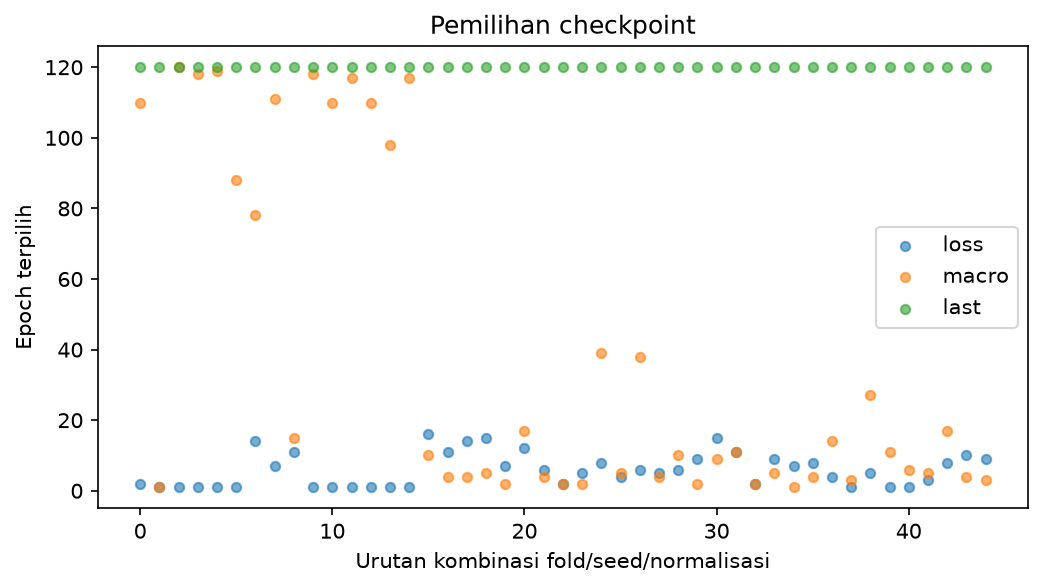

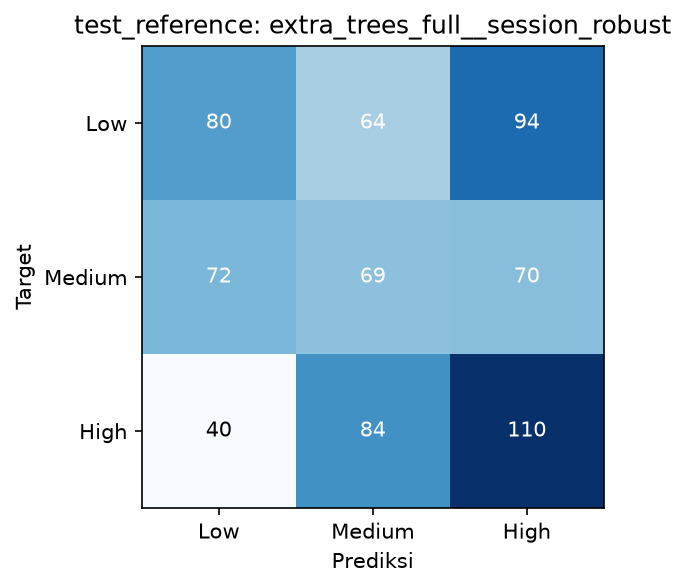

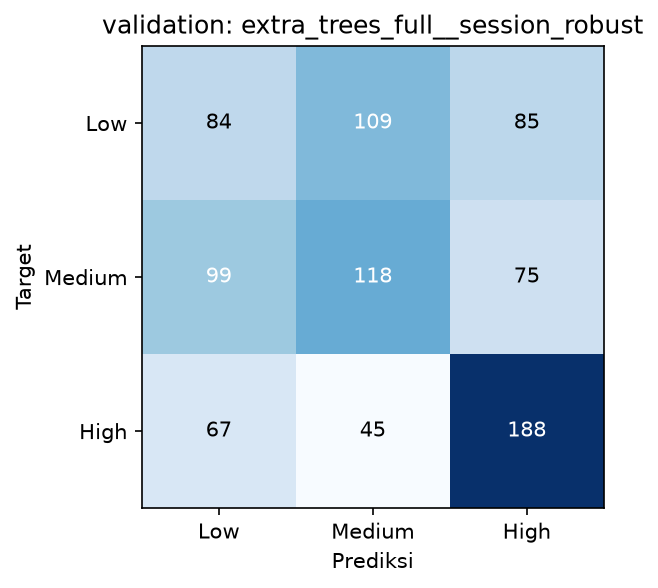

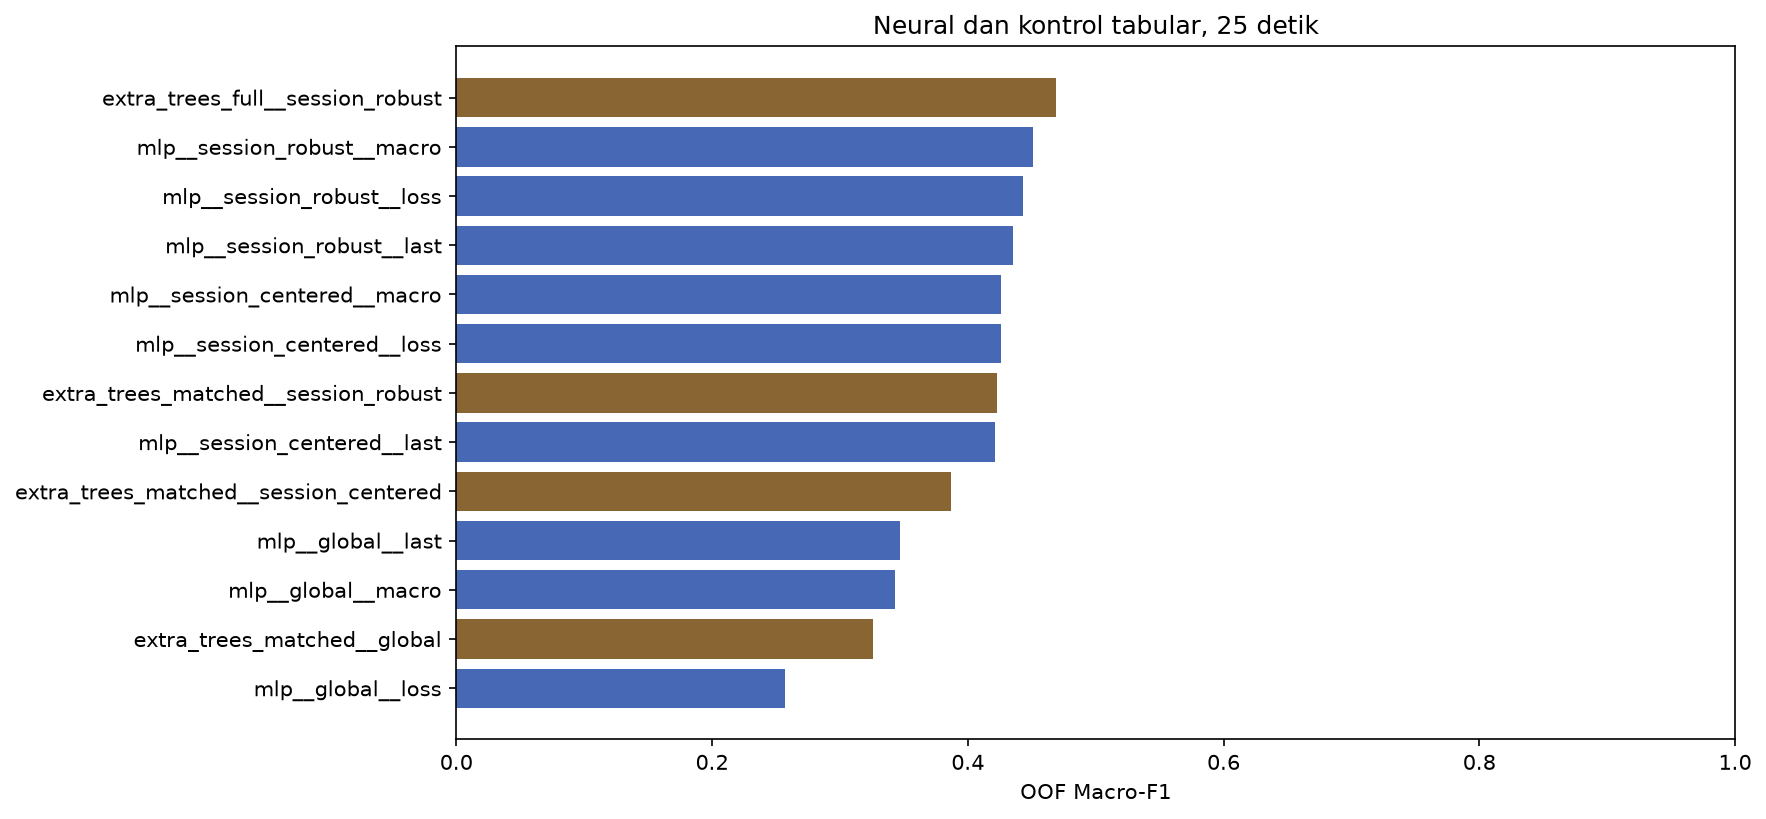

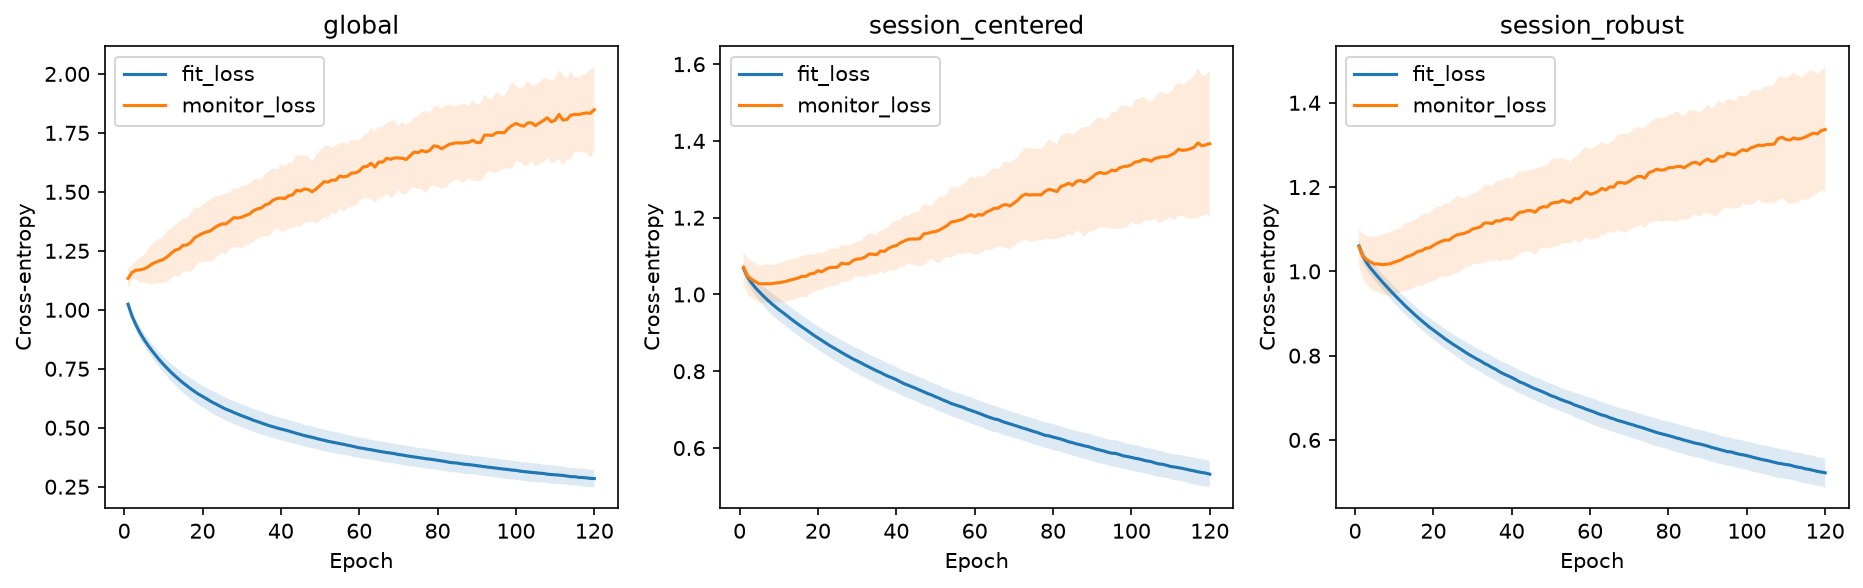

In [31]:
try:
    from IPython.display import Image as NotebookImage
except ImportError:
    NotebookImage = None

for figure_path in sorted((RUN_DIR / 'figures').glob('*.png')):
    if NotebookImage is not None:
        display(NotebookImage(filename=str(figure_path)))
    else:
        print('Grafik:', figure_path)